# Expected Threat: fitting and action valuation

**Analytical question:** Value locations and completed movement.

**Stages in this notebook:** Action counts; reward; transition matrix; iterative solution; endpoint gain.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

**Example controls:** edit the example-selection cell near the top and rerun. Exploration and animation code is inline; no downloaded videos or separate HTML export is required.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## Choose an example with selection variables

First run the notebook top to bottom. For another example, change these variables, run this selection cell, then rerun the final exploration cell. Refit models only when you intend to. Near the end, `available_possessions` and `available_events` list available choices; use their displayed identifiers. You can inspect more rows with `display(available_possessions)` or `display(available_events)`. A frame override takes priority over a possession or event. Method-specific selectors are documented in the comments.

The final explorer computes its overlays directly from real tracking frames and the method functions in this notebook. Animation frames are rendered inline using Matplotlib; no MP4 or other movie is downloaded. Missing coverage stops the clip rather than interpolating motion. The saved notebook contains a playable default animation, but choosing another example requires rerunning Python. All helpers remain inline.

In [2]:
# Example selection: change a selection, then rerun the cells below. None uses the worked default.
PERIOD = 1
FRAME_ID = None         # exact raw tracking frame; overrides event/possession start
POSSESSION_INDEX = None    # possession_index from available_possessions near the end
EVENT_ID = None         # actual supplied event_id from available_events, not row number
PLAYER_ID = None        # player_id (string or integer), from metadata
TEAM_ID = None          # team_id; None uses the initial possession team
DURATION_S = 6.0     # maximum; clips stop at coverage/selection boundaries
FRAME_STRIDE = 3           # use 1 for every 10 Hz frame; 3 gives a faster preview

# Licensed external DataBallPy 0.7.2 fitted grid, embedded for standalone use.
# SHA256: 5579f29389f27af1f22ad2922e1c03a9490b12854ce0e9d363b0dbe71af1cbbc
# https://github.com/Alek050/databallpy (MIT); this is not fitted on the sample.
XT_GRID = np.array([[0.0003175253264460349, 0.0003544796827890639, 0.0003914340391320929, 0.00042838839547512187, 0.0004653427518181508, 0.0005022971081611797, 0.0005392514645042088, 0.0005762058208472378, 0.0006131601771902668, 0.0006177498359746113, 0.0005926718553301618, 0.0005675938746857122, 0.0005425158940412627, 0.0005174379133968131, 0.0004923599327523636, 0.00046728195210791405, 0.00044220397146346453, 0.0004181413728568038, 0.00041641717908149674, 0.0004146929853061897, 0.00041296879153088266, 0.00041124459775557557, 0.00040952040398026853, 0.0004077962102049615, 0.0004060720164296545, 0.00040434782265434747, 0.0004239408937099803, 0.0004599318607894133, 0.0004959228278688462, 0.0005319137949482791, 0.000567904762027712, 0.000603895729107145, 0.0006398866961865779, 0.0006758776632660109, 0.0007062141167054555, 0.0006771781769250216, 0.0006481422371445876, 0.0006191062973641537, 0.0005900703575837196, 0.0005610344178032859, 0.0005319984780228519, 0.000502962538242418, 0.00047392659846198396, 0.0005014392958602857, 0.0005653046885877751, 0.0006291700813152641, 0.0006930354740427535, 0.0007569008667702425, 0.0008207662594977314, 0.0008846316522252209, 0.0009484970449527097, 0.0009999975281360309, 0.000969065281024895, 0.000938133033913759, 0.0009072007868026233, 0.0008762685396914874, 0.0008453362925803517, 0.0008144040454692158, 0.00078347179835808, 0.0007525395512469441, 0.0007548115031017033, 0.0007747923610716067, 0.0007947732190415099, 0.0008147540770114132, 0.0008347349349813165, 0.0008547157929512197, 0.0008746966509211231, 0.0008946775088910263, 0.0009152192694205549, 0.0009384253171083028, 0.000961631364796051, 0.0009848374124837994, 0.0010080434601715477, 0.0010312495078592958, 0.0010544555555470438, 0.0010776616032347924, 0.0011008676509225406, 0.0011080260776376572, 0.0011081636701772476, 0.001108301262716838, 0.0011084388552564284, 0.0011085764477960188, 0.0011087140403356092, 0.0011088516328751996, 0.00110898922541479, 0.001109912285924166, 0.0011136630311247705, 0.001117413776325375, 0.0011211645215259793, 0.0011249152667265837, 0.0011286660119271881, 0.0011324167571277926, 0.001136167502328397, 0.0011399182475290016, 0.0011322145263573322, 0.0011204680523483898, 0.0011087215783394475, 0.0010969751043305052, 0.0010852286303215629, 0.0010734821563126204, 0.0010617356823036782, 0.0010499892082947357, 0.0010373090925313432, 0.001021983658463675, 0.001006658224396007, 0.0009913327903283387, 0.0009760073562606707, 0.0009606819221930027, 0.0009453564881253347, 0.0009300310540576664, 0.0009147056199899983, 0.0009131234154196395, 0.0009153587745985333, 0.000917594133777427, 0.000919829492956321, 0.0009220648521352147, 0.0009243002113141084, 0.0009265355704930023, 0.0009287709296718962, 0.0009303540370160067, 0.0009304462830234698, 0.0009305385290309331, 0.0009306307750383961, 0.0009307230210458593, 0.0009308152670533226, 0.0009309075130607857, 0.0009309997590682489, 0.000931092005075712, 0.0009054151978592231, 0.0008743133268061128, 0.0008432114557530025, 0.0008121095846998917, 0.0007810077136467812, 0.0007499058425936709, 0.0007188039715405605, 0.0006877021004874497, 0.0006671322873331788, 0.0006663100827392322, 0.0006654878781452854, 0.0006646656735513387, 0.0006638434689573919, 0.0006630212643634452, 0.0006621990597694984, 0.0006613768551755517, 0.0006605546505816049, 0.0006613326716415997, 0.0006623507265496857, 0.0006633687814577718, 0.0006643868363658577, 0.0006654048912739438, 0.0006664229461820298, 0.0006674410010901158, 0.0006684590559982018, 0.0006534367944160944, 0.0006134629294047971, 0.0005734890643934999, 0.0005335151993822027, 0.0004935413343709054, 0.00045356746935960705, 0.00041359360434830986, 0.0003736197393370126, 0.0003336458743257154, 0.0003346497591654182, 0.00033955628684807337, 0.0003444628145307285, 0.0003493693422133837, 0.0003542758698960388, 0.0003591823975786942, 0.00036408892526134935, 0.0003689954529440045, 0.00037104685757512434, 0.00036938660223924836, 0.0003677263469033724, 0.0003660660915674964, 0.0003644058362316204, 0.0003627455808957444, 0.0003610853255598684, 0.00035942507022399244, 0.00035776481488811646, 0.0003634639036854265, 0.00036949750812515414, 0.0003755311125648818, 0.0003815647170046094, 0.00038759832144433703, 0.0003936319258840649, 0.00039966553032379253, 0.0004056991347635202, 0.0004103192322707099, 0.00041339732221513096, 0.00041647541215955196, 0.00041955350210397306, 0.00042263159204839406, 0.0004257096819928151, 0.00042878777193723627, 0.0004318658618816573, 0.0004349439518260784], [0.00033313902161183513, 0.00036588458840418033, 0.0003986301551965255, 0.0004313757219888707, 0.0004641212887812159, 0.0004968668555735611, 0.0005296124223659063, 0.0005623579891582515, 0.0005951035559505967, 0.0005998495960777227, 0.0005789294034283977, 0.000558009210779073, 0.0005370890181297482, 0.0005161688254804233, 0.0004952486328310984, 0.00047432844018177345, 0.00045340824753244857, 0.00043334518902331216, 0.00043213908159832137, 0.0004309329741733306, 0.0004297268667483399, 0.0004285207593233492, 0.0004273146518983584, 0.0004261085444733676, 0.00042490243704837693, 0.00042369632962338614, 0.000442475652586496, 0.00047662838354045264, 0.0005107811144944094, 0.000544933845448366, 0.0005790865764023227, 0.0006132393073562793, 0.0006473920383102361, 0.0006815447692641926, 0.0007107871589043007, 0.0006884709647489983, 0.0006661547705936957, 0.0006438385764383933, 0.0006215223822830908, 0.0005992061881277885, 0.0005768899939724858, 0.0005545737998171836, 0.0005322576056618811, 0.0005553762273243038, 0.0006077029448695502, 0.0006600296624147964, 0.0007123563799600428, 0.000764683097505289, 0.0008170098150505353, 0.0008693365325957817, 0.0009216632501410278, 0.0009640761631770099, 0.000940397046151229, 0.000916717929125448, 0.0008930388120996671, 0.0008693596950738861, 0.0008456805780481051, 0.0008220014610223242, 0.0007983223439965432, 0.0007746432269707622, 0.0007799089043630443, 0.0008006118054449598, 0.0008213147065268753, 0.000842017607608791, 0.0008627205086907065, 0.000883423409772622, 0.0009041263108545376, 0.0009248292119364531, 0.0009455511891091896, 0.0009663637777133248, 0.0009871763663174599, 0.0010079889549215954, 0.0010288015435257303, 0.0010496141321298656, 0.0010704267207340004, 0.001091239309338136, 0.001112051897942271, 0.001117862995269266, 0.001117110940162512, 0.0011163588850557579, 0.0011156068299490037, 0.00111485477484225, 0.0011141027197354957, 0.0011133506646287417, 0.0011125986095219876, 0.0011129895883402994, 0.0011174954892888478, 0.0011220013902373959, 0.0011265072911859442, 0.0011310131921344925, 0.0011355190930830408, 0.001140024994031589, 0.0011445308949801372, 0.0011490367959286854, 0.0011429925266324124, 0.0011332246678379665, 0.001123456809043521, 0.0011136889502490752, 0.0011039210914546296, 0.0010941532326601841, 0.0010843853738657383, 0.0010746175150712926, 0.0010636185501730754, 0.0010491314513141727, 0.0010346443524552698, 0.0010201572535963666, 0.001005670154737464, 0.000991183055878561, 0.000976695957019658, 0.000962208858160755, 0.0009477217593018522, 0.0009459338457214971, 0.0009476734836074053, 0.0009494131214933135, 0.0009511527593792218, 0.0009528923972651299, 0.0009546320351510381, 0.0009563716730369464, 0.0009581113109228545, 0.0009585025101740265, 0.0009558115639743728, 0.0009531206177747193, 0.0009504296715750656, 0.000947738725375412, 0.0009450477791757583, 0.0009423568329761049, 0.000939665886776451, 0.0009369749405767973, 0.0009130085106983256, 0.0008845630316243131, 0.0008561175525503005, 0.0008276720734762876, 0.000799226594402275, 0.0007707811153282625, 0.0007423356362542499, 0.0007138901571802372, 0.000694282510010708, 0.0006912457976620856, 0.0006882090853134632, 0.0006851723729648408, 0.0006821356606162184, 0.0006790989482675959, 0.0006760622359189735, 0.0006730255235703512, 0.0006699888112217287, 0.0006717930189970513, 0.0006743233647909657, 0.00067685371058488, 0.0006793840563787942, 0.0006819144021727086, 0.000684444747966623, 0.0006869750937605372, 0.0006895054395544515, 0.0006765100522097268, 0.000639363524427119, 0.0006022169966445114, 0.0005650704688619037, 0.000527923941079296, 0.0004907774132966872, 0.00045363088551407944, 0.0004164843577314718, 0.000379337829948864, 0.0003792784656113526, 0.00038275121207813605, 0.0003862239585449194, 0.0003896967050117028, 0.0003931694514784862, 0.0003966421979452698, 0.0004001149444120532, 0.0004035876908788366, 0.0004037152089809081, 0.0003994939302088541, 0.0003952726514368001, 0.0003910513726647462, 0.00038683009389269224, 0.00038260881512063814, 0.0003783875363485842, 0.0003741662575765302, 0.0003699449788044762, 0.000374803172902607, 0.00038007407031301886, 0.0003853449677234307, 0.0003906158651338427, 0.00039588676254425454, 0.0004011576599546666, 0.00040642855736507853, 0.00041169945477549045, 0.000413639105252756, 0.00041194466816658914, 0.00041025023108042235, 0.0004085557939942555, 0.00040686135690808865, 0.0004051669198219219, 0.00040347248273575495, 0.0004017780456495881, 0.00040008360856342125], [0.0003487527167776353, 0.00037728949401929677, 0.0004058262712609581, 0.00043436304850261957, 0.0004628998257442809, 0.0004914366029859424, 0.0005199733802276037, 0.0005485101574692652, 0.0005770469347109266, 0.0005819493561808342, 0.0005651869515266339, 0.0005484245468724338, 0.0005316621422182335, 0.0005148997375640333, 0.0004981373329098331, 0.00048137492825563297, 0.0004646125236014327, 0.00044854900518982065, 0.00044786098411514616, 0.0004471729630404716, 0.00044648494196579717, 0.00044579692089112273, 0.0004451088998164483, 0.00044442087874177374, 0.0004437328576670993, 0.00044304483659242475, 0.00046101041146301175, 0.0004933249062914921, 0.0005256394011199725, 0.0005579538959484528, 0.0005902683907769331, 0.0006225828856054134, 0.0006548973804338939, 0.0006872118752623743, 0.0007153602011031458, 0.0006997637525729749, 0.0006841673040428038, 0.000668570855512633, 0.000652974406982462, 0.0006373779584522911, 0.0006217815099221201, 0.0006061850613919492, 0.0005905886128617782, 0.000609313158788322, 0.0006501012011513256, 0.0006908892435143289, 0.0007316772858773325, 0.0007724653282403357, 0.0008132533706033391, 0.0008540414129663426, 0.000894829455329346, 0.0009281547982179891, 0.0009117288112775631, 0.000895302824337137, 0.0008788768373967109, 0.0008624508504562848, 0.0008460248635158588, 0.0008295988765754325, 0.0008131728896350064, 0.0007967469026945803, 0.000805006305624385, 0.000826431249818313, 0.0008478561940122409, 0.0008692811382061687, 0.0008907060824000965, 0.0009121310265940243, 0.0009335559707879524, 0.0009549809149818802, 0.0009758831087978246, 0.0009943022383183467, 0.0010127213678388686, 0.0010311404973593911, 0.001049559626879913, 0.0010679787564004352, 0.0010863978859209573, 0.0011048170154414796, 0.0011232361449620017, 0.0011276999129008747, 0.0011260582101477762, 0.0011244165073946777, 0.0011227748046415795, 0.001121133101888481, 0.0011194913991353825, 0.0011178496963822838, 0.0011162079936291854, 0.0011160668907564328, 0.001121327947452925, 0.0011265890041494168, 0.0011318500608459093, 0.0011371111175424013, 0.0011423721742388933, 0.0011476332309353855, 0.0011528942876318777, 0.0011581553443283698, 0.0011537705269074924, 0.0011459812833275434, 0.0011381920397475946, 0.0011304027961676455, 0.0011226135525876965, 0.0011148243090077475, 0.0011070350654277985, 0.0010992458218478495, 0.0010899280078148078, 0.0010762792441646701, 0.0010626304805145324, 0.0010489817168643945, 0.001035332953214257, 0.0010216841895641193, 0.0010080354259139816, 0.0009943866622638437, 0.0009807378986137062, 0.0009787442760233547, 0.0009799881926162773, 0.0009812321092092, 0.0009824760258021225, 0.0009837199423950451, 0.0009849638589879677, 0.0009862077755808903, 0.000987451692173813, 0.0009866509833320464, 0.0009811768449252758, 0.0009757027065185053, 0.0009702285681117349, 0.0009647544297049644, 0.0009592802912981941, 0.0009538061528914237, 0.0009483320144846532, 0.0009428578760778828, 0.000920601823537428, 0.0008948127364425133, 0.0008690236493475986, 0.0008432345622526836, 0.000817445475157769, 0.0007916563880628542, 0.0007658673009679395, 0.0007400782138730245, 0.0007214327326882372, 0.0007161815125849392, 0.0007109302924816411, 0.0007056790723783431, 0.0007004278522750449, 0.0006951766321717467, 0.0006899254120684488, 0.0006846741919651507, 0.0006794229718618527, 0.000682253366352503, 0.0006862960030322455, 0.0006903386397119881, 0.0006943812763917308, 0.0006984239130714733, 0.0007024665497512161, 0.0007065091864309587, 0.0007105518231107014, 0.0006995833100033593, 0.0006652641194494412, 0.000630944928895523, 0.0005966257383416047, 0.0005623065477876866, 0.0005279873572337674, 0.0004936681666798492, 0.00045934897612593095, 0.00042502978557201277, 0.0004239071720572871, 0.00042594613730819874, 0.0004279851025591104, 0.00043002406781002207, 0.0004320630330609337, 0.0004341019983118454, 0.00043614096356275704, 0.0004381799288136688, 0.0004363835603866919, 0.00042960125817845994, 0.000422818955970228, 0.000416036653761996, 0.000409254351553764, 0.00040247204934553186, 0.0003956897471372999, 0.00038890744492906795, 0.00038212514272083594, 0.0003861424421197874, 0.0003906506325008836, 0.0003951588228819798, 0.00039966701326307595, 0.0004041752036441721, 0.0004086833940252684, 0.0004131915844063646, 0.00041769977478746075, 0.0004169589782348021, 0.0004104920141180474, 0.0004040250500012927, 0.000397558085884538, 0.00039109112176778323, 0.0003846241576510285, 0.0003781571935342735, 0.0003716902294175189, 0.00036522326530076413], [0.0003643664119434355, 0.00038869439963441316, 0.00041302238732539087, 0.0004373503750163684, 0.000461678362707346, 0.0004860063503983237, 0.0005103343380893013, 0.0005346623257802789, 0.0005589903134712565, 0.0005640491162839455, 0.00055144449962487, 0.0005388398829657945, 0.000526235266306719, 0.0005136306496476435, 0.0005010260329885679, 0.0004884214163294923, 0.0004758167996704168, 0.00046375282135632903, 0.00046358288663197084, 0.0004634129519076127, 0.0004632430171832544, 0.0004630730824588962, 0.0004629031477345381, 0.0004627332130101798, 0.0004625632782858216, 0.0004623933435614634, 0.00047954517033952737, 0.0005100214290425314, 0.0005404976877455356, 0.0005709739464485396, 0.0006014502051515437, 0.0006319264638545478, 0.0006624027225575519, 0.000692878981260556, 0.000719933243301991, 0.0007110565403969515, 0.0007021798374919121, 0.0006933031345868726, 0.0006844264316818332, 0.0006755497287767937, 0.0006666730258717542, 0.0006577963229667148, 0.0006489196200616752, 0.0006632500902523401, 0.0006924994574331008, 0.0007217488246138613, 0.000750998191794622, 0.0007802475589753824, 0.0008094969261561429, 0.0008387462933369035, 0.000867995660517664, 0.0008922334332589684, 0.0008830605764038972, 0.000873887719548826, 0.0008647148626937547, 0.0008555420058386834, 0.0008463691489836123, 0.0008371962921285409, 0.0008280234352734698, 0.0008188505784183984, 0.000830103706885726, 0.0008522506941916661, 0.0008743976814976062, 0.0008965446688035465, 0.0009186916561094865, 0.0009408386434154267, 0.000962985630721367, 0.000985132618027307, 0.0010062150284864595, 0.0010222406989233684, 0.0010382663693602775, 0.0010542920397971869, 0.0010703177102340958, 0.001086343380671005, 0.001102369051107914, 0.0011183947215448234, 0.0011344203919817324, 0.0011375368305324835, 0.0011350054801330407, 0.0011324741297335976, 0.0011299427793341548, 0.0011274114289347118, 0.001124880078535269, 0.0011223487281358262, 0.0011198173777363831, 0.0011191441931725661, 0.001125160405617002, 0.001131176618061438, 0.0011371928305058741, 0.00114320904295031, 0.001149225255394746, 0.0011552414678391819, 0.001161257680283618, 0.001167273892728054, 0.0011645485271825724, 0.00115873789881712, 0.001152927270451668, 0.0011471166420862157, 0.0011413060137207634, 0.001135495385355311, 0.0011296847569898588, 0.0011238741286244064, 0.0011162374654565402, 0.0011034270370151678, 0.001090616608573795, 0.0010778061801324226, 0.0010649957516910501, 0.0010521853232496776, 0.0010393748948083052, 0.0010265644663669325, 0.0010137540379255602, 0.0010115547063252125, 0.0010123029016251494, 0.0010130510969250863, 0.0010137992922250234, 0.0010145474875249603, 0.0010152956828248971, 0.0010160438781248345, 0.0010167920734247713, 0.0010147994564900663, 0.001006542125876179, 0.0009982847952622917, 0.0009900274646484043, 0.000981770134034517, 0.00097351280342063, 0.0009652554728067427, 0.0009569981421928553, 0.0009487408115789681, 0.0009281951363765302, 0.0009050624412607135, 0.0008819297461448966, 0.0008587970510290793, 0.0008356643559132626, 0.0008125316607974458, 0.0007893989656816288, 0.0007662662705658117, 0.0007485829553657663, 0.0007411172275077926, 0.000733651499649819, 0.0007261857717918453, 0.0007187200439338715, 0.0007112543160758976, 0.0007037885882179238, 0.0006963228603599501, 0.0006888571325019764, 0.0006927137137079545, 0.0006982686412735254, 0.0007038235688390964, 0.0007093784964046672, 0.0007149334239702382, 0.0007204883515358094, 0.0007260432791013802, 0.0007315982066669513, 0.000722656567796992, 0.0006911647144717632, 0.0006596728611465345, 0.0006281810078213059, 0.0005966891544960771, 0.0005651973011708475, 0.0005337054478456189, 0.0005022135945203902, 0.00047072174119516146, 0.00046853587850322146, 0.0004691410625382614, 0.0004697462465733013, 0.00047035143060834123, 0.00047095661464338114, 0.00047156179867842104, 0.000472166982713461, 0.00047277216674850085, 0.0004690519117924757, 0.0004597085861480657, 0.0004503652605036557, 0.00044102193485924583, 0.00043167860921483587, 0.00042233528357042563, 0.00041299195792601567, 0.0004036486322816057, 0.00039430530663719574, 0.00039748171133696794, 0.00040122719468874834, 0.00040497267804052875, 0.0004087181613923092, 0.00041246364474408967, 0.00041620912809587013, 0.0004199546114476506, 0.00042370009479943095, 0.00042027885121684826, 0.0004090393600695056, 0.000397799868922163, 0.0003865603777748204, 0.00037532088662747777, 0.00036408139548013517, 0.0003528419043327922, 0.0003416024131854496, 0.00033036292203810695], [0.00037998010710923574, 0.0004000993052495296, 0.0004202185033898234, 0.0004403377015301173, 0.0004604568996704112, 0.000480576097810705, 0.0005006952959509987, 0.0005208144940912926, 0.0005409336922315865, 0.000546148876387057, 0.0005377020477231062, 0.0005292552190591553, 0.0005208083903952044, 0.0005123615617312535, 0.0005039147330673027, 0.0004954679044033519, 0.00048702107573940094, 0.00047895663752283747, 0.0004793047891487955, 0.0004796529407747536, 0.00048000109240071173, 0.00048034924402666983, 0.0004806973956526279, 0.00048104554727858604, 0.00048139369890454404, 0.0004817418505305022, 0.0004980799292160431, 0.0005267179517935708, 0.0005553559743710987, 0.0005839939969486264, 0.0006126320195261542, 0.0006412700421036821, 0.0006699080646812099, 0.0006985460872587378, 0.0007245062855008364, 0.0007223493282209283, 0.0007201923709410203, 0.0007180354136611123, 0.0007158784563812043, 0.0007137214991012964, 0.0007115645418213884, 0.0007094075845414803, 0.0007072506272615723, 0.0007171870217163583, 0.000734897713714876, 0.0007526084057133937, 0.0007703190977119115, 0.0007880297897104291, 0.0008057404817089467, 0.0008234511737074645, 0.0008411618657059822, 0.0008563120682999478, 0.0008543923415302312, 0.0008524726147605149, 0.0008505528879907985, 0.0008486331612210822, 0.0008467134344513657, 0.0008447937076816493, 0.000842873980911933, 0.0008409542541422167, 0.0008552011081470668, 0.0008780701385650193, 0.0009009391689829717, 0.0009238081994009243, 0.0009466772298188765, 0.000969546260236829, 0.0009924152906547817, 0.001015284321072734, 0.0010365469481750944, 0.00105017915952839, 0.0010638113708816863, 0.0010774435822349824, 0.0010910757935882786, 0.0011047080049415745, 0.0011183402162948707, 0.0011319724276481668, 0.001145604639001463, 0.0011473737481640922, 0.0011439527501183049, 0.0011405317520725175, 0.0011371107540267304, 0.001133689755980943, 0.0011302687579351556, 0.0011268477598893683, 0.001123426761843581, 0.0011222214955886995, 0.0011289928637810793, 0.0011357642319734591, 0.001142535600165839, 0.0011493069683582188, 0.0011560783365505986, 0.0011628497047429785, 0.0011696210729353583, 0.0011763924411277381, 0.0011753265274576526, 0.0011714945143066972, 0.0011676625011557416, 0.0011638304880047857, 0.00115999847485383, 0.0011561664617028746, 0.001152334448551919, 0.0011485024354009634, 0.0011425469230982727, 0.001130574829865665, 0.001118602736633058, 0.0011066306434004505, 0.0010946585501678432, 0.001082686456935236, 0.0010707143637026287, 0.0010587422704700213, 0.001046770177237414, 0.00104436513662707, 0.0010446176106340215, 0.0010448700846409729, 0.0010451225586479243, 0.0010453750326548756, 0.001045627506661827, 0.0010458799806687782, 0.0010461324546757298, 0.0010429479296480857, 0.0010319074068270819, 0.0010208668840060778, 0.0010098263611850737, 0.0009987858383640697, 0.0009877453155430658, 0.0009767047927220617, 0.0009656642699010575, 0.0009546237470800533, 0.0009357884492156327, 0.0009153121460789138, 0.0008948358429421947, 0.0008743595398054754, 0.0008538832366687564, 0.0008334069335320373, 0.0008129306303953183, 0.0007924543272585991, 0.0007757331780432956, 0.0007660529424306462, 0.0007563727068179969, 0.0007466924712053474, 0.000737012235592698, 0.0007273319999800483, 0.0007176517643673989, 0.0007079715287547496, 0.0006982912931421002, 0.0007031740610634062, 0.0007102412795148053, 0.0007173084979662046, 0.0007243757164176039, 0.0007314429348690031, 0.0007385101533204025, 0.0007455773717718018, 0.0007526445902232011, 0.0007457298255906244, 0.0007170653094940852, 0.000688400793397546, 0.0006597362773010069, 0.0006310717612044677, 0.0006024072451079277, 0.0005737427290113885, 0.0005450782129148493, 0.0005164136968183102, 0.0005131645849491559, 0.000512335987768324, 0.0005115073905874922, 0.0005106787934066603, 0.0005098501962258285, 0.0005090215990449967, 0.0005081930018641648, 0.000507364404683333, 0.0005017202631982594, 0.0004898159141176714, 0.00047791156503708355, 0.0004660072159564956, 0.0004541028668759076, 0.0004421985177953193, 0.0004302941687147313, 0.00041838981963414346, 0.0004064854705535555, 0.0004088209805541484, 0.00041180375687661306, 0.00041478653319907777, 0.0004177693095215424, 0.0004207520858440072, 0.00042373486216647194, 0.00042671763848893665, 0.0004297004148114013, 0.0004235987241988944, 0.0004075867060209639, 0.0003915746878430334, 0.00037556266966510285, 0.00035955065148717235, 0.00034353863330924186, 0.00032752661513131087, 0.0003115145969533804, 0.0002955025787754499], [0.000395593802275036, 0.000411504210864646, 0.0004274146194542561, 0.0004433250280438661, 0.00045923543663347623, 0.00047514584522308624, 0.0004910562538126963, 0.0005069666624023064, 0.0005228770709919165, 0.0005282486364901686, 0.0005239595958213423, 0.000519670555152516, 0.0005153815144836899, 0.0005110924738148636, 0.0005068034331460375, 0.0005025143924772112, 0.0004982253518083851, 0.0004941604536893459, 0.0004950266916656203, 0.0004958929296418946, 0.000496759167618169, 0.0004976254055944433, 0.0004984916435707178, 0.0004993578815469921, 0.0005002241195232665, 0.0005010903574995408, 0.0005166146880925587, 0.0005434144745446102, 0.0005702142609966618, 0.0005970140474487132, 0.0006238138339007648, 0.0006506136203528163, 0.0006774134068048679, 0.0007042131932569193, 0.0007290793276996815, 0.000733642116044905, 0.0007382049043901286, 0.0007427676927353519, 0.0007473304810805754, 0.000751893269425799, 0.0007564560577710225, 0.0007610188461162459, 0.0007655816344614695, 0.0007711239531803764, 0.0007772959699966513, 0.000783467986812926, 0.0007896400036292009, 0.0007958120204454757, 0.0008019840372617506, 0.0008081560540780255, 0.0008143280708943003, 0.0008203907033409269, 0.0008257241066565654, 0.000831057509972204, 0.0008363909132878423, 0.0008417243166034809, 0.0008470577199191192, 0.0008523911232347578, 0.0008577245265503963, 0.0008630579298660347, 0.0008802985094084077, 0.0009038895829383725, 0.0009274806564683371, 0.000951071729998302, 0.0009746628035282668, 0.0009982538770582313, 0.0010218449505881963, 0.0010454360241181609, 0.001066878867863729, 0.001078117620133412, 0.001089356372403095, 0.0011005951246727782, 0.0011118338769424611, 0.0011230726292121443, 0.0011343113814818273, 0.0011455501337515105, 0.0011567888860211937, 0.001157210665795701, 0.0011529000201035693, 0.0011485893744114376, 0.0011442787287193057, 0.001139968083027174, 0.0011356574373350423, 0.0011313467916429104, 0.0011270361459507785, 0.0011252987980048328, 0.0011328253219451564, 0.00114035184588548, 0.0011478783698258038, 0.0011554048937661276, 0.0011629314177064513, 0.0011704579416467748, 0.0011779844655870986, 0.0011855109895274223, 0.0011861045277327328, 0.0011842511297962737, 0.001182397731859815, 0.001180544333923356, 0.001178690935986897, 0.0011768375380504382, 0.0011749841401139792, 0.0011731307421775203, 0.0011688563807400049, 0.0011577226227161628, 0.0011465888646923208, 0.0011354551066684786, 0.0011243213486446363, 0.0011131875906207943, 0.0011020538325969523, 0.00109092007457311, 0.0010797863165492678, 0.0010771755669289277, 0.0010769323196428934, 0.0010766890723568593, 0.001076445825070825, 0.0010762025777847908, 0.0010759593304987564, 0.001075716083212722, 0.0010754728359266882, 0.0010710964028061056, 0.001057272687777985, 0.0010434489727498642, 0.001029625257721743, 0.0010158015426936222, 0.0010019778276655015, 0.0009881541126373805, 0.0009743303976092597, 0.0009605066825811388, 0.0009433817620547352, 0.0009255618508971139, 0.0009077419397394928, 0.0008899220285818714, 0.0008721021174242502, 0.000854282206266629, 0.0008364622951090078, 0.0008186423839513865, 0.0008028834007208248, 0.0007909886573534997, 0.0007790939139861746, 0.0007671991706188497, 0.0007553044272515247, 0.0007434096838841992, 0.0007315149405168741, 0.0007196201971495491, 0.000707725453782224, 0.0007136344084188578, 0.0007222139177560853, 0.0007307934270933128, 0.0007393729364305404, 0.0007479524457677678, 0.0007565319551049957, 0.0007651114644422232, 0.0007736909737794508, 0.0007688030833842568, 0.0007429659045164072, 0.0007171287256485576, 0.0006912915467807079, 0.0006654543679128583, 0.0006396171890450078, 0.0006137800101771581, 0.0005879428313093084, 0.0005621056524414589, 0.0005577932913950904, 0.0005555309129983867, 0.0005532685346016831, 0.0005510061562049794, 0.0005487437778082759, 0.0005464813994115723, 0.0005442190210148687, 0.0005419566426181651, 0.000534388614604043, 0.0005199232420872771, 0.0005054578695705113, 0.0004909924970537454, 0.0004765271245369794, 0.0004620617520202131, 0.0004475963795034472, 0.0004331310069866812, 0.00041866563446991533, 0.0004201602497713288, 0.0004223803190644778, 0.0004246003883576268, 0.0004268204576507757, 0.00042904052694392464, 0.00043126059623707364, 0.0004334806655302226, 0.00043570073482337155, 0.00042691859718094053, 0.0004061340519724221, 0.00038534950676390374, 0.00036456496155538534, 0.00034378041634686694, 0.0003229958711383485, 0.00030221132592982955, 0.00028142678072131115, 0.00026064223551279276], [0.00041120749744083616, 0.0004229091164797624, 0.00043461073551868875, 0.000446312354557615, 0.00045801397359654134, 0.0004697155926354676, 0.0004814172116743939, 0.00049311883071332, 0.0005048204497522464, 0.0005103483965932799, 0.0005102171439195784, 0.0005100858912458768, 0.0005099546385721754, 0.0005098233858984737, 0.0005096921332247722, 0.0005095608805510707, 0.0005094296278773692, 0.0005093642698558542, 0.0005107485941824449, 0.0005121329185090355, 0.0005135172428356262, 0.0005149015671622168, 0.0005162858914888075, 0.0005176702158153981, 0.0005190545401419888, 0.0005204388644685794, 0.0005351494469690743, 0.0005601109972956497, 0.0005850725476222249, 0.0006100340979488001, 0.0006349956482753754, 0.0006599571986019505, 0.0006849187489285258, 0.0007098802992551009, 0.0007336523698985266, 0.0007449349038688816, 0.0007562174378392365, 0.0007674999718095916, 0.0007787825057799466, 0.0007900650397503015, 0.0008013475737206566, 0.0008126301076910114, 0.0008239126416613665, 0.0008250608846443944, 0.0008196942262784264, 0.0008143275679124584, 0.0008089609095464903, 0.0008035942511805225, 0.0007982275928145545, 0.0007928609344485864, 0.0007874942760826184, 0.0007844693383819062, 0.0007970558717828994, 0.0008096424051838928, 0.0008222289385848862, 0.0008348154719858796, 0.0008474020053868728, 0.0008599885387878662, 0.0008725750721888594, 0.0008851616055898528, 0.0009053959106697485, 0.0009297090273117256, 0.0009540221439537026, 0.00097833526059568, 0.0010026483772376566, 0.0010269614938796337, 0.001051274610521611, 0.0010755877271635878, 0.0010972107875523638, 0.0011060560807384337, 0.001114901373924504, 0.001123746667110574, 0.001132591960296644, 0.001141437253482714, 0.001150282546668784, 0.0011591278398548543, 0.001167973133040924, 0.00116704758342731, 0.0011618472900888335, 0.0011566469967503573, 0.0011514467034118812, 0.0011462464100734048, 0.0011410461167349287, 0.0011358458233964525, 0.0011306455300579762, 0.0011283761004209662, 0.0011366577801092334, 0.001144939459797501, 0.0011532211394857687, 0.0011615028191740364, 0.001169784498862304, 0.0011780661785505714, 0.0011863478582388389, 0.0011946295379271065, 0.0011968825280078128, 0.0011970077452858508, 0.0011971329625638885, 0.0011972581798419262, 0.0011973833971199639, 0.0011975086143980016, 0.0011976338316760395, 0.0011977590489540772, 0.0011951658383817373, 0.0011848704155666603, 0.0011745749927515835, 0.0011642795699365065, 0.0011539841471214294, 0.0011436887243063527, 0.0011333933014912759, 0.0011230978786761986, 0.0011128024558611218, 0.0011099859972307853, 0.0011092470286517655, 0.0011085080600727456, 0.0011077690914937258, 0.001107030122914706, 0.0011062911543356859, 0.0011055521857566662, 0.0011048132171776462, 0.0010992448759641253, 0.001082637968728888, 0.0010660310614936503, 0.0010494241542584124, 0.0010328172470231748, 0.0010162103397879374, 0.0009996034325526998, 0.0009829965253174617, 0.0009663896180822243, 0.0009509750748938375, 0.0009358115557153142, 0.0009206480365367909, 0.0009054845173582671, 0.0008903209981797439, 0.0008751574790012205, 0.0008599939598226973, 0.0008448304406441737, 0.0008300336233983539, 0.0008159243722763532, 0.0008018151211543525, 0.0007877058700323518, 0.000773596618910351, 0.00075948736778835, 0.0007453781166663492, 0.0007312688655443486, 0.0007171596144223478, 0.0007240947557743095, 0.0007341865559973652, 0.000744278356220421, 0.000754370156443477, 0.0007644619566665328, 0.0007745537568895889, 0.0007846455571126447, 0.0007947373573357006, 0.0007918763411778893, 0.0007688664995387293, 0.0007458566578995691, 0.0007228468162604088, 0.0006998369746212487, 0.0006768271329820879, 0.0006538172913429278, 0.0006308074497037677, 0.0006077976080646074, 0.0006024219978410248, 0.0005987258382284495, 0.0005950296786158741, 0.0005913335190032988, 0.0005876373593907234, 0.000583941199778148, 0.0005802450401655725, 0.0005765488805529972, 0.0005670569660098268, 0.000550030570056883, 0.000533004174103939, 0.0005159777781509952, 0.0004989513821980513, 0.00048192498624510685, 0.0004648985902921629, 0.00044787219433921896, 0.0004308457983862751, 0.0004314995189885093, 0.00043295688125234255, 0.0004344142435161757, 0.00043587160578000895, 0.0004373289680438421, 0.0004387863303076754, 0.0004402436925715086, 0.00044170105483534185, 0.0004302384701629866, 0.0004046813979238803, 0.00037912432568477407, 0.00035356725344566777, 0.00032801018120656153, 0.00030245310896745523, 0.0002768960367283482, 0.0002513389644892419, 0.00022578189225013563], [0.00042682119260663634, 0.00043431402209487887, 0.00044180685158312134, 0.0004492996810713638, 0.0004567925105596064, 0.00046428534004784886, 0.00047177816953609134, 0.0004792709990243338, 0.00048676382851257634, 0.0004924481566963914, 0.0004964746920178145, 0.0005005012273392376, 0.0005045277626606607, 0.0005085542979820838, 0.000512580833303507, 0.0005166073686249302, 0.0005206339039463533, 0.0005245680860223625, 0.0005264704966992696, 0.0005283729073761765, 0.0005302753180530834, 0.0005321777287299904, 0.0005340801394068973, 0.0005359825500838042, 0.0005378849607607112, 0.0005397873714376182, 0.0005536842058455901, 0.000576807520046689, 0.000599930834247788, 0.0006230541484488869, 0.0006461774626499859, 0.0006693007768510848, 0.0006924240910521838, 0.0007155474052532827, 0.0007382254120973718, 0.0007562276916928582, 0.0007742299712883449, 0.0007922322508838312, 0.0008102345304793178, 0.0008282368100748041, 0.0008462390896702907, 0.0008642413692657771, 0.0008822436488612636, 0.0008789978161084127, 0.0008620924825602017, 0.000845187149011991, 0.0008282818154637799, 0.0008113764819155691, 0.0007944711483673583, 0.0007775658148191473, 0.0007606604812709365, 0.0007485479734228854, 0.0007683876369092335, 0.0007882273003955817, 0.0008080669638819299, 0.0008279066273682782, 0.0008477462908546263, 0.0008675859543409746, 0.0008874256178273227, 0.0009072652813136709, 0.0009304933119310894, 0.0009555284716850788, 0.0009805636314390682, 0.0010055987911930576, 0.0010306339509470468, 0.001055669110701036, 0.0010807042704550256, 0.0011057394302090148, 0.0011275427072409984, 0.0011339945413434555, 0.0011404463754459125, 0.0011468982095483697, 0.0011533500436508265, 0.0011598018777532835, 0.0011662537118557405, 0.0011727055459581977, 0.0011791573800606547, 0.0011768845010589185, 0.001170794560074098, 0.0011647046190892774, 0.0011586146781044566, 0.001152524737119636, 0.0011464347961348152, 0.0011403448551499946, 0.001134254914165174, 0.0011314534028370995, 0.0011404902382733109, 0.001149527073709522, 0.0011585639091457338, 0.0011676007445819451, 0.0011766375800181565, 0.0011856744154543678, 0.0011947112508905794, 0.0012037480863267907, 0.001207660528282893, 0.0012097643607754274, 0.001211868193267962, 0.0012139720257604964, 0.0012160758582530308, 0.0012181796907455651, 0.0012202835232380995, 0.001222387355730634, 0.0012214752960234697, 0.001212018208417158, 0.0012025611208108461, 0.0011931040332045343, 0.0011836469455982226, 0.001174189857991911, 0.0011647327703855992, 0.0011552756827792874, 0.0011458185951729758, 0.0011427964275326427, 0.0011415617376606374, 0.001140327047788632, 0.0011390923579166264, 0.0011378576680446209, 0.0011366229781726155, 0.0011353882883006101, 0.0011341535984286048, 0.0011273933491221452, 0.001108003249679791, 0.0010886131502374364, 0.001069223050795082, 0.0010498329513527274, 0.0010304428519103729, 0.0010110527524680186, 0.0009916626530256639, 0.0009722725535833096, 0.00095856838773294, 0.0009460612605335144, 0.0009335541333340888, 0.0009210470061346632, 0.0009085398789352377, 0.0008960327517358123, 0.0008835256245363868, 0.0008710184973369611, 0.000857183846075883, 0.0008408600871992066, 0.0008245363283225304, 0.0008082125694458541, 0.0007918888105691777, 0.0007755650516925007, 0.0007592412928158243, 0.0007429175339391479, 0.0007265937750624717, 0.0007345551031297609, 0.0007461591942386451, 0.0007577632853475293, 0.0007693673764564134, 0.0007809714675652976, 0.0007925755586741821, 0.0008041796497830662, 0.0008157837408919505, 0.0008149495989715219, 0.0007947670945610512, 0.0007745845901505806, 0.00075440208574011, 0.0007342195813296393, 0.000714037076919168, 0.0006938545725086974, 0.0006736720680982268, 0.0006534895636877561, 0.0006470507042869592, 0.000641920763458512, 0.000636790822630065, 0.0006316608818016179, 0.0006265309409731707, 0.0006214010001447236, 0.0006162710593162764, 0.0006111411184878293, 0.0005997253174156106, 0.0005801378980264888, 0.0005605504786373669, 0.000540963059248245, 0.0005213756398591231, 0.0005017882204700005, 0.0004822008010808786, 0.00046261338169175677, 0.0004430259623026348, 0.0004428387882056897, 0.00044353344344020727, 0.0004442280986747247, 0.00044492275390924216, 0.0004456174091437597, 0.00044631206437827716, 0.0004470067196127946, 0.0004477013748473121, 0.0004335583431450327, 0.00040322874387533855, 0.0003728991446056444, 0.00034256954533595026, 0.00031223994606625606, 0.0002819103467965619, 0.00025158074752686685, 0.00022125114825717265, 0.0001909215489874785], [0.0004424348877724366, 0.0004457189277099953, 0.000449002967647554, 0.00045228700758511277, 0.00045557104752267145, 0.0004588550874602301, 0.0004621391273977889, 0.0004654231673353476, 0.0004687072072729063, 0.0004745479167995028, 0.00048273224011605067, 0.0004909165634325984, 0.0004991008867491462, 0.000507285210065694, 0.0005154695333822418, 0.0005236538566987896, 0.0005318381800153374, 0.0005397719021888711, 0.0005421923992160943, 0.0005446128962433175, 0.0005470333932705407, 0.000549453890297764, 0.0005518743873249871, 0.0005542948843522104, 0.0005567153813794336, 0.0005591358784066569, 0.0005722189647221058, 0.0005935040427977284, 0.0006147891208733512, 0.0006360741989489738, 0.0006573592770245963, 0.000678644355100219, 0.0006999294331758417, 0.0007212145112514644, 0.0007427984542962171, 0.0007675204795168349, 0.0007922425047374531, 0.0008169645299580708, 0.0008416865551786888, 0.0008664085803993068, 0.0008911306056199248, 0.0009158526308405427, 0.0009405746560611607, 0.0009329347475724307, 0.0009044907388419768, 0.0008760467301115232, 0.0008476027213810693, 0.0008191587126506158, 0.000790714703920162, 0.0007622706951897083, 0.0007338266864592546, 0.0007126266084638646, 0.0007397194020355677, 0.0007668121956072708, 0.0007939049891789737, 0.0008209977827506768, 0.0008480905763223797, 0.0008751833698940829, 0.0009022761634657859, 0.000929368957037489, 0.0009555907131924302, 0.000981347916058432, 0.0010071051189244336, 0.0010328623217904353, 0.0010586195246564368, 0.0010843767275224383, 0.00111013393038844, 0.0011358911332544418, 0.0011578746269296334, 0.0011619330019484774, 0.0011659913769673214, 0.0011700497519861652, 0.0011741081270050093, 0.0011781665020238533, 0.001182224877042697, 0.0011862832520615413, 0.0011903416270803854, 0.0011867214186905275, 0.0011797418300593622, 0.001172762241428197, 0.001165782652797032, 0.001158803064165867, 0.0011518234755347018, 0.0011448438869035367, 0.0011378642982723718, 0.001134530705253233, 0.001144322696437388, 0.0011541146876215432, 0.0011639066788056986, 0.0011736986699898539, 0.001183490661174009, 0.0011932826523581644, 0.0012030746435423194, 0.0012128666347264749, 0.001218438528557973, 0.0012225209762650043, 0.0012266034239720354, 0.0012306858716790666, 0.0012347683193860977, 0.0012388507670931287, 0.00124293321480016, 0.0012470156625071912, 0.0012477847536652021, 0.0012391660012676553, 0.001230547248870109, 0.0012219284964725624, 0.0012133097440750159, 0.0012046909916774693, 0.001196072239279923, 0.0011874534868823762, 0.0011788347344848299, 0.0011756068578345005, 0.0011738764466695095, 0.0011721460355045184, 0.0011704156243395273, 0.0011686852131745362, 0.0011669548020095451, 0.001165224390844554, 0.001163493979679563, 0.001155541822280165, 0.0011333685306306937, 0.0011111952389812225, 0.0010890219473317512, 0.00106684865568228, 0.0010446753640328088, 0.0010225020723833376, 0.0010003287807338662, 0.000978155489084395, 0.0009661617005720424, 0.0009563109653517146, 0.0009464602301313869, 0.0009366094949110591, 0.0009267587596907315, 0.0009169080244704038, 0.0009070572892500762, 0.0008972065540297483, 0.0008843340687534122, 0.0008657958021220602, 0.0008472575354907081, 0.0008287192688593561, 0.0008101810022280041, 0.0007916427355966516, 0.0007731044689652996, 0.0007545662023339475, 0.0007360279357025955, 0.0007450154504852126, 0.000758131832479925, 0.0007712482144746375, 0.00078436459646935, 0.0007974809784640624, 0.0008105973604587752, 0.0008237137424534878, 0.0008368301244482002, 0.0008380228567651543, 0.0008206676895833731, 0.0008033125224015921, 0.000785957355219811, 0.0007686021880380298, 0.0007512470208562482, 0.000733891853674467, 0.0007165366864926859, 0.0006991815193109047, 0.0006916794107328935, 0.0006851156886885747, 0.0006785519666442559, 0.000671988244599937, 0.0006654245225556182, 0.0006588608005112991, 0.0006522970784669802, 0.0006457333564226615, 0.0006323936688213943, 0.0006102452259960944, 0.0005880967831707946, 0.0005659483403454947, 0.0005437998975201948, 0.0005216514546948943, 0.0004995030118695944, 0.00047735456904429447, 0.00045520612621899467, 0.00045417805742287024, 0.000454110005628072, 0.00045404195383327373, 0.0004539739020384755, 0.0004539058502436772, 0.0004538377984488789, 0.0004537697466540807, 0.0004537016948592824, 0.0004368782161270788, 0.00040177608982679684, 0.00036667396352651474, 0.00033157183722623275, 0.00029646971092595065, 0.0002613675846256686, 0.0002262654583253855, 0.00019116333202510343, 0.00015606120572482138], [0.00044933190097018656, 0.0004505522344094935, 0.00045177256784880056, 0.0004529929012881075, 0.0004542132347274145, 0.00045543356816672145, 0.0004566539016060284, 0.0004578742350453354, 0.0004590945684846424, 0.000466073981997758, 0.00047833255224519823, 0.0004905911224926385, 0.0005028496927400787, 0.000515108262987519, 0.0005273668332349594, 0.0005396254034823994, 0.0005518839737298398, 0.0005637523457741763, 0.0005670363573502278, 0.0005703203689262794, 0.0005736043805023312, 0.0005768883920783827, 0.0005801724036544344, 0.0005834564152304861, 0.0005867404268065377, 0.0005900244383825894, 0.0006018122360493054, 0.0006201414076319172, 0.0006384705792145291, 0.0006567997507971409, 0.0006751289223797529, 0.0006934580939623647, 0.0007117872655449764, 0.0007301164371275883, 0.0007495321575031369, 0.000780356640204521, 0.0008111811229059053, 0.0008420056056072895, 0.0008728300883086739, 0.000903654571010058, 0.0009344790537114424, 0.0009653035364128265, 0.0009961280191142109, 0.0009864953667611232, 0.0009508545561587321, 0.0009152137455563412, 0.0008795729349539502, 0.0008439321243515594, 0.0008082913137491685, 0.0007726505031467773, 0.0007370096925443866, 0.0007101187390180255, 0.0007415601659985325, 0.0007730015929790395, 0.0008044430199595464, 0.0008358844469400535, 0.0008673258739205605, 0.0008987673009010677, 0.0009302087278815745, 0.0009616501548620816, 0.00098865379136121, 0.0010132906062702701, 0.0010379274211793298, 0.0010625642360883897, 0.0010872010509974496, 0.0011118378659065095, 0.0011364746808155694, 0.0011611114957246294, 0.0011821549331919809, 0.0011861298278112154, 0.00119010472243045, 0.0011940796170496852, 0.0011980545116689197, 0.0012020294062881547, 0.0012060043009073894, 0.0012099791955266243, 0.001213954090145859, 0.0012105503253618287, 0.00120391839708887, 0.0011972864688159113, 0.0011906545405429522, 0.0011840226122699932, 0.0011773906839970347, 0.001170758755724076, 0.0011641268274511167, 0.0011609603974995374, 0.0011702697615049227, 0.0011795791255103081, 0.0011888884895156937, 0.001198197853521079, 0.0012075072175264647, 0.0012168165815318501, 0.0012261259455372355, 0.0012354353095426211, 0.0012412903309600818, 0.001245926172640628, 0.0012505620143211742, 0.0012551978560017205, 0.0012598336976822667, 0.0012644695393628127, 0.001269105381043359, 0.0012737412227239054, 0.0012748687192398157, 0.001266055904455925, 0.001257243089672034, 0.0012484302748881429, 0.0012396174601042522, 0.0012308046453203614, 0.0012219918305364705, 0.0012131790157525796, 0.001204366200968689, 0.0012011243596396924, 0.0011994300109370551, 0.0011977356622344182, 0.0011960413135317812, 0.0011943469648291443, 0.001192652616126507, 0.0011909582674238701, 0.001189263918721233, 0.0011809818478448002, 0.001157642126285406, 0.0011343024047260116, 0.0011109626831666169, 0.0010876229616072228, 0.0010642832400478285, 0.001040943518488434, 0.0010176037969290394, 0.000994264075369645, 0.0009827757573833713, 0.0009737824717282805, 0.0009647891860731899, 0.000955795900418099, 0.0009468026147630084, 0.0009378093291079176, 0.0009288160434528271, 0.0009198227577977363, 0.0009078203811800174, 0.0008901759590073709, 0.0008725315368347243, 0.0008548871146620779, 0.0008372426924894312, 0.0008195982703167842, 0.0008019538481441378, 0.0007843094259714911, 0.0007666650037988447, 0.0007747780922793248, 0.000786754807357774, 0.000798731522436223, 0.000810708237514672, 0.0008226849525931211, 0.0008346616676715707, 0.0008466383827500199, 0.0008586150978284689, 0.0008601789915427132, 0.000845545163134861, 0.0008309113347270088, 0.0008162775063191566, 0.0008016436779113046, 0.0007870098495034519, 0.0007723760210955997, 0.0007577421926877476, 0.0007431083642798954, 0.0007335006412134156, 0.0007243715948461141, 0.0007152425484788125, 0.0007061135021115111, 0.0006969844557442095, 0.0006878554093769076, 0.0006787263630096061, 0.0006695973166423047, 0.0006544904933150422, 0.0006316125599398304, 0.0006087346265646186, 0.0005858566931894068, 0.000562978759814195, 0.0005401008264389824, 0.0005172228930637706, 0.0004943449596885588, 0.00047146702631334705, 0.00046951587349761353, 0.0004685159379800383, 0.0004675160024624628, 0.00046651606694488756, 0.0004655161314273121, 0.0004645161959097367, 0.0004635162603921613, 0.000462516324874586, 0.0004442703804648543, 0.00040721060817277036, 0.00037015083588068636, 0.0003330910635886024, 0.00029603129129651847, 0.0002589715190044344, 0.00022191174671234935, 0.00018485197442026538, 0.0001477922021281814], [0.0004480570248228896, 0.0004492246671255998, 0.0004503923094283101, 0.0004515599517310203, 0.0004527275940337306, 0.00045389523633644087, 0.0004550628786391511, 0.0004562305209418614, 0.00045739816324457164, 0.00046643720822271044, 0.00048269170565332553, 0.0004989462030839405, 0.0005152007005145556, 0.0005314551979451706, 0.0005477096953757856, 0.0005639641928064005, 0.0005802186902370156, 0.0005959608775646032, 0.0006004322426255885, 0.0006049036076865736, 0.0006093749727475588, 0.0006138463378085441, 0.0006183177028695292, 0.0006227890679305145, 0.0006272604329914997, 0.000631731798052485, 0.0006417728627990213, 0.0006560983119190586, 0.0006704237610390962, 0.0006847492101591337, 0.0006990746592791709, 0.0007134001083992083, 0.0007277255575192458, 0.0007420510066392831, 0.0007582914804051266, 0.0007946397129519346, 0.0008309879454987429, 0.000867336178045551, 0.0009036844105923592, 0.0009400326431391674, 0.0009763808756859758, 0.0010127291082327836, 0.0010490773407795919, 0.0010397031931916982, 0.0010009360869457815, 0.0009621689806998649, 0.0009234018744539481, 0.0008846347682080317, 0.000845867661962115, 0.0008071005557161982, 0.0007683334494702817, 0.0007389360216157947, 0.000772003116370839, 0.0008050702111258834, 0.0008381373058809279, 0.0008712044006359725, 0.0009042714953910168, 0.0009373385901460615, 0.0009704056849011058, 0.0010034727796561504, 0.0010291846916307137, 0.0010509738394556877, 0.0010727629872806616, 0.0010945521351056354, 0.001116341282930609, 0.0011381304307555827, 0.0011599195785805567, 0.0011817087264055304, 0.0012007618518671836, 0.0012068188711030626, 0.0012128758903389419, 0.001218932909574821, 0.0012249899288107006, 0.0012310469480465796, 0.0012371039672824588, 0.0012431609865183383, 0.0012492180057542175, 0.0012474967217578424, 0.001242372430097356, 0.0012372481384368694, 0.001232123846776383, 0.0012269995551158967, 0.0012218752634554104, 0.0012167509717949242, 0.0012116266801344376, 0.0012092829552116271, 0.0012169492705444485, 0.0012246155858772704, 0.0012322819012100922, 0.001239948216542914, 0.0012476145318757357, 0.0012552808472085573, 0.0012629471625413792, 0.001270613477874201, 0.0012754613228562804, 0.0012793144135969212, 0.0012831675043375624, 0.001287020595078203, 0.001290873685818844, 0.0012947267765594849, 0.0012985798673001256, 0.0013024329580407668, 0.0013026787860015055, 0.0012927040360858552, 0.001282729286170205, 0.0012727545362545547, 0.0012627797863389043, 0.0012528050364232538, 0.0012428302865076038, 0.0012328555365919533, 0.001222880786676303, 0.00121980474097926, 0.001218645002009608, 0.0012174852630399558, 0.0012163255240703035, 0.0012151657851006512, 0.0012140060461309993, 0.0012128463071613472, 0.001211686568191695, 0.0012038827037906374, 0.001180892266974939, 0.0011579018301592406, 0.001134911393343542, 0.0011119209565278434, 0.0010889305197121452, 0.0010659400828964467, 0.001042949646080748, 0.0010199592092650495, 0.0010078467616686621, 0.000998024417065814, 0.0009882020724629658, 0.0009783797278601174, 0.0009685573832572692, 0.000958735038654421, 0.0009489126940515728, 0.0009390903494487244, 0.0009278717777463813, 0.0009140352802324851, 0.000900198782718589, 0.0008863622852046929, 0.0008725257876907968, 0.0008586892901769002, 0.000844852792663004, 0.0008310162951491079, 0.0008171797976352117, 0.0008226366351096815, 0.0008309874728324064, 0.0008393383105551312, 0.0008476891482778559, 0.0008560399860005808, 0.000864390823723306, 0.0008727416614460306, 0.0008810924991687555, 0.0008814753234927033, 0.0008694634603074419, 0.0008574515971221807, 0.0008454397339369194, 0.0008334278707516581, 0.0008214160075663966, 0.0008094041443811354, 0.0007973922811958742, 0.0007853804180106129, 0.0007726898629763636, 0.0007599346706231628, 0.0007471794782699622, 0.0007344242859167615, 0.000721669093563561, 0.0007089139012103597, 0.0006961587088571592, 0.0006834035165039586, 0.0006666765113285627, 0.0006447861494843134, 0.0006228957876400641, 0.0006010054257958148, 0.0005791150639515656, 0.0005572247021073156, 0.0005353343402630663, 0.0005134439784188169, 0.0004915536165745676, 0.0004886023272513222, 0.0004865119048608496, 0.00048442148247037714, 0.00048233106007990455, 0.0004802406376894321, 0.0004781502152989595, 0.00047605979290848705, 0.0004739693705180145, 0.00045548031794862606, 0.00041910185063860205, 0.000382723383328578, 0.0003463449160185539, 0.00030996644870852987, 0.0002735879813985058, 0.0002372095140884807, 0.00020083104677845665, 0.00016445257946843262], [0.0004467821486755925, 0.0004478970998417061, 0.00044901205100781965, 0.00045012700217393316, 0.0004512419533400468, 0.00045235690450616035, 0.0004534718556722739, 0.00045458680683838743, 0.000455701758004501, 0.00046680043444766303, 0.0004870508590614528, 0.0005073012836752425, 0.0005275517082890324, 0.000547802132902822, 0.0005680525575166119, 0.0005883029821304016, 0.0006085534067441915, 0.0006281694093550303, 0.0006338281279009491, 0.0006394868464468679, 0.0006451455649927867, 0.0006508042835387054, 0.0006564630020846242, 0.000662121720630543, 0.0006677804391764618, 0.0006734391577223806, 0.0006817334895487374, 0.0006920552162062001, 0.0007023769428636631, 0.0007126986695211261, 0.0007230203961785891, 0.000733342122836052, 0.000743663849493515, 0.0007539855761509779, 0.0007670508033071165, 0.0008089227856993485, 0.0008507947680915807, 0.0008926667504838125, 0.0009345387328760448, 0.0009764107152682767, 0.001018282697660509, 0.001060154680052741, 0.001102026662444973, 0.001092911019622273, 0.0010510176177328306, 0.0010091242158433884, 0.0009672308139539458, 0.0009253374120645038, 0.0008834440101750617, 0.0008415506082856191, 0.0007996572063961769, 0.0007677533042135637, 0.0008024460667431454, 0.0008371388292727275, 0.0008718315918023093, 0.0009065243543318912, 0.0009412171168614731, 0.0009759098793910553, 0.001010602641920637, 0.001045295404450219, 0.0010697155919002176, 0.0010886570726411054, 0.001107598553381993, 0.0011265400341228806, 0.0011454815148637682, 0.0011644229956046558, 0.0011833644763455439, 0.0012023059570864312, 0.001219368770542386, 0.0012275079143949097, 0.0012356470582474334, 0.0012437862020999572, 0.001251925345952481, 0.0012600644898050047, 0.0012682036336575284, 0.0012763427775100522, 0.0012844819213625757, 0.001284443118153856, 0.001280826463105842, 0.0012772098080578282, 0.0012735931530098142, 0.0012699764979618002, 0.0012663598429137864, 0.0012627431878657724, 0.0012591265328177584, 0.0012576055129237167, 0.0012636287795839746, 0.0012696520462442326, 0.0012756753129044907, 0.0012816985795647488, 0.0012877218462250067, 0.0012937451128852647, 0.0012997683795455228, 0.0013057916462057807, 0.0013096323147524787, 0.0013127026545532144, 0.00131577299435395, 0.0013188433341546856, 0.0013219136739554213, 0.001324984013756157, 0.0013280543535568925, 0.0013311246933576282, 0.0013304888527631955, 0.001319352167715786, 0.001308215482668376, 0.0012970787976209661, 0.0012859421125735564, 0.0012748054275261464, 0.0012636687424787368, 0.0012525320574313268, 0.0012413953723839173, 0.001238485122318828, 0.0012378599930821604, 0.0012372348638454932, 0.001236609734608826, 0.0012359846053721587, 0.0012353594761354914, 0.0012347343468988243, 0.0012341092176621571, 0.0012267835597364748, 0.0012041424076644723, 0.0011815012555924699, 0.0011588601035204668, 0.0011362189514484645, 0.0011135777993764619, 0.0010909366473044594, 0.0010682954952324565, 0.0010456543431604543, 0.0010329177659539532, 0.0010222663624033478, 0.0010116149588527419, 0.001000963555302136, 0.0009903121517515303, 0.0009796607482009244, 0.0009690093446503187, 0.000958357941099713, 0.0009479231743127454, 0.0009378946014575996, 0.0009278660286024537, 0.0009178374557473079, 0.0009078088828921621, 0.000897780310037016, 0.0008877517371818702, 0.0008777231643267244, 0.0008676945914715787, 0.0008704951779400382, 0.0008752201383070389, 0.0008799450986740392, 0.0008846700590410398, 0.0008893950194080404, 0.000894119979775041, 0.0008988449401420415, 0.000903569900509042, 0.000902771655442693, 0.0008933817574800228, 0.0008839918595173525, 0.0008746019615546821, 0.0008652120635920117, 0.0008558221656293412, 0.000846432267666671, 0.0008370423697040006, 0.0008276524717413304, 0.0008118790847393114, 0.0007954977464002115, 0.0007791164080611118, 0.000762735069722012, 0.0007463537313829121, 0.0007299723930438119, 0.0007135910547047121, 0.0006972097163656123, 0.0006788625293420833, 0.0006579597390287964, 0.0006370569487155097, 0.0006161541584022228, 0.0005952513680889359, 0.0005743485777756486, 0.0005534457874623618, 0.0005325429971490749, 0.0005116402068357881, 0.0005076887810050308, 0.0005045078717416611, 0.0005013269624782915, 0.0004981460532149218, 0.0004949651439515522, 0.0004917842346881824, 0.0004886033254248126, 0.0004854224161614431, 0.0004666902554323978, 0.00043099309310443373, 0.00039529593077646956, 0.0003595987684485055, 0.00032390160612054137, 0.00028820444379257725, 0.00025250728146461205, 0.00021681011913664793, 0.0001811129568086838], [0.0004455072725282955, 0.00044656953255781237, 0.0004476317925873292, 0.000448694052616846, 0.0004497563126463629, 0.0004508185726758798, 0.00045188083270539665, 0.00045294309273491353, 0.00045400535276443024, 0.00046716366067261556, 0.00049141001246958, 0.0005156563642665446, 0.000539902716063509, 0.0005641490678604737, 0.0005883954196574382, 0.0006126417714544027, 0.0006368881232513673, 0.0006603779411454574, 0.0006672240131763097, 0.000674070085207162, 0.0006809161572380143, 0.0006877622292688667, 0.0006946083012997191, 0.0007014543733305714, 0.0007083004453614238, 0.000715146517392276, 0.0007216941162984531, 0.0007280121204933418, 0.0007343301246882302, 0.0007406481288831188, 0.0007469661330780073, 0.0007532841372728957, 0.0007596021414677842, 0.0007659201456626728, 0.0007758101262091064, 0.0008232058584467622, 0.0008706015906844183, 0.0009179973229220741, 0.0009653930551597302, 0.0010127887873973862, 0.001060184519635042, 0.0011075802518726982, 0.0011549759841103543, 0.001146118846052848, 0.0011010991485198797, 0.001056079450986912, 0.001011059753453944, 0.0009660400559209759, 0.000921020358388008, 0.0008760006608550398, 0.000830980963322072, 0.0007965705868113325, 0.0008328890171154519, 0.0008692074474195714, 0.0009055258777236907, 0.0009418443080278101, 0.0009781627383319293, 0.001014481168636049, 0.0010507995989401683, 0.0010871180292442877, 0.0011102464921697217, 0.0011263403058265232, 0.0011424341194833246, 0.0011585279331401263, 0.0011746217467969277, 0.0011907155604537292, 0.0012068093741105308, 0.0012229031877673323, 0.001237975689217589, 0.001248196957686757, 0.001258418226155925, 0.0012686394946250933, 0.0012788607630942615, 0.0012890820315634296, 0.0012993033000325976, 0.001309524568501766, 0.001319745836970934, 0.0013213895145498691, 0.001319280496114328, 0.0013171714776787865, 0.0013150624592432449, 0.0013129534408077034, 0.0013108444223721622, 0.0013087354039366208, 0.0013066263855010792, 0.0013059280706358063, 0.0013103082886235008, 0.0013146885066111947, 0.0013190687245988892, 0.0013234489425865833, 0.0013278291605742778, 0.001332209378561972, 0.0013365895965496662, 0.0013409698145373603, 0.001343803306648677, 0.0013460908955095074, 0.001348378484370338, 0.0013506660732311682, 0.0013529536620919987, 0.001355241250952829, 0.0013575288398136594, 0.0013598164286744898, 0.0013582989195248855, 0.0013460002993457164, 0.001333701679166547, 0.0013214030589873778, 0.0013091044388082085, 0.0012968058186290392, 0.00128450719844987, 0.0012722085782707006, 0.0012599099580915315, 0.0012571655036583951, 0.0012570749841547132, 0.0012569844646510306, 0.0012568939451473482, 0.001256803425643666, 0.001256712906139984, 0.0012566223866363015, 0.0012565318671326191, 0.0012496844156823122, 0.0012273925483540053, 0.001205100681025699, 0.0011828088136973918, 0.0011605169463690854, 0.0011382250790407788, 0.0011159332117124721, 0.0010936413443841653, 0.0010713494770558587, 0.0010579887702392443, 0.0010465083077408812, 0.0010350278452425177, 0.0010235473827441544, 0.001012066920245791, 0.0010005864577474278, 0.0009891059952490645, 0.000977625532750701, 0.0009679745708791092, 0.0009617539226827137, 0.0009555332744863184, 0.0009493126262899229, 0.0009430919780935276, 0.0009368713298971319, 0.0009306506817007364, 0.000924430033504341, 0.0009182093853079456, 0.000918353720770395, 0.0009194528037816712, 0.0009205518867929474, 0.0009216509698042236, 0.0009227500528154999, 0.0009238491358267761, 0.0009249482188380524, 0.0009260473018493285, 0.000924067987392683, 0.0009173000546526035, 0.0009105321219125242, 0.0009037641891724449, 0.0008969962564323655, 0.0008902283236922857, 0.0008834603909522065, 0.0008766924582121272, 0.0008699245254720477, 0.0008510683065022591, 0.0008310608221772602, 0.0008110533378522613, 0.0007910458535272623, 0.0007710383692022634, 0.0007510308848772638, 0.0007310234005522649, 0.0007110159162272659, 0.0006910485473556038, 0.0006711333285732795, 0.0006512181097909551, 0.0006313028910086307, 0.0006113876722263064, 0.0005914724534439815, 0.0005715572346616572, 0.0005516420158793329, 0.0005317267970970086, 0.0005267752347587392, 0.0005225038386224725, 0.0005182324424862056, 0.0005139610463499389, 0.0005096896502136721, 0.0005054182540774052, 0.0005011468579411384, 0.0004968754618048717, 0.0004779001929161696, 0.0004428843355702654, 0.0004078684782243612, 0.000372852620878457, 0.0003378367635325528, 0.00030282090618664865, 0.0002678050488407434, 0.0002327891914948392, 0.00019777333414893502], [0.00044423239638099847, 0.0004452419652739186, 0.00044625153416683874, 0.0004472611030597589, 0.000448270671952679, 0.0004492802408455992, 0.0004502898097385193, 0.00045129937863143946, 0.0004523089475243596, 0.000467526886897568, 0.0004957691658777074, 0.0005240114448578465, 0.0005522537238379858, 0.0005804960028181252, 0.0006087382817982645, 0.0006369805607784037, 0.0006652228397585431, 0.0006925864729358844, 0.0007006198984516702, 0.0007086533239674562, 0.0007166867494832422, 0.0007247201749990281, 0.0007327536005148139, 0.0007407870260305998, 0.0007488204515463857, 0.0007568538770621716, 0.0007616547430481691, 0.0007639690247804831, 0.0007662833065127972, 0.0007685975882451112, 0.0007709118699774254, 0.0007732261517097395, 0.0007755404334420536, 0.0007778547151743676, 0.000784569449111096, 0.0008374889311941758, 0.000890408413277256, 0.0009433278953603357, 0.000996247377443416, 0.0010491668595264956, 0.0011020863416095756, 0.0011550058236926553, 0.0012079253057757353, 0.0011993266724834228, 0.0011511806793069288, 0.0011030346861304354, 0.0010548886929539415, 0.001006742699777448, 0.0009585967066009545, 0.0009104507134244605, 0.0008623047202479671, 0.0008253878694091014, 0.0008633319674877582, 0.0009012760655664153, 0.0009392201636450719, 0.0009771642617237288, 0.0010151083598023856, 0.0010530524578810426, 0.0010909965559596994, 0.0011289406540383564, 0.0011507773924392254, 0.0011640235390119407, 0.0011772696855846562, 0.0011905158321573715, 0.0012037619787300868, 0.0012170081253028023, 0.0012302542718755178, 0.0012435004184482331, 0.0012565826078927917, 0.001268886000978604, 0.0012811893940644166, 0.0012934927871502294, 0.001305796180236042, 0.0013180995733218545, 0.001330402966407667, 0.0013427063594934798, 0.0013550097525792924, 0.001358335910945883, 0.001357734529122814, 0.0013571331472997448, 0.0013565317654766758, 0.0013559303836536071, 0.001355329001830538, 0.001354727620007469, 0.0013541262381844, 0.001354250628347896, 0.0013569877976630268, 0.001359724966978157, 0.001362462136293288, 0.0013651993056084182, 0.0013679364749235488, 0.001370673644238679, 0.0013734108135538096, 0.0013761479828689402, 0.0013779742985448754, 0.0013794791364658005, 0.0013809839743867257, 0.001382488812307651, 0.0013839936502285759, 0.001385498488149501, 0.0013870033260704262, 0.0013885081639913514, 0.0013861089862865755, 0.0013726484309756468, 0.0013591878756647182, 0.0013457273203537892, 0.0013322667650428606, 0.0013188062097319317, 0.0013053456544210034, 0.0012918850991100743, 0.0012784245437991457, 0.0012758458849979632, 0.0012762899752272656, 0.0012767340654565682, 0.0012771781556858708, 0.0012776222459151734, 0.001278066336144476, 0.0012785104263737786, 0.0012789545166030812, 0.0012725852716281493, 0.0012506426890435387, 0.0012287001064589281, 0.001206757523874317, 0.001184814941289706, 0.0011628723587050955, 0.0011409297761204849, 0.0011189871935358738, 0.0010970446109512632, 0.0010830597745245356, 0.0010707502530784146, 0.001058440731632294, 0.0010461312101861728, 0.001033821688740052, 0.0010215121672939311, 0.0010092026458478104, 0.0009968931244016895, 0.0009880259674454734, 0.0009856132439078282, 0.0009832005203701832, 0.000980787796832538, 0.0009783750732948928, 0.0009759623497572478, 0.0009735496262196026, 0.0009711369026819577, 0.0009687241791443125, 0.0009662122636007517, 0.0009636854692563037, 0.0009611586749118555, 0.0009586318805674076, 0.0009561050862229594, 0.0009535782918785112, 0.0009510514975340632, 0.0009485247031896151, 0.0009453643193426729, 0.0009412183518251845, 0.000937072384307696, 0.0009329264167902076, 0.000928780449272719, 0.0009246344817552306, 0.0009204885142377421, 0.0009163425467202537, 0.0009121965792027653, 0.0008902575282652071, 0.0008666238979543091, 0.000842990267643411, 0.0008193566373325128, 0.0007957230070216148, 0.0007720893767107159, 0.0007484557463998179, 0.0007248221160889197, 0.0007032345653691244, 0.0006843069181177626, 0.0006653792708664007, 0.0006464516236150389, 0.000627523976363677, 0.0006085963291123146, 0.0005896686818609527, 0.0005707410346095908, 0.0005518133873582291, 0.0005458616885124479, 0.000540499805503284, 0.00053513792249412, 0.000529776039484956, 0.0005244141564757921, 0.000519052273466628, 0.0005136903904574641, 0.0005083285074483001, 0.0004891101303999412, 0.00045477557803609705, 0.00042044102567225276, 0.0003861064733084085, 0.0003517719209445643, 0.00031743736858072004, 0.0002831028162168747, 0.0002487682638530305, 0.00021443371148918624], [0.0004429575202337015, 0.0004439143979900249, 0.00044487127574634834, 0.00044582815350267173, 0.0004467850312589952, 0.0004477419090153186, 0.00044869878677164206, 0.0004496556645279655, 0.00045061254228428895, 0.0004678901131225205, 0.0005001283192858345, 0.0005323665254491486, 0.0005646047316124627, 0.0005968429377757767, 0.0006290811439390908, 0.0006613193501024048, 0.0006935575562657188, 0.0007247950047263114, 0.0007340157837270309, 0.0007432365627277504, 0.0007524573417284698, 0.0007616781207291892, 0.0007708988997299087, 0.0007801196787306282, 0.0007893404577313476, 0.0007985612367320671, 0.000801615369797885, 0.0007999259290676245, 0.0007982364883373643, 0.0007965470476071038, 0.0007948576068768436, 0.0007931681661465832, 0.0007914787254163227, 0.0007897892846860624, 0.0007933287720130858, 0.0008517720039415894, 0.0009102152358700934, 0.000968658467798597, 0.0010271016997271012, 0.0010855449316556048, 0.001143988163584109, 0.0012024313955126126, 0.0012608746274411166, 0.0012525344989139976, 0.0012012622100939783, 0.001149989921273959, 0.0010987176324539394, 0.00104744534363392, 0.000996173054813901, 0.0009449007659938814, 0.0008936284771738623, 0.0008542051520068704, 0.0008937749178600647, 0.0009333446837132591, 0.0009729144495664535, 0.001012484215419648, 0.001052053981272842, 0.0010916237471260365, 0.0011311935129792307, 0.0011707632788324253, 0.0011913082927087293, 0.0012017067721973587, 0.0012121052516859878, 0.001222503731174617, 0.0012329022106632463, 0.0012433006901518755, 0.0012536991696405048, 0.0012640976491291342, 0.0012751895265679944, 0.0012895750442704513, 0.0013039605619729082, 0.0013183460796753657, 0.0013327315973778225, 0.0013471171150802796, 0.0013615026327827365, 0.0013758881504851938, 0.0013902736681876506, 0.0013952823073418966, 0.0013961885621313, 0.0013970948169207036, 0.001398001071710107, 0.0013989073264995106, 0.0013998135812889139, 0.0014007198360783176, 0.001401626090867721, 0.001402573186059986, 0.0014036673067025528, 0.0014047614273451194, 0.0014058555479876862, 0.001406949668630253, 0.0014080437892728197, 0.0014091379099153865, 0.0014102320305579533, 0.0014113261512005198, 0.0014121452904410736, 0.0014128673774220935, 0.0014135894644031134, 0.0014143115513841336, 0.0014150336383651533, 0.0014157557253461732, 0.001416477812327193, 0.0014171998993082128, 0.0014139190530482655, 0.001399296562605577, 0.0013846740721628892, 0.0013700515817202008, 0.0013554290912775125, 0.0013408066008348243, 0.0013261841103921364, 0.0013115616199494478, 0.00129693912950676, 0.0012945262663375309, 0.0012955049662998182, 0.0012964836662621058, 0.0012974623662243934, 0.0012984410661866807, 0.0012994197661489683, 0.0013003984661112558, 0.0013013771660735432, 0.0012954861275739865, 0.0012738928297330717, 0.0012522995318921572, 0.0012307062340512417, 0.0012091129362103272, 0.0011875196383694124, 0.0011659263405284976, 0.0011443330426875826, 0.0011227397448466676, 0.0011081307788098267, 0.0010949921984159483, 0.0010818536180220697, 0.0010687150376281914, 0.0010555764572343128, 0.0010424378768404347, 0.0010292992964465561, 0.0010161607160526778, 0.0010080773640118372, 0.0010094725651329424, 0.0010108677662540478, 0.001012262967375153, 0.0010136581684962584, 0.0010150533696173635, 0.001016448570738469, 0.0010178437718595741, 0.0010192389729806795, 0.0010140708064311085, 0.001007918134730936, 0.0010017654630307636, 0.0009956127913305914, 0.000989460119630419, 0.0009833074479302464, 0.000977154776230074, 0.0009710021045299018, 0.000966660651292663, 0.0009651366489977653, 0.0009636126467028679, 0.0009620886444079704, 0.0009605646421130727, 0.0009590406398181752, 0.0009575166375232776, 0.0009559926352283802, 0.0009544686329334825, 0.0009294467500281549, 0.0009021869737313576, 0.0008749271974345604, 0.0008476674211377633, 0.000820407644840966, 0.000793147868544168, 0.0007658880922473707, 0.0007386283159505735, 0.0007154205833826451, 0.0006974805076622457, 0.0006795404319418462, 0.0006616003562214469, 0.0006436602805010475, 0.0006257202047806477, 0.0006077801290602483, 0.000589840053339849, 0.0005718999776194496, 0.0005649481422661564, 0.0005584957723840954, 0.0005520434025020342, 0.0005455910326199732, 0.0005391386627379122, 0.0005326862928558509, 0.0005262339229737897, 0.0005197815530917288, 0.000500320067883713, 0.0004666668205019287, 0.0004330135731201444, 0.00039936032573836003, 0.00036570707835657573, 0.0003320538309747914, 0.00029840058359300605, 0.00026474733621122175, 0.0002310940888294374], [0.00044168264408640443, 0.0004425868307061312, 0.00044349101732585794, 0.0004443952039455846, 0.00044529939056531134, 0.0004462035771850381, 0.0004471077638047648, 0.0004480119504244915, 0.00044891613704421825, 0.000468253339347473, 0.0005044874726939618, 0.0005407216060404507, 0.0005769557393869394, 0.0006131898727334282, 0.0006494240060799171, 0.0006856581394264059, 0.0007218922727728947, 0.0007570035365167385, 0.0007674116690023915, 0.0007778198014880446, 0.0007882279339736976, 0.0007986360664593507, 0.0008090441989450037, 0.0008194523314306568, 0.0008298604639163099, 0.0008402685964019629, 0.000841575996547601, 0.0008358828333547662, 0.0008301896701619314, 0.0008244965069690966, 0.0008188033437762617, 0.0008131101805834268, 0.000807417017390592, 0.0008017238541977572, 0.0008020880949150756, 0.0008660550766890031, 0.0009300220584629313, 0.0009939890402368588, 0.001057956022010787, 0.0011219230037847142, 0.0011858899855586424, 0.0012498569673325699, 0.0013138239491064978, 0.0013057423253445728, 0.0012513437408810276, 0.0011969451564174825, 0.0011425465719539373, 0.0010881479874903922, 0.0010337494030268476, 0.0009793508185633021, 0.0009249522340997574, 0.0008830224346046396, 0.0009242178682323712, 0.0009654133018601031, 0.0010066087354878347, 0.0010478041691155667, 0.0010889996027432982, 0.0011301950363710304, 0.001171390469998762, 0.001212585903626494, 0.001231839192978233, 0.0012393900053827762, 0.0012469408177873192, 0.0012544916301918626, 0.0012620424425964054, 0.0012695932550009488, 0.0012771440674054918, 0.001284694879810035, 0.001293796445243197, 0.0013102640875622983, 0.0013267317298814, 0.0013431993722005015, 0.0013596670145196031, 0.0013761346568387045, 0.001392602299157806, 0.0014090699414769077, 0.001425537583796009, 0.0014322287037379102, 0.0014346425951397863, 0.0014370564865416621, 0.001439470377943538, 0.001441884269345414, 0.00144429816074729, 0.0014467120521491658, 0.0014491259435510417, 0.0014508957437720756, 0.0014503468157420788, 0.0014497978877120819, 0.0014492489596820849, 0.0014487000316520879, 0.0014481511036220907, 0.0014476021755920935, 0.0014470532475620967, 0.0014465043195320995, 0.001446316282337272, 0.0014462556183783867, 0.0014461949544195014, 0.001446134290460616, 0.0014460736265017307, 0.0014460129625428453, 0.00144595229858396, 0.0014458916346250746, 0.0014417291198099555, 0.0014259446942355078, 0.0014101602686610601, 0.0013943758430866122, 0.0013785914175121648, 0.0013628069919377171, 0.0013470225663632695, 0.0013312381407888216, 0.001315453715214374, 0.0013132066476770985, 0.0013147199573723708, 0.0013162332670676432, 0.0013177465767629157, 0.0013192598864581882, 0.0013207731961534606, 0.001322286505848733, 0.0013237998155440054, 0.001318386983519824, 0.001297142970422605, 0.0012758989573253862, 0.001254654944228167, 0.001233410931130948, 0.0012121669180337293, 0.0011909229049365103, 0.0011696788918392912, 0.0011484348787420722, 0.0011332017830951177, 0.0011192341437534818, 0.0011052665044118458, 0.0010912988650702098, 0.0010773312257285738, 0.001063363586386938, 0.0010493959470453023, 0.001035428307703666, 0.001028128760578201, 0.0010333318863580568, 0.0010385350121379124, 0.001043738137917768, 0.0010489412636976237, 0.0010541443894774795, 0.001059347515257335, 0.0010645506410371906, 0.0010697537668170464, 0.001061929349261465, 0.0010521508002055684, 0.0010423722511496718, 0.001032593702093775, 0.0010228151530378784, 0.0010130366039819813, 0.0010032580549260849, 0.0009934795058701882, 0.000987956983242653, 0.0009890549461703463, 0.0009901529090980397, 0.000991250872025733, 0.0009923488349534264, 0.0009934467978811197, 0.000994544760808813, 0.0009956427237365066, 0.0009967406866642, 0.0009686359717911028, 0.0009377500495084065, 0.0009068641272257101, 0.0008759782049430136, 0.0008450922826603172, 0.0008142063603776199, 0.0007833204380949235, 0.0007524345158122272, 0.0007276066013961654, 0.0007106540972067286, 0.0006937015930172918, 0.0006767490888278549, 0.000659796584638418, 0.0006428440804489806, 0.0006258915762595437, 0.000608939072070107, 0.0005919865678806701, 0.000584034596019865, 0.0005764917392649068, 0.0005689488825099486, 0.0005614060257549903, 0.0005538631690000321, 0.0005463203122450736, 0.0005387774554901155, 0.0005312345987351573, 0.0005115300053674848, 0.00047855806296776037, 0.000445586120568036, 0.0004126141781683116, 0.0003796422357685872, 0.0003466702933688628, 0.0003136983509691374, 0.000280726408569413, 0.0002477544661696886], [0.00044040776793910746, 0.0004412592634222374, 0.0004421107589053675, 0.00044296225438849744, 0.0004438137498716275, 0.00044466524535475747, 0.00044551674083788753, 0.0004463682363210175, 0.00044721973180414756, 0.00046861656557242547, 0.0005088466261020891, 0.0005490766866317527, 0.0005893067471614162, 0.0006295368076910798, 0.0006697668682207434, 0.0007099969287504069, 0.0007502269892800705, 0.0007892120683071656, 0.0008008075542777521, 0.0008124030402483387, 0.0008239985262189254, 0.000835594012189512, 0.0008471894981600986, 0.0008587849841306852, 0.0008703804701012717, 0.0008819759560718584, 0.000881536623297317, 0.0008718397376419076, 0.0008621428519864984, 0.0008524459663310892, 0.00084274908067568, 0.0008330521950202706, 0.0008233553093648613, 0.000813658423709452, 0.0008108474178170655, 0.000880338149436417, 0.0009498288810557689, 0.0010193196126751201, 0.0010888103442944722, 0.0011583010759138234, 0.0012277918075331755, 0.001297282539152527, 0.0013667732707718788, 0.0013589501517751476, 0.0013014252716680764, 0.0012439003915610059, 0.0011863755114539351, 0.0011288506313468646, 0.001071325751239794, 0.001013800871132723, 0.0009562759910256525, 0.0009118397172024086, 0.0009546608186046776, 0.000997481920006947, 0.0010403030214092162, 0.0010831241228114856, 0.0011259452242137547, 0.001168766325616024, 0.0012115874270182932, 0.0012544085284205626, 0.0012723700932477369, 0.001277073238568194, 0.001281776383888651, 0.001286479529209108, 0.001291182674529565, 0.0012958858198500222, 0.001300588965170479, 0.001305292110490936, 0.0013124033639184, 0.0013309531308541456, 0.0013495028977898917, 0.0013680526647256376, 0.0013866024316613835, 0.0014051521985971294, 0.0014237019655328753, 0.0014422517324686216, 0.0014608014994043673, 0.0014691751001339236, 0.001473096628148272, 0.0014770181561626205, 0.0014809396841769691, 0.0014848612121913173, 0.0014887827402056658, 0.0014927042682200142, 0.0014966257962343629, 0.0014992183014841656, 0.0014970263247816049, 0.0014948343480790441, 0.0014926423713764831, 0.0014904503946739224, 0.0014882584179713618, 0.001486066441268801, 0.0014838744645662403, 0.0014816824878636794, 0.0014804872742334707, 0.00147964385933468, 0.0014788004444358893, 0.0014779570295370987, 0.001477113614638308, 0.0014762701997395175, 0.0014754267848407269, 0.0014745833699419358, 0.0014695391865716455, 0.0014525928258654385, 0.0014356464651592313, 0.0014187001044530239, 0.0014017537437468167, 0.0013848073830406097, 0.0013678610223344027, 0.0013509146616281953, 0.0013339683009219883, 0.0013318870290166664, 0.0013339349484449237, 0.0013359828678731808, 0.0013380307873014383, 0.0013400787067296954, 0.0013421266261579527, 0.00134417454558621, 0.0013462224650144675, 0.001341287839465661, 0.001320393111112138, 0.0012994983827586152, 0.0012786036544050919, 0.001257708926051569, 0.001236814197698046, 0.001215919469344523, 0.0011950247409909997, 0.0011741300126374768, 0.0011582727873804086, 0.0011434760890910152, 0.0011286793908016218, 0.0011138826925122282, 0.0010990859942228348, 0.0010842892959334414, 0.001069492597644048, 0.0010546958993546544, 0.001048180157144565, 0.001057191207583171, 0.0010662022580217772, 0.001075213308460383, 0.001084224358898989, 0.0010932354093375954, 0.0011022464597762014, 0.0011112575102148073, 0.0011202685606534132, 0.001109787892091822, 0.001096383465680201, 0.0010829790392685801, 0.001069574612856959, 0.0010561701864453378, 0.0010427657600337167, 0.0010293613336220956, 0.0010159569072104746, 0.0010092533151926427, 0.0010129732433429269, 0.0010166931714932113, 0.0010204130996434957, 0.0010241330277937799, 0.0010278529559440645, 0.0010315728840943489, 0.001035292812244633, 0.0010390127403949174, 0.0010078251935540506, 0.0009733131252854551, 0.0009388010570168595, 0.0009042889887482641, 0.0008697769204796686, 0.000835264852211072, 0.0008007527839424764, 0.000766240715673881, 0.0007397926194096859, 0.0007238276867512116, 0.0007078627540927372, 0.0006918978214342629, 0.0006759328887757886, 0.0006599679561173136, 0.0006440030234588393, 0.0006280380908003649, 0.0006120731581418906, 0.0006031210497735735, 0.0005944877061457182, 0.0005858543625178629, 0.0005772210188900074, 0.0005685876752621521, 0.0005599543316342965, 0.0005513209880064412, 0.0005426876443785858, 0.0005227399428512564, 0.000490449305433592, 0.0004581586680159276, 0.0004258680305982631, 0.00039357739318059864, 0.00036128675576293416, 0.0003289961183452687, 0.00029670548092760424, 0.00026441484350993977], [0.0004396549649223489, 0.0004405829910190656, 0.00044151101711578227, 0.000442439043212499, 0.00044336706930921566, 0.00044429509540593233, 0.000445223121502649, 0.00044615114759936577, 0.0004470791736960824, 0.0004704571998196996, 0.0005144143926346421, 0.0005583715854495849, 0.0006023287782645273, 0.00064628597107947, 0.0006902431638944127, 0.0007342003567093554, 0.0007781575495242979, 0.0008207573531903317, 0.00083349459558037, 0.0008462318379704084, 0.0008589690803604467, 0.000871706322750485, 0.0008844435651405233, 0.0008971808075305618, 0.0009099180499206, 0.0009226552923106385, 0.0009205564164747942, 0.0009070451420036557, 0.0008935338675325171, 0.0008800225930613785, 0.00086651131859024, 0.0008530000441191015, 0.0008394887696479629, 0.0008259774951768244, 0.0008201271912020534, 0.0008947170774391397, 0.0009693069636762266, 0.0010438968499133132, 0.0011184867361503999, 0.0011930766223874863, 0.0012676665086245734, 0.00134225639486166, 0.0014168462810987465, 0.0014093457628911218, 0.0013490728418261812, 0.0012887999207612418, 0.0012285269996963014, 0.0011682540786313617, 0.001107981157566422, 0.0010477082365014817, 0.0009874353154365422, 0.0009408127668723325, 0.000985192701646327, 0.0010295726364203217, 0.0010739525711943162, 0.001118332505968311, 0.0011627124407423057, 0.0012070923755163002, 0.0012514723102902948, 0.0012958522450642895, 0.001312544924607052, 0.0013144710680264913, 0.0013163972114459306, 0.0013183233548653697, 0.0013202494982848087, 0.001322175641704248, 0.001324101785123687, 0.001326027928543126, 0.0013312023298877784, 0.0013518059563771936, 0.0013724095828666085, 0.001393013209356024, 0.001413616835845439, 0.0014342204623348542, 0.0014548240888242693, 0.0014754277153136849, 0.0014960313418030996, 0.00150600942020649, 0.001511338821322245, 0.0015166682224379995, 0.0015219976235537542, 0.001527327024669509, 0.0015326564257852635, 0.001537985826901018, 0.001543315228016773, 0.0015466666589161627, 0.0015428973970366402, 0.0015391281351571178, 0.001535358873277595, 0.0015315896113980727, 0.00152782034951855, 0.0015240510876390273, 0.0015202818257595049, 0.0015165125638799822, 0.0015143855547084686, 0.0015128381641397815, 0.001511290773571094, 0.0015097433830024072, 0.00150819599243372, 0.0015066486018650328, 0.0015051012112963457, 0.0015035538207276585, 0.0014976801449605689, 0.0014795486611313394, 0.0014614171773021092, 0.0014432856934728788, 0.0014251542096436489, 0.001407022725814419, 0.0013888912419851892, 0.0013707597581559588, 0.0013526282743267291, 0.0013507290958862089, 0.001353338891164775, 0.001355948686443341, 0.001358558481721907, 0.001361168277000473, 0.0013637780722790393, 0.0013663878675576056, 0.0013689976628361714, 0.0013645451209926068, 0.0013439500942984577, 0.0013233550676043089, 0.0013027600409101594, 0.0012821650142160104, 0.001261569987521861, 0.0012409749608277125, 0.0012203799341335628, 0.0011997849074394137, 0.001183297752235075, 0.0011676754120812226, 0.0011520530719273702, 0.0011364307317735176, 0.0011208083916196651, 0.0011051860514658127, 0.0010895637113119605, 0.0010739413711581076, 0.0010681454188295628, 0.0010807739436734687, 0.0010934024685173747, 0.0011060309933612809, 0.001118659518205187, 0.0011312880430490936, 0.0011439165678929996, 0.001156545092736906, 0.0011691736175808117, 0.0011560977947894452, 0.001139166319852788, 0.0011222348449161305, 0.001105303369979473, 0.0010883718950428156, 0.0010714404201061577, 0.0010545089451695, 0.0010375774702328427, 0.0010297121284112247, 0.0010359496603241129, 0.0010421871922370008, 0.0010484247241498885, 0.001054662256062777, 0.001060899787975665, 0.001067137319888553, 0.0010733748518014412, 0.0010796123837143292, 0.0010455185388691982, 0.0010075836105233036, 0.000969648682177409, 0.0009317137538315145, 0.0008937788254856197, 0.000855843897139724, 0.0008179089687938295, 0.0007799740404479347, 0.0007520105313083883, 0.0007370098671370948, 0.0007220092029658012, 0.0007070085387945077, 0.000692007874623214, 0.00067700721045192, 0.0006620065462806263, 0.0006470058821093326, 0.0006320052179380391, 0.0006220505757347391, 0.0006123252981663483, 0.0006026000205979575, 0.0005928747430295665, 0.0005831494654611756, 0.0005734241878927843, 0.0005636989103243934, 0.0005539736327560025, 0.0005337796198935421, 0.0005021651685284604, 0.00047055071716337895, 0.00043893626579829734, 0.00040732181443321573, 0.000375707363068134, 0.00034409291170305154, 0.0003124784603379699, 0.00028086400897288827], [0.0004545643558217463, 0.0004594455650375514, 0.00046432677425335656, 0.00046920798346916165, 0.0004740891926849668, 0.0004789704019007719, 0.00048385161111657703, 0.0004887328203323822, 0.0004936140295481873, 0.0005166200747366243, 0.0005562405528999739, 0.0005958610310633234, 0.0006354815092266729, 0.0006751019873900225, 0.000714722465553372, 0.0007543429437167217, 0.0007939634218800712, 0.0008324052308556682, 0.0008449163177007034, 0.0008574274045457389, 0.0008699384913907743, 0.0008824495782358098, 0.0008949606650808451, 0.0009074717519258806, 0.000919982838770916, 0.0009324939256159513, 0.0009313512024851118, 0.0009197055486035992, 0.0009080598947220867, 0.000896414240840574, 0.0008847685869590615, 0.000873122933077549, 0.0008614772791960364, 0.0008498316253145238, 0.000845020479076982, 0.0009119716631011349, 0.0009789228471252882, 0.0010458740311494411, 0.0011128252151735942, 0.0011797763991977473, 0.0012467275832219005, 0.0013136787672460533, 0.0013806299512702067, 0.0013753749145690665, 0.001323701593115952, 0.0012720282716628375, 0.0012203549502097226, 0.0011686816287566086, 0.0011170083073034941, 0.0010653349858503792, 0.001013661664397265, 0.0009744588287069073, 0.001018392564768264, 0.001062326300829621, 0.0011062600368909777, 0.0011501937729523346, 0.0011941275090136913, 0.0012380612450750485, 0.001281994981136405, 0.0013259287171977622, 0.0013420376886607137, 0.0013433067856711823, 0.001344575882681651, 0.0013458449796921199, 0.0013471140767025887, 0.0013483831737130575, 0.001349652270723526, 0.0013509213677339949, 0.0013557627146824393, 0.0013775722488362668, 0.001399381782990094, 0.0014211913171439218, 0.0014430008512977496, 0.001464810385451577, 0.0014866199196054046, 0.0015084294537592324, 0.00153023898791306, 0.0015394814505756496, 0.0015432258194608228, 0.001546970188345996, 0.0015507145572311695, 0.0015544589261163424, 0.0015582032950015154, 0.0015619476638866886, 0.001565692032771862, 0.0015678890079453831, 0.0015645153657569573, 0.0015611417235685317, 0.0015577680813801062, 0.0015543944391916804, 0.0015510207970032548, 0.001547647154814829, 0.0015442735126264034, 0.0015408998704379776, 0.0015401024925474562, 0.001540214384409136, 0.0015403262762708164, 0.0015404381681324965, 0.0015405500599941764, 0.0015406619518558563, 0.0015407738437175369, 0.0015408857355792168, 0.001535747852166505, 0.0015157356054763503, 0.0014957233587861956, 0.0014757111120960406, 0.0014556988654058863, 0.001435686618715731, 0.0014156743720255764, 0.0013956621253354213, 0.0013756498786452668, 0.001374421728655, 0.001378411383303591, 0.0013824010379521817, 0.0013863906926007727, 0.001390380347249364, 0.0013943700018979547, 0.0013983596565465455, 0.0014023493111951365, 0.0013984951699528064, 0.0013767123523883709, 0.0013549295348239362, 0.0013331467172595006, 0.0013113638996950653, 0.0012895810821306301, 0.0012677982645661948, 0.0012460154470017594, 0.0012242326294373245, 0.0012069415341709987, 0.0011905960646516433, 0.0011742505951322878, 0.0011579051256129325, 0.0011415596560935771, 0.001125214186574222, 0.0011088687170548667, 0.001092523247535511, 0.001085526634073566, 0.0010960591257192654, 0.0011065916173649648, 0.0011171241090106641, 0.0011276566006563633, 0.001138189092302063, 0.0011487215839477627, 0.0011592540755934618, 0.0011697865672391614, 0.0011559484935050703, 0.0011384548349640108, 0.0011209611764229515, 0.0011034675178818922, 0.0010859738593408327, 0.0010684802007997726, 0.0010509865422587133, 0.0010334928837176537, 0.0010250453796875687, 0.0010306696715634439, 0.001036293963439319, 0.0010419182553151939, 0.001047542547191069, 0.0010531668390669443, 0.0010587911309428194, 0.0010644154228186945, 0.0010700397146945699, 0.0010383355907503395, 0.0010030763795851468, 0.0009678171684199544, 0.0009325579572547619, 0.0008972987460895692, 0.0008620395349243756, 0.0008267803237591829, 0.0007915211125939904, 0.0007651852597625488, 0.000750449772764983, 0.0007357142857674173, 0.0007209787987698516, 0.000706243311772286, 0.0006915078247747199, 0.0006767723377771542, 0.0006620368507795886, 0.0006473013637820229, 0.0006362722679196181, 0.000625411644381539, 0.0006145510208434597, 0.0006036903973053805, 0.0005928297737673012, 0.0005819691502292217, 0.0005711085266911426, 0.0005602479031530634, 0.0005397114836912429, 0.0005086196504944322, 0.00047752781729762134, 0.00044643598410081046, 0.00041534415090399964, 0.0003842523177071888, 0.00035316048451037706, 0.0003220686513135663, 0.00029097681811675547], [0.00046947374672114367, 0.0004783081390560372, 0.00048714253139093075, 0.0004959769237258243, 0.0005048113160607178, 0.0005136457083956115, 0.000522480100730505, 0.0005313144930653986, 0.0005401488854002921, 0.0005627829496535489, 0.0005980667131653055, 0.000633350476677062, 0.0006686342401888185, 0.000703918003700575, 0.0007392017672123315, 0.000774485530724088, 0.0008097692942358447, 0.0008440531085210045, 0.0008563380398210369, 0.0008686229711210695, 0.000880907902421102, 0.0008931928337211346, 0.0009054777650211669, 0.0009177626963211994, 0.0009300476276212318, 0.0009423325589212645, 0.0009421459884954296, 0.0009323659552035429, 0.0009225859219116565, 0.0009128058886197698, 0.0009030258553278831, 0.0008932458220359964, 0.0008834657887441097, 0.0008736857554522232, 0.0008699137669519109, 0.0009292262487631303, 0.0009885387305743499, 0.0010478512123855692, 0.001107163694196789, 0.0011664761760080081, 0.0012257886578192281, 0.0012851011396304475, 0.0013444136214416673, 0.0013414040662470116, 0.0012983303444057224, 0.0012552566225644333, 0.001212182900723144, 0.001169109178881855, 0.001126035457040566, 0.0010829617351992768, 0.0010398880133579876, 0.001008104890541482, 0.0010515924278902008, 0.0010950799652389201, 0.0011385675025876393, 0.0011820550399363585, 0.0012255425772850774, 0.0012690301146337968, 0.0013125176519825157, 0.001356005189331235, 0.0013715304527143752, 0.0013721425033158738, 0.0013727545539173717, 0.00137336660451887, 0.0013739786551203684, 0.0013745907057218665, 0.001375202756323365, 0.0013758148069248635, 0.0013803230994770997, 0.0014033385412953396, 0.0014263539831135793, 0.00144936942493182, 0.0014723848667500597, 0.0014954003085682998, 0.00151841575038654, 0.0015414311922047803, 0.0015644466340230204, 0.0015729534809448093, 0.001575112817599401, 0.0015772721542539928, 0.0015794314909085847, 0.001581590827563176, 0.0015837501642177677, 0.0015859095008723594, 0.0015880688375269512, 0.0015891113569746036, 0.0015861333344772746, 0.001583155311979946, 0.001580177289482617, 0.0015771992669852883, 0.0015742212444879594, 0.0015712432219906307, 0.0015682651994933018, 0.0015652871769959728, 0.0015658194303864437, 0.0015675906046784915, 0.0015693617789705387, 0.0015711329532625859, 0.001572904127554633, 0.0015746753018466805, 0.0015764464761387274, 0.0015782176504307748, 0.0015738155593724413, 0.001551922549821362, 0.0015300295402702823, 0.0015081365307192027, 0.001486243521168123, 0.0014643505116170435, 0.0014424575020659642, 0.0014205644925148844, 0.0013986714829638048, 0.0013981143614237913, 0.0014034838754424068, 0.0014088533894610227, 0.0014142229034796385, 0.0014195924174982542, 0.0014249619315168701, 0.0014303314455354859, 0.0014357009595541018, 0.0014324452189130063, 0.0014094746104782849, 0.0013865040020435634, 0.0013635333936088416, 0.0013405627851741206, 0.0013175921767393992, 0.0012946215683046778, 0.0012716509598699563, 0.001248680351435235, 0.001230585316106922, 0.001213516717222064, 0.0011964481183372058, 0.0011793795194523474, 0.0011623109205674892, 0.0011452423216826311, 0.001128173722797773, 0.0011111051239129145, 0.0011029078493175696, 0.0011113443077650624, 0.001119780766212555, 0.0011282172246600472, 0.00113665368310754, 0.0011450901415550328, 0.0011535266000025255, 0.001161963058450018, 0.0011703995168975104, 0.0011557991922206952, 0.0011377433500752339, 0.0011196875079297725, 0.001101631665784311, 0.0010835758236388496, 0.0010655199814933877, 0.0010474641393479261, 0.0010294082972024648, 0.0010203786309639126, 0.0010253896828027749, 0.001030400734641637, 0.001035411786480499, 0.0010404228383193612, 0.0010454338901582237, 0.0010504449419970858, 0.0010554559938359478, 0.00106046704567481, 0.0010311526426314808, 0.0009985691486469903, 0.0009659856546624997, 0.0009334021606780092, 0.0009008186666935186, 0.000868235172709027, 0.0008356516787245366, 0.0008030681847400461, 0.0007783599882167088, 0.0007638896783928711, 0.0007494193685690334, 0.0007349490587451958, 0.0007204787489213582, 0.00070600843909752, 0.0006915381292736823, 0.0006770678194498445, 0.0006625975096260068, 0.0006504939601044971, 0.0006384979905967297, 0.0006265020210889621, 0.0006145060515811946, 0.000602510082073427, 0.0005905141125656592, 0.0005785181430578917, 0.0005665221735501242, 0.0005456433474889437, 0.0005150741324604037, 0.0004845049174318637, 0.00045393570240332364, 0.00042336648737478365, 0.0003927972723462436, 0.0003622280573177027, 0.00033165884228916265, 0.00030108962726062266], [0.000484383137620541, 0.000497170713074523, 0.000509958288528505, 0.0005227458639824869, 0.0005355334394364689, 0.000548321014890451, 0.000561108590344433, 0.0005738961657984149, 0.0005866837412523969, 0.0006089458245704737, 0.0006398928734306373, 0.0006708399222908007, 0.0007017869711509641, 0.0007327340200111276, 0.000763681068871291, 0.0007946281177314546, 0.0008255751665916182, 0.0008557009861863411, 0.0008677597619413704, 0.0008798185376964001, 0.0008918773134514296, 0.0009039360892064591, 0.0009159948649614888, 0.0009280536407165183, 0.0009401124164715478, 0.0009521711922265772, 0.0009529407745057471, 0.0009450263618034864, 0.0009371119491012258, 0.0009291975363989653, 0.0009212831236967044, 0.0009133687109944439, 0.0009054542982921833, 0.0008975398855899225, 0.0008948070548268399, 0.0009464808344251255, 0.0009981546140234118, 0.0010498283936216973, 0.0011015021732199834, 0.0011531759528182692, 0.0012048497324165554, 0.001256523512014841, 0.0013081972916131272, 0.0013074332179249567, 0.0012729590956954927, 0.0012384849734660291, 0.0012040108512365651, 0.0011695367290071017, 0.001135062606777638, 0.0011005884845481742, 0.0010661143623187106, 0.0010417509523760568, 0.0010847922910121382, 0.0011278336296482196, 0.0011708749682843007, 0.0012139163069203823, 0.0012569576455564635, 0.001299998984192545, 0.0013430403228286262, 0.0013860816614647076, 0.0014010232167680368, 0.0014009782209605647, 0.0014009332251530928, 0.0014008882293456205, 0.0014008432335381484, 0.0014007982377306763, 0.0014007532419232044, 0.001400708246115732, 0.0014048834842717598, 0.0014291048337544124, 0.001453326183237065, 0.0014775475327197178, 0.0015017688822023703, 0.0015259902316850228, 0.0015502115811676753, 0.001574432930650328, 0.0015986542801329805, 0.001606425511313969, 0.001606999815737979, 0.0016075741201619894, 0.0016081484245859994, 0.0016087227290100094, 0.0016092970334340199, 0.0016098713378580299, 0.0016104456422820403, 0.0016103337060038238, 0.001607751303197592, 0.00160516890039136, 0.001602586497585128, 0.001600004094778896, 0.0015974216919726644, 0.0015948392891664326, 0.0015922568863602003, 0.0015896744835539687, 0.0015915363682254316, 0.001594966824947846, 0.0015983972816702606, 0.0016018277383926752, 0.0016052581951150895, 0.001608688651837504, 0.0016121191085599184, 0.0016155495652823329, 0.0016118832665783771, 0.001588109494166373, 0.0015643357217543688, 0.0015405619493423642, 0.0015167881769303602, 0.0014930144045183556, 0.0014692406321063518, 0.001445466859694347, 0.0014216930872823427, 0.0014218069941925825, 0.001428556367581223, 0.0014353057409698638, 0.0014420551143585042, 0.001448804487747145, 0.0014555538611357853, 0.0014623032345244262, 0.0014690526079130669, 0.001466395267873206, 0.0014422368685681984, 0.001418078469263191, 0.001393920069958183, 0.0013697616706531757, 0.0013456032713481682, 0.0013214448720431607, 0.0012972864727381528, 0.0012731280734331455, 0.0012542290980428457, 0.001236437369792485, 0.0012186456415421236, 0.0012008539132917625, 0.0011830621850414014, 0.0011652704567910405, 0.0011474787285406793, 0.001129687000290318, 0.0011202890645615733, 0.001126629489810859, 0.001132969915060145, 0.0011393103403094307, 0.0011456507655587165, 0.0011519911908080024, 0.0011583316160572884, 0.001164672041306574, 0.0011710124665558598, 0.0011556498909363203, 0.0011370318651864571, 0.0011184138394365935, 0.0010997958136867302, 0.0010811777879368668, 0.0010625597621870028, 0.0010439417364371394, 0.0010253237106872758, 0.0010157118822402566, 0.0010201096940421059, 0.001024507505843955, 0.0010289053176458043, 0.0010333031294476537, 0.001037700941249503, 0.0010420987530513522, 0.0010464965648532016, 0.0010508943766550506, 0.0010239696945126221, 0.0009940619177088335, 0.000964154140905045, 0.0009342463641012565, 0.000904338587297468, 0.0008744308104936786, 0.0008445230336898901, 0.0008146152568861017, 0.0007915347166708691, 0.0007773295840207594, 0.0007631244513706497, 0.0007489193187205399, 0.0007347141860704301, 0.00072050905342032, 0.0007063039207702103, 0.0006920987881201006, 0.0006778936554699908, 0.0006647156522893761, 0.0006515843368119202, 0.0006384530213344644, 0.0006253217058570087, 0.0006121903903795528, 0.0005990590749020966, 0.0005859277594246408, 0.000572796443947185, 0.0005515752112866444, 0.0005215286144263752, 0.000491482017566106, 0.00046143542070583687, 0.0004313888238455676, 0.00040134222698529846, 0.0003712956301250283, 0.00034124903326475907, 0.0003112024364044899], [0.0004992925285199383, 0.0005160332870930088, 0.0005327740456660792, 0.0005495148042391496, 0.0005662555628122201, 0.0005829963213852905, 0.0005997370799583609, 0.0006164778385314314, 0.0006332185971045018, 0.0006551086994873983, 0.0006817190336959688, 0.0007083293679045392, 0.0007349397021131096, 0.0007615500363216801, 0.0007881603705302506, 0.0008147707047388209, 0.0008413810389473915, 0.0008673488638516774, 0.0008791814840617041, 0.0008910141042717307, 0.0009028467244817573, 0.000914679344691784, 0.0009265119649018106, 0.0009383445851118373, 0.0009501772053218636, 0.0009620098255318903, 0.000963735560516065, 0.0009576867684034303, 0.0009516379762907956, 0.0009455891841781609, 0.0009395403920655261, 0.0009334915999528913, 0.0009274428078402566, 0.000921394015727622, 0.0009197003427017686, 0.0009637354200871209, 0.0010077704974724734, 0.0010518055748578255, 0.001095840652243178, 0.0011398757296285302, 0.0011839108070138826, 0.0012279458843992349, 0.0012719809617845871, 0.0012734623696029018, 0.0012475878469852635, 0.0012217133243676251, 0.0011958388017499866, 0.0011699642791323482, 0.00114408975651471, 0.0011182152338970717, 0.0010923407112794332, 0.0010753970142106317, 0.001117992154134075, 0.0011605872940575188, 0.0012031824339809624, 0.0012457775739044062, 0.0012883727138278496, 0.0013309678537512934, 0.0013735629936747367, 0.0014161581335981805, 0.0014305159808216982, 0.0014298139386052558, 0.0014291118963888133, 0.001428409854172371, 0.0014277078119559281, 0.0014270057697394858, 0.0014263037275230432, 0.0014256016853066008, 0.0014294438690664203, 0.0014548711262134854, 0.00148029838336055, 0.0015057256405076156, 0.0015311528976546807, 0.0015565801548017458, 0.0015820074119488106, 0.001607434669095876, 0.001632861926242941, 0.0016398975416831287, 0.001638886813876557, 0.0016378760860699861, 0.0016368653582634145, 0.0016358546304568432, 0.0016348439026502722, 0.0016338331748437008, 0.0016328224470371295, 0.0016315560550330442, 0.0016293692719179095, 0.001627182488802774, 0.0016249957056876394, 0.001622808922572504, 0.001620622139457369, 0.001618435356342234, 0.0016162485732270989, 0.001614061790111964, 0.0016172533060644196, 0.0016223430452172013, 0.0016274327843699824, 0.0016325225235227644, 0.0016376122626755463, 0.0016427020018283279, 0.0016477917409811094, 0.0016528814801338911, 0.0016499509737843135, 0.0016242964385113844, 0.0015986419032384554, 0.001572987367965526, 0.001547332832692597, 0.0015216782974196682, 0.0014960237621467391, 0.0014703692268738097, 0.0014447146916008809, 0.0014454996269613737, 0.001453628859720039, 0.0014617580924787044, 0.00146988732523737, 0.0014780165579960352, 0.001486145790754701, 0.0014942750235133664, 0.001502404256272032, 0.0015003453168334056, 0.001474999126658112, 0.0014496529364828184, 0.0014243067463075242, 0.0013989605561322309, 0.001373614365956937, 0.0013482681757816435, 0.0013229219856063495, 0.0012975757954310561, 0.0012778728799787695, 0.0012593580223629055, 0.0012408431647470417, 0.0012223283071311772, 0.0012038134495153136, 0.0011852985918994496, 0.0011667837342835858, 0.0011482688766677215, 0.001137670279805577, 0.0011419146718566558, 0.0011461590639077351, 0.0011504034559588138, 0.001154647848009893, 0.0011588922400609723, 0.001163136632112051, 0.0011673810241631304, 0.0011716254162142093, 0.0011555005896519452, 0.00113632038029768, 0.0011171401709434146, 0.0010979599615891491, 0.001078779752234884, 0.0010595995428806179, 0.0010404193335263525, 0.001021239124172087, 0.0010110451335166007, 0.001014829705281437, 0.0010186142770462732, 0.0010223988488111094, 0.0010261834205759458, 0.0010299679923407822, 0.0010337525641056183, 0.0010375371358704547, 0.001041321707635291, 0.0010167867463937632, 0.0009895546867706767, 0.0009623226271475903, 0.0009350905675245038, 0.0009078585079014174, 0.0008806264482783301, 0.0008533943886552438, 0.0008261623290321573, 0.0008047094451250293, 0.0007907694896486476, 0.0007768295341722659, 0.0007628895786958841, 0.0007489496232195023, 0.0007350096677431201, 0.0007210697122667384, 0.0007071297567903565, 0.0006931898013139747, 0.000678937344474255, 0.000664670683027111, 0.0006504040215799667, 0.0006361373601328227, 0.0006218706986856786, 0.000607604037238534, 0.0005933373757913899, 0.0005790707143442458, 0.0005575070750843453, 0.0005279830963923468, 0.0004984591177003484, 0.00046893513900835005, 0.0004394111603163516, 0.0004098871816243532, 0.0003803632029323539, 0.0003508392242403555, 0.0003213152455483571], [0.0005142019194193357, 0.0005348958611114947, 0.0005555898028036535, 0.0005762837444958124, 0.0005969776861879712, 0.00061767162788013, 0.000638365569572289, 0.0006590595112644478, 0.0006797534529566066, 0.0007012715744043231, 0.0007235451939613004, 0.0007458188135182778, 0.0007680924330752552, 0.0007903660526322327, 0.0008126396721892101, 0.0008349132917461876, 0.0008571869113031649, 0.000878996741517014, 0.0008906032061820376, 0.0009022096708470612, 0.000913816135512085, 0.0009254226001771087, 0.0009370290648421323, 0.000948635529507156, 0.0009602419941721796, 0.0009718484588372033, 0.0009745303465263826, 0.0009703471750033739, 0.0009661640034803651, 0.0009619808319573564, 0.0009577976604343475, 0.0009536144889113388, 0.0009494313173883302, 0.0009452481458653214, 0.0009445936305766976, 0.0009809900057491162, 0.001017386380921535, 0.0010537827560939536, 0.0010901791312663725, 0.0011265755064387912, 0.0011629718816112099, 0.0011993682567836284, 0.0012357646319560473, 0.0012394915212808467, 0.0012222165982750338, 0.001204941675269221, 0.0011876667522634078, 0.0011703918292575951, 0.0011531169062517822, 0.0011358419832459693, 0.0011185670602401562, 0.0011090430760452065, 0.0011511920172560123, 0.0011933409584668183, 0.0012354898996776238, 0.0012776388408884298, 0.0013197877820992356, 0.0013619367233100416, 0.0014040856645208474, 0.0014462346057316534, 0.00146000874487536, 0.001458649656249947, 0.001457290567624534, 0.001455931478999121, 0.0014545723903737083, 0.0014532133017482953, 0.0014518542131228824, 0.0014504951244974694, 0.0014540042538610809, 0.0014806374186725584, 0.0015072705834840358, 0.0015339037482955137, 0.001560536913106991, 0.0015871700779184685, 0.001613803242729946, 0.0016404364075414237, 0.0016670695723529014, 0.0016733695720522882, 0.0016707738120151354, 0.0016681780519779827, 0.0016655822919408299, 0.001662986531903677, 0.0016603907718665241, 0.0016577950118293716, 0.0016551992517922186, 0.0016527784040622647, 0.0016509872406382266, 0.0016491960772141885, 0.0016474049137901502, 0.0016456137503661123, 0.001643822586942074, 0.0016420314235180357, 0.0016402402600939976, 0.0016384490966699595, 0.0016429702439034073, 0.001649719265486556, 0.001656468287069705, 0.0016632173086528535, 0.0016699663302360028, 0.0016767153518191511, 0.0016834643734023001, 0.0016902133949854492, 0.0016880186809902491, 0.0016604833828563956, 0.0016329480847225419, 0.001605412786588688, 0.0015778774884548342, 0.00155034219032098, 0.0015228068921871267, 0.0014952715940532726, 0.001467736295919419, 0.0014691922597301645, 0.001478701351858855, 0.0014882104439875455, 0.0014977195361162356, 0.0015072286282449261, 0.0015167377203736164, 0.0015262468125023065, 0.001535755904630997, 0.0015342953657936052, 0.0015077613847480256, 0.0014812274037024457, 0.0014546934226568656, 0.0014281594416112858, 0.0014016254605657061, 0.0013750914795201265, 0.0013485574984745462, 0.0013220235174289665, 0.0013015166619146932, 0.0012822786749333264, 0.0012630406879519597, 0.0012438027009705924, 0.0012245647139892256, 0.001205326727007859, 0.0011860887400264922, 0.001166850753045125, 0.0011550514950495806, 0.001157199853902453, 0.001159348212755325, 0.0011614965716081973, 0.0011636449304610697, 0.0011657932893139418, 0.001167941648166814, 0.0011700900070196864, 0.0011722383658725587, 0.0011553512883675703, 0.001135608895408903, 0.0011158665024502356, 0.0010961241094915681, 0.0010763817165329009, 0.0010566393235742328, 0.0010368969306155656, 0.0010171545376568983, 0.0010063783847929447, 0.001009549716520768, 0.0010127210482485912, 0.0010158923799764147, 0.001019063711704238, 0.0010222350434320616, 0.001025406375159885, 0.0010285777068877082, 0.0010317490386155316, 0.0010096037982749045, 0.0009850474558325201, 0.0009604911133901356, 0.0009359347709477512, 0.0009113784285053668, 0.0008868220860629817, 0.0008622657436205974, 0.0008377094011782129, 0.0008178841735791897, 0.000804209395276536, 0.000790534616973882, 0.0007768598386712281, 0.0007631850603685744, 0.0007495102820659202, 0.0007358355037632663, 0.0007221607254606125, 0.0007084859471579586, 0.000693159036659134, 0.0006777570292423017, 0.0006623550218254692, 0.0006469530144086367, 0.0006315510069918043, 0.0006161489995749714, 0.0006007469921581389, 0.0005853449847413065, 0.000563438938882046, 0.0005344375783583184, 0.0005054362178345907, 0.00047643485731086317, 0.0004474334967871356, 0.00041843213626340794, 0.0003894307757396795, 0.0003604294152159519, 0.00033142805469222426], [0.0005291113103187331, 0.0005537584351299804, 0.0005784055599412278, 0.000603052684752475, 0.0006276998095637223, 0.0006523469343749696, 0.0006769940591862169, 0.0007016411839974642, 0.0007262883088087114, 0.0007474344493212477, 0.000765371354226632, 0.0007833082591320163, 0.0008012451640374008, 0.0008191820689427852, 0.0008371189738481696, 0.0008550558787535539, 0.0008729927836589383, 0.0008906446191823504, 0.000902024928302371, 0.0009134052374223918, 0.0009247855465424127, 0.0009361658556624334, 0.0009475461647824542, 0.0009589264739024749, 0.0009703067830224957, 0.0009816870921425165, 0.0009853251325367004, 0.0009830075816033177, 0.000980690030669935, 0.000978372479736552, 0.0009760549288031692, 0.0009737373778697864, 0.0009714198269364035, 0.0009691022760030207, 0.0009694869184516265, 0.0009982445914111114, 0.0010270022643705968, 0.0010557599373300817, 0.0010845176102895668, 0.0011132752832490518, 0.0011420329562085371, 0.0011707906291680223, 0.0011995483021275074, 0.0012055206729587918, 0.0011968453495648042, 0.0011881700261708167, 0.001179494702776829, 0.0011708193793828416, 0.0011621440559888541, 0.0011534687325948667, 0.0011447934092008792, 0.0011426891378797815, 0.0011843918803779493, 0.0012260946228761177, 0.0012677973653742855, 0.0013095001078724537, 0.0013512028503706217, 0.00139290559286879, 0.0014346083353669577, 0.0014763110778651261, 0.0014895015089290214, 0.0014874853738946379, 0.0014854692388602546, 0.0014834531038258713, 0.001481436968791488, 0.001479420833757105, 0.0014774046987227215, 0.001475388563688338, 0.0014785646386557415, 0.0015064037111316314, 0.0015342427836075212, 0.0015620818560834115, 0.0015899209285593014, 0.0016177600010351915, 0.0016455990735110813, 0.0016734381459869716, 0.0017012772184628615, 0.0017068416024214478, 0.0017026608101537134, 0.0016984800178859792, 0.001694299225618245, 0.0016901184333505104, 0.0016859376410827765, 0.001681756848815042, 0.0016775760565473077, 0.0016740007530914851, 0.001672605209358544, 0.0016712096656256025, 0.0016698141218926613, 0.00166841857815972, 0.0016670230344267788, 0.0016656274906938376, 0.001664231946960896, 0.001662836403227955, 0.0016686871817423953, 0.0016770954857559112, 0.0016855037897694268, 0.0016939120937829433, 0.0017023203977964592, 0.001710728701809975, 0.0017191370058234911, 0.0017275453098370072, 0.0017260863881961854, 0.0016966703272014072, 0.0016672542662066285, 0.0016378382052118497, 0.001608422144217071, 0.0015790060832222928, 0.001549590022227514, 0.0015201739612327352, 0.0014907579002379568, 0.001492884892498956, 0.0015037738439976711, 0.0015146627954963864, 0.0015255517469951016, 0.0015364406984938166, 0.001547329649992532, 0.001558218601491247, 0.0015691075529899626, 0.0015682454147538049, 0.0015405236428379392, 0.0015128018709220732, 0.001485080099006207, 0.001457358327090341, 0.0014296365551744752, 0.0014019147832586092, 0.0013741930113427428, 0.0013464712394268769, 0.0013251604438506166, 0.001305199327503747, 0.0012852382111568773, 0.0012652770948100075, 0.0012453159784631379, 0.0012253548621162682, 0.0012053937457693984, 0.0011854326294225286, 0.001172432710293584, 0.0011724850359482498, 0.0011725373616029151, 0.0011725896872575806, 0.0011726420129122461, 0.0011726943385669114, 0.001172746664221577, 0.0011727989898762425, 0.0011728513155309078, 0.0011552019870831954, 0.001134897410520126, 0.0011145928339570566, 0.001094288257393987, 0.0010739836808309178, 0.001053679104267848, 0.0010333745277047786, 0.0010130699511417094, 0.0010017116360692886, 0.0010042697277600988, 0.0010068278194509093, 0.0010093859111417198, 0.00101194400283253, 0.0010145020945233408, 0.001017060186214151, 0.0010196182779049615, 0.001022176369595772, 0.0010024208501560456, 0.0009805402248943633, 0.0009586595996326809, 0.0009367789743709986, 0.0009148983491093163, 0.0008930177238476332, 0.0008711370985859509, 0.0008492564733242686, 0.00083105890203335, 0.0008176493009044241, 0.0008042396997754982, 0.0007908300986465723, 0.0007774204975176465, 0.0007640108963887202, 0.0007506012952597943, 0.0007371916941308684, 0.0007237820930019426, 0.000707380728844013, 0.0006908433754574921, 0.0006743060220709715, 0.0006577686686844508, 0.00064123131529793, 0.0006246939619114088, 0.0006081566085248881, 0.0005916192551383673, 0.0005693708026797467, 0.0005408920603242899, 0.0005124133179688332, 0.00048393457561337635, 0.00045545583325791954, 0.0004269770909024628, 0.0003984983485470051, 0.0003700196061915483, 0.0003415408638360915], [0.0005440207012181305, 0.0005726210091484662, 0.0006012213170788019, 0.0006298216250091377, 0.0006584219329394735, 0.0006870222408698091, 0.0007156225488001448, 0.0007442228567304806, 0.0007728231646608163, 0.0007935973242381724, 0.0008071975144919637, 0.000820797704745755, 0.0008343978949995463, 0.0008479980852533377, 0.0008615982755071289, 0.0008751984657609203, 0.0008887986560147117, 0.0009022924968476868, 0.0009134466504227046, 0.0009246008039977224, 0.0009357549575727403, 0.000946909111147758, 0.0009580632647227759, 0.0009692174182977938, 0.0009803715718728115, 0.0009915257254478292, 0.000996119918547018, 0.0009956679882032612, 0.0009952160578595045, 0.0009947641275157475, 0.0009943121971719908, 0.000993860266828234, 0.000993408336484477, 0.0009929564061407201, 0.0009943802063265552, 0.001015499177073107, 0.0010366181478196584, 0.0010577371185662098, 0.0010788560893127614, 0.001099975060059313, 0.0011210940308058644, 0.001142213001552416, 0.0011633319722989676, 0.001171549824636737, 0.0011714741008545747, 0.0011713983770724125, 0.0011713226532902503, 0.0011712469295080883, 0.0011711712057259262, 0.001171095481943764, 0.001171019758161602, 0.001176335199714356, 0.0012175917434998863, 0.001258848287285417, 0.0013001048310709471, 0.0013413613748564776, 0.0013826179186420078, 0.0014238744624275382, 0.0014651310062130684, 0.0015063875499985988, 0.001518994272982683, 0.0015163210915393294, 0.0015136479100959757, 0.0015109747286526217, 0.001508301547209268, 0.0015056283657659143, 0.0015029551843225605, 0.0015002820028792068, 0.001503125023450402, 0.0015321700035907041, 0.0015612149837310068, 0.0015902599638713093, 0.0016193049440116117, 0.0016483499241519142, 0.0016773949042922166, 0.0017064398844325195, 0.001735484864572822, 0.0017403136327906073, 0.0017345478082922915, 0.0017287819837939757, 0.00172301615929566, 0.0017172503347973442, 0.0017114845102990284, 0.0017057186858007126, 0.0016999528613023968, 0.0016952231021207054, 0.0016942231780788608, 0.0016932232540370165, 0.0016922233299951723, 0.0016912234059533278, 0.0016902234819114834, 0.001689223557869639, 0.0016882236338277945, 0.0016872237097859501, 0.0016944041195813828, 0.001704471706025266, 0.0017145392924691493, 0.0017246068789130323, 0.0017346744653569156, 0.001744742051800799, 0.001754809638244682, 0.0017648772246885653, 0.0017641540954021217, 0.0017328572715464184, 0.0017015604476907152, 0.0016702636238350114, 0.001638966799979308, 0.001607669976123605, 0.0015763731522679017, 0.001545076328412198, 0.001513779504556495, 0.0015165775252677471, 0.0015288463361364873, 0.0015411151470052272, 0.0015533839578739674, 0.0015656527687427074, 0.0015779215796114473, 0.0015901903904801873, 0.0016024592013489276, 0.0016021954637140047, 0.0015732859009278527, 0.0015443763381417007, 0.001515466775355548, 0.001486557212569396, 0.001457647649783244, 0.001428738086997092, 0.0013998285242109395, 0.0013709189614247875, 0.0013488042257865402, 0.0013281199800741679, 0.0013074357343617954, 0.0012867514886494226, 0.00126606724293705, 0.0012453829972246776, 0.001224698751512305, 0.001204014505799932, 0.0011898139255375878, 0.0011877702179940465, 0.0011857265104505052, 0.001183682802906964, 0.0011816390953634226, 0.001179595387819881, 0.0011775516802763398, 0.0011755079727327985, 0.0011734642651892572, 0.0011550526857988202, 0.001134185925631349, 0.0011133191654638776, 0.0010924524052964063, 0.001071585645128935, 0.001050718884961463, 0.0010298521247939915, 0.0010089853646265204, 0.0009970448873456324, 0.0009989897389994298, 0.0010009345906532275, 0.001002879442307025, 0.0010048242939608223, 0.00100676914561462, 0.0010087139972684174, 0.001010658848922215, 0.0010126037005760125, 0.0009952379020371869, 0.0009760329939562066, 0.0009568280858752263, 0.000937623177794246, 0.0009184182697132658, 0.0008992133616322848, 0.0008800084535513045, 0.0008608035454703243, 0.0008442336304875103, 0.0008310892065323124, 0.0008179447825771145, 0.0008048003586219166, 0.0007916559346667186, 0.0007785115107115203, 0.0007653670867563225, 0.0007522226628011245, 0.0007390782388459265, 0.0007216024210288919, 0.0007039297216726828, 0.0006862570223164739, 0.0006685843229602648, 0.0006509116236040558, 0.0006332389242478463, 0.0006155662248916373, 0.0005978935255354283, 0.0005753026664774476, 0.0005473465422902616, 0.0005193904181030756, 0.0004914342939158895, 0.00046347816972870355, 0.00043552204554151753, 0.00040756592135433064, 0.0003796097971671447, 0.00035165367297995866], [0.0005589300921175278, 0.000591483583166952, 0.0006240370742163761, 0.0006565905652658004, 0.0006891440563152244, 0.0007216975473646487, 0.0007542510384140728, 0.0007868045294634969, 0.0008193580205129211, 0.000839760199155097, 0.0008490236747572954, 0.0008582871503594936, 0.0008675506259616919, 0.0008768141015638902, 0.0008860775771660886, 0.0008953410527682869, 0.0009046045283704851, 0.0009139403745130234, 0.0009248683725430382, 0.0009357963705730531, 0.0009467243686030679, 0.0009576523666330829, 0.0009685803646630977, 0.0009795083626931126, 0.0009904363607231275, 0.0010013643587531422, 0.0010069147045573357, 0.0010083283948032048, 0.001009742085049074, 0.0010111557752949432, 0.0010125694655408121, 0.0010139831557866813, 0.0010153968460325504, 0.0010168105362784196, 0.0010192734942014842, 0.0010327537627351023, 0.00104623403126872, 0.001059714299802338, 0.001073194568335956, 0.0010866748368695738, 0.0011001551054031918, 0.0011136353739368097, 0.0011271156424704277, 0.0011375789763146819, 0.001146102852144345, 0.0011546267279740085, 0.0011631506038036715, 0.001171674479633335, 0.0011801983554629984, 0.0011887222312926614, 0.0011972461071223248, 0.0012099812615489311, 0.0012507916066218233, 0.0012916019516947162, 0.0013324122967676086, 0.0013732226418405012, 0.0014140329869133939, 0.0014548433319862865, 0.001495653677059179, 0.0015364640221320715, 0.0015484870370363446, 0.0015451568091840204, 0.0015418265813316962, 0.001538496353479372, 0.001535166125627048, 0.0015318358977747238, 0.0015285056699223996, 0.0015251754420700756, 0.0015276854082450623, 0.0015579362960497774, 0.001588187183854492, 0.0016184380716592075, 0.001648688959463922, 0.0016789398472686371, 0.001709190735073352, 0.0017394416228780673, 0.001769692510682782, 0.0017737856631597668, 0.0017664348064308697, 0.0017590839497019723, 0.001751733092973075, 0.001744382236244178, 0.0017370313795152807, 0.0017296805227863833, 0.001722329666057486, 0.0017164454511499256, 0.0017158411467991783, 0.0017152368424484307, 0.0017146325380976834, 0.0017140282337469357, 0.0017134239293961882, 0.0017128196250454407, 0.0017122153206946932, 0.0017116110163439458, 0.0017201210574203706, 0.001731847926294621, 0.0017435747951688714, 0.0017553016640431216, 0.001767028532917372, 0.0017787554017916225, 0.0017904822706658729, 0.0018022091395401233, 0.0018022218026080576, 0.0017690442158914295, 0.0017358666291748016, 0.0017026890424581733, 0.0016695114557415452, 0.0016363338690249174, 0.0016031562823082895, 0.001569978695591661, 0.0015368011088750329, 0.0015402701580365386, 0.0015539188282753034, 0.0015675674985140679, 0.0015812161687528332, 0.001594864838991598, 0.001608513509230363, 0.0016221621794691274, 0.0016358108497078927, 0.0016361455126742042, 0.0016060481590177663, 0.001575950805361328, 0.0015458534517048894, 0.0015157560980484514, 0.0014856587443920133, 0.001455561390735575, 0.0014254640370791364, 0.001395366683422698, 0.0013724480077224642, 0.0013510406326445886, 0.0013296332575667132, 0.0013082258824888375, 0.001286818507410962, 0.001265411132333087, 0.0012440037572552113, 0.0012225963821773356, 0.0012071951407815916, 0.0012030554000398434, 0.0011989156592980953, 0.0011947759185563472, 0.001190636177814599, 0.001186496437072851, 0.0011823566963311027, 0.0011782169555893545, 0.0011740772148476064, 0.0011549033845144451, 0.001133474440742572, 0.0011120454969706984, 0.0010906165531988253, 0.001069187609426952, 0.001047758665655078, 0.0010263297218832046, 0.0010049007781113314, 0.0009923781386219762, 0.0009937097502387608, 0.0009950413618555454, 0.00099637297347233, 0.0009977045850891146, 0.0009990361967058992, 0.0010003678083226838, 0.0010016994199394684, 0.001003031031556253, 0.000988054953918328, 0.0009715257630180498, 0.0009549965721177714, 0.0009384673812174932, 0.0009219381903172151, 0.0009054089994169363, 0.0008888798085166581, 0.00087235061761638, 0.0008574083589416705, 0.0008445291121602005, 0.0008316498653787305, 0.0008187706185972606, 0.0008058913718157907, 0.0007930121250343204, 0.0007801328782528504, 0.0007672536314713805, 0.0007543743846899106, 0.0007358241132137709, 0.0007170160678878737, 0.0006982080225619762, 0.000679399977236079, 0.0006605919319101816, 0.0006417838865842837, 0.0006229758412583863, 0.000604167795932489, 0.0005812345302751484, 0.0005538010242562331, 0.0005263675182373179, 0.0004989340122184028, 0.0004715005061994875, 0.0004440670001805723, 0.0004166334941616563, 0.00038919998814274104, 0.00036176648212382585], [0.0005630472343521295, 0.000596918214486001, 0.0006307891946198723, 0.0006646601747537437, 0.0006985311548876152, 0.0007324021350214866, 0.000766273115155358, 0.0008001440952892294, 0.0008340150754231007, 0.0008546563367314874, 0.0008631703557831798, 0.0008716843748348721, 0.0008801983938865643, 0.0008887124129382568, 0.000897226431989949, 0.0009057404510416411, 0.0009142544700933337, 0.0009228619396081028, 0.0009335253193105643, 0.000944188699013026, 0.0009548520787154874, 0.0009655154584179488, 0.0009761788381204104, 0.0009868422178228719, 0.0009975055975253333, 0.0010081689772277948, 0.0010144649320358726, 0.0010174013292328856, 0.0010203377264298985, 0.0010232741236269117, 0.0010262105208239248, 0.001029146918020938, 0.001032083315217951, 0.001035019712414964, 0.0010385009327856997, 0.0010477027964805243, 0.0010569046601753493, 0.001066106523870174, 0.0010753083875649986, 0.0010845102512598236, 0.0010937121149546484, 0.0011029139786494732, 0.001112115842344298, 0.0011247298751191348, 0.0011395374451596944, 0.0011543450152002536, 0.001169152585240813, 0.0011839601552813726, 0.0011987677253219315, 0.0012135752953624911, 0.0012283828654030503, 0.0012462276059379176, 0.0012843201497681706, 0.0013224126935984233, 0.001360505237428676, 0.0013985977812589292, 0.0014366903250891817, 0.0014747828689194347, 0.0015128754127496876, 0.0015509679565799406, 0.00156281235543027, 0.0015606577436246402, 0.0015585031318190105, 0.001556348520013381, 0.0015541939082077513, 0.0015520392964021214, 0.001549884684596492, 0.0015477300727908623, 0.0015513637394490355, 0.0015824917288102737, 0.001613619718171512, 0.0016447477075327507, 0.0016758756968939888, 0.0017070036862552268, 0.0017381316756164649, 0.0017692596649777033, 0.0018003876543389416, 0.0018046520340672895, 0.0017971635845812474, 0.001789675135095206, 0.001782186685609164, 0.0017746982361231225, 0.0017672097866370808, 0.001759721337151039, 0.0017522328876649971, 0.0017462136022870093, 0.0017454833076980159, 0.0017447530131090225, 0.0017440227185200293, 0.0017432924239310357, 0.0017425621293420425, 0.0017418318347530491, 0.001741101540164056, 0.0017403712455750626, 0.0017485054479585125, 0.0017597682963322362, 0.0017710311447059605, 0.0017822939930796844, 0.0017935568414534082, 0.001804819689827132, 0.0018160825382008562, 0.0018273453865745805, 0.0018268852712469673, 0.0017932100920988985, 0.0017595349129508303, 0.0017258597338027613, 0.0016921845546546926, 0.0016585093755066241, 0.0016248341963585556, 0.0015911590172104867, 0.0015574838380624182, 0.0015603544410318878, 0.001573376650145118, 0.0015863988592583484, 0.0015994210683715788, 0.0016124432774848093, 0.0016254654865980396, 0.0016384876957112697, 0.0016515099048245003, 0.001651763328861351, 0.0016228309584379052, 0.0015938985880144597, 0.0015649662175910137, 0.0015360338471675679, 0.0015071014767441225, 0.0014781691063206768, 0.0014492367358972308, 0.0014203043654737852, 0.001398103489694448, 0.0013773197706822918, 0.0013565360516701358, 0.0013357523326579792, 0.0013149686136458229, 0.0012941848946336667, 0.0012734011756215106, 0.0012526174566093538, 0.0012367958449630541, 0.0012302781846277359, 0.0012237605242924172, 0.001217242863957099, 0.0012107252036217806, 0.0012042075432864617, 0.0011976898829511432, 0.001191172222615825, 0.0011846545622805065, 0.0011651978181444356, 0.0011438002114382527, 0.0011224026047320693, 0.0011010049980258862, 0.0010796073913197028, 0.0010582097846135187, 0.0010368121779073356, 0.0010154145712011522, 0.0010024518965672266, 0.0010026102273790348, 0.0010027685581908427, 0.001002926889002651, 0.001003085219814459, 0.0010032435506262673, 0.0010034018814380754, 0.0010035602122498836, 0.0010037185430616918, 0.000989790043759817, 0.000974519941589973, 0.0009592498394201288, 0.0009439797372502845, 0.0009287096350804403, 0.0009134395329105957, 0.0008981694307407513, 0.0008828993285709072, 0.0008694433403290744, 0.0008583457001936567, 0.0008472480600582389, 0.0008361504199228209, 0.0008250527797874031, 0.000813955139651985, 0.000802857499516567, 0.0007917598593811493, 0.0007806622192457315, 0.0007605963178650532, 0.000740122768245954, 0.0007196492186268548, 0.0006991756690077556, 0.0006787021193886564, 0.0006582285697695565, 0.0006377550201504573, 0.0006172814705313581, 0.0005942556639791422, 0.0005684455771362535, 0.0005426354902933648, 0.0005168254034504762, 0.0004910153166075876, 0.00046520522976469897, 0.0004393951429218095, 0.00041358505607892086, 0.0003877749692360322], [0.0005582766423921935, 0.0005912945400525725, 0.0006243124377129513, 0.00065733033537333, 0.0006903482330337089, 0.0007233661306940877, 0.0007563840283544666, 0.0007894019260148455, 0.0008224198236752244, 0.000843803396498026, 0.0008545221715530486, 0.0008652409466080713, 0.0008759597216630942, 0.000886678496718117, 0.0008973972717731397, 0.0009081160468281625, 0.0009188348218831851, 0.000929538306115912, 0.0009399053922581316, 0.0009502724784003512, 0.0009606395645425706, 0.0009710066506847902, 0.0009813737368270096, 0.000991740822969229, 0.0010021079091114488, 0.0010124749952536683, 0.0010193431701352956, 0.0010235198748164672, 0.0010276965794976391, 0.001031873284178811, 0.0010360499888599827, 0.0010402266935411546, 0.0010444033982223264, 0.0010485801029034981, 0.0010530623778363863, 0.0010607531404122985, 0.0010684439029882105, 0.0010761346655641228, 0.0010838254281400346, 0.0010915161907159468, 0.0010992069532918588, 0.0011068977158677708, 0.0011145884784436828, 0.0011292751539101248, 0.0011484592019490503, 0.0011676432499879753, 0.0011868272980269008, 0.001206011346065826, 0.0012251953941047513, 0.0012443794421436768, 0.001263563490182602, 0.001284615359489361, 0.0013181193705816786, 0.0013516233816739962, 0.0013851273927663133, 0.0014186314038586308, 0.0014521354149509482, 0.0014856394260432657, 0.0015191434371355829, 0.0015526474482279006, 0.0015646468362220597, 0.0015651770918972017, 0.0015657073475723437, 0.0015662376032474854, 0.001566767858922627, 0.001567298114597769, 0.001567828370272911, 0.0015683586259480527, 0.0015743156735783257, 0.0016060499829954724, 0.0016377842924126193, 0.0016695186018297662, 0.0017012529112469129, 0.00173298722066406, 0.0017647215300812067, 0.0017964558394983538, 0.0018281901489155, 0.001833372567771111, 0.001826938534506049, 0.0018205045012409872, 0.0018140704679759255, 0.0018076364347108637, 0.001801202401445802, 0.0017947683681807406, 0.0017883343349156785, 0.0017830194728070386, 0.0017817336268615173, 0.0017804477809159958, 0.0017791619349704743, 0.0017778760890249533, 0.001776590243079432, 0.0017753043971339105, 0.0017740185511883888, 0.0017727327052428673, 0.0017790865642488987, 0.0017881367897084192, 0.0017971870151679396, 0.00180623724062746, 0.0018152874660869807, 0.0018243376915465011, 0.0018333879170060216, 0.001842438142465542, 0.0018405099551836192, 0.0018074762651342734, 0.001774442575084928, 0.001741408885035582, 0.0017083751949862364, 0.001675341504936891, 0.0016423078148875454, 0.0016092741248381996, 0.001576240434788854, 0.0015774671418608735, 0.0015882106259110496, 0.001598954109961226, 0.0016096975940114023, 0.0016204410780615785, 0.0016311845621117549, 0.001641928046161931, 0.0016526715302121074, 0.0016522840121765711, 0.0016264542036594067, 0.0016006243951422418, 0.0015747945866250767, 0.0015489647781079122, 0.0015231349695907473, 0.0014973051610735828, 0.0014714753525564177, 0.001445645544039253, 0.0014254156658137765, 0.001406364720281287, 0.0013873137747487973, 0.001368262829216308, 0.0013492118836838183, 0.0013301609381513287, 0.001311109992618839, 0.0012920590470863495, 0.0012764596576812486, 0.0012673319360150016, 0.0012582042143487546, 0.0012490764926825076, 0.0012399487710162604, 0.0012308210493500132, 0.0012216933276837658, 0.0012125656060175188, 0.0012034378843512716, 0.001184092974645081, 0.0011632154867328988, 0.0011423379988207167, 0.0011214605109085346, 0.0011005830229963522, 0.0010797055350841693, 0.0010588280471719872, 0.0010379505592598049, 0.0010246648952986347, 0.0010231887352612613, 0.0010217125752238878, 0.0010202364151865142, 0.0010187602551491408, 0.0010172840951117672, 0.0010158079350743936, 0.00101433177503702, 0.0010128556149996467, 0.0009988694001568871, 0.0009836917515231385, 0.0009685141028893899, 0.0009533364542556413, 0.0009381588056218927, 0.0009229811569881437, 0.0009078035083543949, 0.0008926258597206464, 0.0008805397064850319, 0.0008724724972669921, 0.000864405288048952, 0.0008563380788309123, 0.0008482708696128722, 0.000840203660394832, 0.0008321364511767922, 0.0008240692419587523, 0.0008160020327407123, 0.0007940571798416088, 0.0007714815249570024, 0.0007489058700723961, 0.0007263302151877898, 0.0007037545603031834, 0.0006811789054185762, 0.0006586032505339699, 0.0006360275956493633, 0.0006131150199589068, 0.0005898348942984319, 0.0005665547686379568, 0.000543274642977482, 0.0005199945173170069, 0.000496714391656532, 0.0004734342659960562, 0.00045015414033558124, 0.00042687401467510623], [0.0005535060504322576, 0.0005856708656191439, 0.0006178356808060302, 0.0006500004959929163, 0.0006821653111798026, 0.0007143301263666889, 0.0007464949415535751, 0.0007786597567404613, 0.0008108245719273476, 0.0008329504562645645, 0.0008458739873229176, 0.0008587975183812708, 0.0008717210494396238, 0.0008846445804979769, 0.00089756811155633, 0.0009104916426146833, 0.0009234151736730364, 0.000936214672623721, 0.0009462854652056986, 0.0009563562577876761, 0.0009664270503696537, 0.0009764978429516312, 0.0009865686355336088, 0.0009966394281155863, 0.0010067102206975638, 0.0010167810132795416, 0.0010242214082347187, 0.0010296384204000492, 0.0010350554325653798, 0.0010404724447307103, 0.001045889456896041, 0.0010513064690613715, 0.001056723481226702, 0.0010621404933920326, 0.0010676238228870733, 0.0010738034843440726, 0.001079983145801072, 0.0010861628072580713, 0.0010923424687150707, 0.0010985221301720697, 0.0011047017916290692, 0.0011108814530860684, 0.0011170611145430677, 0.0011338204327011143, 0.0011573809587384057, 0.001180941484775697, 0.0012045020108129884, 0.0012280625368502798, 0.001251623062887571, 0.0012751835889248625, 0.0012987441149621536, 0.0013230031130408047, 0.0013519185913951866, 0.0013808340697495688, 0.0014097495481039503, 0.0014386650264583325, 0.0014675805048127142, 0.0014964959831670966, 0.001525411461521478, 0.0015543269398758603, 0.0015664813170138498, 0.0015696964401697628, 0.0015729115633256762, 0.0015761266864815894, 0.0015793418096375028, 0.001582556932793416, 0.0015857720559493294, 0.0015889871791052428, 0.0015972676077076157, 0.001629608237180671, 0.0016619488666537263, 0.0016942894961267819, 0.0017266301255998377, 0.0017589707550728928, 0.0017913113845459481, 0.0018236520140190039, 0.001855992643492059, 0.0018620931014749326, 0.0018567134844308508, 0.001851333867386769, 0.001845954250342687, 0.0018405746332986056, 0.0018351950162545237, 0.0018298153992104423, 0.0018244357821663602, 0.0018198253433270683, 0.001817983946025019, 0.0018161425487229696, 0.00181430115142092, 0.0018124597541188704, 0.0018106183568168208, 0.0018087769595147715, 0.0018069355622127219, 0.0018050941649106725, 0.0018096676805392851, 0.0018165052830846021, 0.0018233428856299192, 0.001830180488175236, 0.0018370180907205532, 0.00184385569326587, 0.0018506932958111868, 0.0018575308983565038, 0.0018541346391202714, 0.001821742438169649, 0.0017893502372190262, 0.001756958036268403, 0.0017245658353177808, 0.0016921736343671581, 0.0016597814334165354, 0.0016273892324659123, 0.0015949970315152896, 0.0015945798426898585, 0.001603044601676981, 0.001611509360664103, 0.0016199741196512253, 0.0016284388786383477, 0.0016369036376254699, 0.001645368396612592, 0.0016538331555997145, 0.0016528046954917915, 0.0016300774488809074, 0.0016073502022700239, 0.0015846229556591397, 0.001561895709048256, 0.0015391684624373723, 0.0015164412158264885, 0.0014937139692156043, 0.0014709867226047205, 0.0014527278419331048, 0.001435409669880282, 0.0014180914978274592, 0.0014007733257746363, 0.0013834551537218137, 0.0013661369816689909, 0.0013488188096161683, 0.001331500637563345, 0.0013161234703994431, 0.0013043856874022674, 0.0012926479044050915, 0.001280910121407916, 0.0012691723384107402, 0.001257434555413564, 0.0012456967724163884, 0.0012339589894192126, 0.001222221206422037, 0.0012029881311457261, 0.0011826307620275449, 0.0011622733929093638, 0.0011419160237911825, 0.0011215586546730015, 0.0011012012855548198, 0.0010808439164366386, 0.0010604865473184575, 0.001046877894030043, 0.001043767243143488, 0.0010406565922569326, 0.0010375459413703774, 0.0010344352904838223, 0.0010313246395972672, 0.0010282139887107119, 0.0010251033378241568, 0.0010219926869376016, 0.0010079487565539571, 0.0009928635614563043, 0.000977778366358651, 0.0009626931712609981, 0.0009476079761633451, 0.0009325227810656916, 0.0009174375859680386, 0.0009023523908703856, 0.0008916360726409894, 0.0008865992943403276, 0.0008815625160396654, 0.0008765257377390035, 0.0008714889594383414, 0.0008664521811376793, 0.0008614154028370172, 0.0008563786245363553, 0.0008513418462356931, 0.0008275180418181646, 0.000802840281668051, 0.0007781625215179373, 0.0007534847613678238, 0.0007288070012177103, 0.000704129241067596, 0.0006794514809174822, 0.0006547737207673687, 0.0006319743759386714, 0.0006112242114606101, 0.0005904740469825488, 0.0005697238825044875, 0.0005489737180264262, 0.0005282235535483649, 0.0005074733890703029, 0.0004867232245922416, 0.0004659730601141803], [0.0005487354584723215, 0.0005800471911857152, 0.0006113589238991089, 0.0006426706566125026, 0.0006739823893258963, 0.0007052941220392901, 0.0007366058547526838, 0.0007679175874660774, 0.0007992293201794711, 0.000822097516031103, 0.0008372258030927865, 0.0008523540901544701, 0.0008674823772161536, 0.0008826106642778371, 0.0008977389513395208, 0.0009128672384012043, 0.0009279955254628879, 0.0009428910391315301, 0.0009526655381532658, 0.0009624400371750013, 0.0009722145361967369, 0.0009819890352184726, 0.000991763534240208, 0.0010015380332619437, 0.0010113125322836793, 0.0010210870313054148, 0.0010290996463341415, 0.001035756965983631, 0.0010424142856331202, 0.0010490716052826096, 0.001055728924932099, 0.001062386244581588, 0.0010690435642310774, 0.0010757008838805668, 0.0010821852679377601, 0.0010868538282758468, 0.0010915223886139333, 0.00109619094895202, 0.0011008595092901062, 0.001105528069628193, 0.0011101966299662796, 0.001114865190304366, 0.0011195337506424527, 0.0011383657114921039, 0.0011663027155277613, 0.0011942397195634185, 0.001222176723599076, 0.001250113727634733, 0.0012780507316703905, 0.001305987735706048, 0.0013339247397417052, 0.0013613908665922481, 0.0013857178122086945, 0.0014100447578251412, 0.0014343717034415876, 0.0014586986490580341, 0.0014830255946744807, 0.0015073525402909272, 0.0015316794859073736, 0.0015560064315238201, 0.0015683157978056395, 0.0015742157884423244, 0.001580115779079009, 0.0015860157697156938, 0.0015919157603523785, 0.0015978157509890635, 0.0016037157416257481, 0.001609615732262433, 0.0016202195418369054, 0.0016531664913658694, 0.0016861134408948334, 0.0017190603904237976, 0.0017520073399527616, 0.0017849542894817255, 0.0018179012390106893, 0.001850848188539654, 0.0018837951380686175, 0.0018908136351787534, 0.001886488434355652, 0.0018821632335325501, 0.0018778380327094486, 0.0018735128318863468, 0.0018691876310632455, 0.0018648624302401435, 0.001860537229417042, 0.0018566312138470977, 0.0018542342651885202, 0.0018518373165299425, 0.0018494403678713648, 0.0018470434192127873, 0.0018446464705542099, 0.0018422495218956324, 0.001839852573237055, 0.001837455624578477, 0.0018402487968296713, 0.001844873776460785, 0.0018494987560918983, 0.0018541237357230116, 0.001858748715354125, 0.0018633736949852388, 0.0018679986746163522, 0.0018726236542474656, 0.0018677593230569233, 0.001836008611205024, 0.0018042578993531242, 0.001772507187501224, 0.0017407564756493246, 0.001709005763797425, 0.0016772550519455255, 0.0016455043400936255, 0.0016137536282417257, 0.0016116925435188442, 0.0016178785774429124, 0.0016240646113669806, 0.0016302506452910489, 0.001636436679215117, 0.0016426227131391853, 0.0016488087470632534, 0.0016549947809873216, 0.0016533253788070118, 0.0016337006941024089, 0.001614076009397806, 0.001594451324693203, 0.0015748266399886, 0.0015552019552839973, 0.0015355772705793946, 0.0015159525858747915, 0.0014963279011701884, 0.0014800400180524332, 0.001464454619479277, 0.0014488692209061213, 0.0014332838223329648, 0.0014176984237598087, 0.0014021130251866529, 0.0013865276266134966, 0.0013709422280403405, 0.0013557872831176372, 0.001341439438789533, 0.0013270915944614287, 0.0013127437501333243, 0.0012983959058052198, 0.0012840480614771152, 0.001269700217149011, 0.0012553523728209065, 0.0012410045284928022, 0.0012218832876463711, 0.0012020460373221911, 0.001182208786998011, 0.001162371536673831, 0.0011425342863496508, 0.0011226970360254701, 0.00110285978570129, 0.0010830225353771102, 0.0010690908927614515, 0.0010643457510257147, 0.0010596006092899776, 0.001054855467554241, 0.001050110325818504, 0.0010453651840827672, 0.0010406200423470303, 0.0010358749006112934, 0.0010311297588755566, 0.0010170281129510273, 0.0010020353713894698, 0.0009870426298279123, 0.0009720498882663549, 0.0009570571467047974, 0.0009420644051432395, 0.000927071663581682, 0.0009120789220201247, 0.0009027324387969471, 0.000900726091413663, 0.0008987197440303788, 0.0008967133966470947, 0.0008947070492638106, 0.0008927007018805265, 0.0008906943544972424, 0.0008886880071139582, 0.0008866816597306741, 0.0008609789037947201, 0.0008341990383790995, 0.0008074191729634786, 0.0007806393075478579, 0.0007538594421322372, 0.0007270795767166155, 0.0007002997113009948, 0.000673519845885374, 0.0006508337319184361, 0.0006326135286227883, 0.0006143933253271407, 0.0005961731220314931, 0.0005779529187358454, 0.0005597327154401978, 0.0005415125121445496, 0.0005232923088489019, 0.0005050721055532543], [0.0005439648665123855, 0.0005744235167522866, 0.0006048821669921878, 0.0006353408172320888, 0.00066579946747199, 0.0006962581177118912, 0.0007267167679517923, 0.0007571754181916934, 0.0007876340684315945, 0.0008112445757976416, 0.0008285776188626555, 0.0008459106619276694, 0.0008632437049926832, 0.0008805767480576973, 0.0008979097911227113, 0.0009152428341877252, 0.0009325758772527391, 0.0009495674056393392, 0.0009590456111008329, 0.0009685238165623263, 0.00097800202202382, 0.0009874802274853136, 0.0009969584329468074, 0.001006436638408301, 0.0010159148438697945, 0.001025393049331288, 0.0010339778844335647, 0.0010418755115672127, 0.0010497731387008608, 0.0010576707658345088, 0.001065568392968157, 0.001073466020101805, 0.001081363647235453, 0.001089261274369101, 0.0010967467129884472, 0.0010999041722076208, 0.0011030616314267945, 0.0011062190906459685, 0.0011093765498651422, 0.001112534009084316, 0.00111569146830349, 0.0011188489275226637, 0.0011220063867418374, 0.0011429109902830934, 0.001175224472317117, 0.0012075379543511403, 0.0012398514363851636, 0.0012721649184191867, 0.00130447840045321, 0.0013367918824872334, 0.0013691053645212567, 0.0013997786201436916, 0.0014195170330222027, 0.0014392554459007137, 0.0014589938587792246, 0.0014787322716577358, 0.0014984706845362467, 0.0015182090974147576, 0.0015379475102932688, 0.00155768592317178, 0.0015701502785974292, 0.0015787351367148855, 0.0015873199948323417, 0.0015959048529497978, 0.0016044897110672543, 0.0016130745691847106, 0.0016216594273021669, 0.0016302442854196231, 0.0016431714759661954, 0.0016767247455510678, 0.0017102780151359404, 0.0017438312847208133, 0.001777384554305686, 0.0018109378238905585, 0.0018444910934754311, 0.0018780443630603042, 0.0019115976326451768, 0.0019195341688825751, 0.0019162633842804532, 0.0019129925996783318, 0.0019097218150762102, 0.0019064510304740885, 0.0019031802458719669, 0.0018999094612698452, 0.0018966386766677236, 0.0018934370843671272, 0.0018904845843520214, 0.0018875320843369158, 0.0018845795843218105, 0.0018816270843067047, 0.001878674584291599, 0.0018757220842764936, 0.0018727695842613878, 0.0018698170842462824, 0.0018708299131200577, 0.0018732422698369677, 0.0018756546265538776, 0.0018780669832707876, 0.0018804793399876975, 0.0018828916967046075, 0.0018853040534215174, 0.0018877164101384273, 0.0018813840069935757, 0.0018502747842403988, 0.0018191655614872224, 0.0017880563387340453, 0.0017569471159808686, 0.001725837893227692, 0.0016947286704745153, 0.0016636194477213382, 0.0016325102249681617, 0.0016288052443478298, 0.0016327125532088439, 0.001636619862069858, 0.0016405271709308722, 0.0016444344797918865, 0.0016483417886529004, 0.0016522490975139146, 0.001656156406374929, 0.001653846062122232, 0.00163732393932391, 0.0016208018165255883, 0.0016042796937272663, 0.001587757570928944, 0.0015712354481306223, 0.0015547133253323003, 0.0015381912025339783, 0.0015216690797356565, 0.0015073521941717613, 0.0014934995690782723, 0.0014796469439847827, 0.0014657943188912934, 0.0014519416937978041, 0.0014380890687043148, 0.0014242364436108258, 0.0014103838185173362, 0.0013954510958358317, 0.0013784931901767987, 0.0013615352845177656, 0.0013445773788587326, 0.0013276194731996998, 0.0013106615675406662, 0.0012937036618816335, 0.0012767457562226003, 0.0012597878505635671, 0.001240778444147016, 0.001221461312616837, 0.001202144181086658, 0.0011828270495564792, 0.0011635099180263002, 0.0011441927864961207, 0.0011248756549659417, 0.0011055585234357626, 0.0010913038914928596, 0.0010849242589079412, 0.0010785446263230226, 0.0010721649937381042, 0.0010657853611531856, 0.001059405728568267, 0.0010530260959833485, 0.0010466464633984301, 0.0010402668308135117, 0.0010261074693480971, 0.0010112071813226352, 0.0009963068932971736, 0.0009814066052717116, 0.0009665063172462499, 0.0009516060292207875, 0.0009367057411953257, 0.000921805453169864, 0.0009138288049529047, 0.0009148528884869983, 0.0009158769720210922, 0.000916901055555186, 0.0009179251390892798, 0.0009189492226233736, 0.0009199733061574674, 0.0009209973896915613, 0.000922021473225655, 0.0008944397657712757, 0.0008655577950901478, 0.0008366758244090199, 0.000807793853727892, 0.000778911883046764, 0.0007500299123656352, 0.0007211479416845073, 0.0006922659710033793, 0.0006696930878982007, 0.0006540028457849667, 0.0006383126036717328, 0.0006226223615584987, 0.0006069321194452648, 0.0005912418773320306, 0.0005755516352187963, 0.0005598613931055622, 0.0005441711509923283], [0.0005391942745524495, 0.000568799842318858, 0.0005984054100852666, 0.0006280109778516751, 0.0006576165456180837, 0.0006872221133844923, 0.0007168276811509008, 0.0007464332489173094, 0.000776038816683718, 0.0008003916355641801, 0.0008199294346325244, 0.0008394672337008688, 0.0008590050327692132, 0.0008785428318375576, 0.0008980806309059018, 0.0009176184299742461, 0.0009371562290425906, 0.0009562437721471484, 0.0009654256840484, 0.0009746075959496516, 0.0009837895078509031, 0.000992971419752155, 0.0010021533316534065, 0.0010113352435546581, 0.0010205171554559097, 0.0010296990673571613, 0.0010388561225329876, 0.0010479940571507945, 0.0010571319917686013, 0.001066269926386408, 0.001075407861004215, 0.0010845457956220217, 0.0010936837302398285, 0.0011028216648576354, 0.001111308158039134, 0.0011129545161393949, 0.001114600874239656, 0.001116247232339917, 0.001117893590440178, 0.0011195399485404392, 0.0011211863066407002, 0.0011228326647409613, 0.0011244790228412222, 0.001147456269074083, 0.0011841462291064724, 0.0012208361891388618, 0.0012575261491712512, 0.0012942161092036404, 0.0013309060692360296, 0.0013675960292684193, 0.0014042859893008083, 0.0014381663736951352, 0.0014533162538357105, 0.001468466133976286, 0.0014836160141168619, 0.0014987658942574376, 0.001513915774398013, 0.0015290656545385887, 0.001544215534679164, 0.0015593654148197398, 0.001571984759389219, 0.0015832544849874466, 0.0015945242105856743, 0.0016057939361839024, 0.0016170636617821301, 0.0016283333873803576, 0.0016396031129785856, 0.0016508728385768133, 0.0016661234100954852, 0.0017002829997362664, 0.0017344425893770475, 0.0017686021790178294, 0.0018027617686586102, 0.0018369213582993915, 0.0018710809479401725, 0.0019052405375809545, 0.0019394001272217353, 0.0019482547025863966, 0.001946038334205255, 0.0019438219658241133, 0.0019416055974429717, 0.00193938922906183, 0.0019371728606806886, 0.001934956492299547, 0.0019327401239184053, 0.001930242954887157, 0.001926734903515523, 0.0019232268521438894, 0.0019197188007722557, 0.0019162107494006219, 0.0019127026980289884, 0.0019091946466573547, 0.001905686595285721, 0.0019021785439140874, 0.0019014110294104441, 0.0019016107632131504, 0.001901810497015857, 0.0019020102308185635, 0.00190220996462127, 0.001902409698423976, 0.0019026094322266826, 0.0019028091660293891, 0.0018950086909302276, 0.0018645409572757739, 0.0018340732236213201, 0.0018036054899668664, 0.0017731377563124126, 0.0017426700226579588, 0.001712202289003505, 0.001681734555349051, 0.0016512668216945973, 0.0016459179451768153, 0.0016475465289747754, 0.0016491751127727355, 0.0016508036965706958, 0.0016524322803686557, 0.0016540608641666158, 0.0016556894479645757, 0.001657318031762536, 0.0016543667454374522, 0.0016409471845454113, 0.0016275276236533704, 0.0016141080627613293, 0.0016006885018692882, 0.0015872689409772473, 0.0015738493800852064, 0.001560429819193165, 0.0015470102583011241, 0.0015346643702910897, 0.0015225445186772672, 0.0015104246670634449, 0.0014983048154496219, 0.0014861849638357996, 0.001474065112221977, 0.0014619452606081545, 0.001449825408994332, 0.0014351149085540262, 0.0014155469415640643, 0.0013959789745741028, 0.0013764110075841411, 0.0013568430405941794, 0.0013372750736042175, 0.0013177071066142556, 0.0012981391396242941, 0.0012785711726343324, 0.0012596736006476612, 0.0012408765879114833, 0.0012220795751753054, 0.0012032825624391274, 0.0011844855497029497, 0.0011656885369667712, 0.001146891524230593, 0.0011280945114944152, 0.001113516890224268, 0.0011055027667901678, 0.0010974886433560676, 0.0010894745199219675, 0.0010814603964878673, 0.001073446273053767, 0.001065432149619667, 0.0010574180261855668, 0.0010494039027514666, 0.0010351868257451671, 0.001020378991255801, 0.0010055711567664347, 0.0009907633222770683, 0.0009759554877877021, 0.0009611476532983354, 0.0009463398188089692, 0.000931531984319603, 0.0009249251711088622, 0.0009289796855603337, 0.0009330342000118054, 0.0009370887144632773, 0.000941143228914749, 0.0009451977433662208, 0.0009492522578176925, 0.0009533067722691642, 0.000957361286720636, 0.0009279006277478316, 0.0008969165518011963, 0.0008659324758545613, 0.0008349483999079262, 0.0008039643239612911, 0.000772980248014655, 0.0007419961720680199, 0.0007110120961213847, 0.0006885524438779652, 0.0006753921629471451, 0.0006622318820163247, 0.0006490716010855044, 0.000635911320154684, 0.0006227510392238637, 0.000609590758293043, 0.0005964304773622227, 0.0005832701964314023], [0.0005344236825925135, 0.0005631761678854295, 0.0005919286531783454, 0.0006206811384712615, 0.0006494336237641775, 0.0006781861090570934, 0.0007069385943500094, 0.0007356910796429254, 0.0007644435649358414, 0.0007895386953307185, 0.0008112812504023933, 0.0008330238054740681, 0.0008547663605457429, 0.0008765089156174176, 0.0008982514706890924, 0.0009199940257607673, 0.0009417365808324419, 0.0009629201386549574, 0.000971805756995967, 0.0009806913753369767, 0.0009895769936779865, 0.0009984626120189961, 0.0010073482303600057, 0.0010162338487010153, 0.001025119467042025, 0.0010340050853830346, 0.0010437343606324108, 0.0010541126027343764, 0.001064490844836342, 0.0010748690869383072, 0.001085247329040273, 0.0010956255711422386, 0.0011060038132442041, 0.0011163820553461697, 0.0011258696030898205, 0.001126004860071169, 0.0011261401170525175, 0.0011262753740338657, 0.001126410631015214, 0.0011265458879965622, 0.0011266811449779104, 0.001126816401959259, 0.001126951658940607, 0.0011520015478650727, 0.0011930679858958282, 0.0012341344239265835, 0.0012752008619573388, 0.0013162672999880941, 0.0013573337380188492, 0.0013984001760496047, 0.00143946661408036, 0.0014765541272465787, 0.0014871154746492186, 0.0014976768220518592, 0.0015082381694544991, 0.001518799516857139, 0.0015293608642597794, 0.0015399222116624196, 0.0015504835590650595, 0.0015610449064676997, 0.0015738192401810087, 0.001587773833260008, 0.0016017284263390072, 0.0016156830194180068, 0.0016296376124970056, 0.001643592205576005, 0.0016575467986550043, 0.0016715013917340035, 0.001689075344224775, 0.0017238412539214648, 0.0017586071636181545, 0.001793373073314845, 0.0018281389830115348, 0.0018629048927082245, 0.0018976708024049144, 0.0019324367121016045, 0.001967202621798294, 0.001976975236290218, 0.001975813284130056, 0.0019746513319698947, 0.0019734893798097333, 0.0019723274276495714, 0.00197116547548941, 0.0019700035233292485, 0.0019688415711690867, 0.001967048825407186, 0.0019629852226790245, 0.0019589216199508625, 0.001954858017222701, 0.0019507944144945392, 0.0019467308117663775, 0.001942667209038216, 0.001938603606310054, 0.0019345400035818922, 0.0019319921457008305, 0.0019299792565893334, 0.0019279663674778363, 0.0019259534783663394, 0.0019239405892548423, 0.0019219277001433451, 0.0019199148110318482, 0.0019179019219203511, 0.00190863337486688, 0.0018788071303111492, 0.0018489808857554185, 0.0018191546411996872, 0.0017893283966439566, 0.0017595021520882257, 0.001729675907532495, 0.001699849662976764, 0.0016700234184210331, 0.0016630306460058005, 0.0016623805047407069, 0.0016617303634756128, 0.0016610802222105188, 0.001660430080945425, 0.001659779939680331, 0.0016591297984152372, 0.001658479657150143, 0.0016548874287526725, 0.0016445704297669125, 0.0016342534307811525, 0.0016239364317953923, 0.001613619432809632, 0.001603302433823872, 0.001592985434838112, 0.0015826684358523518, 0.0015723514368665918, 0.0015619765464104179, 0.0015515894682762619, 0.0015412023901421063, 0.0015308153120079503, 0.0015204282338737946, 0.0015100411557396388, 0.001499654077605483, 0.0014892669994713273, 0.0014747787212722203, 0.0014526006929513299, 0.0014304226646304399, 0.0014082446363095497, 0.0013860666079886592, 0.0013638885796677684, 0.0013417105513468782, 0.001319532523025988, 0.0012973544947050978, 0.001278568757148306, 0.0012602918632061292, 0.0012420149692639526, 0.0012237380753217755, 0.001205461181379599, 0.0011871842874374215, 0.0011689073934952447, 0.0011506304995530679, 0.001135729888955676, 0.0011260812746723943, 0.0011164326603891126, 0.001106784046105831, 0.001097135431822549, 0.001087486817539267, 0.0010778382032559852, 0.0010681895889727033, 0.0010585409746894218, 0.001044266182142237, 0.0010295508011889665, 0.0010148354202356958, 0.0010001200392824251, 0.0009854046583291545, 0.0009706892773758835, 0.0009559738964226129, 0.0009412585154693422, 0.0009360215372648195, 0.0009431064826336691, 0.0009501914280025188, 0.0009572763733713685, 0.0009643613187402181, 0.0009714462641090679, 0.0009785312094779176, 0.0009856161548467673, 0.0009927011002156168, 0.0009613614897243872, 0.0009282753085122449, 0.0008951891273001025, 0.0008621029460879603, 0.000829016764875818, 0.0007959305836636746, 0.0007628444024515323, 0.00072975822123939, 0.00070741179985773, 0.0006967814801093233, 0.0006861511603609166, 0.0006755208406125099, 0.0006648905208641034, 0.0006542602011156966, 0.0006436298813672896, 0.000632999561618883, 0.0006223692418704763], [0.0005296530906325774, 0.0005575524934520008, 0.0005854518962714243, 0.0006133512990908477, 0.0006412507019102712, 0.0006691501047296946, 0.000697049507549118, 0.0007249489103685414, 0.0007528483131879649, 0.0007786857550972571, 0.0008026330661722622, 0.0008265803772472674, 0.0008505276883222727, 0.0008744749993972779, 0.000898422310472283, 0.0009223696215472883, 0.0009463169326222934, 0.0009695965051627666, 0.0009781858299435344, 0.000986775154724302, 0.0009953644795050696, 0.0010039538042858373, 0.001012543129066605, 0.0010211324538473726, 0.0010297217786281402, 0.0010383111034089078, 0.0010486125987318336, 0.001060231148317958, 0.0010718496979040823, 0.0010834682474902067, 0.001095086797076331, 0.0011067053466624552, 0.0011183238962485798, 0.0011299424458347039, 0.0011404310481405073, 0.001139055204002943, 0.0011376793598653788, 0.0011363035157278142, 0.0011349276715902498, 0.0011335518274526854, 0.001132175983315121, 0.0011308001391775566, 0.0011294242950399922, 0.0011565468266560624, 0.0012019897426851838, 0.001247432658714305, 0.0012928755747434266, 0.0013383184907725478, 0.0013837614068016688, 0.0014292043228307904, 0.0014746472388599116, 0.0015149418807980223, 0.0015209146954627269, 0.0015268875101274316, 0.0015328603247921361, 0.001538833139456841, 0.0015448059541215454, 0.0015507787687862502, 0.0015567515834509547, 0.0015627243981156595, 0.0015756537209727986, 0.0015922931815325694, 0.0016089326420923402, 0.0016255721026521108, 0.0016422115632118814, 0.0016588510237716522, 0.001675490484331423, 0.0016921299448911936, 0.001712027278354065, 0.0017473995081066633, 0.0017827717378592616, 0.0018181439676118608, 0.001853516197364459, 0.0018888884271170575, 0.001924260656869656, 0.0019596328866222546, 0.001995005116374853, 0.0020056957699940395, 0.002005588234054858, 0.0020054806981156764, 0.002005373162176495, 0.0020052656262373133, 0.0020051580902981318, 0.00200505055435895, 0.0020049430184197687, 0.002003854695927216, 0.001999235541842526, 0.001994616387757836, 0.0019899972336731462, 0.0019853780795884564, 0.0019807589255037665, 0.001976139771419077, 0.0019715206173343868, 0.0019669014632496973, 0.001962573261991217, 0.0019583477499655164, 0.0019541222379398154, 0.0019498967259141149, 0.0019456712138884143, 0.001941445701862714, 0.0019372201898370134, 0.0019329946778113127, 0.001922258058803532, 0.0018930733033465242, 0.0018638885478895163, 0.0018347037924325083, 0.0018055190369755006, 0.0017763342815184926, 0.001747149526061485, 0.001717964770604477, 0.0016887800151474692, 0.0016801433468347864, 0.0016772144805066384, 0.0016742856141784901, 0.0016713567478503423, 0.0016684278815221943, 0.001665499015194046, 0.0016625701488658983, 0.0016596412825377503, 0.0016554081120678929, 0.0016481936749884137, 0.0016409792379089346, 0.0016337648008294555, 0.0016265503637499764, 0.0016193359266704972, 0.001612121489591018, 0.0016049070525115386, 0.0015976926154320594, 0.0015892887225297464, 0.0015806344178752572, 0.001571980113220768, 0.001563325808566279, 0.00155467150391179, 0.0015460171992573008, 0.0015373628946028118, 0.0015287085899483225, 0.0015144425339904146, 0.0014896544443385956, 0.0014648663546867767, 0.001440078265034958, 0.001415290175383139, 0.0013905020857313195, 0.0013657139960795005, 0.0013409259064276818, 0.0013161378167758629, 0.0012974639136489512, 0.0012797071385007752, 0.0012619503633525997, 0.0012441935882044237, 0.0012264368130562482, 0.0012086800379080718, 0.0011909232627598963, 0.0011731664876117205, 0.0011579428876870841, 0.0011466597825546209, 0.0011353766774221574, 0.001124093572289694, 0.0011128104671572308, 0.0011015273620247669, 0.0010902442568923034, 0.0010789611517598402, 0.0010676780466273767, 0.001053345538539307, 0.001038722611122132, 0.001024099683704957, 0.001009476756287782, 0.0009948538288706069, 0.0009802309014534316, 0.0009656079740362564, 0.0009509850466190814, 0.000947117903420777, 0.0009572332797070046, 0.000967348655993232, 0.0009774640322794599, 0.000987579408565687, 0.0009976947848519152, 0.0010078101611381426, 0.00101792553742437, 0.0010280409137105977, 0.0009948223517009427, 0.0009596340652232934, 0.0009244457787456438, 0.0008892574922679944, 0.0008540692057903449, 0.0008188809193126942, 0.0007836926328350449, 0.0007485043463573953, 0.0007262711558374946, 0.0007181707972715016, 0.0007100704387055086, 0.0007019700801395156, 0.0006938697215735226, 0.0006857693630075296, 0.0006776690044415364, 0.0006695686458755434, 0.0006614682873095504], [0.0005405700846708513, 0.0005659837559407041, 0.000591397427210557, 0.0006168110984804098, 0.0006422247697502628, 0.0006676384410201158, 0.0006930521122899685, 0.0007184657835598216, 0.0007438794548296744, 0.0007696164484259398, 0.0007956498208214171, 0.0008216831932168941, 0.0008477165656123714, 0.0008737499380078485, 0.0008997833104033257, 0.0009258166827988028, 0.00095185005519428, 0.000977110748425884, 0.0009853725000522763, 0.0009936342516786688, 0.001001896003305061, 0.0010101577549314537, 0.0010184195065578458, 0.001026681258184238, 0.0010349430098106306, 0.0010432047614370229, 0.0010540728081267683, 0.0010669456971729393, 0.00107981858621911, 0.0010926914752652807, 0.0011055643643114515, 0.0011184372533576223, 0.001131310142403793, 0.0011441830314499637, 0.0011556823274699258, 0.0011527588967146936, 0.0011498354659594616, 0.0011469120352042297, 0.0011439886044489977, 0.0011410651736937659, 0.001138141742938534, 0.001135218312183302, 0.00113229488142807, 0.0011611120930677067, 0.0012103340033897598, 0.001259555913711812, 0.001308777824033865, 0.0013579997343559171, 0.0014072216446779698, 0.001456443555000023, 0.001505665465322075, 0.0015487188438693493, 0.0015506486772514296, 0.0015525785106335105, 0.0015545083440155912, 0.0015564381773976721, 0.0015583680107797528, 0.0015602978441618337, 0.0015622276775439142, 0.0015641575109259951, 0.0015772389040260737, 0.0015962677956424176, 0.0016152966872587616, 0.0016343255788751057, 0.0016533544704914495, 0.0016723833621077938, 0.0016914122537241378, 0.0017104411453404812, 0.0017324353735973914, 0.0017685149508969884, 0.0018045945281965855, 0.0018406741054961828, 0.00187675368279578, 0.0019128332600953772, 0.001948912837394974, 0.0019849924146945717, 0.002021071991994169, 0.0020324035088925144, 0.002032907749365313, 0.002033411989838111, 0.0020339162303109094, 0.002034420470783708, 0.002034924711256506, 0.0020354289517293053, 0.0020359331922021034, 0.002035244935767205, 0.0020302636904645966, 0.0020252824451619878, 0.00202030119985938, 0.002015319954556772, 0.002010338709254163, 0.002005357463951555, 0.002000376218648947, 0.001995394973346338, 0.0019895784262853526, 0.001983467066839056, 0.0019773557073927595, 0.0019712443479464633, 0.001965132988500167, 0.001959021629053871, 0.0019529102696075752, 0.0019467989101612786, 0.0019348241329721959, 0.001906236338845218, 0.00187764854471824, 0.001849060750591262, 0.0018204729564642841, 0.0017918851623373061, 0.0017632973682103282, 0.0017347095740833502, 0.0017061217799563722, 0.0016959050499228627, 0.0016907913932486494, 0.0016856777365744367, 0.0016805640799002236, 0.0016754504232260106, 0.0016703367665517976, 0.0016652231098775849, 0.0016601094532033714, 0.001655365723215666, 0.0016514675399399777, 0.0016475693566642892, 0.0016436711733886012, 0.0016397729901129123, 0.0016358748068372238, 0.0016319766235615358, 0.001628078440285847, 0.0016241802570101586, 0.0016172759818479467, 0.0016097388452359401, 0.001602201708623934, 0.0015946645720119272, 0.001587127435399921, 0.0015795902987879144, 0.0015720531621759078, 0.0015645160255639014, 0.0015501458761389502, 0.0015229638276897282, 0.0014957817792405057, 0.0014685997307912833, 0.0014414176823420606, 0.0014142356338928375, 0.001387053585443615, 0.0013598715369943927, 0.0013326894885451702, 0.0013142931744813031, 0.0012972147205752391, 0.0012801362666691755, 0.001263057812763112, 0.0012459793588570482, 0.0012289009049509837, 0.0012118224510449201, 0.0011947439971388564, 0.0011792950533900026, 0.0011663809032190317, 0.0011534667530480609, 0.00114055260287709, 0.0011276384527061192, 0.0011147243025351476, 0.0011018101523641768, 0.001088896002193206, 0.001075981852022235, 0.0010616365628762488, 0.0010471549747802613, 0.0010326733866842734, 0.0010181917985882859, 0.0010037102104922982, 0.0009892286223963098, 0.0009747470343003223, 0.0009602654462043346, 0.0009578097569875276, 0.0009709877363136552, 0.0009841657156397828, 0.0009973436949659107, 0.0010105216742920381, 0.001023699653618166, 0.0010368776329442936, 0.0010500556122704213, 0.0010632335915965491, 0.0010281513174984012, 0.000990875395517332, 0.0009535994735362627, 0.0009163235515551934, 0.000879047629574124, 0.0008417717075930537, 0.0008044957856119844, 0.0007672198636309151, 0.0007449523017780625, 0.0007390574964287189, 0.0007331626910793755, 0.0007272678857300322, 0.0007213730803806886, 0.0007154782750313452, 0.0007095834696820017, 0.0007036886643326581, 0.0006977938589833148], [0.0007789570756831872, 0.0007782116038003368, 0.0007774661319174864, 0.0007767206600346357, 0.0007759751881517853, 0.0007752297162689349, 0.0007744842443860843, 0.0007737387725032337, 0.0007729933006203833, 0.0007864098284057163, 0.0008128081892202178, 0.0008392065500347193, 0.0008656049108492206, 0.0008920032716637222, 0.0009184016324782236, 0.0009447999932927249, 0.0009711983541072266, 0.0009967742046409706, 0.0010042548289980549, 0.0010117354533551394, 0.0010192160777122237, 0.0010266967020693078, 0.0010341773264263923, 0.0010416579507834766, 0.0010491385751405609, 0.0010566191994976451, 0.0010679716013066234, 0.0010823022934632123, 0.0010966329856198014, 0.0011109636777763905, 0.0011252943699329794, 0.0011396250620895687, 0.0011539557542461578, 0.001168286446402747, 0.0011809362038409502, 0.0011759361467361064, 0.0011709360896312625, 0.0011659360325264184, 0.0011609359754215745, 0.001155935918316731, 0.0011509358612118868, 0.001145935804107043, 0.001140935747002199, 0.0011659671799788478, 0.0012103045708650281, 0.001254641961751208, 0.0012989793526373883, 0.0013433167435235684, 0.0013876541344097484, 0.0014319915252959288, 0.0014763289161821088, 0.0015156393449789797, 0.001521436693180455, 0.0015272340413819301, 0.0015330313895834053, 0.0015388287377848804, 0.0015446260859863555, 0.0015504234341878306, 0.0015562207823893058, 0.001562018130590781, 0.0015752092698708869, 0.0015923437643929293, 0.001609478258914972, 0.0016266127534370145, 0.001643747247959057, 0.0016608817424810993, 0.0016780162370031418, 0.0016951507315251843, 0.001715957804994246, 0.001754209628461647, 0.0017924614519290478, 0.0018307132753964497, 0.0018689650988638507, 0.0019072169223312517, 0.001945468745798653, 0.001983720569266055, 0.002021972392733456, 0.002029925723113466, 0.002024623462767742, 0.002019321202422019, 0.002014018942076295, 0.0020087166817305715, 0.0020034144213848474, 0.001998112161039124, 0.001992809900693401, 0.001988108530746598, 0.0019855703662359113, 0.001983032201725224, 0.001980494037214537, 0.00197795587270385, 0.001975417708193163, 0.001972879543682476, 0.001970341379171789, 0.001967803214661102, 0.001964732286633844, 0.001961473324424267, 0.0019582143622146903, 0.001954955400005113, 0.0019516964377955359, 0.001948437475585959, 0.0019451785133763817, 0.0019419195511668048, 0.0019320403655050306, 0.0019034038800620336, 0.0018747673946190359, 0.0018461309091760375, 0.00181749442373304, 0.0017888579382900427, 0.0017602214528470448, 0.0017315849674040468, 0.0017029484819610491, 0.0016920772857677519, 0.0016861408921438155, 0.001680204498519879, 0.0016742681048959426, 0.0016683317112720065, 0.00166239531764807, 0.001656458924024134, 0.0016505225304001977, 0.001647158787935458, 0.0016496753909774524, 0.001652191994019447, 0.0016547085970614415, 0.0016572252001034364, 0.001659741803145431, 0.0016622584061874257, 0.0016647750092294205, 0.001667291612271415, 0.001655051947549797, 0.0016397057001411026, 0.001624359452732408, 0.0016090132053237134, 0.0015936669579150189, 0.0015783207105063242, 0.00156297446309763, 0.0015476282156889351, 0.0015284223950274346, 0.0015019798745169225, 0.0014755373540064106, 0.0014490948334958988, 0.0014226523129853867, 0.0013962097924748737, 0.001369767271964362, 0.0013433247514538502, 0.001316882230943338, 0.001301166948123407, 0.0012870607509570626, 0.0012729545537907188, 0.0012588483566243747, 0.0012447421594580306, 0.0012306359622916863, 0.0012165297651253423, 0.0012024235679589982, 0.0011881651401798182, 0.0011736699092251147, 0.0011591746782704116, 0.0011446794473157084, 0.001130184216361005, 0.0011156889854063014, 0.001101193754451598, 0.001086698523496895, 0.0010722032925421917, 0.0010584967723413319, 0.0010448653674503619, 0.001031233962559392, 0.0010176025576684221, 0.0010039711527774521, 0.0009903397478864817, 0.000976708342995512, 0.0009630769381045418, 0.0009626361780107763, 0.000979343256153376, 0.0009960503342959755, 0.001012757412438575, 0.001029464490581175, 0.0010461715687237751, 0.0010628786468663747, 0.0010795857250089744, 0.0010962928031515741, 0.0010595677886989527, 0.0010204140427647302, 0.0009812602968305077, 0.0009421065508962855, 0.000902952804962063, 0.0008637990590278394, 0.0008246453130936169, 0.0007854915671593945, 0.000761049402150278, 0.0007526562345140041, 0.0007442630668777302, 0.0007358698992414565, 0.0007274767316051825, 0.0007190835639689087, 0.0007106903963326347, 0.0007022972286963606, 0.0006939040610600869], [0.0010173440666955216, 0.0009904394516599677, 0.0009635348366244141, 0.0009366302215888604, 0.0009097256065533067, 0.000882820991517753, 0.0008559163764821993, 0.0008290117614466456, 0.0008021071464110918, 0.0008032032083854928, 0.0008299665576190185, 0.0008567299068525441, 0.0008834932560860698, 0.0009102566053195956, 0.0009370199545531213, 0.000963783303786647, 0.0009905466530201728, 0.0010164376608560574, 0.0010231371579438335, 0.0010298366550316098, 0.0010365361521193861, 0.0010432356492071622, 0.0010499351462949385, 0.0010566346433827146, 0.001063334140470491, 0.0010700336375582672, 0.0010818703944864784, 0.0010976588897534858, 0.001113447385020493, 0.0011292358802875004, 0.0011450243755545075, 0.001160812870821515, 0.0011766013660885221, 0.0011923898613555295, 0.0012061900802119749, 0.0011991133967575191, 0.0011920367133030632, 0.0011849600298486072, 0.0011778833463941514, 0.0011708066629396957, 0.0011637299794852397, 0.0011566532960307838, 0.001149576612576328, 0.001170822266889989, 0.001210275138340297, 0.0012497280097906044, 0.001289180881240912, 0.0013286337526912198, 0.0013680866241415274, 0.0014075394955918356, 0.001446992367042143, 0.001482559846088611, 0.0014922247091094807, 0.00150188957213035, 0.0015115544351512193, 0.001521219298172089, 0.0015308841611929584, 0.001540549024213828, 0.0015502138872346973, 0.0015598787502555669, 0.0015731796357157004, 0.0015884197331434416, 0.0016036598305711823, 0.0016188999279989234, 0.0016341400254266645, 0.0016493801228544055, 0.0016646202202821466, 0.0016798603177098875, 0.0016994802363911007, 0.0017399043060263057, 0.0017803283756615109, 0.0018207524452967165, 0.0018611765149319217, 0.001901600584567127, 0.0019420246542023317, 0.0019824487238375376, 0.0020228727934727426, 0.002027447937334417, 0.0020163391761701716, 0.002005230415005926, 0.00199412165384168, 0.0019830128926774347, 0.0019719041315131892, 0.001960795370348944, 0.0019496866091846983, 0.0019409721257259921, 0.0019408770420072262, 0.0019407819582884607, 0.0019406868745696947, 0.001940591790850929, 0.0019404967071321635, 0.0019404016234133977, 0.001940306539694632, 0.0019402114559758663, 0.0019398861469823367, 0.0019394795820094786, 0.0019390730170366205, 0.0019386664520637626, 0.0019382598870909045, 0.0019378533221180469, 0.0019374467571451888, 0.0019370401921723307, 0.001929256598037866, 0.0019005714212788488, 0.0018718862445198316, 0.0018432010677608135, 0.001814515891001796, 0.0017858307142427786, 0.0017571455374837616, 0.0017284603607247435, 0.0016997751839657265, 0.0016882495216126408, 0.0016814903910389815, 0.0016747312604653217, 0.001667972129891662, 0.0016612129993180025, 0.0016544538687443427, 0.0016476947381706831, 0.001640935607597023, 0.001638951852655249, 0.0016478832420149267, 0.0016568146313746045, 0.0016657460207342822, 0.00167467741009396, 0.0016836087994536377, 0.0016925401888133154, 0.0017014715781729934, 0.0017104029675326711, 0.0016928279132516469, 0.0016696725550462642, 0.0016465171968408818, 0.001623361838635499, 0.0016002064804301165, 0.0015770511222247341, 0.0015538957640193517, 0.0015307404058139689, 0.001506698913915919, 0.0014809959213441175, 0.0014552929287723157, 0.0014295899362005142, 0.0014038869436287127, 0.0013781839510569101, 0.0013524809584851089, 0.0013267779659133071, 0.0013010749733415056, 0.0012880407217655105, 0.0012769067813388863, 0.001265772840912262, 0.0012546389004856376, 0.0012435049600590133, 0.0012323710196323887, 0.0012212370792057644, 0.0012101031387791402, 0.0011970352269696331, 0.0011809589152311977, 0.0011648826034927622, 0.0011488062917543265, 0.001132729980015891, 0.0011166536682774549, 0.0011005773565390194, 0.0010845010448005837, 0.001068424733062148, 0.001055356981806415, 0.0010425757601204627, 0.0010297945384345104, 0.0010170133167485584, 0.001004232095062606, 0.0009914508733766536, 0.0009786696516907016, 0.0009658884300047492, 0.0009674625990340248, 0.0009876987759930966, 0.0010079349529521684, 0.00102817112991124, 0.0010484073068703116, 0.0010686434838293839, 0.0010888796607884557, 0.0011091158377475273, 0.001129352014706599, 0.0010909842598995037, 0.0010499526900121282, 0.0010089211201247529, 0.0009678895502373772, 0.0009268579803500017, 0.000885826410462625, 0.0008447948405752495, 0.0008037632706878739, 0.0007771465025224934, 0.0007662549725992892, 0.0007553634426760849, 0.0007444719127528806, 0.0007335803828296764, 0.0007226888529064722, 0.0007117973229832676, 0.0007009057930600634, 0.0006900142631368592], [0.0012557310577078575, 0.0012026672995196005, 0.0011496035413313432, 0.0010965397831430863, 0.0010434760249548292, 0.0009904122667665721, 0.000937348508578315, 0.000884284750390058, 0.0008312209922018009, 0.0008199965883652692, 0.0008471249260178193, 0.0008742532636703692, 0.0009013816013229193, 0.0009285099389754694, 0.0009556382766280194, 0.0009827666142805693, 0.0010098949519331195, 0.001036101117071144, 0.0010420194868896123, 0.0010479378567080804, 0.0010538562265265485, 0.0010597745963450166, 0.001065692966163485, 0.001071611335981953, 0.0010775297058004212, 0.0010834480756188893, 0.0010957691876663333, 0.001113015486043759, 0.0011302617844211847, 0.0011475080827986102, 0.0011647543811760357, 0.0011820006795534614, 0.0011992469779308868, 0.0012164932763083125, 0.0012314439565829995, 0.0012222906467789316, 0.001213137336974864, 0.0012039840271707962, 0.0011948307173667283, 0.0011856774075626605, 0.0011765240977585926, 0.001167370787954525, 0.001158217478150457, 0.00117567735380113, 0.0012102457058155657, 0.0012448140578300007, 0.0012793824098444359, 0.001313950761858871, 0.001348519113873306, 0.0013830874658877414, 0.0014176558179021766, 0.0014494803471982417, 0.0014630127250385057, 0.0014765451028787694, 0.0014900774807190332, 0.0015036098585592974, 0.0015171422363995611, 0.0015306746142398251, 0.0015442069920800889, 0.0015577393699203529, 0.0015711500015605138, 0.0015844957018939535, 0.0015978414022273927, 0.0016111871025608323, 0.0016245328028942718, 0.001637878503227711, 0.0016512242035611508, 0.0016645699038945903, 0.001683002667787955, 0.0017255989835909646, 0.0017681952993939733, 0.0018107916151969832, 0.0018533879309999926, 0.0018959842468030017, 0.001938580562606011, 0.0019811768784090207, 0.00202377319421203, 0.0020249701515553686, 0.002008054889572601, 0.0019911396275898332, 0.0019742243656070656, 0.0019573091036242983, 0.001940393841641531, 0.0019234785796587634, 0.0019065633176759955, 0.001893835720705385, 0.0018961837177785409, 0.0018985317148516965, 0.0019008797119248523, 0.0019032277089980078, 0.0019055757060711634, 0.001907923703144319, 0.0019102717002174748, 0.0019126196972906301, 0.0019150400073308289, 0.00191748583959469, 0.0019199316718585512, 0.0019223775041224123, 0.001924823336386273, 0.0019272691686501343, 0.0019297150009139957, 0.0019321608331778566, 0.0019264728305707006, 0.0018977389624956634, 0.0018690050944206267, 0.001840271226345589, 0.0018115373582705521, 0.001782803490195515, 0.001754069622120478, 0.0017253357540454404, 0.0016966018859704037, 0.0016844217574575303, 0.0016768398899341475, 0.0016692580224107645, 0.0016616761548873815, 0.0016540942873639983, 0.0016465124198406155, 0.0016389305523172326, 0.0016313486847938496, 0.001630744917375041, 0.0016460910930524014, 0.0016614372687297624, 0.0016767834444071233, 0.0016921296200844843, 0.0017074757957618448, 0.0017228219714392058, 0.0017381681471165668, 0.0017535143227939277, 0.001730603878953497, 0.0016996394099514267, 0.001668674940949356, 0.001637710471947285, 0.0016067460029452146, 0.001575781533943144, 0.0015448170649410733, 0.0015138525959390026, 0.001484975432804403, 0.001460011968171312, 0.0014350485035382206, 0.00141008503890513, 0.0013851215742720386, 0.0013601581096389466, 0.0013351946450058556, 0.0013102311803727645, 0.0012852677157396734, 0.001274914495407614, 0.0012667528117207096, 0.001258591128033805, 0.0012504294443469004, 0.0012422677606599957, 0.0012341060769730913, 0.0012259443932861867, 0.001217782709599282, 0.0012059053137594483, 0.0011882479212372804, 0.0011705905287151127, 0.0011529331361929446, 0.0011352757436707767, 0.0011176183511486084, 0.0010999609586264405, 0.0010823035661042726, 0.0010646461735821047, 0.001052217191271498, 0.0010402861527905635, 0.001028355114309629, 0.0010164240758286946, 0.0010044930373477603, 0.0009925619988668255, 0.000980630960385891, 0.0009686999219049566, 0.0009722890200572735, 0.0009960542958328174, 0.0010198195716083608, 0.0010435848473839048, 0.0010673501231594482, 0.0010911153989349928, 0.0011148806747105365, 0.0011386459504860804, 0.0011624112262616241, 0.001122400731100055, 0.0010794913372595264, 0.0010365819434189978, 0.0009936725495784692, 0.0009507631557379405, 0.0009078537618974107, 0.000864944368056882, 0.0008220349742163534, 0.0007932436028947088, 0.0007798537106845742, 0.0007664638184744397, 0.000753073926264305, 0.0007396840340541703, 0.0007262941418440356, 0.0007129042496339007, 0.000699514357423766, 0.0006861244652136313], [0.0014941180487201917, 0.0014148951473792314, 0.0013356722460382711, 0.0012564493446973108, 0.0011772264433563507, 0.0010980035420153904, 0.0010187806406744301, 0.0009395577393334698, 0.0008603348379925095, 0.0008367899683450455, 0.0008642832944166199, 0.0008917766204881943, 0.0009192699465597684, 0.0009467632726313428, 0.0009742565987029173, 0.0010017499247744915, 0.001029243250846066, 0.0010557645732862308, 0.001060901815835391, 0.0010660390583845508, 0.0010711763009337112, 0.001076313543482871, 0.001081450786032031, 0.0010865880285811911, 0.0010917252711303512, 0.0010968625136795114, 0.0011096679808461885, 0.001128372082334032, 0.001147076183821876, 0.0011657802853097198, 0.0011844843867975638, 0.0012031884882854076, 0.0012218925897732515, 0.0012405966912610953, 0.001256697832954024, 0.0012454678968003444, 0.0012342379606466647, 0.0012230080244929847, 0.0012117780883393052, 0.0012005481521856253, 0.0011893182160319456, 0.0011780882798782658, 0.001166858343724586, 0.0011805324407122711, 0.001210216273290834, 0.0012399001058693967, 0.0012695839384479594, 0.0012992677710265224, 0.0013289516036050848, 0.0013586354361836478, 0.0013883192687622107, 0.001416400848307873, 0.001433800740967531, 0.0014512006336271893, 0.0014686005262868475, 0.0014860004189465059, 0.0015034003116061638, 0.0015208002042658222, 0.0015382000969254802, 0.0015555999895851386, 0.001569120367405327, 0.001580571670644465, 0.0015920229738836031, 0.0016034742771227411, 0.0016149255803618793, 0.0016263768836010171, 0.0016378281868401554, 0.0016492794900792934, 0.0016665250991848098, 0.0017112936611556229, 0.001756062223126436, 0.00180083078509725, 0.0018455993470680634, 0.0018903679090388767, 0.00193513647100969, 0.0019799050329805043, 0.002024673594951317, 0.0020224923657763197, 0.0019997706029750307, 0.001977048840173741, 0.0019543270773724514, 0.001931605314571162, 0.0019088835517698725, 0.001886161788968583, 0.0018634400261672934, 0.0018466993156847791, 0.001851490393549856, 0.001856281471414933, 0.00186107254928001, 0.0018658636271450867, 0.0018706547050101638, 0.0018754457828752404, 0.0018802368607403173, 0.0018850279386053944, 0.0018901938676793213, 0.0018954920971799014, 0.0019007903266804816, 0.0019060885561810617, 0.001911386785681642, 0.001916685015182222, 0.0019219832446828022, 0.0019272814741833825, 0.0019236890631035355, 0.0018949065037124789, 0.0018661239443214222, 0.0018373413849303646, 0.001808558825539308, 0.0017797762661482513, 0.0017509937067571946, 0.0017222111473661373, 0.0016934285879750804, 0.0016805939933024197, 0.0016721893888293135, 0.0016637847843562071, 0.0016553801798831007, 0.0016469755754099943, 0.001638570970936888, 0.0016301663664637818, 0.0016217617619906752, 0.0016225379820948322, 0.0016442989440898761, 0.0016660599060849199, 0.001687820868079964, 0.0017095818300750078, 0.0017313427920700518, 0.0017531037540650953, 0.0017748647160601397, 0.0017966256780551837, 0.0017683798446553472, 0.0017296062648565888, 0.00169083268505783, 0.001652059105259071, 0.0016132855254603125, 0.001574511945661554, 0.0015357383658627954, 0.0014969647860640363, 0.0014632519516928873, 0.0014390280149985065, 0.0014148040783041262, 0.0013905801416097452, 0.0013663562049153646, 0.0013421322682209832, 0.0013179083315266024, 0.0012936843948322218, 0.001269460458137841, 0.0012617882690497176, 0.001256598842102533, 0.0012514094151553482, 0.0012462199882081633, 0.0012410305612609786, 0.0012358411343137935, 0.0012306517073666088, 0.0012254622804194239, 0.0012147754005492636, 0.0011955369272433633, 0.0011762984539374632, 0.001157059980631563, 0.0011378215073256626, 0.0011185830340197619, 0.0010993445607138616, 0.0010801060874079615, 0.0010608676141020611, 0.001049077400736581, 0.001037996545460664, 0.0010269156901847475, 0.0010158348349088306, 0.0010047539796329142, 0.000993673124356997, 0.0009825922690810806, 0.0009715114138051638, 0.0009771154410805221, 0.001004409815672538, 0.0010317041902645537, 0.0010589985648565693, 0.001086292939448585, 0.0011135873140406018, 0.0011408816886326173, 0.0011681760632246334, 0.001195470437816649, 0.0011538172023006063, 0.0011090299845069244, 0.0010642427667132428, 0.0010194555489195611, 0.0009746683311258794, 0.0009298811133321963, 0.0008850938955385146, 0.0008403066777448328, 0.0008093407032669243, 0.0007934524487698592, 0.0007775641942727943, 0.0007616759397757293, 0.0007457876852786643, 0.0007298994307815991, 0.0007140111762845336, 0.0006981229217874686, 0.0006822346672904036], [0.0017325050397325279, 0.0016271229952388641, 0.0015217409507452006, 0.0014163589062515369, 0.0013109768617578733, 0.0012055948172642094, 0.0011002127727705458, 0.000994830728276882, 0.0008894486837832185, 0.0008535833483248221, 0.0008814416628154207, 0.0009092999773060192, 0.0009371582917966179, 0.0009650166062872166, 0.0009928749207778152, 0.0010207332352684137, 0.0010485915497590124, 0.0010754280295013176, 0.0010797841447811698, 0.0010841402600610217, 0.0010884963753408736, 0.0010928524906207255, 0.0010972086059005777, 0.0011015647211804294, 0.0011059208364602815, 0.0011102769517401334, 0.0011235667740260432, 0.0011437286786243055, 0.0011638905832225674, 0.0011840524878208296, 0.001204214392419092, 0.001224376297017354, 0.001244538201615616, 0.001264700106213878, 0.0012819517093250485, 0.001268645146821757, 0.0012553385843184653, 0.0012420320218151735, 0.0012287254593118817, 0.00121541889680859, 0.0012021123343052983, 0.0011888057718020067, 0.0011754992092987148, 0.0011853875276234122, 0.0012101868407661028, 0.001234986153908793, 0.0012597854670514832, 0.0012845847801941737, 0.0013093840933368639, 0.001334183406479554, 0.0013589827196222443, 0.001383321349417504, 0.0014045887568965563, 0.0014258561643756091, 0.0014471235718546615, 0.001468390979333714, 0.0014896583868127665, 0.0015109257942918192, 0.0015321932017708715, 0.0015534606092499244, 0.0015670907332501404, 0.001576647639394977, 0.0015862045455398133, 0.00159576145168465, 0.0016053183578294864, 0.001614875263974323, 0.0016244321701191595, 0.0016339890762639962, 0.001650047530581664, 0.0016969883387202816, 0.0017439291468588987, 0.0017908699549975169, 0.0018378107631361342, 0.0018847515712747517, 0.0019316923794133688, 0.0019786331875519874, 0.0020255739956906043, 0.0020200145799972712, 0.00199148631637746, 0.001962958052757648, 0.0019344297891378368, 0.0019059015255180256, 0.001877373261898214, 0.0018488449982784027, 0.0018203167346585911, 0.001799562910664173, 0.0018067970693211712, 0.0018140312279781691, 0.0018212653866351673, 0.0018284995452921655, 0.0018357337039491637, 0.0018429678626061617, 0.0018502020212631596, 0.001857436179920158, 0.0018653477280278137, 0.0018734983547651128, 0.001881648981502412, 0.0018897996082397114, 0.0018979502349770107, 0.0019061008617143101, 0.0019142514884516093, 0.0019224021151889087, 0.001920905295636371, 0.0018920740449292943, 0.0018632427942222175, 0.0018344115435151409, 0.001805580292808064, 0.0017767490421009874, 0.001747917791393911, 0.0017190865406868342, 0.0016902552899797575, 0.0016767662291473089, 0.001667538887724479, 0.0016583115463016497, 0.00164908420487882, 0.0016398568634559904, 0.0016306295220331606, 0.001621402180610331, 0.0016121748391875012, 0.0016143310468146239, 0.0016425067951273506, 0.0016706825434400774, 0.0016988582917528048, 0.001727034040065532, 0.0017552097883782587, 0.0017833855366909857, 0.001811561285003713, 0.00183973703331644, 0.0018061558103571974, 0.0017595731197617508, 0.0017129904291663042, 0.001666407738570857, 0.0016198250479754104, 0.0015732423573799638, 0.0015266596667845172, 0.0014800769761890698, 0.0014415284705813715, 0.001418044061825701, 0.0013945596530700309, 0.0013710752443143609, 0.0013475908355586905, 0.0013241064268030194, 0.0013006220180473492, 0.001277137609291679, 0.0012536532005360088, 0.0012486620426918212, 0.0012464448724843562, 0.0012442277022768912, 0.0012420105320694263, 0.001239793361861961, 0.001237576191654496, 0.001235359021447031, 0.001233141851239566, 0.0012236454873390788, 0.0012028259332494463, 0.001182006379159814, 0.0011611868250701813, 0.0011403672709805485, 0.0011195477168909154, 0.001098728162801283, 0.0010779086087116503, 0.0010570890546220178, 0.0010459376102016638, 0.0010357069381307649, 0.001025476266059866, 0.001015245593988967, 0.0010050149219180682, 0.0009947842498471689, 0.00098455357777627, 0.0009743229057053711, 0.0009819418621037708, 0.0010127653355122585, 0.0010435888089207464, 0.0010744122823292343, 0.001105235755737722, 0.0011360592291462107, 0.0011668827025546986, 0.0011977061759631865, 0.001228529649371674, 0.0011852336735011576, 0.0011385686317543229, 0.001091903590007488, 0.0010452385482606532, 0.0009985735065138183, 0.0009519084647669822, 0.0009052434230201474, 0.0008585783812733124, 0.0008254378036391399, 0.0008070511868551445, 0.000788664570071149, 0.0007702779532871536, 0.0007518913365031581, 0.0007335047197191627, 0.0007151181029351666, 0.0006967314861511711, 0.0006783448693671757], [0.001970892030744862, 0.0018393508430984951, 0.0017078096554521281, 0.0015762684678057616, 0.0014447272801593946, 0.0013131860925130277, 0.001181644904866661, 0.0010501037172202942, 0.0009185625295739271, 0.0008703767283045984, 0.0008986000312142213, 0.0009268233341238443, 0.000955046637033467, 0.0009832699399430899, 0.001011493242852713, 0.001039716545762336, 0.0010679398486719586, 0.0010950914857164042, 0.0010986664737269482, 0.001102241461737492, 0.001105816449748036, 0.0011093914377585798, 0.0011129664257691237, 0.0011165414137796676, 0.0011201164017902113, 0.0011236913898007555, 0.001137465567205898, 0.0011590852749145783, 0.0011807049826232589, 0.0012023246903319392, 0.0012239443980406198, 0.0012455641057493002, 0.0012671838134579805, 0.0012888035211666609, 0.0013072055856960733, 0.0012918223968431696, 0.001276439207990266, 0.0012610560191373623, 0.0012456728302844586, 0.001230289641431555, 0.0012149064525786512, 0.0011995232637257477, 0.001184140074872844, 0.0011902426145345534, 0.0012101574082413714, 0.001230072201948189, 0.001249986995655007, 0.0012699017893618247, 0.0012898165830686427, 0.0013097313767754606, 0.0013296461704822783, 0.001350241850527135, 0.0013753767728255817, 0.0014005116951240288, 0.0014256466174224754, 0.0014507815397209224, 0.0014759164620193692, 0.001501051384317816, 0.0015261863066162629, 0.0015513212289147101, 0.0015650610990949536, 0.0015727236081454887, 0.0015803861171960237, 0.0015880486262465588, 0.001595711135297094, 0.001603373644347629, 0.0016110361533981641, 0.001618698662448699, 0.0016335699619785186, 0.0016826830162849403, 0.0017317960705913616, 0.0017809091248977837, 0.001830022179204205, 0.0018791352335106267, 0.001928248287817048, 0.00197736134212347, 0.0020264743964298914, 0.0020175367942182228, 0.0019832020297798894, 0.0019488672653415555, 0.0019145325009032222, 0.001880197736464889, 0.0018458629720265558, 0.0018115282075882224, 0.0017771934431498886, 0.0017524265056435668, 0.001762103745092486, 0.0017717809845414056, 0.001781458223990325, 0.0017911354634392446, 0.0018008127028881636, 0.0018104899423370831, 0.0018201671817860028, 0.0018298444212349221, 0.0018405015883763058, 0.0018515046123503244, 0.0018625076363243428, 0.0018735106602983608, 0.0018845136842723796, 0.0018955167082463978, 0.001906519732220416, 0.0019175227561944348, 0.0019181215281692055, 0.0018892415861461094, 0.0018603616441230132, 0.0018314817020999164, 0.0018026017600768203, 0.001773721818053724, 0.0017448418760306278, 0.001715961934007531, 0.0016870819919844347, 0.0016729384649921983, 0.0016628883866196453, 0.0016528383082470926, 0.0016427882298745394, 0.0016327381515019862, 0.0016226880731294332, 0.0016126379947568803, 0.0016025879163843273, 0.001606124111534415, 0.0016407146461648251, 0.001675305180795235, 0.0017098957154256455, 0.0017444862500560557, 0.0017790767846864656, 0.0018136673193168756, 0.001848257853947286, 0.001882848388577696, 0.0018439317760590474, 0.0017895399746669126, 0.0017351481732747781, 0.0016807563718826428, 0.001626364570490508, 0.0015719727690983736, 0.001517580967706239, 0.0014631891663141035, 0.0014198049894698556, 0.001397060108652896, 0.001374315227835936, 0.0013515703470189763, 0.0013288254662020165, 0.0013060805853850558, 0.0012833357045680962, 0.0012605908237511363, 0.0012378459429341765, 0.0012355358163339248, 0.0012362909028661795, 0.0012370459893984343, 0.001237801075930689, 0.0012385561624629437, 0.0012393112489951985, 0.0012400663355274532, 0.001240821422059708, 0.001232515574128894, 0.0012101149392555292, 0.0011877143043821643, 0.0011653136695087994, 0.0011429130346354347, 0.001120512399762069, 0.0010981117648887042, 0.0010757111300153392, 0.0010533104951419743, 0.0010427978196667468, 0.0010334173308008657, 0.0010240368419349847, 0.0010146563530691033, 0.0010052758642032224, 0.0009958953753373407, 0.0009865148864714596, 0.0009771343976055784, 0.0009867682831270195, 0.0010211208553519793, 0.001055473427576939, 0.0010898259998018988, 0.0011241785720268586, 0.0011585311442518197, 0.0011928837164767794, 0.0012272362887017392, 0.001261588860926699, 0.0012166501447017086, 0.0011681072790017209, 0.0011195644133017329, 0.0010710215476017449, 0.0010224786819017571, 0.0009739358162017675, 0.0009253929505017796, 0.0008768500848017917, 0.0008415349040113553, 0.0008206499249404295, 0.0007997649458695036, 0.0007788799667985777, 0.000757994987727652, 0.000737110008656726, 0.0007162250295857997, 0.0006953400505148738, 0.000674455071443948], [0.0022092790217571982, 0.002051578690958128, 0.0018938783601590574, 0.0017361780293599872, 0.001578477698560917, 0.0014207773677618468, 0.0012630770369627766, 0.0011053767061637064, 0.000947676375364636, 0.0008871701082843749, 0.0009157583996130221, 0.0009443466909416693, 0.0009729349822703165, 0.0010015232735989636, 0.0010301115649276108, 0.001058699856256258, 0.0010872881475849053, 0.001114754941931491, 0.001117548802672727, 0.0011203426634139627, 0.0011231365241551985, 0.0011259303848964342, 0.0011287242456376701, 0.0011315181063789059, 0.0011343119671201416, 0.0011371058278613773, 0.0011513643603857531, 0.0011744418712048518, 0.0011975193820239504, 0.001220596892843049, 0.0012436744036621477, 0.0012667519144812464, 0.0012898294253003452, 0.0013129069361194439, 0.0013324594620670982, 0.0013149996468645824, 0.0012975398316620666, 0.001280080016459551, 0.0012626202012570352, 0.0012451603860545199, 0.001227700570852004, 0.0012102407556494887, 0.001192780940446973, 0.0011950977014456945, 0.00121012797571664, 0.0012251582499875854, 0.0012401885242585306, 0.001255218798529476, 0.0012702490728004213, 0.0012852793470713667, 0.0013003096213423122, 0.0013171623516367657, 0.0013461647887546067, 0.0013751672258724484, 0.0014041696629902892, 0.0014331721001081307, 0.0014621745372259717, 0.0014911769743438134, 0.0015201794114616544, 0.001549181848579496, 0.001563031464939767, 0.0015687995768960004, 0.001574567688852234, 0.0015803358008084677, 0.0015861039127647012, 0.0015918720247209348, 0.0015976401366771683, 0.0016034082486334018, 0.0016170923933753732, 0.0016683776938495988, 0.001719662994323824, 0.0017709482947980506, 0.0018222335952722758, 0.0018735188957465015, 0.0019248041962207272, 0.0019760894966949533, 0.0020273747971691785, 0.0020150590084391743, 0.001974917743182319, 0.0019347764779254631, 0.0018946352126686075, 0.0018544939474117524, 0.0018143526821548972, 0.001774211416898042, 0.001734070151641186, 0.0017052901006229604, 0.0017174104208638012, 0.0017295307411046416, 0.0017416510613454828, 0.0017537713815863232, 0.001765891701827164, 0.0017780120220680046, 0.0017901323423088454, 0.001802252662549686, 0.0018156554487247982, 0.0018295108699355354, 0.0018433662911462728, 0.0018572217123570107, 0.001871077133567748, 0.0018849325547784855, 0.0018987879759892227, 0.0019126433971999603, 0.0019153377607020405, 0.0018864091273629244, 0.0018574804940238083, 0.001828551860684692, 0.0017996232273455762, 0.00177069459400646, 0.001741765960667344, 0.0017128373273282275, 0.0016839086939891116, 0.0016691107008370877, 0.0016582378855148116, 0.001647365070192535, 0.0016364922548702586, 0.0016256194395479822, 0.001614746624225706, 0.0016038738089034297, 0.0015930009935811533, 0.0015979171762542069, 0.0016389224972022999, 0.0016799278181503928, 0.0017209331390984866, 0.0017619384600465796, 0.0018029437809946726, 0.0018439491019427655, 0.0018849544228908594, 0.0019259597438389523, 0.0018817077417608975, 0.0018195068295720751, 0.0017573059173832523, 0.0016951050051944288, 0.001632904093005606, 0.001570703180816783, 0.0015085022686279607, 0.001446301356439137, 0.0013980815083583398, 0.0013760761554800903, 0.001354070802601841, 0.0013320654497235916, 0.0013100600968453423, 0.0012880547439670922, 0.0012660493910888427, 0.0012440440382105935, 0.0012220386853323442, 0.0012224095899760284, 0.001226136933248003, 0.0012298642765199773, 0.0012335916197919517, 0.0012373189630639264, 0.0012410463063359009, 0.0012447736496078753, 0.0012485009928798496, 0.0012413856609187093, 0.001217403945261612, 0.0011934222296045148, 0.0011694405139474177, 0.0011454587982903204, 0.0011214770826332224, 0.0010974953669761253, 0.0010735136513190281, 0.001049531935661931, 0.00103965802913183, 0.0010311277234709665, 0.001022597417810103, 0.0010140671121492396, 0.001005536806488376, 0.0009970065008275126, 0.0009884761951666492, 0.0009799458895057857, 0.0009915947041502682, 0.0010294763751916998, 0.0010673580462331317, 0.0011052397172745636, 0.0011431213883159952, 0.0011810030593574286, 0.0012188847303988603, 0.0012567664014402921, 0.001294648072481724, 0.00124806661590226, 0.001197645926249119, 0.001147225236595978, 0.001096804546942837, 0.001046383857289696, 0.0009959631676365534, 0.0009455424779834124, 0.0008951217883302713, 0.0008576320043835708, 0.0008342486630257146, 0.0008108653216678583, 0.000787481980310002, 0.0007640986389521458, 0.0007407152975942896, 0.0007173319562364327, 0.0006939486148785764, 0.0006705652735207202], [0.002447666012769532, 0.0022638065388177592, 0.0020799470648659854, 0.0018960875909142122, 0.0017122281169624385, 0.0015283686430106651, 0.0013445091690588917, 0.0011606496951071183, 0.0009767902211553446, 0.0009039634882641511, 0.0009329167680118226, 0.0009618700477594941, 0.0009908233275071658, 0.0010197766072548371, 0.0010487298870025087, 0.0010776831667501801, 0.0011066364464978517, 0.001134418398146578, 0.0011364311316185056, 0.0011384438650904334, 0.001140456598562361, 0.0011424693320342886, 0.0011444820655062164, 0.0011464947989781441, 0.0011485075324500717, 0.0011505202659219996, 0.0011652631535656079, 0.001189798467495125, 0.001214333781424642, 0.0012388690953541587, 0.0012634044092836756, 0.0012879397232131928, 0.0013124750371427095, 0.0013370103510722266, 0.0013577133384381223, 0.0013381768968859947, 0.0013186404553338672, 0.0012991040137817396, 0.001279567572229612, 0.0012600311306774845, 0.001240494689125357, 0.0012209582475732296, 0.001201421806021102, 0.0011999527883568355, 0.0012100985431919085, 0.0012202442980269815, 0.0012303900528620542, 0.0012405358076971274, 0.0012506815625322003, 0.0012608273173672733, 0.0012709730722023462, 0.0012840828527463967, 0.0013169528046836322, 0.001349822756620868, 0.0013826927085581035, 0.0014155626604953394, 0.0014484326124325749, 0.0014813025643698105, 0.001514172516307046, 0.0015470424682442817, 0.00156100183078458, 0.0015648755456465124, 0.0015687492605084444, 0.0015726229753703766, 0.0015764966902323085, 0.001580370405094241, 0.0015842441199561729, 0.001588117834818105, 0.001600614824772228, 0.0016540723714142573, 0.001707529918056287, 0.0017609874646983175, 0.0018144450113403469, 0.0018679025579823763, 0.001921360104624406, 0.0019748176512664364, 0.002028275197908466, 0.0020125812226601254, 0.0019666334565847485, 0.0019206856905093705, 0.0018747379244339933, 0.001828790158358616, 0.001782842392283239, 0.0017368946262078617, 0.001690946860132484, 0.001658153695602354, 0.0016727170966351161, 0.001687280497667878, 0.0017018438987006404, 0.0017164072997334022, 0.001730970700766164, 0.0017455341017989258, 0.0017600975028316881, 0.0017746609038644498, 0.0017908093090732904, 0.001807517127520747, 0.0018242249459682037, 0.0018409327644156603, 0.0018576405828631167, 0.0018743484013105734, 0.0018910562197580298, 0.0019077640382054865, 0.0019125539932348754, 0.0018835766685797398, 0.001854599343924604, 0.001825622019269468, 0.0017966446946143322, 0.0017676673699591966, 0.0017386900453040606, 0.0017097127206489244, 0.0016807353959937886, 0.001665282936681977, 0.0016535873844099774, 0.0016418918321379778, 0.0016301962798659778, 0.0016185007275939783, 0.0016068051753219787, 0.0015951096230499792, 0.0015834140707779792, 0.0015897102409739982, 0.0016371303482397744, 0.0016845504555055503, 0.0017319705627713271, 0.0017793906700371035, 0.0018268107773028793, 0.0018742308845686555, 0.0019216509918344323, 0.0019690710991002083, 0.0019194837074627477, 0.0018494736844772367, 0.0017794636614917262, 0.0017094536385062146, 0.0016394436155207038, 0.001569433592535193, 0.0014994235695496825, 0.0014294135465641707, 0.001376358027246824, 0.0013550922023072853, 0.0013338263773677464, 0.0013125605524282073, 0.0012912947274886684, 0.0012700289025491288, 0.00124876307760959, 0.0012274972526700508, 0.001206231427730512, 0.0012092833636181324, 0.0012159829636298265, 0.0012226825636415207, 0.001229382163653215, 0.001236081763664909, 0.0012427813636766035, 0.0012494809636882976, 0.0012561805636999918, 0.0012502557477085245, 0.0012246929512676951, 0.0011991301548268654, 0.001173567358386036, 0.0011480045619452063, 0.001122441765504376, 0.0010968789690635466, 0.001071316172622717, 0.0010457533761818875, 0.0010365182385969128, 0.001028838116141067, 0.0010211579936852213, 0.0010134778712293758, 0.0010057977487735303, 0.0009981176263176843, 0.0009904375038618386, 0.000982757381405993, 0.0009964211251735167, 0.0010378318950314206, 0.0010792426648893244, 0.0011206534347472283, 0.001162064204605132, 0.0012034749744630373, 0.001244885744320941, 0.001286296514178845, 0.001327707284036749, 0.0012794830871028112, 0.0012271845734965169, 0.001174886059890223, 0.0011225875462839289, 0.0010702890326776348, 0.001017990519071339, 0.0009656920054650448, 0.0009133934918587506, 0.0008737291047557862, 0.0008478474011109995, 0.0008219656974662128, 0.0007960839938214264, 0.0007702022901766397, 0.0007443205865318531, 0.0007184388828870656, 0.000692557179242279, 0.0006666754755974924], [0.0024348246101891634, 0.0022551249111925956, 0.0020754252121960278, 0.00189572551319946, 0.0017160258142028917, 0.001536326115206324, 0.0013566264162097562, 0.0011769267172131884, 0.0009972270182166203, 0.0009255153663214066, 0.0009527927576024339, 0.0009800701488834613, 0.0010073475401644887, 0.001034624931445516, 0.0010619023227265434, 0.001089179714007571, 0.0011164571052885983, 0.0011426328435584169, 0.0011445722155816462, 0.0011465115876048751, 0.0011484509596281045, 0.0011503903316513336, 0.0011523297036745627, 0.0011542690756977919, 0.0011562084477210212, 0.0011581478197442503, 0.001173390556370847, 0.0011988666503846492, 0.001224342744398452, 0.0012498188384122543, 0.0012752949324260565, 0.001300771026439859, 0.0013262471204536616, 0.001351723214467464, 0.0013733820767267257, 0.0013549600055633119, 0.001336537934399898, 0.001318115863236484, 0.0012996937920730697, 0.0012812717209096562, 0.001262849649746242, 0.0012444275785828281, 0.0012260055074194143, 0.0012234196385455809, 0.0012310141854293352, 0.0012386087323130895, 0.001246203279196844, 0.001253797826080598, 0.0012613923729643524, 0.001268986919848107, 0.0012765814667318614, 0.0012874793609927437, 0.0013203995711011489, 0.001353319781209554, 0.0013862399913179594, 0.0014191602014263646, 0.0014520804115347693, 0.0014850006216431746, 0.0015179208317515798, 0.001550841041859985, 0.0015643004970409807, 0.0015673808829273586, 0.001570461268813736, 0.0015735416547001137, 0.0015766220405864916, 0.0015797024264728688, 0.001582782812359247, 0.0015858631982456242, 0.0015976198186787444, 0.0016505885532088903, 0.0017035572877390364, 0.0017565260222691832, 0.0018094947567993294, 0.0018624634913294756, 0.0019154322258596217, 0.001968400960389769, 0.0020213696949199144, 0.002005840095318331, 0.001960342474534115, 0.0019148448537498984, 0.0018693472329656827, 0.001823849612181467, 0.0017783519913972512, 0.0017328543706130355, 0.0016873567498288187, 0.0016549360024553782, 0.0016695919993607287, 0.001684247996266079, 0.0016989039931714295, 0.0017135599900767798, 0.0017282159869821299, 0.0017428719838874806, 0.001757527980792831, 0.001772183977698181, 0.0017861815011486447, 0.001799946622203266, 0.001813711743257887, 0.0018274768643125085, 0.0018412419853671297, 0.0018550071064217508, 0.001868772227476372, 0.0018825373485309934, 0.0018857351440246003, 0.001858992183762001, 0.0018322492234994015, 0.0018055062632368016, 0.0017787633029742018, 0.0017520203427116023, 0.001725277382449003, 0.001698534422186403, 0.0016717914619238034, 0.001658080758050112, 0.0016479901253955616, 0.0016378994927410114, 0.001627808860086461, 0.00161771822743191, 0.00160762759477736, 0.0015975369621228095, 0.001587446329468259, 0.001594087918378429, 0.0016389745851508161, 0.0016838612519232035, 0.0017287479186955917, 0.0017736345854679788, 0.0018185212522403666, 0.0018634079190127538, 0.0019082945857851418, 0.001953181252557529, 0.0019061888120766, 0.0018398534016476039, 0.0017735179912186077, 0.0017071825807896106, 0.0016408471703606147, 0.0015745117599316187, 0.0015081763495026228, 0.0014418409390736255, 0.0013908929250713892, 0.0013687962793693283, 0.001346699633667267, 0.0013246029879652055, 0.0013025063422631446, 0.0012804096965610826, 0.0012583130508590215, 0.0012362164051569601, 0.0012141197594548992, 0.0012178646876543303, 0.0012254858519389856, 0.0012331070162236407, 0.001240728180508296, 0.0012483493447929509, 0.0012559705090776064, 0.0012635916733622615, 0.0012712128376469168, 0.0012657280467713566, 0.0012398562145354626, 0.0012139843822995683, 0.0011881125500636741, 0.00116224071782778, 0.001136368885591885, 0.0011104970533559906, 0.0010846252211200965, 0.0010587533888842021, 0.0010505449357922764, 0.00104401870928549, 0.0010374924827787038, 0.0010309662562719177, 0.0010244400297651315, 0.001017913803258345, 0.001011387576751559, 0.001004861350244773, 0.0010181562717436674, 0.0010572186856499467, 0.0010962810995562263, 0.0011353435134625056, 0.0011744059273687852, 0.0012134683412750658, 0.0012525307551813454, 0.0012915931690876247, 0.0013306555829939045, 0.0012832146684910537, 0.0012318417845150608, 0.0011804689005390679, 0.0011290960165630754, 0.0010777231325870826, 0.0010263502486110882, 0.0009749773646350955, 0.0009236044806591028, 0.0008838847561024091, 0.0008568775690940422, 0.000829870382085675, 0.0008028631950773078, 0.0007758560080689407, 0.0007488488210605736, 0.0007218416340522057, 0.0006948344470438387, 0.0006678272600354715], [0.002240540478902951, 0.0020868975512728567, 0.0019332546236427621, 0.0017796116960126676, 0.001625968768382573, 0.001472325840752478, 0.0013186829131223835, 0.001165039985492289, 0.0010113970578621942, 0.0009505039374346189, 0.0009746314736093527, 0.0009987590097840866, 0.0010228865459588204, 0.0010470140821335545, 0.0010711416183082885, 0.0010952691544830221, 0.001119396690657756, 0.0011425785589456888, 0.001144955733723993, 0.0011473329085022969, 0.0011497100832806011, 0.0011520872580589054, 0.0011544644328372094, 0.0011568416076155135, 0.0011592187823938178, 0.0011615959571721218, 0.0011773497327944185, 0.0012033932013736327, 0.0012294366699528469, 0.001255480138532061, 0.0012815236071112752, 0.0013075670756904896, 0.0013336105442697038, 0.0013596540128489177, 0.0013821282152891355, 0.0013671251232698926, 0.0013521220312506497, 0.0013371189392314068, 0.001322115847212164, 0.001307112755192921, 0.001292109663173678, 0.001277106571154435, 0.0012621034791351923, 0.0012603283177681514, 0.0012670568261060984, 0.0012737853344440455, 0.001280513842781992, 0.001287242351119939, 0.0012939708594578857, 0.0013006993677958328, 0.0013074278761337794, 0.001317219652171164, 0.0013474332128714647, 0.0013776467735717663, 0.001407860334272067, 0.0014380738949723681, 0.001468287455672669, 0.00149850101637297, 0.0015287145770732714, 0.0015589281377735723, 0.001571447380261305, 0.0015745296530356677, 0.0015776119258100304, 0.0015806941985843936, 0.0015837764713587561, 0.001586858744133119, 0.001589941016907482, 0.0015930232896818448, 0.0016043622188422393, 0.001654920265836283, 0.0017054783128303266, 0.0017560363598243714, 0.0018065944068184152, 0.0018571524538124591, 0.001907710500806503, 0.0019582685478005475, 0.0020088265947945916, 0.001996019887958997, 0.0019554911013229363, 0.0019149623146868752, 0.0018744335280508142, 0.0018339047414147533, 0.0017933759547786926, 0.0017528471681426318, 0.00171231838150657, 0.0016834373789949137, 0.0016964883993311117, 0.0017095394196673104, 0.0017225904400035084, 0.001735641460339707, 0.0017486924806759052, 0.0017617435010121036, 0.001774794521348302, 0.0017878455416845004, 0.0017961558216934, 0.0018027928992338407, 0.0018094299767742817, 0.0018160670543147226, 0.0018227041318551636, 0.0018293412093956045, 0.0018359782869360457, 0.0018426153644764867, 0.001841557624666524, 0.0018186979023637512, 0.0017958381800609782, 0.0017729784577582047, 0.0017501187354554317, 0.001727259013152659, 0.001704399290849886, 0.0016815395685471132, 0.0016586798462443402, 0.0016484415022961468, 0.0016417090967797815, 0.0016349766912634159, 0.0016282442857470506, 0.0016215118802306852, 0.0016147794747143197, 0.0016080470691979545, 0.0016013146636815888, 0.0016075544827217655, 0.0016434451007483234, 0.001679335718774881, 0.0017152263368014396, 0.0017511169548279977, 0.0017870075728545556, 0.0018228981908811135, 0.001858788808907672, 0.0018946794269342302, 0.0018560094059046758, 0.0018016424082317299, 0.0017472754105587838, 0.0016929084128858365, 0.0016385414152128906, 0.0015841744175399443, 0.001529807419866998, 0.001475440422194051, 0.0014316144299053467, 0.0014075528227120951, 0.0013834912155188434, 0.0013594296083255918, 0.0013353680011323405, 0.001311306393939088, 0.0012872447867458368, 0.0012631831795525852, 0.0012391215723593337, 0.0012421236869751525, 0.0012491853598623314, 0.0012562470327495108, 0.00126330870563669, 0.001270370378523869, 0.0012774320514110486, 0.0012844937242982278, 0.0012915553971854067, 0.0012859686102535902, 0.0012607064413811136, 0.0012354442725086368, 0.00121018210363616, 0.0011849199347636833, 0.0011596577658912058, 0.0011343955970187292, 0.0011091334281462526, 0.0010838712592737758, 0.0010769696519039532, 0.0010718166694391456, 0.001066663686974338, 0.0010615107045095305, 0.0010563577220447226, 0.001051204739579915, 0.0010460517571151073, 0.0010408987746502996, 0.0010521032756532472, 0.001084572505164277, 0.0011170417346753067, 0.0011495109641863365, 0.0011819801936973663, 0.0012144494232083974, 0.001246918652719427, 0.0012793878822304568, 0.0013118571117414863, 0.0012669516072370728, 0.0012185290693683206, 0.0011701065314995687, 0.0011216839936308166, 0.0010732614557620646, 0.001024838917893311, 0.0009764163800245589, 0.0009279938421558069, 0.0008897493609305484, 0.0008626082142254646, 0.000835467067520381, 0.0008083259208152972, 0.0007811847741102136, 0.0007540436274051299, 0.0007269024807000454, 0.0006997613339949617, 0.000672620187289878], [0.0020462563476167377, 0.0019186701913531167, 0.0017910840350894952, 0.001663497878825874, 0.0015359117225622531, 0.0014083255662986319, 0.0012807394100350106, 0.0011531532537713894, 0.0010255670975077682, 0.0009754925085478315, 0.0009964701896162719, 0.0010174478706847121, 0.0010384255517531524, 0.0010594032328215927, 0.0010803809138900332, 0.0011013585949584733, 0.0011223362760269138, 0.0011425242743329602, 0.0011453392518663394, 0.0011481542293997186, 0.0011509692069330978, 0.0011537841844664767, 0.001156599161999856, 0.0011594141395332351, 0.001162229117066614, 0.0011650440945999935, 0.0011813089092179902, 0.0012079197523626162, 0.001234530595507242, 0.001261141438651868, 0.0012877522817964942, 0.00131436312494112, 0.001340973968085746, 0.0013675848112303718, 0.0013908743538515458, 0.0013792902409764738, 0.0013677061281014019, 0.0013561220152263301, 0.001344537902351258, 0.001332953789476186, 0.0013213696766011143, 0.0013097855637260421, 0.0012982014508509704, 0.0012972369969907226, 0.001303099466782862, 0.0013089619365750013, 0.0013148244063671405, 0.0013206868761592798, 0.0013265493459514192, 0.0013324118157435586, 0.001338274285535698, 0.001346959943349584, 0.0013744668546417807, 0.0014019737659339779, 0.001429480677226175, 0.0014569875885183721, 0.0014844944998105686, 0.0015120014111027662, 0.001539508322394963, 0.0015670152336871598, 0.0015785942634816295, 0.0015816784231439775, 0.0015847625828063255, 0.0015878467424686733, 0.0015909309021310213, 0.0015940150617933693, 0.0015970992214557173, 0.0016001833811180649, 0.001611104619005734, 0.0016592519784636756, 0.0017073993379216172, 0.0017555466973795592, 0.0018036940568375009, 0.0018518414162954425, 0.001899988775753384, 0.0019481361352113266, 0.001996283494669268, 0.001986199680599664, 0.001950639728111758, 0.0019150797756238515, 0.0018795198231359455, 0.0018439598706480398, 0.0018083999181601339, 0.0017728399656722282, 0.0017372800131843216, 0.001711938755534449, 0.0017233847993014951, 0.0017348308430685413, 0.001746276886835588, 0.0017577229306026342, 0.0017691689743696804, 0.0017806150181367266, 0.0017920610619037735, 0.0018035071056708195, 0.0018061301422381548, 0.0018056391762644155, 0.001805148210290676, 0.0018046572443169368, 0.0018041662783431973, 0.0018036753123694578, 0.0018031843463957187, 0.0018026933804219793, 0.0017973801053084468, 0.0017784036209655008, 0.0017594271366225542, 0.0017404506522796077, 0.0017214741679366615, 0.0017024976835937151, 0.001683521199250769, 0.0016645447149078226, 0.0016455682305648762, 0.0016388022465421816, 0.0016354280681640013, 0.001632053889785821, 0.0016286797114076405, 0.00162530553302946, 0.0016219313546512798, 0.0016185571762730995, 0.0016151829978949192, 0.001621021047065102, 0.0016479156163458307, 0.001674810185626559, 0.0017017047549072878, 0.0017285993241880162, 0.0017554938934687448, 0.0017823884627494733, 0.001809283032030202, 0.0018361776013109306, 0.0018058299997327513, 0.0017634314148158553, 0.001721032829898959, 0.0016786342449820624, 0.001636235660065166, 0.0015938370751482696, 0.0015514384902313738, 0.0015090399053144766, 0.001472335934739304, 0.0014463093660548622, 0.0014202827973704203, 0.001394256228685978, 0.0013682296600015364, 0.0013422030913170938, 0.001316176522632652, 0.0012901499539482103, 0.0012641233852637684, 0.0012663826862959744, 0.0012728848677856775, 0.0012793870492753808, 0.0012858892307650843, 0.0012923914122547875, 0.0012988935937444908, 0.001305395775234194, 0.0013118979567238974, 0.0013062091737358241, 0.0012815566682267648, 0.0012569041627177055, 0.0012322516572086462, 0.0012075991516995869, 0.0011829466461905271, 0.0011582941406814678, 0.0011336416351724087, 0.0011089891296633494, 0.0011033943680156307, 0.0010996146295928016, 0.0010958348911699724, 0.001092055152747143, 0.0010882754143243139, 0.0010844956759014847, 0.0010807159374786556, 0.0010769361990558262, 0.0010860502795628272, 0.0011119263246786074, 0.0011378023697943874, 0.0011636784149101677, 0.0011895544600259477, 0.0012154305051417283, 0.0012413065502575086, 0.0012671825953732888, 0.0012930586404890688, 0.0012506885459830919, 0.0012052163542215803, 0.0011597441624600691, 0.001114271970698558, 0.0010687997789370464, 0.001023327587175534, 0.0009778553954140224, 0.000932383203652511, 0.0008956139657586877, 0.0008683388593568875, 0.0008410637529550871, 0.0008137886465532869, 0.0007865135401514864, 0.0007592384337496861, 0.0007319633273478849, 0.0007046882209460846, 0.0006774131145442844], [0.0018519722163305252, 0.0017504428314333773, 0.0016489134465362293, 0.0015473840616390818, 0.0014458546767419336, 0.0013443252918447857, 0.0012427959069476377, 0.00114126652205049, 0.001039737137153342, 0.0010004810796610435, 0.0010183089056231905, 0.0010361367315853372, 0.001053964557547484, 0.001071792383509631, 0.0010896202094717777, 0.0011074480354339247, 0.0011252758613960715, 0.0011424699897202319, 0.001145722770008686, 0.00114897555029714, 0.0011522283305855942, 0.001155481110874048, 0.0011587338911625024, 0.0011619866714509565, 0.0011652394517394108, 0.001168492232027865, 0.0011852680856415617, 0.0012124463033515995, 0.0012396245210616373, 0.001266802738771675, 0.0012939809564817128, 0.0013211591741917504, 0.0013483373919017882, 0.0013755156096118258, 0.001399620492413956, 0.0013914553586830548, 0.001383290224952154, 0.0013751250912212528, 0.0013669599574903518, 0.001358794823759451, 0.00135062969002855, 0.0013424645562976492, 0.0013342994225667482, 0.0013341456762132932, 0.001339142107459625, 0.001344138538705957, 0.0013491349699522887, 0.0013541314011986207, 0.0013591278324449525, 0.0013641242636912845, 0.001369120694937616, 0.0013767002345280036, 0.0014015004964120967, 0.0014263007582961899, 0.0014511010201802826, 0.0014759012820643757, 0.0015007015439484686, 0.0015255018058325616, 0.0015503020677166545, 0.0015751023296007476, 0.0015857411467019539, 0.001588827193252287, 0.00159191323980262, 0.001594999286352953, 0.001598085332903286, 0.0016011713794536195, 0.0016042574260039524, 0.0016073434725542856, 0.0016178470191692284, 0.001663583691091068, 0.0017093203630129071, 0.0017550570349347473, 0.001800793706856587, 0.001846530378778426, 0.0018922670507002654, 0.0019380037226221056, 0.0019837403945439447, 0.0019763794732403305, 0.0019457883549005794, 0.001915197236560828, 0.001884606118221077, 0.0018540149998813264, 0.0018234238815415752, 0.001792832763201824, 0.001762241644862073, 0.0017404401320739841, 0.0017502811992718783, 0.0017601222664697727, 0.0017699633336676671, 0.0017798044008655613, 0.0017896454680634555, 0.0017994865352613499, 0.0018093276024592443, 0.0018191686696571385, 0.0018161044627829097, 0.0018084854532949902, 0.0018008664438070704, 0.0017932474343191507, 0.0017856284248312312, 0.0017780094153433115, 0.0017703904058553922, 0.0017627713963674725, 0.0017532025859503704, 0.0017381093395672507, 0.001723016093184131, 0.001707922846801011, 0.0016928296004178915, 0.0016777363540347718, 0.0016626431076516522, 0.001647549861268532, 0.0016324566148854126, 0.0016291629907882166, 0.0016291470395482209, 0.0016291310883082256, 0.0016291151370682302, 0.001629099185828235, 0.0016290832345882394, 0.001629067283348244, 0.0016290513321082487, 0.0016344876114084386, 0.0016523861319433376, 0.0016702846524782365, 0.001688183173013136, 0.001706081693548035, 0.0017239802140829338, 0.0017418787346178328, 0.0017597772551527322, 0.001777675775687631, 0.0017556505935608275, 0.001725220421399981, 0.0016947902492391348, 0.0016643600770782881, 0.0016339299049174417, 0.0016034997327565954, 0.001573069560595749, 0.0015426393884349022, 0.0015130574395732608, 0.0014850659093976289, 0.0014570743792219967, 0.0014290828490463644, 0.0014010913188707325, 0.0013730997886950995, 0.0013451082585194674, 0.001317116728343835, 0.001289125198168203, 0.0012906416856167965, 0.0012965843757090237, 0.001302527065801251, 0.0013084697558934783, 0.0013144124459857054, 0.0013203551360779328, 0.0013262978261701602, 0.0013322405162623876, 0.0013264497372180574, 0.0013024068950724156, 0.001278364052926774, 0.0012543212107811322, 0.0012302783686354906, 0.0012062355264898482, 0.0011821926843442064, 0.0011581498421985646, 0.001134107000052923, 0.001129819084127308, 0.0011274125897464571, 0.0011250060953656065, 0.0011225996009847558, 0.0011201931066039052, 0.0011177866122230543, 0.0011153801178422035, 0.001112973623461353, 0.0011199972834724068, 0.0011392801441929372, 0.001158563004913468, 0.0011778458656339984, 0.0011971287263545286, 0.0012164115870750597, 0.0012356944477955902, 0.0012549773085161206, 0.0012742601692366509, 0.0012344254847291107, 0.0011919036390748404, 0.0011493817934205698, 0.001106859947766299, 0.0010643381021120284, 0.0010218162564577566, 0.000979294410803486, 0.0009367725651492154, 0.000901478570586827, 0.00087406950448831, 0.0008466604383897931, 0.0008192513722912762, 0.0007918423061927594, 0.0007644332400942425, 0.0007370241739957247, 0.0007096151078972078, 0.0006822060417986909], [0.0016576880850443117, 0.001582215471513637, 0.001506742857982963, 0.0014312702444522884, 0.0013557976309216137, 0.0012803250173909393, 0.0012048524038602649, 0.0011293797903295906, 0.001053907176798916, 0.0010254696507742559, 0.0010401476216301093, 0.0010548255924859628, 0.001069503563341816, 0.0010841815341976692, 0.0010988595050535226, 0.0011135374759093759, 0.001128215446765229, 0.0011424157051075033, 0.0011461062881510326, 0.0011497968711945616, 0.0011534874542380906, 0.0011571780372816199, 0.001160868620325149, 0.0011645592033686781, 0.0011682497864122074, 0.0011719403694557364, 0.0011892272620651336, 0.001216972854340583, 0.0012447184466160325, 0.0012724640388914821, 0.0013002096311669313, 0.001327955223442381, 0.0013557008157178306, 0.00138344640799328, 0.001408366630976366, 0.0014036204763896358, 0.001398874321802906, 0.0013941281672161761, 0.001389382012629446, 0.0013846358580427163, 0.0013798897034559862, 0.0013751435488692564, 0.0013703973942825265, 0.0013710543554358644, 0.0013751847481363886, 0.0013793151408369128, 0.0013834455335374372, 0.0013875759262379616, 0.0013917063189384858, 0.00139583671163901, 0.0013999671043395346, 0.0014064405257064236, 0.0014285341381824127, 0.0014506277506584017, 0.0014727213631343908, 0.0014948149756103795, 0.0015169085880863686, 0.0015390022005623573, 0.0015610958130383463, 0.0015831894255143354, 0.0015928880299222782, 0.0015959759633605965, 0.0015990638967989148, 0.0016021518302372331, 0.0016052397636755512, 0.0016083276971138693, 0.0016114156305521877, 0.001614503563990506, 0.0016245894193327233, 0.0016679154037184602, 0.0017112413881041977, 0.0017545673724899352, 0.0017978933568756723, 0.0018412193412614098, 0.0018845453256471467, 0.0019278713100328846, 0.0019711972944186215, 0.001966559265880997, 0.0019409369816894009, 0.0019153146974978043, 0.0018896924133062086, 0.0018640701291146125, 0.0018384478449230165, 0.0018128255607314208, 0.0017872032765398243, 0.0017689415086135196, 0.0017771775992422617, 0.0017854136898710037, 0.0017936497804997465, 0.0018018858711284888, 0.0018101219617572308, 0.0018183580523859731, 0.0018265941430147155, 0.0018348302336434578, 0.0018260787833276645, 0.0018113317303255646, 0.001796584677323465, 0.0017818376243213649, 0.0017670905713192651, 0.001752343518317165, 0.0017375964653150652, 0.0017228494123129653, 0.0017090250665922932, 0.001697815058169, 0.0016866050497457072, 0.0016753950413224141, 0.0016641850328991212, 0.0016529750244758282, 0.001641765016052535, 0.001630555007629242, 0.001619344999205949, 0.0016195237350342512, 0.0016228660109324409, 0.0016262082868306305, 0.0016295505627288204, 0.0016328928386270098, 0.0016362351145251994, 0.001639577390423389, 0.0016429196663215787, 0.0016479541757517754, 0.001656856647540845, 0.0016657591193299142, 0.0016746615911189839, 0.0016835640629080536, 0.0016924665346971228, 0.0017013690064861923, 0.001710271478275262, 0.0017191739500643315, 0.001705471187388903, 0.0016870094279841067, 0.0016685476685793102, 0.0016500859091745138, 0.0016316241497697174, 0.0016131623903649212, 0.0015947006309601245, 0.0015762388715553281, 0.0015537789444072185, 0.001523822452740396, 0.0014938659610735734, 0.001463909469406751, 0.0014339529777399286, 0.0014039964860731052, 0.0013740399944062829, 0.0013440835027394603, 0.001314127011072638, 0.0013149006849376187, 0.00132028388363237, 0.0013256670823271212, 0.0013310502810218727, 0.0013364334797166238, 0.0013418166784113753, 0.0013471998771061268, 0.0013525830758008778, 0.001346690300700291, 0.0013232571219180668, 0.0012998239431358425, 0.0012763907643536185, 0.0012529575855713942, 0.0012295244067891693, 0.0012060912280069452, 0.001182658049224721, 0.0011592248704424967, 0.0011562438002389853, 0.001155210549900113, 0.0011541772995612408, 0.0011531440492223684, 0.0011521107988834965, 0.0011510775485446241, 0.001150044298205752, 0.0011490110478668799, 0.0011539442873819872, 0.0011666339637072679, 0.0011793236400325486, 0.0011920133163578293, 0.00120470299268311, 0.001217392669008391, 0.0012300823453336718, 0.0012427720216589525, 0.0012554616979842332, 0.0012181624234751298, 0.0011785909239281002, 0.0011390194243810702, 0.0010994479248340404, 0.0010598764252870104, 0.0010203049257399793, 0.0009807334261929495, 0.0009411619266459198, 0.0009073431754149663, 0.0008798001496197328, 0.0008522571238244993, 0.0008247140980292658, 0.0007971710722340323, 0.0007696280464387987, 0.0007420850206435643, 0.0007145419948483308, 0.0006869989690530974], [0.0014634039537580997, 0.0014139881115938983, 0.0013645722694296974, 0.0013151564272654958, 0.0012657405851012947, 0.0012163247429370935, 0.0011669089007728924, 0.001117493058608691, 0.00106807721644449, 0.0010504582218874682, 0.0010619863376370282, 0.001073514453386588, 0.0010850425691361478, 0.0010965706848857074, 0.0011080988006352674, 0.0011196269163848273, 0.0011311550321343872, 0.0011423614204947748, 0.001146489806293379, 0.0011506181920919831, 0.0011547465778905873, 0.0011588749636891914, 0.0011630033494877956, 0.0011671317352863995, 0.001171260121085004, 0.001175388506883608, 0.0011931864384887051, 0.0012214994053295666, 0.0012498123721704278, 0.001278125339011289, 0.00130643830585215, 0.0013347512726930113, 0.0013630642395338725, 0.0013913772063747338, 0.0014171127695387761, 0.0014157855940962168, 0.0014144584186536581, 0.001413131243211099, 0.0014118040677685404, 0.0014104768923259813, 0.0014091497168834224, 0.0014078225414408635, 0.0014064953659983044, 0.0014079630346584351, 0.001411227388813152, 0.0014144917429678688, 0.0014177560971225856, 0.0014210204512773025, 0.0014242848054320193, 0.001427549159586736, 0.001430813513741453, 0.0014361808168848438, 0.0014555677799527288, 0.0014749547430206137, 0.0014943417060884986, 0.0015137286691563835, 0.0015331156322242682, 0.0015525025952921531, 0.0015718895583600383, 0.001591276521427923, 0.0016000349131426023, 0.0016031247334689059, 0.0016062145537952092, 0.0016093043741215126, 0.001612394194447816, 0.0016154840147741196, 0.0016185738351004232, 0.0016216636554267263, 0.0016313318194962178, 0.0016722471163458526, 0.0017131624131954877, 0.0017540777100451233, 0.0017949930068947581, 0.0018359083037443932, 0.001876823600594028, 0.0019177388974436636, 0.0019586541942932987, 0.001956739058521663, 0.0019360856084782222, 0.001915432158434781, 0.00189477870839134, 0.001874125258347899, 0.0018534718083044583, 0.0018328183582610172, 0.0018121649082175756, 0.0017974428851530546, 0.001804073999212645, 0.001810705113272235, 0.0018173362273318256, 0.0018239673413914157, 0.001830598455451006, 0.0018372295695105961, 0.0018438606835701867, 0.0018504917976297768, 0.0018360531038724194, 0.0018141780073561394, 0.0017923029108398594, 0.0017704278143235788, 0.0017485527178072988, 0.0017266776212910189, 0.001704802524774739, 0.0016829274282584585, 0.0016648475472342168, 0.0016575207767707502, 0.001650194006307284, 0.0016428672358438175, 0.0016355404653803512, 0.0016282136949168848, 0.0016208869244534185, 0.0016135601539899519, 0.0016062333835264854, 0.0016098844792802858, 0.0016165849823166606, 0.0016232854853530352, 0.00162998598838941, 0.0016366864914257847, 0.001643386994462159, 0.0016500874974985339, 0.0016567880005349087, 0.001661420740095112, 0.001661327163138352, 0.001661233586181592, 0.001661140009224832, 0.0016610464322680723, 0.001660952855311312, 0.001660859278354552, 0.001660765701397792, 0.0016606721244410323, 0.001655291781216979, 0.0016487984345682325, 0.0016423050879194863, 0.0016358117412707397, 0.0016293183946219931, 0.0016228250479732465, 0.0016163317013245001, 0.0016098383546757538, 0.0015945004492411755, 0.0015625789960831624, 0.0015306575429251497, 0.001498736089767137, 0.0014668146366091242, 0.0014348931834511109, 0.0014029717302930982, 0.0013710502771350852, 0.0013391288239770725, 0.0013391596842584406, 0.0013439833915557162, 0.0013488070988529912, 0.0013536308061502667, 0.0013584545134475421, 0.0013632782207448173, 0.0013681019280420929, 0.001372925635339368, 0.0013669308641825245, 0.0013441073487637175, 0.001321283833344911, 0.0012984603179261043, 0.0012756368025072975, 0.00125281328708849, 0.0012299897716696834, 0.0012071662562508768, 0.0011843427408320699, 0.0011826685163506623, 0.0011830085100537685, 0.0011833485037568746, 0.0011836884974599812, 0.0011840284911630874, 0.0011843684848661937, 0.0011847084785693, 0.0011850484722724065, 0.001187891291291567, 0.0011939877832215981, 0.001200084275151629, 0.0012061807670816602, 0.001212277259011691, 0.0012183737509417225, 0.0012244702428717534, 0.0012305667348017845, 0.0012366632267318154, 0.001201899362221149, 0.0011652782087813599, 0.0011286570553415707, 0.0010920359019017817, 0.0010554147484619924, 0.0010187935950222021, 0.000982172441582413, 0.0009455512881426238, 0.0009132077802431054, 0.0008855307947511553, 0.0008578538092592052, 0.0008301768237672551, 0.000802499838275305, 0.0007748228527833549, 0.0007471458672914039, 0.0007194688817994539, 0.0006917918963075037], [0.001269119822471886, 0.001245760751674158, 0.0012224016808764305, 0.0011990426100787026, 0.0011756835392809748, 0.0011523244684832471, 0.0011289653976855195, 0.0011056063268877917, 0.0010822472560900638, 0.0010754467930006808, 0.001083825053643947, 0.0010922033142872134, 0.0011005815749304795, 0.001108959835573746, 0.001117338096217012, 0.0011257163568602784, 0.0011340946175035448, 0.0011423071358820465, 0.0011468733244357255, 0.0011514395129894046, 0.001156005701543084, 0.001160571890096763, 0.001165138078650442, 0.0011697042672041214, 0.0011742704557578005, 0.0011788366443114795, 0.001197145614912277, 0.00122602595631855, 0.001254906297724823, 0.001283786639131096, 0.001312666980537369, 0.0013415473219436421, 0.001370427663349915, 0.001399308004756188, 0.0014258589081011862, 0.0014279507118027984, 0.0014300425155044103, 0.0014321343192060223, 0.0014342261229076344, 0.0014363179266092463, 0.0014384097303108585, 0.0014405015340124704, 0.0014425933377140827, 0.0014448717138810059, 0.0014472700294899154, 0.0014496683450988246, 0.0014520666607077339, 0.0014544649763166433, 0.0014568632919255526, 0.0014592616075344619, 0.0014616599231433713, 0.0014659211080632639, 0.0014826014217230446, 0.0014992817353828255, 0.0015159620490426064, 0.001532642362702387, 0.001549322676362168, 0.001566002990021949, 0.0015826833036817296, 0.0015993636173415107, 0.0016071817963629268, 0.0016102735035772155, 0.0016133652107915041, 0.0016164569180057925, 0.0016195486252200812, 0.0016226403324343698, 0.0016257320396486584, 0.001628823746862947, 0.0016380742196597127, 0.0016765788289732455, 0.001715083438286778, 0.0017535880476003112, 0.001792092656913844, 0.0018305972662273765, 0.0018691018755409093, 0.0019076064848544425, 0.001946111094167975, 0.0019469188511623294, 0.0019312342352670437, 0.0019155496193717576, 0.0018998650034764714, 0.0018841803875811853, 0.0018684957716858992, 0.0018528111557906135, 0.0018371265398953271, 0.00182594426169259, 0.0018309703991830281, 0.0018359965366734662, 0.0018410226741639047, 0.001846048811654343, 0.0018510749491447813, 0.0018561010866352194, 0.0018611272241256579, 0.0018661533616160962, 0.0018460274244171744, 0.001817024284386714, 0.0017880211443562536, 0.001759018004325793, 0.0017300148642953326, 0.0017010117242648724, 0.001672008584234412, 0.001643005444203951, 0.0016206700278761396, 0.0016172264953725, 0.0016137829628688602, 0.0016103394303652206, 0.0016068958978615808, 0.001603452365357941, 0.0016000088328543014, 0.0015965653003506615, 0.001593121767847022, 0.0016002452235263209, 0.0016103039537008806, 0.0016203626838754402, 0.00163042141405, 0.0016404801442245595, 0.0016505388743991193, 0.0016605976045736786, 0.0016706563347482386, 0.0016748873044384485, 0.0016657976787358589, 0.0016567080530332694, 0.00164761842733068, 0.0016385288016280905, 0.001629439175925501, 0.0016203495502229116, 0.001611259924520322, 0.0016021702988177323, 0.0016051123750450546, 0.001610587441152358, 0.0016160625072596615, 0.0016215375733669652, 0.0016270126394742686, 0.001632487705581572, 0.0016379627716888757, 0.0016434378377961792, 0.0016352219540751328, 0.0016013355394259294, 0.0015674491247767268, 0.0015335627101275234, 0.0014996762954783205, 0.0014657898808291166, 0.0014319034661799137, 0.0013980170515307104, 0.0013641306368815075, 0.001363418683579263, 0.0013676828994790625, 0.0013719471153788615, 0.0013762113312786608, 0.0013804755471784605, 0.0013847397630782597, 0.0013890039789780592, 0.0013932681948778584, 0.001387171427664758, 0.0013649575756093687, 0.0013427437235539793, 0.0013205298714985905, 0.0012983160194432013, 0.0012761021673878114, 0.0012538883153324222, 0.001231674463277033, 0.0012094606112216437, 0.0012090932324623394, 0.0012108064702074245, 0.0012125197079525091, 0.001214232945697594, 0.0012159461834426789, 0.0012176594211877638, 0.0012193726589328486, 0.0012210858966779333, 0.001221838295201147, 0.0012213416027359284, 0.0012208449102707097, 0.001220348217805491, 0.0012198515253402725, 0.0012193548328750538, 0.001218858140409835, 0.0012183614479446166, 0.001217864755479398, 0.001185636300967168, 0.0011519654936346197, 0.0011182946863020713, 0.0010846238789695229, 0.0010509530716369744, 0.0010172822643044251, 0.0009836114569718767, 0.0009499406496393281, 0.0009190723850712449, 0.000891261439882578, 0.0008634504946939115, 0.0008356395495052448, 0.0008078286043165779, 0.0007800176591279113, 0.0007522067139392436, 0.0007243957687505769, 0.0006965848235619102], [0.0010748356911856737, 0.0010775333917544191, 0.0010802310923231646, 0.00108292879289191, 0.0010856264934606557, 0.0010883241940294014, 0.0010910218945981466, 0.0010937195951668923, 0.0010964172957356377, 0.0011004353641138932, 0.0011056637696508658, 0.0011108921751878387, 0.0011161205807248115, 0.0011213489862617841, 0.001126577391798757, 0.0011318057973357296, 0.0011370342028727025, 0.0011422528512693181, 0.0011472568425780721, 0.0011522608338868263, 0.0011572648251955803, 0.0011622688165043348, 0.0011672728078130886, 0.001172276799121843, 0.001177280790430597, 0.0011822847817393512, 0.0012011047913358488, 0.0012305525073075334, 0.0012600002232792183, 0.0012894479392509032, 0.0013188956552225876, 0.0013483433711942725, 0.0013777910871659571, 0.001407238803137642, 0.001434605046663596, 0.0014401158295093792, 0.001445626612355162, 0.0014511373952009452, 0.001456648178046728, 0.0014621589608925113, 0.0014676697437382945, 0.0014731805265840773, 0.0014786913094298603, 0.0014817803931035764, 0.0014833126701666783, 0.0014848449472297804, 0.001486377224292882, 0.001487909501355984, 0.001489441778419086, 0.0014909740554821878, 0.0014925063325452897, 0.001495661399241684, 0.0015096350634933606, 0.0015236087277450375, 0.0015375823919967142, 0.001551556056248391, 0.0015655297205000678, 0.0015795033847517447, 0.0015934770490034214, 0.0016074507132550983, 0.0016143286795832512, 0.001617422273685525, 0.0016205158677877985, 0.0016236094618900724, 0.001626703055992346, 0.0016297966500946198, 0.0016328902441968935, 0.0016359838382991672, 0.0016448166198232074, 0.0016809105416006377, 0.0017170044633780684, 0.0017530983851554993, 0.0017891923069329298, 0.00182528622871036, 0.0018613801504877904, 0.0018974740722652215, 0.0019335679940426518, 0.001937098643802996, 0.001926382862055865, 0.0019156670803087339, 0.0019049512985616027, 0.0018942355168144718, 0.001883519735067341, 0.0018728039533202098, 0.0018620881715730785, 0.001854445638232125, 0.0018578667991534113, 0.0018612879600746978, 0.0018647091209959836, 0.0018681302819172703, 0.0018715514428385564, 0.0018749726037598426, 0.001878393764681129, 0.0018818149256024153, 0.0018560017449619293, 0.0018198705614172887, 0.0017837393778726484, 0.0017476081943280071, 0.0017114770107833667, 0.0016753458272387258, 0.0016392146436940856, 0.0016030834601494445, 0.0015764925085180632, 0.0015769322139742503, 0.0015773719194304369, 0.001577811624886624, 0.0015782513303428105, 0.0015786910357989976, 0.0015791307412551846, 0.0015795704467113712, 0.0015800101521675582, 0.0015906059677723557, 0.0016040229250851002, 0.0016174398823978447, 0.0016308568397105897, 0.0016442737970233344, 0.001657690754336079, 0.0016711077116488237, 0.0016845246689615686, 0.001688353868781785, 0.0016702681943333662, 0.0016521825198849472, 0.0016340968454365279, 0.0016160111709881092, 0.0015979254965396903, 0.0015798398220912713, 0.0015617541476428522, 0.0015436684731944333, 0.0015549329688731306, 0.0015723764477364839, 0.0015898199265998374, 0.001607263405463191, 0.0016247068843265444, 0.0016421503631898976, 0.0016595938420532514, 0.0016770373209166049, 0.0016759434589090898, 0.0016400920827686963, 0.0016042407066283032, 0.0015683893304879095, 0.0015325379543475164, 0.001496686578207122, 0.0014608352020667285, 0.001424983825926335, 0.001389132449785942, 0.0013876776829000847, 0.0013913824074024083, 0.0013950871319047316, 0.001398791856407055, 0.0014024965809093784, 0.001406201305411702, 0.0014099060299140255, 0.0014136107544163489, 0.0014074119911469916, 0.0013858078024550197, 0.0013642036137630482, 0.0013425994250710765, 0.0013209952363791046, 0.0012993910476871325, 0.0012777868589951605, 0.0012561826703031888, 0.0012345784816112171, 0.0012355179485740166, 0.00123860443036108, 0.0012416909121481432, 0.0012447773939352066, 0.00124786387572227, 0.0012509503575093331, 0.0012540368392963965, 0.00125712332108346, 0.0012557852991107268, 0.0012486954222502586, 0.0012416055453897902, 0.001234515668529322, 0.0012274257916688536, 0.0012203359148083852, 0.0012132460379479168, 0.0012061561610874486, 0.0011990662842269802, 0.0011693732397131873, 0.0011386527784878796, 0.001107932317262572, 0.001077211856037264, 0.0010464913948119564, 0.0010157709335866477, 0.00098505047236134, 0.0009543300111360324, 0.0009249369898993842, 0.0008969920850140008, 0.0008690471801286174, 0.0008411022752432341, 0.0008131573703578508, 0.0007852124654724674, 0.0007572675605870833, 0.0007293226557017, 0.0007013777508163167], [0.0009021163402562945, 0.0009282160983383002, 0.0009543158564203063, 0.000980415614502312, 0.001006515372584318, 0.0010326151306663234, 0.0010587148887483294, 0.001084814646830335, 0.0011109144049123408, 0.0011248970093991092, 0.0011277722230902437, 0.0011306474367813782, 0.0011335226504725125, 0.0011363978641636468, 0.001139273077854781, 0.0011421482915459158, 0.0011450235052370501, 0.001147995529267079, 0.0011530973807527894, 0.0011581992322385, 0.0011633010837242108, 0.0011684029352099212, 0.0011735047866956317, 0.0011786066381813424, 0.0011837084896670527, 0.0011888103411527636, 0.0012077476084087638, 0.0012373275031803716, 0.0012669073979519796, 0.0012964872927235876, 0.0013260671874951954, 0.0013556470822668036, 0.0013852269770384116, 0.0014148068718100191, 0.001442590553654916, 0.0014515139997693448, 0.0014604374458837735, 0.0014693608919982024, 0.001478284338112631, 0.0014872077842270597, 0.0014961312303414884, 0.0015050546764559174, 0.001513978122570346, 0.001517933805583017, 0.0015186959266017008, 0.0015194580476203844, 0.0015202201686390678, 0.0015209822896577517, 0.0015217444106764354, 0.001522506531695119, 0.0015232686527138029, 0.00152542686641243, 0.0015368923646440125, 0.001548357862875595, 0.0015598233611071773, 0.0015712888593387598, 0.0015827543575703423, 0.0015942198558019248, 0.0016056853540335073, 0.0016171508522650898, 0.0016231741903371245, 0.0016262950429907334, 0.0016294158956443427, 0.0016325367482979516, 0.0016356576009515604, 0.0016387784536051695, 0.0016418993062587788, 0.0016450201589123879, 0.0016534383213484603, 0.001687018705251234, 0.001720599089154008, 0.0017541794730567821, 0.001787759856959556, 0.00182134024086233, 0.0018549206247651037, 0.001888501008667878, 0.001922081392570652, 0.0019280649526806511, 0.0019219749023813113, 0.0019158848520819715, 0.0019097948017826316, 0.0019037047514832922, 0.0018976147011839524, 0.0018915246508846126, 0.001885434600585273, 0.0018810978650437634, 0.0018830730626304437, 0.001885048260217124, 0.001887023457803804, 0.0018889986553904843, 0.0018909738529771644, 0.0018929490505638449, 0.0018949242481505252, 0.0018968994457372055, 0.0018662151247858928, 0.0018240039149388179, 0.0017817927050917427, 0.0017395814952446671, 0.0016973702853975922, 0.0016551590755505172, 0.0016129478657034423, 0.0015707366558563663, 0.0015406301299390958, 0.001544820208489604, 0.0015490102870401124, 0.0015532003655906205, 0.0015573904441411287, 0.0015615805226916368, 0.001565770601242145, 0.0015699606797926532, 0.0015741507583431616, 0.0015874729574712242, 0.0016033318567597189, 0.0016191907560482134, 0.001635049655336708, 0.001650908554625203, 0.0016667674539136972, 0.0016826263532021917, 0.0016984852524906864, 0.0017016467096194427, 0.0016757854418116534, 0.001649924174003864, 0.0016240629061960742, 0.001598201638388285, 0.0015723403705804955, 0.0015464791027727067, 0.0015206178349649168, 0.0014947565671571275, 0.001513274235989006, 0.001541134838850288, 0.0015689954417115698, 0.0015968560445728524, 0.0016247166474341345, 0.0016525772502954167, 0.001680437853156699, 0.0017082984560179814, 0.0017134482622295504, 0.0016760153247229067, 0.001638582387216263, 0.0016011494497096192, 0.0015637165122029757, 0.001526283574696331, 0.0014888506371896872, 0.001451417699683044, 0.0014139847621764004, 0.001411719541275461, 0.0014147294778653775, 0.0014177394144552938, 0.00142074935104521, 0.0014237592876351261, 0.0014267692242250429, 0.0014297791608149594, 0.001432789097404876, 0.001426488701353599, 0.0014057055656382439, 0.0013849224299228888, 0.0013641392942075339, 0.0013433561584921788, 0.0013225730227768228, 0.0013017898870614677, 0.0012810067513461126, 0.0012602236156307575, 0.0012620649746165555, 0.0012660610473834157, 0.001270057120150276, 0.0012740531929171363, 0.0012780492656839964, 0.0012820453384508566, 0.0012860414112177171, 0.0012900374839845772, 0.001286612985338062, 0.0012735417438541577, 0.0012604705023702538, 0.0012473992608863496, 0.0012343280194024456, 0.0012212567779185412, 0.0012081855364346372, 0.001195114294950733, 0.001182043053466829, 0.0011549101551828536, 0.0011271380906806927, 0.001099366026178532, 0.0010715939616763714, 0.0010438218971742107, 0.0010160498326720491, 0.0009882777681698887, 0.000960505703667728, 0.0009326385135354302, 0.0009046675499884377, 0.000876696586441445, 0.0008487256228944524, 0.0008207546593474598, 0.0007927836958004673, 0.0007648127322534738, 0.0007368417687064811, 0.0007088708051594885], [0.000930668272657372, 0.0009553927589559817, 0.0009801172452545916, 0.0010048417315532013, 0.0010295662178518108, 0.0010542907041504207, 0.0010790151904490305, 0.0011037396767476402, 0.00112846416304625, 0.001144440680289695, 0.0011523982258992386, 0.0011603557715087823, 0.001168313317118326, 0.00117627086272787, 0.0011842284083374136, 0.0011921859539469574, 0.0012001434995565013, 0.001207843191629408, 0.001209870105896301, 0.0012118970201631944, 0.0012139239344300876, 0.001215950848696981, 0.0012179777629638738, 0.0012200046772307671, 0.0012220315914976605, 0.0012240585057645536, 0.0012394377382088822, 0.0012650879846358536, 0.0012907382310628252, 0.0013163884774897966, 0.0013420387239167682, 0.0013676889703437395, 0.001393339216770711, 0.0014189894631976823, 0.0014434768326493958, 0.0014557539938609009, 0.001468031155072406, 0.001480308316283911, 0.0014925854774954163, 0.001504862638706921, 0.001517139799918426, 0.001529416961129931, 0.0015416941223414362, 0.001547038061793239, 0.0015479249301138048, 0.0015488117984343705, 0.0015496986667549364, 0.0015505855350755023, 0.001551472403396068, 0.0015523592717166337, 0.0015532461400371994, 0.0015554273095115497, 0.0015662371533444624, 0.0015770469971773757, 0.0015878568410102884, 0.0015986666848432014, 0.0016094765286761143, 0.0016202863725090272, 0.0016310962163419399, 0.001641906060174853, 0.0016478735580707875, 0.001651258471467, 0.001654643384863213, 0.0016580282982594256, 0.0016614132116556382, 0.001664798125051851, 0.0016681830384480635, 0.0016715679518442762, 0.00167960016891679, 0.0017097070784517327, 0.001739813987986676, 0.0017699208975216192, 0.001800027807056562, 0.0018301347165915053, 0.001860241626126448, 0.0018903485356613918, 0.0019204554451963344, 0.0019263720797701978, 0.001921705469048589, 0.0019170388583269794, 0.0019123722476053705, 0.0019077056368837612, 0.0019030390261621521, 0.0018983724154405428, 0.001893705804718934, 0.0018904913610616968, 0.0018925047188362006, 0.0018945180766107039, 0.001896531434385208, 0.0018985447921597114, 0.0019005581499342151, 0.0019025715077087186, 0.0019045848654832222, 0.001906598223257726, 0.0018786597245491333, 0.0018401499823759188, 0.0018016402402027043, 0.0017631304980294886, 0.0017246207558562743, 0.0016861110136830596, 0.0016476012715098448, 0.0016090915293366299, 0.0015823757319651528, 0.0015890761115319322, 0.0015957764910987117, 0.0016024768706654913, 0.001609177250232271, 0.00161587762979905, 0.00162257800936583, 0.0016292783889326095, 0.0016359787684993889, 0.0016450649047298758, 0.0016548137511447258, 0.0016645625975595761, 0.0016743114439744262, 0.0016840602903892762, 0.0016938091368041263, 0.0017035579832189764, 0.0017133068296338266, 0.0017133181310707607, 0.0016910721868438863, 0.001668826242617012, 0.0016465802983901372, 0.0016243343541632628, 0.0016020884099363882, 0.001579842465709514, 0.001557596521482639, 0.0015353505772557649, 0.0015511417871243447, 0.0015749408189077566, 0.001598739850691169, 0.0016225388824745817, 0.0016463379142579939, 0.001670136946041406, 0.0016939359778248182, 0.0017177350096082306, 0.0017209305180907043, 0.0016854944203839176, 0.0016500583226771311, 0.0016146222249703442, 0.0015791861272635575, 0.0015437500295567698, 0.0015083139318499833, 0.0014728778341431968, 0.00143744173643641, 0.0014337347508266726, 0.0014347871320314922, 0.0014358395132363117, 0.0014368918944411319, 0.0014379442756459512, 0.001438996656850771, 0.001440049038055591, 0.0014411014192604104, 0.0014347027809876957, 0.0014167136679721485, 0.0013987245549566014, 0.0013807354419410544, 0.0013627463289255075, 0.0013447572159099599, 0.001326768102894413, 0.0013087789898788662, 0.001290789876863319, 0.0012897535600138023, 0.0012903317951800978, 0.0012909100303463935, 0.0012914882655126892, 0.001292066500678985, 0.0012926447358452807, 0.0012932229710115764, 0.001293801206177872, 0.001288327039864441, 0.001274984751627365, 0.0012616424633902891, 0.001248300175153213, 0.0012349578869161372, 0.0012216155986790609, 0.0012082733104419848, 0.001194931022204909, 0.001181588733967833, 0.0011572468534065598, 0.001132404991376005, 0.0011075631293454504, 0.0010827212673148953, 0.0010578794052843407, 0.0010330375432537852, 0.0010081956812232303, 0.0009833538191926757, 0.0009574846127119398, 0.0009304946668310062, 0.0009035047209500728, 0.0008765147750691394, 0.000849524829188206, 0.0008225348833072726, 0.0007955449374263383, 0.0007685549915454051, 0.0007415650456644716], [0.0009592202050584496, 0.0009825694195736636, 0.001005918634088877, 0.0010292678486040908, 0.0010526170631193045, 0.0010759662776345183, 0.001099315492149732, 0.0011226647066649457, 0.0011460139211801595, 0.0011639843511802807, 0.0011770242287082336, 0.001190064106236187, 0.0012031039837641403, 0.0012161438612920935, 0.0012291837388200466, 0.0012422236163479997, 0.0012552634938759529, 0.0012676908539917375, 0.0012666428310398135, 0.0012655948080878892, 0.001264546785135965, 0.0012634987621840408, 0.0012624507392321165, 0.0012614027162801925, 0.0012603546933282683, 0.001259306670376344, 0.001271127868009001, 0.001292848466091336, 0.001314569064173671, 0.0013362896622560057, 0.0013580102603383405, 0.0013797308584206757, 0.0014014514565030105, 0.0014231720545853453, 0.0014443631116438755, 0.001459993987952457, 0.0014756248642610384, 0.0014912557405696194, 0.0015068866168782011, 0.0015225174931867824, 0.0015381483694953638, 0.0015537792458039448, 0.0015694101221125263, 0.001576142318003461, 0.001577153933625909, 0.0015781655492483572, 0.001579177164870805, 0.0015801887804932527, 0.0015812003961157006, 0.0015822120117381486, 0.0015832236273605963, 0.0015854277526106697, 0.001595581942044913, 0.0016057361314791563, 0.0016158903209133996, 0.001626044510347643, 0.0016361986997818862, 0.0016463528892161296, 0.0016565070786503727, 0.0016666612680846162, 0.0016725729258044505, 0.0016762218999432671, 0.0016798708740820834, 0.0016835198482208994, 0.0016871688223597157, 0.0016908177964985323, 0.0016944667706373486, 0.0016981157447761648, 0.0017057620164851197, 0.0017323954516522317, 0.0017590288868193438, 0.0017856623219864563, 0.0018122957571535684, 0.0018389291923206806, 0.001865562627487793, 0.0018921960626549052, 0.0019188294978220175, 0.0019246792068597447, 0.001921436035715866, 0.0019181928645719876, 0.0019149496934281088, 0.0019117065222842304, 0.0019084633511403518, 0.0019052201799964732, 0.0019019770088525947, 0.0018998848570796305, 0.0019019363750419572, 0.0019039878930042844, 0.0019060394109666114, 0.0019080909289289384, 0.0019101424468912654, 0.0019121939648535922, 0.0019142454828159192, 0.0019162970007782461, 0.001891104324312374, 0.0018562960498130197, 0.0018214877753136656, 0.0017866795008143106, 0.0017518712263149565, 0.0017170629518156021, 0.0016822546773162478, 0.001647446402816893, 0.0016241213339912098, 0.0016333320145742608, 0.0016425426951573114, 0.0016517533757403626, 0.0016609640563234134, 0.0016701747369064642, 0.001679385417489515, 0.0016885960980725662, 0.0016978067786556168, 0.001702656851988528, 0.0017062956455297334, 0.001709934439070939, 0.0017135732326121447, 0.00171721202615335, 0.0017208508196945556, 0.0017244896132357613, 0.001728128406776967, 0.0017249895525220788, 0.0017063589318761193, 0.0016877283112301598, 0.0016690976905842, 0.0016504670699382408, 0.0016318364492922813, 0.0016132058286463218, 0.0015945752080003621, 0.0015759445873544027, 0.0015890093382596839, 0.001608746798965226, 0.0016284842596707683, 0.001648221720376311, 0.0016679591810818534, 0.0016876966417873956, 0.001707434102492938, 0.0017271715631984805, 0.0017284127739518587, 0.0016949735160449286, 0.0016615342581379991, 0.0016280950002310697, 0.0015946557423241396, 0.0015612164844172093, 0.0015277772265102794, 0.0014943379686033497, 0.0014608987106964199, 0.001455749960377884, 0.001454844786197607, 0.0014539396120173303, 0.0014530344378370533, 0.0014521292636567765, 0.0014512240894764994, 0.0014503189152962224, 0.0014494137411159454, 0.001442916860621792, 0.0014277217703060532, 0.0014125266799903142, 0.0013973315896745754, 0.0013821364993588366, 0.0013669414090430971, 0.0013517463187273583, 0.0013365512284116193, 0.0013213561380958805, 0.001317442145411049, 0.00131460254297678, 0.0013117629405425114, 0.0013089233381082426, 0.0013060837356739735, 0.0013032441332397047, 0.001300404530805436, 0.001297564928371167, 0.0012900410943908203, 0.0012764277594005725, 0.0012628144244103245, 0.0012492010894200767, 0.0012355877544298287, 0.0012219744194395805, 0.0012083610844493325, 0.0011947477494590848, 0.0011811344144688368, 0.0011595835516302663, 0.0011376718920713175, 0.0011157602325123687, 0.0010938485729534196, 0.0010719369133944708, 0.0010500252538355212, 0.0010281135942765724, 0.0010062019347176236, 0.0009823307118884497, 0.0009563217836735751, 0.0009303128554587009, 0.0009043039272438267, 0.0008782949990289526, 0.0008522860708140782, 0.0008262771425992033, 0.0008002682143843289, 0.0007742592861694547], [0.000987772137459527, 0.0010097460801913448, 0.0010317200229231624, 0.00105369396565498, 0.0010756679083867978, 0.0010976418511186156, 0.0011196157938504331, 0.0011415897365822509, 0.0011635636793140684, 0.001183528022070866, 0.0012016502315172289, 0.0012197724409635912, 0.001237894650409954, 0.0012560168598563163, 0.0012741390693026791, 0.0012922612787490415, 0.0013103834881954043, 0.0013275385163540663, 0.001323415556183325, 0.0013192925960125836, 0.001315169635841842, 0.0013110466756711004, 0.001306923715500359, 0.0013028007553296174, 0.001298677795158876, 0.0012945548349881345, 0.0013028179978091198, 0.0013206089475468182, 0.0013383998972845165, 0.0013561908470222151, 0.001373981796759913, 0.0013917727464976114, 0.00140956369623531, 0.0014273546459730084, 0.0014452493906383554, 0.001464233982044013, 0.0014832185734496705, 0.0015022031648553283, 0.001521187756260986, 0.0015401723476666433, 0.001559156939072301, 0.0015781415304779586, 0.0015971261218836164, 0.001605246574213683, 0.001606382937138013, 0.0016075193000623432, 0.0016086556629866732, 0.001609792025911003, 0.001610928388835333, 0.001612064751759663, 0.001613201114683993, 0.0016154281957097897, 0.0016249267307453634, 0.001634425265780937, 0.001643923800816511, 0.0016534223358520845, 0.0016629208708876582, 0.0016724194059232317, 0.0016819179409588055, 0.0016914164759943794, 0.0016972722935381134, 0.0017011853284195336, 0.0017050983633009535, 0.0017090113981823734, 0.0017129244330637934, 0.0017168374679452137, 0.0017207505028266335, 0.0017246635377080534, 0.0017319238640534495, 0.0017550838248527306, 0.0017782437856520119, 0.0018014037464512936, 0.0018245637072505745, 0.0018477236680498558, 0.0018708836288491373, 0.0018940435896484188, 0.0019172035504477, 0.0019229863339492914, 0.0019211666023831436, 0.0019193468708169953, 0.0019175271392508474, 0.0019157074076846996, 0.0019138876761185515, 0.0019120679445524039, 0.0019102482129862556, 0.0019092783530975641, 0.0019113680312477144, 0.0019134577093978646, 0.001915547387548015, 0.0019176370656981655, 0.0019197267438483157, 0.001921816421998466, 0.0019239061001486164, 0.0019259957782987668, 0.0019035489240756148, 0.0018724421172501208, 0.001841335310424627, 0.0018102285035991325, 0.0017791216967736384, 0.0017480148899481445, 0.0017169080831226508, 0.001685801276297156, 0.0016658669360172665, 0.0016775879176165887, 0.001689308899215911, 0.0017010298808152332, 0.0017127508624145552, 0.0017244718440138777, 0.0017361928256131997, 0.0017479138072125221, 0.0017596347888118443, 0.0017602487992471796, 0.0017577775399147406, 0.0017553062805823016, 0.0017528350212498627, 0.0017503637619174237, 0.001747892502584985, 0.0017454212432525462, 0.001742949983920107, 0.0017366609739733968, 0.001721645676908352, 0.0017066303798433076, 0.0016916150827782628, 0.0016765997857132184, 0.001661584488648174, 0.0016465691915831292, 0.0016315538945180846, 0.00161653859745304, 0.0016268768893950224, 0.0016425527790226951, 0.0016582286686503676, 0.00167390455827804, 0.0016895804479057123, 0.0017052563375333848, 0.0017209322271610572, 0.0017366081167887299, 0.0017358950298130124, 0.0017044526117059398, 0.0016730101935988671, 0.0016415677754917945, 0.0016101253573847217, 0.001578682939277648, 0.0015472405211705753, 0.0015157981030635027, 0.00148435568495643, 0.0014777651699290956, 0.001474902440363722, 0.0014720397107983484, 0.001469176981232975, 0.001466314251667601, 0.0014634515221022275, 0.001460588792536854, 0.0014577260629714804, 0.001451130940255889, 0.0014387298726399578, 0.0014263288050240272, 0.0014139277374080963, 0.0014015266697921655, 0.0013891256021762344, 0.0013767245345603033, 0.0013643234669443725, 0.0013519223993284416, 0.0013451307308082953, 0.0013388732907734624, 0.001332615850738629, 0.0013263584107037955, 0.0013201009706689621, 0.0013138435306341287, 0.0013075860905992953, 0.001301328650564462, 0.0012917551489171997, 0.0012778707671737798, 0.00126398638543036, 0.0012501020036869404, 0.0012362176219435205, 0.0012223332402001002, 0.0012084488584566805, 0.0011945644767132606, 0.0011806800949698407, 0.001161920249853973, 0.0011429387927666297, 0.0011239573356792867, 0.0011049758785919438, 0.0010859944215046008, 0.0010670129644172574, 0.0010480315073299142, 0.0010290500502425713, 0.0010071768110649592, 0.000982148900516144, 0.0009571209899673289, 0.0009320930794185139, 0.0009070651688696989, 0.0008820372583208836, 0.0008570093477720678, 0.0008319814372232528, 0.0008069535266744378], [0.0010163240698606048, 0.0010369227408090263, 0.001057521411757448, 0.0010781200827058698, 0.0010987187536542914, 0.0011193174246027131, 0.0011399160955511346, 0.0011605147664995562, 0.0011811134374479777, 0.001203071692961452, 0.0012262762343262239, 0.0012494807756909959, 0.0012726853170557679, 0.0012958898584205397, 0.0013190943997853119, 0.0013422989411500837, 0.0013655034825148559, 0.0013873861787163963, 0.0013801882813268371, 0.0013729903839372784, 0.0013657924865477197, 0.0013585945891581605, 0.0013513966917686015, 0.0013441987943790428, 0.0013370008969894839, 0.0013298029995999251, 0.0013345081276092386, 0.0013483694290023004, 0.0013622307303953623, 0.001376092031788424, 0.0013899533331814859, 0.0014038146345745478, 0.0014176759359676096, 0.0014315372373606716, 0.0014461356696328352, 0.0014684739761355692, 0.001490812282638303, 0.0015131505891410367, 0.0015354888956437707, 0.0015578272021465045, 0.0015801655086492385, 0.0016025038151519723, 0.0016248421216547063, 0.0016343508304239053, 0.0016356119406501176, 0.0016368730508763293, 0.0016381341611025415, 0.0016393952713287538, 0.001640656381554966, 0.001641917491781178, 0.00164317860200739, 0.00164542863880891, 0.001654271519445814, 0.001663114400082718, 0.001671957280719622, 0.0016808001613565263, 0.0016896430419934302, 0.0016984859226303341, 0.0017073288032672385, 0.0017161716839041424, 0.0017219716612717768, 0.0017261487568958004, 0.0017303258525198238, 0.0017345029481438477, 0.001738680043767871, 0.001742857139391895, 0.0017470342350159184, 0.001751211330639942, 0.0017580857116217792, 0.0017777721980532296, 0.0017974586844846797, 0.0018171451709161303, 0.001836831657347581, 0.0018565181437790314, 0.0018762046302104817, 0.0018958911166419322, 0.0019155776030733828, 0.0019212934610388383, 0.0019208971690504208, 0.0019205008770620037, 0.001920104585073586, 0.0019197082930851686, 0.0019193120010967517, 0.001918915709108334, 0.0019185194171199168, 0.0019186718491154974, 0.001920799687453471, 0.001922927525791445, 0.0019250553641294186, 0.0019271832024673923, 0.001929311040805366, 0.0019314388791433399, 0.0019335667174813136, 0.0019356945558192873, 0.0019159935238388555, 0.001888588184687222, 0.0018611828455355884, 0.0018337775063839543, 0.0018063721672323208, 0.0017789668280806872, 0.0017515614889290537, 0.0017241561497774198, 0.0017076125380433235, 0.001721843820658917, 0.0017360751032745106, 0.0017503063858901042, 0.001764537668505698, 0.0017787689511212913, 0.0017930002337368848, 0.0018072315163524786, 0.001821462798968072, 0.0018178407465058314, 0.0018092594342997482, 0.0018006781220936648, 0.001792096809887581, 0.0017835154976814974, 0.0017749341854754143, 0.0017663528732693307, 0.001757771561063247, 0.001748332395424715, 0.0017369324219405852, 0.0017255324484564557, 0.001714132474972326, 0.0017027325014881964, 0.0016913325280040667, 0.0016799325545199372, 0.0016685325810358073, 0.0016571326075516778, 0.0016647444405303614, 0.0016763587590801641, 0.0016879730776299666, 0.0016995873961797691, 0.0017112017147295716, 0.0017228160332793741, 0.0017344303518291768, 0.0017460446703789795, 0.0017433772856741668, 0.0017139317073669514, 0.0016844861290597354, 0.0016550405507525197, 0.0016255949724453037, 0.0015961493941380872, 0.0015667038158308716, 0.0015372582375236558, 0.00150781265921644, 0.0014997803794803072, 0.0014949600945298371, 0.0014901398095793668, 0.0014853195246288969, 0.0014804992396784263, 0.0014756789547279558, 0.0014708586697774857, 0.0014660383848270155, 0.0014593450198899854, 0.0014497379749738627, 0.00144013093005774, 0.001430523885141617, 0.0014209168402254944, 0.0014113097953093714, 0.0014017027503932487, 0.001392095705477126, 0.001382488660561003, 0.0013728193162055422, 0.0013631440385701444, 0.0013534687609347465, 0.0013437934832993487, 0.0013341182056639507, 0.0013244429280285526, 0.0013147676503931548, 0.0013050923727577568, 0.001293469203443579, 0.0012793137749469872, 0.0012651583464503954, 0.0012510029179538039, 0.001236847489457212, 0.0012226920609606198, 0.001208536632464028, 0.0011943812039674365, 0.001180225775470845, 0.0011642569480776793, 0.0011482056934619422, 0.001132154438846205, 0.001116103184230468, 0.001100051929614731, 0.0010840006749989934, 0.0010679494203832563, 0.0010518981657675192, 0.0010320229102414686, 0.0010079760173587128, 0.000983929124475957, 0.0009598822315932011, 0.0009358353387104452, 0.0009117884458276894, 0.0008877415529449327, 0.0008636946600621769, 0.000839647767179421], [0.0010448760022616823, 0.001064099401426708, 0.0010833228005917336, 0.0011025461997567591, 0.0011217695989217847, 0.0011409929980868102, 0.0011602163972518357, 0.0011794397964168613, 0.001198663195581887, 0.0012226153638520375, 0.0012509022371352187, 0.0012791891104184001, 0.0013074759837015816, 0.001335762856984763, 0.0013640497302679442, 0.0013923366035511256, 0.001420623476834307, 0.0014472338410787251, 0.0014369610064703488, 0.0014266881718619727, 0.0014164153372535964, 0.0014061425026452201, 0.0013958696680368438, 0.0013855968334284675, 0.0013753239988200914, 0.0013650511642117153, 0.0013661982574093572, 0.0013761299104577825, 0.001386061563506208, 0.001395993216554633, 0.0014059248696030586, 0.0014158565226514838, 0.001425788175699909, 0.0014357198287483345, 0.0014470219486273149, 0.001472713970227125, 0.0014984059918269354, 0.0015240980134267452, 0.0015497900350265555, 0.001575482056626366, 0.0016011740782261759, 0.001626866099825986, 0.0016525581214257962, 0.001663455086634127, 0.0016648409441622214, 0.0016662268016903155, 0.00166761265921841, 0.0016689985167465042, 0.0016703843742745983, 0.0016717702318026924, 0.001673156089330787, 0.0016754290819080298, 0.0016836163081462641, 0.0016918035343844989, 0.001699990760622733, 0.0017081779868609677, 0.001716365213099202, 0.0017245524393374365, 0.001732739665575671, 0.0017409268918139056, 0.0017466710290054395, 0.001751112185372067, 0.0017555533417386942, 0.0017599944981053215, 0.0017644356544719488, 0.001768876810838576, 0.001773317967205203, 0.0017777591235718304, 0.0017842475591901084, 0.0018004605712537282, 0.0018166735833173475, 0.0018328865953809678, 0.0018490996074445871, 0.001865312619508207, 0.001881525631571826, 0.001897738643635446, 0.0019139516556990657, 0.0019196005881283854, 0.0019206277357176984, 0.0019216548833070118, 0.001922682030896325, 0.0019237091784856382, 0.0019247363260749516, 0.0019257634736642645, 0.001926790621253578, 0.001928065345133431, 0.0019302313436592282, 0.0019323973421850253, 0.0019345633407108224, 0.0019367293392366196, 0.0019388953377624165, 0.0019410613362882134, 0.0019432273348140108, 0.0019453933333398077, 0.0019284381236020964, 0.0019047342521243229, 0.00188103038064655, 0.001857326509168776, 0.0018336226376910027, 0.0018099187662132294, 0.0017862148947354562, 0.0017625110232576825, 0.00174935814006938, 0.001766099723701245, 0.0017828413073331098, 0.001799582890964975, 0.00181632447459684, 0.0018330660582287048, 0.0018498076418605694, 0.0018665492254924347, 0.0018832908091242994, 0.0018754326937644832, 0.0018607413286847552, 0.0018460499636050274, 0.0018313585985252991, 0.0018166672334455711, 0.0018019758683658431, 0.0017872845032861156, 0.0017725931382063873, 0.001760003816876033, 0.0017522191669728183, 0.0017444345170696037, 0.0017366498671663889, 0.001728865217263174, 0.0017210805673599594, 0.0017132959174567448, 0.00170551126755353, 0.0016977266176503153, 0.0017026119916657004, 0.001710164739137633, 0.0017177174866095657, 0.0017252702340814984, 0.001732822981553431, 0.0017403757290253637, 0.0017479284764972962, 0.001755481223969229, 0.0017508595415353212, 0.0017234108030279626, 0.0016959620645206036, 0.0016685133260132448, 0.0016410645875058862, 0.0016136158489985265, 0.0015861671104911675, 0.0015587183719838087, 0.0015312696334764501, 0.001521795589031519, 0.0015150177486959518, 0.001508239908360385, 0.001501462068024818, 0.0014946842276892512, 0.001487906387353684, 0.0014811285470181172, 0.00147435070668255, 0.001467559099524082, 0.0014607460773077671, 0.0014539330550914526, 0.001447120032875138, 0.0014403070106588235, 0.0014334939884425085, 0.0014266809662261937, 0.0014198679440098794, 0.0014130549217935646, 0.001400507901602789, 0.0013874147863668267, 0.0013743216711308644, 0.0013612285558949019, 0.0013481354406589393, 0.0013350423254229766, 0.0013219492101870143, 0.001308856094951052, 0.0012951832579699584, 0.0012807567827201947, 0.001266330307470431, 0.0012519038322206673, 0.0012374773569709036, 0.0012230508817211397, 0.001208624406471376, 0.0011941979312216125, 0.0011797714559718486, 0.0011665936463013857, 0.0011534725941572544, 0.0011403515420131234, 0.001127230489868992, 0.001114109437724861, 0.0011009883855807292, 0.0010878673334365982, 0.0010747462812924669, 0.0010568690094179783, 0.0010338031342012816, 0.001010737258984585, 0.0009876713837678882, 0.0009646055085511915, 0.0009415396333344948, 0.0009184737581177974, 0.0008954078829011007, 0.000872342007684404], [0.00107342793466276, 0.0010912760620443893, 0.0011091241894260189, 0.0011269723168076486, 0.001144820444189278, 0.0011626685715709077, 0.001180516698952537, 0.0011983648263341668, 0.0012162129537157964, 0.001242159034742623, 0.0012755282399442138, 0.0013088974451458046, 0.0013422666503473955, 0.0013756358555489863, 0.001409005060750577, 0.0014423742659521678, 0.0014757434711537586, 0.0015070815034410544, 0.001493733731613861, 0.0014803859597866673, 0.0014670381879594737, 0.0014536904161322802, 0.0014403426443050866, 0.0014269948724778929, 0.0014136471006506992, 0.0014002993288235058, 0.0013978883872094762, 0.001403890391913265, 0.0014098923966170535, 0.0014158944013208422, 0.0014218964060246312, 0.00142789841072842, 0.0014339004154322087, 0.0014399024201359975, 0.0014479082276217946, 0.0014769539643186811, 0.0015059997010155675, 0.001535045437712454, 0.0015640911744093406, 0.0015931369111062267, 0.0016221826478031135, 0.0016512283844999998, 0.0016802741211968863, 0.001692559342844349, 0.0016940699476743256, 0.001695580552504302, 0.0016970911573342784, 0.0016986017621642546, 0.0017001123669942312, 0.0017016229718242073, 0.0017031335766541837, 0.00170542952500715, 0.001712961096846715, 0.0017204926686862796, 0.0017280242405258443, 0.0017355558123654095, 0.0017430873842049742, 0.001750618956044539, 0.0017581505278841036, 0.0017656820997236687, 0.0017713703967391027, 0.0017760756138483335, 0.0017807808309575645, 0.0017854860480667955, 0.0017901912651760265, 0.0017948964822852576, 0.0017996016993944884, 0.0018043069165037191, 0.0018104094067584384, 0.0018231489444542272, 0.0018358884821500158, 0.0018486280198458049, 0.0018613675575415932, 0.001874107095237382, 0.001886846632933171, 0.0018995861706289597, 0.0019123257083247486, 0.001917907715217932, 0.0019203583023849756, 0.0019228088895520197, 0.0019252594767190637, 0.0019277100638861076, 0.0019301606510531513, 0.001932611238220195, 0.0019350618253872387, 0.0019374588411513647, 0.001939662999864985, 0.0019418671585786054, 0.001944071317292226, 0.0019462754760058462, 0.001948479634719467, 0.0019506837934330872, 0.0019528879521467078, 0.001955092110860328, 0.0019408827233653371, 0.0019208803195614242, 0.001900877915757511, 0.0018808755119535977, 0.0018608731081496848, 0.0018408707043457721, 0.0018208683005418592, 0.001800865896737946, 0.001791103742095437, 0.0018103556267435733, 0.0018296075113917094, 0.001848859396039846, 0.0018681112806879824, 0.0018873631653361185, 0.0019066150499842548, 0.001925866934632391, 0.0019451188192805273, 0.001933024641023135, 0.0019122232230697628, 0.0018914218051163903, 0.0018706203871630175, 0.0018498189692096449, 0.0018290175512562727, 0.0018082161333029003, 0.0017874147153495276, 0.001771675238327351, 0.0017675059120050515, 0.0017633365856827518, 0.0017591672593604518, 0.001754997933038152, 0.0017508286067158523, 0.0017466592803935526, 0.0017424899540712528, 0.0017383206277489529, 0.0017404795428010399, 0.0017439707191951024, 0.001747461895589165, 0.0017509530719832277, 0.0017544442483772905, 0.001757935424771353, 0.001761426601165416, 0.0017649177775594786, 0.0017583417973964753, 0.0017328898986889735, 0.0017074379999814718, 0.0016819861012739698, 0.0016565342025664682, 0.0016310823038589656, 0.0016056304051514636, 0.0015801785064439619, 0.0015547266077364599, 0.0015438107985827304, 0.001535075402862067, 0.001526340007141403, 0.0015176046114207396, 0.0015088692157000762, 0.0015001338199794123, 0.0014913984242587487, 0.001482663028538085, 0.0014757731791581786, 0.0014717541796416722, 0.0014677351801251656, 0.001463716180608659, 0.0014596971810921524, 0.0014556781815756458, 0.0014516591820591391, 0.0014476401825426325, 0.0014436211830261261, 0.0014281964870000359, 0.0014116855341635088, 0.0013951745813269817, 0.001378663628490455, 0.001362152675653928, 0.0013456417228174006, 0.0013291307699808735, 0.0013126198171443467, 0.0012968973124963376, 0.001282199790493402, 0.0012675022684904666, 0.0012528047464875308, 0.0012381072244845954, 0.0012234097024816592, 0.0012087121804787238, 0.0011940146584757882, 0.0011793171364728526, 0.0011689303445250921, 0.0011587394948525667, 0.0011485486451800414, 0.0011383577955075162, 0.001128166945834991, 0.0011179760961624653, 0.00110778524648994, 0.0010975943968174148, 0.001081715108594488, 0.0010596302510438506, 0.001037545393493213, 0.0010154605359425754, 0.000993375678391938, 0.0009712908208413005, 0.0009492059632906622, 0.0009271211057400249, 0.0009050362481893872], [0.0011019798670638375, 0.0011184527226620708, 0.0011349255782603044, 0.001151398433858538, 0.0011678712894567715, 0.0011843441450550048, 0.0012008170006532384, 0.001217289856251472, 0.0012337627118497053, 0.0012617027056332085, 0.0013001542427532086, 0.001338605779873209, 0.0013770573169932091, 0.0014155088541132094, 0.0014539603912332097, 0.0014924119283532098, 0.0015308634654732103, 0.0015669291658033835, 0.0015505064567573727, 0.001534083747711362, 0.0015176610386653509, 0.0015012383296193399, 0.0014848156205733288, 0.0014683929115273178, 0.001451970202481307, 0.001435547493435296, 0.0014295785170095948, 0.0014316508733687471, 0.001433723229727899, 0.0014357955860870514, 0.0014378679424462038, 0.0014399402988053561, 0.0014420126551645083, 0.0014440850115236606, 0.0014487945066162743, 0.0014811939584102372, 0.0015135934102042002, 0.0015459928619981625, 0.0015783923137921254, 0.001610791765586088, 0.0016431912173800508, 0.0016755906691740135, 0.0017079901209679765, 0.0017216635990545712, 0.0017232989511864298, 0.001724934303318288, 0.0017265696554501467, 0.0017282050075820051, 0.0017298403597138636, 0.001731475711845722, 0.0017331110639775805, 0.00173542996810627, 0.0017423058855471649, 0.0017491818029880602, 0.0017560577204289555, 0.0017629336378698509, 0.001769809555310746, 0.001776685472751641, 0.0017835613901925364, 0.0017904373076334317, 0.0017960697644727654, 0.0018010390423246001, 0.0018060083201764348, 0.0018109775980282693, 0.0018159468758801038, 0.0018209161537319383, 0.001825885431583773, 0.0018308547094356077, 0.0018365712543267681, 0.001845837317654726, 0.0018551033809826839, 0.0018643694443106415, 0.0018736355076385998, 0.0018829015709665576, 0.0018921676342945155, 0.0019014336976224736, 0.0019106997609504314, 0.001916214842307479, 0.0019200888690522535, 0.0019239628957970277, 0.0019278369225418023, 0.0019317109492865765, 0.001935584976031351, 0.0019394590027761254, 0.0019433330295208998, 0.0019468523371692981, 0.0019490946560707417, 0.0019513369749721856, 0.0019535792938736294, 0.0019558216127750733, 0.001958063931676517, 0.001960306250577961, 0.0019625485694794048, 0.0019647908883808486, 0.0019533273231285776, 0.0019370263869985251, 0.0019207254508684726, 0.0019044245147384197, 0.0018881235786083672, 0.0018718226424783147, 0.001855521706348262, 0.0018392207702182092, 0.001832849344121494, 0.0018546115297859017, 0.0018763737154503088, 0.0018981359011147171, 0.0019198980867791246, 0.0019416602724435321, 0.0019634224581079394, 0.001985184643772347, 0.002006946829436755, 0.0019906165882817867, 0.00196370511745477, 0.0019367936466277529, 0.0019098821758007358, 0.0018829707049737186, 0.0018560592341467018, 0.0018291477633196847, 0.0018022362924926675, 0.001783346659778669, 0.0017827926570372842, 0.0017822386542958996, 0.0017816846515545143, 0.0017811306488131297, 0.0017805766460717448, 0.00178002264333036, 0.001779468640588975, 0.0017789146378475904, 0.0017783470939363782, 0.001777776699252571, 0.001777206304568764, 0.0017766359098849568, 0.0017760655152011496, 0.0017754951205173424, 0.0017749247258335352, 0.001774354331149728, 0.0017658240532576297, 0.0017423689943499847, 0.00171891393544234, 0.0016954588765346948, 0.00167200381762705, 0.0016485487587194043, 0.0016250936998117595, 0.0016016386409041148, 0.0015781835819964698, 0.0015658260081339423, 0.0015551330570281819, 0.0015444401059224217, 0.0015337471548166612, 0.001523054203710901, 0.0015123612526051404, 0.0015016683014993804, 0.0014909753503936202, 0.0014839872587922753, 0.0014827622819755769, 0.0014815373051588784, 0.0014803123283421797, 0.0014790873515254813, 0.0014778623747087828, 0.0014766373978920843, 0.001475412421075386, 0.0014741874442586874, 0.0014558850723972823, 0.0014359562819601906, 0.0014160274915230994, 0.001396098701086008, 0.0013761699106489165, 0.0013562411202118244, 0.001336312329774733, 0.0013163835393376416, 0.001298611367022717, 0.0012836427982666097, 0.0012686742295105022, 0.0012537056607543945, 0.001238737091998287, 0.001223768523242179, 0.0012087999544860715, 0.001193831385729964, 0.0011788628169738565, 0.0011712670427487986, 0.0011640063955478792, 0.0011567457483469597, 0.0011494851011460403, 0.001142224453945121, 0.0011349638067442015, 0.001127703159543282, 0.0011204425123423627, 0.0011065612077709977, 0.0010854573678864194, 0.001064353528001841, 0.0010432496881172626, 0.0010221458482326843, 0.0010010420083481058, 0.000979938168463527, 0.0009588343285789485, 0.0009377304886943702], [0.0011305317994649152, 0.0011456293832797526, 0.0011607269670945901, 0.0011758245509094275, 0.0011909221347242648, 0.0012060197185391024, 0.0012211173023539397, 0.0012362148861687773, 0.0012513124699836148, 0.0012812463765237941, 0.0013247802455622036, 0.0013683141146006135, 0.001411847983639023, 0.0014553818526774325, 0.0014989157217158422, 0.001542449590754252, 0.0015859834597926619, 0.001626776828165713, 0.0016072791819008848, 0.0015877815356360567, 0.0015682838893712283, 0.0015487862431064, 0.0015292885968415716, 0.0015097909505767432, 0.001490293304311915, 0.0014707956580470867, 0.0014612686468097138, 0.0014594113548242293, 0.0014575540628387449, 0.0014556967708532606, 0.0014538394788677763, 0.001451982186882292, 0.0014501248948968078, 0.0014482676029113233, 0.0014496807856107543, 0.0014854339525017931, 0.0015211871193928322, 0.001556940286283871, 0.0015926934531749104, 0.0016284466200659493, 0.0016641997869569884, 0.0016999529538480273, 0.0017357061207390664, 0.0017507678552647933, 0.0017525279546985338, 0.0017542880541322745, 0.0017560481535660152, 0.0017578082529997557, 0.0017595683524334962, 0.001761328451867237, 0.0017630885513009776, 0.0017654304112053902, 0.0017716506742476157, 0.0017778709372898412, 0.001784091200332067, 0.0017903114633742927, 0.0017965317264165182, 0.001802751989458744, 0.0018089722525009692, 0.001815192515543195, 0.0018207691322064288, 0.001826002470800867, 0.0018312358093953052, 0.0018364691479897436, 0.0018417024865841816, 0.0018469358251786197, 0.001852169163773058, 0.0018574025023674963, 0.0018627331018950977, 0.0018685256908552246, 0.0018743182798153517, 0.001880110868775479, 0.001885903457735606, 0.0018916960466957328, 0.0018974886356558599, 0.0019032812246159872, 0.001909073813576114, 0.001914521969397026, 0.001919819435719531, 0.0019251169020420358, 0.001930414368364541, 0.0019357118346870457, 0.0019410093010095507, 0.0019463067673320556, 0.0019516042336545608, 0.0019562458331872316, 0.001958526312276499, 0.001960806791365766, 0.001963087270455033, 0.0019653677495443003, 0.0019676482286335676, 0.001969928707722835, 0.001972209186812102, 0.001974489665901369, 0.0019657719228918184, 0.0019531724544356263, 0.0019405729859794342, 0.0019279735175232416, 0.0019153740490670493, 0.001902774580610857, 0.001890175112154665, 0.0018775756436984726, 0.0018745949461475512, 0.00189886743282823, 0.0019231399195089088, 0.0019474124061895878, 0.001971684892870267, 0.001995957379550946, 0.0020202298662316247, 0.0020445023529123037, 0.0020687748395929826, 0.0020482085355404385, 0.0020151870118397773, 0.001982165488139116, 0.0019491439644384538, 0.0019161224407377923, 0.0018831009170371309, 0.0018500793933364694, 0.0018170578696358078, 0.0017950180812299872, 0.0017980794020695172, 0.0018011407229090474, 0.0018042020437485777, 0.0018072633645881075, 0.0018103246854276377, 0.001813386006267168, 0.0018164473271066977, 0.0018195086479462282, 0.0018162146450717174, 0.0018115826793100405, 0.001806950713548363, 0.001802318747786686, 0.001797686782025009, 0.0017930548162633318, 0.0017884228505016548, 0.0017837908847399774, 0.0017733063091187836, 0.0017518480900109957, 0.0017303898709032078, 0.00170893165179542, 0.0016874734326876321, 0.0016660152135798438, 0.0016445569944720556, 0.0016230987753642677, 0.0016016405562564798, 0.0015878412176851535, 0.0015751907111942968, 0.00156254020470344, 0.001549889698212583, 0.0015372391917217263, 0.001524588685230869, 0.001511938178740012, 0.001499287672249155, 0.0014922013384263719, 0.0014937703843094818, 0.0014953394301925912, 0.001496908476075701, 0.0014984775219588106, 0.00150004656784192, 0.0015016156137250298, 0.0015031846596081397, 0.0015047537054912491, 0.001483573657794529, 0.0014602270297568733, 0.001436880401719217, 0.0014135337736815613, 0.0013901871456439051, 0.0013668405176062485, 0.0013434938895685925, 0.0013201472615309365, 0.0013003254215490966, 0.0012850858060398172, 0.0012698461905305376, 0.0012546065750212582, 0.0012393669595119785, 0.001224127344002699, 0.0012088877284934193, 0.00119364811298414, 0.0011784084974748605, 0.0011736037409725052, 0.0011692732962431916, 0.001164942851513878, 0.0011606124067845645, 0.001156281962055251, 0.0011519515173259375, 0.001147621072596624, 0.0011432906278673104, 0.0011314073069475074, 0.0011112844847289882, 0.001091161662510469, 0.0010710388402919498, 0.0010509160180734306, 0.0010307931958549116, 0.0010106703736363918, 0.0009905475514178726, 0.0009704247291993535], [0.0011511898011423616, 0.0011672859224900456, 0.0011833820438377299, 0.001199478165185414, 0.0012155742865330981, 0.0012316704078807823, 0.0012477665292284664, 0.0012638626505761506, 0.0012799587719238348, 0.0013094263489795857, 0.0013511510937677309, 0.0013928758385558762, 0.0014346005833440216, 0.001476325328132167, 0.001518050072920312, 0.0015597748177084575, 0.0016014995624966028, 0.001640565131351232, 0.0016211288296685087, 0.0016016925279857853, 0.0015822562263030618, 0.0015628199246203382, 0.0015433836229376146, 0.0015239473212548913, 0.0015045110195721677, 0.0014850747178894444, 0.0014752287592732717, 0.0014727599876313698, 0.0014702912159894673, 0.0014678224443475652, 0.0014653536727056628, 0.0014628849010637603, 0.0014604161294218584, 0.0014579473577799556, 0.0014589459106873434, 0.0014963513713622718, 0.0015337568320372005, 0.0015711622927121291, 0.001608567753387058, 0.0016459732140619865, 0.0016833786747369153, 0.0017207841354118438, 0.0017581895960867727, 0.0017742724720536856, 0.001776647972136874, 0.0017790234722200626, 0.001781398972303251, 0.0017837744723864393, 0.0017861499724696277, 0.0017885254725528165, 0.001790900972636005, 0.001793768091882494, 0.0017999126722176553, 0.0018060572525528166, 0.0018122018328879778, 0.001818346413223139, 0.0018244909935583003, 0.001830635573893462, 0.001836780154228623, 0.0018429247345637843, 0.0018480586648106545, 0.0018526535816771029, 0.0018572484985435512, 0.0018618434154099995, 0.0018664383322764479, 0.0018710332491428962, 0.0018756281660093446, 0.001880223082875793, 0.0018848976915140673, 0.0018899508360685174, 0.0018950039806229673, 0.0019000571251774174, 0.0019051102697318675, 0.0019101634142863172, 0.001915216558840767, 0.0019202697033952171, 0.001925322847949667, 0.0019303547511601488, 0.0019353773612826451, 0.0019403999714051408, 0.001945422581527637, 0.0019504451916501331, 0.001955467801772629, 0.001960490411895125, 0.0019655130220176207, 0.0019700454659530484, 0.0019728133116150323, 0.0019755811572770158, 0.0019783490029389996, 0.0019811168486009835, 0.001983884694262967, 0.0019866525399249504, 0.0019894203855869343, 0.001992188231248918, 0.001983987588205341, 0.001971915713853919, 0.0019598438395024976, 0.0019477719651510754, 0.0019357000907996539, 0.0019236282164482323, 0.0019115563420968103, 0.0018994844677453885, 0.0018970047563450579, 0.00192170283997282, 0.001946400923600582, 0.0019710990072283443, 0.001995797090856106, 0.002020495174483868, 0.00204519325811163, 0.0020698913417393923, 0.0020945894253671543, 0.002074313448420833, 0.0020415446768705997, 0.0020087759053203664, 0.0019760071337701322, 0.0019432383622198985, 0.0019104695906696652, 0.0018777008191194322, 0.0018449320475691982, 0.0018230444381014425, 0.00182602805625078, 0.0018290116744001175, 0.0018319952925494546, 0.0018349789106987921, 0.0018379625288481294, 0.0018409461469974667, 0.0018439297651468042, 0.0018469133832961417, 0.001842876662070234, 0.001837361974660064, 0.0018318472872498944, 0.0018263325998397245, 0.0018208179124295544, 0.0018153032250193847, 0.0018097885376092148, 0.0018042738501990447, 0.0017936578293746381, 0.0017734768083985382, 0.0017532957874224378, 0.0017331147664463378, 0.0017129337454702374, 0.0016927527244941366, 0.0016725717035180364, 0.0016523906825419365, 0.001632209661565836, 0.0016174438682515474, 0.0016034903590865304, 0.001589536849921513, 0.0015755833407564966, 0.0015616298315914794, 0.0015476763224264618, 0.001533722813261445, 0.001519769304096428, 0.0015118840732271275, 0.0015134383863733868, 0.0015149926995196457, 0.0015165470126659053, 0.0015181013258121644, 0.0015196556389584235, 0.0015212099521046824, 0.0015227642652509417, 0.001524318578397201, 0.0015025250207598153, 0.0014785078563811303, 0.0014544906920024453, 0.0014304735276237603, 0.001406456363245075, 0.0013824391988663893, 0.0013584220344877041, 0.001334404870109019, 0.001314930889789246, 0.0013013630487460584, 0.0012877952077028712, 0.0012742273666596835, 0.001260659525616496, 0.001247091684573308, 0.0012335238435301206, 0.0012199560024869333, 0.0012063881614437456, 0.0012012813214528093, 0.0011965590724187932, 0.0011918368233847772, 0.0011871145743507614, 0.001182392325316745, 0.001177670076282729, 0.0011729478272487132, 0.0011682255782146972, 0.0011566473597639276, 0.001137589901949427, 0.0011185324441349267, 0.0010994749863204262, 0.0010804175285059256, 0.001061360070691425, 0.0010423026128769238, 0.0010232451550624235, 0.001004187697247923], [0.001166862162362778, 0.001185456069232515, 0.0012040499761022518, 0.0012226438829719885, 0.0012412377898417253, 0.0012598316967114623, 0.001278425603581199, 0.0012970195104509358, 0.001315613417320673, 0.0013430608276870867, 0.001378623949592121, 0.0014141870714971553, 0.0014497501934021895, 0.001485313315307224, 0.0015208764372122584, 0.0015564395591172928, 0.001592002681022327, 0.001625263312951397, 0.0016078691654092558, 0.001590475017867114, 0.0015730808703249726, 0.0015556867227828313, 0.00153829257524069, 0.0015208984276985486, 0.001503504280156407, 0.001486110132614266, 0.0014779909660505818, 0.0014770064002395578, 0.0014760218344285329, 0.0014750372686175087, 0.0014740527028064845, 0.0014730681369954602, 0.0014720835711844356, 0.0014710990053734114, 0.001473502938552633, 0.0015114861111294386, 0.0015494692837062442, 0.00158745245628305, 0.001625435628859856, 0.0016634188014366612, 0.001701401974013467, 0.0017393851465902729, 0.0017773683191670787, 0.0017942404744712113, 0.0017975412615286262, 0.001800842048586041, 0.0018041428356434556, 0.0018074436227008704, 0.001810744409758285, 0.0018140451968156998, 0.0018173459838731144, 0.0018210556068193775, 0.001827490802357962, 0.0018339259978965463, 0.0018403611934351312, 0.0018467963889737158, 0.0018532315845123002, 0.0018596667800508848, 0.0018661019755894697, 0.001872537171128054, 0.0018769840910173418, 0.001880370597227004, 0.0018837571034366664, 0.0018871436096463288, 0.0018905301158559911, 0.0018939166220656536, 0.001897303128275316, 0.0019006896344849783, 0.0019045376971650204, 0.0019105781530793637, 0.0019166186089937074, 0.0019226590649080513, 0.001928699520822395, 0.0019347399767367386, 0.0019407804326510825, 0.0019468208885654262, 0.00195286134447977, 0.0019572563674539523, 0.001960931513516814, 0.001964606659579676, 0.0019682818056425376, 0.0019719569517053994, 0.001975632097768261, 0.001979307243831123, 0.0019829823898939846, 0.001986627921928055, 0.0019901668434584774, 0.0019937057649888996, 0.0019972446865193214, 0.0020007836080497437, 0.0020043225295801655, 0.002007861451110588, 0.00201140037264101, 0.0020149392941714323, 0.0020058481370243044, 0.0019922993050498074, 0.00197875047307531, 0.0019652016411008124, 0.0019516528091263147, 0.0019381039771518174, 0.0019245551451773197, 0.001911006313202822, 0.001907202487492955, 0.0019310095128662072, 0.00195481653823946, 0.0019786235636127126, 0.0020024305889859645, 0.0020262376143592173, 0.0020500446397324693, 0.0020738516651057225, 0.0020976586904789744, 0.0020805318132728536, 0.002052034407572462, 0.0020235370018720717, 0.00199503959617168, 0.001966542190471289, 0.0019380447847708979, 0.001909547379070507, 0.0018810499733701153, 0.0018614002278698274, 0.001861973705684062, 0.0018625471834982962, 0.001863120661312531, 0.0018636941391267656, 0.001864267616941, 0.0018648410947552344, 0.001865414572569469, 0.0018659880503837036, 0.0018624614996139155, 0.0018580717849317014, 0.0018536820702494878, 0.0018492923555672735, 0.0018449026408850597, 0.001840512926202846, 0.0018361232115206318, 0.0018317334968384177, 0.0018221373060903036, 0.0018027789727186265, 0.0017834206393469493, 0.0017640623059752719, 0.0017447039726035945, 0.0017253456392319168, 0.0017059873058602394, 0.0016866289724885622, 0.001667270639116885, 0.0016518385868275298, 0.0016369954767005233, 0.0016221523665735167, 0.0016073092564465098, 0.0015924661463195032, 0.001577623036192496, 0.0015627799260654893, 0.0015479368159384828, 0.0015388101691857733, 0.0015385757987930817, 0.0015383414284003906, 0.001538107058007699, 0.0015378726876150073, 0.0015376383172223161, 0.0015374039468296248, 0.0015371695764369332, 0.0015369352060442421, 0.0015159581379786003, 0.0014930055748964876, 0.0014700530118143746, 0.0014471004487322618, 0.0014241478856501489, 0.0014011953225680357, 0.0013782427594859225, 0.00135529019640381, 0.0013376783035328296, 0.0013270092819363216, 0.0013163402603398138, 0.0013056712387433062, 0.0012950022171467983, 0.0012843331955502899, 0.001273664173953782, 0.0012629951523572744, 0.0012523261307607666, 0.0012449636696741226, 0.0012377515067924724, 0.0012305393439108222, 0.0012233271810291723, 0.0012161150181475221, 0.0012089028552658716, 0.0012016906923842216, 0.0011944785295025715, 0.001182136225405555, 0.0011641974036190475, 0.0011462585818325399, 0.0011283197600460324, 0.001110380938259525, 0.0010924421164730178, 0.0010745032946865097, 0.0010565644729000024, 0.0010386256511134948], [0.0011825345235831947, 0.0012036262159749842, 0.0012247179083667737, 0.0012458096007585632, 0.0012669012931503525, 0.0012879929855421422, 0.0013090846779339315, 0.0013301763703257212, 0.0013512680627175105, 0.0013766953063945873, 0.0014060968054165107, 0.0014354983044384338, 0.0014648998034603572, 0.001494301302482281, 0.001523702801504204, 0.0015531043005261275, 0.001582505799548051, 0.0016099614945515618, 0.0015946095011500024, 0.0015792575077484435, 0.001563905514346884, 0.0015485535209453247, 0.0015332015275437653, 0.0015178495341422059, 0.0015024975407406465, 0.001487145547339087, 0.0014807531728278916, 0.0014812528128477452, 0.0014817524528675987, 0.0014822520928874524, 0.001482751732907306, 0.0014832513729271593, 0.001483751012947013, 0.0014842506529668667, 0.0014880599664179228, 0.0015266208508966054, 0.0015651817353752883, 0.0016037426198539707, 0.0016423035043326537, 0.0016808643888113362, 0.0017194252732900192, 0.0017579861577687018, 0.0017965470422473847, 0.0018142084768887378, 0.0018184345509203786, 0.0018226606249520196, 0.0018268866989836605, 0.0018311127730153015, 0.0018353388470469423, 0.0018395649210785831, 0.0018437909951102241, 0.0018483431217562608, 0.0018550689324982686, 0.0018617947432402766, 0.0018685205539822843, 0.0018752463647242921, 0.0018819721754663, 0.0018886979862083079, 0.0018954237969503157, 0.0019021496076923234, 0.001905909517224028, 0.0019080876127769047, 0.0019102657083297815, 0.001912443803882658, 0.0019146218994355348, 0.001916799994988411, 0.0019189780905412876, 0.0019211561860941642, 0.001924177702815973, 0.0019312054700902103, 0.0019382332373644477, 0.0019452610046386853, 0.0019522887719129228, 0.00195931653918716, 0.0019663443064613976, 0.001973372073735635, 0.0019803998410098727, 0.0019841579837477554, 0.001986485665750983, 0.0019888133477542107, 0.0019911410297574384, 0.001993468711760666, 0.0019957963937638937, 0.0019981240757671213, 0.002000451757770349, 0.002003210377903062, 0.0020075203753019224, 0.0020118303727007826, 0.0020161403700996432, 0.002020450367498504, 0.0020247603648973645, 0.002029070362296225, 0.0020333803596950858, 0.002037690357093946, 0.002027708685843269, 0.0020126828962456953, 0.001997657106648122, 0.001982631317050549, 0.0019676055274529753, 0.0019525797378554023, 0.0019375539482578289, 0.0019225281586602557, 0.0019174002186408518, 0.0019403161857595944, 0.0019632321528783372, 0.0019861481199970805, 0.0020090640871158233, 0.002031980054234566, 0.0020548960213533085, 0.002077811988472052, 0.0021007279555907946, 0.0020867501781248743, 0.0020625241382743256, 0.002038298098423777, 0.0020140720585732274, 0.0019898460187226788, 0.00196561997887213, 0.0019413939390215812, 0.0019171678991710321, 0.001899756017638212, 0.0018979193551173438, 0.0018960826925964753, 0.0018942460300756072, 0.0018924093675547387, 0.0018905727050338703, 0.001888736042513002, 0.0018868993799921337, 0.0018850627174712656, 0.0018820463371575966, 0.0018787815952033388, 0.001875516853249081, 0.0018722521112948228, 0.001868987369340565, 0.001865722627386307, 0.001862457885432049, 0.001859193143477791, 0.001850616782805969, 0.0018320811370387147, 0.0018135454912714603, 0.001795009845504206, 0.0017764741997369515, 0.0017579385539696966, 0.0017394029082024422, 0.0017208672624351878, 0.0017023316166679334, 0.001686233305403512, 0.001670500594314516, 0.0016547678832255195, 0.001639035172136523, 0.0016233024610475268, 0.0016075697499585303, 0.001591837038869534, 0.0015761043277805376, 0.0015657362651444189, 0.0015637132112127769, 0.0015616901572811349, 0.0015596671033494929, 0.0015576440494178506, 0.0015556209954862086, 0.0015535979415545666, 0.0015515748876229246, 0.0015495518336912824, 0.0015293912551973853, 0.0015075032934118446, 0.001485615331626304, 0.0014637273698407634, 0.001441839408055223, 0.0014199514462696814, 0.001398063484484141, 0.0013761755226986004, 0.001360425717276413, 0.0013526555151265848, 0.0013448853129767566, 0.0013371151108269284, 0.0013293449086771002, 0.0013215747065272716, 0.0013138045043774435, 0.0013060343022276155, 0.0012982641000777871, 0.0012886460178954358, 0.0012789439411661516, 0.001269241864436867, 0.001259539787707583, 0.0012498377109782988, 0.0012401356342490143, 0.0012304335575197298, 0.0012207314807904455, 0.0012076250910471817, 0.0011908049052886675, 0.001173984719530153, 0.0011571645337716387, 0.0011403443480131246, 0.0011235241622546102, 0.0011067039764960953, 0.0010898837907375807, 0.0010730636049790666], [0.0011982068848036113, 0.0012217963627174533, 0.0012453858406312956, 0.0012689753185451378, 0.0012925647964589799, 0.0013161542743728221, 0.0013397437522866642, 0.0013633332302005064, 0.0013869227081143485, 0.0014103297851020883, 0.0014335696612409006, 0.001456809537379713, 0.0014800494135185254, 0.0015032892896573377, 0.0015265291657961502, 0.0015497690419349626, 0.0015730089180737749, 0.0015946596761517268, 0.0015813498368907497, 0.0015680399976297724, 0.0015547301583687951, 0.0015414203191078178, 0.0015281104798468405, 0.0015148006405858632, 0.001501490801324886, 0.001488180962063909, 0.0014835153796052016, 0.001485499225455933, 0.0014874830713066645, 0.001489466917157396, 0.0014914507630081277, 0.001493434608858859, 0.0014954184547095904, 0.001497402300560322, 0.0015026169942832124, 0.0015417555906637721, 0.001580894187044332, 0.0016200327834248918, 0.0016591713798054515, 0.0016983099761860114, 0.0017374485725665714, 0.001776587168947131, 0.001815725765327691, 0.0018341764793062638, 0.0018393278403121308, 0.0018444792013179983, 0.0018496305623238655, 0.0018547819233297328, 0.0018599332843355996, 0.0018650846453414668, 0.001870236006347334, 0.0018756306366931445, 0.0018826470626385754, 0.0018896634885840066, 0.0018966799145294375, 0.0019036963404748686, 0.0019107127664202996, 0.001917729192365731, 0.0019247456183111619, 0.0019317620442565932, 0.0019348349434307151, 0.0019358046283268057, 0.0019367743132228965, 0.0019377439981189872, 0.0019387136830150778, 0.0019396833679111683, 0.001940653052807259, 0.0019416227377033498, 0.0019438177084669256, 0.001951832787101057, 0.001959847865735188, 0.001967862944369319, 0.0019758780230034506, 0.0019838931016375816, 0.001991908180271713, 0.0019999232589058445, 0.0020079383375399755, 0.002011059600041559, 0.002012039817985152, 0.002013020035928746, 0.002014000253872339, 0.0020149804718159327, 0.002015960689759526, 0.0020169409077031198, 0.0020179211256467133, 0.0020197928338780684, 0.0020248739071453675, 0.0020299549804126665, 0.0020350360536799655, 0.0020401171269472645, 0.0020451982002145635, 0.0020502792734818625, 0.0020553603467491615, 0.0020604414200164605, 0.0020495692346622326, 0.0020330664874415837, 0.0020165637402209348, 0.0020000609930002854, 0.0019835582457796365, 0.0019670554985589876, 0.0019505527513383387, 0.001934050004117689, 0.0019275979497887488, 0.001949622858652982, 0.001971647767517215, 0.001993672676381449, 0.0020156975852456817, 0.002037722494109915, 0.002059747402974148, 0.0020817723118383815, 0.002103797220702615, 0.0020929685429768954, 0.0020730138689761886, 0.0020530591949754822, 0.0020331045209747755, 0.002013149846974069, 0.0019931951729733623, 0.001973240498972656, 0.001953285824971949, 0.001938111807406597, 0.0019338650045506256, 0.0019296182016946544, 0.0019253713988386834, 0.0019211245959827121, 0.001916877793126741, 0.0019126309902707697, 0.0019083841874147985, 0.0019041373845588272, 0.0019016311747012784, 0.0018994914054749764, 0.0018973516362486747, 0.0018952118670223722, 0.0018930720977960703, 0.0018909323285697683, 0.0018887925593434663, 0.0018866527901171644, 0.0018790962595216345, 0.0018613833013588032, 0.0018436703431959718, 0.0018259573850331402, 0.0018082444268703087, 0.0017905314687074766, 0.0017728185105446452, 0.0017551055523818138, 0.0017373925942189823, 0.0017206280239794947, 0.001704005711928509, 0.0016873833998775226, 0.0016707610878265368, 0.0016541387757755509, 0.0016375164637245643, 0.0016208941516735785, 0.0016042718396225924, 0.0015926623611030647, 0.0015888506236324722, 0.0015850388861618793, 0.0015812271486912869, 0.001577415411220694, 0.0015736036737501015, 0.0015697919362795089, 0.0015659801988089162, 0.0015621684613383235, 0.0015428243724161703, 0.0015220010119272017, 0.0015011776514382335, 0.001480354290949265, 0.0014595309304602968, 0.0014387075699713277, 0.0014178842094823593, 0.001397060848993391, 0.0013831731310199966, 0.001378301748316848, 0.0013734303656136994, 0.0013685589829105507, 0.0013636876002074022, 0.0013588162175042536, 0.0013539448348011051, 0.0013490734520979564, 0.0013442020693948081, 0.0013323283661167491, 0.0013201363755398305, 0.0013079443849629124, 0.0012957523943859938, 0.0012835604038090756, 0.0012713684132321568, 0.0012591764226552384, 0.00124698443207832, 0.0012331139566888088, 0.0012174124069582876, 0.0012017108572277666, 0.0011860093074972451, 0.0011703077577667237, 0.0011546062080362027, 0.0011389046583056808, 0.0011232031085751596, 0.0011075015588446384], [0.0012138792460240277, 0.0012399665094599225, 0.0012660537728958173, 0.001292141036331712, 0.001318228299767607, 0.0013443155632035019, 0.0013704028266393966, 0.0013964900900752914, 0.0014225773535111864, 0.001443964263809589, 0.0014610425170652904, 0.0014781207703209918, 0.0014951990235766933, 0.0015122772768323947, 0.0015293555300880963, 0.0015464337833437976, 0.0015635120365994992, 0.001579357857751892, 0.0015680901726314968, 0.0015568224875111016, 0.0015455548023907064, 0.0015342871172703111, 0.001523019432149916, 0.0015117517470295207, 0.0015004840619091255, 0.0014892163767887302, 0.0014862775863825116, 0.0014897456380641209, 0.0014932136897457303, 0.0014966817414273398, 0.0015001497931089493, 0.0015036178447905585, 0.0015070858964721678, 0.0015105539481537773, 0.0015171740221485023, 0.0015568903304309391, 0.0015966066387133758, 0.0016363229469958124, 0.0016760392552782495, 0.0017157555635606862, 0.0017554718718431233, 0.00179518818012556, 0.0018349044884079968, 0.0018541444817237898, 0.0018602211297038833, 0.0018662977776839765, 0.00187237442566407, 0.0018784510736441634, 0.0018845277216242569, 0.0018906043696043503, 0.0018966810175844438, 0.0019029181516300275, 0.001910225192778882, 0.0019175322339277363, 0.0019248392750765906, 0.0019321463162254452, 0.0019394533573742993, 0.0019467603985231538, 0.001954067439672008, 0.0019613744808208624, 0.0019637603696374016, 0.0019635216438767065, 0.0019632829181160114, 0.0019630441923553163, 0.001962805466594621, 0.0019625667408339257, 0.0019623280150732306, 0.0019620892893125355, 0.0019634577141178786, 0.0019724601041119032, 0.0019814624941059283, 0.0019904648840999534, 0.0019994672740939784, 0.002008469664088003, 0.002017472054082028, 0.002026474444076053, 0.0020354768340700782, 0.002037961216335362, 0.002037593970219321, 0.0020372267241032804, 0.00203685947798724, 0.0020364922318711993, 0.0020361249857551588, 0.0020357577396391178, 0.002035390493523077, 0.002036375289853075, 0.0020422274389888125, 0.00204807958812455, 0.0020539317372602873, 0.0020597838863960246, 0.0020656360355317625, 0.0020714881846674994, 0.0020773403338032372, 0.0020831924829389746, 0.0020714297834811962, 0.0020534500786374716, 0.002035470373793747, 0.002017490668950022, 0.001999510964106297, 0.0019815312592625723, 0.0019635515544188476, 0.0019455718495751226, 0.0019377956809366454, 0.001958929531546369, 0.0019800633821560926, 0.0020011972327658167, 0.0020223310833755405, 0.0020434649339852637, 0.0020645987845949875, 0.0020857326352047116, 0.0021068664858144353, 0.0020991869078289165, 0.0020835035996780516, 0.0020678202915271875, 0.002052136983376323, 0.0020364536752254586, 0.0020207703670745945, 0.00200508705892373, 0.0019894037507728656, 0.0019764675971749813, 0.001969810653983907, 0.001963153710792833, 0.0019564967676017593, 0.0019498398244106852, 0.001943182881219611, 0.0019365259380285371, 0.001929868994837463, 0.001923212051646389, 0.00192121601224496, 0.0019202012157466136, 0.0019191864192482676, 0.0019181716227499217, 0.0019171568262515758, 0.0019161420297532294, 0.0019151272332548833, 0.0019141124367565371, 0.0019075757362372998, 0.0018906854656788913, 0.0018737951951204829, 0.001856904924562074, 0.0018400146540036655, 0.0018231243834452564, 0.001806234112886848, 0.0017893438423284393, 0.0017724535717700309, 0.0017550227425554771, 0.0017375108295425016, 0.0017199989165295258, 0.0017024870035165503, 0.0016849750905035747, 0.0016674631774905987, 0.001649951264477623, 0.0016324393514646472, 0.0016195884570617105, 0.0016139880360521671, 0.001608387615042624, 0.0016027871940330804, 0.0015971867730235373, 0.0015915863520139938, 0.0015859859310044504, 0.0015803855099949073, 0.001574785088985364, 0.001556257489634955, 0.0015364987304425592, 0.0015167399712501628, 0.0014969812120577666, 0.0014772224528653705, 0.0014574636936729737, 0.0014377049344805777, 0.0014179461752881815, 0.00140592054476358, 0.001403947981507111, 0.001401975418250642, 0.0014000028549941734, 0.0013980302917377043, 0.0013960577284812354, 0.0013940851652247664, 0.0013921126019682975, 0.0013901400387118287, 0.0013760107143380627, 0.00136132880991351, 0.0013466469054889574, 0.001331965001064405, 0.0013172830966398524, 0.0013026011922152995, 0.0012879192877907467, 0.0012732373833661942, 0.0012586028223304361, 0.0012440199086279078, 0.0012294369949253797, 0.0012148540812228514, 0.0012002711675203233, 0.0011856882538177952, 0.0011711053401152667, 0.0011565224264127383, 0.00114193951271021], [0.0012295516072444441, 0.0012581366562023917, 0.0012867217051603392, 0.0013153067541182865, 0.0013438918030762338, 0.0013724768520341814, 0.0014010619009921289, 0.0014296469499500764, 0.001458231998908024, 0.0014775987425170896, 0.00148851537288968, 0.0014994320032622704, 0.001510348633634861, 0.0015212652640074515, 0.001532181894380042, 0.0015430985247526325, 0.0015540151551252232, 0.0015640560393520569, 0.0015548305083722437, 0.0015456049773924308, 0.0015363794464126174, 0.0015271539154328043, 0.0015179283844529911, 0.0015087028534731782, 0.0014994773224933648, 0.0014902517915135517, 0.0014890397931598214, 0.0014939920506723088, 0.001498944308184796, 0.0015038965656972833, 0.0015088488232097709, 0.001513801080722258, 0.0015187533382347452, 0.0015237055957472326, 0.001531731050013792, 0.0015720250701981055, 0.0016123190903824195, 0.0016526131105667333, 0.0016929071307510476, 0.0017332011509353612, 0.0017734951711196752, 0.0018137891913039888, 0.0018540832114883029, 0.0018741124841413158, 0.0018811144190956357, 0.001888116354049955, 0.0018951182890042748, 0.0019021202239585945, 0.0019091221589129142, 0.0019161240938672338, 0.0019231260288215535, 0.001930205666566911, 0.0019378033229191889, 0.0019454009792714663, 0.001952998635623744, 0.0019605962919760217, 0.0019681939483282987, 0.0019757916046805766, 0.001983389261032854, 0.001990986917385132, 0.0019926857958440887, 0.0019912386594266073, 0.0019897915230091263, 0.0019883443865916454, 0.001986897250174164, 0.0019854501137566835, 0.001984002977339202, 0.0019825558409217207, 0.001983097719768831, 0.00199308742112275, 0.002003077122476669, 0.002013066823830587, 0.0020230565251845058, 0.0020330462265384245, 0.002043035927892343, 0.0020530256292462623, 0.002063015330600181, 0.002064862832629165, 0.0020631481224534904, 0.0020614334122778153, 0.0020597187021021406, 0.0020580039919264655, 0.002056289281750791, 0.002054574571575116, 0.002052859861399441, 0.002052957745828082, 0.0020595809708322576, 0.0020662041958364333, 0.0020728274208406095, 0.0020794506458447853, 0.002086073870848961, 0.0020926970958531368, 0.0020993203208573125, 0.0021059435458614887, 0.00209329033230016, 0.0020738336698333595, 0.002054377007366559, 0.0020349203448997585, 0.002015463682432958, 0.0019960070199661574, 0.001976550357499357, 0.0019570936950325563, 0.001947993412084542, 0.001968236204439756, 0.00198847899679497, 0.0020087217891501846, 0.002028964581505399, 0.002049207373860613, 0.002069450166215827, 0.0020896929585710413, 0.0021099357509262555, 0.002105405272680937, 0.002093993330379915, 0.002082581388078893, 0.0020711694457778707, 0.002059757503476849, 0.0020483455611758268, 0.002036933618874805, 0.002025521676573783, 0.002014823386943366, 0.002005756303417189, 0.001996689219891012, 0.001987622136364835, 0.0019785550528386583, 0.001969487969312481, 0.0019604208857863046, 0.0019513538022601275, 0.001942286718733951, 0.0019408008497886413, 0.001940911026018251, 0.001941021202247861, 0.0019411313784774707, 0.0019412415547070808, 0.0019413517309366905, 0.0019414619071663006, 0.0019415720833959103, 0.0019360552129529653, 0.0019199876299989798, 0.001903920047044994, 0.0018878524640910084, 0.0018717848811370225, 0.0018557172981830364, 0.0018396497152290507, 0.0018235821322750648, 0.0018075145493210794, 0.0017894174611314591, 0.0017710159471564942, 0.0017526144331815288, 0.0017342129192065635, 0.0017158114052315983, 0.0016974098912566325, 0.0016790083772816673, 0.001660606863306702, 0.0016465145530203563, 0.0016391254484718623, 0.001631736343923368, 0.0016243472393748742, 0.0016169581348263805, 0.0016095690302778865, 0.0016021799257293925, 0.001594790821180899, 0.001587401716632405, 0.0015696906068537399, 0.0015509964489579162, 0.0015323022910620923, 0.0015136081331662682, 0.0014949139752704443, 0.0014762198173746198, 0.0014575256594787959, 0.001438831501582972, 0.0014286679585071632, 0.0014295942146973738, 0.0014305204708875846, 0.0014314467270777954, 0.001432372983268006, 0.001433299239458217, 0.0014342254956484276, 0.0014351517518386384, 0.0014360780080288492, 0.0014196930625593755, 0.0014025212442871889, 0.001385349426015002, 0.0013681776077428154, 0.0013510057894706288, 0.0013338339711984417, 0.0013166621529262551, 0.0012994903346540685, 0.0012840916879720628, 0.001270627410297528, 0.0012571631326229926, 0.0012436988549484576, 0.0012302345772739224, 0.0012167702995993874, 0.001203306021924852, 0.0011898417442503168, 0.0011763774665757816], [0.0012452239684648606, 0.0012763068029448608, 0.001307389637424861, 0.0013384724719048612, 0.0013695553063848612, 0.0014006381408648615, 0.0014317209753448616, 0.0014628038098248616, 0.001493886644304862, 0.0015112332212245906, 0.00151598822871407, 0.0015207432362035495, 0.001525498243693029, 0.0015302532511825085, 0.0015350082586719882, 0.0015397632661614676, 0.001544518273650947, 0.0015487542209522219, 0.0015415708441129908, 0.0015343874672737597, 0.0015272040904345287, 0.0015200207135952974, 0.0015128373367560663, 0.0015056539599168353, 0.0014984705830776042, 0.0014912872062383732, 0.0014918019999371312, 0.0014982384632804965, 0.001504674926623862, 0.0015111113899672272, 0.0015175478533105925, 0.0015239843166539575, 0.001530420779997323, 0.0015368572433406883, 0.0015462880778790817, 0.0015871598099652725, 0.0016280315420514634, 0.0016689032741376542, 0.0017097750062238454, 0.0017506467383100362, 0.0017915184703962274, 0.001832390202482418, 0.0018732619345686091, 0.001894080486558842, 0.0019020077084873882, 0.0019099349304159336, 0.0019178621523444797, 0.0019257893742730256, 0.0019337165962015714, 0.0019416438181301173, 0.0019495710400586632, 0.0019574931815037945, 0.0019653814530594953, 0.0019732697246151966, 0.001981157996170897, 0.001989046267726598, 0.001996934539282299, 0.002004822810838, 0.0020127110823937007, 0.0020205993539494016, 0.0020216112220507758, 0.0020189556749765085, 0.0020163001279022413, 0.0020136445808279745, 0.0020109890337537076, 0.002008333486679441, 0.0020056779396051736, 0.002003022392530907, 0.002002737725419784, 0.0020137147381335966, 0.002024691750847409, 0.0020356687635612212, 0.002046645776275034, 0.0020576227889888463, 0.002068599801702659, 0.0020795768144164714, 0.0020905538271302837, 0.0020917644489229685, 0.0020887022746876593, 0.00208564010045235, 0.0020825779262170414, 0.002079515751981732, 0.0020764535777464234, 0.0020733914035111142, 0.0020703292292758055, 0.0020695402018030885, 0.0020769345026757026, 0.0020843288035483167, 0.0020917231044209313, 0.002099117405293546, 0.0021065117061661595, 0.002113906007038774, 0.0021213003079113887, 0.002128694608784003, 0.002115150881119124, 0.002094217261029248, 0.0020732836409393714, 0.0020523500208494945, 0.0020314164007596185, 0.0020104827806697425, 0.0019895491605798664, 0.00196861554048999, 0.001958191143232439, 0.0019775428773331433, 0.001996894611433848, 0.002016246345534553, 0.002035598079635257, 0.002054949813735962, 0.0020743015478366664, 0.002093653281937371, 0.0021130050160380756, 0.002111623637532958, 0.002104483061081778, 0.0020973424846305985, 0.0020902019081794187, 0.002083061331728239, 0.0020759207552770594, 0.0020687801788258795, 0.0020616396023746997, 0.0020531791767117503, 0.0020417019528504708, 0.0020302247289891912, 0.0020187475051279113, 0.0020072702812666317, 0.001995793057405352, 0.0019843158335440723, 0.0019728386096827923, 0.0019613613858215128, 0.001960385687332323, 0.0019616208362898888, 0.0019628559852474543, 0.0019640911342050206, 0.001965326283162586, 0.0019665614321201516, 0.001967796581077718, 0.0019690317300352835, 0.001964534689668631, 0.001949289794319068, 0.001934044898969505, 0.0019188000036199425, 0.0019035551082703796, 0.0018883102129208164, 0.0018730653175712537, 0.001857820422221691, 0.0018425755268721281, 0.0018238121797074418, 0.001804521064770487, 0.001785229949833532, 0.001765938834896577, 0.0017466477199596223, 0.001727356605022667, 0.001708065490085712, 0.0016887743751487572, 0.0016734406489790018, 0.0016642628608915574, 0.001655085072804113, 0.0016459072847166685, 0.0016367294966292238, 0.0016275517085417792, 0.0016183739204543345, 0.0016091961323668903, 0.0016000183442794456, 0.001583123724072525, 0.001565494167473273, 0.0015478646108740214, 0.00153023505427477, 0.0015126054976755182, 0.001494975941076266, 0.0014773463844770143, 0.0014597168278777627, 0.0014514153722507467, 0.001455240447887637, 0.0014590655235245276, 0.001462890599161418, 0.0014667156747983083, 0.001470540750435199, 0.0014743658260720893, 0.0014781909017089797, 0.0014820159773458702, 0.0014633754107806888, 0.0014437136786608683, 0.0014240519465410473, 0.0014043902144212266, 0.0013847284823014058, 0.0013650667501815845, 0.0013454050180617637, 0.0013257432859419428, 0.0013095805536136901, 0.001297234911967148, 0.0012848892703206062, 0.001272543628674064, 0.001260197987027522, 0.0012478523453809801, 0.0012355067037344374, 0.0012231610620878955, 0.0012108154204413535], [0.001260896329685277, 0.0012944769496873298, 0.0013280575696893828, 0.0013616381896914354, 0.0013952188096934884, 0.0014287994296955412, 0.0014623800496975938, 0.001495960669699647, 0.0015295412897016996, 0.0015448676999320911, 0.0015434610845384599, 0.0015420544691448284, 0.001540647853751197, 0.0015392412383575657, 0.001537834622963934, 0.0015364280075703027, 0.0015350213921766713, 0.001533452402552387, 0.001528311179853738, 0.001523169957155089, 0.0015180287344564397, 0.0015128875117577907, 0.0015077462890591418, 0.0015026050663604928, 0.0014974638436618436, 0.0014923226209631946, 0.0014945642067144412, 0.0015024848758886842, 0.0015104055450629276, 0.0015183262142371705, 0.0015262468834114139, 0.001534167552585657, 0.0015420882217599002, 0.0015500088909341436, 0.0015608451057443713, 0.0016022945497324392, 0.001643743993720507, 0.001685193437708575, 0.0017266428816966432, 0.001768092325684711, 0.001809541769672779, 0.0018509912136608468, 0.001892440657648915, 0.0019140484889763679, 0.0019229009978791404, 0.001931753506781912, 0.0019406060156846846, 0.0019494585245874564, 0.0019583110334902287, 0.0019671635423930004, 0.001976016051295773, 0.001984780696440678, 0.0019929595831998017, 0.002001138469958926, 0.00200931735671805, 0.0020174962434771743, 0.0020256751302362985, 0.0020338540169954223, 0.002042032903754547, 0.0020502117905136707, 0.002050536648257462, 0.0020466726905264093, 0.002042808732795356, 0.0020389447750643035, 0.002035080817333251, 0.002031216859602198, 0.002027352901871145, 0.002023488944140092, 0.0020223777310707366, 0.0020343420551444426, 0.002046306379218149, 0.0020582707032918554, 0.0020702350273655618, 0.0020821993514392677, 0.0020941636755129737, 0.00210612799958668, 0.0021180923236603865, 0.0021186660652167716, 0.0021142564269218283, 0.002109846788626885, 0.002105437150331942, 0.002101027512036999, 0.0020966178737420555, 0.002092208235447113, 0.00208779859715217, 0.0020861226577780956, 0.0020942880345191477, 0.0021024534112602006, 0.002110618788001253, 0.002118784164742306, 0.0021269495414833585, 0.002135114918224411, 0.002143280294965464, 0.002151445671706517, 0.0021370114299380876, 0.0021146008522251354, 0.0020921902745121837, 0.0020697796967992315, 0.0020473691190862793, 0.0020249585413733276, 0.0020025479636603754, 0.001980137385947423, 0.0019683888743803357, 0.0019868495502265307, 0.0020053102260727254, 0.002023770901918921, 0.002042231577765116, 0.002060692253611311, 0.0020791529294575057, 0.002097613605303701, 0.002116074281149896, 0.0021178420023849785, 0.0021149727917836414, 0.002112103581182304, 0.0021092343705809663, 0.002106365159979629, 0.0021034959493782916, 0.002100626738776954, 0.0020977575281756165, 0.002091534966480135, 0.0020776476022837526, 0.00206376023808737, 0.002049872873890987, 0.002035985509694605, 0.0020220981454982224, 0.00200821078130184, 0.001994323417105457, 0.0019804360529090746, 0.001979970524876004, 0.0019823306465615257, 0.0019846907682470475, 0.0019870508899325697, 0.001989411011618091, 0.0019917711333036128, 0.0019941312549891345, 0.0019964913766746567, 0.001993014166384296, 0.001978591958639156, 0.0019641697508940162, 0.0019497475431488765, 0.0019353253354037368, 0.0019209031276585962, 0.0019064809199134565, 0.0018920587121683166, 0.0018776365044231766, 0.001858206898283424, 0.0018380261823844795, 0.0018178454664855349, 0.0017976647505865905, 0.001777484034687646, 0.0017573033187887007, 0.0017371226028897564, 0.0017169418869908118, 0.0017003667449376474, 0.0016894002733112523, 0.0016784338016848572, 0.001667467330058462, 0.0016565008584320672, 0.0016455343868056716, 0.0016345679151792765, 0.0016236014435528814, 0.0016126349719264863, 0.00159655684129131, 0.0015799918859886303, 0.001563426930685951, 0.0015468619753832714, 0.001530297020080592, 0.001513732064777912, 0.0014971671094752327, 0.0014806021541725533, 0.00147416278599433, 0.0014808866810779, 0.0014876105761614702, 0.0014943344712450403, 0.0015010583663286102, 0.0015077822614121806, 0.0015145061564957507, 0.0015212300515793208, 0.0015279539466628907, 0.001507057759002002, 0.0014849061130345472, 0.0014627544670670924, 0.0014406028210996373, 0.0014184511751321825, 0.001396299529164727, 0.0013741478831972719, 0.001351996237229817, 0.001335069419255317, 0.0013238424136367683, 0.0013126154080182193, 0.0013013884023996701, 0.0012901613967811212, 0.0012789343911625722, 0.001267707385544023, 0.0012564803799254743, 0.0012452533743069253], [0.0012769088583461429, 0.0013123076748471259, 0.001347706491348109, 0.0013831053078490923, 0.0014185041243500753, 0.0014539029408510583, 0.0014893017573520413, 0.0015247005738530245, 0.0015600993903540077, 0.0015737915953251296, 0.0015675860730605454, 0.0015613805507959614, 0.0015551750285313778, 0.0015489695062667935, 0.0015427639840022095, 0.0015365584617376257, 0.0015303529394730413, 0.0015242754712993345, 0.0015210151931249268, 0.0015177549149505188, 0.0015144946367761107, 0.0015112343586017026, 0.0015079740804272946, 0.0015047138022528867, 0.0015014535240784786, 0.0014981932459040704, 0.001501945085705261, 0.0015110908624107577, 0.0015202366391162542, 0.0015293824158217513, 0.001538528192527248, 0.0015476739692327447, 0.0015568197459382412, 0.001565965522643738, 0.0015779337822008563, 0.0016195381116999976, 0.0016611424411991393, 0.001702746770698281, 0.0017443511001974227, 0.001785955429696564, 0.0018275597591957057, 0.0018691640886948475, 0.0019107684181939894, 0.0019330097856102425, 0.0019428035345446396, 0.0019525972834790368, 0.001962391032413434, 0.0019721847813478307, 0.0019819785302822284, 0.0019917722792166252, 0.0020015660281510225, 0.002011162685490204, 0.0020194453988612833, 0.002027728112232363, 0.002036010825603442, 0.0020442935389745212, 0.002052576252345601, 0.0020608589657166803, 0.0020691416790877596, 0.002077424392458839, 0.0020775160590976584, 0.0020732391674792732, 0.0020689622758608877, 0.0020646853842425025, 0.0020604084926241165, 0.002056131601005732, 0.0020518547093873463, 0.002047577817768961, 0.002046239278388309, 0.0020588579121368906, 0.0020714765458854727, 0.002084095179634055, 0.002096713813382637, 0.0021093324471312186, 0.002121951080879801, 0.0021345697146283827, 0.0021471883483769653, 0.0021473535324782627, 0.0021420703323588738, 0.002136787132239485, 0.0021315039321200954, 0.0021262207320007064, 0.002120937531881317, 0.002115654331761928, 0.002110371131642539, 0.0021081754349309076, 0.0021170947504872014, 0.002126014066043495, 0.0021349333815997894, 0.002143852697156083, 0.0021527720127123774, 0.0021616913282686712, 0.002170610643824965, 0.002179529959381259, 0.0021642149585982726, 0.00214034666969554, 0.002116478380792807, 0.002092610091890074, 0.0020687418029873414, 0.0020448735140846087, 0.002021005225181876, 0.001997136936279143, 0.001984115827844536, 0.002001828397402953, 0.0020195409669613706, 0.0020372535365197875, 0.002054966106078205, 0.002072678675636622, 0.002090391245195039, 0.0021081038147534566, 0.002125816384311873, 0.0021300259225167503, 0.002130484618678977, 0.0021309433148412045, 0.0021314020110034314, 0.0021318607071656582, 0.0021323194033278856, 0.002132778099490112, 0.0021332367956523397, 0.0021286902454927307, 0.0021127031323117857, 0.00209671601913084, 0.002080728905949894, 0.0020647417927689483, 0.002048754679588003, 0.002032767566407057, 0.002016780453226111, 0.0020007933400451655, 0.002000666391253921, 0.002003878424439456, 0.002007090457624991, 0.0020103024908105253, 0.0020135145239960606, 0.002016726557181595, 0.00201993859036713, 0.0020231506235526644, 0.002020485578161323, 0.002006801010438338, 0.0019931164427153523, 0.001979431874992368, 0.0019657473072693826, 0.0019520627395463968, 0.0019383781718234118, 0.001924693604100427, 0.0019110090363774418, 0.0018910748816580777, 0.0018702032888892562, 0.0018493316961204352, 0.001828460103351614, 0.0018075885105827932, 0.0017867169178139714, 0.0017658453250451503, 0.0017449737322763291, 0.0017275921003560778, 0.0017156392964224898, 0.001703686492488902, 0.001691733688555314, 0.0016797808846217264, 0.0016678280806881377, 0.00165587527675455, 0.0016439224728209624, 0.0016319696688873743, 0.001616156332007112, 0.001599975325322404, 0.0015837943186376964, 0.0015676133119529887, 0.001551432305268281, 0.0015352512985835729, 0.001519070291898865, 0.0015028892852141573, 0.0014977609440670772, 0.001507001068118913, 0.0015162411921707485, 0.0015254813162225845, 0.0015347214402744204, 0.0015439615643262562, 0.001553201688378092, 0.0015624418124299277, 0.0015716819364817633, 0.0015486590761126257, 0.0015241697164516254, 0.0014996803567906252, 0.0014751909971296247, 0.0014507016374686245, 0.0014262122778076235, 0.0014017229181466234, 0.0013772335584856228, 0.0013595385687763006, 0.0013492556190142634, 0.0013389726692522262, 0.0013286897194901895, 0.0013184067697281524, 0.0013081238199661152, 0.0012978408702040776, 0.0012875579204420407, 0.0012772749706800035], [0.0012952175172300413, 0.0013278473043238784, 0.001360477091417715, 0.0013931068785115522, 0.0014257366656053893, 0.0014583664526992262, 0.0014909962397930633, 0.0015236260268869002, 0.0015562558139807373, 0.001570919053345546, 0.0015691129572920782, 0.001567306861238611, 0.0015655007651851436, 0.0015636946691316763, 0.0015618885730782086, 0.0015600824770247415, 0.001558276380971274, 0.0015564415282870673, 0.0015539740297265986, 0.00155150653116613, 0.0015490390326056611, 0.0015465715340451927, 0.0015441040354847236, 0.001541636536924255, 0.001539169038363786, 0.0015367015398033174, 0.0015405020021372752, 0.0015491239728515612, 0.001557745943565847, 0.001566367914280133, 0.0015749898849944186, 0.0015836118557087046, 0.0015922338264229906, 0.0016008557971372765, 0.0016121110866479105, 0.0016510162235202027, 0.0016899213603924948, 0.0017288264972647868, 0.001767731634137079, 0.0018066367710093713, 0.0018455419078816633, 0.0018844470447539553, 0.0019233521816262476, 0.00194517581820447, 0.0019560184903079335, 0.0019668611624113967, 0.0019777038345148604, 0.0019885465066183236, 0.001999389178721787, 0.0020102318508252504, 0.0020210745229287137, 0.002031432374800068, 0.0020385580917906937, 0.0020456838087813192, 0.002052809525771945, 0.0020599352427625706, 0.002067060959753196, 0.0020741866767438216, 0.0020813123937344475, 0.002088438110725073, 0.0020913598662140468, 0.0020920395089021387, 0.0020927191515902315, 0.0020933987942783235, 0.002094078436966416, 0.002094758079654508, 0.002095437722342601, 0.002096117365030693, 0.0020985962319555666, 0.002109621414005153, 0.002120646596054739, 0.0021316717781043252, 0.0021426969601539116, 0.0021537221422034975, 0.0021647473242530834, 0.0021757725063026702, 0.0021867976883522557, 0.00218809549377165, 0.0021851375719153356, 0.002182179650059021, 0.002179221728202706, 0.0021762638063463915, 0.002173305884490077, 0.0021703479626337626, 0.0021673900407774473, 0.002167152880033909, 0.0021767104592963636, 0.0021862680385588184, 0.0021958256178212735, 0.0022053831970837282, 0.002214940776346183, 0.0022244983556086377, 0.002234055934871093, 0.0022436135141335476, 0.002227483601186704, 0.0022022875145189316, 0.0021770914278511594, 0.0021518953411833867, 0.0021266992545156144, 0.002101503167847842, 0.00207630708118007, 0.0020511109945122973, 0.0020371650319437906, 0.002055094420989869, 0.0020730238100359474, 0.002090953199082026, 0.0021088825881281047, 0.0021268119771741833, 0.0021447413662202615, 0.00216267075526634, 0.0021806001443124188, 0.0021824773407868475, 0.002179895594880263, 0.002177313848973678, 0.002174732103067093, 0.0021721503571605085, 0.0021695686112539235, 0.002166986865347339, 0.002164405119440754, 0.002157742076903758, 0.0021417503563543917, 0.002125758635805026, 0.0021097669152556602, 0.002093775194706294, 0.0020777834741569287, 0.0020617917536075625, 0.0020458000330581968, 0.0020298083125088306, 0.002028861702262929, 0.002031082483659862, 0.002033303265056795, 0.002035524046453728, 0.0020377448278506606, 0.0020399656092475937, 0.0020421863906445264, 0.0020444071720414595, 0.002041152551602541, 0.0020276315527214006, 0.00201411055384026, 0.0020005895549591196, 0.0019870685560779795, 0.0019735475571968386, 0.0019600265583156985, 0.001946505559434558, 0.0019329845605534175, 0.001913637402423761, 0.0018934163204068265, 0.001873195238389892, 0.0018529741563729578, 0.0018327530743560232, 0.0018125319923390883, 0.0017923109103221541, 0.0017720898283052197, 0.0017568374571280538, 0.001749314191701639, 0.0017417909262752243, 0.0017342676608488098, 0.0017267443954223948, 0.00171922112999598, 0.0017116978645695651, 0.0017041745991431506, 0.0016966513337167356, 0.001677378843827783, 0.0016569873801804932, 0.0016365959165332033, 0.0016162044528859134, 0.0015958129892386236, 0.0015754215255913333, 0.0015550300619440432, 0.0015346385982967533, 0.0015271016263616796, 0.0015362754936524864, 0.0015454493609432934, 0.0015546232282341004, 0.0015637970955249077, 0.0015729709628157147, 0.0015821448301065217, 0.0015913186973973287, 0.001600492564688136, 0.0015762134332260916, 0.0015504137109116454, 0.001524613988597199, 0.0014988142662827526, 0.0014730145439683063, 0.0014472148216538592, 0.0014214150993394129, 0.0013956153770249662, 0.0013771246344829395, 0.001366607324419916, 0.0013560900143568923, 0.0013455727042938686, 0.001335055394230845, 0.0013245380841678213, 0.0013140207741047974, 0.0013035034640417739, 0.0012929861539787502], [0.0013135261761139398, 0.0013433869338006306, 0.0013732476914873216, 0.0014031084491740126, 0.0014329692068607031, 0.0014628299645473943, 0.0014926907222340847, 0.0015225514799207759, 0.0015524122376074669, 0.0015680465113659622, 0.0015706398415236112, 0.0015732331716812604, 0.0015758265018389096, 0.0015784198319965586, 0.001581013162154208, 0.0015836064923118573, 0.0015861998224695067, 0.0015886075852748005, 0.001586932866328271, 0.0015852581473817416, 0.001583583428435212, 0.0015819087094886824, 0.001580233990542153, 0.0015785592715956232, 0.0015768845526490938, 0.0015752098337025642, 0.0015790589185692896, 0.0015871570832923646, 0.0015952552480154396, 0.0016033534127385147, 0.0016114515774615897, 0.0016195497421846645, 0.00162764790690774, 0.0016357460716308145, 0.001646288391094965, 0.0016824943353404074, 0.0017187002795858504, 0.0017549062238312932, 0.0017911121680767358, 0.0018273181123221781, 0.0018635240565676211, 0.0018997300008130637, 0.0019359359450585062, 0.0019573418507986976, 0.001969233446071227, 0.0019811250413437572, 0.001993016636616287, 0.0020049082318888164, 0.002016799827161346, 0.002028691422433876, 0.0020405830177064057, 0.002051702064109932, 0.0020576707847201037, 0.0020636395053302762, 0.002069608225940448, 0.00207557694655062, 0.0020815456671607916, 0.0020875143877709633, 0.002093483108381136, 0.0020994518289913075, 0.0021052036733304343, 0.0021108398503250046, 0.0021164760273195745, 0.002122112204314145, 0.0021277483813087147, 0.002133384558303285, 0.002139020735297855, 0.0021446569122924248, 0.0021509531855228243, 0.002160384915873415, 0.002169816646224005, 0.0021792483765745952, 0.002188680106925186, 0.002198111837275776, 0.0022075435676263662, 0.002216975297976957, 0.002226407028327547, 0.0022288374550650377, 0.002228204811471798, 0.002227572167878557, 0.0022269395242853172, 0.002226306880692077, 0.002225674237098837, 0.0022250415935055968, 0.002224408949912356, 0.0022261303251369107, 0.0022363261681055263, 0.0022465220110741424, 0.0022567178540427576, 0.0022669136970113733, 0.002277109539979989, 0.0022873053829486046, 0.0022975012259172202, 0.0023076970688858355, 0.002290752243775135, 0.0022642283593423233, 0.002237704474909512, 0.0022111805904766997, 0.0021846567060438875, 0.0021581328216110757, 0.002131608937178264, 0.0021050850527454517, 0.002090214236043045, 0.0021083604445767848, 0.0021265066531105242, 0.0021446528616442645, 0.002162799070178004, 0.002180945278711744, 0.002199091487245484, 0.002217237695779224, 0.0022353839043129636, 0.0022349287590569446, 0.002229306571081548, 0.0022236843831061515, 0.0022180621951307547, 0.002212440007155358, 0.002206817819179962, 0.002201195631204565, 0.0021955734432291684, 0.0021867939083147834, 0.002170797580396998, 0.0021548012524792116, 0.0021388049245614255, 0.0021228085966436398, 0.0021068122687258536, 0.002090815940808068, 0.002074819612890282, 0.0020588232849724957, 0.002057057013271937, 0.002058286542880268, 0.002059516072488599, 0.0020607456020969297, 0.002061975131705261, 0.0020632046613135923, 0.002064434190921923, 0.002065663720530254, 0.002061819525043759, 0.002048462095004463, 0.0020351046649651674, 0.0020217472349258717, 0.002008389804886576, 0.00199503237484728, 0.0019816749448079846, 0.001968317514768689, 0.0019549600847293936, 0.001936199923189444, 0.0019166293519243965, 0.001897058780659349, 0.0018774882093943012, 0.0018579176381292538, 0.0018383470668642057, 0.0018187764955991579, 0.0017992059243341105, 0.0017860828139000303, 0.0017829890869807887, 0.001779895360061547, 0.0017768016331423055, 0.001773707906223064, 0.0017706141793038222, 0.0017675204523845804, 0.001764426725465339, 0.0017613329985460972, 0.0017386013556484538, 0.0017139994350385819, 0.00168939751442871, 0.0016647955938188382, 0.0016401936732089663, 0.0016155917525990933, 0.0015909898319892213, 0.0015663879113793494, 0.0015564423086562816, 0.0015655499191860602, 0.0015746575297158384, 0.0015837651402456166, 0.001592872750775395, 0.0016019803613051735, 0.0016110879718349517, 0.00162019558236473, 0.0016293031928945084, 0.001603767790339558, 0.0015766577053716656, 0.0015495476204037731, 0.0015224375354358807, 0.001495327450467988, 0.0014682173655000948, 0.0014411072805322021, 0.0014139971955643097, 0.0013947107001895784, 0.0013839590298255682, 0.001373207359461558, 0.0013624556890975477, 0.0013517040187335375, 0.0013409523483695273, 0.0013302006780055169, 0.0013194490076415069, 0.0013086973372774967], [0.0013318348349978383, 0.0013589265632773834, 0.0013860182915569278, 0.0014131100198364727, 0.0014402017481160174, 0.0014672934763955623, 0.001494385204675107, 0.0015214769329546518, 0.0015485686612341965, 0.0015651739693863785, 0.0015721667257551442, 0.0015791594821239104, 0.001586152238492676, 0.0015931449948614418, 0.0016001377512302078, 0.0016071305075989737, 0.0016141232639677395, 0.0016207736422625336, 0.0016198917029299432, 0.001619009763597353, 0.0016181278242647626, 0.0016172458849321725, 0.0016163639455995821, 0.0016154820062669918, 0.0016146000669344015, 0.0016137181276018112, 0.0016176158350013038, 0.0016251901937331678, 0.0016327645524650321, 0.0016403389111968962, 0.0016479132699287605, 0.0016554876286606246, 0.0016630619873924885, 0.0016706363461243528, 0.0016804656955420197, 0.0017139724471606126, 0.001747479198779206, 0.001780985950397799, 0.001814492702016392, 0.0018479994536349854, 0.0018815062052535787, 0.0019150129568721716, 0.0019485197084907649, 0.001969507883392925, 0.001982448401834521, 0.0019953889202761173, 0.0020083294387177133, 0.0020212699571593093, 0.0020342104756009057, 0.0020471509940425013, 0.0020600915124840977, 0.0020719717534197963, 0.002076783477649514, 0.002081595201879233, 0.0020864069261089507, 0.002091218650338669, 0.002096030374568387, 0.0021008420987981054, 0.0021056538230278233, 0.0021104655472575415, 0.0021190474804468223, 0.00212964019174787, 0.002140232903048918, 0.0021508256143499657, 0.0021614183256510136, 0.002172011036952061, 0.002182603748253109, 0.002193196459554157, 0.0022033101390900823, 0.0022111484177416763, 0.0022189866963932712, 0.0022268249750448657, 0.00223466325369646, 0.0022425015323480546, 0.002250339810999649, 0.0022581780896512435, 0.002266016368302838, 0.0022695794163584255, 0.0022712720510282597, 0.002272964685698094, 0.0022746573203679277, 0.0022763499550377624, 0.0022780425897075966, 0.002279735224377431, 0.002281427859047265, 0.0022851077702399124, 0.0022959418769146894, 0.0023067759835894656, 0.002317610090264242, 0.0023284441969390183, 0.002339278303613795, 0.002350112410288571, 0.0023609465169633476, 0.0023717806236381238, 0.002354020886363567, 0.0023261692041657155, 0.002298317521967864, 0.0022704658397700124, 0.002242614157572161, 0.0022147624753743093, 0.002186910793176458, 0.002159059110978606, 0.0021432634401422988, 0.0021616264681637003, 0.002179989496185101, 0.002198352524206503, 0.0022167155522279038, 0.002235078580249305, 0.0022534416082707065, 0.002271804636292108, 0.002290167664313509, 0.002287380177327042, 0.0022787175472828336, 0.002270054917238625, 0.0022613922871944168, 0.0022527296571502086, 0.002244067027106, 0.0022354043970617913, 0.002226741767017583, 0.00221584573972581, 0.0021998448044396038, 0.002183843869153398, 0.0021678429338671916, 0.0021518419985809855, 0.0021358410632947794, 0.002119840128008573, 0.002103839192722367, 0.0020878382574361608, 0.0020852523242809447, 0.002085490602100674, 0.0020857288799204033, 0.0020859671577401324, 0.0020862054355598614, 0.0020864437133795905, 0.0020866819911993196, 0.002086920269019049, 0.0020824864984849765, 0.0020692926372875256, 0.002056098776090075, 0.002042904914892624, 0.002029711053695173, 0.002016517192497722, 0.002003323331300271, 0.00199012947010282, 0.0019769356089053692, 0.001958762443955127, 0.0019398423834419668, 0.001920922322928806, 0.0019020022624156448, 0.001883082201902484, 0.0018641621413893225, 0.0018452420808761616, 0.0018263220203630008, 0.0018153281706720066, 0.0018166639822599381, 0.0018179997938478694, 0.001819335605435801, 0.0018206714170237324, 0.001822007228611664, 0.0018233430401995957, 0.001824678851787527, 0.0018260146633754587, 0.0017998238674691248, 0.0017710114898966708, 0.0017421991123242166, 0.0017133867347517624, 0.0016845743571793086, 0.0016557619796068535, 0.0016269496020343995, 0.0015981372244619452, 0.0015857829909508838, 0.0015948243447196336, 0.0016038656984883831, 0.0016129070522571329, 0.0016219484060258824, 0.001630989759794632, 0.0016400311135633817, 0.0016490724673321315, 0.0016581138211008806, 0.0016313221474530243, 0.0016029016998316855, 0.001574481252210347, 0.0015460608045890086, 0.0015176403569676698, 0.0014892199093463304, 0.0014607994617249916, 0.0014323790141036533, 0.001412296765896217, 0.0014013107352312205, 0.0013903247045662238, 0.0013793386739012273, 0.0013683526432362303, 0.0013573666125712338, 0.0013463805819062366, 0.0013353945512412399, 0.0013244085205762431], [0.0013501434938817368, 0.0013744661927541355, 0.001398788891626534, 0.0014231115904989329, 0.0014474342893713316, 0.0014717569882437302, 0.0014960796871161287, 0.0015204023859885275, 0.0015447250848609263, 0.0015623014274067945, 0.0015736936099866772, 0.0015850857925665597, 0.0015964779751464421, 0.0016078701577263246, 0.001619262340306207, 0.0016306545228860895, 0.001642046705465972, 0.001652939699250266, 0.001652850539531615, 0.001652761379812964, 0.001652672220094313, 0.001652583060375662, 0.0016524939006570109, 0.0016524047409383598, 0.0016523155812197088, 0.0016522264215010573, 0.0016561727514333177, 0.0016632233041739709, 0.0016702738569146242, 0.0016773244096552776, 0.0016843749623959307, 0.0016914255151365839, 0.0016984760678772372, 0.0017055266206178906, 0.0017146429999890737, 0.001745450558980817, 0.001776258117972561, 0.0018070656769643048, 0.0018378732359560484, 0.001868680794947792, 0.0018994883539395356, 0.0019302959129312795, 0.0019611034719230233, 0.001981673915987152, 0.0019956633575978146, 0.002009652799208477, 0.0020236422408191398, 0.0020376316824298017, 0.002051621124040464, 0.0020656105656511265, 0.0020796000072617893, 0.00209224144272966, 0.0020958961705789246, 0.002099550898428189, 0.0021032056262774534, 0.002106860354126718, 0.0021105150819759823, 0.0021141698098252463, 0.0021178245376745107, 0.0021214792655237756, 0.00213289128756321, 0.002148440533170735, 0.0021639897787782605, 0.0021795390243857862, 0.0021950882699933115, 0.0022106375156008373, 0.0022261867612083626, 0.0022417360068158884, 0.0022556670926573395, 0.0022619119196099382, 0.0022681567465625365, 0.0022744015735151352, 0.002280646400467734, 0.0022868912274203327, 0.0022931360543729314, 0.00229938088132553, 0.0023056257082781284, 0.0023103213776518123, 0.0023143392905847215, 0.00231835720351763, 0.0023223751164505382, 0.002326393029383447, 0.002330410942316356, 0.002334428855249264, 0.002338446768182173, 0.0023440852153429137, 0.002355557585723851, 0.0023670299561047883, 0.002378502326485725, 0.0023899746968666625, 0.0024014470672476, 0.002412919437628537, 0.002424391808009474, 0.002435864178390411, 0.002417289528951997, 0.0023881100489891063, 0.0023589305690262154, 0.002329751089063324, 0.0023005716091004332, 0.0022713921291375424, 0.0022422126491746515, 0.0022130331692117606, 0.0021963126442415526, 0.002214892491750615, 0.002233472339259678, 0.0022520521867687407, 0.002270632034277803, 0.0022892118817868655, 0.0023077917292959283, 0.0023263715768049907, 0.002344951424314053, 0.0023398315955971377, 0.002328128523484118, 0.0023164254513710976, 0.0023047223792580776, 0.002293019307145057, 0.002281316235032037, 0.002269613162919017, 0.0022579100908059965, 0.0022448975711368358, 0.0022288920284822098, 0.0022128864858275837, 0.002196880943172957, 0.002180875400518331, 0.0021648698578637044, 0.0021488643152090784, 0.0021328587725544515, 0.002116853229899826, 0.0021134476352899522, 0.0021126946613210795, 0.0021119416873522073, 0.002111188713383334, 0.0021104357394144614, 0.0021096827654455887, 0.0021089297914767165, 0.0021081768175078433, 0.002103153471926194, 0.0020901231795705877, 0.002077092887214982, 0.002064062594859376, 0.00205103230250377, 0.0020380020101481633, 0.0020249717177925576, 0.002011941425436951, 0.0019989111330813453, 0.0019813249647208106, 0.0019630554149595364, 0.001944785865198262, 0.0019265163154369882, 0.001908246765675714, 0.0018899772159144393, 0.0018717076661531654, 0.0018534381163918911, 0.0018445735274439825, 0.001850338877539087, 0.0018561042276341916, 0.0018618695777292962, 0.0018676349278244008, 0.0018734002779195054, 0.00187916562801461, 0.0018849309781097145, 0.001890696328204819, 0.001861046379289795, 0.001828023544754759, 0.0017950007102197228, 0.0017619778756846867, 0.0017289550411496504, 0.0016959322066146133, 0.001662909372079577, 0.001629886537544541, 0.001615123673245486, 0.001624098770253207, 0.0016330738672609276, 0.0016420489642686483, 0.0016510240612763692, 0.0016599991582840904, 0.0016689742552918113, 0.0016779493522995322, 0.0016869244493072527, 0.0016588765045664903, 0.0016291456942917055, 0.0015994148840169208, 0.001569684073742136, 0.0015399532634673514, 0.0015102224531925658, 0.001480491642917781, 0.0014507608326429964, 0.001429882831602856, 0.0014186624406368725, 0.0014074420496708894, 0.001396221658704906, 0.0013850012677389227, 0.0013737808767729396, 0.001362560485806956, 0.0013513400948409727, 0.0013401197038749894], [0.0013684521527656352, 0.001390005822230888, 0.0014115594916961406, 0.001433113161161393, 0.0014546668306266454, 0.001476220500091898, 0.0014977741695571505, 0.0015193278390224032, 0.0015408815084876556, 0.0015594288854272108, 0.00157522049421821, 0.0015910121030092092, 0.001606803711800208, 0.0016225953205912073, 0.0016383869293822065, 0.0016541785381732055, 0.0016699701469642045, 0.001685105756237999, 0.001685809376133287, 0.0016865129960285752, 0.0016872166159238636, 0.0016879202358191518, 0.0016886238557144396, 0.001689327475609728, 0.0016900310955050163, 0.0016907347154003043, 0.001694729667865332, 0.0017012564146147743, 0.001707783161364217, 0.0017143099081136592, 0.0017208366548631016, 0.001727363401612544, 0.0017338901483619864, 0.001740416895111429, 0.0017488203044361279, 0.001776928670801022, 0.0018050370371659164, 0.0018331454035308108, 0.001861253769895705, 0.0018893621362605993, 0.0019174705026254934, 0.0019455788689903878, 0.001973687235355282, 0.00199383994858138, 0.0020088783133611083, 0.0020239166781408375, 0.002038955042920566, 0.0020539934077002946, 0.0020690317724800233, 0.002084070137259752, 0.0020991085020394804, 0.002112511132039524, 0.002115008863508335, 0.0021175065949771456, 0.002120004326445956, 0.002122502057914767, 0.0021249997893835774, 0.002127497520852388, 0.0021299952523211986, 0.0021324929837900092, 0.002146735094679598, 0.002167240874593601, 0.002187746654507604, 0.0022082524344216076, 0.0022287582143356104, 0.0022492639942496137, 0.002269769774163617, 0.00229027555407762, 0.002308024046224597, 0.0023126754214782, 0.0023173267967318027, 0.0023219781719854057, 0.0023266295472390086, 0.002331280922492611, 0.002335932297746214, 0.002340583672999817, 0.0023452350482534197, 0.0023510633389452, 0.0023574065301411834, 0.0023637497213371663, 0.002370092912533149, 0.0023764361037291325, 0.0023827792949251154, 0.0023891224861210987, 0.0023954656773170816, 0.002403062660445916, 0.002415173294533014, 0.0024272839286201115, 0.0024393945627072095, 0.002451505196794308, 0.002463615830881406, 0.002475726464968503, 0.0024878370990556015, 0.0024999477331426995, 0.0024805581715404285, 0.0024500508938124985, 0.0024195436160845676, 0.0023890363383566367, 0.0023585290606287067, 0.002328021782900776, 0.0022975145051728455, 0.0022670072274449146, 0.002249361848340807, 0.0022681585153375306, 0.0022869551823342547, 0.002305751849330979, 0.002324548516327703, 0.0023433451833244265, 0.00236214185032115, 0.0023809385173178743, 0.0023997351843145984, 0.002392283013867235, 0.002377539499685403, 0.002362795985503571, 0.0023480524713217392, 0.0023333089571399073, 0.0023185654429580755, 0.0023038219287762436, 0.0022890784145944117, 0.002273949402547862, 0.0022579392525248158, 0.0022419291025017694, 0.002225918952478723, 0.0022099088024556766, 0.00219389865243263, 0.0021778885024095838, 0.002161878352386537, 0.0021458682023634905, 0.0021416429462989602, 0.0021398987205414853, 0.0021381544947840113, 0.0021364102690265363, 0.002134666043269062, 0.0021329218175115874, 0.002131177591754113, 0.0021294333659966384, 0.002123820445367412, 0.0021109537218536507, 0.002098086998339889, 0.0020852202748261276, 0.0020723535513123663, 0.002059486827798605, 0.0020466201042848436, 0.0020337533807710823, 0.002020886657257321, 0.0020038874854864937, 0.0019862684464771064, 0.001968649407467719, 0.0019510303684583319, 0.0019334113294489446, 0.0019157922904395564, 0.0018981732514301692, 0.001880554212420782, 0.001873818884215959, 0.0018840137728182368, 0.0018942086614205144, 0.001904403550022792, 0.0019145984386250694, 0.0019247933272273476, 0.0019349882158296253, 0.0019451831044319029, 0.0019553779930341804, 0.0019222688911104662, 0.0018850355996128478, 0.0018478023081152295, 0.001810569016617611, 0.0017733357251199927, 0.0017361024336223735, 0.001698869142124755, 0.0016616358506271367, 0.0016444643555400883, 0.0016533731957867803, 0.0016622820360334724, 0.0016711908762801647, 0.0016800997165268565, 0.001689008556773549, 0.001697917397020241, 0.0017068262372669334, 0.0017157350775136254, 0.0016864308616799564, 0.0016553896887517255, 0.0016243485158234947, 0.001593307342895264, 0.0015622661699670332, 0.0015312249970388014, 0.0015001838241105706, 0.00146914265118234, 0.0014474688973094947, 0.0014360141460425249, 0.0014245593947755553, 0.001413104643508585, 0.0014016498922416155, 0.0013901951409746457, 0.0013787403897076757, 0.0013672856384407059, 0.001355830887173736], [0.001386760811649534, 0.0014055454517076405, 0.0014243300917657466, 0.0014431147318238534, 0.0014618993718819597, 0.001480684011940066, 0.0014994686519981724, 0.001518253292056279, 0.0015370379321143855, 0.001556556343447627, 0.0015767473784497428, 0.0015969384134518585, 0.0016171294484539744, 0.00163732048345609, 0.001657511518458206, 0.0016777025534603217, 0.0016978935884624374, 0.001717271813225732, 0.0017187682127349593, 0.0017202646122441868, 0.0017217610117534143, 0.0017232574112626417, 0.001724753810771869, 0.0017262502102810963, 0.001727746609790324, 0.0017292430092995512, 0.0017332865842973463, 0.001739289525055578, 0.0017452924658138095, 0.001751295406572041, 0.0017572983473302724, 0.0017633012880885041, 0.0017693042288467356, 0.0017753071696049673, 0.0017829976088831823, 0.0018084067826212272, 0.001833815956359272, 0.0018592251300973165, 0.0018846343038353616, 0.0019100434775734061, 0.001935452651311451, 0.0019608618250494957, 0.0019862709987875406, 0.0020060059811756073, 0.0020220932691244024, 0.002038180557073197, 0.0020542678450219927, 0.0020703551329707874, 0.002086442420919582, 0.0021025297088683773, 0.0021186169968171725, 0.0021327808213493886, 0.0021341215564377454, 0.002135462291526102, 0.002136803026614459, 0.002138143761702816, 0.002139484496791173, 0.0021408252318795297, 0.0021421659669678865, 0.0021435067020562438, 0.0021605789017959858, 0.0021860412160164665, 0.0022115035302369473, 0.002236965844457428, 0.0022624281586779093, 0.00228789047289839, 0.0023133527871188712, 0.002338815101339352, 0.002360380999791855, 0.0023634389233464616, 0.002366496846901069, 0.002369554770455676, 0.002372612694010283, 0.0023756706175648897, 0.002378728541119497, 0.0023817864646741038, 0.002384844388228711, 0.002391805300238588, 0.0024004737696976452, 0.0024091422391567027, 0.00241781070861576, 0.0024264791780748175, 0.002435147647533875, 0.002443816116992933, 0.0024524845864519903, 0.002462040105548918, 0.0024747890033421766, 0.002487537901135435, 0.002500286798928694, 0.002513035696721953, 0.002525784594515212, 0.00253853349230847, 0.002551282390101729, 0.002564031287894988, 0.00254382681412886, 0.00251199173863589, 0.00248015666314292, 0.00244832158764995, 0.00241648651215698, 0.00238465143666401, 0.00235281636117104, 0.002320981285678069, 0.0023024110524400617, 0.0023214245389244466, 0.0023404380254088315, 0.0023594515118932173, 0.0023784649983776027, 0.002397478484861988, 0.002416491971346373, 0.0024355054578307587, 0.0024545189443151436, 0.0024447344321373325, 0.0024269504758866883, 0.0024091665196360446, 0.002391382563385401, 0.0023735986071347576, 0.0023558146508841134, 0.00233803069463347, 0.002320246738382826, 0.002303001233958888, 0.0022869864765674218, 0.002270971719175955, 0.0022549569617844887, 0.0022389422043930223, 0.0022229274470015555, 0.002206912689610089, 0.0021908979322186224, 0.0021748831748271556, 0.0021698382573079682, 0.0021671027797618915, 0.0021643673022158152, 0.0021616318246697385, 0.0021588963471236623, 0.002156160869577586, 0.0021534253920315093, 0.002150689914485433, 0.0021444874188086293, 0.0021317842641367132, 0.0021190811094647967, 0.0021063779547928797, 0.0020936748001209636, 0.0020809716454490467, 0.00206826849077713, 0.0020555653361052136, 0.0020428621814332975, 0.002026450006252177, 0.0020094814779946764, 0.001992512949737176, 0.0019755444214796755, 0.0019585758932221748, 0.0019416073649646736, 0.001924638836707173, 0.0019076703084496723, 0.0019030642409879352, 0.001917688668097386, 0.001932313095206837, 0.0019469375223162876, 0.0019615619494257382, 0.0019761863765351893, 0.0019908108036446404, 0.002005435230754091, 0.0020200596578635417, 0.0019834914029311372, 0.0019420476544709368, 0.0019006039060107363, 0.0018591601575505359, 0.0018177164090903354, 0.001776272660630134, 0.0017348289121699334, 0.001693385163709733, 0.0016738050378346905, 0.001682647621320354, 0.0016914902048060173, 0.0017003327882916808, 0.0017091753717773442, 0.0017180179552630077, 0.001726860538748671, 0.0017357031222343345, 0.0017445457057199978, 0.0017139852187934225, 0.0016816336832117455, 0.001649282147630069, 0.001616930612048392, 0.001584579076466715, 0.001552227540885037, 0.0015198760053033603, 0.0014875244697216833, 0.0014650549630161338, 0.0014533658514481775, 0.0014416767398802211, 0.0014299876283122646, 0.0014182985167443085, 0.0014066094051763522, 0.0013949202936083954, 0.001383231182040439, 0.0013715420704724828], [0.0014050694705334324, 0.0014210850811843926, 0.001437100691835353, 0.0014531163024863133, 0.001469131913137274, 0.0014851475237882342, 0.0015011631344391944, 0.0015171787450901546, 0.001533194355741115, 0.0015536838014680433, 0.001578274262681276, 0.0016028647238945082, 0.0016274551851077406, 0.001652045646320973, 0.0016766361075342055, 0.0017012265687474377, 0.0017258170299606702, 0.001749437870213465, 0.0017517270493366316, 0.0017540162284597981, 0.0017563054075829649, 0.0017585945867061316, 0.0017608837658292982, 0.0017631729449524647, 0.0017654621240756313, 0.0017677513031987982, 0.0017718435007293605, 0.0017773226354963812, 0.0017828017702634018, 0.0017882809050304225, 0.0017937600397974433, 0.0017992391745644638, 0.0018047183093314845, 0.0018101974440985053, 0.001817174913330237, 0.0018398848944414321, 0.0018625948755526273, 0.0018853048566638228, 0.001908014837775018, 0.0019307248188862132, 0.0019534347999974086, 0.001976144781108604, 0.001998854762219799, 0.0020181720137698346, 0.002035308224887696, 0.0020524444360055572, 0.0020695806471234188, 0.00208671685824128, 0.0021038530693591414, 0.002120989280477003, 0.002138125491594864, 0.002153050510659253, 0.002153234249367156, 0.002153417988075059, 0.002153601726782962, 0.002153785465490865, 0.0021539692041987685, 0.0021541529429066715, 0.0021543366816145744, 0.002154520420322478, 0.0021744227089123738, 0.0022048415574393325, 0.0022352604059662903, 0.002265679254493249, 0.0022960981030202077, 0.0023265169515471664, 0.002356935800074125, 0.002387354648601084, 0.0024127379533591124, 0.0024142024252147235, 0.002415666897070335, 0.002417131368925946, 0.002418595840781557, 0.0024200603126371687, 0.0024215247844927798, 0.002422989256348391, 0.0024244537282040023, 0.0024325472615319755, 0.002443541009254107, 0.0024545347569762395, 0.0024655285046983715, 0.0024765222524205034, 0.002487516000142635, 0.002498509747864767, 0.002509503495586899, 0.002521017550651919, 0.002534404712151339, 0.0025477918736507583, 0.002561179035150178, 0.002574566196649598, 0.0025879533581490174, 0.002601340519648437, 0.0026147276811478567, 0.002628114842647276, 0.0026070954567172914, 0.0025739325834592823, 0.0025407697102012724, 0.002507606836943263, 0.002474443963685253, 0.0024412810904272434, 0.002408118217169234, 0.002374955343911224, 0.0023554602565393156, 0.0023746905625113626, 0.0023939208684834092, 0.002413151174455456, 0.0024323814804275024, 0.002451611786399549, 0.002470842092371595, 0.0024900723983436422, 0.002509302704315689, 0.0024971858504074297, 0.0024763614520879737, 0.0024555370537685185, 0.0024347126554490625, 0.002413888257129607, 0.0023930638588101514, 0.0023722394604906963, 0.0023514150621712407, 0.0023320530653699145, 0.002316033700610028, 0.0023000143358501415, 0.0022839949710902548, 0.002267975606330368, 0.002251956241570481, 0.0022359368768105946, 0.0022199175120507075, 0.0022038981472908207, 0.0021980335683169762, 0.0021943068389822977, 0.0021905801096476197, 0.002186853380312941, 0.002183126650978263, 0.0021793999216435846, 0.0021756731923089066, 0.002171946462974228, 0.0021651543922498475, 0.0021526148064197758, 0.002140075220589704, 0.0021275356347596323, 0.0021149960489295606, 0.0021024564630994884, 0.0020899168772694167, 0.002077377291439345, 0.002064837705609273, 0.00204901252701786, 0.0020326945095122465, 0.0020163764920066328, 0.002000058474501019, 0.001983740456995405, 0.001967422439489791, 0.0019511044219841767, 0.001934786404478563, 0.0019323095977599118, 0.0019513635633765355, 0.0019704175289931595, 0.0019894714946097833, 0.002008525460226407, 0.0020275794258430317, 0.0020466333914596554, 0.002065687357076279, 0.002084741322692903, 0.0020447139147518082, 0.0019990597093290253, 0.0019534055039062428, 0.0019077512984834607, 0.001862097093060678, 0.0018164428876378939, 0.0017707886822151116, 0.0017251344767923288, 0.0017031457201292929, 0.0017119220468539275, 0.001720698373578562, 0.0017294747003031969, 0.0017382510270278315, 0.0017470273537524665, 0.0017558036804771009, 0.0017645800072017355, 0.0017733563339263703, 0.0017415395759068889, 0.001707877677671766, 0.001674215779436643, 0.00164055388120152, 0.0016068919829663967, 0.0015732300847312727, 0.0015395681864961497, 0.0015059062882610266, 0.0014826410287227725, 0.0014707175568538294, 0.0014587940849848868, 0.0014468706131159437, 0.0014349471412470009, 0.001423023669378058, 0.0014111001975091147, 0.0013991767256401719, 0.001387253253771229], [0.0014233781294173307, 0.0014366247106611448, 0.0014498712919049591, 0.0014631178731487734, 0.0014763644543925878, 0.0014896110356364019, 0.0015028576168802162, 0.0015161041981240303, 0.0015293507793678449, 0.0015508112594884594, 0.0015798011469128088, 0.0016087910343371577, 0.0016377809217615067, 0.0016667708091858556, 0.0016957606966102046, 0.0017247505840345535, 0.0017537404714589025, 0.0017816039272011976, 0.0017846858859383032, 0.001787767844675409, 0.001790849803412515, 0.0017939317621496209, 0.001797013720886727, 0.0018000956796238327, 0.0018031776383609385, 0.0018062595970980443, 0.0018104004171613744, 0.0018153557459371838, 0.0018203110747129938, 0.0018252664034888034, 0.0018302217322646135, 0.001835177061040423, 0.001840132389816233, 0.0018450877185920429, 0.001851352217777291, 0.0018713630062616364, 0.0018913737947459826, 0.001911384583230328, 0.001931395371714674, 0.0019514061601990198, 0.001971416948683366, 0.0019914277371677115, 0.0020114385256520574, 0.002030338046364062, 0.0020485231806509894, 0.0020667083149379173, 0.002084893449224845, 0.0021030785835117723, 0.0021212637177987, 0.0021394488520856277, 0.002157633986372555, 0.002173320199969116, 0.0021723469422965658, 0.0021713736846240153, 0.002170400426951465, 0.002169427169278914, 0.0021684539116063636, 0.0021674806539338128, 0.0021665073962612623, 0.0021655341385887115, 0.002188266516028761, 0.0022236418988621975, 0.0022590172816956337, 0.00229439266452907, 0.0023297680473625066, 0.0023651434301959423, 0.002400518813029379, 0.0024358941958628148, 0.002465094906926369, 0.002464965927082985, 0.0024648369472396003, 0.0024647079673962157, 0.002464578987552831, 0.0024644500077094463, 0.0024643210278660617, 0.002464192048022677, 0.0024640630681792924, 0.002473289222825362, 0.002486608248810568, 0.002499927274795775, 0.002513246300780981, 0.0025265653267661876, 0.002539884352751394, 0.0025532033787366002, 0.0025665224047218063, 0.0025799949957549203, 0.0025940204209605007, 0.002608045846166081, 0.0026220712713716614, 0.002636096696577242, 0.002650122121782822, 0.0026641475469884024, 0.002678172972193983, 0.0026921983973995636, 0.0026703640993057222, 0.0026358734282826727, 0.0026013827572596237, 0.0025668920862365746, 0.002532401415213525, 0.002497910744190476, 0.002463420073167427, 0.0024289294021443775, 0.0024085094606385695, 0.0024279565860982773, 0.002447403711557985, 0.002466850837017693, 0.002486297962477401, 0.0025057450879371087, 0.0025251922133968166, 0.002544639338856525, 0.0025640864643162323, 0.002549637268677525, 0.002525772428289258, 0.002501907587900991, 0.0024780427475127233, 0.0024541779071244564, 0.0024303130667361894, 0.002406448226347922, 0.0023825833859596546, 0.0023611048967809405, 0.0023450809246526342, 0.0023290569525243267, 0.00231303298039602, 0.002297009008267713, 0.0022809850361394063, 0.0022649610640110996, 0.0022489370918827925, 0.002232913119754486, 0.0022262288793259834, 0.0022215108982027035, 0.0022167929170794232, 0.002212074935956143, 0.0022073569548328627, 0.002202638973709583, 0.0021979209925863026, 0.0021932030114630223, 0.0021858213656910652, 0.002173445348702838, 0.0021610693317146113, 0.002148693314726384, 0.002136317297738157, 0.00212394128074993, 0.0021115652637617027, 0.002099189246773476, 0.002086813229785249, 0.0020715750477835436, 0.0020559075410298165, 0.0020402400342760894, 0.0020245725275223623, 0.002008905020768635, 0.0019932375140149076, 0.00197757000726118, 0.0019619025005074534, 0.0019615549545318875, 0.0019850384586556843, 0.0020085219627794812, 0.002032005466903278, 0.002055488971027075, 0.0020789724751508728, 0.0021024559792746696, 0.0021259394833984665, 0.0021494229875222634, 0.002105936426572478, 0.0020560717641871134, 0.0020062071018017488, 0.001956342439416384, 0.0019064777770310196, 0.0018566131146456537, 0.001806748452260289, 0.0017568837898749245, 0.0017324864024238949, 0.0017411964723875008, 0.0017499065423511066, 0.0017586166123147126, 0.0017673266822783185, 0.0017760367522419247, 0.0017847468222055305, 0.0017934568921691364, 0.0018021669621327424, 0.0017690939330203548, 0.0017341216721317857, 0.0016991494112432166, 0.0016641771503546475, 0.0016292048894660785, 0.001594232628577508, 0.001559260367688939, 0.00152428810680037, 0.001500227094429411, 0.0014880692622594818, 0.0014759114300895522, 0.001463753597919623, 0.0014515957657496934, 0.001439437933579764, 0.0014272801014098343, 0.0014151222692399049, 0.0014029644370699755], [0.0014508655680731501, 0.001464032348930492, 0.001477199129787834, 0.0014903659106451758, 0.0015035326915025181, 0.0015166994723598598, 0.001529866253217202, 0.0015430330340745436, 0.0015561998149318855, 0.0015784760558261736, 0.0016091026350876626, 0.0016397292143491519, 0.0016703557936106408, 0.0017009823728721298, 0.0017316089521336188, 0.0017622355313951076, 0.0017928621106565968, 0.0018223286649350853, 0.0018262746695875648, 0.0018302206742400442, 0.0018341666788925235, 0.001838112683545003, 0.0018420586881974822, 0.001846004692849962, 0.0018499506975024412, 0.0018538967021549209, 0.0018578594279981646, 0.0018618350162958421, 0.0018658106045935194, 0.0018697861928911972, 0.001873761781188875, 0.0018777373694865524, 0.00188171295778423, 0.0018856885460819077, 0.0018909712717674542, 0.0019099789400256254, 0.0019289866082837963, 0.0019479942765419677, 0.0019670019448001386, 0.00198600961305831, 0.002005017281316481, 0.002024024949574652, 0.0020430326178328237, 0.0020628201946837096, 0.002083109141344198, 0.0021033980880046867, 0.0021236870346651756, 0.0021439759813256637, 0.0021642649279861523, 0.0021845538746466412, 0.0022048428213071298, 0.002222109774535555, 0.002219230104883559, 0.002216350435231562, 0.002213470765579566, 0.002210591095927569, 0.002207711426275573, 0.002204831756623576, 0.0022019520869715793, 0.0021990724173195824, 0.00222242999573631, 0.0022597807731230247, 0.0022971315505097385, 0.002334482327896453, 0.002371833105283167, 0.002409183882669881, 0.002446534660056595, 0.002483885437443309, 0.0025151623350491738, 0.0025175883036960005, 0.0025200142723428277, 0.0025224402409896544, 0.0025248662096364807, 0.002527292178283308, 0.002529718146930134, 0.002532144115576961, 0.002534570084223788, 0.0025437144749592376, 0.0025557981753584593, 0.0025678818757576814, 0.002579965576156904, 0.002592049276556126, 0.0026041329769553477, 0.0026162166773545698, 0.0026283003777537923, 0.002640484557368406, 0.0026530304621584285, 0.002665576366948451, 0.0026781222717384744, 0.002690668176528497, 0.0027032140813185194, 0.002715759986108542, 0.002728305890898565, 0.0027408517956885874, 0.002719958435031902, 0.0026872629806881437, 0.002654567526344385, 0.0026218720720006267, 0.002589176617656868, 0.0025564811633131098, 0.0025237857089693513, 0.0024910902546255924, 0.0024715827570778895, 0.002489441137119011, 0.0025072995171601317, 0.0025251578972012526, 0.002543016277242374, 0.002560874657283495, 0.002578733037324616, 0.0025965914173657375, 0.002614449797406858, 0.0025992837765408147, 0.0025749443109783377, 0.00255060484541586, 0.0025262653798533824, 0.0025019259142909046, 0.0024775864487284267, 0.0024532469831659498, 0.002428907517603471, 0.0024069740600213877, 0.0023905400492516327, 0.002374106038481879, 0.0023576720277121246, 0.002341238016942369, 0.0023248040061726156, 0.00230836999540286, 0.002291935984633106, 0.002275501973863352, 0.00226932341679187, 0.0022653039026042355, 0.0022612843884166007, 0.0022572648742289663, 0.002253245360041331, 0.0022492258458536966, 0.0022452063316660623, 0.002241186817478427, 0.0022338835768623048, 0.0022204233491927685, 0.002206963121523232, 0.002193502893853696, 0.002180042666184159, 0.002166582438514623, 0.002153122210845086, 0.0021396619831755494, 0.0021262017555060135, 0.0021102980287676506, 0.0020940277771689638, 0.002077757525570277, 0.0020614872739715905, 0.0020452170223729037, 0.0020289467707742164, 0.00201267651917553, 0.001996406267576843, 0.0019951997523560763, 0.0020174257159454073, 0.0020396516795347375, 0.002061877643124068, 0.002084103606713399, 0.00210632957030273, 0.002128555533892061, 0.002150781497481391, 0.002173007461070722, 0.0021311996038347013, 0.0020832932874724572, 0.0020353869711102128, 0.0019874806547479683, 0.0019395743383857239, 0.001891668022023478, 0.0018437617056612336, 0.0017958553892989892, 0.0017724323248475464, 0.0017808374878801457, 0.001789242650912745, 0.0017976478139453442, 0.0018060529769779435, 0.001814458140010543, 0.001822863303043142, 0.0018312684660757414, 0.0018396736291083407, 0.0018051056595664698, 0.001768584365816669, 0.0017320630720668675, 0.0016955417783170662, 0.001659020484567265, 0.0016224991908174626, 0.0015859778970676612, 0.0015494566033178601, 0.001524259281882929, 0.0015114153847914928, 0.0014985714877000563, 0.0014857275906086202, 0.001472883693517184, 0.0014600397964257474, 0.0014471958993343107, 0.0014343520022428746, 0.001421508105151438], [0.0014834013356035262, 0.0014979673920357663, 0.0015125334484680068, 0.001527099504900247, 0.0015416655613324872, 0.0015562316177647275, 0.0015707976741969679, 0.0015853637306292082, 0.0015999297870614485, 0.0016229363882384025, 0.0016536801554313443, 0.0016844239226242862, 0.0017151676898172282, 0.0017459114570101697, 0.0017766552242031116, 0.0018073989913960533, 0.001838142758588995, 0.0018677606770793587, 0.0018726099241130007, 0.0018774591711466424, 0.0018823084181802843, 0.001887157665213926, 0.001892006912247568, 0.0018968561592812097, 0.0019017054063148516, 0.0019065546533484933, 0.0019102145907575812, 0.00191295967460932, 0.0019157047584610588, 0.0019184498423127972, 0.001921194926164536, 0.0019239400100162748, 0.0019266850938680137, 0.0019294301777197519, 0.001933583288006328, 0.0019525206758586955, 0.0019714580637110635, 0.0019903954515634306, 0.0020093328394157985, 0.002028270227268166, 0.0020472076151205336, 0.0020661450029729016, 0.002085082390825269, 0.002106476206652339, 0.0021294491547488607, 0.002152422102845382, 0.002175395050941904, 0.002198367999038425, 0.0022213409471349465, 0.002244313895231468, 0.0022672868433279893, 0.00228658528599311, 0.0022813870257822216, 0.0022761887655713335, 0.0022709905053604454, 0.0022657922451495573, 0.002260593984938669, 0.0022553957247277807, 0.0022501974645168926, 0.002244999204306004, 0.0022677692953689986, 0.0023054558404447313, 0.002343142385520463, 0.0023808289305961954, 0.0024185154756719267, 0.002456202020747659, 0.0024938885658233913, 0.0025315751108991227, 0.0025639705241775287, 0.0025712330614186306, 0.0025784955986597326, 0.002585758135900835, 0.002593020673141937, 0.0026002832103830392, 0.0026075457476241416, 0.002614808284865244, 0.002622070822106346, 0.0026304655370553804, 0.0026393555797516364, 0.002648245622447892, 0.002657135665144148, 0.002666025707840403, 0.0026749157505366584, 0.002683805793232914, 0.0026926958359291694, 0.002701805783062656, 0.0027117073861701764, 0.002721608989277696, 0.0027315105923852163, 0.002741412195492736, 0.0027513137986002554, 0.0027612154017077756, 0.0027711170048152958, 0.0027810186079228155, 0.002762031901983844, 0.0027328493222637585, 0.002703666742543672, 0.0026744841628235853, 0.002645301583103499, 0.002616119003383413, 0.0025869364236633273, 0.0025577538439432402, 0.002540169304304246, 0.0025554458782283433, 0.0025707224521524415, 0.0025859990260765396, 0.0026012756000006374, 0.0026165521739247343, 0.002631828747848833, 0.0026471053217729306, 0.0026623818956970284, 0.0026473875836803616, 0.0026239846922357043, 0.002600581800791047, 0.0025771789093463893, 0.002553776017901733, 0.002530373126457075, 0.002506970235012418, 0.00248356734356776, 0.0024620927557680175, 0.00244502571915665, 0.002427958682545283, 0.0024108916459339154, 0.0023938246093225483, 0.0023767575727111807, 0.0023596905360998136, 0.002342623499488446, 0.002325556462877079, 0.0023206125288090405, 0.0023182208268553873, 0.002315829124901734, 0.002313437422948081, 0.0023110457209944276, 0.0023086540190407744, 0.0023062623170871216, 0.002303870615133468, 0.0022970131687850576, 0.002281782451696477, 0.0022665517346078965, 0.0022513210175193156, 0.0022360903004307355, 0.0022208595833421545, 0.0022056288662535735, 0.002190398149164993, 0.0021751674320764124, 0.002157909262871891, 0.0021403469758499794, 0.002122784688828068, 0.002105222401806156, 0.002087660114784244, 0.0020700978277623317, 0.0020525355407404198, 0.002034973253718508, 0.0020312642427589814, 0.002049104772340944, 0.0020669453019229065, 0.0020847858315048693, 0.0021026263610868317, 0.002120466890668795, 0.0021383074202507577, 0.00215614794983272, 0.002173988479414683, 0.002136685147089777, 0.0020941300183927895, 0.002051574889695802, 0.0020090197609988142, 0.001966464632301826, 0.0019239095036048372, 0.0018813543749078494, 0.001838799246210862, 0.001818211129342175, 0.00182618012785028, 0.0018341491263583847, 0.0018421181248664898, 0.0018500871233745942, 0.001858056121882699, 0.0018660251203908042, 0.0018739941188989089, 0.0018819631174070135, 0.001845768939300542, 0.0018075673440752264, 0.0017693657488499109, 0.001731164153624595, 0.0016929625583992792, 0.001654760963173962, 0.0016165593679486466, 0.0015783577727233307, 0.00155183683629723, 0.001538058436743001, 0.0015242800371887712, 0.0015105016376345422, 0.0014967232380803128, 0.0014829448385260834, 0.0014691664389718535, 0.0014553880394176245, 0.0014416096398633949], [0.001515937103133902, 0.0015319024351410407, 0.0015478677671481795, 0.0015638330991553178, 0.0015797984311624567, 0.001595763763169595, 0.0016117290951767338, 0.0016276944271838723, 0.0016436597591910113, 0.0016673967206506312, 0.0016982576757750257, 0.0017291186308994204, 0.001759979586023815, 0.0017908405411482097, 0.0018217014962726042, 0.0018525624513969989, 0.0018834234065213933, 0.001913192689223632, 0.0019189451786384363, 0.0019246976680532403, 0.001930450157468045, 0.0019362026468828489, 0.0019419551362976533, 0.0019477076257124575, 0.0019534601151272616, 0.001959212604542066, 0.0019625697535169983, 0.001964084332922798, 0.0019655989123285975, 0.0019671134917343975, 0.001968628071140197, 0.001970142650545997, 0.001971657229951797, 0.0019731718093575967, 0.001976195304245202, 0.001995062411691766, 0.0020139295191383302, 0.002032796626584894, 0.0020516637340314585, 0.0020705308414780224, 0.0020893979489245863, 0.0021082650563711506, 0.0021271321638177145, 0.0021501322186209685, 0.0021757891681535232, 0.002201446117686077, 0.002227103067218632, 0.0022527600167511863, 0.0022784169662837406, 0.002304073915816295, 0.0023297308653488493, 0.002351060797450665, 0.0023435439466808847, 0.002336027095911105, 0.0023285102451413254, 0.0023209933943715453, 0.0023134765436017657, 0.002305959692831986, 0.002298442842062206, 0.002290925991292426, 0.0023131085950016876, 0.0023511309077664374, 0.0023891532205311873, 0.002427175533295938, 0.002465197846060687, 0.002503220158825437, 0.002541242471590187, 0.002579264784354937, 0.002612778713305883, 0.0026248778191412608, 0.0026369769249766383, 0.0026490760308120163, 0.0026611751366473935, 0.002673274242482771, 0.002685373348318149, 0.0026974724541535267, 0.0027095715599889042, 0.0027172165991515246, 0.0027229129841448135, 0.0027286093691381024, 0.0027343057541313913, 0.00274000213912468, 0.002745698524117969, 0.0027513949091112584, 0.0027570912941045473, 0.0027631270087569073, 0.0027703843101819243, 0.0027776416116069417, 0.0027848989130319583, 0.0027921562144569752, 0.0027994135158819927, 0.0028066708173070092, 0.0028139281187320266, 0.002821185420157043, 0.0028041053689357854, 0.0027784356638393716, 0.002752765958742958, 0.002727096253646544, 0.00270142654855013, 0.002675756843453716, 0.002650087138357303, 0.0026244174332608885, 0.0026087558515306025, 0.002621450619337677, 0.0026341453871447508, 0.002646840154951826, 0.0026595349227589, 0.002672229690565975, 0.002684924458373049, 0.0026976192261801237, 0.0027103139939871983, 0.0026954913908199076, 0.002673025073493071, 0.002650558756166234, 0.002628092438839397, 0.0026056261215125598, 0.002583159804185723, 0.002560693486858886, 0.0025382271695320495, 0.002517211451514647, 0.002499511389061667, 0.0024818113266086867, 0.0024641112641557066, 0.0024464112017027265, 0.0024287111392497463, 0.0024110110767967662, 0.0023933110143437857, 0.0023756109518908055, 0.0023719016408262107, 0.0023711377511065395, 0.0023703738613868675, 0.002369609971667196, 0.0023688460819475243, 0.0023680821922278526, 0.002367318302508181, 0.002366554412788509, 0.0023601427607078105, 0.0023431415542001853, 0.0023261403476925605, 0.0023091391411849357, 0.002292137934677311, 0.0022751367281696857, 0.002258135521662061, 0.0022411343151544356, 0.002224133108646811, 0.002205520496976132, 0.002186666174530995, 0.002167811852085858, 0.002148957529640721, 0.002130103207195584, 0.0021112488847504465, 0.002092394562305309, 0.0020735402398601725, 0.002067328733161887, 0.0020807838287364815, 0.0020942389243110756, 0.0021076940198856706, 0.002121149115460265, 0.0021346042110348597, 0.0021480593066094547, 0.002161514402184049, 0.002174969497758643, 0.002142170690344854, 0.0021049667493131226, 0.0020677628082813914, 0.00203055886724966, 0.001993354926217929, 0.0019561509851861968, 0.0019189470441544655, 0.0018817431031227347, 0.001863989933836804, 0.0018715227678204143, 0.0018790556018040245, 0.0018865884357876347, 0.001894121269771245, 0.0019016541037548554, 0.0019091869377384657, 0.0019167197717220759, 0.0019242526057056861, 0.0018864322190346144, 0.001846550322333784, 0.0018066684256329536, 0.0017667865289321236, 0.0017269046322312934, 0.0016870227355304619, 0.0016471408388296317, 0.0016072589421288015, 0.0015794143907115314, 0.001564701488694509, 0.0015499885866774865, 0.0015352756846604642, 0.0015205627826434419, 0.0015058498806264193, 0.0014911369786093963, 0.0014764240765923742, 0.0014617111745753517], [0.0015484728706642772, 0.0015658374782463143, 0.0015832020858283513, 0.0016005666934103882, 0.0016179313009924252, 0.0016352959085744623, 0.0016526605161564993, 0.0016700251237385362, 0.0016873897313205732, 0.0017118570530628592, 0.0017428351961187064, 0.0017738133391745538, 0.0018047914822304015, 0.0018357696252862487, 0.0018667477683420963, 0.0018977259113979437, 0.0019287040544537911, 0.0019586247013679042, 0.0019652804331638713, 0.001971936164959838, 0.0019785918967558046, 0.0019852476285517713, 0.001991903360347738, 0.0019985590921437046, 0.0020052148239396712, 0.002011870555735638, 0.002014924916276414, 0.002015208991236275, 0.002015493066196136, 0.0020157771411559965, 0.0020160612161158574, 0.0020163452910757183, 0.0020166293660355793, 0.00201691344099544, 0.0020188073204840747, 0.0020376041475248354, 0.002056400974565596, 0.002075197801606357, 0.002093994628647117, 0.0021127914556878778, 0.0021315882827286385, 0.0021503851097693987, 0.0021691819368101595, 0.0021937882305895972, 0.0022221291815581845, 0.0022504701325267717, 0.002278811083495359, 0.0023071520344639463, 0.0023354929854325335, 0.002363833936401121, 0.0023921748873697085, 0.0024155363089082187, 0.0024057008675795475, 0.002395865426250876, 0.0023860299849222046, 0.002376194543593533, 0.0023663591022648617, 0.00235652366093619, 0.0023466882196075184, 0.002336852778278847, 0.0023584478946343753, 0.0023968059750881436, 0.002435164055541911, 0.0024735221359956793, 0.0025118802164494467, 0.0025502382969032145, 0.0025885963773569828, 0.00262695445781075, 0.0026615869024342372, 0.0026785225768638904, 0.002695458251293543, 0.002712393925723196, 0.002729329600152849, 0.002746265274582502, 0.002763200949012155, 0.002780136623441808, 0.002797072297871461, 0.0028039676612476665, 0.0028064703885379893, 0.002808973115828311, 0.002811475843118634, 0.002813978570408956, 0.002816481297699279, 0.002818984024989601, 0.002821486752279924, 0.0028244482344511575, 0.0028290612341936717, 0.0028336742339361855, 0.0028382872336787, 0.002842900233421214, 0.002847513233163728, 0.002852126232906242, 0.0028567392326487567, 0.0028613522323912705, 0.002846178835887726, 0.0028240220054149847, 0.0028018651749422436, 0.0027797083444695016, 0.0027575515139967605, 0.002735394683524019, 0.0027132378530512775, 0.002691081022578536, 0.0026773423987569577, 0.002687455360447009, 0.00269756832213706, 0.002707681283827111, 0.0027177942455171625, 0.002727907207207214, 0.002738020168897265, 0.0027481331305873164, 0.002758246092277368, 0.0027435951979594532, 0.0027220654547504366, 0.00270053571154142, 0.0026790059683324033, 0.0026574762251233867, 0.0026359464819143705, 0.0026144167387053543, 0.0025928869954963372, 0.002572330147261276, 0.002553997058966683, 0.00253566397067209, 0.0025173308823774965, 0.002498997794082904, 0.002480664705788311, 0.0024623316174937184, 0.002443998529199125, 0.002425665440904532, 0.0024231907528433805, 0.0024240546753576905, 0.002424918597872, 0.00242578252038631, 0.00242664644290062, 0.0024275103654149296, 0.0024283742879292395, 0.002429238210443549, 0.0024232723526305617, 0.0024045006567038935, 0.002385728960777224, 0.002366957264850555, 0.002348185568923886, 0.002329413872997216, 0.0023106421770705474, 0.002291870481143878, 0.002273098785217209, 0.002253131731080372, 0.00223298537321201, 0.002212839015343648, 0.0021926926574752856, 0.0021725462996069235, 0.0021523999417385606, 0.0021322535838701985, 0.0021121072260018364, 0.0021033932235647915, 0.0021124628851320183, 0.0021215325466992447, 0.0021306022082664714, 0.002139671869833698, 0.0021487415314009246, 0.002157811192968151, 0.0021668808545353777, 0.002175950516102604, 0.00214765623359993, 0.002115803480233455, 0.0020839507268669804, 0.002052097973500506, 0.002020245220134031, 0.0019883924667675554, 0.0019565397134010815, 0.0019246869600346066, 0.0019097687383314323, 0.0019168654077905479, 0.0019239620772496637, 0.0019310587467087797, 0.001938155416167895, 0.001945252085627011, 0.0019523487550861269, 0.0019594454245452425, 0.001966542094004358, 0.0019270954987686858, 0.0018855333005923412, 0.0018439711024159967, 0.0018024089042396518, 0.0017608467060633072, 0.0017192845078869614, 0.0016777223097106167, 0.001636160111534272, 0.0016069919451258325, 0.0015913445406460173, 0.0015756971361662016, 0.001560049731686386, 0.0015444023272065707, 0.001528754922726755, 0.001513107518246939, 0.0014974601137671233, 0.001481812709287308], [0.001581008638194653, 0.0015997725213515884, 0.001618536404508524, 0.0016373002876654591, 0.0016560641708223945, 0.0016748280539793299, 0.0016935919371362652, 0.0017123558202932006, 0.001731119703450136, 0.0017563173854750877, 0.001787412716462388, 0.0018185080474496882, 0.0018496033784369884, 0.0018806987094242885, 0.001911794040411589, 0.0019428893713988892, 0.001973984702386189, 0.0020040567135121774, 0.002011615687689307, 0.0020191746618664357, 0.0020267336360435652, 0.002034292610220694, 0.0020418515843978234, 0.002049410558574952, 0.0020569695327520817, 0.0020645285069292104, 0.002067280079035831, 0.002066333649549753, 0.002065387220063675, 0.002064440790577597, 0.0020634943610915186, 0.002062547931605441, 0.0020616015021193623, 0.0020606550726332846, 0.002061419336722949, 0.0020801458833579057, 0.002098872429992863, 0.00211759897662782, 0.002136325523262777, 0.0021550520698977336, 0.002173778616532691, 0.0021925051631676478, 0.0022112317098026053, 0.002237444242558227, 0.002268469194962847, 0.002299494147367467, 0.002330519099772088, 0.0023615440521767075, 0.0023925690045813277, 0.0024235939569859483, 0.0024546189093905685, 0.0024800118203657734, 0.0024678577884782106, 0.0024557037565906474, 0.002443549724703084, 0.0024313956928155214, 0.002419241660927958, 0.002407087629040395, 0.002394933597152832, 0.0023827795652652693, 0.0024037871942670635, 0.00244248104240985, 0.0024811748905526356, 0.0025198687386954214, 0.002558562586838207, 0.0025972564349809927, 0.0026359502831237785, 0.002674644131266564, 0.002710395091562592, 0.002732167334586521, 0.002753939577610449, 0.0027757118206343774, 0.002797484063658306, 0.002819256306682234, 0.002841028549706162, 0.0028628007927300903, 0.0028845730357540188, 0.0028907187233438098, 0.002890027792931166, 0.0028893368625185216, 0.0028886459321058777, 0.0028879550016932334, 0.0028872640712805896, 0.0028865731408679457, 0.0028858822104553014, 0.0028857694601454086, 0.0028877381582054196, 0.002889706856265431, 0.0028916755543254426, 0.0028936442523854536, 0.002895612950445465, 0.0028975816485054765, 0.0028995503465654875, 0.0029015190446254986, 0.0028882523028396683, 0.002869608346990599, 0.0028509643911415303, 0.0028323204352924606, 0.0028136764794433914, 0.0027950325235943227, 0.0027763885677452534, 0.0027577446118961842, 0.0027459289459833146, 0.002753460101556342, 0.00276099125712937, 0.0027685224127023977, 0.002776053568275426, 0.002783584723848454, 0.0027911158794214816, 0.0027986470349945095, 0.0028061781905675378, 0.002791699005098999, 0.0027711058360078028, 0.0027505126669166067, 0.00272991949782541, 0.002709326328734214, 0.0026887331596430184, 0.002668139990551822, 0.002647546821460626, 0.0026274488430079053, 0.0026084827288717, 0.002589516614735494, 0.0025705505005992877, 0.002551584386463082, 0.0025326182723268763, 0.0025136521581906705, 0.0024946860440544644, 0.002475719929918259, 0.0024744798648605507, 0.002476971599608842, 0.0024794633343571335, 0.0024819550691054246, 0.002484446803853716, 0.0024869385386020073, 0.002489430273350299, 0.00249192200809859, 0.0024864019445533145, 0.0024658597592076012, 0.002445317573861888, 0.0024247753885161746, 0.0024042332031704618, 0.0023836910178247476, 0.0023631488324790343, 0.002342606647133321, 0.0023220644617876077, 0.0023007429651846125, 0.0022793045718930253, 0.002257866178601438, 0.002236427785309851, 0.002214989392018264, 0.002193550998726676, 0.0021721126054350887, 0.002150674212143501, 0.002139457713967697, 0.0021441419415275556, 0.002148826169087414, 0.0021535103966472723, 0.002158194624207131, 0.0021628788517669894, 0.002167563079326848, 0.0021722473068867066, 0.002176931534446565, 0.002153141776855006, 0.002126640211153788, 0.0021001386454525704, 0.002073637079751352, 0.002047135514050134, 0.0020206339483489154, 0.0019941323826476974, 0.0019676308169464794, 0.001955547542826061, 0.0019622080477606826, 0.0019688685526953035, 0.001975529057629925, 0.001982189562564546, 0.001988850067499167, 0.0019955105724337886, 0.00200217107736841, 0.002008831582303031, 0.001967758778502758, 0.0019245162788508988, 0.0018812737791990396, 0.0018380312795471805, 0.0017947887798953214, 0.001751546280243461, 0.0017083037805916018, 0.0016650612809397426, 0.0016345694995401339, 0.0016179875925975253, 0.0016014056856549165, 0.0015848237787123081, 0.0015682418717696996, 0.001551659964827091, 0.0015350780578844818, 0.001518496150941873, 0.0015019142439992646], [0.001613544405725029, 0.0016337075644568628, 0.0016538707231886966, 0.0016740338819205302, 0.0016941970406523638, 0.0017143601993841976, 0.0017345233581160312, 0.001754686516847865, 0.0017748496755796987, 0.0018007777178873164, 0.0018319902368060695, 0.0018632027557248226, 0.0018944152746435757, 0.0019256277935623285, 0.0019568403124810814, 0.0019880528313998345, 0.0020192653503185876, 0.002049488725656451, 0.0020579509422147427, 0.0020664131587730342, 0.0020748753753313254, 0.002083337591889617, 0.0020917998084479085, 0.0021002620250062, 0.0021087242415644917, 0.0021171864581227833, 0.002119635241795248, 0.002117458307863231, 0.0021152813739312142, 0.002113104439999197, 0.00211092750606718, 0.002108750572135163, 0.002106573638203146, 0.002104396704271129, 0.0021040313529618222, 0.0021226876191909757, 0.0021413438854201296, 0.002160000151649283, 0.0021786564178784364, 0.00219731268410759, 0.0022159689503367438, 0.002234625216565897, 0.0022532814827950507, 0.002281100254526856, 0.0023148092083675096, 0.0023485181622081622, 0.0023822271160488157, 0.002415936069889469, 0.0024496450237301215, 0.002483353977570775, 0.0025170629314114285, 0.002544487331823328, 0.0025300147093768738, 0.002515542086930419, 0.002501069464483964, 0.0024865968420375094, 0.002472124219591055, 0.0024576515971446, 0.002443178974698146, 0.0024287063522516906, 0.0024491264938997525, 0.0024881561097315564, 0.0025271857255633598, 0.0025662153413951636, 0.0026052449572269674, 0.002644274573058771, 0.0026833041888905743, 0.002722333804722378, 0.002759203280690947, 0.0027858120923091507, 0.0028124209039273543, 0.0028390297155455584, 0.0028656385271637625, 0.0028922473387819657, 0.00291885615040017, 0.0029454649620183735, 0.002972073773636577, 0.0029774697854399535, 0.002973585197324343, 0.002969700609208732, 0.0029658160210931216, 0.0029619314329775107, 0.0029580468448619003, 0.00295416225674629, 0.002950277668630679, 0.0029470906858396592, 0.002946415082217168, 0.0029457394785946758, 0.002945063874972184, 0.0029443882713496928, 0.002943712667727201, 0.0029430370641047097, 0.0029423614604822184, 0.0029416858568597267, 0.0029303257697916095, 0.002915194688566213, 0.002900063607340816, 0.0028849325261154192, 0.0028698014448900228, 0.0028546703636646263, 0.0028395392824392294, 0.0028244082012138325, 0.002814515493209671, 0.0028194648426656753, 0.0028244141921216796, 0.0028293635415776847, 0.0028343128910336894, 0.0028392622404896936, 0.0028442115899456983, 0.002849160939401703, 0.0028541102888577077, 0.0028398028122385453, 0.0028201462172651698, 0.002800489622291794, 0.002780833027318418, 0.0027611764323450423, 0.0027415198373716664, 0.0027218632423982904, 0.0027022066474249144, 0.0026825675387545343, 0.0026629683987767164, 0.0026433692587988977, 0.002623770118821079, 0.00260417097884326, 0.0025845718388654414, 0.002564972698887623, 0.0025453735589098044, 0.0025257744189319856, 0.002525768976877721, 0.002529888523859994, 0.002534008070842267, 0.0025381276178245396, 0.0025422471648068124, 0.0025463667117890856, 0.002550486258771358, 0.002554605805753631, 0.002549531536476067, 0.00252721886171131, 0.0025049061869465523, 0.0024825935121817948, 0.002460280837417037, 0.0024379681626522792, 0.0024156554878875217, 0.002393342813122764, 0.0023710301383580066, 0.0023483541992888536, 0.002325623770574041, 0.0023028933418592287, 0.002280162913144416, 0.002257432484429604, 0.0022347020557147907, 0.002211971626999978, 0.002189241198285166, 0.002175522204370602, 0.002175820997923093, 0.0021761197914755832, 0.0021764185850280736, 0.002176717378580564, 0.0021770161721330547, 0.002177314965685545, 0.0021776137592380354, 0.0021779125527905258, 0.002158627320110082, 0.0021374769420741207, 0.0021163265640381595, 0.002095176186002198, 0.0020740258079662366, 0.0020528754299302746, 0.0020317250518943133, 0.002010574673858352, 0.00200132634732069, 0.0020075506877308166, 0.0020137750281409433, 0.00201999936855107, 0.0020262237089611968, 0.0020324480493713235, 0.0020386723897814502, 0.002044896730191577, 0.0020511210706017037, 0.0020084220582368304, 0.0019634992571094566, 0.0019185764559820828, 0.0018736536548547094, 0.0018287308537273358, 0.0017838080525999609, 0.0017388852514725872, 0.0016939624503452136, 0.0016621470539544352, 0.0016446306445490337, 0.0016271142351436318, 0.0016095978257382303, 0.0015920814163328286, 0.001574565006927427, 0.0015570485975220246, 0.0015395321881166231, 0.0015220157787112212], [0.0016460801732554049, 0.0016676426075621369, 0.001689205041868869, 0.0017107674761756013, 0.001732329910482333, 0.0017538923447890653, 0.0017754547790957973, 0.0017970172134025293, 0.0018185796477092615, 0.001845238050299545, 0.001876567757149751, 0.0019078974639999565, 0.0019392271708501625, 0.001970556877700368, 0.002001886584550574, 0.0020332162914007803, 0.002064545998250986, 0.002094920737800724, 0.002104286196740178, 0.002113651655679632, 0.002123017114619086, 0.00213238257355854, 0.002141748032497994, 0.0021511134914374477, 0.0021604789503769017, 0.0021698444093163557, 0.0021719904045546653, 0.002168582966176709, 0.002165175527798753, 0.0021617680894207973, 0.002158360651042841, 0.002154953212664885, 0.002151545774286929, 0.0021481383359089733, 0.002146643369200696, 0.002165229355024046, 0.0021838153408473963, 0.002202401326670746, 0.002220987312494096, 0.002239573298317446, 0.002258159284140796, 0.0022767452699641462, 0.0022953312557874965, 0.0023247562664954857, 0.0023611492217721717, 0.0023975421770488577, 0.0024339351323255437, 0.00247032808760223, 0.002506721042878916, 0.002543113998155602, 0.002579506953432288, 0.0026089628432808833, 0.002592171630275537, 0.002575380417270191, 0.002558589204264844, 0.002541797991259498, 0.0025250067782541514, 0.0025082155652488055, 0.0024914243522434587, 0.0024746331392381123, 0.0024944657935324407, 0.0025338311770532625, 0.002573196560574084, 0.0026125619440949058, 0.002651927327615727, 0.0026912927111365486, 0.0027306580946573704, 0.002770023478178192, 0.0028080114698193015, 0.002839456850031781, 0.00287090223024426, 0.0029023476104567394, 0.0029337929906692187, 0.002965238370881698, 0.0029966837510941764, 0.003028129131306656, 0.003059574511519135, 0.0030642208475360967, 0.0030571426017175197, 0.0030500643558989426, 0.003042986110080365, 0.003035907864261788, 0.003028829618443211, 0.003021751372624634, 0.0030146731268060564, 0.00300841191153391, 0.0030050920062289154, 0.0030017721009239213, 0.002998452195618927, 0.002995132290313933, 0.002991812385008938, 0.002988492479703944, 0.0029851725743989493, 0.002981852669093955, 0.002972399236743551, 0.002960781030141827, 0.002949162823540103, 0.0029375446169383783, 0.0029259264103366537, 0.002914308203734929, 0.002902689997133205, 0.0028910717905314804, 0.002883102040436027, 0.0028854695837750082, 0.0028878371271139898, 0.002890204670452971, 0.0028925722137919524, 0.0028949397571309335, 0.0028973073004699146, 0.002899674843808896, 0.002902042387147877, 0.0028879066193780913, 0.002869186598522536, 0.0028504665776669805, 0.0028317465568114247, 0.0028130265359558692, 0.0027943065151003143, 0.002775586494244759, 0.0027568664733892034, 0.0027376862345011637, 0.002717454068681733, 0.0026972219028623015, 0.0026769897370428697, 0.0026567575712234384, 0.002636525405404007, 0.0026162932395845757, 0.0025960610737651444, 0.0025758289079457126, 0.0025770580888948916, 0.0025828054481111455, 0.0025885528073274003, 0.0025943001665436546, 0.002600047525759909, 0.0026057948849761634, 0.0026115422441924177, 0.002617289603408672, 0.0026126611283988203, 0.0025885779642150185, 0.0025644948000312162, 0.002540411635847415, 0.0025163284716636126, 0.0024922453074798104, 0.0024681621432960086, 0.002444078979112207, 0.0024199958149284054, 0.0023959654333930943, 0.0023719429692550566, 0.002347920505117019, 0.0023238980409789815, 0.0022998755768409438, 0.0022758531127029056, 0.0022518306485648683, 0.0022278081844268305, 0.0022115866947735076, 0.00220750005431863, 0.0022034134138637523, 0.002199326773408875, 0.002195240132953997, 0.002191153492499119, 0.0021870668520442417, 0.0021829802115893642, 0.0021788935711344864, 0.002164112863365158, 0.0021483136729944534, 0.002132514482623749, 0.002116715292253044, 0.0021009161018823394, 0.002085116911511634, 0.0020693177211409293, 0.002053518530770225, 0.0020471051518153186, 0.002052893327700951, 0.002058681503586583, 0.0020644696794722157, 0.0020702578553578477, 0.00207604603124348, 0.002081834207129112, 0.0020876223830147444, 0.0020934105589003765, 0.002049085337970902, 0.002002482235368014, 0.0019558791327651264, 0.0019092760301622383, 0.00186267292755935, 0.0018160698249564606, 0.0017694667223535723, 0.0017228636197506844, 0.0016897246083687366, 0.0016712736965005415, 0.001652822784632347, 0.0016343718727641525, 0.0016159209608959575, 0.001597470049027763, 0.0015790191371595674, 0.0015605682252913728, 0.001542117313423178], [0.0016786159407857805, 0.001701577650667411, 0.0017245393605490413, 0.0017475010704306715, 0.0017704627803123022, 0.0017934244901939324, 0.0018163862000755626, 0.0018393479099571932, 0.0018623096198388234, 0.001889698382711773, 0.0019211452774934316, 0.0019525921722750904, 0.001984039067056749, 0.0020154859618384076, 0.0020469328566200666, 0.002078379751401725, 0.0021098266461833837, 0.002140352749944997, 0.0021506214512656135, 0.0021608901525862296, 0.002171158853906846, 0.0021814275552274626, 0.0021916962565480787, 0.002201964957868695, 0.0022122336591893117, 0.002222502360509928, 0.002224345567314081, 0.0022197076244901866, 0.0022150696816662916, 0.0022104317388423967, 0.002205793796018502, 0.0022011558531946068, 0.002196517910370712, 0.002191879967546817, 0.0021892553854395693, 0.0022077710908571155, 0.002226286796274662, 0.0022448025016922088, 0.002263318207109755, 0.0022818339125273016, 0.002300349617944848, 0.002318865323362395, 0.0023373810287799415, 0.0023684122784641145, 0.0024074892351768334, 0.0024465661918895527, 0.002485643148602271, 0.0025247201053149905, 0.0025637970620277094, 0.0026028740187404283, 0.002641950975453147, 0.002673438354738437, 0.0026543285511741997, 0.0026352187476099613, 0.0026161089440457233, 0.002596999140481486, 0.0025778893369172474, 0.0025587795333530095, 0.0025396697297887716, 0.0025205599262245336, 0.002539805093165129, 0.0025795062443749687, 0.0026192073955848077, 0.0026589085467946475, 0.002698609698004487, 0.0027383108492143263, 0.0027780120004241653, 0.0028177131516340047, 0.002856819658947656, 0.00289310160775441, 0.0029293835565611646, 0.0029656655053679195, 0.003001947454174674, 0.0030382294029814285, 0.0030745113517881826, 0.0031107933005949375, 0.003147075249401692, 0.0031509719096322387, 0.003140700006110695, 0.003130428102589152, 0.0031201561990676077, 0.0031098842955460644, 0.0030996123920245203, 0.0030893404885029767, 0.003079068584981433, 0.0030697331372281605, 0.0030637689302406633, 0.0030578047232531656, 0.0030518405162656683, 0.003045876309278171, 0.003039912102290674, 0.003033947895303177, 0.0030279836883156798, 0.003022019481328182, 0.0030144727036954923, 0.0030063673717174405, 0.002998262039739388, 0.0029901567077613364, 0.002982051375783284, 0.002973946043805232, 0.0029658407118271796, 0.002957735379849128, 0.002951688587662383, 0.0029514743248843407, 0.0029512600621062987, 0.0029510457993282566, 0.002950831536550215, 0.002950617273772173, 0.002950403010994131, 0.0029501887482160888, 0.002949974485438047, 0.002936010426517637, 0.0029182269797799016, 0.0029004435330421663, 0.0028826600863044315, 0.0028648766395666966, 0.0028470931928289613, 0.002829309746091227, 0.0028115262993534916, 0.002792804930247793, 0.002771939738586749, 0.0027510745469257044, 0.00273020935526466, 0.002709344163603616, 0.002688478971942572, 0.002667613780281528, 0.0026467485886204835, 0.002625883396959439, 0.002628347200912061, 0.0026357223723622964, 0.002643097543812533, 0.0026504727152627684, 0.0026578478867130047, 0.0026652230581632403, 0.0026725982296134762, 0.002679973401063712, 0.0026757907203215714, 0.0026499370667187254, 0.0026240834131158798, 0.0025982297595130337, 0.002572376105910188, 0.002546522452307341, 0.002520668798704495, 0.0024948151451016495, 0.002468961491498804, 0.002443576667497334, 0.0024182621679360713, 0.002392947668374809, 0.002367633168813546, 0.0023423186692522833, 0.00231700416969102, 0.002291689670129757, 0.0022663751705684944, 0.0022476511851764126, 0.0022391791107141666, 0.0022307070362519213, 0.0022222349617896757, 0.0022137628873274305, 0.0022052908128651844, 0.0021968187384029387, 0.002188346663940693, 0.0021798745894784474, 0.002169598406620234, 0.002159150403914786, 0.002148702401209338, 0.0021382543985038896, 0.002127806395798442, 0.0021173583930929932, 0.0021069103903875452, 0.002096462387682097, 0.002092883956309947, 0.0020982359676710847, 0.002103587979032222, 0.00210893999039336, 0.002114292001754498, 0.0021196440131156357, 0.002124996024476773, 0.002130348035837911, 0.0021357000471990484, 0.0020897486177049738, 0.0020414652136265714, 0.0019931818095481686, 0.001944898405469766, 0.0018966150013913635, 0.0018483315973129597, 0.001800048193234557, 0.0017517647891561548, 0.0017173021627830375, 0.0016979167484520497, 0.001678531334121062, 0.001659145919790074, 0.0016397605054590861, 0.0016203750911280984, 0.0016009896767971098, 0.0015816042624661223, 0.0015622188481351344], [0.0017089609358813813, 0.001733909849432716, 0.0017588587629840504, 0.0017838076765353849, 0.0018087565900867196, 0.0018337055036380541, 0.0018586544171893889, 0.0018836033307407234, 0.001908552244292058, 0.0019368350471392491, 0.001968173915174309, 0.001999512783209369, 0.002030851651244429, 0.0020621905192794885, 0.0020935293873145483, 0.0021248682553496085, 0.002156207123384668, 0.002186639193395662, 0.0021971217068771903, 0.002207604220358718, 0.0022180867338402466, 0.0022285692473217743, 0.002239051760803303, 0.0022495342742848306, 0.002260016787766359, 0.0022704993012478874, 0.0022723181972536936, 0.0022674727721243284, 0.0022626273469949633, 0.0022577819218655977, 0.0022529364967362325, 0.0022480910716068682, 0.002243245646477503, 0.002238400221348138, 0.0022355611147325165, 0.002253788352511205, 0.0022720155902898934, 0.002290242828068582, 0.0023084700658472703, 0.0023266973036259585, 0.002344924541404647, 0.002363151779183336, 0.002381379016962024, 0.0024132742218381, 0.0024539559769910678, 0.002494637732144035, 0.0025353194872970034, 0.0025760012424499708, 0.0026166829976029386, 0.0026573647527559064, 0.0026980465079088738, 0.0027308211002474085, 0.0027108812738230537, 0.002690941447398699, 0.002671001620974344, 0.0026510617945499897, 0.0026311219681256345, 0.0026111821417012797, 0.002591242315276925, 0.0025713024888525705, 0.0025899224725283534, 0.0026291076882575437, 0.002668292903986734, 0.0027074781197159244, 0.002746663335445114, 0.002785848551174304, 0.002825033766903495, 0.0028642189826326853, 0.002903556525477695, 0.0029436176221228493, 0.0029836787187680035, 0.0030237398154131577, 0.0030638009120583123, 0.0031038620087034665, 0.0031439231053486207, 0.003183984201993776, 0.0032240452986389296, 0.003227412241354365, 0.0032147254917255473, 0.0032020387420967295, 0.0031893519924679125, 0.0031766652428390956, 0.0031639784932102778, 0.0031512917435814604, 0.003138604993952643, 0.0031269521967664422, 0.0031190216283736596, 0.0031110910599808773, 0.0031031604915880947, 0.003095229923195313, 0.0030872993548025306, 0.003079368786409748, 0.003071438218016966, 0.003063507649624184, 0.003057441591680693, 0.0030520335962487153, 0.0030466256008167382, 0.0030412176053847616, 0.0030358096099527845, 0.0030304016145208078, 0.0030249936190888307, 0.003019585623656854, 0.003015142403519021, 0.0030134327133812615, 0.0030117230232435026, 0.0030100133331057437, 0.0030083036429679843, 0.003006593952830225, 0.003004884262692467, 0.003003174572554707, 0.0030014648824169482, 0.002987578654072738, 0.002970310054004513, 0.0029530414539362883, 0.002935772853868063, 0.0029185042537998385, 0.002901235653731614, 0.0028839670536633896, 0.0028666984535951645, 0.0028482712584183482, 0.002827195845850464, 0.002806120433282581, 0.0027850450207146968, 0.0027639696081468135, 0.0027428941955789303, 0.002721818783011046, 0.002700743370443163, 0.002679667957875279, 0.0026824095863374935, 0.002690165328700781, 0.0026979210710640685, 0.002705676813427356, 0.002713432555790644, 0.002721188298153931, 0.0027289440405172186, 0.002736699782880506, 0.0027324336271195428, 0.00270562641237561, 0.0026788191976316765, 0.002652011982887743, 0.0026252047681438097, 0.002598397553399876, 0.0025715903386559426, 0.0025447831239120092, 0.002517975909168076, 0.0024917503452651477, 0.0024656120289883697, 0.0024394737127115917, 0.0024133353964348133, 0.0023871970801580358, 0.0023610587638812565, 0.002334920447604478, 0.0023087821313277006, 0.002288196586517875, 0.0022762486862121984, 0.0022643007859065216, 0.0022523528856008453, 0.002240404985295168, 0.0022284570849894912, 0.0022165091846838144, 0.002204561284378138, 0.0021926133840724613, 0.0021858261018893347, 0.0021795303071464518, 0.002173234512403569, 0.0021669387176606854, 0.0021606429229178025, 0.002154347128174919, 0.0021480513334320357, 0.0021417555386891523, 0.0021398488751736373, 0.0021436480822536992, 0.0021474472893337616, 0.002151246496413824, 0.002155045703493886, 0.0021588449105739483, 0.0021626441176540103, 0.0021664433247340726, 0.0021702425318141354, 0.002123767866513655, 0.002075008025195878, 0.0020262481838781007, 0.0019774883425603233, 0.001928728501242546, 0.001879968659924767, 0.00183120881860699, 0.0017824489772892127, 0.001747102605796355, 0.0017263891104761374, 0.0017056756151559197, 0.001684962119835702, 0.0016642486245154844, 0.001643535129195267, 0.0016228216338750484, 0.0016021081385548307, 0.0015813946432346132], [0.0017279139143161525, 0.0017579072576301815, 0.0017879006009442107, 0.0018178939442582394, 0.0018478872875722684, 0.0018778806308862976, 0.0019078739742003268, 0.0019378673175143555, 0.0019678606608283847, 0.001997888638046012, 0.0020279483630086044, 0.0020580080879711977, 0.00208806781293379, 0.002118127537896383, 0.0021481872628589752, 0.002178246987821568, 0.002208306712784161, 0.00223736867963956, 0.0022444799681366973, 0.0022515912566338347, 0.0022587025451309725, 0.00226581383362811, 0.0022729251221252477, 0.002280036410622385, 0.0022871476991195225, 0.00229425898761666, 0.0022975016565303214, 0.0022977684642259237, 0.002298035271921526, 0.0022983020796171283, 0.0022985688873127306, 0.002298835695008333, 0.0022991025027039357, 0.0022993693103995376, 0.0023010741519066485, 0.0023178783484345948, 0.0023346825449625415, 0.0023514867414904882, 0.0023682909380184354, 0.002385095134546382, 0.0024018993310743284, 0.002418703527602275, 0.0024355077241302223, 0.0024644070085199374, 0.0025010817065350757, 0.002537756404550214, 0.0025744311025653523, 0.0026111058005804906, 0.002647780498595629, 0.0026844551966107673, 0.0027211298946259047, 0.0027513214628237417, 0.0027382921655729003, 0.0027252628683220575, 0.002712233571071216, 0.0026992042738203732, 0.0026861749765695318, 0.00267314567931869, 0.002660116382067848, 0.002647087084817006, 0.002664885866490368, 0.0026991262902566395, 0.0027333667140229103, 0.0027676071377891816, 0.002801847561555453, 0.002836087985321724, 0.002870328409087995, 0.0029045688328542658, 0.0029395225144964905, 0.0029778641710494916, 0.003016205827602493, 0.0030545474841554947, 0.0030928891407084958, 0.003131230797261497, 0.0031695724538144984, 0.0032079141103675, 0.003246255766920501, 0.003250236775131597, 0.003239184999693109, 0.0032281332242546216, 0.0032170814488161337, 0.003206029673377646, 0.0031949778979391587, 0.003183926122500671, 0.003172874347062183, 0.0031628399922936853, 0.003156468351937151, 0.0031500967115806154, 0.0031437250712240813, 0.0031373534308675463, 0.003130981790511011, 0.0031246101501544764, 0.003118238509797942, 0.003111866869441407, 0.003105066669038836, 0.0030981152121494285, 0.0030911637552600204, 0.0030842122983706127, 0.0030772608414812055, 0.0030703093845917983, 0.0030633579277023902, 0.0030564064708129826, 0.0030519060162531204, 0.003054350068293637, 0.0030567941203341535, 0.00305923817237467, 0.0030616822244151866, 0.003064126276455703, 0.003066570328496219, 0.003069014380536735, 0.0030714584325772514, 0.0030571618677887255, 0.003038215131658798, 0.0030192683955288712, 0.0030003216593989432, 0.002981374923269016, 0.0029624281871390885, 0.002943481451009162, 0.0029245347148792343, 0.002905545275193315, 0.002886458227379415, 0.002867371179565514, 0.002848284131751613, 0.002829197083937712, 0.0028101100361238116, 0.002791022988309911, 0.00277193594049601, 0.0027528488926821097, 0.0027508929934858904, 0.0027525436518933944, 0.0027541943103008976, 0.002755844968708401, 0.0027574956271159048, 0.0027591462855234084, 0.0027607969439309116, 0.002762447602338415, 0.0027553457712686494, 0.0027318330224290056, 0.002708320273589361, 0.0026848075247497163, 0.002661294775910072, 0.0026377820270704266, 0.002614269278230782, 0.002590756529391138, 0.0025672437805514935, 0.0025428487300835382, 0.0025183213343713353, 0.0024937939386591333, 0.0024692665429469312, 0.0024447391472347283, 0.002420211751522526, 0.0023956843558103234, 0.0023711569600981214, 0.0023520427247398367, 0.0023413489610432012, 0.002330655197346566, 0.002319961433649931, 0.0023092676699532954, 0.0022985739062566595, 0.0022878801425600245, 0.002277186378863389, 0.002266492615166754, 0.0022579129876313673, 0.0022495347063970525, 0.002241156425162737, 0.002232778143928421, 0.0022243998626941064, 0.0022160215814597908, 0.0022076433002254756, 0.00219926501899116, 0.0021929815887564456, 0.0021894214648212115, 0.002185861340885977, 0.0021823012169507427, 0.0021787410930155086, 0.002175180969080274, 0.00217162084514504, 0.0021680607212098057, 0.0021645005972745716, 0.0021232381545103025, 0.002080261969981077, 0.002037285785451852, 0.0019943096009226264, 0.001951333416393401, 0.0019083572318641746, 0.0018653810473349495, 0.0018224048628057243, 0.0017884620695245586, 0.0017643738848776398, 0.0017402857002307211, 0.0017161975155838022, 0.0016921093309368836, 0.0016680211462899647, 0.0016439329616430452, 0.0016198447769961266, 0.0015957565923492077], [0.0017468668927509234, 0.001781904665827647, 0.0018169424389043707, 0.001851980211981094, 0.0018870179850578172, 0.0019220557581345408, 0.0019570935312112642, 0.0019921313042879875, 0.002027169077364711, 0.002058942228952775, 0.0020877228108429, 0.002116503392733026, 0.0021452839746231517, 0.0021740645565132767, 0.002202845138403402, 0.002231625720293528, 0.0022604063021836535, 0.0022880981658834577, 0.0022918382293962048, 0.0022955782929089514, 0.0022993183564216984, 0.002303058419934445, 0.0023067984834471917, 0.0023105385469599387, 0.0023142786104726853, 0.0023180186739854324, 0.0023226851158069488, 0.0023280641563275186, 0.0023334431968480883, 0.002338822237368658, 0.002344201277889228, 0.002349580318409798, 0.002354959358930368, 0.0023603383994509376, 0.0023665871890807804, 0.002381968344357985, 0.0023973494996351904, 0.0024127306549123952, 0.0024281118101896, 0.002443492965466805, 0.00245887412074401, 0.002474255276021215, 0.0024896364312984197, 0.002515539795201775, 0.0025482074360790837, 0.0025808750769563925, 0.0026135427178337013, 0.00264621035871101, 0.002678877999588319, 0.0027115456404656277, 0.0027442132813429365, 0.002771821825400075, 0.002765703057322746, 0.0027595842892454174, 0.0027534655211680875, 0.0027473467530907585, 0.0027412279850134295, 0.0027351092169361, 0.002728990448858771, 0.0027228716807814416, 0.0027398492604523827, 0.002769144892255735, 0.002798440524059087, 0.0028277361558624392, 0.0028570317876657914, 0.0028863274194691436, 0.0029156230512724954, 0.002944918683075847, 0.002975488503515286, 0.003012110719976134, 0.0030487329364369824, 0.0030853551528978312, 0.0031219773693586792, 0.0031585995858195272, 0.0031952218022803756, 0.003231844018741224, 0.0032684662352020725, 0.0032730613089088294, 0.0032636445076606713, 0.0032542277064125133, 0.0032448109051643544, 0.003235394103916197, 0.0032259773026680387, 0.003216560501419881, 0.003207143700171723, 0.0031987277878209285, 0.003193915075500641, 0.0031891023631803535, 0.0031842896508600662, 0.0031794769385397794, 0.0031746642262194926, 0.003169851513899205, 0.0031650388015789176, 0.003160226089258631, 0.0031526917463969794, 0.003144196828050141, 0.0031357019097033034, 0.0031272069913564652, 0.0031187120730096266, 0.0031102171546627884, 0.00310172223631595, 0.003093227317969112, 0.003088669628987221, 0.0030952674232060124, 0.0031018652174248044, 0.003108463011643596, 0.003115060805862388, 0.0031216586000811794, 0.003128256394299972, 0.0031348541885187634, 0.0031414519827375554, 0.003126745081504713, 0.0031061202093130833, 0.0030854953371214533, 0.0030648704649298233, 0.0030442455927381933, 0.0030236207205465637, 0.003002995848354934, 0.0029823709761633045, 0.0029628192919682822, 0.0029457206089083645, 0.0029286219258484467, 0.002911523242788529, 0.002894424559728611, 0.0028773258766686934, 0.0028602271936087756, 0.002843128510548858, 0.0028260298274889397, 0.002819376400634287, 0.002814921975086007, 0.0028104675495377266, 0.002806013123989446, 0.0028015586984411656, 0.0027971042728928853, 0.002792649847344604, 0.002788195421796324, 0.0027782579154177565, 0.0027580396324824005, 0.002737821349547045, 0.0027176030666116895, 0.0026973847836763336, 0.0026771665007409777, 0.0026569482178056218, 0.0026367299348702663, 0.0026165116519349108, 0.0025939471149019283, 0.0025710306397543014, 0.0025481141646066757, 0.0025251976894590487, 0.0025022812143114218, 0.002479364739163795, 0.0024564482640161687, 0.002433531788868542, 0.002415888862961798, 0.002406449235874204, 0.0023970096087866104, 0.0023875699816990163, 0.0023781303546114227, 0.002368690727523828, 0.0023592511004362346, 0.0023498114733486405, 0.0023403718462610473, 0.0023299998733733998, 0.0023195391056476523, 0.0023090783379219053, 0.0022986175701961574, 0.0022881568024704104, 0.0022776960347446625, 0.002267235267018915, 0.0022567744992931676, 0.002246114302339254, 0.002235194847388723, 0.002224275392438192, 0.0022133559374876615, 0.002202436482537131, 0.0021915170275866, 0.002180597572636069, 0.0021696781176855384, 0.0021587586627350077, 0.0021227084425069495, 0.002085515914766276, 0.0020483233870256033, 0.00201113085928493, 0.0019739383315442566, 0.0019367458038035824, 0.001899553276062909, 0.0018623607483222357, 0.0018298215332527622, 0.0018023586592791421, 0.0017748957853055223, 0.0017474329113319025, 0.0017199700373582824, 0.0016925071633846626, 0.001665044289411042, 0.001637581415437422, 0.0016101185414638022], [0.001765819871185694, 0.0018059020740251118, 0.0018459842768645297, 0.0018860664797039476, 0.0019261486825433655, 0.0019662308853827834, 0.0020063130882222013, 0.0020463952910616196, 0.002086477493901037, 0.002119995819859537, 0.0021474972586771955, 0.0021749986974948536, 0.0022025001363125117, 0.00223000157513017, 0.0022575030139478287, 0.0022850044527654868, 0.0023125058915831453, 0.002338827652127356, 0.002339196490655712, 0.002339565329184068, 0.002339934167712424, 0.00234030300624078, 0.0023406718447691365, 0.0023410406832974923, 0.002341409521825848, 0.0023417783603542045, 0.0023478685750835757, 0.002358359848429113, 0.00236885112177465, 0.0023793423951201874, 0.0023898336684657247, 0.0024003249418112623, 0.002410816215156799, 0.002421307488502337, 0.002432100226254911, 0.0024460583402813743, 0.0024600164543078376, 0.0024739745683343005, 0.0024879326823607642, 0.002501890796387227, 0.002515848910413691, 0.0025298070244401533, 0.0025437651384666166, 0.002566672581883612, 0.002595333165623091, 0.0026239937493625705, 0.00265265433310205, 0.0026813149168415295, 0.0027099755005810084, 0.002738636084320488, 0.0027672966680599674, 0.002792322187976408, 0.0027931139490725916, 0.002793905710168775, 0.0027946974712649585, 0.0027954892323611424, 0.002796280993457326, 0.0027970727545535094, 0.002797864515649693, 0.0027986562767458763, 0.0028148126544143967, 0.0028391634942548294, 0.0028635143340952625, 0.0028878651739356956, 0.0029122160137761287, 0.002936566853616562, 0.0029609176934569954, 0.002985268533297428, 0.003011454492534081, 0.003046357268902776, 0.003081260045271471, 0.0031161628216401665, 0.003151065598008862, 0.0031859683743775567, 0.0032208711507462524, 0.0032557739271149477, 0.003290676703483643, 0.003295885842686061, 0.0032881040156282327, 0.003280322188570404, 0.003272540361512576, 0.0032647585344547474, 0.003256976707396919, 0.00324919488033909, 0.0032414130532812616, 0.0032346155833481707, 0.0032313617990641307, 0.0032281080147800907, 0.003224854230496051, 0.0032216004462120116, 0.0032183466619279725, 0.003215092877643932, 0.003211839093359893, 0.0032085853090758534, 0.003200316823755122, 0.003190278443950854, 0.0031802400641465847, 0.003170201684342316, 0.003160163304538047, 0.003150124924733778, 0.0031400865449295098, 0.0031300481651252406, 0.00312543324172132, 0.0031361847781183876, 0.0031469363145154544, 0.003157687850912522, 0.003168439387309589, 0.0031791909237066564, 0.003189942460103723, 0.003200693996500791, 0.003211445532897858, 0.0031963282952206995, 0.003174025286967367, 0.003151722278714035, 0.003129419270460702, 0.0031071162622073704, 0.003084813253954038, 0.0030625102457007055, 0.003040207237447373, 0.0030200933087432486, 0.003004982990437314, 0.0029898726721313794, 0.002974762353825444, 0.002959652035519509, 0.0029445417172135743, 0.002929431398907639, 0.0029143210806017042, 0.002899210762295769, 0.002887859807782684, 0.002877300298278619, 0.002866740788774555, 0.0028561812792704906, 0.0028456217697664255, 0.0028350622602623613, 0.002824502750758297, 0.0028139432412542325, 0.002801170059566863, 0.002784246242535796, 0.002767322425504729, 0.002750398608473662, 0.002733474791442595, 0.0027165509744115275, 0.0026996271573804607, 0.002682703340349394, 0.002665779523318327, 0.0026450454997203176, 0.002623739945137267, 0.002602434390554216, 0.0025811288359711654, 0.002559823281388115, 0.0025385177268050633, 0.0025172121722220123, 0.002495906617638962, 0.0024797350011837582, 0.002471549510705206, 0.0024633640202266537, 0.002455178529748101, 0.0024469930392695483, 0.0024388075487909956, 0.0024306220583124438, 0.002422436567833891, 0.0024142510773553384, 0.002402086759115431, 0.0023895435048982517, 0.002377000250681072, 0.0023644569964638928, 0.002351913742246713, 0.0023393704880295334, 0.002326827233812354, 0.0023142839795951744, 0.0022992470159220613, 0.002280968229956234, 0.002262689443990407, 0.00224441065802458, 0.002226131872058753, 0.0022078530860929254, 0.0021895743001270986, 0.002171295514161272, 0.0021530167281954447, 0.002122178730503597, 0.0020907698595514757, 0.0020593609885993544, 0.002027952117647233, 0.0019965432466951113, 0.0019651343757429896, 0.0019337255047908682, 0.001902316633838747, 0.001871180996980965, 0.001840343433680644, 0.001809505870380323, 0.001778668307080002, 0.0017478307437796812, 0.00171699318047936, 0.0016861556171790383, 0.0016553180538787173, 0.0016244804905783962], [0.0017847728496204651, 0.0018298994822225775, 0.00187502611482469, 0.0019201527474268024, 0.001965279380028915, 0.002010406012631027, 0.002055532645233139, 0.0021006592778352517, 0.002145785910437364, 0.0021810494107663, 0.002207271706511491, 0.002233494002256682, 0.0022597162980018738, 0.002285938593747065, 0.0023121608894922556, 0.002338383185237447, 0.002364605480982638, 0.002389557138371254, 0.0023865547519152193, 0.0023835523654591848, 0.00238054997900315, 0.0023775475925471154, 0.0023745452060910804, 0.002371542819635046, 0.0023685404331790115, 0.0023655380467229765, 0.002373052034360203, 0.0023886555405307082, 0.002404259046701213, 0.0024198625528717176, 0.0024354660590422223, 0.002451069565212727, 0.0024666730713832317, 0.0024822765775537364, 0.002497613263429043, 0.002510148336204764, 0.0025226834089804857, 0.002535218481756207, 0.002547753554531929, 0.0025602886273076502, 0.0025728237000833716, 0.002585358772859093, 0.0025978938456348143, 0.002617805368565449, 0.0026424588951670987, 0.002667112421768749, 0.0026917659483703987, 0.002716419474972049, 0.0027410730015736988, 0.0027657265281753485, 0.0027903800547769988, 0.002812822550552742, 0.0028205248408224378, 0.0028282271310921345, 0.0028359294213618305, 0.002843631711631527, 0.0028513340019012227, 0.002859036292170919, 0.0028667385824406155, 0.002874440872710312, 0.0028897760483764107, 0.0029091820962539247, 0.0029285881441314388, 0.0029479941920089532, 0.0029674002398864673, 0.0029868062877639813, 0.0030062123356414954, 0.00302561838351901, 0.003047420481552877, 0.0030806038178294187, 0.0031137871541059604, 0.003146970490382503, 0.0031801538266590453, 0.003213337162935587, 0.0032465204992121292, 0.003279703835488672, 0.003312887171765214, 0.003318710376463293, 0.0033125635235957945, 0.0033064166707282958, 0.003300269817860797, 0.0032941229649932984, 0.0032879761121257997, 0.0032818292592583006, 0.003275682406390802, 0.003270503378875414, 0.0032688085226276215, 0.0032671136663798292, 0.003265418810132037, 0.003263723953884245, 0.0032620290976364532, 0.003260334241388661, 0.0032586393851408687, 0.003256944528893077, 0.0032479419011132663, 0.0032363600598515666, 0.0032247782185898678, 0.0032131963773281676, 0.0032016145360664683, 0.003190032694804769, 0.0031784508535430698, 0.0031668690122813696, 0.0031621968544554204, 0.003177102133030763, 0.0031920074116061057, 0.0032069126901814486, 0.003221817968756791, 0.0032367232473321335, 0.003251628525907476, 0.0032665338044828188, 0.0032814390830581616, 0.003265911508936687, 0.003241930364621652, 0.0032179492203066175, 0.003193968075991582, 0.0031699869316765476, 0.003146005787361513, 0.003122024643046478, 0.003098043498731443, 0.003077367325518216, 0.003064245371966264, 0.0030511234184143116, 0.00303800146486236, 0.003024879511310408, 0.003011757557758456, 0.0029986356042065038, 0.0029855136506545515, 0.002972391697102599, 0.0029563432149310805, 0.002939678621471232, 0.002923014028011384, 0.0029063494345515353, 0.0028896848410916863, 0.002873020247631838, 0.00285635565417199, 0.002839691060712141, 0.0028240822037159698, 0.0028104528525891917, 0.0027968235014624136, 0.002783194150335635, 0.002769564799208857, 0.0027559354480820785, 0.0027423060969553005, 0.0027286767458285224, 0.0027150473947017443, 0.002696143884538708, 0.002676449250520233, 0.002656754616501758, 0.0026370599824832833, 0.002617365348464808, 0.0025976707144463327, 0.002577976080427858, 0.0025582814464093825, 0.00254358113940572, 0.0025366497855362088, 0.0025297184316666983, 0.0025227870777971865, 0.0025158557239276756, 0.0025089243700581647, 0.002501993016188654, 0.0024950616623191425, 0.0024881303084496316, 0.0024741736448574635, 0.002459547904148852, 0.0024449221634402405, 0.0024302964227316285, 0.002415670682023017, 0.002401044941314405, 0.0023864192006057936, 0.0023717934598971816, 0.002352379729504869, 0.0023267416125237464, 0.0023011034955426227, 0.002275465378561499, 0.0022498272615803757, 0.0022241891445992515, 0.0021985510276181282, 0.0021729129106370045, 0.002147274793655881, 0.002121649018500244, 0.0020960238043366748, 0.0020703985901731055, 0.0020447733760095366, 0.0020191481618459673, 0.001993522947682397, 0.001967897733518828, 0.0019422725193552585, 0.0019125404607091684, 0.0018783282080821464, 0.0018441159554551242, 0.001809903702828102, 0.00177569145020108, 0.001741479197574058, 0.001707266944947035, 0.0016730546923200127, 0.0016388424396929905], [0.0018037258280552363, 0.0018538968904200433, 0.0019040679527848497, 0.0019542390151496567, 0.0020044100775144635, 0.0020545811398792703, 0.002104752202244077, 0.002154923264608884, 0.0022050943269736906, 0.0022421030016730632, 0.0022670461543457866, 0.002291989307018511, 0.0023169324596912346, 0.002341875612363959, 0.0023668187650366826, 0.002391761917709407, 0.0024167050703821306, 0.0024402866246151524, 0.002433913013174727, 0.0024275394017343015, 0.002421165790293876, 0.002414792178853451, 0.0024084185674130257, 0.0024020449559726004, 0.0023956713445321747, 0.002389297733091749, 0.002398235493636831, 0.002418951232632303, 0.0024396669716277757, 0.002460382710623248, 0.00248109844961872, 0.0025018141886141917, 0.0025225299276096643, 0.002543245666605136, 0.0025631263006031745, 0.002574238332128154, 0.002585350363653134, 0.0025964623951781137, 0.0026075744267030935, 0.002618686458228073, 0.002629798489753053, 0.0026409105212780327, 0.0026520225528030125, 0.0026689381552472864, 0.0026895846247111076, 0.002710231094174928, 0.002730877563638748, 0.002751524033102569, 0.002772170502566389, 0.00279281697203021, 0.00281346344149403, 0.0028333229131290755, 0.0028479357325722843, 0.0028625485520154936, 0.002877161371458702, 0.002891774190901911, 0.0029063870103451205, 0.0029209998297883297, 0.002935612649231538, 0.0029502254686747473, 0.0029647394423384255, 0.0029792006982530205, 0.002993661954167616, 0.003008123210082211, 0.0030225844659968054, 0.003037045721911401, 0.0030515069778259954, 0.0030659682337405908, 0.0030833864705716715, 0.0031148503667560606, 0.0031463142629404497, 0.003177778159124839, 0.0032092420553092287, 0.0032407059514936174, 0.003272169847678006, 0.0033036337438623956, 0.0033350976400467846, 0.0033415349102405246, 0.003337023031563356, 0.0033325111528861866, 0.003327999274209018, 0.0033234873955318486, 0.0033189755168546798, 0.003314463638177511, 0.0033099517595003413, 0.003306391174402656, 0.0033062552461911115, 0.003306119317979567, 0.0033059833897680227, 0.0033058474615564786, 0.003305711533344934, 0.0033055756051333894, 0.003305439676921845, 0.0033053037487103007, 0.00329556697847141, 0.00328244167575228, 0.00326931637303315, 0.0032561910703140192, 0.0032430657675948894, 0.003229940464875759, 0.003216815162156629, 0.0032036898594374995, 0.003198960467189521, 0.0032180194879431385, 0.0032370785086967566, 0.0032561375294503747, 0.0032751965502039924, 0.0032942555709576105, 0.003313314591711229, 0.003332373612464847, 0.003351432633218465, 0.0033354947226526747, 0.0033098354422759373, 0.0032841761618991995, 0.003258516881522462, 0.003232857601145725, 0.0032071983207689874, 0.00318153904039225, 0.0031558797600155127, 0.0031346413422931835, 0.0031235077534952143, 0.0031123741646972448, 0.0031012405758992756, 0.0030901069871013065, 0.003078973398303337, 0.0030678398095053683, 0.0030567062207073987, 0.003045572631909429, 0.0030248266220794778, 0.0030020569446638453, 0.0029792872672482133, 0.0029565175898325804, 0.002933747912416948, 0.0029109782350013155, 0.002888208557585683, 0.0028654388801700502, 0.002846994347865077, 0.0028366594626425875, 0.0028263245774200977, 0.0028159896921976088, 0.002805654806975119, 0.0027953199217526296, 0.0027849850365301403, 0.0027746501513076505, 0.0027643152660851615, 0.0027472422693570983, 0.002729158555903199, 0.0027110748424493, 0.0026929911289954008, 0.002674907415541502, 0.0026568237020876016, 0.002638739988633703, 0.0026206562751798033, 0.002607427277627681, 0.002601750060367212, 0.002596072843106742, 0.002590395625846272, 0.002584718408585803, 0.002579041191325333, 0.002573363974064863, 0.002567686756804394, 0.002562009539543924, 0.0025462605305994956, 0.002529552303399452, 0.0025128440761994085, 0.0024961358489993648, 0.002479427621799321, 0.002462719394599277, 0.002446011167399233, 0.0024293029401991897, 0.002405512443087678, 0.002372514995091258, 0.0023395175470948383, 0.002306520099098418, 0.002273522651101998, 0.0022405252031055772, 0.0022075277551091574, 0.002174530307112737, 0.0021415328591163174, 0.002121119306496891, 0.0021012777491218743, 0.002081436191746857, 0.0020615946343718397, 0.0020417530769968224, 0.0020219115196218047, 0.0020020699622467874, 0.0019822284048717706, 0.001953899924437372, 0.0019163129824836486, 0.0018787260405299254, 0.0018411390985762024, 0.001803552156622479, 0.0017659652146687558, 0.0017283782727150316, 0.0016907913307613082, 0.001653204388807585], [0.0018226788064900073, 0.0018778942986175085, 0.00193310979074501, 0.001988325282872511, 0.0020435407750000125, 0.002098756267127514, 0.002153971759255015, 0.0022091872513825164, 0.0022644027435100174, 0.0023031565925798257, 0.002326820602180083, 0.00235048461178034, 0.0023741486213805967, 0.0023978126309808527, 0.0024214766405811095, 0.0024451406501813664, 0.0024688046597816232, 0.002491016110859051, 0.0024812712744342346, 0.002471526438009418, 0.002461781601584602, 0.0024520367651597865, 0.00244229192873497, 0.002432547092310154, 0.002422802255885338, 0.0024130574194605216, 0.0024234189529134583, 0.002449246924733898, 0.0024750748965543384, 0.0025009028683747776, 0.0025267308401952177, 0.002552558812015657, 0.0025783867838360965, 0.002604214755656536, 0.002628639337777306, 0.002638328328051544, 0.0026480173183257823, 0.0026577063086000202, 0.002667395298874258, 0.0026770842891484965, 0.0026867732794227345, 0.002696462269696972, 0.0027061512599712103, 0.002720070941929124, 0.002736710354255115, 0.002753349766581106, 0.002769989178907097, 0.002786628591233088, 0.0028032680035590795, 0.0028199074158850703, 0.0028365468282110615, 0.0028538232757054087, 0.0028753466243221304, 0.002896869972938852, 0.002918393321555574, 0.002939916670172296, 0.0029614400187890173, 0.0029829633674057394, 0.003004486716022461, 0.0030260100646391833, 0.0030397028363004404, 0.0030492193002521163, 0.003058735764203792, 0.0030682522281554685, 0.003077768692107144, 0.00308728515605882, 0.003096801620010496, 0.003106318083962172, 0.0031193524595904674, 0.003149096915682704, 0.003178841371774939, 0.0032085858278671753, 0.0032383302839594117, 0.0032680747400516477, 0.0032978191961438833, 0.0033275636522361197, 0.003357308108328356, 0.003364359444017757, 0.0033614825395309176, 0.0033586056350440783, 0.0033557287305572385, 0.003352851826070399, 0.0033499749215835603, 0.003347098017096721, 0.003344221112609882, 0.003342278969929899, 0.0033437019697546023, 0.0033451249695793054, 0.0033465479694040085, 0.003347970969228711, 0.0033493939690534148, 0.003350816968878118, 0.003352239968702821, 0.0033536629685275237, 0.0033431920558295537, 0.003328523291652993, 0.003313854527476432, 0.0032991857632998717, 0.0032845169991233105, 0.0032698482349467497, 0.003255179470770189, 0.003240510706593628, 0.0032357240799236204, 0.003258936842855514, 0.0032821496057874075, 0.0033053623687193012, 0.0033285751316511946, 0.0033517878945830883, 0.0033750006575149812, 0.0033982134204468754, 0.0034214261833787687, 0.0034050779363686626, 0.0033777405199302227, 0.003350403103491783, 0.003323065687053342, 0.0032957282706149024, 0.0032683908541764626, 0.0032410534377380227, 0.003213716021299583, 0.0031919153590681507, 0.003182770135024164, 0.003173624910980178, 0.0031644796869361915, 0.003155334462892205, 0.0031461892388482187, 0.003137044014804233, 0.003127898790760246, 0.00311875356671626, 0.003093310029227875, 0.0030644352678564583, 0.003035560506485042, 0.0030066857451136256, 0.002977810983742209, 0.0029489362223707924, 0.002920061460999376, 0.0028911866996279593, 0.002869906492014183, 0.002862866072695983, 0.002855825653377782, 0.002848785234059581, 0.0028417448147413805, 0.00283470439542318, 0.002827663976104979, 0.002820623556786779, 0.0028135831374685783, 0.0027983406541754884, 0.002781867861286165, 0.002765395068396842, 0.0027489222755075183, 0.002732449482618195, 0.0027159766897288714, 0.0026995038968395477, 0.002683031103950224, 0.0026712734158496425, 0.0026668503351982144, 0.0026624272545467866, 0.002658004173895358, 0.00265358109324393, 0.0026491580125925017, 0.0026447349319410735, 0.0026403118512896453, 0.002635888770638217, 0.0026183474163415286, 0.0025995567026500526, 0.0025807659889585765, 0.002561975275267101, 0.002543184561575625, 0.002524393847884149, 0.002505603134192673, 0.002486812420501197, 0.0024586451566704867, 0.00241828837765877, 0.0023779315986470536, 0.0023375748196353373, 0.0022972180406236205, 0.002256861261611903, 0.0022165044826001866, 0.0021761477035884703, 0.002135790924576754, 0.0021205895944935386, 0.0021065316939070733, 0.0020924737933206085, 0.002078415892734143, 0.002064357992147678, 0.0020503000915612123, 0.002036242190974747, 0.002022184290388282, 0.0019952593881655753, 0.001954297756885151, 0.0019133361256047268, 0.0018723744943243024, 0.0018314128630438783, 0.0017904512317634537, 0.0017494896004830282, 0.0017085279692026039, 0.0016675663379221795], [0.001841631784924778, 0.0019018917068149737, 0.0019621516287051696, 0.002022411550595365, 0.0020826714724855606, 0.0021429313943757563, 0.002203191316265952, 0.002263451238156148, 0.0023237111600463434, 0.002364210183486588, 0.002386595050014378, 0.0024089799165421676, 0.0024313647830699566, 0.0024537496495977465, 0.002476134516125536, 0.0024985193826533255, 0.002520904249181115, 0.0025417455971029485, 0.0025286295356937417, 0.002515513474284535, 0.002502397412875328, 0.0024892813514661213, 0.0024761652900569145, 0.0024630492286477077, 0.0024499331672385005, 0.002436817105829294, 0.002448602412190086, 0.002479542616835493, 0.0025104828214809003, 0.002541423026126307, 0.002572363230771714, 0.002603303435417121, 0.0026342436400625282, 0.0026651838447079353, 0.002694152374951437, 0.0027024183239749335, 0.0027106842729984295, 0.002718950222021926, 0.002727216171045422, 0.0027354821200689184, 0.002743748069092415, 0.002752014018115911, 0.0027602799671394072, 0.002771203728610961, 0.0027838360837991226, 0.002796468438987284, 0.002809100794175446, 0.0028217331493636073, 0.002834365504551769, 0.0028469978597399307, 0.0028596302149280924, 0.002874323638281742, 0.0029027575160719757, 0.0029311913938622107, 0.0029596252716524458, 0.00298805914944268, 0.003016493027232914, 0.003044926905023149, 0.0030733607828133834, 0.003101794660603618, 0.003114666230262454, 0.0031192379022512108, 0.0031238095742399676, 0.0031283812462287253, 0.0031329529182174817, 0.003137524590206239, 0.003142096262194996, 0.0031466679341837526, 0.0031553184486092624, 0.003183343464609345, 0.003211368480609428, 0.0032393934966095115, 0.0032674185126095948, 0.003295443528609677, 0.0033234685446097605, 0.003351493560609844, 0.0033795185766099267, 0.003387183977794989, 0.0033859420474984785, 0.0033847001172019695, 0.0033834581869054596, 0.0033822162566089498, 0.0033809743263124403, 0.00337973239601593, 0.003378490465719421, 0.0033781667654571414, 0.003381148693318092, 0.0033841306211790426, 0.0033871125490399934, 0.003390094476900944, 0.0033930764047618942, 0.003396058332622845, 0.003399040260483796, 0.0034020221883447463, 0.003390817133187696, 0.003374604907553705, 0.0033583926819197142, 0.003342180456285722, 0.003325968230651731, 0.0033097560050177398, 0.0032935437793837484, 0.0032773315537497566, 0.00327248769265772, 0.0032998541977678894, 0.0033272207028780575, 0.0033545872079882274, 0.003381953713098396, 0.0034093202182085645, 0.0034366867233187335, 0.0034640532284289025, 0.0034914197335390714, 0.0034746611500846487, 0.0034456455975845064, 0.0034166300450843637, 0.0033876144925842214, 0.003358598940084079, 0.003329583387583937, 0.0033005678350837946, 0.003271552282583652, 0.003249189375843117, 0.003242032516553114, 0.00323487565726311, 0.003227718797973106, 0.003220561938683103, 0.0032134050793930996, 0.003206248220103096, 0.0031990913608130923, 0.0031919345015230887, 0.0031617934363762706, 0.0031268135910490704, 0.00309183374572187, 0.0030568539003946694, 0.003021874055067469, 0.002986894209740269, 0.0029519143644130687, 0.002916934519085868, 0.0028928186361632897, 0.002889072682749378, 0.002885326729335466, 0.0028815807759215543, 0.0028778348225076424, 0.0028740888690937305, 0.0028703429156798185, 0.002866596962265907, 0.002862851008851995, 0.0028494390389938776, 0.0028345771666691303, 0.0028197152943443826, 0.002804853422019635, 0.002789991549694887, 0.0027751296773701395, 0.0027602678050453917, 0.002745405932720644, 0.002735119554071603, 0.0027319506100292163, 0.002728781665986829, 0.0027256127219444427, 0.002722443777902056, 0.002719274833859669, 0.0027161058898172823, 0.002712936945774896, 0.002709768001732509, 0.0026904343020835594, 0.0026695611019006515, 0.0026486879017177437, 0.0026278147015348354, 0.002606941501351928, 0.00258606830116902, 0.002565195100986112, 0.002544321900803204, 0.002511777870253294, 0.0024640617602262813, 0.0024163456501992684, 0.0023686295401722556, 0.0023209134301452427, 0.0022731973201182286, 0.0022254812100912158, 0.0021777651000642034, 0.0021300489900371905, 0.002120059882490186, 0.002111785638692273, 0.002103511394894359, 0.002095237151096446, 0.002086962907298533, 0.0020786886635006194, 0.002070414419702706, 0.002062140175904793, 0.002036618851893778, 0.001992282531286653, 0.0019479462106795273, 0.001903609890072402, 0.0018592735694652766, 0.001814937248858151, 0.0017706009282510244, 0.0017262646076438989, 0.0016819282870367735], [0.0018605847633595492, 0.0019258891150124393, 0.0019911934666653293, 0.0020564978183182196, 0.00212180216997111, 0.0021871065216239995, 0.00225241087327689, 0.0023177152249297802, 0.00238301957658267, 0.002425263774393351, 0.002446369497848673, 0.0024674752213039958, 0.0024885809447593183, 0.0025096866682146404, 0.0025307923916699634, 0.0025518981151252855, 0.0025730038385806077, 0.0025924750833468467, 0.002575987796953249, 0.0025595005105596516, 0.002543013224166054, 0.0025265259377724564, 0.002510038651378859, 0.0024935513649852617, 0.002477064078591664, 0.002460576792198066, 0.0024737858714667135, 0.002509838308937088, 0.0025458907464074626, 0.002581943183877837, 0.0026179956213482113, 0.0026540480588185863, 0.002690100496288961, 0.002726152933759335, 0.0027596654121255686, 0.002766508319898323, 0.002773351227671078, 0.002780194135443832, 0.002787037043216587, 0.0027938799509893415, 0.002800722858762096, 0.002807565766534851, 0.002814408674307605, 0.002822336515292798, 0.00283096181334313, 0.002839587111393463, 0.002848212409443795, 0.0028568377074941276, 0.0028654630055444594, 0.002874088303594792, 0.002882713601645124, 0.0028948240008580756, 0.002930168407821823, 0.00296551281478557, 0.003000857221749317, 0.0030362016287130648, 0.003071546035676812, 0.003106890442640559, 0.003142234849604306, 0.003177579256568053, 0.0031896296242244684, 0.003189256504250306, 0.0031888833842761443, 0.003188510264301982, 0.0031881371443278203, 0.003187764024353658, 0.0031873909043794962, 0.003187017784405334, 0.0031912844376280575, 0.0032175900135359876, 0.003243895589443917, 0.003270201165351848, 0.0032965067412597778, 0.0033228123171677075, 0.0033491178930756373, 0.003375423468983568, 0.0034017290448914977, 0.0034100085115722207, 0.0034104015554660408, 0.0034107945993598603, 0.0034111876432536808, 0.003411580687147501, 0.003411973731041321, 0.0034123667749351404, 0.003412759818828961, 0.0034140545609843845, 0.003418595416881583, 0.003423136272778781, 0.003427677128675979, 0.003432217984573177, 0.0034367588404703754, 0.003441299696367574, 0.0034458405522647716, 0.00345038140816197, 0.0034384422105458398, 0.0034206865234544183, 0.0034029308363629964, 0.003385175149271574, 0.003367419462180152, 0.0033496637750887303, 0.0033319080879973084, 0.003314152400905886, 0.003309251305391821, 0.003340771552680265, 0.0033722917999687092, 0.003403812047257154, 0.003435332294545598, 0.0034668525418340423, 0.0034983727891224866, 0.003529893036410931, 0.0035614132836993754, 0.0035442443638006365, 0.003513550675238792, 0.003482856986676947, 0.0034521632981151015, 0.003421469609553257, 0.003390775920991412, 0.0033600822324295673, 0.003329388543867722, 0.0033064633926180847, 0.0033012948980820638, 0.0032961264035460433, 0.0032909579090100224, 0.003285789414474002, 0.0032806209199379814, 0.0032754524254019605, 0.0032702839308659396, 0.003265115436329919, 0.003230276843524668, 0.0031891919142416837, 0.0031481069849586996, 0.003107022055675714, 0.00306593712639273, 0.003024852197109746, 0.0029837672678267617, 0.0029426823385437766, 0.0029157307803123964, 0.002915279292802773, 0.0029148278052931503, 0.0029143763177835276, 0.0029139248302739043, 0.002913473342764281, 0.0029130218552546583, 0.0029125703677450356, 0.0029121188802354123, 0.002900537423812268, 0.002887286472052097, 0.0028740355202919246, 0.002860784568531753, 0.002847533616771581, 0.002834282665011409, 0.0028210317132512366, 0.002807780761491065, 0.002798965692293564, 0.0027970508848602187, 0.0027951360774268737, 0.0027932212699935286, 0.002791306462560183, 0.0027893916551268378, 0.0027874768476934923, 0.002785562040260147, 0.0027836472328268014, 0.0027625211878255914, 0.002739565501151252, 0.0027166098144769117, 0.0026936541278025717, 0.002670698441128232, 0.0026477427544538915, 0.002624787067779552, 0.002601831381105212, 0.0025649105838361024, 0.002509835142793793, 0.0024547597017514837, 0.0023996842607091748, 0.0023446088196668654, 0.0022895333786245543, 0.0022344579375822454, 0.002179382496539936, 0.002124307055497627, 0.002119530170486833, 0.002117039583477472, 0.0021145489964681107, 0.0021120584094587494, 0.0021095678224493882, 0.002107077235440027, 0.002104586648430666, 0.0021020960614213046, 0.0020779783156219815, 0.0020302673056881554, 0.0019825562957543285, 0.0019348452858205022, 0.0018871342758866756, 0.0018394232659528491, 0.001791712256019021, 0.0017440012460851946, 0.001696290236151368], [0.0018788684098084735, 0.0019435062239277808, 0.0020081440380470884, 0.0020727818521663957, 0.002137419666285703, 0.00220205748040501, 0.0022666952945243177, 0.002331333108643625, 0.0023959709227629323, 0.0024383854086892022, 0.002460428510438521, 0.0024824716121878395, 0.002504514713937158, 0.0025265578156864763, 0.002548600917435795, 0.002570644019185114, 0.0025926871209344324, 0.002613170233976574, 0.0025993335954608244, 0.002585496956945074, 0.0025716603184293236, 0.002557823679913573, 0.002543987041397823, 0.002530150402882073, 0.0025163137643663225, 0.0025024771258505725, 0.0025181736572089226, 0.0025565880115473506, 0.0025950023658857786, 0.002633416720224206, 0.002671831074562634, 0.0027102454289010623, 0.00274865978323949, 0.0027870741375779174, 0.002822696030800413, 0.002828997082305616, 0.002835298133810819, 0.0028415991853160223, 0.0028479002368212254, 0.002854201288326429, 0.002860502339831632, 0.0028668033913368347, 0.0028731044428420382, 0.0028793288042641913, 0.00288550386491867, 0.002891678925573148, 0.002897853986227626, 0.0029040290468821048, 0.0029102041075365834, 0.0029163791681910615, 0.0029225542288455393, 0.0029328338381275068, 0.0029704771049260657, 0.0030081203717246246, 0.003045763638523183, 0.003083406905321742, 0.003121050172120301, 0.0031586934389188598, 0.0031963367057174182, 0.003233979972515977, 0.0032468691052712577, 0.0032465560332034567, 0.0032462429611356558, 0.0032459298890678548, 0.0032456168170000538, 0.003245303744932252, 0.0032449906728644518, 0.0032446776007966503, 0.0032486517783591497, 0.003272990391665572, 0.0032973290049719945, 0.0033216676182784175, 0.00334600623158484, 0.003370344844891263, 0.0033946834581976854, 0.0034190220715041085, 0.003443360684810531, 0.003449959154857819, 0.003448796312229236, 0.0034476334696006525, 0.003446470626972069, 0.0034453077843434863, 0.003444144941714903, 0.0034429820990863193, 0.0034418192564577357, 0.0034425278567505697, 0.0034499736515605033, 0.003457419446370438, 0.0034648652411803722, 0.0034723110359903067, 0.0034797568308002408, 0.0034872026256101757, 0.00349464842042011, 0.0035020942152300446, 0.003493029289803561, 0.0034781370513524575, 0.0034632448129013546, 0.0034483525744502513, 0.0034334603359991484, 0.003418568097548046, 0.0034036758590969434, 0.00338878362064584, 0.003385892761005416, 0.0034170058079952483, 0.0034481188549850797, 0.003479231901974912, 0.003510344948964744, 0.0035414579959545753, 0.0035725710429444072, 0.00360368408993424, 0.0036347971369240714, 0.003616688966401288, 0.0035849082354583333, 0.0035531275045153797, 0.0035213467735724243, 0.00348956604262947, 0.003457785311686516, 0.003426004580743561, 0.0033942238498006067, 0.0033711097269496617, 0.0033678049940233097, 0.003364500261096957, 0.003361195528170605, 0.0033578907952442525, 0.0033545860623179005, 0.0033512813293915486, 0.0033479765964651957, 0.0033446718635388437, 0.0033076944723784613, 0.0032636281005372298, 0.0032195617286959986, 0.0031754953568547675, 0.0031314289850135364, 0.0030873626131723056, 0.003043296241331074, 0.002999229869489843, 0.0029708587718950746, 0.0029719163135124246, 0.002972973855129775, 0.002974031396747125, 0.002975088938364476, 0.002976146479981826, 0.0029772040215991754, 0.0029782615632165253, 0.0029793191048338753, 0.002965842300806943, 0.002950185344933368, 0.0029345283890597922, 0.0029188714331862178, 0.002903214477312642, 0.0028875575214390666, 0.0028719005655654913, 0.0028562436096919164, 0.0028464519415777475, 0.002845784054422658, 0.002845116167267567, 0.002844448280112476, 0.002843780392957386, 0.002843112505802295, 0.002842444618647205, 0.0028417767314921146, 0.0028411088443370245, 0.0028180382068181023, 0.0027928339740264344, 0.0027676297412347673, 0.0027424255084430994, 0.002717221275651432, 0.0026920170428597636, 0.002666812810068096, 0.002641608577276428, 0.0026047069716814753, 0.00255259878144225, 0.002500490591203025, 0.0024483824009638, 0.002396274210724575, 0.0023441660204853486, 0.0022920578302461237, 0.002239949640006899, 0.002187841449767674, 0.002178411707577369, 0.0021709218948438333, 0.0021634320821102967, 0.002155942269376761, 0.0021484524566432253, 0.002140962643909689, 0.0021334728311761535, 0.0021259830184426174, 0.0020991110796931252, 0.00205109500347168, 0.002003078927250235, 0.00195506285102879, 0.0019070467748073454, 0.0018590306985859005, 0.0018110146223644544, 0.0017629985461430093, 0.0017149824699215644], [0.001896833326740328, 0.0019580850950897304, 0.002019336863439132, 0.0020805886317885342, 0.002141840400137936, 0.002203092168487338, 0.00226434393683674, 0.002325595705186142, 0.002386847473535544, 0.002428682301741761, 0.002452718268150058, 0.0024767542345583565, 0.0025007902009666536, 0.002524826167374951, 0.002548862133783249, 0.002572898100191546, 0.0025969340665998437, 0.002619563320028125, 0.0026112448878960496, 0.0026029264557639745, 0.002594608023631899, 0.0025862895914998242, 0.002577971159367749, 0.002569652727235674, 0.0025613342951035984, 0.0025530158629715237, 0.0025717063603156944, 0.0026111729572569787, 0.0026506395541982626, 0.002690106151139547, 0.0027295727480808303, 0.002769039345022115, 0.0028085059419633985, 0.002847972538904683, 0.0028845445454279773, 0.002890723352562387, 0.002896902159696796, 0.0029030809668312047, 0.002909259773965614, 0.0029154385811000225, 0.0029216173882344316, 0.0029277961953688403, 0.0029339750025032495, 0.002939111332421087, 0.0029435774984139856, 0.002948043664406884, 0.0029525098303997827, 0.0029569759963926816, 0.0029614421623855797, 0.0029659083283784787, 0.0029703744943713776, 0.00297918152048889, 0.003016927614103831, 0.0030546737077187724, 0.0030924198013337137, 0.003130165894948655, 0.0031679119885635963, 0.0032056580821785367, 0.0032434041757934784, 0.0032811502694084197, 0.003295668627786988, 0.0032977988607061576, 0.0032999290936253267, 0.003302059326544496, 0.0033041895594636654, 0.003306319792382835, 0.003308450025302004, 0.003310580258221174, 0.003316210238953239, 0.003338464021796557, 0.003360717804639875, 0.0033829715874831934, 0.0034052253703265116, 0.00342747915316983, 0.0034497329360131477, 0.0034719867188564664, 0.0034942405016997846, 0.0034980650883854967, 0.0034938269017522564, 0.0034895887151190153, 0.0034853505284857754, 0.0034811123418525347, 0.0034768741552192945, 0.003472635968586054, 0.003468397781952813, 0.003467470438344822, 0.003478462129627725, 0.003489453820910628, 0.003500445512193532, 0.003511437203476435, 0.003522428894759339, 0.003533420586042242, 0.0035444122773251453, 0.0035554039686080488, 0.003550931608061079, 0.0035410013468682713, 0.0035310710856754635, 0.003521140824482656, 0.003511210563289848, 0.003501280302097041, 0.003491350040904234, 0.0034814197797114256, 0.003481523665609248, 0.003510057634930521, 0.0035385916042517934, 0.003567125573573067, 0.00359565954289434, 0.0036241935122156128, 0.0036527274815368856, 0.0036812614508581584, 0.0037097954201794313, 0.003690496135137494, 0.003657909834994665, 0.003625323534851836, 0.0035927372347090065, 0.0035601509345661777, 0.0035275646344233485, 0.003494978334280519, 0.0034623920341376904, 0.0034392666886891494, 0.0034377663825418394, 0.003436266076394529, 0.0034347657702472195, 0.0034332654640999096, 0.0034317651579525996, 0.0034302648518052896, 0.0034287645456579797, 0.00342726423951067, 0.0033893664925205382, 0.003343806126405602, 0.003298245760290666, 0.0032526853941757285, 0.0032071250280607927, 0.003161564661945856, 0.00311600429583092, 0.003070443929715983, 0.003041327643208025, 0.00304304400596315, 0.0030447603687182756, 0.003046476731473401, 0.0030481930942285263, 0.0030499094569836523, 0.003051625819738777, 0.0030533421824939025, 0.0030550585452490276, 0.0030379121740760386, 0.0030179363928138315, 0.002997960611551625, 0.002977984830289418, 0.0029580090490272117, 0.0029380332677650042, 0.002918057486502797, 0.0028980817052405906, 0.0028861477675582274, 0.0028867233643333984, 0.002887298961108569, 0.00288787455788374, 0.002888450154658911, 0.0028890257514340824, 0.002889601348209253, 0.0028901769449844236, 0.002890752541759595, 0.0028656648130727463, 0.00283813295815142, 0.0028106011032300927, 0.0027830692483087668, 0.00275553739338744, 0.0027280055384661123, 0.0027004736835447856, 0.0026729418286234596, 0.0026381527282233076, 0.002593929208700681, 0.002549705689178055, 0.002505482169655429, 0.002461258650132803, 0.002417035130610176, 0.00237281161108755, 0.002328588091564924, 0.002284364572042298, 0.002265584315664995, 0.002247960571248843, 0.002230336826832691, 0.002212713082416539, 0.002195089338000387, 0.0021774655935842347, 0.0021598418491680827, 0.0021422181047519306, 0.002110612082022811, 0.0020637526647704534, 0.0020168932475180964, 0.0019700338302657393, 0.0019231744130133821, 0.0018763149957610253, 0.0018294555785086665, 0.0017825961612563093, 0.001735736744003952], [0.0019147982436721824, 0.001972663966251679, 0.002030529688831176, 0.0020883954114106727, 0.0021462611339901692, 0.002204126856569666, 0.0022619925791491627, 0.0023198583017286596, 0.0023777240243081565, 0.0024189791947943204, 0.002445008025861597, 0.002471036856928873, 0.0024970656879961493, 0.0025230945190634255, 0.002549123350130702, 0.0025751521811979783, 0.0026011810122652545, 0.0026259564060796756, 0.0026231561803312753, 0.002620355954582875, 0.0026175557288344747, 0.0026147555030860744, 0.002611955277337674, 0.0026091550515892742, 0.0026063548258408735, 0.0026035546000924737, 0.0026252390634224658, 0.002665757902966606, 0.0027062767425107457, 0.0027467955820548863, 0.0027873144215990265, 0.0028278332611431666, 0.002868352100687307, 0.002908870940231447, 0.0029463930600555415, 0.0029524496228191563, 0.0029585061855827714, 0.0029645627483463857, 0.002970619311110001, 0.0029766758738736156, 0.002982732436637231, 0.002988788999400845, 0.0029948455621644603, 0.002998893860577982, 0.003001651131909301, 0.0030044084032406194, 0.003007165674571939, 0.003009922945903257, 0.0030126802172345765, 0.0030154374885658954, 0.0030181947598972147, 0.003025529202850273, 0.0030633781232815957, 0.00310122704371292, 0.003139075964144243, 0.0031769248845755667, 0.00321477380500689, 0.003252622725438214, 0.003290471645869537, 0.0033283205663008604, 0.0033444681503027166, 0.0033490416882088567, 0.003353615226114997, 0.003358188764021136, 0.0033627623019272766, 0.0033673358398334167, 0.003371909377739557, 0.003376482915645696, 0.0033837686995473277, 0.003403937651927541, 0.0034241066043077546, 0.003444275556687969, 0.0034644445090681823, 0.003484613461448396, 0.0035047824138286095, 0.003524951366208824, 0.0035451203185890372, 0.0035461710219131734, 0.003538857491275276, 0.0035315439606373785, 0.0035242304299994806, 0.0035169168993615836, 0.0035096033687236857, 0.0035022898380857883, 0.0034949763074478913, 0.003492413019939074, 0.0035069506076949464, 0.0035214881954508184, 0.003536025783206691, 0.0035505633709625633, 0.0035651009587184352, 0.0035796385464743076, 0.0035941761342301796, 0.003608713721986052, 0.003608833926318596, 0.0036038656423840847, 0.003598897358449572, 0.0035939290745150595, 0.003588960790580547, 0.003583992506646035, 0.0035790242227115225, 0.00357405593877701, 0.0035771545702130785, 0.003603109461865792, 0.0036290643535185057, 0.003655019245171221, 0.003680974136823934, 0.0037069290284766476, 0.003732883920129362, 0.0037588388117820756, 0.00378479370343479, 0.0037643033038736984, 0.003730911434530995, 0.003697519565188291, 0.003664127695845587, 0.003630735826502883, 0.00359734395716018, 0.003563952087817476, 0.0035305602184747716, 0.0035074236504286354, 0.0035077277710603683, 0.0035080318916921, 0.0035083360123238324, 0.0035086401329555645, 0.003508944253587297, 0.0035092483742190294, 0.003509552494850762, 0.003509856615482494, 0.0034710385126626134, 0.0034239841522739722, 0.003376929791885331, 0.003329875431496689, 0.0032828210711080474, 0.003235766710719406, 0.003188712350330765, 0.0031416579899421226, 0.0031117965145209744, 0.0031141716984138747, 0.0031165468823067754, 0.003118922066199676, 0.0031212972500925767, 0.003123672433985477, 0.003126047617878378, 0.0031284228017712783, 0.003130797985664179, 0.0031099820473451324, 0.0030856874406942946, 0.0030613928340434563, 0.003037098227392618, 0.00301280362074178, 0.0029885090140909414, 0.002964214407440103, 0.002939919800789265, 0.002925843593538706, 0.0029276626742441385, 0.0029294817549495706, 0.0029313008356550026, 0.002933119916360435, 0.0029349389970658676, 0.0029367580777712996, 0.0029385771584767317, 0.002940396239182164, 0.0029132914193273885, 0.0028834319422764033, 0.0028535724652254176, 0.0028237129881744324, 0.0027938535111234467, 0.0027639940340724607, 0.0027341345570214754, 0.0027042750799704898, 0.0026715984847651385, 0.0026352596359591114, 0.0025989207871530843, 0.002562581938347057, 0.0025262430895410305, 0.0024899042407350025, 0.0024535653919289754, 0.0024172265431229483, 0.002380887694316921, 0.0023527569237526205, 0.002324999247653852, 0.0022972415715550843, 0.0022694838954563164, 0.0022417262193575485, 0.0022139685432587793, 0.0021862108671600114, 0.0021584531910612435, 0.002122113084352497, 0.0020764103260692275, 0.002030707567785958, 0.0019850048095026883, 0.0019393020512194189, 0.0018935992929361492, 0.0018478965346528783, 0.0018021937763696093, 0.0017564910180863397], [0.0019327631606040371, 0.001987242837413628, 0.0020417225142232197, 0.0020962021910328112, 0.0021506818678424027, 0.0022051615446519943, 0.0022596412214615853, 0.002314120898271177, 0.0023686005750807684, 0.0024092760878468796, 0.002437297783573135, 0.00246531947929939, 0.002493341175025645, 0.0025213628707519004, 0.0025493845664781556, 0.002577406262204411, 0.002605427957930666, 0.0026323494921312264, 0.002635067472766501, 0.002637785453401776, 0.002640503434037051, 0.0026432214146723254, 0.0026459393953076, 0.002648657375942875, 0.00265137535657815, 0.0026540933372134244, 0.0026787717665292376, 0.002720342848676233, 0.00276191393082323, 0.0028034850129702265, 0.002845056095117223, 0.002886627177264219, 0.0029281982594112155, 0.002969769341558212, 0.0030082415746831063, 0.003014175893075927, 0.0030201102114687474, 0.003026044529861568, 0.003031978848254389, 0.0030379131666472096, 0.0030438474850400304, 0.003049781803432851, 0.003055716121825672, 0.003058676388734878, 0.003059724765404617, 0.003060773142074356, 0.0030618215187440947, 0.003062869895413834, 0.0030639182720835732, 0.0030649666487533125, 0.0030660150254230517, 0.0030718768852116556, 0.003109828632459361, 0.0031477803797070676, 0.0031857321269547732, 0.0032236838742024793, 0.003261635621450185, 0.003299587368697891, 0.0033375391159455965, 0.0033754908631933025, 0.003393267672818446, 0.0034002845157115567, 0.003407301358604668, 0.003414318201497778, 0.003421335044390888, 0.003428351887283999, 0.003435368730177109, 0.0034423855730702194, 0.0034513271601414167, 0.0034694112820585258, 0.0034874954039756352, 0.0035055795258927447, 0.0035236636478098537, 0.0035417477697269628, 0.0035598318916440722, 0.0035779160135611817, 0.003596000135478291, 0.0035942769554408514, 0.003583888080798297, 0.003573499206155742, 0.0035631103315131875, 0.003552721456870633, 0.003542332582228078, 0.003531943707585524, 0.0035215548329429686, 0.003517355601533327, 0.003535439085762168, 0.0035535225699910087, 0.0035716060542198506, 0.0035896895384486915, 0.0036077730226775325, 0.003625856506906374, 0.0036439399911352157, 0.0036620234753640566, 0.0036667362445761157, 0.0036667299378998985, 0.003666723631223681, 0.003666717324547464, 0.0036667110178712466, 0.00366670471119503, 0.0036666984045188125, 0.003666692097842595, 0.0036727854748169106, 0.003696161288801065, 0.0037195371027852198, 0.0037429129167693754, 0.00376628873075353, 0.0037896645447376854, 0.0038130403587218397, 0.003836416172705995, 0.0038597919866901497, 0.0038381104726099044, 0.0038039130340673266, 0.003769715595524748, 0.0037355181569821688, 0.0037013207184395905, 0.0036671232798970122, 0.0036329258413544336, 0.003598728402811855, 0.003575580612168123, 0.0035776891595788976, 0.003579797706989672, 0.003581906254400447, 0.0035840148018112215, 0.0035861233492219965, 0.0035882318966327714, 0.003590340444043546, 0.0035924489914543204, 0.0035527105328046907, 0.0035041621781423445, 0.003455613823479997, 0.0034070654688176504, 0.0033585171141553042, 0.003309968759492957, 0.003261420404830611, 0.0032128720501682635, 0.003182265385833925, 0.0031852993908646006, 0.0031883333958952764, 0.0031913674009259522, 0.0031944014059566285, 0.0031974354109873043, 0.0032004694160179797, 0.003203503421048656, 0.0032065374260793313, 0.003182051920614228, 0.003153438488574759, 0.0031248250565352894, 0.0030962116244958194, 0.00306759819245635, 0.0030389847604168794, 0.0030103713283774094, 0.0029817578963379394, 0.002965539419519186, 0.002968601984154879, 0.002971664548790573, 0.0029747271134262666, 0.00297778967806196, 0.0029808522426976536, 0.0029839148073333476, 0.0029869773719690407, 0.0029900399366047346, 0.002960918025582032, 0.002928730926401388, 0.0028965438272207434, 0.002864356728040099, 0.002832169628859455, 0.0027999825296788094, 0.002767795430498165, 0.0027356083313175208, 0.00270504424130697, 0.0026765900632175423, 0.0026481358851281143, 0.0026196817070386863, 0.0025912275289492583, 0.0025627733508598294, 0.002534319172770402, 0.002505864994680974, 0.002477410816591546, 0.0024399295318402467, 0.0024020379240588625, 0.0023641463162774783, 0.002326254708496094, 0.0022883631007147103, 0.0022504714929333248, 0.002212579885151941, 0.002174688277370557, 0.0021336140866821825, 0.0020890679873680007, 0.002044521888053819, 0.0019999757887396376, 0.001955429689425456, 0.0019108835901112738, 0.001866337490797091, 0.0018217913914829091, 0.0017772452921687274], [0.0019507280775358919, 0.0020018217085755775, 0.002052915339615264, 0.0021040089706549497, 0.002155102601694636, 0.002206196232734322, 0.002257289863774008, 0.002308383494813694, 0.0023594771258533802, 0.0023995729808994394, 0.002429587541284673, 0.002459602101669907, 0.002489616662055141, 0.0025196312224403748, 0.002549645782825609, 0.0025796603432108427, 0.0026096749035960766, 0.002638742578182777, 0.0026469787652017266, 0.0026552149522206764, 0.002663451139239626, 0.002671687326258576, 0.002679923513277526, 0.002688159700296476, 0.002696395887315425, 0.0027046320743343757, 0.002732304469636009, 0.0027749277943858617, 0.0028175511191357145, 0.002860174443885567, 0.0029027977686354196, 0.002945421093385272, 0.002988044418135124, 0.0030306677428849765, 0.003070090089310671, 0.0030759021633326973, 0.0030817142373547237, 0.0030875263113767505, 0.003093338385398777, 0.0030991504594208037, 0.00310496253344283, 0.0031107746074648564, 0.003116586681486883, 0.0031184589168917736, 0.0031177983988999324, 0.003117137880908092, 0.0031164773629162516, 0.0031158168449244112, 0.00311515632693257, 0.003114495808940729, 0.003113835290948889, 0.0031182245675730387, 0.0031562791416371266, 0.0031943337157012155, 0.0032323882897653034, 0.0032704428638293923, 0.00330849743789348, 0.0033465520119575686, 0.003384606586021656, 0.003422661160085745, 0.003442067195334176, 0.0034515273432142567, 0.003460987491094338, 0.003470447638974419, 0.0034799077868545004, 0.003489367934734581, 0.0034988280826146623, 0.003508288230494743, 0.0035188856207355066, 0.0035348849121895113, 0.003550884203643516, 0.0035668834950975206, 0.003582882786551525, 0.0035988820780055303, 0.0036148813694595345, 0.0036308806609135396, 0.003646879952367544, 0.0036423828889685286, 0.003628918670321317, 0.003615454451674105, 0.0036019902330268936, 0.003588526014379682, 0.0035750617957324695, 0.0035615975770852586, 0.003548133358438047, 0.0035422981831275784, 0.0035639275638293887, 0.003585556944531199, 0.0036071863252330094, 0.00362881570593482, 0.0036504450866366297, 0.0036720744673384405, 0.0036937038480402504, 0.0037153332287420612, 0.0037246385628336345, 0.0037295942334157127, 0.00373454990399779, 0.003739505574579869, 0.0037444612451619464, 0.0037494169157440242, 0.003754372586326103, 0.0037593282569081806, 0.0037684163794207415, 0.0037892131157363377, 0.003810009852051934, 0.00383080658836753, 0.0038516033246831253, 0.0038724000609987215, 0.0038931967973143177, 0.003913993533629914, 0.00393479026994551, 0.003911917641346111, 0.003876914633603658, 0.0038419116258612044, 0.003806908618118751, 0.003771905610376298, 0.003736902602633844, 0.003701899594891391, 0.0036668965871489378, 0.0036437375739076104, 0.0036476505480974274, 0.0036515635222872447, 0.0036554764964770612, 0.0036593894706668786, 0.0036633024448566955, 0.0036672154190465125, 0.00367112839323633, 0.0036750413674261464, 0.0036343825529467676, 0.003584340204010716, 0.0035342978550746643, 0.003484255506138612, 0.00343421315720256, 0.0033841708082665086, 0.003334128459330457, 0.0032840861103944044, 0.003252734257146875, 0.003256427083315326, 0.0032601199094837775, 0.0032638127356522284, 0.00326750556182068, 0.0032711983879891307, 0.0032748912141575817, 0.0032785840403260326, 0.0032822768664944836, 0.0032541217938833237, 0.003221189536455223, 0.0031882572790271216, 0.00315532502159902, 0.003122392764170919, 0.0030894605067428166, 0.0030565282493147158, 0.003023595991886614, 0.003005235245499665, 0.0030095412940656205, 0.003013847342631575, 0.0030181533911975305, 0.003022459439763485, 0.0030267654883294397, 0.0030310715368953947, 0.0030353775854613497, 0.0030396836340273042, 0.003008544631836676, 0.0029740299105263726, 0.002939515189216069, 0.002905000467905766, 0.0028704857465954624, 0.002835971025285158, 0.0028014563039748547, 0.0027669415826645513, 0.002738489997848802, 0.002717920490475973, 0.0026973509831031443, 0.002676781475730316, 0.0026562119683574865, 0.0026356424609846564, 0.002615072953611828, 0.0025945034462389995, 0.00257393393886617, 0.0025271021399278734, 0.0024790766004638724, 0.0024310510609998723, 0.002383025521535872, 0.002334999982071872, 0.0022869744426078703, 0.00223894890314387, 0.00219092336367987, 0.002145115089011868, 0.0021017256486667744, 0.0020583362083216802, 0.0020149467679765865, 0.0019715573276314928, 0.0019281678872863984, 0.0018847784469413036, 0.0018413890065962094, 0.0017979995662511152], [0.001968692994467746, 0.002016400579737527, 0.0020641081650073076, 0.0021118157502770882, 0.0021595233355468694, 0.0022072309208166496, 0.0022549385060864307, 0.002302646091356212, 0.0023503536766259926, 0.0023898698739519986, 0.0024218772989962113, 0.002453884724040424, 0.002485892149084637, 0.0025178995741288496, 0.0025499069991730622, 0.0025819144242172753, 0.0026139218492614883, 0.0026451356642343275, 0.002658890057636952, 0.002672644451039577, 0.0026863988444422015, 0.0027001532378448266, 0.0027139076312474512, 0.002727662024650076, 0.002741416418052701, 0.0027551708114553256, 0.00278583717274278, 0.0028295127400954894, 0.0028731883074481976, 0.0029168638748009066, 0.002960539442153615, 0.003004215009506324, 0.0030478905768590325, 0.0030915661442117415, 0.003131938603938235, 0.0031376284335894672, 0.003143318263240699, 0.0031490080928919316, 0.003154697922543164, 0.003160387752194397, 0.0031660775818456287, 0.0031717674114968616, 0.0031774572411480935, 0.003178241445048668, 0.0031758720323952477, 0.0031735026197418272, 0.0031711332070884068, 0.0031687637944349863, 0.003166394381781566, 0.0031640249691281454, 0.003161655556474725, 0.003164572249934421, 0.0032027296508148916, 0.0032408870516953624, 0.0032790444525758328, 0.0033172018534563035, 0.0033553592543367743, 0.003393516655217245, 0.0034316740560977155, 0.0034698314569781862, 0.0034908667178499054, 0.0035027701707169567, 0.0035146736235840085, 0.00352657707645106, 0.003538480529318111, 0.0035503839821851625, 0.0035622874350522142, 0.0035741908879192655, 0.003586444081329595, 0.0036003585423204955, 0.0036142730033113957, 0.003628187464302296, 0.0036421019252931962, 0.0036560163862840965, 0.0036699308472749968, 0.003683845308265897, 0.0036977597692567973, 0.003690488822496206, 0.0036739492598443376, 0.0036574096971924686, 0.003640870134540599, 0.00362433057188873, 0.003607791009236862, 0.003591251446584993, 0.003574711883933124, 0.003567240764721831, 0.0035924160418966105, 0.003617591319071389, 0.0036427665962461687, 0.0036679418734209476, 0.003693117150595727, 0.0037182924277705054, 0.003743467704945285, 0.003768642982120064, 0.003782540881091152, 0.003792458528931525, 0.0038023761767718984, 0.0038122938246122717, 0.003822211472452645, 0.0038321291202930187, 0.0038420467681333915, 0.003851964415973765, 0.0038640472840245723, 0.003882264942671609, 0.003900482601318646, 0.003918700259965683, 0.0039369179186127205, 0.003955135577259757, 0.003973353235906795, 0.003991570894553831, 0.004009788553200868, 0.003985724810082315, 0.003949916233139988, 0.00391410765619766, 0.0038782990792553314, 0.0038424905023130033, 0.003806681925370676, 0.003770873348428348, 0.0037350647714860193, 0.003711894535647097, 0.003717611936615956, 0.003723329337584815, 0.0037290467385536746, 0.003734764139522534, 0.0037404815404913938, 0.0037461989414602527, 0.003751916342429112, 0.0037576337433979715, 0.0037160545730888436, 0.0036645182298790865, 0.00361298188666933, 0.003561445543459572, 0.0035099092002498153, 0.003458372857040058, 0.0034068365138303016, 0.003355300170620544, 0.003323203128459825, 0.003327554775766051, 0.0033319064230722772, 0.0033362580703785033, 0.00334060971768473, 0.003344961364990956, 0.0033493130122971824, 0.0033536646596034085, 0.003358016306909635, 0.003326191667152419, 0.0032889405843356855, 0.003251689501518953, 0.0032144384187022205, 0.0031771873358854875, 0.0031399362530687537, 0.003102685170252021, 0.0030654340874352887, 0.003044931071480144, 0.0030504806039763606, 0.0030560301364725767, 0.0030615796689687927, 0.0030671292014650088, 0.0030726787339612257, 0.0030782282664574413, 0.003083777798953658, 0.003089327331449874, 0.0030561712380913182, 0.0030193288946513564, 0.002982486551211394, 0.002945644207771432, 0.0029088018643314696, 0.002871959520891506, 0.0028351171774515438, 0.002798274834011582, 0.002771935754390634, 0.0027592509177344036, 0.0027465660810781735, 0.0027338812444219437, 0.0027211964077657135, 0.002708511571109483, 0.002695826734453253, 0.0026831418977970234, 0.002670457061140793, 0.002614274748015498, 0.002556115276868882, 0.0024979558057222654, 0.0024397963345756495, 0.0023816368634290335, 0.002323477392282415, 0.002265317921135799, 0.002207158449989183, 0.0021566160913415538, 0.0021143833099655476, 0.0020721505285895415, 0.002029917747213535, 0.001987684965837529, 0.0019454521844615227, 0.001903219403085515, 0.0018609866217095088, 0.0018187538403335026], [0.0019866579113996005, 0.0020309794508994758, 0.0020753009903993515, 0.0021196225298992268, 0.0021639440693991025, 0.0022082656088989777, 0.0022525871483988534, 0.0022969086878987287, 0.002341230227398604, 0.0023801667670045575, 0.0024141670567077492, 0.002448167346410941, 0.0024821676361141323, 0.002516167925817324, 0.0025501682155205157, 0.002584168505223707, 0.0026181687949268988, 0.002651528750285878, 0.0026708013500721774, 0.0026900739498584778, 0.0027093465496447772, 0.0027286191494310767, 0.002747891749217377, 0.0027671643490036766, 0.0027864369487899765, 0.0028057095485762764, 0.002839369875849552, 0.002884097685805117, 0.0029288254957606816, 0.002973553305716247, 0.003018281115671812, 0.0030630089256273767, 0.0031077367355829416, 0.003152464545538506, 0.003193787118565799, 0.0031993547038462375, 0.003204922289126676, 0.0032104898744071144, 0.0032160574596875524, 0.003221625044967991, 0.0032271926302484292, 0.0032327602155288676, 0.0032383278008093056, 0.0032380239732055643, 0.0032339456658905643, 0.0032298673585755638, 0.0032257890512605632, 0.003221710743945563, 0.003217632436630563, 0.003213554129315563, 0.003209475822000563, 0.0032109199322958044, 0.003249180159992657, 0.0032874403876895107, 0.0033257006153863634, 0.0033639608430832166, 0.0034022210707800693, 0.0034404812984769224, 0.003478741526173775, 0.0035170017538706288, 0.003539666240365635, 0.0035540129982196576, 0.003568359756073679, 0.0035827065139277013, 0.0035970532717817232, 0.003611400029635745, 0.0036257467874897674, 0.003640093545343789, 0.0036540025419236847, 0.0036658321724514806, 0.0036776618029792764, 0.0036894914335070723, 0.003701321064034868, 0.0037131506945626636, 0.0037249803250904595, 0.0037368099556182553, 0.0037486395861460508, 0.0037385947560238837, 0.003718979849367358, 0.0036993649427108314, 0.003679750036054306, 0.00366013512939778, 0.003640520222741254, 0.003620905316084728, 0.0036012904094282023, 0.003592183346316084, 0.003620904519963832, 0.0036496256936115797, 0.003678346867259328, 0.003707068040907076, 0.0037357892145548238, 0.003764510388202572, 0.003793231561850321, 0.0038219527354980687, 0.0038404431993486706, 0.003855322824447339, 0.0038702024495460077, 0.003885082074644676, 0.003899961699743345, 0.003914841324842013, 0.003929720949940682, 0.003944600575039351, 0.003959678188628404, 0.003975316769606882, 0.00399095535058536, 0.004006593931563838, 0.0040222325125423165, 0.004037871093520794, 0.004053509674499272, 0.00406914825547775, 0.004084786836456228, 0.004059531978818522, 0.0040229178326763185, 0.003986303686534116, 0.003949689540391914, 0.003913075394249711, 0.003876461248107508, 0.0038398471019653055, 0.0038032329558231027, 0.003780051497386584, 0.0037875733251344855, 0.0037950951528823874, 0.0038026169806302888, 0.003810138808378191, 0.0038176606361260924, 0.003825182463873994, 0.0038327042916218956, 0.0038402261193697974, 0.0037977265932309205, 0.003744696255747458, 0.0036916659182639963, 0.0036386355807805333, 0.0035856052432970712, 0.003532574905813609, 0.003479544568330147, 0.0034265142308466845, 0.003393671999772775, 0.003398682468216776, 0.003403692936660778, 0.0034087034051047795, 0.0034137138735487807, 0.0034187243419927828, 0.003423734810436784, 0.0034287452788807856, 0.0034337557473247873, 0.003398261540421514, 0.00335669163221615, 0.0033151217240107852, 0.003273551815805421, 0.003231981907600057, 0.0031904119993946918, 0.003148842091189327, 0.003107272182983963, 0.0030846268974606236, 0.003091419913887101, 0.0030982129303135787, 0.0031050059467400562, 0.0031117989631665338, 0.0031185919795930117, 0.0031253849960194893, 0.003132178012445967, 0.0031389710288724443, 0.0031037978443459622, 0.0030646278787763406, 0.00302545791320672, 0.002986287947637099, 0.0029471179820674772, 0.002907948016497855, 0.002868778050928234, 0.002829608085358613, 0.0028053815109324656, 0.0028005813449928346, 0.0027957811790532035, 0.0027909810131135724, 0.0027861808471739413, 0.0027813806812343102, 0.002776580515294679, 0.0027717803493550485, 0.002766980183415417, 0.0027014473561031236, 0.0026331539532738917, 0.00256486055044466, 0.0024965671476154276, 0.002428273744786195, 0.0023599803419569604, 0.002291686939127728, 0.002223393536298496, 0.0021681170936712394, 0.002127040971264321, 0.002085964848857403, 0.0020448887264504843, 0.002003812604043566, 0.001962736481636647, 0.0019216603592297275, 0.001880584236822809, 0.0018395081144158905], [0.0020046228283314553, 0.0020455583220614255, 0.0020864938157913954, 0.0021274293095213657, 0.0021683648032513356, 0.002209300296981306, 0.0022502357907112757, 0.002291171284441246, 0.0023321067781712163, 0.0023704636600571168, 0.002406456814419287, 0.0024424499687814576, 0.0024784431231436284, 0.0025144362775057984, 0.0025504294318679692, 0.0025864225862301396, 0.00262241574059231, 0.0026579218363374287, 0.0026827126425074035, 0.0027075034486773782, 0.002732294254847353, 0.0027570850610173277, 0.002781875867187303, 0.0028066666733572777, 0.0028314574795272524, 0.002856248285697227, 0.002892902578956324, 0.0029386826315147448, 0.0029844626840731655, 0.003030242736631587, 0.003076022789190008, 0.0031218028417484287, 0.0031675828943068503, 0.003213362946865271, 0.003255635633193364, 0.003261080974103008, 0.003266526315012652, 0.0032719716559222963, 0.003277416996831941, 0.003282862337741585, 0.003288307678651229, 0.003293753019560873, 0.003299198360470517, 0.0032978065013624597, 0.0032920192993858796, 0.0032862320974093, 0.0032804448954327197, 0.00327465769345614, 0.0032688704914795603, 0.0032630832895029797, 0.0032572960875264, 0.0032572676146571874, 0.003295630669170423, 0.003333993723683658, 0.003372356778196893, 0.0034107198327101287, 0.0034490828872233642, 0.0034874459417365998, 0.003525808996249835, 0.0035641720507630704, 0.0035884657628813647, 0.003605255825722357, 0.0036220458885633496, 0.0036388359514043424, 0.0036556260142453344, 0.0036724160770863273, 0.00368920613992732, 0.003705996202768313, 0.0037215610025177746, 0.0037313058025824656, 0.003741050602647157, 0.003750795402711848, 0.0037605402027765396, 0.0037702850028412307, 0.003780029802905922, 0.003789774602970613, 0.0037995194030353047, 0.0037867006895515613, 0.0037640104388903784, 0.0037413201882291955, 0.003718629937568012, 0.003695939686906829, 0.0036732494362456463, 0.003650559185584463, 0.0036278689349232797, 0.003617125927910336, 0.003649392998031053, 0.00368166006815177, 0.0037139271382724878, 0.003746194208393204, 0.0037784612785139214, 0.0038107283486346383, 0.003842995418755356, 0.003875262488876073, 0.0038983455176061894, 0.003918187119963153, 0.003938028722320117, 0.003957870324677081, 0.003977711927034045, 0.0039975535293910085, 0.004017395131747972, 0.004037236734104936, 0.004055309093232235, 0.004068368596542155, 0.0040814280998520735, 0.004094487603161993, 0.004107547106471912, 0.004120606609781831, 0.00413366611309175, 0.004146725616401669, 0.004159785119711588, 0.004133339147554727, 0.004095919432212649, 0.004058499716870573, 0.004021080001528495, 0.003983660286186418, 0.003946240570844341, 0.003908820855502263, 0.0038714011401601855, 0.0038482084591260715, 0.0038575347136530153, 0.0038668609681799587, 0.003876187222706903, 0.0038855134772338472, 0.0038948397317607915, 0.0039041659862877353, 0.003913492240814679, 0.003922818495341623, 0.003879398613372997, 0.0038248742816158303, 0.003770349949858663, 0.003715825618101495, 0.0036613012863443276, 0.00360677695458716, 0.003552252622829993, 0.003497728291072825, 0.0034641408710857262, 0.003469810160667503, 0.003475479450249279, 0.0034811487398310557, 0.0034868180294128324, 0.0034924873189946092, 0.003498156608576386, 0.0035038258981581628, 0.0035094951877399395, 0.0034703314136906097, 0.0034244426800966138, 0.003378553946502618, 0.003332665212908622, 0.0032867764793146266, 0.00324088774572063, 0.003194999012126634, 0.003149110278532638, 0.0031243227234411036, 0.003132359223797842, 0.0031403957241545816, 0.00314843222451132, 0.0031564687248680588, 0.0031645052252247978, 0.0031725417255815368, 0.0031805782259382758, 0.0031886147262950144, 0.0031514244506006058, 0.0031099268629013258, 0.0030684292752020453, 0.0030269316875027653, 0.0029854340998034853, 0.002943936512104204, 0.0029024389244049235, 0.002860941336705644, 0.002838827267474298, 0.002841911772251266, 0.0028449962770282335, 0.0028480807818052015, 0.0028511652865821696, 0.0028542497913591376, 0.0028573342961361057, 0.0028604188009130737, 0.0028635033056900417, 0.0027886199641907507, 0.002710192629678902, 0.002631765295167054, 0.0025533379606552053, 0.002474910626143357, 0.002396483291631506, 0.0023180559571196573, 0.002239628622607809, 0.002179618096000926, 0.002139698632563095, 0.002099779169125264, 0.0020598597056874337, 0.0020199402422496028, 0.001980020778811772, 0.00194010131537394, 0.0019001818519361093, 0.0018602623884982784], [0.002025535303528244, 0.0020641113155927776, 0.0021026873276573117, 0.0021412633397218453, 0.0021798393517863794, 0.002218415363850913, 0.002256991375915447, 0.0022955673879799803, 0.0023341434000445143, 0.002372030757775905, 0.0024092868490352484, 0.002446542940294592, 0.0024837990315539358, 0.002521055122813279, 0.0025583112140726222, 0.002595567305331966, 0.0026328233965913087, 0.002669762466298851, 0.0026997270618667668, 0.0027296916574346825, 0.0027596562530025977, 0.002789620848570514, 0.0028195854441384295, 0.002849550039706345, 0.00287951463527426, 0.0029094792308421756, 0.002948725004688561, 0.002995110146441461, 0.003041495288194361, 0.0030878804299472613, 0.003134265571700161, 0.003180650713453061, 0.0032270358552059612, 0.0032734209969588614, 0.003316239275516359, 0.0033216054905221355, 0.0033269717055279114, 0.0033323379205336882, 0.0033377041355394637, 0.0033430703505452405, 0.0033484365655510164, 0.0033538027805567927, 0.0033591689955625695, 0.0033573278092816554, 0.0033508532936021556, 0.0033443787779226554, 0.0033379042622431556, 0.003331429746563656, 0.003324955230884156, 0.003318480715204656, 0.003312006199525157, 0.0033113573354591076, 0.003349546148816061, 0.0033877349621730165, 0.003425923775529971, 0.0034641125888869254, 0.0035023014022438808, 0.003540490215600835, 0.003578679028957789, 0.003616867842314744, 0.003642454054497919, 0.003661318879388411, 0.003680183704278903, 0.0036990485291693957, 0.003717913354059888, 0.00373677817895038, 0.0037556430038408724, 0.0037745078287313646, 0.003791359310810253, 0.0037986474145340235, 0.0038059355182577938, 0.003813223621981564, 0.0038205117257053343, 0.003827799829429105, 0.0038350879331528753, 0.0038423760368766456, 0.003849664140600416, 0.003834766905531283, 0.0038101635847402546, 0.003785560263949226, 0.003760956943158198, 0.0037363536223671695, 0.003711750301576141, 0.0036871469807851125, 0.0036625436599940836, 0.0036508193276076732, 0.0036854593534778844, 0.0037200993793480956, 0.0037547394052183077, 0.0037893794310885193, 0.00382401945695873, 0.0038586594828289417, 0.0038932995086991534, 0.003927939534569365, 0.003953758564026929, 0.0039764643006329715, 0.003999170037239013, 0.004021875773845055, 0.004044581510451097, 0.004067287247057139, 0.004089992983663182, 0.0041126987202692224, 0.004132611645413849, 0.004144611604751128, 0.004156611564088408, 0.004168611523425687, 0.0041806114827629675, 0.004192611442100248, 0.004204611401437527, 0.004216611360774807, 0.004228611320112086, 0.004201708356089979, 0.004163999024468041, 0.0041262896928461025, 0.004088580361224166, 0.004050871029602228, 0.00401316169798029, 0.003975452366358352, 0.003937743034736414, 0.003914809814452027, 0.003925650562939186, 0.003936491311426345, 0.003947332059913505, 0.003958172808400664, 0.003969013556887824, 0.003979854305374983, 0.003990695053862143, 0.004001535802349302, 0.003957864668620908, 0.0039027173491629247, 0.003847570029704941, 0.003792422710246956, 0.0037372753907889728, 0.0036821280713309886, 0.003626980751873005, 0.00357183343241502, 0.0035374458292522196, 0.003541982694142887, 0.0035465195590335544, 0.0035510564239242225, 0.0035555932888148897, 0.0035601301537055573, 0.003564667018596225, 0.0035692038834868925, 0.00357374074837756, 0.0035327437962762087, 0.0034849167716260545, 0.0034370897469759003, 0.0033892627223257466, 0.003341435697675592, 0.003293608673025437, 0.003245781648375283, 0.0031979546237251287, 0.0031717930626429082, 0.0031793333337774734, 0.003186873604912039, 0.0031944138760466043, 0.0032019541471811695, 0.0032094944183157347, 0.003217034689450301, 0.003224574960584866, 0.0032321152317194312, 0.003194086543035553, 0.0031517179534165845, 0.0031093493637976166, 0.0030669807741786482, 0.00302461218455968, 0.0029822435949407103, 0.002939875005321742, 0.002897506415702774, 0.002877199869455236, 0.002885573979590559, 0.0028939480897258816, 0.002902322199861204, 0.0029106963099965267, 0.0029190704201318496, 0.0029274445302671717, 0.0029358186404024942, 0.0029441927505378168, 0.0028630668552289055, 0.002777872777854348, 0.00269267870047979, 0.002607484623105232, 0.002522290545730674, 0.002437096468356114, 0.0023519023909815556, 0.002266708313606998, 0.0022031863683113955, 0.002163306748920107, 0.0021234271295288193, 0.002083547510137531, 0.002043667890746243, 0.002003788271354955, 0.0019639086519636657, 0.0019240290325723776, 0.0018841494131810895], [0.0020587292714955904, 0.0020992231523299758, 0.002139717033164361, 0.002180210913998746, 0.002220704794833132, 0.0022611986756675174, 0.002301692556501903, 0.002342186437336288, 0.0023826803181706737, 0.0024205570416039835, 0.0024560347040863085, 0.0024915123665686335, 0.0025269900290509585, 0.002562467691533283, 0.002597945354015608, 0.002633423016497933, 0.0026689006789802575, 0.002704301195884741, 0.0027380045100767036, 0.002771707824268667, 0.0028054111384606304, 0.0028391144526525936, 0.0028728177668445568, 0.00290652108103652, 0.0029402243952284827, 0.002973927709420446, 0.0030140879413602345, 0.003059215033106042, 0.0031043421248518493, 0.0031494692165976567, 0.003194596308343464, 0.0032397234000892715, 0.0032848504918350794, 0.0033299775835808868, 0.003371655949903647, 0.003377122699284415, 0.0033825894486651823, 0.0033880561980459503, 0.003393522947426717, 0.003398989696807485, 0.0034044564461882523, 0.00340992319556902, 0.0034153899449497877, 0.0034157606995437674, 0.0034128554574890963, 0.003409950215434426, 0.003407044973379756, 0.0034041397313250856, 0.0034012344892704154, 0.003398329247215745, 0.0033954240051610744, 0.0033977055497632623, 0.0034345656720778397, 0.0034714257943924166, 0.003508285916706995, 0.003545146039021572, 0.0035820061613361493, 0.0036188662836507267, 0.0036557264059653037, 0.003692586528279881, 0.0037180622173679056, 0.003737466208735103, 0.0037568702001023, 0.0037762741914694965, 0.003795678182836693, 0.0038150821742038905, 0.003834486165571087, 0.0038538901569382844, 0.003870490317846018, 0.003873772284071299, 0.0038770542502965808, 0.0038803362165218615, 0.003883618182747143, 0.0038869001489724247, 0.0038901821151977054, 0.0038934640814229865, 0.0038967460476482686, 0.003882667631727853, 0.0038609940486186954, 0.003839320465509537, 0.0038176468824003794, 0.0037959732992912214, 0.003774299716182064, 0.003752626133072906, 0.0037309525499637473, 0.003720974469401195, 0.003753100198006424, 0.0037852259266116517, 0.003817351655216881, 0.0038494773838221095, 0.003881603112427338, 0.0039137288410325665, 0.003945854569637796, 0.003977980298243024, 0.00399879964446109, 0.004015628502777806, 0.004032457361094521, 0.004049286219411237, 0.004066115077727951, 0.0040829439360446675, 0.004099772794361382, 0.0041166016526780974, 0.004133546062502881, 0.0041508178682671875, 0.004168089674031494, 0.004185361479795801, 0.004202633285560108, 0.0042199050913244145, 0.0042371768970887215, 0.0042544487028530285, 0.0042717205086173346, 0.004247419397121257, 0.004211570253052852, 0.004175721108984445, 0.0041398719649160375, 0.004104022820847632, 0.004068173676779226, 0.004032324532710819, 0.003996475388642413, 0.003974929476388268, 0.0039860766654238634, 0.003997223854459458, 0.004008371043495054, 0.00401951823253065, 0.004030665421566246, 0.004041812610601841, 0.004052959799637437, 0.004064106988673032, 0.004022972536809793, 0.0039708314237046965, 0.003918690310599599, 0.0038665491974945, 0.0038144080843894018, 0.003762266971284305, 0.0037101258581792064, 0.003657984745074108, 0.0036225678159751452, 0.0036185087318876845, 0.0036144496478002254, 0.003610390563712765, 0.0036063314796253047, 0.0036022723955378448, 0.0035982133114503844, 0.003594154227362925, 0.0035900951432754646, 0.0035549166343472388, 0.0035150702116928975, 0.003475223789038557, 0.003435377366384216, 0.003395530943729875, 0.0033556845210755324, 0.003315838098421191, 0.0032759916757668503, 0.003251657206933565, 0.003251452444044146, 0.0032512476811547256, 0.003251042918265306, 0.003250838155375886, 0.0032506333924864662, 0.003250428629597046, 0.0032502238667076267, 0.0032500191038182065, 0.003216063161221764, 0.0031788928205579866, 0.003141722479894208, 0.0031045521392304306, 0.0030673817985666526, 0.003030211457902874, 0.002993041117239096, 0.002955870776575319, 0.0029361009940991217, 0.00293895193726678, 0.002941802880434438, 0.0029446538236020964, 0.0029475047667697546, 0.0029503557099374127, 0.0029532066531050708, 0.002956057596272729, 0.002958908539440387, 0.0028844899252275995, 0.0028065590584066095, 0.0027286281915856196, 0.00265069732476463, 0.0025727664579436402, 0.0024948355911226477, 0.0024169047243016582, 0.0023389738574806683, 0.002277034932208463, 0.0022325417613531136, 0.0021880485904977637, 0.002143555419642414, 0.002099062248787064, 0.002054569077931714, 0.0020100759070763633, 0.0019655827362210134, 0.0019210895653656637], [0.002091923239462937, 0.002134334989067174, 0.0021767467386714116, 0.002219158488275648, 0.002261570237879885, 0.002303981987484122, 0.0023463937370883587, 0.002388805486692596, 0.002431217236296833, 0.0024690833254320623, 0.0025027825591373686, 0.0025364817928426753, 0.002570181026547981, 0.0026038802602532875, 0.0026375794939585942, 0.0026712787276639005, 0.002704977961369207, 0.0027388399254706305, 0.0027762819582866417, 0.0028137239911026524, 0.0028511660239186635, 0.0028886080567346742, 0.002926050089550685, 0.002963492122366696, 0.0030009341551827068, 0.0030383761879987175, 0.003079450878031909, 0.003123319919770623, 0.0031671889615093388, 0.003211058003248053, 0.003254927044986768, 0.0032987960867254832, 0.0033426651284641984, 0.003386534170202913, 0.003427072624290936, 0.003432639908046695, 0.003438207191802454, 0.0034437744755582127, 0.0034493417593139722, 0.0034549090430697304, 0.003460476326825489, 0.003466043610581248, 0.003471610894337007, 0.003474193589805879, 0.0034748576213760388, 0.0034755216529461976, 0.003476185684516357, 0.003476849716086516, 0.003477513747656675, 0.003478177779226835, 0.0034788418107969937, 0.003484053764067419, 0.003519585195339619, 0.0035551166266118194, 0.003590648057884019, 0.0036261794891562196, 0.0036617109204284196, 0.0036972423517006195, 0.0037327737829728194, 0.003768305214245019, 0.003793670380237894, 0.003813613538081796, 0.003833556695925698, 0.0038534998537695995, 0.0038734430116135004, 0.0038933861694574025, 0.003913329327301303, 0.003933272485145205, 0.003949621324881783, 0.003948897153608575, 0.003948172982335368, 0.00394744881106216, 0.003946724639788953, 0.003946000468515745, 0.003945276297242537, 0.003944552125969329, 0.003943827954696121, 0.003930568357924424, 0.003911824512497136, 0.0038930806670698487, 0.0038743368216425608, 0.003855592976215274, 0.003836849130787987, 0.003818105285360699, 0.0037993614399334115, 0.003791129611194718, 0.0038207410425349637, 0.003850352473875209, 0.0038799639052154553, 0.003909575336555701, 0.003939186767895946, 0.003968798199236192, 0.003998409630576437, 0.004028021061916683, 0.004043840724895252, 0.004054792704922641, 0.0040657446849500295, 0.004076696664977418, 0.004087648645004807, 0.004098600625032195, 0.004109552605059585, 0.004120504585086973, 0.0041344804795919125, 0.004157024131783246, 0.00417956778397458, 0.004202111436165915, 0.004224655088357248, 0.004247198740548581, 0.004269742392739914, 0.004292286044931249, 0.004314829697122583, 0.004293130438152536, 0.004259141481637661, 0.004225152525122787, 0.004191163568607912, 0.0041571746120930364, 0.004123185655578162, 0.004089196699063288, 0.004055207742548412, 0.004035049138324509, 0.004046502767908541, 0.004057956397492572, 0.004069410027076605, 0.004080863656660636, 0.0040923172862446676, 0.004103770915828699, 0.004115224545412731, 0.004126678174996763, 0.0040880804049986804, 0.004038945498246469, 0.003989810591494257, 0.003940675684742045, 0.003891540777989833, 0.003842405871237621, 0.003793270964485409, 0.003744136057733197, 0.0037076898026980713, 0.0036950347696324834, 0.0036823797365668964, 0.0036697247035013085, 0.003657069670435721, 0.0036444146373701327, 0.003631759604304545, 0.0036191045712389578, 0.00360644953817337, 0.0035770894724182693, 0.003545223651759741, 0.003513357831101213, 0.003481492010442685, 0.0034496261897841575, 0.003417760369125629, 0.0033858945484671007, 0.003354028727808573, 0.0033315213512242234, 0.0033235715543108186, 0.0033156217573974134, 0.003307671960484008, 0.0032997221635706034, 0.0032917723666571973, 0.0032838225697437926, 0.0032758727728303873, 0.0032679229759169826, 0.0032380397794079764, 0.0032060676876993887, 0.003174095595990801, 0.0031421235042822138, 0.0031101514125736265, 0.003078179320865039, 0.003046207229156451, 0.0030142351374478644, 0.0029950021187430077, 0.002992329894943001, 0.0029896576711429946, 0.0029869854473429883, 0.0029843132235429825, 0.002981640999742976, 0.0029789687759429694, 0.002976296552142963, 0.002973624328342957, 0.002905912995226293, 0.0028352453389588715, 0.002764577682691449, 0.002693910026424028, 0.0026232423701566063, 0.0025525747138891827, 0.0024819070576217613, 0.0024112394013543394, 0.002350883496105532, 0.0023017767737861204, 0.002252670051466709, 0.002203563329147297, 0.002154456606827886, 0.0021053498845084746, 0.002056243162189062, 0.0020071364398696503, 0.001958029717550239], [0.002125117207430284, 0.0021694468258043726, 0.0022137764441784616, 0.00225810606255255, 0.0023024356809266382, 0.0023467652993007272, 0.0023910949176748153, 0.002435424536048904, 0.0024797541544229924, 0.002517609609260142, 0.002549530414188429, 0.002581451219116717, 0.002613372024045005, 0.002645292828973293, 0.00267721363390158, 0.002709134438829868, 0.002741055243758156, 0.0027733786550565207, 0.0028145594064965794, 0.0028557401579366376, 0.0028969209093766962, 0.0029381016608167544, 0.002979282412256813, 0.0030204631636968713, 0.00306164391513693, 0.0031028246665769886, 0.0031448138147035835, 0.003187424806435206, 0.003230035798166828, 0.00327264678989845, 0.003315257781630072, 0.003357868773361695, 0.0034004797650933173, 0.0034430907568249397, 0.0034824892986782255, 0.0034881571168089752, 0.0034938249349397254, 0.0034994927530704757, 0.003505160571201226, 0.003510828389331976, 0.003516496207462726, 0.0035221640255934765, 0.0035278318437242263, 0.0035326264800679915, 0.00353685978526298, 0.0035410930904579683, 0.003545326395652958, 0.003549559700847947, 0.0035537930060429357, 0.003558026311237924, 0.0035622596164329133, 0.0035704019783715756, 0.0036046047186013984, 0.0036388074588312217, 0.003673010199061044, 0.003707212939290867, 0.0037414156795206894, 0.0037756184197505127, 0.0038098211599803355, 0.0038440239002101584, 0.0038692785431078828, 0.0038897608674284896, 0.003910243191749095, 0.003930725516069702, 0.003951207840390308, 0.003971690164710914, 0.003992172489031521, 0.004012654813352126, 0.00402875233191755, 0.004024022023145853, 0.004019291714374156, 0.004014561405602459, 0.004009831096830762, 0.004005100788059065, 0.004000370479287368, 0.003995640170515672, 0.003990909861743975, 0.003978469084120994, 0.003962654976375578, 0.00394684086863016, 0.003931026760884744, 0.003915212653139327, 0.00389939854539391, 0.0038835844376484932, 0.003867770329903076, 0.003861284752988241, 0.003888381887063504, 0.003915479021138767, 0.003942576155214029, 0.003969673289289292, 0.003996770423364555, 0.004023867557439817, 0.00405096469151508, 0.004078061825590343, 0.004088881805329413, 0.004093956907067476, 0.004099032008805538, 0.0041041071105435995, 0.004109182212281662, 0.004114257314019724, 0.004119332415757786, 0.004124407517495848, 0.004135414896680944, 0.004163230395299305, 0.004191045893917666, 0.004218861392536027, 0.004246676891154388, 0.004274492389772748, 0.004302307888391109, 0.00433012338700947, 0.00435793888562783, 0.004338841479183814, 0.004306712710222472, 0.004274583941261128, 0.004242455172299785, 0.004210326403338442, 0.004178197634377098, 0.004146068865415756, 0.004113940096454412, 0.004095168800260751, 0.004106928870393219, 0.0041186889405256865, 0.0041304490106581545, 0.004142209080790622, 0.00415396915092309, 0.0041657292210555575, 0.0041774892911880255, 0.004189249361320493, 0.004153188273187567, 0.004107059572788241, 0.0040609308723889145, 0.004014802171989589, 0.003968673471590263, 0.0039225447711909375, 0.003876416070791612, 0.003830287370392285, 0.0037928117894209983, 0.003771560807377283, 0.003750309825333568, 0.0037290588432898524, 0.0037078078612461365, 0.0036865568792024206, 0.0036653058971587056, 0.0036440549151149897, 0.0036228039330712747, 0.003599262310489299, 0.0035753770918265848, 0.0035514918731638697, 0.003527606654501155, 0.003503721435838441, 0.0034798362171757254, 0.003455950998513011, 0.003432065779850296, 0.003411385495514882, 0.003395690664577492, 0.003379995833640101, 0.0033643010027027105, 0.0033486061717653203, 0.003332911340827929, 0.003317216509890538, 0.003301521678953148, 0.003285826848015758, 0.0032600163975941877, 0.0032332425548407913, 0.003206468712087394, 0.003179694869333997, 0.0031529210265806, 0.0031261471838272027, 0.0030993733410738054, 0.003072599498320409, 0.0030539032433868933, 0.0030457078526192225, 0.003037512461851552, 0.0030293170710838815, 0.003021121680316211, 0.0030129262895485396, 0.003004730898780869, 0.002996535508013198, 0.0029883401172455274, 0.0029273360652249864, 0.0028639316195111335, 0.00280052717379728, 0.0027371227280834267, 0.002673718282369573, 0.0026103138366557178, 0.002546909390941865, 0.0024835049452280114, 0.0024247320600026003, 0.0023710117862191273, 0.002317291512435654, 0.002263571238652181, 0.0022098509648687077, 0.0021561306910852346, 0.00210241041730176, 0.002048690143518287, 0.0019949698697348138], [0.0021583111753976313, 0.002204558662541571, 0.0022508061496855115, 0.0022970536368294514, 0.0023433011239733913, 0.0023895486111173317, 0.002435796098261272, 0.002482043585405212, 0.002528291072549152, 0.0025661358930882208, 0.0025962782692394897, 0.0026264206453907586, 0.0026565630215420284, 0.0026867053976932977, 0.0027168477738445666, 0.002746990149995836, 0.002777132526147105, 0.002807917384642411, 0.0028528368547065166, 0.0028977563247706236, 0.0029426757948347293, 0.002987595264898835, 0.003032514734962942, 0.003077434205027048, 0.0031223536750911536, 0.00316727314515526, 0.003210176751375258, 0.0032515296930997876, 0.0032928826348243173, 0.0033342355765488474, 0.003375588518273376, 0.0034169414599979062, 0.0034582944017224363, 0.003499647343446966, 0.0035379059730655136, 0.0035436743255712554, 0.003549442678076997, 0.0035552110305827386, 0.00356097938308848, 0.0035667477355942213, 0.003572516088099963, 0.0035782844406057044, 0.0035840527931114458, 0.003591059370330104, 0.003598861949149922, 0.00360666452796974, 0.003614467106789559, 0.0036222696856093774, 0.003630072264429196, 0.003637874843249014, 0.0036456774220688325, 0.003656750192675733, 0.0036896242418631778, 0.003722498291050624, 0.003755372340238069, 0.0037882463894255147, 0.0038211204386129597, 0.0038539944878004054, 0.003886868536987851, 0.003919742586175296, 0.0039448867059778715, 0.003965908196775182, 0.003986929687572493, 0.004007951178369804, 0.0040289726691671145, 0.004049994159964426, 0.004071015650761737, 0.004092037141559047, 0.004107883338953316, 0.004099146892683129, 0.004090410446412944, 0.004081674000142758, 0.0040729375538725715, 0.004064201107602386, 0.004055464661332201, 0.0040467282150620145, 0.004037991768791828, 0.004026369810317566, 0.004013485440254019, 0.004000601070190473, 0.003987716700126926, 0.00397483233006338, 0.0039619479599998335, 0.0039490635899362865, 0.0039361792198727395, 0.003931439894781764, 0.003956022731592044, 0.003980605568402324, 0.004005188405212605, 0.004029771242022884, 0.0040543540788331636, 0.004078936915643443, 0.004103519752453723, 0.004128102589264004, 0.004133922885763576, 0.004133121109212311, 0.004132319332661046, 0.004131517556109782, 0.004130715779558517, 0.004129914003007253, 0.004129112226455988, 0.004128310449904723, 0.004136349313769976, 0.0041694366588153646, 0.004202524003860752, 0.00423561134890614, 0.004268698693951528, 0.004301786038996915, 0.0043348733840423035, 0.004367960729087691, 0.0044010480741330784, 0.004384552520215093, 0.0043542839388072815, 0.00432401535739947, 0.004293746775991658, 0.004263478194583847, 0.004233209613176034, 0.0042029410317682234, 0.004172672450360411, 0.004155288462196992, 0.004167354972877896, 0.0041794214835588, 0.004191487994239704, 0.004203554504920609, 0.004215621015601512, 0.004227687526282416, 0.004239754036963321, 0.004251820547644225, 0.004218296141376453, 0.004175173647330014, 0.004132051153283574, 0.004088928659237134, 0.0040458061651906935, 0.004002683671144255, 0.003959561177097814, 0.0039164386830513745, 0.0038779337761439244, 0.003848086845122082, 0.0038182399141002393, 0.0037883929830783954, 0.003758546052056553, 0.003728699121034709, 0.0036988521900128664, 0.003669005258991023, 0.00363915832796918, 0.00362143514856033, 0.003605530531893428, 0.003589625915226527, 0.003573721298559626, 0.0035578166818927242, 0.003541912065225822, 0.0035260074485589207, 0.003510102831892019, 0.003491249639805541, 0.003467809774844165, 0.003444369909882789, 0.0034209300449214134, 0.0033974901799600377, 0.003374050314998661, 0.0033506104500372856, 0.0033271705850759095, 0.0033037307201145335, 0.0032819930157804, 0.003260417421982193, 0.003238841828183987, 0.0032172662343857806, 0.0031956906405875745, 0.0031741150467893674, 0.0031525394529911613, 0.0031309638591929547, 0.0031128043680307793, 0.003099085810295444, 0.003085367252560109, 0.003071648694824774, 0.003057930137089439, 0.0030442115793541035, 0.0030304930216187684, 0.0030167744638834332, 0.003003055906148098, 0.0029487591352236804, 0.002892617900063395, 0.00283647666490311, 0.0027803354297428248, 0.00272419419458254, 0.002668052959422253, 0.002611911724261968, 0.0025557704891016825, 0.002498580623899669, 0.0024402467986521345, 0.0023819129734045995, 0.002323579148157065, 0.0022652453229095298, 0.002206911497661995, 0.0021485776724144584, 0.0020902438471669233, 0.0020319100219193887], [0.0021915051433649777, 0.0022396704992787694, 0.002287835855192561, 0.0023360012111063528, 0.002384166567020144, 0.002432331922933936, 0.002480497278847728, 0.002528662634761519, 0.0025768279906753107, 0.0026146621769162983, 0.002643026124290549, 0.0026713900716648, 0.0026997540190390507, 0.0027281179664133013, 0.002756481913787552, 0.0027848458611618027, 0.0028132098085360538, 0.0028424561142283, 0.002891114302916454, 0.002939772491604608, 0.0029884306802927616, 0.0030370888689809153, 0.003085747057669069, 0.003134405246357223, 0.0031830634350453763, 0.00323172162373353, 0.003275539688046931, 0.003315634579764368, 0.0033557294714818054, 0.0033958243631992424, 0.0034359192549166797, 0.003476014146634117, 0.0035161090383515545, 0.0035562039300689914, 0.0035933226474528022, 0.0035991915343335347, 0.0036050604212142677, 0.0036109293080950006, 0.0036167981949757335, 0.0036226670818564665, 0.003628535968737199, 0.003634404855617932, 0.0036402737424986644, 0.003649492260592215, 0.0036608641130368635, 0.003672235965481511, 0.003683607817926159, 0.0036949796703708068, 0.003706351522815454, 0.003717723375260102, 0.00372909522770475, 0.0037430984069798875, 0.003774643765124956, 0.003806189123270024, 0.003837734481415092, 0.0038692798395601607, 0.003900825197705229, 0.003932370555850297, 0.003963915913995366, 0.003995461272140434, 0.004020494868847859, 0.0040420555261218745, 0.0040636161833958896, 0.0040851768406699055, 0.0041067374979439205, 0.0041282981552179365, 0.0041498588124919515, 0.0041714194697659674, 0.00418701434598908, 0.004174271762220406, 0.004161529178451731, 0.004148786594683055, 0.004136044010914381, 0.004123301427145706, 0.004110558843377031, 0.004097816259608356, 0.004085073675839681, 0.004074270536514136, 0.00406431590413246, 0.004054361271750784, 0.0040444066393691075, 0.0040344520069874315, 0.004024497374605756, 0.004014542742224079, 0.004004588109842403, 0.004001595036575287, 0.004023663576120584, 0.00404573211566588, 0.004067800655211177, 0.004089869194756474, 0.004111937734301771, 0.004134006273847067, 0.004156074813392365, 0.004178143352937661, 0.004178963966197737, 0.004172285311357145, 0.004165606656516554, 0.004158928001675962, 0.004152249346835372, 0.00414557069199478, 0.004138892037154189, 0.004132213382313598, 0.004137283730859009, 0.004175642922331423, 0.0042140021138038376, 0.004252361305276253, 0.004290720496748667, 0.004329079688221082, 0.004367438879693496, 0.0044057980711659115, 0.004444157262638326, 0.00443026356124637, 0.004401855167392091, 0.004373446773537811, 0.004345038379683531, 0.0043166299858292505, 0.004288221591974971, 0.004259813198120691, 0.004231404804266411, 0.004215408124133233, 0.004227781075362573, 0.004240154026591913, 0.004252526977821253, 0.004264899929050593, 0.004277272880279934, 0.0042896458315092745, 0.004302018782738615, 0.004314391733967955, 0.004283404009565338, 0.0042432877218717855, 0.004203171434178231, 0.004163055146484677, 0.004122938858791123, 0.00408282257109757, 0.004042706283404016, 0.004002589995710462, 0.00396305576286685, 0.003924612882866879, 0.0038861700028669085, 0.0038477271228669384, 0.0038092842428669674, 0.003770841362866996, 0.0037323984828670255, 0.003693955602867055, 0.003655512722867085, 0.003643607986631359, 0.0036356839719602716, 0.0036277599572891828, 0.0036198359426180948, 0.0036119119279470063, 0.0036039879132759175, 0.0035960638986048295, 0.0035881398839337406, 0.003571113784096198, 0.0035399288851108365, 0.0035087439861254763, 0.003477559087140115, 0.0034463741881547542, 0.0034151892891693923, 0.0033840043901840313, 0.00335281949119867, 0.0033216345922133087, 0.003303969633966611, 0.003287592289123595, 0.0032712149442805792, 0.003254837599437563, 0.003238460254594547, 0.003222082909751531, 0.0032057055649085146, 0.0031893282200654996, 0.003171705492674664, 0.003152463767971665, 0.0031332220432686653, 0.0031139803185656657, 0.003094738593862667, 0.0030754968691596666, 0.003056255144456667, 0.0030370134197536675, 0.003017771695050668, 0.0029701822052223734, 0.002921304180615657, 0.0028724261560089392, 0.002823548131402222, 0.0027746701067955055, 0.0027257920821887873, 0.00267691405758207, 0.0026280360329753527, 0.002572429187796737, 0.0025094818110851405, 0.002446534434373544, 0.002383587057661947, 0.002320639680950351, 0.0022576923042387544, 0.002194744927527156, 0.0021317975508155593, 0.0020688501741039627], [0.0022246991113323246, 0.002274782336015968, 0.0023248655606996115, 0.0023749487853832545, 0.0024250320100668975, 0.0024751152347505406, 0.002525198459434184, 0.002575281684117827, 0.0026253649088014705, 0.0026631884607443775, 0.0026897739793416094, 0.002716359497938842, 0.002742945016536074, 0.0027695305351333062, 0.0027961160537305386, 0.0028227015723277706, 0.0028492870909250026, 0.0028769948438141903, 0.0029293917511263915, 0.0029817886584385927, 0.0030341855657507943, 0.003086582473062996, 0.003138979380375197, 0.0031913762876873988, 0.0032437731949996, 0.0032961701023118016, 0.0033409026247186056, 0.00337973946642895, 0.0034185763081392945, 0.003457413149849639, 0.003496249991559984, 0.0035350868332703284, 0.003573923674980673, 0.0036127605166910177, 0.003648739321840091, 0.003654708743095815, 0.003660678164351539, 0.0036666475856072635, 0.003672617006862988, 0.0036785864281187117, 0.0036845558493744358, 0.0036905252706301603, 0.0036964946918858843, 0.003707925150854328, 0.003722866276923805, 0.0037378074029932825, 0.00375274852906276, 0.0037676896551322374, 0.003782630781201715, 0.0037975719072711922, 0.0038125130333406696, 0.003829446621284045, 0.0038596632883867352, 0.0038898799554894265, 0.003920096622592117, 0.0039503132896948085, 0.003980529956797499, 0.00401074662390019, 0.004040963291002881, 0.004071179958105572, 0.004096103031717847, 0.004118202855468567, 0.004140302679219288, 0.004162402502970008, 0.004184502326720727, 0.004206602150471448, 0.004228701974222168, 0.0042508017979728885, 0.004266145353024846, 0.004249396631757682, 0.004232647910490519, 0.004215899189223354, 0.00419915046795619, 0.004182401746689026, 0.004165653025421863, 0.004148904304154698, 0.0041321555828875344, 0.0041221712627107065, 0.004115146368010901, 0.004108121473311096, 0.004101096578611289, 0.004094071683911484, 0.004087046789211679, 0.004080021894511873, 0.004072996999812067, 0.004071750178368809, 0.004091304420649124, 0.004110858662929437, 0.004130412905209751, 0.0041499671474900645, 0.004169521389770379, 0.0041890756320506935, 0.004208629874331007, 0.004228184116611321, 0.004224005046631898, 0.004211449513501981, 0.0041988939803720635, 0.004186338447242145, 0.004173782914112228, 0.004161227380982309, 0.004148671847852392, 0.004136116314722474, 0.004138218147948041, 0.004181849185847483, 0.004225480223746924, 0.004269111261646366, 0.004312742299545807, 0.004356373337445249, 0.00440000437534469, 0.004443635413244132, 0.004487266451143574, 0.004475974602277649, 0.0044494263959769, 0.004422878189676153, 0.004396329983375404, 0.004369781777074655, 0.0043432335707739075, 0.004316685364473159, 0.00429013715817241, 0.004275527786069474, 0.00428820717784725, 0.004300886569625026, 0.004313565961402803, 0.00432624535318058, 0.004338924744958356, 0.004351604136736132, 0.004364283528513909, 0.004376962920291686, 0.004348511877754225, 0.004311401796413558, 0.00427429171507289, 0.004237181633732222, 0.004200071552391554, 0.004162961471050886, 0.004125851389710219, 0.00408874130836955, 0.004048177749589776, 0.0040011389206116785, 0.00395410009163358, 0.003907061262655482, 0.003860022433677384, 0.003812983604699284, 0.0037659447757211863, 0.0037189059467430882, 0.00367186711776499, 0.00366578082470239, 0.0036658374120271146, 0.00366589399935184, 0.003665950586676565, 0.0036660071740012897, 0.003666063761326014, 0.003666120348650739, 0.0036661769359754644, 0.0036509779283868567, 0.0036120479953775098, 0.0035731180623681637, 0.0035341881293588177, 0.003495258196349471, 0.003456328263340124, 0.003417398330330778, 0.003378468397321431, 0.003339538464312085, 0.0033259462521528227, 0.003314767156264997, 0.0033035880603771717, 0.003292408964489346, 0.0032812298686015207, 0.003270050772713695, 0.0032588716768258696, 0.0032476925809380446, 0.0032306066173185505, 0.003205841725647886, 0.0031810768339772225, 0.0031563119423065585, 0.0031315470506358945, 0.0031067821589652296, 0.003082017267294566, 0.0030572523756239017, 0.003032487483953238, 0.002991605275221067, 0.0029499904611679185, 0.0029083756471147693, 0.0028667608330616204, 0.0028251460190084716, 0.002783531204955322, 0.002741916390902173, 0.0027003015768490243, 0.002646277751693806, 0.0025787168235181473, 0.002511155895342489, 0.002443594967166831, 0.002376034038991173, 0.0023084731108155144, 0.002240912182639854, 0.002173351254464196, 0.0021057903262885376], [0.002257893079299672, 0.0023098941727531666, 0.002361895266206661, 0.002413896359660156, 0.002465897453113651, 0.002517898546567146, 0.0025698996400206403, 0.002621900733474135, 0.00267390182692763, 0.0027117147445724563, 0.0027365218343926695, 0.0027613289242128837, 0.002786136014033097, 0.0028109431038533107, 0.0028357501936735244, 0.002860557283493738, 0.0028853643733139514, 0.00291153357340008, 0.002967669199336329, 0.0030238048252725783, 0.003079940451208827, 0.0031360760771450766, 0.0031922117030813253, 0.003248347329017575, 0.0033044829549538236, 0.003360618580890073, 0.00340626556139028, 0.0034438443530935324, 0.0034814231447967844, 0.0035190019365000363, 0.003556580728203288, 0.00359415951990654, 0.0036317383116097925, 0.003669317103313044, 0.00370415599622738, 0.003710225951858095, 0.003716295907488811, 0.003722365863119526, 0.0037284358187502416, 0.003734505774380957, 0.003740575730011673, 0.003746645685642388, 0.0037527156412731034, 0.0037663580411164397, 0.003784868440810747, 0.0038033788405050536, 0.0038218892401993606, 0.003840399639893668, 0.0038589100395879745, 0.003877420439282282, 0.003895930838976589, 0.003915794835588201, 0.003944682811648515, 0.003973570787708828, 0.004002458763769142, 0.004031346739829455, 0.004060234715889769, 0.004089122691950083, 0.004118010668010396, 0.00414689864407071, 0.004171711194587835, 0.004194350184815261, 0.004216989175042685, 0.004239628165270111, 0.004262267155497535, 0.00428490614572496, 0.004307545135952384, 0.004330184126179809, 0.004345276360060612, 0.004324521501294959, 0.0043037666425293055, 0.004283011783763653, 0.004262256924997999, 0.004241502066232347, 0.0042207472074666935, 0.00419999234870104, 0.004179237489935388, 0.004170071988907277, 0.004165976831889342, 0.004161881674871407, 0.004157786517853472, 0.004153691360835537, 0.004149596203817602, 0.004145501046799667, 0.004141405889781732, 0.004141905320162333, 0.0041589452651776635, 0.004175985210192994, 0.004193025155208326, 0.0042100651002236564, 0.004227105045238987, 0.004244144990254318, 0.004261184935269649, 0.004278224880284981, 0.004269046127066059, 0.0042506137156468156, 0.004232181304227571, 0.004213748892808327, 0.004195316481389082, 0.004176884069969838, 0.004158451658550594, 0.004140019247131349, 0.004139152565037073, 0.004188055449363542, 0.00423695833369001, 0.004285861218016479, 0.004334764102342947, 0.004383666986669416, 0.004432569870995884, 0.0044814727553223535, 0.0045303756396488214, 0.004521685643308928, 0.0044969976245617105, 0.004472309605814494, 0.004447621587067277, 0.004422933568320061, 0.004398245549572843, 0.004373557530825627, 0.00434886951207841, 0.004335647448005715, 0.004348633280331928, 0.00436161911265814, 0.004374604944984353, 0.004387590777310566, 0.004400576609636778, 0.004413562441962991, 0.004426548274289204, 0.004439534106615416, 0.004413619745943112, 0.00437951587095533, 0.004345411995967548, 0.004311308120979766, 0.004277204245991985, 0.004243100371004203, 0.004208996496016421, 0.004174892621028639, 0.004133299736312703, 0.0040776649583564775, 0.0040220301804002505, 0.003966395402444025, 0.003910760624487799, 0.0038551258465315723, 0.0037994910685753467, 0.003743856290619121, 0.003688221512662895, 0.00368795366277342, 0.0036959908520939585, 0.0037040280414144967, 0.0037120652307350344, 0.0037201024200555727, 0.003728139609376111, 0.003736176798696649, 0.003744213988017187, 0.0037308420726775158, 0.0036841671056441834, 0.003637492138610852, 0.00359081717157752, 0.003544142204544188, 0.0034974672375108554, 0.0034507922704775235, 0.003404117303444192, 0.0033574423364108605, 0.003347922870339034, 0.0033419420234063997, 0.0033359611764737646, 0.00332998032954113, 0.003323999482608495, 0.0033180186356758594, 0.0033120377887432247, 0.0033060569418105904, 0.0032895077419624365, 0.003259219683324108, 0.0032289316246857797, 0.0031986435660474512, 0.003168355507409123, 0.003138067448770794, 0.0031077793901324656, 0.0030774913314941376, 0.003047203272855809, 0.0030130283452197604, 0.0029786767417201805, 0.0029443251382205997, 0.002909973534721019, 0.0028756219312214386, 0.002841270327721857, 0.002806918724222276, 0.002772567120722696, 0.0027201263155908744, 0.0026479518359511546, 0.002575777356311435, 0.0025036028766717146, 0.0024314283970319948, 0.0023592539173922745, 0.0022870794377525525, 0.0022149049581128327, 0.002142730478473113], [0.0022910870472670187, 0.0023450060094903653, 0.0023989249717137114, 0.0024528439339370576, 0.0025067628961604038, 0.0025606818583837503, 0.0026146008206070965, 0.002668519782830443, 0.0027224387450537893, 0.002760241028400535, 0.00278326968944373, 0.002806298350486925, 0.00282932701153012, 0.0028523556725733156, 0.0028753843336165106, 0.002898412994659706, 0.002921441655702901, 0.0029460723029859706, 0.003005946647546267, 0.003065820992106564, 0.0031256953366668606, 0.0031855696812271572, 0.003245444025787454, 0.003305318370347751, 0.003365192714908047, 0.003425067059468344, 0.0034716284980619546, 0.003507949239758114, 0.003544269981454273, 0.0035805907231504326, 0.003616911464846592, 0.003653232206542752, 0.0036895529482389106, 0.0037258736899350707, 0.0037595726706146685, 0.0037657431606203753, 0.003771913650626082, 0.0037780841406317893, 0.003784254630637496, 0.003790425120643203, 0.0037965956106489097, 0.0038027661006546165, 0.0038089365906603233, 0.0038247909313785526, 0.003846870604697689, 0.0038689502780168256, 0.003891029951335962, 0.003913109624655098, 0.003935189297974235, 0.003957268971293371, 0.003979348644612508, 0.004002143049892357, 0.0040297023349102935, 0.004057261619928231, 0.004084820904946166, 0.004112380189964103, 0.00413993947498204, 0.004167498759999976, 0.004195058045017912, 0.004222617330035848, 0.004247319357457824, 0.004270497514161953, 0.0042936756708660834, 0.004316853827570213, 0.004340031984274342, 0.004363210140978471, 0.0043863882976826005, 0.004409566454386731, 0.0044244073670963785, 0.0043996463708322366, 0.004374885374568094, 0.004350124378303952, 0.004325363382039809, 0.004300602385775667, 0.004275841389511525, 0.0042510803932473825, 0.004226319396983241, 0.004217972715103848, 0.004216807295767783, 0.004215641876431719, 0.004214476457095655, 0.00421331103775959, 0.004212145618423525, 0.0042109801990874605, 0.004209814779751396, 0.004212060461955856, 0.004226586109706203, 0.004241111757456551, 0.0042556374052069, 0.0042701630529572475, 0.004284688700707595, 0.004299214348457944, 0.004313739996208292, 0.004328265643958639, 0.004314087207500221, 0.004289777917791651, 0.004265468628083079, 0.0042411593383745085, 0.004216850048665937, 0.004192540758957366, 0.004168231469248796, 0.004143922179540224, 0.004140086982126105, 0.0041942617128796, 0.004248436443633096, 0.004302611174386592, 0.004356785905140088, 0.004410960635893583, 0.004465135366647078, 0.004519310097400574, 0.00457348482815407, 0.0045673966843402065, 0.004544568853146521, 0.004521741021952836, 0.00449891319075915, 0.004476085359565465, 0.00445325752837178, 0.004430429697178095, 0.004407601865984409, 0.004395767109941957, 0.004409059382816606, 0.004422351655691254, 0.0044356439285659025, 0.004448936201440552, 0.0044622284743152, 0.004475520747189849, 0.004488813020064498, 0.004502105292939147, 0.004478727614131998, 0.004447629945497102, 0.0044165322768622076, 0.004385434608227311, 0.004354336939592415, 0.00432323927095752, 0.004292141602322623, 0.004261043933687728, 0.004218421723035629, 0.0041541909961012756, 0.004089960269166922, 0.004025729542232569, 0.003961498815298215, 0.0038972680883638602, 0.003833037361429507, 0.0037688066344951534, 0.0037045759075608003, 0.0037101265008444508, 0.0037261442921608023, 0.0037421620834771534, 0.0037581798747935045, 0.0037741976661098556, 0.0037902154574262076, 0.0038062332487425587, 0.0038222510400589098, 0.003810706216968173, 0.0037562862159108566, 0.0037018662148535397, 0.0036474462137962224, 0.0035930262127389055, 0.003538606211681587, 0.00348418621062427, 0.0034297662095669527, 0.0033753462085096358, 0.0033698994885252463, 0.0033691168905478014, 0.003368334292570357, 0.0033675516945929126, 0.0033667690966154686, 0.0033659864986380237, 0.0033652039006605797, 0.0033644213026831353, 0.003348408866606322, 0.0033125976410003292, 0.0032767864153943364, 0.003240975189788344, 0.0032051639641823507, 0.0031693527385763575, 0.0031335415129703646, 0.003097730287364372, 0.003061919061758379, 0.0030344514152184547, 0.0030073630222724424, 0.0029802746293264297, 0.0029531862363804174, 0.0029260978434344047, 0.002899009450488392, 0.0028719210575423792, 0.002844832664596367, 0.0027939748794879433, 0.0027171868483841614, 0.00264039881728038, 0.0025636107861765982, 0.002486822755072817, 0.002410034723969035, 0.002333246692865251, 0.0022564586617614697, 0.002179670630657688], [0.0023392176019889506, 0.002395512388625564, 0.0024518071752621775, 0.0025081019618987906, 0.0025643967485354043, 0.0026206915351720175, 0.0026769863218086306, 0.0027332811084452443, 0.0027895758950818575, 0.002828169998170627, 0.002850538474673873, 0.002872906951177119, 0.0028952754276803643, 0.00291764390418361, 0.002940012380686856, 0.0029623808571901025, 0.002984749333693348, 0.003008706565382731, 0.0030676164111671216, 0.0031265262569515123, 0.003185436102735904, 0.0032443459485202945, 0.003303255794304685, 0.0033621656400890767, 0.0034210754858734677, 0.003479985331657858, 0.003524773147109641, 0.003558697862305571, 0.0035926225775015012, 0.0036265472926974313, 0.003660472007893362, 0.003694396723089292, 0.003728321438285222, 0.003762246153481152, 0.0037943153554894885, 0.0038069016690280896, 0.003819487982566691, 0.0038320742961052926, 0.003844660609643893, 0.0038572469231824944, 0.003869833236721096, 0.0038824195502596965, 0.003895005863798298, 0.003911659963486354, 0.003930929068556202, 0.003950198173626051, 0.0039694672786959, 0.003988736383765748, 0.0040080054888355955, 0.004027274593905444, 0.004046543698975293, 0.004067248979888097, 0.004097528766420606, 0.004127808552953116, 0.004158088339485624, 0.004188368126018134, 0.0042186479125506425, 0.004248927699083153, 0.004279207485615662, 0.004309487272148172, 0.004332907583633541, 0.0043526695084271025, 0.004372431433220665, 0.004392193358014227, 0.004411955282807788, 0.004431717207601349, 0.004451479132394911, 0.004471241057188473, 0.004484878296804085, 0.004469423281824432, 0.00445396826684478, 0.004438513251865127, 0.004423058236885475, 0.004407603221905823, 0.004392148206926171, 0.004376693191946519, 0.0043612381769668656, 0.004350627065677957, 0.004342135162253751, 0.004333643258829542, 0.004325151355405335, 0.0043166594519811275, 0.00430816754855692, 0.004299675645132712, 0.004291183741708504, 0.004287866464642475, 0.004303177842465889, 0.004318489220289302, 0.004333800598112715, 0.004349111975936128, 0.004364423353759541, 0.0043797347315829545, 0.004395046109406367, 0.00441035748722978, 0.004394592876991356, 0.0043678602709664015, 0.004341127664941445, 0.00431439505891649, 0.004287662452891534, 0.00426092984686658, 0.004234197240841625, 0.004207464634816669, 0.004201924544529038, 0.004256429915497157, 0.004310935286465276, 0.004365440657433397, 0.0044199460284015165, 0.004474451399369635, 0.004528956770337755, 0.004583462141305876, 0.004637967512273995, 0.004634734261995788, 0.004615462505815822, 0.004596190749635857, 0.004576918993455891, 0.004557647237275925, 0.004538375481095961, 0.004519103724915995, 0.00449983196873603, 0.004489216357997407, 0.00449838622255328, 0.004507556087109151, 0.004516725951665024, 0.004525895816220895, 0.004535065680776768, 0.004544235545332641, 0.004553405409888514, 0.004562575274444386, 0.004540010932495923, 0.004510765704967602, 0.004481520477439283, 0.004452275249910961, 0.00442303002238264, 0.004393784794854319, 0.004364539567325998, 0.004335294339797677, 0.004293909961103852, 0.004229764673974709, 0.004165619386845566, 0.0041014740997164225, 0.004037328812587279, 0.003973183525458134, 0.00390903823832899, 0.003844892951199848, 0.0037807476640707043, 0.003788355430422612, 0.0038067261547966766, 0.0038250968791707415, 0.0038434676035448067, 0.003861838327918872, 0.0038802090522929373, 0.0038985797766670025, 0.003916950501041067, 0.003907088216713598, 0.0038533079188504057, 0.0037995276209872144, 0.003745747323124023, 0.0036919670252608316, 0.003638186727397639, 0.003584406429534447, 0.0035306261316712557, 0.003476845833808065, 0.003470067080798525, 0.003467764665394095, 0.003465462249989665, 0.0034631598345852355, 0.0034608574191808054, 0.003458555003776376, 0.0034562525883719457, 0.003453950172967516, 0.0034366016320026478, 0.0033996931278092103, 0.003362784623615773, 0.0033258761194223355, 0.003288967615228898, 0.0032520591110354598, 0.003215150606842022, 0.0031782421026485845, 0.003141333598455147, 0.003111542240429555, 0.0030820743890479555, 0.003052606537666356, 0.0030231386862847563, 0.0029936708349031574, 0.002964202983521557, 0.002934735132139958, 0.002905267280758359, 0.002852214645683115, 0.0027734331556693507, 0.002694651665655587, 0.0026158701756418224, 0.0025370886856280585, 0.002458307195614294, 0.002379525705600528, 0.0023007442155867637, 0.0022219627255729998], [0.0023934585785650325, 0.002452316535105401, 0.0025111744916457694, 0.0025700324481861382, 0.0026288904047265063, 0.0026877483612668747, 0.002746606317807243, 0.0028054642743476116, 0.0028643222308879805, 0.0029040364303715436, 0.0029262021858863685, 0.0029483679414011935, 0.002970533696916019, 0.002992699452430844, 0.0030148652079456683, 0.0030370309634604937, 0.0030591967189753182, 0.0030828344548384855, 0.0031388557583651717, 0.0031948770618918576, 0.003250898365418544, 0.0033069196689452292, 0.003362940972471916, 0.0034189622759986014, 0.0034749835795252876, 0.0035310048830519735, 0.003572919405765698, 0.0036039825586232973, 0.0036350457114808963, 0.0036661088643384957, 0.003697172017196095, 0.003728235170053694, 0.003759298322911294, 0.003790361475768894, 0.003820600499200117, 0.003842186163654391, 0.003863771828108665, 0.0038853574925629395, 0.003906943157017214, 0.003928528821471488, 0.0039501144859257625, 0.003971700150380036, 0.003993285814834311, 0.004010161962712848, 0.004024010564221269, 0.004037859165729691, 0.004051707767238112, 0.004065556368746533, 0.0040794049702549545, 0.004093253571763376, 0.004107102173271797, 0.00412366488448494, 0.0041583216603962294, 0.004192978436307519, 0.004227635212218807, 0.0042622919881300965, 0.004296948764041386, 0.004331605539952676, 0.004366262315863964, 0.004400919091775254, 0.004422578562979786, 0.004437306138340714, 0.004452033713701641, 0.0044667612890625695, 0.004481488864423497, 0.004496216439784425, 0.004510944015145352, 0.00452567159050628, 0.00453771555851395, 0.004537012391593642, 0.004536309224673335, 0.004535606057753028, 0.0045349028908327205, 0.004534199723912413, 0.004533496556992106, 0.004532793390071798, 0.004532090223151491, 0.0045179533534974265, 0.004497939238897343, 0.00447792512429726, 0.004457911009697176, 0.004437896895097092, 0.004417882780497009, 0.004397868665896925, 0.004377854551296843, 0.004365984183148999, 0.004383431302229225, 0.0044008784213094496, 0.004418325540389676, 0.004435772659469901, 0.004453219778550125, 0.004470666897630351, 0.004488114016710576, 0.004505561135790801, 0.0044896067874603445, 0.004461863685926118, 0.004434120584391892, 0.004406377482857664, 0.004378634381323438, 0.004350891279789212, 0.004323148178254985, 0.004295405076720758, 0.004288677030014931, 0.004341491638656237, 0.004394306247297542, 0.004447120855938851, 0.0044999354645801565, 0.004552750073221461, 0.004605564681862768, 0.004658379290504075, 0.00471119389914538, 0.004710919059179493, 0.004695897150156053, 0.004680875241132611, 0.00466585333210917, 0.00465083142308573, 0.004635809514062289, 0.004620787605038848, 0.004605765696015407, 0.004596300436737991, 0.0045995360911657715, 0.004602771745593553, 0.004606007400021334, 0.004609243054449116, 0.004612478708876897, 0.004615714363304678, 0.00461895001773246, 0.004622185672160241, 0.004599729662295094, 0.0045718648809998565, 0.004544000099704619, 0.004516135318409382, 0.004488270537114145, 0.004460405755818908, 0.0044325409745236705, 0.004404676193228433, 0.00436545712017697, 0.004304948750082584, 0.004244440379988198, 0.004183932009893813, 0.004123423639799428, 0.00406291526970504, 0.004002406899610655, 0.0039418985295162695, 0.003881390159421884, 0.0038895163974355103, 0.00390793782666534, 0.003926359255895169, 0.003944780685124997, 0.003963202114354827, 0.003981623543584656, 0.004000044972814485, 0.004018466402044314, 0.0040102275209632455, 0.003960517046065225, 0.003910806571167204, 0.003861096096269184, 0.003811385621371164, 0.0037616751464731426, 0.0037119646715751222, 0.0036622541966771023, 0.003612543721779082, 0.003602221889743789, 0.003595651357028756, 0.0035890808243137233, 0.00358251029159869, 0.0035759397588836575, 0.003569369226168624, 0.0035627986934535913, 0.0035562281607385586, 0.003536777341343155, 0.003500582149263272, 0.003464386957183389, 0.0034281917651035054, 0.0033919965730236225, 0.003355801380943738, 0.0033196061888638552, 0.0032834109967839714, 0.0032472158047040884, 0.00321140623822755, 0.0031756142001875274, 0.003139822162147505, 0.0031040301241074828, 0.0030682380860674605, 0.0030324460480274365, 0.002996654009987414, 0.002960861971947392, 0.0029040689946366036, 0.0028243659017577073, 0.0027446628088788113, 0.002664959715999915, 0.0025852566231210185, 0.002505553530242123, 0.002425850437363224, 0.0023461473444843285, 0.002266444251605432], [0.0024476995551411143, 0.002509120681585238, 0.0025705418080293617, 0.002631962934473485, 0.0026933840609176087, 0.002754805187361732, 0.002816226313805856, 0.0028776474402499794, 0.0029390685666941026, 0.00297990286257246, 0.003001865897098864, 0.0030238289316252684, 0.0030457919661516725, 0.0030677550006780767, 0.0030897180352044804, 0.003111681069730885, 0.003133644104257289, 0.0031569623442942404, 0.003210095105563221, 0.0032632278668322024, 0.0033163606281011834, 0.0033694933893701645, 0.0034226261506391455, 0.003475758911908126, 0.003528891673177107, 0.003582024434446089, 0.003621065664421754, 0.0036492672549410226, 0.0036774688454602913, 0.00370567043597956, 0.003733872026498829, 0.0037620736170180975, 0.0037902752075373667, 0.003818476798056635, 0.0038468856429107454, 0.0038774706582806926, 0.00390805567365064, 0.0039386406890205864, 0.003969225704390534, 0.003999810719760482, 0.004030395735130429, 0.004060980750500376, 0.004091565765870324, 0.004108663961939343, 0.0041170920598863365, 0.00412552015783333, 0.004133948255780324, 0.004142376353727318, 0.004150804451674313, 0.0041592325496213065, 0.0041676606475683, 0.004180080789081783, 0.004219114554371852, 0.004258148319661921, 0.00429718208495199, 0.00433621585024206, 0.004375249615532128, 0.004414283380822197, 0.004453317146112267, 0.0044923509114023355, 0.00451224954232603, 0.004521942768254324, 0.004531635994182618, 0.004541329220110912, 0.004551022446039206, 0.0045607156719675, 0.004570408897895794, 0.004580102123824087, 0.004590552820223816, 0.004604601501362853, 0.0046186501825018905, 0.004632698863640928, 0.0046467475447799665, 0.004660796225919003, 0.004674844907058041, 0.004688893588197078, 0.004702942269336116, 0.004685279641316895, 0.0046537433155409355, 0.004622206989764977, 0.004590670663989017, 0.004559134338213058, 0.004527598012437099, 0.00449606168666114, 0.00446452536088518, 0.004444101901655524, 0.004463684761992562, 0.004483267622329599, 0.004502850482666636, 0.004522433343003673, 0.004542016203340712, 0.004561599063677748, 0.004581181924014786, 0.004600764784351823, 0.004584620697929334, 0.004555867100885836, 0.004527113503842338, 0.0044983599067988395, 0.004469606309755341, 0.004440852712711843, 0.004412099115668346, 0.004383345518624847, 0.0043754295155008244, 0.004426553361815317, 0.00447767720812981, 0.004528801054444303, 0.004579924900758795, 0.004631048747073287, 0.004682172593387781, 0.004733296439702274, 0.004784420286016766, 0.0047871038563632, 0.004776331794496283, 0.004765559732629367, 0.00475478767076245, 0.004744015608895534, 0.004733243547028617, 0.0047224714851617005, 0.004711699423294784, 0.004703384515478574, 0.004700685959778264, 0.004697987404077955, 0.004695288848377645, 0.004692590292677335, 0.004689891736977025, 0.004687193181276715, 0.004684494625576406, 0.004681796069876096, 0.0046594483920942625, 0.00463296405703211, 0.004606479721969956, 0.004579995386907803, 0.004553511051845649, 0.004527026716783496, 0.0045005423817213435, 0.004474058046659189, 0.004437004279250089, 0.00438013282619046, 0.004323261373130832, 0.004266389920071205, 0.004209518467011576, 0.004152647013951946, 0.004095775560892319, 0.004038904107832691, 0.003982032654773062, 0.00399067736444841, 0.004009149498534002, 0.004027621632619595, 0.004046093766705188, 0.0040645659007907805, 0.004083038034876374, 0.004101510168961967, 0.00411998230304756, 0.004113366825212892, 0.004067726173280044, 0.0040220855213471945, 0.003976444869414345, 0.003930804217481496, 0.0038851635655486457, 0.003839522913615797, 0.003793882261682948, 0.003748241609750099, 0.0037343766986890534, 0.0037235380486634172, 0.003712699398637781, 0.0037018607486121453, 0.0036910220985865087, 0.0036801834485608725, 0.003669344798535237, 0.003658506148509601, 0.003636953050683663, 0.003601471170717334, 0.003565989290751005, 0.0035305074107846767, 0.0034950255308183473, 0.003459543650852017, 0.003424061770885688, 0.003388579890919359, 0.00335309801095303, 0.0033112702360255457, 0.0032691540113271005, 0.0032270377866286544, 0.0031849215619302084, 0.003142805337231763, 0.003100689112533316, 0.00305857288783487, 0.003016456663136424, 0.0029559233435900918, 0.002875298647846063, 0.0027946739521020354, 0.0027140492563580074, 0.002633424560613979, 0.002552799864869951, 0.0024721751691259204, 0.002391550473381893, 0.002310925777637865], [0.002501940531717196, 0.0025659248280650747, 0.0026299091244129536, 0.002693893420760832, 0.0027578777171087107, 0.0028218620134565896, 0.0028858463098044677, 0.0029498306061523467, 0.0030138149025002257, 0.003055769294773376, 0.0030775296083113595, 0.0030992899218493433, 0.003121050235387326, 0.00314281054892531, 0.003164570862463293, 0.003186331176001276, 0.0032080914895392595, 0.003231090233749995, 0.003281334452761271, 0.0033315786717725473, 0.003381822890783823, 0.0034320671097950992, 0.003482311328806376, 0.0035325555478176516, 0.003582799766828928, 0.0036330439858402036, 0.0036692119230778107, 0.0036945519512587488, 0.0037198919794396864, 0.003745232007620625, 0.0037705720358015625, 0.003795912063982501, 0.003821252092163438, 0.003846592120344376, 0.0038731707866213735, 0.003912755152906994, 0.003952339519192614, 0.003991923885478235, 0.004031508251763855, 0.004071092618049475, 0.004110676984335096, 0.004150261350620717, 0.004189845716906337, 0.004207165961165838, 0.004210173555551405, 0.004213181149936971, 0.004216188744322538, 0.004219196338708105, 0.004222203933093671, 0.004225211527479238, 0.004228219121864804, 0.004236496693678625, 0.004279907448347474, 0.004323318203016324, 0.004366728957685173, 0.004410139712354022, 0.004453550467022871, 0.00449696122169172, 0.004540371976360569, 0.004583782731029419, 0.004601920521672275, 0.004606579398167935, 0.004611238274663594, 0.004615897151159254, 0.0046205560276549144, 0.004625214904150575, 0.004629873780646235, 0.004634532657141895, 0.004643390081933681, 0.004672190611132063, 0.004700991140330445, 0.004729791669528829, 0.004758592198727211, 0.004787392727925594, 0.0048161932571239765, 0.0048449937863223585, 0.004873794315520741, 0.0048526059291363645, 0.004809547392184529, 0.004766488855232694, 0.004723430318280858, 0.004680371781329023, 0.004637313244377188, 0.004594254707425353, 0.004551196170473518, 0.004522219620162049, 0.004543938221755898, 0.004565656823349746, 0.004587375424943597, 0.004609094026537447, 0.004630812628131296, 0.004652531229725145, 0.004674249831318995, 0.004695968432912844, 0.004679634608398322, 0.004649870515845553, 0.004620106423292783, 0.004590342330740014, 0.004560578238187245, 0.004530814145634475, 0.004501050053081706, 0.004471285960528937, 0.004462182000986719, 0.004511615084974397, 0.004561048168962077, 0.004610481252949756, 0.004659914336937436, 0.004709347420925114, 0.004758780504912794, 0.004808213588900473, 0.004857646672888152, 0.004863288653546905, 0.004856766438836514, 0.004850244224126122, 0.004843722009415729, 0.004837199794705337, 0.004830677579994945, 0.004824155365284553, 0.004817633150574161, 0.0048104685942191566, 0.004801835828390756, 0.0047932030625623566, 0.004784570296733955, 0.004775937530905554, 0.004767304765077154, 0.004758671999248753, 0.004750039233420353, 0.004741406467591951, 0.0047191671218934335, 0.004694063233064364, 0.004668959344235293, 0.004643855455406224, 0.004618751566577154, 0.004593647677748084, 0.004568543788919016, 0.004543439900089945, 0.004508551438323206, 0.004455316902298336, 0.004402082366273465, 0.004348847830248595, 0.004295613294223725, 0.0042423787581988524, 0.004189144222173982, 0.0041359096861491125, 0.004082675150124242, 0.0040918383314613085, 0.004110361170402665, 0.004128884009344021, 0.004147406848285378, 0.004165929687226735, 0.0041844525261680926, 0.004202975365109449, 0.0042214982040508055, 0.004216506129462541, 0.004174935300494863, 0.004133364471527185, 0.004091793642559506, 0.0040502228135918285, 0.00400865198462415, 0.003967081155656472, 0.003925510326688793, 0.003883939497721116, 0.003866531507634317, 0.0038514247402980776, 0.003836317972961839, 0.0038212112056255996, 0.003806104438289361, 0.003790997670953121, 0.0037758909036168815, 0.0037607841362806427, 0.003737128760024171, 0.003702360192171396, 0.003667591624318621, 0.003632823056465847, 0.0035980544886130717, 0.0035632859207602964, 0.003528517352907521, 0.0034937487850547466, 0.0034589802172019716, 0.0034111342338235414, 0.0033626938224666724, 0.0033142534111098034, 0.0032658129997529344, 0.0032173725883960654, 0.0031689321770391947, 0.003120491765682326, 0.003072051354325457, 0.0030077776925435786, 0.002926231393934419, 0.002844685095325259, 0.002763138796716099, 0.0026815924981069394, 0.0026000461994977794, 0.002518499900888617, 0.002436953602279457, 0.002355407303670297], [0.002556181508293277, 0.002622728974544911, 0.0026892764407965447, 0.0027558239070481784, 0.002822371373299812, 0.002888918839551446, 0.0029554663058030794, 0.003022013772054713, 0.003088561238306347, 0.0031316357269742918, 0.003153193319523854, 0.0031747509120734164, 0.0031963085046229794, 0.0032178660971725415, 0.003239423689722104, 0.0032609812822716666, 0.003282538874821229, 0.0033052181232057485, 0.0033525737999593195, 0.0033999294767128913, 0.003447285153466462, 0.0034946408302200336, 0.003541996506973605, 0.0035893521837271755, 0.003636707860480747, 0.0036840635372343182, 0.0037173581817338667, 0.003739836647576473, 0.003762315113419081, 0.0037847935792616884, 0.003807272045104295, 0.003829750510946903, 0.00385222897678951, 0.0038747074426321174, 0.003899455930332002, 0.003948039647533295, 0.003996623364734588, 0.004045207081935882, 0.004093790799137175, 0.004142374516338468, 0.004190958233539762, 0.004239541950741055, 0.004288125667942348, 0.00430566796039233, 0.00430325505121647, 0.004300842142040609, 0.0042984292328647495, 0.004296016323688889, 0.004293603414513028, 0.004291190505337168, 0.0042887775961613075, 0.004292912598275468, 0.004340700342323096, 0.004388488086370725, 0.004436275830418354, 0.004484063574465983, 0.004531851318513612, 0.004579639062561241, 0.00462742680660887, 0.004675214550656499, 0.004691591501018518, 0.004691216028081545, 0.00469084055514457, 0.004690465082207596, 0.004690089609270622, 0.0046897141363336494, 0.004689338663396676, 0.004688963190459702, 0.004696227343643545, 0.004739779720901272, 0.0047833320981589995, 0.004826884475416728, 0.004870436852674454, 0.004913989229932182, 0.004957541607189909, 0.005001093984447637, 0.005044646361705363, 0.0050199322169558296, 0.004965351468828119, 0.004910770720700407, 0.004856189972572698, 0.004801609224444987, 0.004747028476317276, 0.004692447728189566, 0.004637866980061855, 0.004600337338668573, 0.004624191681519233, 0.004648046024369895, 0.004671900367220557, 0.004695754710071217, 0.004719609052921879, 0.00474346339577254, 0.004767317738623202, 0.004791172081473864, 0.00477464851886731, 0.00474387393080527, 0.004713099342743228, 0.004682324754681187, 0.004651550166619146, 0.004620775578557106, 0.004590000990495065, 0.004559226402433024, 0.004548934486472611, 0.004596676808133476, 0.004644419129794342, 0.0046921614514552085, 0.004739903773116074, 0.004787646094776939, 0.004835388416437805, 0.004883130738098671, 0.004930873059759536, 0.004939473450730611, 0.004937201083176744, 0.004934928715622876, 0.004932656348069007, 0.0049303839805151396, 0.004928111612961271, 0.004925839245407404, 0.004923566877853536, 0.0049175526729597395, 0.004902985697003248, 0.004888418721046756, 0.004873851745090264, 0.0048592847691337725, 0.004844717793177281, 0.004830150817220789, 0.004815583841264298, 0.004801016865307806, 0.004778885851692601, 0.004755162409096615, 0.0047314389665006305, 0.004707715523904644, 0.004683992081308658, 0.0046602686387126726, 0.004636545196116687, 0.0046128217535207, 0.004580098597396323, 0.00453050097840621, 0.004480903359416097, 0.004431305740425984, 0.004381708121435872, 0.004332110502445758, 0.004282512883455645, 0.004232915264465532, 0.00418331764547542, 0.004192999298474206, 0.004211572842271326, 0.004230146386068447, 0.004248719929865567, 0.004267293473662687, 0.004285867017459809, 0.0043044405612569295, 0.0043230141050540506, 0.004319645433712187, 0.00428214442770968, 0.004244643421707173, 0.0042071424157046665, 0.004169641409702159, 0.004132140403699651, 0.004094639397697145, 0.004057138391694638, 0.0040196373856921305, 0.003998686316579579, 0.003979311431932736, 0.003959936547285894, 0.0039405616626390525, 0.003921186777992211, 0.003901811893345368, 0.003882437008698526, 0.0038630621240516834, 0.003837304469364677, 0.003803249213625456, 0.0037691939578862357, 0.0037351387021470153, 0.003701083446407795, 0.003667028190668573, 0.0036329729349293526, 0.003598917679190132, 0.0035648624234509117, 0.0035109982316215357, 0.0034562336336062434, 0.0034014690355909515, 0.003346704437575659, 0.0032919398395603663, 0.003237175241545073, 0.0031824106435297808, 0.003127646045514489, 0.0030596320414970663, 0.0029771641400227747, 0.0028946962385484826, 0.0028122283370741906, 0.002729760435599899, 0.0026472925341256073, 0.0025648246326513127, 0.002482356731177021, 0.002399888829702729], [0.002610422484869359, 0.002679533121024748, 0.0027486437571801366, 0.0028177543933355256, 0.0028868650294909147, 0.0029559756656463033, 0.003025086301801692, 0.003094196937957081, 0.00316330757411247, 0.0032075021591752083, 0.00322885703073635, 0.0032502119022974913, 0.003271566773858633, 0.003292921645419775, 0.003314276516980916, 0.003335631388542058, 0.0033569862601031996, 0.003379346012661503, 0.003423813147157369, 0.0034682802816532353, 0.0035127474161491022, 0.0035572145506449684, 0.0036016816851408345, 0.0036461488196367006, 0.0036906159541325667, 0.003735083088628433, 0.0037655044403899227, 0.0037851213438941994, 0.003804738247398476, 0.003824355150902752, 0.0038439720544070285, 0.0038635889579113057, 0.003883205861415582, 0.0039028227649198586, 0.00392574107404263, 0.0039833241421595965, 0.0040409072102765625, 0.004098490278393529, 0.004156073346510495, 0.004213656414627462, 0.004271239482744428, 0.004328822550861394, 0.004386405618978361, 0.004404169959618825, 0.004396336546881537, 0.00438850313414425, 0.004380669721406962, 0.004372836308669675, 0.004365002895932387, 0.0043571694831950995, 0.004349336070457812, 0.00434932850287231, 0.004401493236298719, 0.004453657969725128, 0.004505822703151537, 0.004557987436577946, 0.0046101521700043545, 0.004662316903430764, 0.004714481636857172, 0.004766646370283581, 0.004781262480364762, 0.004775852657995155, 0.004770442835625547, 0.004765033013255939, 0.004759623190886332, 0.004754213368516724, 0.0047488035461471165, 0.004743393723777509, 0.004749064605353411, 0.004807368830670482, 0.004865673055987555, 0.004923977281304628, 0.0049822815066217, 0.005040585731938772, 0.005098889957255845, 0.005157194182572917, 0.00521549840788999, 0.0051872585047753, 0.005121155545471713, 0.005055052586168125, 0.004988949626864539, 0.0049228466675609525, 0.004856743708257366, 0.00479064074895378, 0.004724537789650192, 0.004678455057175097, 0.0047044451412825705, 0.004730435225390043, 0.004756425309497518, 0.0047824153936049905, 0.004808405477712463, 0.004834395561819937, 0.004860385645927411, 0.004886375730034884, 0.0048696624293362994, 0.004837877345764987, 0.004806092262193674, 0.004774307178622362, 0.00474252209505105, 0.004710737011479738, 0.004678951927908425, 0.004647166844337113, 0.004635686971958504, 0.004681738531292556, 0.004727790090626609, 0.004773841649960661, 0.004819893209294713, 0.004865944768628765, 0.0049119963279628176, 0.004958047887296871, 0.005004099446630923, 0.005015658247914318, 0.005017635727516974, 0.00501961320711963, 0.005021590686722287, 0.005023568166324943, 0.0050255456459276, 0.005027523125530256, 0.005029500605132913, 0.005024636751700323, 0.00500413556561574, 0.004983634379531158, 0.0049631331934465745, 0.004942632007361992, 0.004922130821277409, 0.0049016296351928265, 0.004881128449108244, 0.004860627263023662, 0.004838604581491772, 0.0048162615851288695, 0.004793918588765968, 0.004771575592403066, 0.004749232596040163, 0.004726889599677262, 0.004704546603314359, 0.004682203606951457, 0.004651645756469441, 0.004605685054514086, 0.004559724352558731, 0.0045137636506033755, 0.00446780294864802, 0.004421842246692663, 0.004375881544737309, 0.004329920842781954, 0.0042839601408265985, 0.0042941602654871045, 0.0043127845141399885, 0.004331408762792873, 0.004350033011445757, 0.004368657260098643, 0.004387281508751528, 0.0044059057574044125, 0.0044245300060572965, 0.004422784737961834, 0.004389353554924498, 0.004355922371887163, 0.004322491188849828, 0.004289060005812491, 0.0042556288227751544, 0.004222197639737819, 0.004188766456700483, 0.004155335273663147, 0.004130841125524843, 0.004107198123567397, 0.004083555121609952, 0.004059912119652507, 0.004036269117695062, 0.004012626115737616, 0.003988983113780171, 0.003965340111822726, 0.003937480178705185, 0.0039041382350795185, 0.003870796291453852, 0.003837454347828186, 0.0038041124042025197, 0.0037707704605768524, 0.0037374285169511864, 0.0037040865733255195, 0.0036707446296998535, 0.0036108622294195314, 0.003549773444745816, 0.003488684660072101, 0.003427595875398385, 0.00336650709072467, 0.003305418306050953, 0.003244329521377237, 0.0031832407367035215, 0.0031114863904505544, 0.003028096886111131, 0.0029447073817717067, 0.0028613178774322835, 0.0027779283730928594, 0.0026945388687534353, 0.0026111493644140095, 0.0025277598600745854, 0.0024443703557351613], [0.0026646634614454403, 0.0027363372675045846, 0.002808011073563729, 0.0028796848796228723, 0.0029513586856820167, 0.003023032491741161, 0.003094706297800305, 0.0031663801038594487, 0.003238053909918593, 0.0032833685913761248, 0.0033045207419488457, 0.0033256728925215666, 0.003346825043094287, 0.003367977193667008, 0.0033891293442397286, 0.003410281494812449, 0.00343143364538517, 0.003453473902117258, 0.0034950524943554192, 0.00353663108659358, 0.0035782096788317423, 0.003619788271069903, 0.003661366863308065, 0.003702945455546226, 0.0037445240477843875, 0.0037861026400225484, 0.0038136506990459795, 0.003830406040211925, 0.003847161381377871, 0.0038639167225438167, 0.0038806720637097627, 0.0038974274048757087, 0.003914182746041654, 0.003930938087207601, 0.003952026217753259, 0.004018608636785897, 0.0040851910558185375, 0.004151773474851177, 0.004218355893883816, 0.004284938312916455, 0.004351520731949095, 0.0044181031509817345, 0.004484685570014375, 0.004502671958845319, 0.0044894180425466045, 0.00447616412624789, 0.004462910209949175, 0.00444965629365046, 0.004436402377351745, 0.00442314846105303, 0.004409894544754316, 0.004405744407469153, 0.004462286130274341, 0.00451882785307953, 0.004575369575884719, 0.004631911298689909, 0.004688453021495097, 0.004744994744300287, 0.004801536467105475, 0.004858078189910664, 0.004870933459711007, 0.004860489287908766, 0.004850045116106524, 0.004839600944304283, 0.004829156772502041, 0.004818712600699799, 0.004808268428897557, 0.0047978242570953155, 0.004801901867063275, 0.004874957940439693, 0.00494801401381611, 0.005021070087192528, 0.005094126160568945, 0.005167182233945362, 0.005240238307321779, 0.0053132943806981974, 0.0053863504540746145, 0.005354584792594768, 0.005276959622115306, 0.0051993344516358415, 0.00512170928115638, 0.005044084110676917, 0.004966458940197455, 0.004888833769717993, 0.0048112085992385294, 0.004756572775681621, 0.004784698601045906, 0.004812824426410191, 0.004840950251774478, 0.004869076077138763, 0.004897201902503048, 0.004925327727867334, 0.00495345355323162, 0.004981579378595905, 0.0049646763398052875, 0.004931880760724705, 0.004899085181644121, 0.004866289602563537, 0.004833494023482953, 0.00480069844440237, 0.004767902865321786, 0.004735107286241201, 0.0047224394574443985, 0.004766800254451636, 0.004811161051458875, 0.004855521848466115, 0.004899882645473353, 0.004944243442480591, 0.00498860423948783, 0.0050329650364950695, 0.005077325833502308, 0.005091843045098023, 0.0050980703718572044, 0.005104297698616385, 0.005110525025375566, 0.005116752352134747, 0.005122979678893928, 0.005129207005653108, 0.00513543433241229, 0.005131720830440906, 0.005105285434228233, 0.005078850038015559, 0.005052414641802885, 0.005025979245590211, 0.0049995438493775374, 0.004973108453164864, 0.004946673056952191, 0.004920237660739517, 0.004898323311290941, 0.004877360761161123, 0.004856398211031305, 0.004835435660901486, 0.004814473110771668, 0.00479351056064185, 0.004772548010512032, 0.004751585460382214, 0.0047231929155425595, 0.004680869130621961, 0.004638545345701364, 0.004596221560780767, 0.004553897775860169, 0.00451157399093957, 0.004469250206018973, 0.004426926421098374, 0.004384602636177778, 0.0043953212325000025, 0.004413996186008651, 0.0044326711395173, 0.004451346093025948, 0.004470021046534597, 0.004488696000043246, 0.004507370953551895, 0.004526045907060543, 0.004525924042211482, 0.004496562682139318, 0.004467201322067153, 0.004437839961994989, 0.004408478601922824, 0.0043791172418506585, 0.004349755881778494, 0.004320394521706329, 0.004291033161634164, 0.004262995934470107, 0.004235084815202058, 0.00420717369593401, 0.004179262576665962, 0.004151351457397913, 0.004123440338129865, 0.004095529218861816, 0.004067618099593768, 0.004037655888045692, 0.00400502725653358, 0.003972398625021469, 0.0039397699935093565, 0.003907141361997244, 0.0038745127304851312, 0.0038418840989730193, 0.003809255467460907, 0.003776626835948795, 0.003710726227217527, 0.0036433132558853884, 0.00357590028455325, 0.0035084873132211107, 0.0034410743418889726, 0.0033736613705568318, 0.003306248399224693, 0.0032388354278925545, 0.0031633407394040425, 0.003079029632199487, 0.002994718524994931, 0.0029104074177903755, 0.0028260963105858194, 0.002741785203381264, 0.0026574740961767054, 0.0025731629889721498, 0.002488851881767594], [0.0027189044380215226, 0.0027931414139844212, 0.002867378389947321, 0.0029416153659102195, 0.003015852341873119, 0.003090089317836018, 0.0031643262937989173, 0.003238563269761817, 0.0033128002457247156, 0.003359235023577041, 0.0033801844531613414, 0.003401133882745641, 0.003422083312329941, 0.003443032741914241, 0.003463982171498541, 0.0034849316010828408, 0.0035058810306671405, 0.003527601791573013, 0.0035662918415534694, 0.0036049818915339254, 0.0036436719415143815, 0.0036823619914948384, 0.0037210520414752944, 0.003759742091455751, 0.0037984321414362074, 0.003837122191416664, 0.003861796957702036, 0.003875690736529651, 0.003889584515357266, 0.003903478294184881, 0.003917372073012496, 0.003931265851840111, 0.0039451596306677265, 0.003959053409495341, 0.003978311361463887, 0.004053893131412199, 0.004129474901360512, 0.004205056671308824, 0.0042806384412571365, 0.004356220211205449, 0.0044318019811537615, 0.004507383751102074, 0.004582965521050387, 0.004601173958071814, 0.004582499538211672, 0.00456382511835153, 0.0045451506984913875, 0.004526476278631245, 0.004507801858771103, 0.004489127438910961, 0.004470453019050819, 0.004462160312065996, 0.004523079024249964, 0.004583997736433933, 0.004644916448617902, 0.004705835160801871, 0.00476675387298584, 0.004827672585169808, 0.004888591297353778, 0.004949510009537746, 0.004960604439057252, 0.004945125917822375, 0.0049296473965875, 0.0049141688753526255, 0.00489869035411775, 0.004883211832882874, 0.004867733311647999, 0.004852254790413123, 0.004854739128773143, 0.004942547050208903, 0.005030354971644665, 0.005118162893080429, 0.005205970814516191, 0.005293778735951953, 0.005381586657387715, 0.0054693945788234785, 0.00555720250025924, 0.005521911080414237, 0.005432763698758898, 0.005343616317103559, 0.005254468935448221, 0.005165321553792883, 0.005076174172137545, 0.004987026790482207, 0.004897879408826867, 0.004834690494188145, 0.004864952060809243, 0.00489521362743034, 0.0049254751940514385, 0.004955736760672536, 0.004985998327293633, 0.005016259893914731, 0.005046521460535829, 0.0050767830271569265, 0.0050596902502742765, 0.005025884175684421, 0.004992078101094567, 0.004958272026504711, 0.004924465951914857, 0.004890659877325001, 0.004856853802735147, 0.004823047728145291, 0.004809191942930293, 0.004851861977610717, 0.004894532012291142, 0.004937202046971567, 0.004979872081651992, 0.005022542116332417, 0.005065212151012842, 0.005107882185693269, 0.005150552220373693, 0.005168027842281729, 0.005178505016197435, 0.0051889821901131405, 0.005199459364028845, 0.00520993653794455, 0.005220413711860256, 0.0052308908857759615, 0.005241368059691666, 0.00523880490918149, 0.005206435302840725, 0.00517406569649996, 0.0051416960901591955, 0.005109326483818431, 0.005076956877477667, 0.0050445872711369025, 0.005012217664796138, 0.004979848058455373, 0.004958042041090111, 0.004938459937193377, 0.004918877833296642, 0.004899295729399907, 0.0048797136255031735, 0.004860131521606439, 0.004840549417709704, 0.004820967313812969, 0.004794740074615677, 0.004756053206729837, 0.004717366338843997, 0.004678679470958158, 0.004639992603072317, 0.004601305735186476, 0.004562618867300637, 0.004523931999414797, 0.004485245131528957, 0.004496482199512901, 0.004515207857877315, 0.004533933516241727, 0.004552659174606139, 0.004571384832970551, 0.004590110491334965, 0.004608836149699378, 0.00462756180806379, 0.00462906334646113, 0.004603771809354136, 0.004578480272247143, 0.00455318873514015, 0.004527897198033156, 0.0045026056609261626, 0.004477314123819168, 0.004452022586712175, 0.004426731049605182, 0.0043951507434153705, 0.004362971506836719, 0.004330792270258068, 0.004298613033679417, 0.004266433797100766, 0.004234254560522113, 0.004202075323943462, 0.004169896087364811, 0.0041378315973862, 0.004105916277987643, 0.004074000958589084, 0.004042085639190527, 0.0040101703197919685, 0.003978255000393409, 0.003946339680994853, 0.003914424361596294, 0.0038825090421977363, 0.0038105902250155227, 0.0037368530670249603, 0.003663115909034399, 0.003589378751043837, 0.003515641593053275, 0.003441904435062711, 0.0033681672770721487, 0.003294430119081587, 0.00321519508835753, 0.0031299623782878425, 0.003044729668218155, 0.002959496958148467, 0.0028742642480787794, 0.002789031538009092, 0.002703798827939402, 0.002618566117869714, 0.0025333334078000264], [0.0027665723959591796, 0.002842257234004425, 0.0029179420720496702, 0.0029936269100949158, 0.0030693117481401604, 0.0031449965861854064, 0.0032206814242306515, 0.0032963662622758965, 0.003372051100321142, 0.00341954149962714, 0.0034411869967554943, 0.0034628324938838495, 0.003484477991012204, 0.0035061234881405587, 0.0035277689852689135, 0.003549414482397268, 0.003571059979525623, 0.0035933693218556276, 0.0036302832586219374, 0.0036671971953882473, 0.0037041111321545576, 0.003741025068920868, 0.0037779390056871774, 0.0038148529424534873, 0.0038517668792197976, 0.003888680815986107, 0.00391122235957165, 0.003922708216095062, 0.003934194072618475, 0.003945679929141888, 0.0039571657856653005, 0.003968651642188714, 0.003980137498712126, 0.0039916233552355395, 0.004009382569709858, 0.004093012042668688, 0.004176641515627518, 0.004260270988586349, 0.00434390046154518, 0.00442752993450401, 0.004511159407462842, 0.004594788880421671, 0.004678418353380502, 0.004698840574776305, 0.004678629563024451, 0.0046584185512725945, 0.004638207539520738, 0.004617996527768882, 0.004597785516017026, 0.0045775745042651705, 0.004557363492513315, 0.00454751996082849, 0.004606792962923875, 0.004666065965019261, 0.004725338967114647, 0.004784611969210033, 0.004843884971305418, 0.0049031579734008035, 0.00496243097549619, 0.005021703977591575, 0.005031560933525726, 0.005015062664840554, 0.0049985643961553815, 0.004982066127470208, 0.004965567858785035, 0.004949069590099863, 0.00493257132141469, 0.004916073052729518, 0.004919300979784792, 0.005016228336607197, 0.005113155693429601, 0.005210083050252008, 0.005307010407074412, 0.005403937763896817, 0.00550086512071922, 0.005597792477541627, 0.005694719834364032, 0.005656962786091704, 0.005560281310590433, 0.005463599835089158, 0.005366918359587886, 0.005270236884086613, 0.005173555408585341, 0.005076873933084069, 0.004980192457582795, 0.004911562475781465, 0.004943917871299925, 0.004976273266818387, 0.005008628662336849, 0.00504098405785531, 0.005073339453373772, 0.005105694848892233, 0.005138050244410695, 0.005170405639929156, 0.005153252112819813, 0.005118624848312422, 0.00508399758380503, 0.005049370319297638, 0.005014743054790246, 0.004980115790282853, 0.004945488525775463, 0.00491086126126807, 0.004895861697753257, 0.004936473953717419, 0.00497708620968158, 0.005017698465645742, 0.005058310721609904, 0.005098922977574064, 0.005139535233538226, 0.005180147489502388, 0.005220759745466549, 0.005240251915049536, 0.0052538773939710855, 0.005267502872892635, 0.005281128351814186, 0.0052947538307357355, 0.005308379309657286, 0.005322004788578836, 0.005335630267500386, 0.005334174724084172, 0.005298248272467349, 0.00526232182085053, 0.00522639536923371, 0.005190468917616889, 0.005154542466000069, 0.005118616014383248, 0.005082689562766427, 0.005046763111149607, 0.0050238427026522, 0.005003660408495721, 0.004983478114339242, 0.004963295820182763, 0.004943113526026283, 0.004922931231869805, 0.0049027489377133264, 0.004882566643556846, 0.00485734219148227, 0.0048226636933112604, 0.004787985195140249, 0.004753306696969238, 0.004718628198798229, 0.004683949700627217, 0.004649271202456207, 0.004614592704285196, 0.004579914206114186, 0.004589257045950532, 0.004605203086487982, 0.0046211491270254325, 0.004637095167562883, 0.004653041208100331, 0.0046689872486377825, 0.004684933289175233, 0.004700879329712682, 0.004702196857014038, 0.004680758919281472, 0.004659320981548907, 0.004637883043816341, 0.004616445106083776, 0.004595007168351209, 0.004573569230618643, 0.004552131292886077, 0.004530693355153511, 0.0044972668619278145, 0.004462698601512297, 0.004428130341096781, 0.004393562080681263, 0.004358993820265745, 0.004324425559850227, 0.004289857299434709, 0.004255289039019191, 0.004222436565135239, 0.004191814613742325, 0.004161192662349409, 0.004130570710956493, 0.004099948759563577, 0.004069326808170661, 0.004038704856777746, 0.00400808290538483, 0.0039774609539919145, 0.003900450488473939, 0.0038213314541320972, 0.0037422124197902555, 0.0036630933854484137, 0.003583974351106572, 0.0035048553167647276, 0.003425736282422886, 0.003346617248081044, 0.0032648738102935807, 0.0031802673869290757, 0.0030956609635645707, 0.003011054540200066, 0.002926448116835561, 0.0028418416934710557, 0.0027572352701065485, 0.002672628846742044, 0.002588022423377539], [0.002791704289993671, 0.0028650130775907164, 0.002938321865187763, 0.0030116306527848084, 0.0030849394403818543, 0.0031582482279789003, 0.0032315570155759463, 0.0033048658031729922, 0.003378174590770038, 0.0034264995545887213, 0.003451922679943905, 0.0034773458052990884, 0.003502768930654272, 0.003528192056009455, 0.0035536151813646386, 0.003579038306719822, 0.0036044614320750053, 0.0036304727635446256, 0.003669424629531847, 0.0037083764955190683, 0.0037473283615062896, 0.0037862802274935114, 0.0038252320934807327, 0.003864183959467954, 0.003903135825455175, 0.003942087691442397, 0.003965033395316321, 0.003975666666795399, 0.003986299938274479, 0.0039969332097535585, 0.004007566481232638, 0.004018199752711717, 0.004028833024190796, 0.004039466295669875, 0.0040568631420770055, 0.00414527752522868, 0.004233691908380356, 0.004322106291532029, 0.004410520674683704, 0.004498935057835378, 0.004587349440987053, 0.004675763824138726, 0.004764178207290401, 0.004793643022833938, 0.004785211687772244, 0.0047767803527105504, 0.004768349017648856, 0.004759917682587162, 0.004751486347525468, 0.0047430550124637726, 0.004734623677402079, 0.004732115303873231, 0.004769093340563359, 0.0048060713772534866, 0.004843049413943614, 0.004880027450633742, 0.00491700548732387, 0.0049539835240139975, 0.004990961560704125, 0.0050279395973942525, 0.005038353479841855, 0.00503459981336011, 0.005030846146878366, 0.00502709248039662, 0.005023338813914876, 0.00501958514743313, 0.0050158314809513865, 0.005012077814469642, 0.005024061422688285, 0.0051107970857337814, 0.005197532748779278, 0.005284268411824775, 0.005371004074870271, 0.005457739737915766, 0.0055444754009612626, 0.0056312110640067605, 0.005717946727052256, 0.00568135878156803, 0.005590816757352052, 0.005500274733136073, 0.005409732708920093, 0.005319190684704114, 0.005228648660488136, 0.005138106636272158, 0.005047564612056178, 0.004984163359386656, 0.005018468884284372, 0.005052774409182089, 0.005087079934079807, 0.005121385458977524, 0.00515569098387524, 0.0051899965087729575, 0.005224302033670676, 0.005258607558568391, 0.00524183552534209, 0.005207036118660253, 0.005172236711978415, 0.005137437305296575, 0.005102637898614738, 0.005067838491932899, 0.005033039085251061, 0.004998239678569223, 0.00498224780458905, 0.005019543939930259, 0.005056840075271469, 0.00509413621061268, 0.0051314323459538905, 0.005168728481295099, 0.005206024616636311, 0.005243320751977519, 0.00528061688731873, 0.005298896361248547, 0.005311893429230754, 0.005324890497212962, 0.0053378875651951705, 0.005350884633177378, 0.005363881701159586, 0.0053768787691417935, 0.005389875837124, 0.00538938134868548, 0.005358049016999582, 0.005326716685313684, 0.005295384353627784, 0.005264052021941887, 0.005232719690255988, 0.0052013873585700894, 0.00517005502688419, 0.005138722695198291, 0.005110495701687158, 0.005082922463581235, 0.005055349225475314, 0.005027775987369393, 0.005000202749263472, 0.004972629511157551, 0.00494505627305163, 0.004917483034945708, 0.004889275592212206, 0.004859879015801986, 0.0048304824393917666, 0.004801085862981548, 0.004771689286571328, 0.004742292710161109, 0.004712896133750889, 0.004683499557340671, 0.004654102980930451, 0.0046532794789872515, 0.0046567419382141035, 0.004660204397440957, 0.004663666856667811, 0.004667129315894663, 0.0046705917751215156, 0.004674054234348369, 0.004677516693575222, 0.0046724533606067025, 0.0046541276842231565, 0.004635802007839613, 0.004617476331456068, 0.004599150655072524, 0.004580824978688979, 0.004562499302305433, 0.004544173625921889, 0.004525847949538343, 0.0044963931846706, 0.004465878506613885, 0.004435363828557169, 0.004404849150500454, 0.004374334472443739, 0.004343819794387024, 0.004313305116330307, 0.004282790438273593, 0.004253656133142107, 0.004226316312813422, 0.004198976492484736, 0.004171636672156051, 0.004144296851827364, 0.004116957031498678, 0.0040896172111699915, 0.004062277390841306, 0.004034937570512621, 0.003956012234196658, 0.0038747421016994566, 0.0037934719692022554, 0.0037122018367050534, 0.0036309317042078513, 0.0035496615717106475, 0.003468391439213446, 0.003387121306716244, 0.0033070932395984198, 0.0032284201528944624, 0.003149747066190505, 0.003071073979486548, 0.00299240089278259, 0.002913727806078633, 0.002835054719374673, 0.002756381632670716, 0.0026777085459667583], [0.0028168361840281613, 0.0028877689211770077, 0.0029587016583258545, 0.003029634395474701, 0.0031005671326235482, 0.0031714998697723947, 0.0032424326069212415, 0.003313365344070088, 0.0033842980812189343, 0.0034334576095503026, 0.003462658363132315, 0.0034918591167143274, 0.0035210598702963398, 0.0035502606238783517, 0.003579461377460364, 0.0036086621310423765, 0.0036378628846243893, 0.0036675762052336236, 0.003708566000441757, 0.0037495557956498896, 0.0037905455908580224, 0.0038315353860661552, 0.003872525181274288, 0.003913514976482421, 0.003954504771690554, 0.0039954945668986865, 0.004018844431060991, 0.004028625117495737, 0.004038405803930483, 0.004048186490365228, 0.004057967176799974, 0.00406774786323472, 0.004077528549669465, 0.004087309236104212, 0.004104343714444155, 0.004197543007788672, 0.0042907423011331915, 0.004383941594477709, 0.004477140887822228, 0.0045703401811667465, 0.004663539474511265, 0.004756738767855783, 0.004849938061200302, 0.004888445470891572, 0.004891793812520039, 0.004895142154148506, 0.004898490495776973, 0.004901838837405441, 0.0049051871790339084, 0.0049085355206623755, 0.004911883862290843, 0.004916710646917972, 0.00493139371820284, 0.004946076789487712, 0.00496075986077258, 0.00497544293205745, 0.004990126003342321, 0.0050048090746271905, 0.0050194921459120615, 0.005034175217196931, 0.005045146026157983, 0.005054136961879667, 0.00506312789760135, 0.0050721188333230326, 0.005081109769044716, 0.005090100704766398, 0.005099091640488082, 0.005108082576209765, 0.005128821865591778, 0.005205365834860367, 0.005281909804128953, 0.005358453773397541, 0.0054349977426661296, 0.005511541711934717, 0.005588085681203303, 0.0056646296504718925, 0.00574117361974048, 0.0057057547770443555, 0.005621352204113672, 0.005536949631182985, 0.005452547058252301, 0.005368144485321616, 0.005283741912390932, 0.005199339339460247, 0.005114936766529561, 0.0050567642429918454, 0.005093019897268819, 0.005129275551545791, 0.005165531205822764, 0.005201786860099737, 0.005238042514376709, 0.005274298168653682, 0.005310553822930655, 0.0053468094772076286, 0.005330418937864367, 0.005295447389008083, 0.005260475840151799, 0.0052255042912955135, 0.005190532742439229, 0.005155561193582944, 0.005120589644726661, 0.005085618095870375, 0.005068633911424841, 0.0051026139261431, 0.0051365939408613585, 0.0051705739555796175, 0.005204553970297876, 0.005238533985016135, 0.005272513999734393, 0.005306494014452653, 0.005340474029170912, 0.005357540807447558, 0.005369909464490423, 0.0053822781215332885, 0.005394646778576154, 0.0054070154356190185, 0.005419384092661884, 0.005431752749704749, 0.0054441214067476144, 0.005444587973286789, 0.005417849761531813, 0.0053911115497768365, 0.00536437333802186, 0.0053376351262668835, 0.005310896914511906, 0.00528415870275693, 0.005257420491001953, 0.005230682279246977, 0.005197148700722115, 0.005162184518666751, 0.005127220336611388, 0.005092256154556024, 0.005057291972500661, 0.005022327790445297, 0.004987363608389934, 0.00495239942633457, 0.004921208992942141, 0.0048970943382927136, 0.004872979683643285, 0.004848865028993857, 0.004824750374344429, 0.004800635719695001, 0.004776521065045572, 0.004752406410396145, 0.004728291755746716, 0.00471730191202397, 0.0047082807899402265, 0.004699259667856482, 0.004690238545772738, 0.004681217423688993, 0.0046721963016052494, 0.004663175179521506, 0.004654154057437762, 0.004642709864199365, 0.004627496449164841, 0.0046122830341303175, 0.004597069619095794, 0.004581856204061271, 0.004566642789026748, 0.0045514293739922235, 0.0045362159589577, 0.004521002543923176, 0.004495519507413385, 0.004469058411715471, 0.004442597316017558, 0.0044161362203196455, 0.004389675124621733, 0.004363214028923819, 0.004336752933225906, 0.004310291837527994, 0.004284875701148975, 0.004260818011884519, 0.0042367603226200635, 0.004212702633355607, 0.004188644944091152, 0.0041645872548266944, 0.004140529565562239, 0.004116471876297783, 0.004092414187033327, 0.004011573979919378, 0.003928152749266817, 0.003844731518614255, 0.003761310287961693, 0.0036778890573091316, 0.0035944678266565675, 0.003511046596004005, 0.0034276253653514437, 0.003349312668903259, 0.0032765729188598495, 0.0032038331688164392, 0.0031310934187730294, 0.0030583536687296196, 0.0029856139186862094, 0.0029128741686427983, 0.002840134418599388, 0.0027673946685559782], [0.002841968078062652, 0.0029105247647632994, 0.0029790814514639467, 0.0030476381381645936, 0.0031161948248652413, 0.003184751511565889, 0.0032533081982665363, 0.0033218648849671836, 0.003390421571667831, 0.0034404156645118835, 0.0034733940463207253, 0.0035063724281295663, 0.0035393508099384073, 0.0035723291917472482, 0.003605307573556089, 0.00363828595536493, 0.0036712643371737716, 0.0037046796469226216, 0.003747707371351666, 0.0037907350957807106, 0.0038337628202097544, 0.003876790544638799, 0.003919818269067843, 0.003962845993496888, 0.0040058737179259315, 0.004048901442354976, 0.004072655466805663, 0.004081583568196075, 0.004090511669586488, 0.004099439770976899, 0.004108367872367311, 0.004117295973757724, 0.0041262240751481355, 0.004135152176538547, 0.004151824286811303, 0.004249808490348665, 0.004347792693886028, 0.00444577689742339, 0.004543761100960752, 0.004641745304498114, 0.004739729508035476, 0.004837713711572839, 0.004935697915110202, 0.004983247918949205, 0.004998375937267834, 0.005013503955586461, 0.005028631973905091, 0.00504375999222372, 0.005058888010542349, 0.005074016028860978, 0.005089144047179606, 0.005101305989962712, 0.005093694095842324, 0.005086082201721936, 0.005078470307601548, 0.005070858413481161, 0.005063246519360772, 0.0050556346252403845, 0.005048022731119996, 0.005040410836999609, 0.005051938572474111, 0.005073674110399221, 0.005095409648324334, 0.005117145186249445, 0.005138880724174555, 0.0051606162620996664, 0.005182351800024777, 0.005204087337949888, 0.0052335823084952715, 0.00529993458398695, 0.0053662868594786285, 0.005432639134970309, 0.005498991410461987, 0.005565343685953666, 0.005631695961445346, 0.0056980482369370245, 0.005764400512428704, 0.005730150772520682, 0.005651887650875291, 0.0055736245292299, 0.0054953614075845085, 0.005417098285939117, 0.005338835164293728, 0.005260572042648336, 0.005182308921002945, 0.005129365126597036, 0.005167570910253265, 0.005205776693909493, 0.0052439824775657225, 0.00528218826122195, 0.005320394044878178, 0.005358599828534406, 0.005396805612190636, 0.005435011395846864, 0.005419002350386644, 0.005383858659355914, 0.005348714968325183, 0.005313571277294452, 0.005278427586263721, 0.00524328389523299, 0.005208140204202259, 0.005172996513171528, 0.005155020018260633, 0.005185683912355941, 0.005216347806451248, 0.005247011700546557, 0.005277675594641863, 0.005308339488737171, 0.0053390033828324785, 0.005369667276927786, 0.005400331171023094, 0.0054161852536465695, 0.005427925499750092, 0.005439665745853616, 0.005451405991957137, 0.005463146238060661, 0.0054748864841641836, 0.005486626730267707, 0.00549836697637123, 0.005499794597888098, 0.005477650506064044, 0.005455506414239988, 0.005433362322415934, 0.0054112182305918795, 0.005389074138767824, 0.005366930046943771, 0.005344785955119715, 0.005322641863295661, 0.005283801699757073, 0.005241446573752267, 0.005199091447747461, 0.005156736321742655, 0.005114381195737849, 0.0050720260697330434, 0.005029670943728238, 0.0049873158177234315, 0.004953142393672076, 0.004934309660783439, 0.004915476927894803, 0.004896644195006166, 0.004877811462117529, 0.0048589787292288925, 0.004840145996340256, 0.004821313263451619, 0.004802480530562982, 0.004781324345060689, 0.004759819641666349, 0.004738314938272007, 0.004716810234877666, 0.0046953055314833255, 0.004673800828088983, 0.004652296124694643, 0.0046307914213003015, 0.004612966367792027, 0.004600865214106525, 0.004588764060421023, 0.004576662906735521, 0.004564561753050018, 0.004552460599364516, 0.0045403594456790135, 0.004528258291993511, 0.004516157138308009, 0.004494645830156169, 0.004472238316817059, 0.0044498308034779475, 0.004427423290138838, 0.004405015776799727, 0.004382608263460616, 0.004360200750121505, 0.004337793236782395, 0.004316095269155842, 0.004295319710955617, 0.004274544152755391, 0.0042537685945551644, 0.004232993036354937, 0.004212217478154711, 0.004191441919954486, 0.0041706663617542584, 0.004149890803554033, 0.004067135725642099, 0.003981563396834177, 0.0038959910680262545, 0.0038104187392183327, 0.003724846410410412, 0.003639274081602487, 0.0035537017527945657, 0.003468129423986643, 0.003391532098208098, 0.0033247256848252357, 0.003257919271442373, 0.003191112858059511, 0.003124306444676649, 0.0030575000312937865, 0.0029906936179109216, 0.0029238872045280594, 0.0028570807911451972], [0.0028670999720971425, 0.0029332806083495907, 0.0029994612446020384, 0.003065641880854487, 0.0031318225171069348, 0.0031980031533593834, 0.003264183789611831, 0.0033303644258642793, 0.0033965450621167275, 0.003447373719473465, 0.0034841297295091353, 0.003520885739544805, 0.0035576417495804744, 0.0035943977596161443, 0.0036311537696518143, 0.0036679097796874843, 0.0037046657897231543, 0.0037417830886116187, 0.003786848742261575, 0.0038319143959115306, 0.003876980049561486, 0.003922045703211442, 0.003967111356861398, 0.0040121770105113535, 0.004057242664161309, 0.004102308317811265, 0.004126466502550333, 0.004134542018896412, 0.0041426175352424904, 0.004150693051588569, 0.004158768567934647, 0.004166844084280726, 0.004174919600626804, 0.004182995116972883, 0.004199304859178451, 0.004302073972908656, 0.004404843086638863, 0.004507612200369069, 0.0046103813140992754, 0.004713150427829481, 0.004815919541559688, 0.004918688655289894, 0.005021457769020101, 0.005078050367006836, 0.005104958062015626, 0.0051318657570244165, 0.005158773452033206, 0.005185681147041998, 0.005212588842050787, 0.005239496537059577, 0.005266404232068368, 0.005285901333007449, 0.005255994473481804, 0.005226087613956158, 0.005196180754430514, 0.005166273894904868, 0.005136367035379223, 0.005106460175853577, 0.005076553316327932, 0.005046646456802286, 0.005058731118790239, 0.005093211258918779, 0.005127691399047316, 0.005162171539175856, 0.005196651679304394, 0.005231131819432933, 0.005265611959561472, 0.00530009209969001, 0.005338342751398764, 0.005394503333113533, 0.005450663914828304, 0.0055068244965430745, 0.005562985078257845, 0.0056191456599726155, 0.005675306241687386, 0.0057314668234021565, 0.005787627405116928, 0.005754546767997008, 0.0056824230976369105, 0.005610299427276813, 0.005538175756916716, 0.005466052086556619, 0.005393928416196522, 0.005321804745836425, 0.005249681075476327, 0.005201966010202226, 0.00524212192323771, 0.005282277836273194, 0.005322433749308678, 0.005362589662344162, 0.005402745575379646, 0.00544290148841513, 0.005483057401450615, 0.0055232133144860985, 0.00550758576290892, 0.005472269929703743, 0.005436954096498566, 0.005401638263293389, 0.005366322430088211, 0.0053310065968830336, 0.0052956907636778575, 0.00526037493047268, 0.005241406125096423, 0.00526875389856878, 0.0052961016720411355, 0.0053234494455134925, 0.005350797218985849, 0.0053781449924582055, 0.005405492765930562, 0.005432840539402918, 0.005460188312875274, 0.0054748296998455796, 0.005485941535009761, 0.00549705337017394, 0.005508165205338121, 0.005519277040502302, 0.005530388875666482, 0.005541500710830663, 0.005552612545994843, 0.0055550012224894075, 0.005537451250596274, 0.005519901278703141, 0.005502351306810009, 0.005484801334916875, 0.005467251363023742, 0.00544970139113061, 0.005432151419237476, 0.005414601447344344, 0.005370454698792029, 0.005320708628837781, 0.005270962558883534, 0.005221216488929285, 0.005171470418975037, 0.005121724349020789, 0.005071978279066541, 0.005022232209112293, 0.0049850757944020115, 0.004971524983274166, 0.00495797417214632, 0.004944423361018474, 0.004930872549890629, 0.004917321738762783, 0.004903770927634937, 0.004890220116507091, 0.004876669305379246, 0.004845346778097407, 0.004811358493392469, 0.004777370208687531, 0.004743381923982593, 0.004709393639277656, 0.004675405354572717, 0.004641417069867779, 0.004607428785162841, 0.004583222871384691, 0.004574233979048209, 0.004565245086711729, 0.0045562561943752475, 0.004547267302038767, 0.004538278409702285, 0.004529289517365804, 0.004520300625029323, 0.004511311732692842, 0.004493772152898953, 0.004475418221918646, 0.004457064290938337, 0.004438710359958029, 0.00442035642897772, 0.004402002497997412, 0.004383648567017103, 0.004365294636036795, 0.0043473148371627095, 0.004329821410026712, 0.004312327982890716, 0.00429483455575472, 0.004277341128618724, 0.004259847701482727, 0.004242354274346731, 0.004224860847210735, 0.004207367420074739, 0.004122697471364817, 0.004034974044401535, 0.0039472506174382535, 0.0038595271904749715, 0.0037718037635116903, 0.0036840803365484056, 0.003596356909585124, 0.0035086334826218424, 0.003433751527512936, 0.0033728784507906216, 0.0033120053740683065, 0.003251132297345992, 0.003190259220623677, 0.0031293861439013622, 0.0030685130671790455, 0.0030076399904567304, 0.0029467669137344154], [0.002892231866131633, 0.002956036451935882, 0.0030198410377401306, 0.0030836456235443796, 0.0031474502093486283, 0.0032112547951528773, 0.003275059380957126, 0.003338863966761375, 0.0034026685525656237, 0.003454331774435046, 0.0034948654126975448, 0.0035353990509600433, 0.0035759326892225423, 0.0036164663274850413, 0.0036569999657475394, 0.0036975336040100384, 0.0037380672422725374, 0.0037788865303006168, 0.0038259901131714844, 0.0038730936960423516, 0.003920197278913218, 0.003967300861784085, 0.004014404444654953, 0.00406150802752582, 0.004108611610396687, 0.004155715193267554, 0.0041802775382950045, 0.00418750046959675, 0.004194723400898494, 0.004201946332200239, 0.004209169263501985, 0.00421639219480373, 0.004223615126105474, 0.004230838057407219, 0.0042467854315456, 0.004354339455468649, 0.0044618934793917, 0.004569447503314749, 0.0046770015272377995, 0.004784555551160849, 0.004892109575083899, 0.00499966359900695, 0.00510721762293, 0.0051728528150644685, 0.0052115401867634204, 0.0052502275584623715, 0.005288914930161324, 0.005327602301860275, 0.005366289673559227, 0.005404977045258179, 0.005443664416957131, 0.00547049667605219, 0.005418294851121287, 0.005366093026190383, 0.005313891201259481, 0.005261689376328577, 0.005209487551397674, 0.0051572857264667715, 0.005105083901535868, 0.005052882076604965, 0.005065523665106367, 0.005112748407438335, 0.005159973149770301, 0.005207197892102267, 0.005254422634434234, 0.005301647376766201, 0.005348872119098168, 0.005396096861430134, 0.005443103194302257, 0.005489072082240119, 0.005535040970177979, 0.005581009858115843, 0.005626978746053704, 0.005672947633991566, 0.005718916521929428, 0.00576488540986729, 0.005810854297805152, 0.005778942763473334, 0.00571295854439853, 0.005646974325323726, 0.005580990106248923, 0.0055150058871741205, 0.005449021668099317, 0.005383037449024515, 0.005317053229949711, 0.0052745668938074175, 0.005316672936222157, 0.005358778978636895, 0.0054008850210516355, 0.005442991063466376, 0.005485097105881115, 0.005527203148295855, 0.0055693091907105955, 0.005611415233125335, 0.005596169175431197, 0.005560681200051574, 0.005525193224671951, 0.005489705249292326, 0.005454217273912703, 0.005418729298533079, 0.005383241323153456, 0.0053477533477738325, 0.005327792231932217, 0.005351823884781622, 0.005375855537631025, 0.005399887190480431, 0.005423918843329836, 0.00544795049617924, 0.0054719821490286456, 0.005496013801878051, 0.0055200454547274565, 0.005533474146044591, 0.005543957570269429, 0.005554440994494267, 0.005564924418719105, 0.005575407842943943, 0.005585891267168781, 0.005596374691393619, 0.005606858115618458, 0.005610207847090715, 0.005597251995128505, 0.005584296143166295, 0.005571340291204083, 0.005558384439241872, 0.0055454285872796605, 0.005532472735317449, 0.005519516883355238, 0.005506561031393027, 0.005457107697826986, 0.005399970683923296, 0.005342833670019607, 0.0052856966561159145, 0.005228559642212225, 0.005171422628308536, 0.005114285614404844, 0.005057148600501154, 0.005017009195131946, 0.005008740305764892, 0.0050004714163978375, 0.004992202527030783, 0.0049839336376637285, 0.004975664748296674, 0.00496739585892962, 0.004959126969562566, 0.0049508580801955115, 0.004909369211134126, 0.004862897345118591, 0.004816425479103057, 0.004769953613087521, 0.0047234817470719875, 0.004677009881056451, 0.0046305380150409164, 0.004584066149025382, 0.004553479374977354, 0.0045476027439898935, 0.004541726113002435, 0.004535849482014975, 0.004529972851027514, 0.004524096220040055, 0.004518219589052595, 0.004512342958065135, 0.004506466327077675, 0.004492898475641737, 0.0044785981270202314, 0.0044642977783987264, 0.0044499974297772206, 0.004435697081155715, 0.004421396732534208, 0.004407096383912702, 0.004392796035291196, 0.0043785344051695775, 0.0043643231090978105, 0.004350111813026044, 0.004335900516954277, 0.004321689220882511, 0.004307477924810744, 0.004293266628738978, 0.004279055332667212, 0.004264844036595445, 0.004178259217087537, 0.004088384691968895, 0.0039985101668502535, 0.003908635641731612, 0.0038187611166129705, 0.0037288865914943256, 0.003639012066375684, 0.003549137541257042, 0.0034759709568177753, 0.003421031216756008, 0.003366091476694241, 0.0033111517366324734, 0.0032562119965707063, 0.003201272256508939, 0.0031463325164471697, 0.0030913927763854022, 0.0030364530363236352], [0.0029173637601661237, 0.002978792295522173, 0.0030402208308782227, 0.0031016493662342722, 0.0031630779015903217, 0.0032245064369463717, 0.0032859349723024208, 0.0033473635076584703, 0.0034087920430145202, 0.0034612898293966275, 0.0035056010958859555, 0.0035499123623752822, 0.0035942236288646094, 0.0036385348953539374, 0.003682846161843265, 0.003727157428332592, 0.0037714686948219197, 0.0038159899719896143, 0.0038651314840813934, 0.003914272996173172, 0.003963414508264951, 0.004012556020356729, 0.0040616975324485076, 0.004110839044540286, 0.004159980556632065, 0.0042091220687238435, 0.004234088574039676, 0.004240458920297087, 0.004246829266554498, 0.00425319961281191, 0.004259569959069321, 0.004265940305326732, 0.004272310651584144, 0.004278680997841556, 0.0042942660039127474, 0.0044066049380286415, 0.004518943872144536, 0.004631282806260429, 0.0047436217403763236, 0.004855960674492217, 0.004968299608608112, 0.005080638542724005, 0.005192977476839899, 0.005267655263122101, 0.005318122311511214, 0.005368589359900327, 0.0054190564082894415, 0.005469523456678555, 0.005519990505067668, 0.005570457553456782, 0.005620924601845895, 0.005655092019096929, 0.005580595228760769, 0.0055060984384246075, 0.005431601648088448, 0.0053571048577522856, 0.005282608067416126, 0.0052081112770799645, 0.005133614486743803, 0.005059117696407642, 0.005072316211422496, 0.00513228555595789, 0.005192254900493285, 0.005252224245028679, 0.005312193589564074, 0.0053721629340994686, 0.005432132278634863, 0.005492101623170258, 0.00554786363720575, 0.005583640831366703, 0.005619418025527656, 0.005655195219688609, 0.005690972413849563, 0.005726749608010516, 0.005762526802171469, 0.005798303996332422, 0.005834081190493375, 0.00580333875894966, 0.005743493991160149, 0.00568364922337064, 0.0056238044555811315, 0.005563959687791622, 0.005504114920002114, 0.005444270152212603, 0.005384425384423094, 0.005347167777412608, 0.005391223949206603, 0.005435280121000598, 0.005479336292794594, 0.005523392464588589, 0.005567448636382585, 0.005611504808176579, 0.005655560979970576, 0.005699617151764572, 0.0056847525879534745, 0.005649092470399405, 0.005613432352845335, 0.005577772235291266, 0.005542112117737195, 0.005506452000183125, 0.005470791882629055, 0.005435131765074984, 0.005414178338768007, 0.005434893870994461, 0.005455609403220915, 0.005476324935447368, 0.005497040467673822, 0.005517755999900276, 0.0055384715321267295, 0.0055591870643531835, 0.0055799025965796376, 0.005592118592243602, 0.005601973605529098, 0.0056118286188145934, 0.00562168363210009, 0.005631538645385585, 0.005641393658671081, 0.0056512486719565765, 0.005661103685242072, 0.005665414471692025, 0.0056570527396607355, 0.005648691007629447, 0.005640329275598158, 0.0056319675435668685, 0.00562360581153558, 0.0056152440795042904, 0.005606882347473001, 0.005598520615441712, 0.005543760696861944, 0.005479232739008812, 0.00541470478115568, 0.005350176823302547, 0.005285648865449414, 0.005221120907596282, 0.00515659294974315, 0.005092064991890016, 0.005048942595861881, 0.005045955628255618, 0.005042968660649356, 0.005039981693043092, 0.00503699472543683, 0.005034007757830566, 0.005031020790224303, 0.00502803382261804, 0.005025046855011777, 0.004973391644170845, 0.004914436196844714, 0.0048554807495185814, 0.004796525302192449, 0.004737569854866318, 0.004678614407540185, 0.004619658960214053, 0.004560703512887921, 0.004523735878570017, 0.004520971508931578, 0.004518207139293139, 0.004515442769654701, 0.004512678400016262, 0.004509914030377823, 0.0045071496607393844, 0.004504385291100946, 0.0045016209214625074, 0.004492024798384522, 0.004481778032121819, 0.004471531265859115, 0.004461284499596411, 0.004451037733333708, 0.004440790967071004, 0.0044305442008083, 0.004420297434545597, 0.004409753973176445, 0.004398824808168908, 0.004387895643161371, 0.004376966478153834, 0.0043660373131462985, 0.004355108148138761, 0.004344178983131225, 0.004333249818123688, 0.004322320653116152, 0.004233820962810257, 0.004141795339536255, 0.0040497697162622534, 0.003957744092988252, 0.00386571846971425, 0.0037736928464402455, 0.0036816672231662437, 0.003589641599892242, 0.003518190386122614, 0.0034691839827213945, 0.003420177579320175, 0.003371171175918955, 0.003322164772517735, 0.003273158369116515, 0.003224151965715294, 0.0031751455623140745, 0.0031261391589128547], [0.0029424956542006145, 0.0030015481391084645, 0.0030606006240163153, 0.0031196531089241653, 0.0031787055938320152, 0.0032377580787398656, 0.0032968105636477156, 0.0033558630485555664, 0.0034149155334634164, 0.003468247884358209, 0.003516336779074365, 0.0035644256737905216, 0.0036125145685066778, 0.003660603463222834, 0.0037086923579389905, 0.0037567812526551466, 0.0038048701473713024, 0.0038530934136786123, 0.0039042728549913024, 0.0039554522963039926, 0.004006631737616683, 0.004057811178929373, 0.004108990620242063, 0.004160170061554753, 0.0042113495028674435, 0.004262528944180133, 0.0042878996097843475, 0.0042934173709974245, 0.004298935132210502, 0.00430445289342358, 0.004309970654636658, 0.004315488415849736, 0.004321006177062814, 0.0043265239382758915, 0.004341746576279897, 0.0044588704205886336, 0.004575994264897372, 0.004693118109206109, 0.0048102419535148485, 0.004927365797823585, 0.005044489642132324, 0.005161613486441062, 0.0052787373307497994, 0.005362457711179733, 0.005424704436259009, 0.005486951161338284, 0.00554919788641756, 0.005611444611496834, 0.005673691336576109, 0.005735938061655385, 0.00579818478673466, 0.005839687362141671, 0.0057428956064002525, 0.005646103850658833, 0.005549312094917414, 0.005452520339175995, 0.005355728583434577, 0.005258936827693158, 0.00516214507195174, 0.00506535331621032, 0.005079108757738623, 0.005151822704477446, 0.0052245366512162685, 0.005297250597955092, 0.005369964544693914, 0.005442678491432736, 0.005515392438171559, 0.005588106384910382, 0.005652624080109243, 0.005678209580493287, 0.005703795080877332, 0.005729380581261377, 0.005754966081645422, 0.005780551582029466, 0.00580613708241351, 0.005831722582797555, 0.0058573080831816, 0.0058277347544259854, 0.00577402943792177, 0.005720324121417554, 0.005666618804913339, 0.005612913488409124, 0.005559208171904908, 0.005505502855400693, 0.0054517975388964765, 0.005419768661017797, 0.005465774962191049, 0.0055117812633643, 0.005557787564537552, 0.005603793865710803, 0.005649800166884053, 0.005695806468057305, 0.005741812769230557, 0.005787819070403807, 0.005773336000475753, 0.005737503740747236, 0.00570167148101872, 0.005665839221290203, 0.005630006961561687, 0.005594174701833171, 0.005558342442104654, 0.005522510182376138, 0.005500564445603801, 0.005517963857207303, 0.005535363268810805, 0.0055527626804143075, 0.005570162092017809, 0.005587561503621313, 0.005604960915224814, 0.005622360326828318, 0.005639759738431819, 0.005650763038442614, 0.0056599896407887665, 0.0056692162431349205, 0.005678442845481074, 0.005687669447827226, 0.005696896050173379, 0.005706122652519533, 0.0057153492548656865, 0.005720621096293333, 0.005716853484192966, 0.005713085872092599, 0.005709318259992232, 0.0057055506478918645, 0.005701783035791498, 0.005698015423691131, 0.005694247811590763, 0.005690480199490397, 0.005630413695896902, 0.005558494794094327, 0.005486575892291753, 0.005414656990489177, 0.005342738088686602, 0.005270819186884028, 0.0051989002850814535, 0.005126981383278878, 0.005080875996591817, 0.005083170950746346, 0.005085465904900874, 0.005087760859055402, 0.0050900558132099295, 0.005092350767364457, 0.005094645721518985, 0.005096940675673514, 0.005099235629828042, 0.005037414077207565, 0.004965975048570835, 0.004894536019934106, 0.004823096991297378, 0.0047516579626606485, 0.004680218934023918, 0.004608779905387189, 0.00453734087675046, 0.00449399238216268, 0.004494340273873262, 0.0044946881655838445, 0.004495036057294427, 0.00449538394900501, 0.004495731840715592, 0.004496079732426175, 0.004496427624136758, 0.00449677551584734, 0.004491151121127307, 0.004484957937223406, 0.0044787647533195045, 0.004472571569415603, 0.004466378385511702, 0.0044601852016078, 0.0044539920177038995, 0.004447798833799998, 0.004440973541183312, 0.004433326507240005, 0.004425679473296699, 0.004418032439353391, 0.004410385405410085, 0.004402738371466777, 0.004395091337523471, 0.004387444303580164, 0.0043797972696368575, 0.004289382708532976, 0.0041952059871036155, 0.004101029265674253, 0.004006852544244891, 0.00391267582281553, 0.003818499101386165, 0.0037243223799568034, 0.0036301456585274418, 0.0035604098154274535, 0.0035173367486867812, 0.0034742636819461085, 0.0034311906152054363, 0.0033881175484647644, 0.003345044481724092, 0.003301971414983418, 0.003258898348242746, 0.0032158252815020737], [0.002967627548235105, 0.003024303982694756, 0.003080980417154407, 0.003137656851614058, 0.003194333286073709, 0.00325100972053336, 0.003307686154993011, 0.003364362589452662, 0.003421039023912313, 0.0034752059393197902, 0.0035270724622627754, 0.00357893898520576, 0.0036308055081487453, 0.00368267203109173, 0.0037345385540347147, 0.0037864050769777, 0.003838271599920685, 0.0038901968553676095, 0.003943414225901211, 0.003996631596434813, 0.004049848966968414, 0.004103066337502017, 0.004156283708035617, 0.004209501078569219, 0.0042627184491028204, 0.004315935819636422, 0.004341710645529017, 0.0043463758216977615, 0.004351040997866506, 0.00435570617403525, 0.004360371350203994, 0.004365036526372739, 0.0043697017025414835, 0.004374366878710227, 0.004389227148647044, 0.004511135903148626, 0.004633044657650208, 0.004754953412151789, 0.004876862166653372, 0.004998770921154952, 0.005120679675656535, 0.005242588430158116, 0.005364497184659698, 0.005457260159237365, 0.005531286561006802, 0.005605312962776238, 0.005679339364545675, 0.005753365766315111, 0.005827392168084547, 0.005901418569853985, 0.0059754449716234205, 0.006024282705186407, 0.005905195984039731, 0.005786109262893056, 0.005667022541746379, 0.005547935820599703, 0.005428849099453027, 0.00530976237830635, 0.005190675657159674, 0.005071588936012998, 0.005085901304054751, 0.0051713598529970015, 0.005256818401939253, 0.005342276950881503, 0.005427735499823753, 0.005513194048766003, 0.0055986525977082535, 0.005684111146650504, 0.005757384523012734, 0.00577277832961987, 0.0057881721362270065, 0.0058035659428341425, 0.005818959749441278, 0.005834353556048414, 0.005849747362655551, 0.005865141169262687, 0.005880534975869823, 0.005852130749902311, 0.005804564884683389, 0.005756999019464467, 0.005709433154245545, 0.005661867289026624, 0.005614301423807703, 0.005566735558588781, 0.005519169693369859, 0.005492369544622988, 0.005540325975175495, 0.005588282405728001, 0.005636238836280508, 0.005684195266833015, 0.005732151697385522, 0.005780108127938028, 0.005828064558490535, 0.005876020989043043, 0.005861919412998028, 0.005825915011095066, 0.005789910609192103, 0.00575390620728914, 0.005717901805386177, 0.005681897403483214, 0.0056458930015802515, 0.005609888599677289, 0.005586950552439591, 0.005601033843420142, 0.005615117134400693, 0.005629200425381244, 0.005643283716361795, 0.005657367007342346, 0.005671450298322897, 0.005685533589303449, 0.0056996168802840004, 0.005709407484641624, 0.005718005676048435, 0.005726603867455246, 0.005735202058862057, 0.005743800250268868, 0.005752398441675678, 0.00576099663308249, 0.005769594824489301, 0.005775827720894642, 0.005776654228725196, 0.005777480736555751, 0.005778307244386306, 0.0057791337522168605, 0.005779960260047415, 0.005780786767877971, 0.005781613275708525, 0.0057824397835390794, 0.005717066694931858, 0.005637756849179841, 0.005558447003427825, 0.005479137157675807, 0.00539982731192379, 0.005320517466171773, 0.005241207620419757, 0.005161897774667739, 0.005112809397321753, 0.005120386273237071, 0.005127963149152391, 0.00513554002506771, 0.005143116900983029, 0.005150693776898349, 0.005158270652813668, 0.005165847528728987, 0.005173424404644306, 0.005101436510244282, 0.005017513900296956, 0.004933591290349631, 0.004849668680402305, 0.00476574607045498, 0.004681823460507651, 0.0045979008505603255, 0.004513978240613, 0.004464248885755343, 0.004467709038814946, 0.00447116919187455, 0.004474629344934154, 0.004478089497993757, 0.004481549651053362, 0.004485009804112965, 0.004488469957172569, 0.004491930110232172, 0.004490277443870091, 0.004488137842324992, 0.004485998240779893, 0.004483858639234794, 0.0044817190376896954, 0.004479579436144596, 0.004477439834599497, 0.0044753002330543985, 0.004472193109190179, 0.004467828206311101, 0.004463463303432025, 0.004459098400552948, 0.004454733497673871, 0.004450368594794794, 0.004446003691915717, 0.00444163878903664, 0.004437273886157563, 0.0043449444542556954, 0.004248616634670974, 0.0041522888150862525, 0.004055960995501531, 0.0039596331759168095, 0.0038633053563320845, 0.0037669775367473626, 0.003670649717162641, 0.003602629244732292, 0.0035654895146521666, 0.003528349784572042, 0.0034912100544919173, 0.0034540703244117926, 0.003416930594331668, 0.0033797908642515416, 0.003342651134171417, 0.0033055114040912922], [0.003015768877264015, 0.003073996897237935, 0.003132224917211853, 0.0031904529371857724, 0.0032486809571596912, 0.00330690897713361, 0.003365136997107529, 0.0034233650170814476, 0.003481593037055367, 0.003538042043543569, 0.003592860287669863, 0.003647678531796157, 0.0037024967759224517, 0.0037573150200487454, 0.00381213326417504, 0.0038669515083013346, 0.003921769752427629, 0.003976319241788378, 0.0040249561263071216, 0.004073593010825866, 0.004122229895344609, 0.004170866779863354, 0.004219503664382098, 0.004268140548900842, 0.004316777433419585, 0.004365414317938329, 0.004389760284492706, 0.004395420929536031, 0.004401081574579357, 0.004406742219622682, 0.0044124028646660065, 0.004418063509709331, 0.004423724154752656, 0.004429384799795983, 0.0044448183034637686, 0.0045628668226884005, 0.004680915341913035, 0.004798963861137667, 0.004917012380362302, 0.005035060899586934, 0.005153109418811567, 0.005271157938036201, 0.005389206457260834, 0.00547898026230839, 0.005550577465384971, 0.0056221746684615515, 0.005693771871538133, 0.005765369074614712, 0.0058369662776912926, 0.005908563480767873, 0.005980160683844453, 0.006028073860196975, 0.005918093525055776, 0.005808113189914575, 0.005698132854773374, 0.005588152519632173, 0.005478172184490973, 0.0053681918493497715, 0.005258211514208572, 0.00514823117906737, 0.005165233474204948, 0.005249959838824541, 0.005334686203444135, 0.005419412568063728, 0.005504138932683322, 0.005588865297302914, 0.005673591661922508, 0.005758318026542101, 0.005829952926921816, 0.005839403372162104, 0.005848853817402392, 0.005858304262642679, 0.005867754707882967, 0.005877205153123255, 0.005886655598363543, 0.0058961060436038305, 0.005905556488844118, 0.005877903535271466, 0.005834017844718152, 0.005790132154164839, 0.005746246463611527, 0.005702360773058213, 0.005658475082504899, 0.005614589391951586, 0.0055707037013982726, 0.005546187600371611, 0.00559140202164089, 0.00563661644291017, 0.005681830864179451, 0.005727045285448731, 0.0057722597067180114, 0.0058174741279872905, 0.005862688549256571, 0.005907902970525852, 0.005894691730010962, 0.005860859667689893, 0.005827027605368826, 0.005793195543047757, 0.005759363480726689, 0.005725531418405621, 0.005691699356084553, 0.005657867293763484, 0.005635739050249233, 0.0056467716266876255, 0.005657804203126018, 0.005668836779564411, 0.005679869356002803, 0.005690901932441197, 0.005701934508879589, 0.005712967085317983, 0.005723999661756375, 0.005732518053327728, 0.00574033806021379, 0.005748158067099854, 0.0057559780739859165, 0.00576379808087198, 0.005771618087758042, 0.005779438094644106, 0.005787258101530169, 0.005793196913258009, 0.005794835850338481, 0.005796474787418953, 0.005798113724499426, 0.0057997526615798985, 0.005801391598660372, 0.005803030535740843, 0.005804669472821316, 0.0058063084099017875, 0.005748470095825886, 0.005678110255190746, 0.005607750414555607, 0.0055373905739204655, 0.005467030733285327, 0.005396670892650188, 0.005326311052015048, 0.0052559512113799075, 0.005212447665160284, 0.005219299670969755, 0.005226151676779223, 0.005233003682588691, 0.005239855688398161, 0.00524670769420763, 0.005253559700017099, 0.005260411705826569, 0.005267263711636037, 0.005192064991002028, 0.005104558661401498, 0.005017052331800969, 0.004929546002200439, 0.004842039672599908, 0.004754533342999376, 0.004667027013398847, 0.004579520683798317, 0.004524501880303291, 0.004520019228527941, 0.00451553657675259, 0.004511053924977238, 0.004506571273201888, 0.004502088621426537, 0.004497605969651186, 0.004493123317875835, 0.004488640666100484, 0.004489431993716159, 0.004490725605083359, 0.004492019216450562, 0.004493312827817763, 0.0044946064391849635, 0.0044959000505521655, 0.004497193661919367, 0.0044984872732865685, 0.004497611017058695, 0.004493913932957225, 0.004490216848855755, 0.004486519764754284, 0.004482822680652813, 0.004479125596551343, 0.004475428512449872, 0.0044717314283484015, 0.0044680343442469305, 0.004379321355578253, 0.004286744007611066, 0.0041941666596438795, 0.004101589311676692, 0.004009011963709505, 0.0039164346157423155, 0.003823857267775128, 0.003731279919807941, 0.003660899567432568, 0.003614734119339174, 0.0035685686712457797, 0.0035224032231523854, 0.0034762377750589915, 0.003430072326965597, 0.003383906878872201, 0.003337741430778807, 0.003291575982685413], [0.0030719134880301162, 0.003133059227766118, 0.003194204967502119, 0.003255350707238121, 0.0033164964469741226, 0.003377642186710124, 0.003438787926446126, 0.003499933666182127, 0.003561079405918129, 0.003620313990988982, 0.003677796684283448, 0.0037352793775779153, 0.0037927620708723816, 0.003850244764166848, 0.003907727457461314, 0.0039652101507557805, 0.004022692844050247, 0.004079491695941936, 0.004121246036972512, 0.004163000378003087, 0.004204754719033662, 0.004246509060064238, 0.004288263401094812, 0.004330017742125388, 0.004371772083155963, 0.00441352642418654, 0.004435805959358662, 0.0044431048746396695, 0.004450403789920676, 0.004457702705201682, 0.004465001620482688, 0.004472300535763695, 0.004479599451044701, 0.004486898366325708, 0.004503230530436866, 0.004614411807264623, 0.004725593084092379, 0.004836774360920135, 0.004947955637747893, 0.005059136914575649, 0.005170318191403406, 0.0052814994682311624, 0.0053926807450589195, 0.005475280419297118, 0.005539506206156315, 0.005603731993015511, 0.005667957779874707, 0.005732183566733902, 0.005796409353593098, 0.005860635140452295, 0.005924860927311491, 0.005968976601978264, 0.0058790248620288815, 0.005789073122079498, 0.005699121382130116, 0.005609169642180734, 0.005519217902231351, 0.0054292661622819685, 0.005339314422332586, 0.005249362682383204, 0.005269796817862648, 0.005349103420237469, 0.005428410022612288, 0.005507716624987108, 0.005587023227361928, 0.0056663298297367475, 0.005745636432111567, 0.005824943034486385, 0.00589132409987632, 0.00589630886458804, 0.005901293629299762, 0.005906278394011484, 0.005911263158723205, 0.005916247923434926, 0.005921232688146648, 0.005926217452858369, 0.00593120221757009, 0.005904155204081607, 0.005863094287630532, 0.005822033371179458, 0.005780972454728384, 0.00573991153827731, 0.005698850621826236, 0.0056577897053751635, 0.005616728788924088, 0.005593472498604906, 0.005634312862360529, 0.005675153226116154, 0.00571599358987178, 0.005756833953627405, 0.0057976743173830305, 0.0058385146811386545, 0.00587935504489428, 0.0059201954086499035, 0.005908051492064123, 0.005877207241240199, 0.005846362990416274, 0.005815518739592349, 0.005784674488768425, 0.005753830237944501, 0.005722985987120577, 0.0056921417362966525, 0.005671450118832387, 0.0056795242958871586, 0.005687598472941929, 0.005695672649996701, 0.005703746827051472, 0.005711821004106243, 0.005719895181161014, 0.0057279693582157854, 0.005736043535270557, 0.005743269012444123, 0.005750258739650688, 0.005757248466857254, 0.005764238194063819, 0.005771227921270385, 0.0057782176484769505, 0.005785207375683516, 0.005792197102890082, 0.005797405259625569, 0.005798541255284305, 0.005799677250943042, 0.005800813246601778, 0.005801949242260514, 0.005803085237919252, 0.005804221233577989, 0.005805357229236725, 0.005806493224895461, 0.005760656245192634, 0.005704930218045265, 0.005649204190897898, 0.005593478163750527, 0.00553775213660316, 0.005482026109455793, 0.005426300082308424, 0.005370574055161054, 0.005335635451993113, 0.005339673268786596, 0.005343711085580077, 0.005347748902373561, 0.005351786719167044, 0.005355824535960526, 0.005359862352754008, 0.005363900169547491, 0.005367937986340973, 0.00529194774922796, 0.00520395330402897, 0.005115958858829981, 0.0050279644136309925, 0.004939969968432004, 0.004851975523233012, 0.004763981078034023, 0.004675986632835035, 0.004616058002140037, 0.004599787305117914, 0.00458351660809579, 0.0045672459110736655, 0.004550975214051543, 0.00453470451702942, 0.004518433820007295, 0.0045021631229851715, 0.004485892425963048, 0.004488596361685107, 0.004493107405287565, 0.0044976184488900225, 0.00450212949249248, 0.004506640536094938, 0.004511151579697396, 0.004515662623299853, 0.004520173666902311, 0.004521010956183438, 0.004517072364846835, 0.004513133773510232, 0.004509195182173629, 0.004505256590837027, 0.004501317999500423, 0.004497379408163821, 0.004493440816827217, 0.004489502225490615, 0.0044063296153703186, 0.004319555458941674, 0.004232781302513027, 0.004146007146084383, 0.004059232989655737, 0.00397245883322709, 0.0038856846767984436, 0.0037989105203697984, 0.003724752809574736, 0.0036643584940163096, 0.0036039641784578838, 0.0035435698628994575, 0.003483175547341031, 0.0034227812317826046, 0.0033623869162241766, 0.0033019926006657503, 0.003241598285107324], [0.0031280580987962155, 0.0031921215582942997, 0.003256185017792384, 0.003320248477290468, 0.003384311936788553, 0.0034483753962866372, 0.0035124388557847214, 0.0035765023152828056, 0.0036405657747808906, 0.0037025859384343944, 0.0037627330808970333, 0.0038228802233596718, 0.0038830273658223098, 0.003943174508284949, 0.0040033216507475875, 0.0040634687932102264, 0.0041236159356728645, 0.004182664150095493, 0.004217535947637901, 0.004252407745180307, 0.004287279542722714, 0.0043221513402651205, 0.004357023137807527, 0.004391894935349935, 0.004426766732892341, 0.004461638530434749, 0.0044818516342246175, 0.004490788819743306, 0.004499726005261994, 0.004508663190780682, 0.004517600376299369, 0.004526537561818057, 0.004535474747336746, 0.0045444119328554335, 0.004561642757409963, 0.0046659567918408435, 0.004770270826271724, 0.004874584860702604, 0.0049788988951334845, 0.005083212929564365, 0.005187526963995246, 0.0052918409984261255, 0.005396155032857006, 0.005471580576285845, 0.005528434946927657, 0.005585289317569469, 0.00564214368821128, 0.005698998058853093, 0.005755852429494904, 0.005812706800136716, 0.005869561170778528, 0.005909879343759551, 0.005839956199001988, 0.005770033054244422, 0.005700109909486858, 0.005630186764729294, 0.0055602636199717295, 0.005490340475214164, 0.0054204173304566, 0.005350494185699035, 0.0053743601615203465, 0.005448247001650393, 0.00552213384178044, 0.005596020681910486, 0.0056699075220405315, 0.005743794362170577, 0.005817681202300625, 0.005891568042430671, 0.005952695272830823, 0.005953214357013978, 0.005953733441197132, 0.005954252525380287, 0.005954771609563442, 0.005955290693746597, 0.005955809777929752, 0.0059563288621129066, 0.005956847946296062, 0.005930406872891746, 0.00589217073054291, 0.005853934588194076, 0.00581569844584524, 0.005777462303496406, 0.005739226161147572, 0.005700990018798736, 0.005662753876449903, 0.0056407573968382, 0.005677223703080169, 0.005713690009322139, 0.005750156315564109, 0.005786622621806078, 0.005823088928048048, 0.005859555234290018, 0.005896021540531988, 0.0059324878467739576, 0.005921411254117286, 0.005893554814790505, 0.005865698375463723, 0.005837841936136943, 0.005809985496810162, 0.005782129057483381, 0.005754272618156601, 0.005726416178829819, 0.005707161187415542, 0.005712276965086691, 0.005717392742757841, 0.005722508520428991, 0.00572762429810014, 0.0057327400757712895, 0.005737855853442438, 0.005742971631113588, 0.005748087408784737, 0.0057540199715605195, 0.0057601794190875865, 0.005766338866614654, 0.005772498314141722, 0.005778657761668791, 0.005784817209195859, 0.005790976656722926, 0.005797136104249994, 0.005801613605993129, 0.005802246660230129, 0.005802879714467129, 0.005803512768704131, 0.005804145822941131, 0.005804778877178132, 0.005805411931415132, 0.0058060449856521335, 0.0058066780398891345, 0.005772842394559379, 0.005731750180899783, 0.0056906579672401855, 0.005649565753580587, 0.005608473539920992, 0.005567381326261394, 0.005526289112601796, 0.005485196898942199, 0.005458823238825939, 0.005460046866603435, 0.005461270494380931, 0.005462494122158428, 0.005463717749935924, 0.0054649413777134205, 0.005466165005490916, 0.005467388633268413, 0.005468612261045908, 0.005391830507453888, 0.005303347946656441, 0.005214865385858992, 0.005126382825061546, 0.005037900264264098, 0.004949417703466648, 0.0048609351426692, 0.004772452581871752, 0.004707614123976781, 0.004679555381707885, 0.004651496639438989, 0.004623437897170093, 0.004595379154901197, 0.0045673204126323004, 0.004539261670363405, 0.004511202928094509, 0.004483144185825612, 0.004487760729654055, 0.0044954892054917695, 0.004503217681329483, 0.004510946157167198, 0.004518674633004911, 0.004526403108842624, 0.004534131584680339, 0.004541860060518052, 0.00454441089530818, 0.004540230796736445, 0.00453605069816471, 0.004531870599592975, 0.00452769050102124, 0.004523510402449505, 0.0045193303038777695, 0.004515150205306034, 0.004510970106734299, 0.004433337875162384, 0.004352366910272281, 0.004271395945382177, 0.004190424980492073, 0.004109454015601969, 0.004028483050711863, 0.003947512085821758, 0.0038665411209316547, 0.0037886060517169024, 0.0037139828686934442, 0.0036393596856699865, 0.0035647365026465288, 0.00349011331962307, 0.0034154901365996125, 0.003340866953576152, 0.0032662437705526935, 0.003191620587529236], [0.003184202709562316, 0.0032511838888224834, 0.0033181650680826503, 0.003385146247342817, 0.0034521274266029844, 0.0035191086058631513, 0.003586089785123318, 0.0036530709643834854, 0.0037200521436436523, 0.003784857885879808, 0.003847669477510618, 0.003910481069141429, 0.00397329266077224, 0.004036104252403051, 0.004098915844033862, 0.004161727435664672, 0.004224539027295483, 0.004285836604249051, 0.004313825858303291, 0.004341815112357528, 0.004369804366411767, 0.0043977936204660055, 0.004425782874520244, 0.004453772128574482, 0.00448176138262872, 0.004509750636682959, 0.0045278973090905755, 0.0045384727648469445, 0.004549048220603313, 0.004559623676359682, 0.004570199132116051, 0.004580774587872421, 0.004591350043628789, 0.004601925499385158, 0.004620054984383061, 0.004717501776417065, 0.004814948568451069, 0.004912395360485072, 0.005009842152519077, 0.0051072889445530805, 0.005204735736587085, 0.005302182528621089, 0.005399629320655092, 0.005467880733274572, 0.005517363687698999, 0.005566846642123427, 0.005616329596547855, 0.005665812550972281, 0.00571529550539671, 0.005764778459821137, 0.005814261414245564, 0.00585078208554084, 0.0058008875359750935, 0.0057509929864093465, 0.0057010984368436, 0.005651203887277854, 0.005601309337712107, 0.005551414788146361, 0.005501520238580615, 0.005451625689014868, 0.005478923505178047, 0.005547390583063319, 0.005615857660948591, 0.005684324738833865, 0.005752791816719137, 0.00582125889460441, 0.005889725972489683, 0.005958193050374955, 0.0060140664457853255, 0.006010119849439915, 0.006006173253094504, 0.006002226656749091, 0.00599828006040368, 0.0059943334640582685, 0.005990386867712857, 0.005986440271367445, 0.005982493675022034, 0.005956658541701886, 0.00592124717345529, 0.005885835805208694, 0.005850424436962099, 0.005815013068715504, 0.005779601700468908, 0.005744190332222314, 0.005708778963975717, 0.005688042295071494, 0.005720134543799808, 0.005752226792528122, 0.005784319041256437, 0.005816411289984752, 0.005848503538713066, 0.00588059578744138, 0.005912688036169695, 0.005944780284898009, 0.005934771016170445, 0.005909902388340809, 0.005885033760511172, 0.005860165132681535, 0.0058352965048518975, 0.005810427877022261, 0.005785559249192624, 0.005760690621362986, 0.005742872255998697, 0.005745029634286224, 0.005747187012573752, 0.00574934439086128, 0.005751501769148808, 0.005753659147436335, 0.005755816525723863, 0.005757973904011391, 0.0057601312822989185, 0.005764770930676914, 0.005770100098524485, 0.005775429266372055, 0.005780758434219626, 0.005786087602067195, 0.005791416769914765, 0.005796745937762336, 0.005802075105609907, 0.005805821952360689, 0.005805952065175953, 0.005806082177991218, 0.005806212290806483, 0.005806342403621748, 0.005806472516437013, 0.005806602629252277, 0.005806732742067542, 0.005806862854882807, 0.0057850285439261274, 0.005758570143754302, 0.005732111743582476, 0.00570565334341065, 0.005679194943238824, 0.005652736543066998, 0.005626278142895172, 0.005599819742723345, 0.005582011025658767, 0.005580420464420277, 0.005578829903181786, 0.005577239341943296, 0.005575648780704805, 0.005574058219466316, 0.005572467658227826, 0.005570877096989335, 0.005569286535750844, 0.005491713265679819, 0.005402742589283912, 0.005313771912888006, 0.0052248012364921, 0.005135830560096193, 0.005046859883700284, 0.004957889207304377, 0.00486891853090847, 0.004799170245813527, 0.004759323458297857, 0.004719476670782189, 0.004679629883266521, 0.0046397830957508514, 0.004599936308235182, 0.004560089520719513, 0.004520242733203845, 0.004480395945688176, 0.004486925097623004, 0.004497871005695974, 0.004508816913768944, 0.004519762821841914, 0.004530708729914885, 0.004541654637987855, 0.004552600546060825, 0.004563546454133796, 0.004567810834432922, 0.004563389228626055, 0.004558967622819188, 0.00455454601701232, 0.0045501244112054525, 0.004545702805398585, 0.004541281199591718, 0.00453685959378485, 0.004532437987977983, 0.004460346134954451, 0.004385178361602888, 0.0043100105882513265, 0.004234842814899764, 0.0041596750415482005, 0.004084507268196636, 0.0040093394948450736, 0.003934171721493512, 0.0038524592938590702, 0.0037636072433705806, 0.00367475519288209, 0.0035859031423936, 0.0034970510919051104, 0.00340819904141662, 0.0033193469909281272, 0.003230494940439637, 0.0031416428899511467], [0.0032403473203284168, 0.003310246219350666, 0.0033801451183729163, 0.003450044017395166, 0.0035199429164174153, 0.0035898418154396653, 0.003659740714461915, 0.003729639613484165, 0.0037995385125064144, 0.0038671298333252204, 0.003932605874124203, 0.003998081914923186, 0.00406355795572217, 0.004129033996521153, 0.004194510037320136, 0.004259986078119119, 0.0043254621189181015, 0.00438900905840261, 0.0044101157689686804, 0.004431222479534749, 0.004452329190100819, 0.00447343590066689, 0.004494542611232959, 0.0045156493217990284, 0.004536756032365099, 0.004557862742931167, 0.004573942983956531, 0.004586156709950582, 0.004598370435944632, 0.004610584161938682, 0.004622797887932733, 0.004635011613926783, 0.004647225339920834, 0.004659439065914884, 0.004678467211356159, 0.0047690467609932865, 0.0048596263106304135, 0.00495020586026754, 0.005040785409904669, 0.005131364959541796, 0.005221944509178924, 0.005312524058816052, 0.005403103608453179, 0.005464180890263299, 0.005506292428470342, 0.005548403966677385, 0.005590515504884428, 0.005632627043091472, 0.005674738581298515, 0.005716850119505559, 0.005758961657712601, 0.005791684827322127, 0.005761818872948198, 0.005731952918574271, 0.005702086964200342, 0.005672221009826414, 0.005642355055452486, 0.005612489101078557, 0.0055826231467046294, 0.005552757192330701, 0.005583486848835747, 0.005646534164476246, 0.005709581480116745, 0.005772628795757244, 0.005835676111397742, 0.005898723427038241, 0.0059617707426787405, 0.0060248180583192396, 0.006075437618739828, 0.006067025341865851, 0.006058613064991874, 0.006050200788117896, 0.006041788511243917, 0.006033376234369939, 0.006024963957495961, 0.006016551680621984, 0.0060081394037480055, 0.0059829102105120255, 0.00595032361636767, 0.005917737022223313, 0.005885150428078956, 0.0058525638339346, 0.0058199772397902454, 0.005787390645645889, 0.005754804051501533, 0.005735327193304788, 0.005763045384519447, 0.005790763575734105, 0.005818481766948767, 0.005846199958163425, 0.005873918149378084, 0.005901636340592743, 0.005929354531807403, 0.005957072723022062, 0.005948130778223608, 0.005926249961891115, 0.005904369145558621, 0.005882488329226127, 0.005860607512893634, 0.00583872669656114, 0.005816845880228647, 0.005794965063896153, 0.0057785833245818504, 0.005777782303485757, 0.0057769812823896625, 0.005776180261293569, 0.005775379240197475, 0.005774578219101382, 0.005773777198005287, 0.005772976176909193, 0.0057721751558130995, 0.00577552188979331, 0.005780020777961383, 0.005784519666129455, 0.005789018554297529, 0.005793517442465602, 0.0057980163306336745, 0.005802515218801747, 0.005807014106969819, 0.005810030298728249, 0.005809657470121778, 0.005809284641515306, 0.005808911812908835, 0.005808538984302363, 0.005808166155695893, 0.005807793327089422, 0.00580742049848295, 0.00580704766987648, 0.005797214693292874, 0.0057853901066088195, 0.005773565519924765, 0.00576174093324071, 0.005749916346556656, 0.005738091759872601, 0.005726267173188547, 0.005714442586504493, 0.005705198812491596, 0.005700794062237119, 0.0056963893119826425, 0.0056919845617281655, 0.0056875798114736885, 0.0056831750612192115, 0.0056787703109647345, 0.005674365560710258, 0.0056699608104557805, 0.00559159602390575, 0.005502137231911384, 0.005412678439917018, 0.005323219647922654, 0.005233760855928287, 0.005144302063933919, 0.005054843271939554, 0.004965384479945189, 0.004890726367650271, 0.0048390915348878304, 0.004787456702125389, 0.004735821869362947, 0.004684187036600507, 0.004632552203838064, 0.004580917371075623, 0.004529282538313181, 0.00447764770555074, 0.0044860894655919525, 0.004500252805900179, 0.004514416146208405, 0.004528579486516631, 0.0045427428268248575, 0.004556906167133085, 0.004571069507441312, 0.004585232847749537, 0.004591210773557666, 0.0045865476605156654, 0.004581884547473666, 0.004577221434431666, 0.004572558321389667, 0.004567895208347666, 0.0045632320953056665, 0.004558568982263667, 0.004553905869221667, 0.0044873543947465165, 0.0044179898129334955, 0.004348625231120475, 0.004279260649307454, 0.004209896067494434, 0.00414053148568141, 0.004071166903868389, 0.004001802322055369, 0.003916312536001239, 0.0038132316180477166, 0.003710150700094194, 0.0036070697821406717, 0.0035039888641871498, 0.003400907946233628, 0.003297827028280102, 0.00319474611032658, 0.003091665192373058], [0.003296491931094517, 0.003369308549878849, 0.0034421251686631823, 0.003514941787447515, 0.0035877584062318467, 0.0036605750250161793, 0.003733391643800512, 0.0038062082625848442, 0.0038790248813691764, 0.003949401780770634, 0.00401754227073779, 0.0040856827607049446, 0.0041538232506720995, 0.004221963740639254, 0.00429010423060641, 0.004358244720573565, 0.00442638521054072, 0.004492181512556168, 0.00450640567963407, 0.004520629846711971, 0.004534854013789872, 0.004549078180867774, 0.004563302347945674, 0.004577526515023576, 0.004591750682101476, 0.004605974849179378, 0.004619988658822488, 0.004633840655054219, 0.0046476926512859515, 0.004661544647517684, 0.004675396643749415, 0.004689248639981147, 0.004703100636212879, 0.0047169526324446105, 0.004736879438329257, 0.004820591745569508, 0.004904304052809759, 0.00498801636005001, 0.0050717286672902605, 0.005155440974530512, 0.005239153281770763, 0.005322865589011014, 0.005406577896251265, 0.005460481047252026, 0.005495221169241685, 0.005529961291231343, 0.0055647014132210034, 0.0055994415352106615, 0.0056341816572003205, 0.00566892177918998, 0.005703661901179638, 0.005732587569103415, 0.005722750209921305, 0.005712912850739194, 0.005703075491557084, 0.005693238132374974, 0.005683400773192864, 0.005673563414010754, 0.005663726054828644, 0.005653888695646534, 0.005688050192493447, 0.005745677745889172, 0.005803305299284897, 0.005860932852680623, 0.005918560406076348, 0.005976187959472074, 0.006033815512867798, 0.0060914430662635235, 0.006136808791694332, 0.006123930834291788, 0.006111052876889244, 0.006098174919486699, 0.006085296962084155, 0.00607241900468161, 0.006059541047279066, 0.006046663089876522, 0.006033785132473978, 0.006009161879322165, 0.005979400059280049, 0.005949638239237932, 0.0059198764191958145, 0.005890114599153698, 0.005860352779111582, 0.0058305909590694645, 0.005800829139027347, 0.005782612091538083, 0.005805956225239086, 0.00582930035894009, 0.005852644492641095, 0.005875988626342098, 0.005899332760043102, 0.0059226768937441065, 0.00594602102744511, 0.005969365161146115, 0.00596149054027677, 0.00594259753544142, 0.00592370453060607, 0.00590481152577072, 0.00588591852093537, 0.00586702551610002, 0.00584813251126467, 0.00582923950642932, 0.005814294393165005, 0.005810534972685291, 0.005806775552205575, 0.005803016131725859, 0.005799256711246143, 0.005795497290766428, 0.0057917378702867115, 0.005787978449806996, 0.00578421902932728, 0.005786272848909706, 0.0057899414573982805, 0.005793610065886856, 0.005797278674375432, 0.005800947282864006, 0.005804615891352581, 0.005808284499841157, 0.005811953108329732, 0.005814238645095809, 0.005813362875067602, 0.005812487105039395, 0.005811611335011188, 0.005810735564982981, 0.005809859794954774, 0.005808984024926567, 0.0058081082548983596, 0.0058072324848701526, 0.005809400842659622, 0.005812210069463338, 0.005815019296267055, 0.005817828523070772, 0.005820637749874489, 0.005823446976678205, 0.005826256203481922, 0.005829065430285638, 0.005828386599324423, 0.005821167660053961, 0.005813948720783497, 0.005806729781513034, 0.00579951084224257, 0.0057922919029721074, 0.005785072963701644, 0.00577785402443118, 0.0057706350851607175, 0.0056914787821316795, 0.005601531874538855, 0.005511584966946031, 0.005421638059353207, 0.005331691151760382, 0.0052417442441675555, 0.005151797336574731, 0.005061850428981907, 0.004982282489487017, 0.0049188596114778035, 0.004855436733468589, 0.004792013855459376, 0.004728590977450162, 0.004665168099440946, 0.004601745221431732, 0.004538322343422519, 0.004474899465413305, 0.0044852538335609015, 0.004502634606104384, 0.004520015378647866, 0.0045373961511913485, 0.004554776923734831, 0.004572157696278314, 0.004589538468821797, 0.0046069192413652794, 0.004614610712682408, 0.004609706092405276, 0.004604801472128143, 0.004599896851851012, 0.00459499223157388, 0.004590087611296747, 0.0045851829910196155, 0.004580278370742484, 0.004575373750465352, 0.004514362654538583, 0.004450801264264104, 0.004387239873989625, 0.004323678483715145, 0.004260117093440666, 0.004196555703166184, 0.004132994312891705, 0.004069432922617226, 0.003980165778143406, 0.003862855992724852, 0.0037455462073062978, 0.0036282364218877435, 0.003510926636469189, 0.003393616851050635, 0.003276307065632077, 0.0031589972802135227, 0.0030416874947949684], [0.0033526365418606167, 0.0034283708804070316, 0.003504105218953447, 0.0035798395574998627, 0.0036555738960462776, 0.0037313082345926925, 0.003807042573139108, 0.0038827769116855223, 0.003958511250231938, 0.004031673728216046, 0.0041024786673513735, 0.004173283606486701, 0.0042440885456220285, 0.004314893484757355, 0.004385698423892683, 0.004456503363028009, 0.004527308302163337, 0.004595353966709725, 0.004602695590299458, 0.004610037213889191, 0.004617378837478924, 0.004624720461068656, 0.004632062084658389, 0.004639403708248122, 0.004646745331837854, 0.004654086955427587, 0.0046660343336884435, 0.004681524600157856, 0.00469701486662727, 0.0047125051330966835, 0.004727995399566096, 0.00474348566603551, 0.004758975932504923, 0.004774466198974336, 0.004795291665302355, 0.0048721367301457295, 0.004948981794989103, 0.005025826859832478, 0.005102671924675853, 0.0051795169895192264, 0.005256362054362602, 0.005333207119205976, 0.005410052184049351, 0.005456781204240752, 0.0054841499100130265, 0.005511518615785301, 0.005538887321557577, 0.005566256027329851, 0.005593624733102127, 0.005620993438874402, 0.005648362144646677, 0.005673490310884703, 0.005683681546894411, 0.005693872782904119, 0.005704064018913827, 0.005714255254923534, 0.005724446490933241, 0.005734637726942949, 0.005744828962952657, 0.005755020198962365, 0.0057926135361511455, 0.005844821327302097, 0.005897029118453049, 0.005949236909604, 0.006001444700754952, 0.006053652491905904, 0.006105860283056855, 0.0061580680742078075, 0.006198179964648835, 0.006180836326717724, 0.006163492688786613, 0.006146149050855502, 0.006128805412924392, 0.006111461774993282, 0.006094118137062171, 0.0060767744991310595, 0.006059430861199948, 0.006035413548132305, 0.006008476502192427, 0.005981539456252549, 0.005954602410312672, 0.0059276653643727945, 0.005900728318432916, 0.00587379127249304, 0.005846854226553161, 0.005829896989771376, 0.005848867065958725, 0.005867837142146074, 0.005886807218333423, 0.0059057772945207716, 0.00592474737070812, 0.005943717446895469, 0.005962687523082818, 0.005981657599270167, 0.005974850302329932, 0.005958945108991725, 0.00594303991565352, 0.005927134722315312, 0.0059112295289771065, 0.005895324335638901, 0.005879419142300694, 0.0058635139489624875, 0.00585000546174816, 0.005843287641884824, 0.005836569822021486, 0.005829852002158149, 0.005823134182294812, 0.005816416362431474, 0.0058096985425681365, 0.0058029807227048, 0.005796262902841462, 0.005797023808026102, 0.00579986213683518, 0.005802700465644257, 0.005805538794453334, 0.005808377123262412, 0.005811215452071489, 0.005814053780880567, 0.005816892109689645, 0.005818446991463368, 0.005817068280013426, 0.0058156895685634825, 0.0058143108571135395, 0.0058129321456635965, 0.005811553434213653, 0.005810174722763711, 0.005808796011313767, 0.005807417299863825, 0.005821586992026369, 0.005839030032317856, 0.005856473072609345, 0.005873916112900833, 0.0058913591531923205, 0.005908802193483808, 0.005926245233775296, 0.005943688274066784, 0.00595157438615725, 0.0059415412578708, 0.005931508129584351, 0.005921475001297901, 0.005911441873011451, 0.005901408744725001, 0.005891375616438552, 0.005881342488152102, 0.005871309359865653, 0.0057913615403576086, 0.005700926517166326, 0.005610491493975042, 0.005520056470783758, 0.005429621447592476, 0.0053391864244011905, 0.005248751401209907, 0.005158316378018623, 0.0050738386113237605, 0.004998627688067775, 0.0049234167648117885, 0.004848205841555802, 0.004772994918299816, 0.004697783995043827, 0.004622573071787841, 0.0045473621485318545, 0.004472151225275869, 0.00448441820152985, 0.004505016406308588, 0.004525614611087326, 0.004546212815866065, 0.004566811020644804, 0.004587409225423543, 0.0046080074302022826, 0.004628605634981021, 0.0046380106518071505, 0.004632864524294886, 0.004627718396782622, 0.004622572269270357, 0.004617426141758092, 0.004612280014245828, 0.004607133886733564, 0.0046019877592213, 0.004596841631709036, 0.004541370914330649, 0.004483612715594711, 0.0044258545168587736, 0.0043680963181228355, 0.004310338119386897, 0.004252579920650958, 0.0041948217219150204, 0.0041370635231790815, 0.004044019020285574, 0.003912480367401988, 0.0037809417145184014, 0.003649403061634815, 0.003517864408751229, 0.0033863257558676427, 0.0032547871029840526, 0.003123248450100467, 0.0029917097972168806], [0.003408781152626717, 0.003487433210935215, 0.003566085269243713, 0.0036447373275522105, 0.0037233893858607085, 0.0038020414441692066, 0.003880693502477704, 0.003959345560786203, 0.004037997619094701, 0.00411394567566146, 0.004187415063964959, 0.004260884452268458, 0.0043343538405719575, 0.004407823228875457, 0.004481292617178957, 0.004554762005482456, 0.004628231393785955, 0.004698526420863284, 0.004698985500964848, 0.004699444581066412, 0.004699903661167976, 0.00470036274126954, 0.004700821821371104, 0.004701280901472669, 0.004701739981574233, 0.004702199061675797, 0.004712080008554401, 0.004729208545261494, 0.00474633708196859, 0.004763465618675683, 0.004780594155382779, 0.004797722692089872, 0.004814851228796968, 0.004831979765504062, 0.004853703892275452, 0.00492368171472195, 0.004993659537168449, 0.0050636373596149465, 0.005133615182061445, 0.005203593004507943, 0.005273570826954441, 0.005343548649400939, 0.005413526471847437, 0.005453081361229478, 0.005473078650784369, 0.00549307594033926, 0.005513073229894151, 0.00553307051944904, 0.005553067809003932, 0.005573065098558823, 0.005593062388113713, 0.005614393052665991, 0.005644612883867517, 0.005674832715069043, 0.005705052546270568, 0.005735272377472095, 0.005765492208673621, 0.005795712039875146, 0.005825931871076672, 0.005856151702278198, 0.005897176879808845, 0.005943964908715023, 0.005990752937621201, 0.00603754096652738, 0.006084328995433558, 0.006131117024339735, 0.006177905053245915, 0.006224693082152092, 0.00625955113760334, 0.006237741819143662, 0.006215932500683985, 0.006194123182224307, 0.00617231386376463, 0.006150504545304953, 0.006128695226845275, 0.006106885908385599, 0.006085076589925921, 0.006061665216942446, 0.006037552945104807, 0.006013440673267169, 0.005989328401429531, 0.005965216129591892, 0.005941103857754254, 0.0059169915859166155, 0.0058928793140789765, 0.005877181888004672, 0.005891777906678364, 0.005906373925352058, 0.0059209699440257516, 0.005935565962699445, 0.005950161981373139, 0.005964758000046831, 0.005979354018720526, 0.005993950037394219, 0.0059882100643830925, 0.00597529268254203, 0.005962375300700967, 0.005949457918859905, 0.005936540537018843, 0.00592362315517778, 0.005910705773336717, 0.005897788391495655, 0.0058857165303313145, 0.005876040311084355, 0.005866364091837397, 0.0058566878725904385, 0.005847011653343479, 0.00583733543409652, 0.005827659214849561, 0.005817982995602601, 0.005808306776355642, 0.005807774767142497, 0.005809782816272077, 0.005811790865401657, 0.005813798914531237, 0.0058158069636608176, 0.005817815012790398, 0.005819823061919978, 0.005821831111049557, 0.0058226553378309285, 0.0058207736849592495, 0.005818892032087571, 0.005817010379215892, 0.005815128726344213, 0.005813247073472534, 0.005811365420600856, 0.005809483767729176, 0.005807602114857498, 0.0058337731413931155, 0.005865849995172374, 0.005897926848951633, 0.005930003702730893, 0.005962080556510152, 0.005994157410289412, 0.00602623426406867, 0.00605831111784793, 0.006074762172990077, 0.006061914855687642, 0.006049067538385205, 0.006036220221082769, 0.0060233729037803335, 0.006010525586477897, 0.005997678269175461, 0.005984830951873025, 0.005971983634570589, 0.0058912442985835384, 0.005800321159793797, 0.0057093980210040545, 0.005618474882214313, 0.0055275517434245705, 0.005436628604634826, 0.005345705465845084, 0.005254782327055342, 0.0051653947331605065, 0.005078395764657748, 0.004991396796154989, 0.00490439782765223, 0.004817398859149472, 0.00473039989064671, 0.004643400922143951, 0.004556401953641192, 0.004469402985138433, 0.004483582569498798, 0.004507398206512793, 0.0045312138435267876, 0.004555029480540783, 0.004578845117554777, 0.0046026607545687735, 0.004626476391582769, 0.004650292028596764, 0.004661410590931892, 0.004656022956184495, 0.004650635321437099, 0.004645247686689702, 0.0046398600519423055, 0.004634472417194909, 0.0046290847824475125, 0.004623697147700116, 0.0046183095129527195, 0.0045683791741227145, 0.004516424166925318, 0.004464469159727922, 0.004412514152530526, 0.00436055914533313, 0.004308604138135732, 0.004256649130938336, 0.0042046941237409395, 0.004107872262427741, 0.003962104742079123, 0.0038163372217305046, 0.003670569701381887, 0.0035248021810332687, 0.0033790346606846506, 0.003233267140336028, 0.0030874996199874096, 0.002941732099638792], [0.003458089260947783, 0.0035384383158289403, 0.0036187873707100968, 0.003699136425591254, 0.003779485480472411, 0.003859834535353568, 0.003940183590234725, 0.004020532645115882, 0.004100881699997038, 0.0041785985345247694, 0.004253902500395192, 0.004329206466265615, 0.004404510432136038, 0.004479814398006461, 0.004555118363876883, 0.004630422329747305, 0.0047057262956177286, 0.0047776110120440005, 0.0047742722406989525, 0.0047709334693539045, 0.0047675946980088564, 0.0047642559266638075, 0.00476091715531876, 0.004757578383973712, 0.004754239612628665, 0.004750900841283616, 0.00475998808205305, 0.0047786337936797756, 0.004797279505306501, 0.00481592521693323, 0.004834570928559955, 0.004853216640186681, 0.004871862351813408, 0.004890508063440135, 0.004913296574699332, 0.004979584482099481, 0.0050458723894996295, 0.0051121602968997775, 0.005178448204299927, 0.005244736111700075, 0.005311024019100225, 0.005377311926500374, 0.005443599833900523, 0.005477295406219006, 0.0054900387631278465, 0.005502782120036688, 0.00551552547694553, 0.005528268833854372, 0.005541012190763214, 0.005553755547672056, 0.005566498904580898, 0.005583469933702037, 0.005628625444238497, 0.005673780954774957, 0.005718936465311417, 0.005764091975847877, 0.005809247486384337, 0.005854402996920797, 0.005899558507457257, 0.005944714017993717, 0.005988351557238909, 0.006031179511795422, 0.006074007466351936, 0.006116835420908452, 0.0061596633754649665, 0.006202491330021481, 0.006245319284577997, 0.006288147239134511, 0.006319764716360419, 0.006298132426265944, 0.00627650013617147, 0.006254867846076996, 0.0062332355559825215, 0.006211603265888047, 0.006189970975793573, 0.006168338685699099, 0.006146706395604623, 0.0061236511142711385, 0.006099973274270586, 0.006076295434270034, 0.006052617594269481, 0.006028939754268928, 0.006005261914268375, 0.005981584074267823, 0.005957906234267271, 0.005942120076127877, 0.005954743972688656, 0.005967367869249437, 0.005979991765810218, 0.005992615662370998, 0.006005239558931778, 0.006017863455492558, 0.006030487352053339, 0.006043111248614119, 0.006038798047801516, 0.006028507047915955, 0.006018216048030395, 0.006007925048144834, 0.005997634048259273, 0.005987343048373713, 0.005977052048488153, 0.005966761048602592, 0.005956378347017348, 0.00594573582394967, 0.005935093300881992, 0.005924450777814313, 0.005913808254746635, 0.005903165731678955, 0.005892523208611278, 0.005881880685543599, 0.005871238162475921, 0.005867838492214716, 0.005866450725510868, 0.005865062958807018, 0.005863675192103169, 0.00586228742539932, 0.00586089965869547, 0.00585951189199162, 0.005858124125287771, 0.005856386050784975, 0.00585384727274173, 0.005851308494698484, 0.00584876971665524, 0.005846230938611995, 0.00584369216056875, 0.005841153382525504, 0.005838614604482261, 0.005836075826439015, 0.005869920181873192, 0.005911424144355246, 0.005952928106837302, 0.005994432069319357, 0.006035936031801411, 0.006077439994283466, 0.006118943956765521, 0.006160447919247576, 0.006181998795987644, 0.006166137636961486, 0.0061502764779353255, 0.006134415318909167, 0.006118554159883008, 0.006102693000856848, 0.006086831841830689, 0.00607097068280453, 0.006055109523778371, 0.005974605281877968, 0.005884404577546428, 0.00579420387321489, 0.005704003168883349, 0.0056138024645518095, 0.0055236017602202665, 0.005433401055888726, 0.005343200351557188, 0.005251773512989855, 0.0051584393545001765, 0.0050651051960105, 0.004971771037520822, 0.0048784368790311455, 0.0047851027205414644, 0.004691768562051788, 0.00459843440356211, 0.0045051002450724326, 0.004518484492979128, 0.004542032398637858, 0.0045655803042965876, 0.0045891282099553175, 0.004612676115614047, 0.004636224021272777, 0.004659771926931507, 0.004683319832590238, 0.00469341940341179, 0.004686036138945013, 0.0046786528744782365, 0.004671269610011459, 0.0046638863455446804, 0.004656503081077904, 0.004649119816611127, 0.00464173655214435, 0.004634353287677572, 0.00458785796580666, 0.00453958482314465, 0.00449131168048264, 0.004443038537820632, 0.004394765395158623, 0.004346492252496612, 0.004298219109834603, 0.004249945967172593, 0.00415148494397488, 0.003998273505647306, 0.003845062067319733, 0.0036918506289921604, 0.0035386391906645875, 0.0033854277523370146, 0.0032322163140094374, 0.0030790048756818645, 0.0029257934373542916], [0.003487742424739375, 0.0035662788970235977, 0.0036448153693078205, 0.0037233518415920436, 0.003801888313876267, 0.00388042478616049, 0.003958961258444712, 0.004037497730728936, 0.0041160342030131586, 0.004192596513714528, 0.004267349176298285, 0.004342101838882042, 0.004416854501465797, 0.004491607164049553, 0.00456635982663331, 0.004641112489217066, 0.004715865151800823, 0.004787442997177799, 0.004789174864005614, 0.0047909067308334295, 0.004792638597661245, 0.00479437046448906, 0.004796102331316875, 0.004797834198144691, 0.004799566064972505, 0.0048012979318003204, 0.004813250551620699, 0.004833065289127664, 0.00485288002663463, 0.004872694764141595, 0.004892509501648562, 0.004912324239155526, 0.004932138976662491, 0.004951953714169458, 0.004976283066544215, 0.005048015875030779, 0.005119748683517345, 0.00519148149200391, 0.005263214300490475, 0.0053349471089770405, 0.005406679917463607, 0.005478412725950172, 0.005550145534436737, 0.005581761879210842, 0.005587589068741224, 0.005593416258271605, 0.005599243447801986, 0.005605070637332367, 0.005610897826862749, 0.00561672501639313, 0.005622552205923512, 0.0056335474650955186, 0.005678996521878371, 0.005724445578661222, 0.005769894635444074, 0.005815343692226926, 0.005860792749009776, 0.005906241805792628, 0.00595169086257548, 0.005997139919358332, 0.006041033819264515, 0.006084098302169808, 0.0061271627850751015, 0.006170227267980395, 0.006213291750885689, 0.006256356233790982, 0.006299420716696275, 0.006342485199601569, 0.006376650211799909, 0.0063685427381402265, 0.006360435264480544, 0.00635232779082086, 0.006344220317161177, 0.006336112843501495, 0.006328005369841811, 0.006319897896182128, 0.006311790422522444, 0.006288372918590692, 0.006258257276414907, 0.0062281416342391226, 0.006198025992063339, 0.006167910349887554, 0.0061377947077117705, 0.006107679065535986, 0.006077563423360201, 0.006057811472684587, 0.006075368811409588, 0.006092926150134589, 0.006110483488859589, 0.006128040827584591, 0.00614559816630959, 0.00616315550503459, 0.006180712843759591, 0.0061982701824845905, 0.006196417167645082, 0.006187713439782804, 0.006179009711920525, 0.006170305984058246, 0.0061616022561959685, 0.006152898528333691, 0.006144194800471413, 0.006135491072609136, 0.006127523564499176, 0.006121642012354122, 0.006115760460209069, 0.0061098789080640155, 0.006103997355918963, 0.006098115803773909, 0.006092234251628855, 0.006086352699483801, 0.0060804711473387485, 0.006069676419409953, 0.006057516920430118, 0.006045357421450282, 0.006033197922470447, 0.006021038423490611, 0.006008878924510777, 0.005996719425530942, 0.005984559926551106, 0.005974993567675178, 0.005971354386179605, 0.005967715204684032, 0.005964076023188458, 0.005960436841692887, 0.005956797660197313, 0.005953158478701741, 0.005949519297206168, 0.005945880115710595, 0.005974954784304098, 0.006010916579232143, 0.006046878374160189, 0.006082840169088235, 0.00611880196401628, 0.006154763758944325, 0.00619072555387237, 0.0062266873488004155, 0.006243375822958836, 0.006223926820674211, 0.006204477818389586, 0.006185028816104961, 0.006165579813820337, 0.00614613081153571, 0.006126681809251085, 0.0061072328069664596, 0.006087783804681835, 0.00601046616224433, 0.005924468223783895, 0.005838470285323459, 0.0057524723468630225, 0.005666474408402586, 0.005580476469942148, 0.005494478531481712, 0.0054084805930212755, 0.005323267434547939, 0.0052392750449434256, 0.005155282655338911, 0.005071290265734397, 0.004987297876129882, 0.004903305486525365, 0.004819313096920851, 0.004735320707316337, 0.004651328317711823, 0.004656131888554692, 0.004669392217535406, 0.004682652546516121, 0.0046959128754968365, 0.004709173204477552, 0.004722433533458265, 0.004735693862438981, 0.004748954191419696, 0.004750178726787764, 0.004735756730459392, 0.00472133473413102, 0.004706912737802647, 0.004692490741474275, 0.004678068745145902, 0.00466364674881753, 0.004649224752489157, 0.004634802756160785, 0.0045856895366797575, 0.004534999443419066, 0.0044843093501583725, 0.00443361925689768, 0.0043829291636369875, 0.004332239070376293, 0.0042815489771156, 0.004230858883854907, 0.004136906013811304, 0.003995757387277249, 0.003854608760743195, 0.0037134601342091412, 0.0035723115076750868, 0.003431162881141033, 0.0032900142546069752, 0.0031488656280729216, 0.003007717001538867], [0.0035173955885309666, 0.003594119478218255, 0.0036708433679055446, 0.003747567257592833, 0.0038242911472801218, 0.0039010150369674108, 0.0039777389266547, 0.004054462816341989, 0.004131186706029278, 0.004206594492904289, 0.004280795852201379, 0.004354997211498467, 0.004429198570795557, 0.004503399930092647, 0.004577601289389737, 0.0046518026486868265, 0.004726004007983915, 0.004797274982311596, 0.004804077487312275, 0.004810879992312953, 0.004817682497313631, 0.004824485002314309, 0.004831287507314987, 0.004838090012315666, 0.004844892517316344, 0.004851695022317022, 0.004866513021188346, 0.00488749678457555, 0.004908480547962755, 0.004929464311349959, 0.004950448074737164, 0.004971431838124369, 0.004992415601511573, 0.005013399364898779, 0.0050392695583890935, 0.005116447267962076, 0.005193624977535057, 0.0052708026871080395, 0.005347980396681021, 0.005425158106254003, 0.005502335815826985, 0.005579513525399966, 0.005656691234972949, 0.005686228352202676, 0.0056851393743545964, 0.005684050396506518, 0.005682961418658439, 0.00568187244081036, 0.005680783462962281, 0.005679694485114201, 0.005678605507266123, 0.005683624996489001, 0.005729367599518242, 0.0057751102025474866, 0.00582085280557673, 0.0058665954086059725, 0.005912338011635216, 0.005958080614664459, 0.006003823217693702, 0.006049565820722945, 0.00609371608129012, 0.006137017092544193, 0.006180318103798264, 0.006223619115052337, 0.0062669201263064085, 0.006310221137560481, 0.006353522148814552, 0.006396823160068624, 0.006433535707239398, 0.006438953050014505, 0.006444370392789614, 0.006449787735564722, 0.00645520507833983, 0.006460622421114938, 0.006466039763890046, 0.006471457106665154, 0.00647687444944026, 0.00645309472291024, 0.006416541278559224, 0.006379987834208208, 0.006343434389857192, 0.006306880945506177, 0.006270327501155162, 0.006233774056804146, 0.006197220612453129, 0.006173502869241296, 0.006195993650130516, 0.006218484431019736, 0.006240975211908957, 0.006263465992798178, 0.006285956773687398, 0.00630844755457662, 0.0063309383354658395, 0.00635342911635506, 0.006354036287488641, 0.006346919831649647, 0.006339803375810651, 0.006332686919971655, 0.006325570464132659, 0.006318454008293664, 0.006311337552454667, 0.006304221096615672, 0.006298668781980998, 0.006297548200758569, 0.00629642761953614, 0.006295307038313712, 0.0062941864570912835, 0.006293065875868855, 0.0062919452946464255, 0.006290824713423997, 0.006289704132201569, 0.006271514346605181, 0.006248583115349361, 0.00622565188409354, 0.00620272065283772, 0.0061797894215819, 0.006156858190326078, 0.006133926959070259, 0.006110995727814438, 0.006093601084565376, 0.006088861499617474, 0.006084121914669575, 0.006079382329721674, 0.006074642744773774, 0.006069903159825874, 0.006065163574877973, 0.0060604239899300725, 0.006055684404982172, 0.006079989386735002, 0.006110409014109037, 0.006140828641483073, 0.00617124826885711, 0.006201667896231145, 0.006232087523605182, 0.006262507150979217, 0.006292926778353253, 0.006304752849930027, 0.006281716004386936, 0.006258679158843846, 0.006235642313300754, 0.006212605467757663, 0.00618956862221457, 0.006166531776671479, 0.006143494931128388, 0.006120458085585298, 0.006046327042610692, 0.005964531870021359, 0.005882736697432027, 0.005800941524842694, 0.0057191463522533615, 0.005637351179664026, 0.005555556007074695, 0.005473760834485362, 0.005394761356106022, 0.00532011073538667, 0.0052454601146673194, 0.005170809493947968, 0.005096158873228616, 0.005021508252509263, 0.004946857631789911, 0.00487220701107056, 0.0047975563903512085, 0.004793779284130251, 0.004796752036432953, 0.0047997247887356514, 0.004802697541038352, 0.004805670293341053, 0.004808643045643752, 0.004811615797946452, 0.004814588550249152, 0.004806938050163736, 0.004785477321973769, 0.004764016593783802, 0.0047425558655938335, 0.004721095137403867, 0.004699634409213898, 0.004678173681023931, 0.004656712952833964, 0.004635252224643996, 0.0045835211075528565, 0.00453041406369348, 0.004477307019834105, 0.0044241999759747274, 0.004371092932115352, 0.004317985888255976, 0.004264878844396599, 0.004211771800537223, 0.004122327083647726, 0.0039932412689071915, 0.0038641554541666567, 0.0037350696394261207, 0.0036059838246855856, 0.0034768980099450504, 0.0033478121952045113, 0.003218726380463976, 0.0030896405657234406], [0.003547048752322559, 0.0036219600594129134, 0.0036968713665032683, 0.003771782673593623, 0.0038466939806839785, 0.003921605287774333, 0.003996516594864687, 0.004071427901955042, 0.004146339209045398, 0.004220592472094048, 0.004294242528104472, 0.004367892584114894, 0.004441542640125318, 0.0045151926961357405, 0.004588842752146164, 0.004662492808156587, 0.004736142864167009, 0.004807106967445394, 0.004818980110618936, 0.004830853253792477, 0.0048427263969660185, 0.00485459954013956, 0.004866472683313101, 0.004878345826486642, 0.004890218969660184, 0.004902092112833725, 0.0049197754907559935, 0.0049419282800234375, 0.004964081069290882, 0.004986233858558326, 0.005008386647825769, 0.005030539437093213, 0.005052692226360657, 0.005074845015628101, 0.005102256050233976, 0.005184878660893373, 0.0052675012715527715, 0.0053501238822121705, 0.0054327464928715695, 0.005515369103530968, 0.005597991714190367, 0.005680614324849765, 0.005763236935509163, 0.005790694825194512, 0.005782689679967973, 0.005774684534741435, 0.0057666793895148945, 0.005758674244288355, 0.005750669099061817, 0.005742663953835277, 0.005734658808608737, 0.005733702527882482, 0.0057797386771581164, 0.005825774826433752, 0.005871810975709386, 0.005917847124985021, 0.0059638832742606555, 0.006009919423536291, 0.006055955572811926, 0.006101991722087561, 0.006146398343315727, 0.006189935882918578, 0.006233473422521428, 0.00627701096212428, 0.006320548501727131, 0.006364086041329981, 0.006407623580932831, 0.0064511611205356825, 0.00649042120267889, 0.006509363361888788, 0.006528305521098687, 0.006547247680308586, 0.006566189839518486, 0.006585131998728384, 0.006604074157938284, 0.006623016317148183, 0.006641958476358083, 0.006617816527229793, 0.006574825280703547, 0.006531834034177298, 0.00648884278765105, 0.006445851541124803, 0.006402860294598555, 0.006359869048072308, 0.006316877801546061, 0.0062891942657980066, 0.006316618488851447, 0.006344042711904888, 0.006371466934958329, 0.006398891158011769, 0.006426315381065211, 0.006453739604118651, 0.006481163827172093, 0.006508588050225533, 0.006511655407332209, 0.0065061262235164945, 0.006500597039700781, 0.006495067855885067, 0.006489538672069355, 0.006484009488253641, 0.006478480304437927, 0.006472951120622215, 0.0064698139994628255, 0.00647345438916302, 0.006477094778863218, 0.006480735168563413, 0.00648437555826361, 0.006488015947963806, 0.006491656337664003, 0.0064952967273641995, 0.006498937117064394, 0.006473352273800415, 0.00643964931026861, 0.006405946346736805, 0.006372243383204998, 0.006338540419673192, 0.006304837456141387, 0.00627113449260958, 0.006237431529077773, 0.006212208601455578, 0.00620636861305535, 0.006200528624655121, 0.006194688636254894, 0.006188848647854666, 0.0061830086594544375, 0.006177168671054209, 0.0061713286826539804, 0.006165488694253752, 0.006185023989165908, 0.006209901448985934, 0.006234778908805961, 0.006259656368625986, 0.006284533828446013, 0.0063094112882660395, 0.006334288748086066, 0.006359166207906093, 0.00636612987690122, 0.006339505188099664, 0.006312880499298106, 0.006286255810496548, 0.006259631121694991, 0.006233006432893433, 0.006206381744091876, 0.0061797570552903185, 0.006153132366488762, 0.006082187922977054, 0.006004595516258825, 0.005927003109540596, 0.005849410702822367, 0.005771818296104139, 0.005694225889385908, 0.005616633482667679, 0.00553904107594945, 0.005466255277664107, 0.005400946425829918, 0.005335637573995731, 0.005270328722161543, 0.0052050198703273536, 0.0051397110184931635, 0.005074402166658975, 0.005009093314824787, 0.004943784462990599, 0.004931426679705817, 0.004924111855330502, 0.004916797030955186, 0.00490948220657987, 0.004902167382204556, 0.00489485255782924, 0.004887537733453925, 0.00488022290907861, 0.004863697373539709, 0.0048351979134881465, 0.004806698453436584, 0.004778198993385022, 0.00474969953333346, 0.004721200073281896, 0.004692700613230334, 0.004664201153178772, 0.004635701693127209, 0.004581352678425954, 0.0045258286839678944, 0.004470304689509836, 0.004414780695051777, 0.004359256700593717, 0.004303732706135656, 0.004248208711677597, 0.004192684717219538, 0.00410774815348415, 0.0039907251505371345, 0.003873702147590118, 0.003756679144643102, 0.003639656141696085, 0.00352263313874907, 0.003405610135802049, 0.0032885871328550333, 0.003171564129908017], [0.0035767019161141505, 0.0036498006406075712, 0.003722899365100992, 0.0037959980895944127, 0.0038690968140878334, 0.003942195538581254, 0.004015294263074675, 0.004088392987568096, 0.004161491712061516, 0.004234590451283807, 0.004307689204007564, 0.004380787956731321, 0.004453886709455077, 0.004526985462178833, 0.00460008421490259, 0.004673182967626346, 0.004746281720350102, 0.004816938952579191, 0.004833882733925597, 0.004850826515272, 0.004867770296618405, 0.004884714077964808, 0.004901657859311214, 0.004918601640657618, 0.004935545422004022, 0.004952489203350427, 0.0049730379603236405, 0.004996359775471324, 0.005019681590619007, 0.005043003405766689, 0.005066325220914373, 0.005089647036062055, 0.005112968851209739, 0.0051362906663574215, 0.005165242542078855, 0.005253310053824669, 0.005341377565570484, 0.0054294450773163, 0.0055175125890621155, 0.0056055801008079295, 0.005693647612553745, 0.00578171512429956, 0.005869782636045376, 0.005895161298186347, 0.005880239985581347, 0.005865318672976348, 0.0058503973603713484, 0.005835476047766349, 0.005820554735161349, 0.00580563342255635, 0.00579071210995135, 0.005783780059275963, 0.00583010975479799, 0.005876439450320016, 0.005922769145842043, 0.0059690988413640695, 0.006015428536886095, 0.006061758232408122, 0.006108087927930148, 0.006154417623452176, 0.006199080605341334, 0.006242854673292964, 0.0062866287412445924, 0.006330402809196221, 0.0063741768771478505, 0.00641795094509948, 0.0064617250130511086, 0.006505499081002738, 0.006547306698118378, 0.006579773673763068, 0.006612240649407759, 0.006644707625052449, 0.006677174600697139, 0.006709641576341829, 0.006742108551986518, 0.006774575527631209, 0.006807042503275899, 0.006782538331549341, 0.006733109282847862, 0.006683680234146382, 0.006634251185444903, 0.0065848221367434245, 0.006535393088041946, 0.006485964039340467, 0.006436534990638987, 0.006404885662354713, 0.006437243327572374, 0.006469600992790034, 0.0065019586580076965, 0.006534316323225358, 0.006566673988443019, 0.006599031653660679, 0.006631389318878342, 0.006663746984096002, 0.0066692745271757685, 0.0066653326153833375, 0.0066613907035909066, 0.006657448791798476, 0.006653506880006045, 0.006649564968213614, 0.006645623056421182, 0.006641681144628752, 0.006640959216944647, 0.006649360577567469, 0.006657761938190289, 0.00666616329881311, 0.006674564659435932, 0.006682966020058752, 0.006691367380681573, 0.006699768741304395, 0.006708170101927216, 0.006675190200995645, 0.006630715505187854, 0.006586240809380062, 0.006541766113572271, 0.00649729141776448, 0.006452816721956689, 0.006408342026148897, 0.006363867330341106, 0.006330816118345777, 0.006323875726493221, 0.006316935334640666, 0.006309994942788109, 0.006303054550935554, 0.006296114159082997, 0.006289173767230442, 0.006282233375377886, 0.00627529298352533, 0.006290058591596812, 0.006309393883862828, 0.006328729176128845, 0.0063480644683948624, 0.006367399760660879, 0.0063867350529268965, 0.006406070345192912, 0.00642540563745893, 0.006427506903872411, 0.006397294371812388, 0.006367081839752364, 0.006336869307692341, 0.006306656775632318, 0.006276444243572293, 0.006246231711512271, 0.006216019179452246, 0.0061858066473922235, 0.006118048803343415, 0.006044659162496291, 0.005971269521649165, 0.00589787988080204, 0.005824490239954915, 0.005751100599107788, 0.005677710958260662, 0.005604321317413536, 0.00553774919922219, 0.005481782116273164, 0.005425815033324139, 0.005369847950375113, 0.0053138808674260875, 0.005257913784477061, 0.005201946701528036, 0.005145979618579009, 0.0050900125356299845, 0.005069074075281377, 0.005051471674228047, 0.005033869273174717, 0.005016266872121387, 0.004998664471068057, 0.004981062070014726, 0.004963459668961397, 0.004945857267908067, 0.0049204566969156815, 0.004884918505002524, 0.004849380313089367, 0.004813842121176209, 0.004778303929263052, 0.004742765737349894, 0.004707227545436736, 0.00467168935352358, 0.004636151161610422, 0.004579184249299053, 0.0045212433042423105, 0.004463302359185567, 0.004405361414128825, 0.004347420469072083, 0.004289479524015338, 0.0042315385789585954, 0.004173597633901853, 0.004093169223320575, 0.0039882090321670775, 0.0038832488410135797, 0.0037782886498600827, 0.0036733284587065844, 0.003568368267553087, 0.003463408076399586, 0.003358447885246088, 0.003253487694092591], [0.0036063550799057416, 0.003677641221802228, 0.0037489273636987152, 0.003820213505595202, 0.0038914996474916884, 0.003962785789388175, 0.004034071931284662, 0.0041053580731811486, 0.004176644215077636, 0.004248588430473568, 0.004321135879910657, 0.004393683329347748, 0.004466230778784837, 0.004538778228221927, 0.004611325677659017, 0.004683873127096106, 0.004756420576533196, 0.004826770937712989, 0.004848785357232256, 0.004870799776751524, 0.004892814196270791, 0.004914828615790058, 0.004936843035309326, 0.004958857454828594, 0.004980871874347861, 0.005002886293867128, 0.005026300429891287, 0.00505079127091921, 0.005075282111947132, 0.005099772952975054, 0.005124263794002977, 0.005148754635030898, 0.00517324547605882, 0.005197736317086742, 0.0052282290339237345, 0.005321741446755966, 0.0054152538595881984, 0.00550876627242043, 0.005602278685252661, 0.005695791098084892, 0.005789303510917124, 0.005882815923749355, 0.0059763283365815885, 0.00599962777117818, 0.005977790291194721, 0.005955952811211262, 0.0059341153312278015, 0.005912277851244342, 0.0058904403712608825, 0.005868602891277422, 0.005846765411293963, 0.0058338575906694435, 0.005880480832437862, 0.005927104074206281, 0.0059737273159746985, 0.006020350557743117, 0.006066973799511535, 0.0061135970412799535, 0.0061602202830483704, 0.006206843524816789, 0.00625176286736694, 0.006295773463667348, 0.006339784059967755, 0.006383794656268163, 0.006427805252568571, 0.006471815848868978, 0.006515826445169386, 0.0065598370414697935, 0.006604192193557867, 0.006650183985637348, 0.006696175777716829, 0.00674216756979631, 0.006788159361875792, 0.006834151153955272, 0.006880142946034753, 0.006926134738114235, 0.006972126530193716, 0.006947260135868889, 0.006891393284992179, 0.006835526434115468, 0.006779659583238758, 0.006723792732362047, 0.006667925881485336, 0.006612059030608626, 0.006556192179731916, 0.00652057705891142, 0.006557868166293302, 0.006595159273675183, 0.006632450381057063, 0.006669741488438945, 0.006707032595820827, 0.006744323703202708, 0.006781614810584589, 0.00681890591796647, 0.006826893647019328, 0.006824539007250181, 0.006822184367481033, 0.006819829727711883, 0.006817475087942735, 0.006815120448173586, 0.006812765808404437, 0.006810411168635289, 0.006812104434426468, 0.006825266765971914, 0.0068384290975173605, 0.006851591429062807, 0.006864753760608253, 0.006877916092153699, 0.0068910784236991445, 0.00690424075524459, 0.006917403086790036, 0.006877028128190874, 0.006821781700107098, 0.006766535272023321, 0.006711288843939544, 0.006656042415855767, 0.006600795987771991, 0.0065455495596882145, 0.006490303131604438, 0.006449423635235976, 0.006441382839931093, 0.006433342044626208, 0.006425301249321325, 0.006417260454016442, 0.006409219658711557, 0.006401178863406674, 0.006393138068101789, 0.006385097272796908, 0.006395093194027716, 0.006408886318739723, 0.00642267944345173, 0.006436472568163737, 0.006450265692875745, 0.006464058817587753, 0.00647785194229976, 0.0064916450670117675, 0.006488883930843602, 0.006455083555525113, 0.006421283180206623, 0.0063874828048881335, 0.006353682429569645, 0.0063198820542511545, 0.006286081678932665, 0.006252281303614176, 0.006218480928295686, 0.006153909683709777, 0.006084722808733756, 0.006015535933757734, 0.005946349058781712, 0.00587716218380569, 0.005807975308829667, 0.005738788433853645, 0.005669601558877623, 0.005609243120780272, 0.0055626178067164096, 0.005515992492652547, 0.005469367178588685, 0.0054227418645248215, 0.005376116550460958, 0.005329491236397095, 0.0052828659223332335, 0.00523624060826937, 0.005206721470856937, 0.005178831493125592, 0.005150941515394248, 0.005123051537662903, 0.0050951615599315585, 0.005067271582200213, 0.005039381604468868, 0.005011491626737523, 0.004977216020291653, 0.0049346390965169015, 0.0048920621727421496, 0.004849485248967397, 0.004806908325192644, 0.004764331401417891, 0.0047217544776431385, 0.0046791775538683866, 0.004636600630093635, 0.004577015820172151, 0.004516657924516725, 0.004456300028861299, 0.004395942133205873, 0.004335584237550448, 0.004275226341895019, 0.004214868446239594, 0.004154510550584168, 0.0040785902931569995, 0.003985692913797021, 0.0038927955344370416, 0.0037998981550770618, 0.0037070007757170837, 0.003614103396357104, 0.0035212060169971223, 0.0034283086376371433, 0.0033354112582771643], [0.003636008243697334, 0.0037054818029968865, 0.0037749553622964394, 0.003844428921595992, 0.003913902480895544, 0.0039833760401950975, 0.00405284959949465, 0.004122323158794202, 0.004191796718093756, 0.004262586409663327, 0.004334582555813751, 0.004406578701964174, 0.004478574848114597, 0.0045505709942650205, 0.004622567140415443, 0.004694563286565866, 0.00476655943271629, 0.0048366029228467874, 0.004863687980538917, 0.004890773038231048, 0.004917858095923179, 0.004944943153615309, 0.00497202821130744, 0.00499911326899957, 0.0050261983266917006, 0.005053283384383831, 0.005079562899458935, 0.005105222766367097, 0.005130882633275258, 0.00515654250018342, 0.005182202367091581, 0.005207862233999742, 0.0052335221009079036, 0.005259181967816065, 0.005291215525768617, 0.0053901728396872645, 0.005489130153605913, 0.005588087467524561, 0.005687044781443209, 0.0057860020953618575, 0.005884959409280506, 0.005983916723199154, 0.006082874037117802, 0.006104094244170017, 0.006075340596808097, 0.0060465869494461776, 0.006017833302084257, 0.0059890796547223376, 0.005960326007360417, 0.0059315723599984976, 0.005902818712636577, 0.0058839351220629265, 0.005930851910077736, 0.005977768698092546, 0.006024685486107355, 0.006071602274122165, 0.006118519062136975, 0.006165435850151784, 0.006212352638166595, 0.006259269426181404, 0.006304445129392547, 0.006348692254041733, 0.006392939378690919, 0.006437186503340106, 0.0064814336279892925, 0.006525680752638478, 0.006569927877287665, 0.006614175001936852, 0.006661077688997356, 0.00672059429751163, 0.006780110906025901, 0.006839627514540174, 0.006899144123054446, 0.006958660731568719, 0.007018177340082992, 0.0070776939485972645, 0.007137210557111536, 0.007111981940188443, 0.007049677287136501, 0.006987372634084558, 0.0069250679810326145, 0.006862763327980673, 0.0068004586749287315, 0.006738154021876789, 0.006675849368824846, 0.006636268455468131, 0.006678493005014233, 0.006720717554560334, 0.006762942104106436, 0.006805166653652538, 0.006847391203198639, 0.006889615752744741, 0.006931840302290843, 0.006974064851836944, 0.006984512766862895, 0.006983745399117029, 0.0069829780313711625, 0.006982210663625297, 0.00698144329587943, 0.0069806759281335635, 0.006979908560387697, 0.006979141192641831, 0.006983249651908296, 0.007001172954376367, 0.007019096256844438, 0.00703701955931251, 0.00705494286178058, 0.007072866164248652, 0.007090789466716722, 0.007108712769184793, 0.007126636071652863, 0.0070788660553861085, 0.007012847895026347, 0.006946829734666584, 0.006880811574306822, 0.00681479341394706, 0.006748775253587298, 0.006682757093227536, 0.006616738932867773, 0.006568031152126178, 0.006558889953368967, 0.006549748754611756, 0.006540607555854544, 0.006531466357097332, 0.006522325158340121, 0.00651318395958291, 0.006504042760825698, 0.006494901562068487, 0.006500127796458622, 0.006508378753616621, 0.0065166297107746175, 0.006524880667932616, 0.006533131625090612, 0.0065413825822486105, 0.006549633539406608, 0.006557884496564606, 0.006550260957814794, 0.006512872739237839, 0.006475484520660883, 0.006438096302083928, 0.006400708083506972, 0.006363319864930016, 0.0063259316463530595, 0.006288543427776105, 0.00625115520919915, 0.00618977056407614, 0.006124786454971222, 0.006059802345866303, 0.0059948182367613855, 0.005929834127656467, 0.005864850018551547, 0.0057998659094466295, 0.005734881800341712, 0.005680737042338357, 0.005643453497159657, 0.005606169951980958, 0.005568886406802259, 0.005531602861623559, 0.005494319316444859, 0.005457035771266159, 0.005419752226087459, 0.0053824686809087596, 0.005344368866432502, 0.005306191312023142, 0.005268013757613782, 0.005229836203204422, 0.005191658648795062, 0.005153481094385701, 0.005115303539976341, 0.005077125985566982, 0.005033975343667627, 0.004984359688031279, 0.004934744032394933, 0.004885128376758585, 0.004835512721122238, 0.004785897065485888, 0.004736281409849542, 0.004686665754213193, 0.0046370500985768465, 0.004574847391045248, 0.004512072544791139, 0.00444929769853703, 0.004386522852282921, 0.004323748006028812, 0.004260973159774702, 0.004198198313520592, 0.0041354234672664825, 0.004064011362993423, 0.003983176795426964, 0.0039023422278605027, 0.003821507660294043, 0.003740673092727583, 0.003659838525161123, 0.00357900395759466, 0.0034981693900282005, 0.0034173348224617404], [0.0036656614074889256, 0.003733322384191544, 0.003800983360894163, 0.0038686443375967813, 0.0039363053142994, 0.004003966291002019, 0.0040716272677046375, 0.004139288244407256, 0.004206949221109874, 0.004276584388853087, 0.004348029231716843, 0.0044194740745806, 0.004490918917444357, 0.004562363760308113, 0.00463380860317187, 0.004705253446035626, 0.004776698288899383, 0.004846434907980584, 0.004878590603845578, 0.004910746299710572, 0.004942901995575565, 0.004975057691440559, 0.005007213387305552, 0.005039369083170545, 0.005071524779035539, 0.005103680474900533, 0.0051328253690265824, 0.0051596542618149825, 0.005186483154603383, 0.005213312047391784, 0.0052401409401801845, 0.0052669698329685846, 0.0052937987257569855, 0.0053206276185453856, 0.005354202017613496, 0.00545860423261856, 0.005563006447623626, 0.00566740866262869, 0.005771810877633755, 0.00587621309263882, 0.005980615307643885, 0.006085017522648948, 0.006189419737654014, 0.006208560717161851, 0.00617289090242147, 0.006137221087681091, 0.00610155127294071, 0.0060658814582003305, 0.006030211643459951, 0.0059945418287195695, 0.005958872013979189, 0.005934012653456406, 0.005981222987717608, 0.00602843332197881, 0.006075643656240011, 0.006122853990501213, 0.006170064324762414, 0.006217274659023615, 0.006264484993284817, 0.006311695327546018, 0.006357127391418153, 0.006401611044416117, 0.0064460946974140825, 0.006490578350412047, 0.006535062003410012, 0.0065795456564079775, 0.006624029309405942, 0.006668512962403907, 0.006717963184436846, 0.006791004609385908, 0.006864046034334973, 0.006937087459284037, 0.0070101288842331, 0.007083170309182162, 0.007156211734131226, 0.00722925315908029, 0.0073022945840293535, 0.007276703744507991, 0.007207961289280817, 0.007139218834053643, 0.007070476378826469, 0.007001733923599296, 0.006932991468372122, 0.006864249013144948, 0.006795506557917773, 0.006751959852024838, 0.006799117843735159, 0.006846275835445482, 0.006893433827155804, 0.006940591818866125, 0.006987749810576447, 0.007034907802286768, 0.0070820657939970905, 0.007129223785707413, 0.007142131886706456, 0.007142951790983872, 0.007143771695261288, 0.007144591599538704, 0.00714541150381612, 0.007146231408093536, 0.007147051312370952, 0.007147871216648368, 0.007154394869390118, 0.007177079142780813, 0.007199763416171509, 0.007222447689562206, 0.007245131962952902, 0.007267816236343597, 0.007290500509734292, 0.007313184783124989, 0.0073358690565156846, 0.007280703982581338, 0.007203914089945591, 0.007127124197309843, 0.007050334304674095, 0.006973544412038348, 0.0068967545194026005, 0.006819964626766853, 0.006743174734131105, 0.006686638669016377, 0.0066763970668068376, 0.006666155464597298, 0.00665591386238776, 0.006645672260178221, 0.006635430657968682, 0.006625189055759142, 0.006614947453549603, 0.006604705851340063, 0.006605162398889526, 0.006607871188493513, 0.0066105799780975015, 0.00661328876770149, 0.006615997557305478, 0.006618706346909467, 0.006621415136513455, 0.006624123926117444, 0.0066116379847859855, 0.006570661922950564, 0.006529685861115141, 0.006488709799279721, 0.006447733737444299, 0.006406757675608877, 0.006365781613773455, 0.006324805551938033, 0.0062838294901026125, 0.006225631444442502, 0.006164850101208687, 0.006104068757974872, 0.006043287414741057, 0.005982506071507243, 0.005921724728273426, 0.005860943385039612, 0.005800162041805797, 0.00575223096389644, 0.005724289187602902, 0.005696347411309367, 0.0056684056350158295, 0.005640463858722294, 0.0056125220824287565, 0.00558458030613522, 0.005556638529841683, 0.005528696753548147, 0.005482016262008062, 0.0054335511309206875, 0.005385085999833313, 0.005336620868745938, 0.005288155737658564, 0.005239690606571187, 0.005191225475483813, 0.005142760344396438, 0.0050907346670436, 0.005034080279545656, 0.004977425892047714, 0.004920771504549773, 0.004864117117051829, 0.004807462729553885, 0.004750808342055943, 0.004694153954558001, 0.004637499567060058, 0.004572678961918346, 0.004507487165065554, 0.004442295368212761, 0.004377103571359969, 0.004311911774507177, 0.004246719977654382, 0.00418152818080159, 0.004116336383948798, 0.004049432432829847, 0.003980660677056906, 0.0039118889212839646, 0.0038431171655110234, 0.0037743454097380813, 0.0037055736539651405, 0.0036368018981921967, 0.003568030142419255, 0.003499258386646314], [0.0036953145712805167, 0.0037611629653862013, 0.003827011359491886, 0.003892859753597571, 0.003958708147703256, 0.00402455654180894, 0.004090404935914625, 0.004156253330020309, 0.004222101724125994, 0.0042905823680428464, 0.004361475907619937, 0.004432369447197027, 0.0045032629867741165, 0.004574156526351207, 0.004645050065928296, 0.004715943605505386, 0.004786837145082476, 0.0048562668931143825, 0.0048934932271522385, 0.004930719561190095, 0.004967945895227952, 0.005005172229265808, 0.005042398563303665, 0.005079624897341522, 0.005116851231379379, 0.0051540775654172356, 0.00518608783859423, 0.005214085757262869, 0.0052420836759315085, 0.005270081594600149, 0.005298079513268789, 0.005326077431937428, 0.005354075350606068, 0.005382073269274707, 0.005417188509458376, 0.005527035625549856, 0.005636882741641339, 0.0057467298577328196, 0.005856576973824301, 0.005966424089915782, 0.006076271206007264, 0.006186118322098744, 0.006295965438190226, 0.006313027190153684, 0.006270441208034844, 0.006227855225916004, 0.006185269243797163, 0.0061426832616783235, 0.006100097279559484, 0.006057511297440642, 0.006014925315321802, 0.005984090184849887, 0.006031594065357481, 0.006079097945865073, 0.006126601826372667, 0.00617410570688026, 0.006221609587387853, 0.006269113467895446, 0.006316617348403039, 0.006364121228910633, 0.006409809653443758, 0.006454529834790502, 0.006499250016137246, 0.006543970197483989, 0.006588690378830733, 0.006633410560177477, 0.00667813074152422, 0.0067228509228709635, 0.006774848679876335, 0.0068614149212601885, 0.006947981162644043, 0.007034547404027898, 0.007121113645411752, 0.0072076798867956055, 0.007294246128179461, 0.007380812369563316, 0.007467378610947169, 0.007441425548827539, 0.007366245291425134, 0.007291065034022727, 0.007215884776620322, 0.007140704519217916, 0.007065524261815512, 0.006990344004413106, 0.006915163747010701, 0.006867651248581545, 0.006919742682456087, 0.006971834116330629, 0.007023925550205172, 0.007076016984079713, 0.007128108417954256, 0.007180199851828797, 0.0072322912857033395, 0.0072843827195778815, 0.007299751006550017, 0.007302158182850716, 0.007304565359151414, 0.007306972535452112, 0.007309379711752811, 0.007311786888053508, 0.007314194064354206, 0.0073166012406549056, 0.0073255400868719395, 0.00735298533118526, 0.0073804305754985805, 0.007407875819811902, 0.0074353210641252224, 0.007462766308438543, 0.0074902115527518635, 0.007517656797065184, 0.0075451020413785045, 0.007482541909776565, 0.007394980284864834, 0.007307418659953102, 0.007219857035041368, 0.007132295410129635, 0.007044733785217903, 0.00695717216030617, 0.006869610535394436, 0.006805246185906577, 0.00679390418024471, 0.006782562174582843, 0.006771220168920976, 0.006759878163259109, 0.006748536157597242, 0.006737194151935375, 0.006725852146273508, 0.00671451014061164, 0.006710197001320428, 0.006707363623370408, 0.0067045302454203865, 0.0067016968674703655, 0.006698863489520344, 0.006696030111570323, 0.006693196733620302, 0.006690363355670281, 0.006673015011757176, 0.006628451106663288, 0.0065838872015694, 0.006539323296475514, 0.006494759391381626, 0.006450195486287737, 0.006405631581193849, 0.006361067676099963, 0.006316503771006075, 0.0062614923248088625, 0.006204913747446152, 0.006148335170083442, 0.00609175659272073, 0.006035178015358019, 0.005978599437995306, 0.005922020860632596, 0.005865442283269884, 0.005823724885454523, 0.00580512487804615, 0.005786524870637775, 0.005767924863229402, 0.005749324855821028, 0.005730724848412654, 0.00571212484100428, 0.005693524833595907, 0.005674924826187532, 0.0056196636575836225, 0.005560910949818233, 0.005502158242052843, 0.005443405534287455, 0.0053846528265220645, 0.005325900118756673, 0.005267147410991284, 0.005208394703225894, 0.0051474939904195705, 0.0050838008710600326, 0.005020107751700496, 0.004956414632340959, 0.004892721512981422, 0.0048290283936218825, 0.004765335274262346, 0.004701642154902808, 0.004637949035543271, 0.004570510532791445, 0.004502901785339969, 0.004435293037888493, 0.0043676842904370175, 0.004300075542985542, 0.004232466795534065, 0.004164858048082589, 0.004097249300631113, 0.004034853502666271, 0.003978144558686849, 0.003921435614707426, 0.003864726670728003, 0.00380801772674858, 0.0037513087827691573, 0.003694599838789733, 0.0036378908948103104, 0.0035811819508308872], [0.0037386099028864413, 0.0038060883749410357, 0.00387356684699563, 0.003941045319050224, 0.004008523791104819, 0.004076002263159413, 0.0041434807352140075, 0.004210959207268603, 0.004278437679323197, 0.004349384050130396, 0.004423509328127484, 0.004497634606124572, 0.00457175988412166, 0.004645885162118747, 0.004720010440115835, 0.004794135718112922, 0.00486826099611001, 0.004940657897659291, 0.0049750305173568215, 0.005009403137054352, 0.005043775756751881, 0.005078148376449413, 0.005112520996146943, 0.005146893615844474, 0.005181266235542005, 0.0052156388552395344, 0.0052503983210151345, 0.0052854553606969425, 0.005320512400378751, 0.005355569440060559, 0.005390626479742366, 0.005425683519424174, 0.005460740559105982, 0.00549579759878779, 0.005536467539457597, 0.005636072940501397, 0.005735678341545197, 0.005835283742588997, 0.005934889143632798, 0.006034494544676596, 0.006134099945720397, 0.006233705346764196, 0.006333310747807996, 0.006351309304178999, 0.006316846317546061, 0.006282383330913124, 0.006247920344280186, 0.006213457357647247, 0.00617899437101431, 0.006144531384381371, 0.006110068397748434, 0.006086278957031792, 0.00613364648909045, 0.006181014021149108, 0.0062283815532077685, 0.0062757490852664265, 0.006323116617325086, 0.006370484149383744, 0.006417851681442404, 0.006465219213501063, 0.0065105614580157865, 0.006554823549173745, 0.006599085640331704, 0.006643347731489661, 0.006687609822647621, 0.006731871913805579, 0.006776134004963538, 0.0068203960961214965, 0.006870205117151402, 0.0069463620550730566, 0.007022518992994714, 0.007098675930916371, 0.007174832868838027, 0.007250989806759683, 0.007327146744681339, 0.007403303682602996, 0.007479460620524653, 0.007461483711837726, 0.007402323245259547, 0.007343162778681367, 0.007284002312103187, 0.007224841845525009, 0.007165681378946828, 0.007106520912368649, 0.007047360445790469, 0.0070111798158700315, 0.0070577265979174615, 0.007104273379964893, 0.007150820162012325, 0.007197366944059755, 0.007243913726107188, 0.007290460508154617, 0.007337007290202049, 0.0073835540722494795, 0.007397512212382051, 0.0073999684788976115, 0.0074024247454131725, 0.007404881011928735, 0.007407337278444296, 0.007409793544959856, 0.007412249811475419, 0.00741470607799098, 0.007423114386092926, 0.007448386812022954, 0.007473659237952982, 0.0074989316638830105, 0.00752420408981304, 0.007549476515743069, 0.007574748941673098, 0.007600021367603128, 0.007625293793533157, 0.0075690467710527185, 0.00749015545734715, 0.007411264143641582, 0.007332372829936014, 0.0072534815162304455, 0.0071745902025248795, 0.007095698888819311, 0.007016807575113741, 0.006956913072661132, 0.006940439853072423, 0.006923966633483713, 0.006907493413895004, 0.006891020194306296, 0.006874546974717585, 0.006858073755128878, 0.006841600535540168, 0.00682512731595146, 0.00681604115595965, 0.006808510166409293, 0.006800979176858937, 0.006793448187308579, 0.006785917197758222, 0.006778386208207865, 0.006770855218657508, 0.006763324229107151, 0.006744188865040018, 0.006703295298753926, 0.006662401732467832, 0.00662150816618174, 0.006580614599895647, 0.0065397210336095545, 0.006498827467323462, 0.00645793390103737, 0.006417040334751277, 0.006362635150427881, 0.00630620322339889, 0.0062497712963699, 0.006193339369340909, 0.006136907442311919, 0.006080475515282926, 0.006024043588253937, 0.005967611661224946, 0.005926618726894527, 0.005909642003428554, 0.005892665279962579, 0.005875688556496607, 0.005858711833030634, 0.005841735109564659, 0.005824758386098686, 0.005807781662632714, 0.00579080493916674, 0.005730418423427144, 0.005665897641756726, 0.00560137686008631, 0.005536856078415893, 0.005472335296745476, 0.005407814515075058, 0.00534329373340464, 0.005278772951734224, 0.00521442141911337, 0.005150289910256948, 0.005086158401400526, 0.005022026892544104, 0.004957895383687683, 0.00489376387483126, 0.0048296323659748385, 0.004765500857118417, 0.004701369348261996, 0.004632677355594048, 0.0045637780682073956, 0.004494878780820744, 0.0044259794934340905, 0.004357080206047438, 0.004288180918660784, 0.004219281631274131, 0.004150382343887479, 0.004086583014330673, 0.004028347275133701, 0.003970111535936728, 0.003911875796739757, 0.003853640057542785, 0.0037954043183458124, 0.003737168579148838, 0.003678932839951866, 0.003620697100754894], [0.0037858842001048778, 0.003855996859434253, 0.003926109518763628, 0.003996222178093004, 0.004066334837422379, 0.004136447496751755, 0.0042065601560811305, 0.004276672815410505, 0.004346785474739881, 0.004421253478896467, 0.004499713882477996, 0.004578174286059526, 0.004656634689641055, 0.004735095093222583, 0.004813555496804112, 0.0048920159003856415, 0.0049704763039671715, 0.005046795282865773, 0.005076002918739963, 0.005105210554614155, 0.0051344181904883456, 0.005163625826362536, 0.005192833462236726, 0.005222041098110917, 0.005251248733985108, 0.005280456369859299, 0.005317931140518237, 0.005361765245626986, 0.005405599350735733, 0.005449433455844479, 0.005493267560953226, 0.005537101666061974, 0.0055809357711707214, 0.005624769876279468, 0.005672165226418499, 0.005756953649375504, 0.005841742072332512, 0.005926530495289518, 0.0060113189182465256, 0.006096107341203532, 0.006180895764160538, 0.006265684187117545, 0.006350472610074552, 0.006370287646839076, 0.006348334078194147, 0.006326380509549217, 0.006304426940904287, 0.006282473372259359, 0.006260519803614429, 0.0062385662349695, 0.00621661266632457, 0.006203666841110318, 0.006250772638767239, 0.00629787843642416, 0.00634498423408108, 0.0063920900317380016, 0.0064391958293949225, 0.006486301627051844, 0.0065334074247087644, 0.006580513222365687, 0.0066253335458305185, 0.0066689349497262365, 0.006712536353621953, 0.006756137757517671, 0.006799739161413389, 0.006843340565309107, 0.006886941969204825, 0.006930543373100541, 0.006976782245795178, 0.007035549095284681, 0.007094315944774183, 0.007153082794263687, 0.007211849643753189, 0.00727061649324269, 0.007329383342732193, 0.0073881501922216965, 0.0074469170417111995, 0.007439348312799347, 0.007402757768336901, 0.007366167223874455, 0.007329576679412011, 0.007292986134949565, 0.007256395590487119, 0.007219805046024674, 0.007183214501562227, 0.007162827557955281, 0.0072007735774281285, 0.007238719596900977, 0.007276665616373825, 0.007314611635846673, 0.007352557655319523, 0.00739050367479237, 0.007428449694265219, 0.0074663957137380685, 0.007477814859960716, 0.0074798715803303505, 0.007481928300699986, 0.007483985021069623, 0.007486041741439257, 0.007488098461808893, 0.007490155182178528, 0.007492211902548164, 0.007499230500821159, 0.00752030775315367, 0.007541385005486182, 0.007562462257818693, 0.0075835395101512045, 0.007604616762483717, 0.007625694014816229, 0.007646771267148739, 0.007667848519481251, 0.0076219128214357985, 0.007557362414952023, 0.0074928120084682475, 0.007428261601984471, 0.007363711195500695, 0.007299160789016919, 0.007234610382533144, 0.007170059976049367, 0.007118222275626118, 0.007095442189055501, 0.007072662102484883, 0.007049882015914265, 0.007027101929343647, 0.007004321842773031, 0.006981541756202414, 0.006958761669631796, 0.006935981583061178, 0.00692212142999296, 0.006910139157662089, 0.006898156885331217, 0.006886174613000348, 0.0068741923406694765, 0.006862210068338605, 0.006850227796007734, 0.006838245523676864, 0.006818220125997088, 0.006783113868288117, 0.006748007610579146, 0.006712901352870175, 0.006677795095161204, 0.006642688837452231, 0.00660758257974326, 0.00657247632203429, 0.006537370064325318, 0.0064828185434122575, 0.006425350233018584, 0.006367881922624909, 0.006310413612231236, 0.006252945301837562, 0.006195476991443885, 0.006138008681050212, 0.006080540370656537, 0.0060386708783000875, 0.006021066214001542, 0.006003461549702997, 0.0059858568854044515, 0.005968252221105906, 0.0059506475568073605, 0.0059330428925088155, 0.00591543822821027, 0.005897833563911724, 0.005833329505598816, 0.0057643588383321604, 0.005695388171065505, 0.005626417503798849, 0.005557446836532192, 0.005488476169265534, 0.005419505501998878, 0.005350534834732222, 0.005284314545191533, 0.0052216697466946, 0.00515902494819767, 0.005096380149700736, 0.005033735351203805, 0.00497109055270687, 0.004908445754209939, 0.004845800955713007, 0.004783156157216075, 0.0047136086268760894, 0.004643747335997783, 0.004573886045119477, 0.00450402475424117, 0.004434163463362863, 0.004364302172484555, 0.004294440881606248, 0.004224579590727942, 0.004157652488194902, 0.004093926318402152, 0.004030200148609402, 0.003966473978816652, 0.0039027478090239015, 0.0038390216392311517, 0.0037752954694383997, 0.0037115692996456495, 0.0036478431298528997], [0.003833158497323316, 0.003905905343927472, 0.003978652190531629, 0.004051399037135785, 0.0041241458837399415, 0.0041968927303440975, 0.0042696395769482535, 0.00434238642355241, 0.004415133270156567, 0.00449312290766254, 0.004575918436828511, 0.0046587139659944815, 0.004741509495160451, 0.004824305024326422, 0.004907100553492393, 0.004989896082658364, 0.005072691611824335, 0.005152932668072258, 0.005176975320123108, 0.005201017972173959, 0.005225060624224809, 0.00524910327627566, 0.005273145928326511, 0.005297188580377362, 0.005321231232428213, 0.005345273884479064, 0.005385463960021344, 0.00543807513055703, 0.005490686301092717, 0.005543297471628404, 0.005595908642164089, 0.005648519812699777, 0.005701130983235463, 0.0057537421537711495, 0.005807862913379404, 0.005877834358249617, 0.00594780580311983, 0.006017777247990043, 0.006087748692860256, 0.006157720137730469, 0.006227691582600683, 0.006297663027470894, 0.0063676344723411086, 0.006389265989499153, 0.006379821838842232, 0.006370377688185312, 0.006360933537528391, 0.006351489386871472, 0.006342045236214551, 0.00633260108555763, 0.006323156934900709, 0.006321054725188847, 0.006367898788444029, 0.006414742851699213, 0.006461586914954397, 0.00650843097820958, 0.006555275041464763, 0.006602119104719947, 0.006648963167975129, 0.0066958072312303125, 0.006740105633645253, 0.0067830463502787305, 0.006825987066912206, 0.006868927783545682, 0.006911868500179159, 0.006954809216812636, 0.006997749933446113, 0.00704069065007959, 0.007083359374438956, 0.007124736135496305, 0.007166112896553653, 0.007207489657611002, 0.007248866418668351, 0.007290243179725699, 0.007331619940783047, 0.007372996701840397, 0.007414373462897745, 0.007417212913760965, 0.007403192291414254, 0.007389171669067543, 0.007375151046720832, 0.007361130424374121, 0.007347109802027412, 0.0073330891796807, 0.0073190685573339895, 0.007314475300040535, 0.007343820556938801, 0.0073731658138370655, 0.007402511070735331, 0.007431856327633598, 0.007461201584531863, 0.007490546841430128, 0.007519892098328394, 0.007549237355226659, 0.007558117507539383, 0.007559774681763093, 0.007561431855986803, 0.007563089030210512, 0.007564746204434223, 0.0075664033786579325, 0.007568060552881641, 0.007569717727105353, 0.007575346615549396, 0.007592228694284389, 0.007609110773019384, 0.007625992851754379, 0.007642874930489373, 0.007659757009224366, 0.007676639087959361, 0.0076935211666943545, 0.007710403245429348, 0.007674778871818882, 0.007624569372556899, 0.007574359873294916, 0.007524150374032932, 0.007473940874770948, 0.007423731375508964, 0.007373521876246981, 0.007323312376984996, 0.007279531478591109, 0.007250444525038584, 0.0072213575714860576, 0.0071922706179335305, 0.007163183664381005, 0.007134096710828479, 0.007105009757275953, 0.007075922803723427, 0.0070468358501709, 0.0070282017040262735, 0.007011768148914888, 0.0069953345938035035, 0.006978901038692118, 0.006962467483580734, 0.006946033928469347, 0.006929600373357963, 0.006913166818246578, 0.006892251386954163, 0.006862932437822312, 0.006833613488690462, 0.006804294539558612, 0.006774975590426762, 0.006745656641294911, 0.006716337692163062, 0.0066870187430312115, 0.0066576997938993625, 0.006603001936396636, 0.006544497242638278, 0.006485992548879922, 0.006427487855121564, 0.0063689831613632075, 0.006310478467604848, 0.0062519737738464904, 0.006193469080088134, 0.006150723029705653, 0.006132490424574535, 0.006114257819443417, 0.0060960252143123, 0.006077792609181182, 0.006059560004050064, 0.006041327398918947, 0.006023094793787829, 0.0060048621886567115, 0.005936240587770493, 0.005862820034907596, 0.005789399482044702, 0.005715978929181806, 0.005642558376318911, 0.0055691378234560135, 0.005495717270593118, 0.0054222967177302225, 0.0053542076712696975, 0.005293049583132255, 0.005231891494994813, 0.005170733406857371, 0.005109575318719929, 0.005048417230582485, 0.004987259142445043, 0.0049261010543076005, 0.0048649429661701575, 0.0047945398981581325, 0.0047237166037881724, 0.0046528933094182115, 0.004582070015048251, 0.004511246720678291, 0.004440423426308328, 0.004369600131938368, 0.004298776837568408, 0.004228721962059132, 0.004159505361670604, 0.004090288761282076, 0.004021072160893547, 0.00395185556050502, 0.003882638960116492, 0.0038134223597279617, 0.003744205759339434, 0.0036749891589509054], [0.0038804327945417523, 0.00395581382842069, 0.004031194862299628, 0.004106575896178564, 0.004181956930057502, 0.004257337963936439, 0.0043327189978153765, 0.004408100031694314, 0.004483481065573251, 0.00456499233642861, 0.004652122991179022, 0.004739253645929435, 0.004826384300679847, 0.004913514955430259, 0.005000645610180671, 0.005087776264931084, 0.005174906919681496, 0.005259070053278739, 0.00527794772150625, 0.005296825389733761, 0.005315703057961273, 0.005334580726188784, 0.005353458394416295, 0.005372336062643806, 0.005391213730871317, 0.005410091399098828, 0.0054529967795244475, 0.0055143850154870735, 0.005575773251449699, 0.005637161487412325, 0.005698549723374951, 0.005759937959337576, 0.005821326195300201, 0.005882714431262828, 0.005943560600340306, 0.005998715067123725, 0.006053869533907145, 0.006109024000690565, 0.006164178467473984, 0.006219332934257404, 0.006274487401040824, 0.0063296418678242435, 0.006384796334607664, 0.006408244332159229, 0.006411309599490318, 0.006414374866821405, 0.006417440134152493, 0.006420505401483582, 0.0064235706688146686, 0.006426635936145758, 0.006429701203476844, 0.006438442609267372, 0.006485024938120817, 0.006531607266974262, 0.006578189595827708, 0.006624771924681154, 0.0066713542535346, 0.0067179365823880465, 0.006764518911241492, 0.006811101240094938, 0.006854877721459985, 0.006897157750831221, 0.006939437780202456, 0.006981717809573691, 0.007023997838944927, 0.007066277868316163, 0.007108557897687398, 0.007150837927058633, 0.007189936503082732, 0.007213923175707927, 0.007237909848333122, 0.007261896520958317, 0.007285883193583512, 0.007309869866208707, 0.0073338565388339026, 0.007357843211459098, 0.007381829884084293, 0.007395077514722585, 0.0074036268144916095, 0.007412176114260632, 0.007420725414029656, 0.007429274713798679, 0.007437824013567702, 0.007446373313336724, 0.007454922613105749, 0.0074661230421257845, 0.007486867536449468, 0.00750761203077315, 0.007528356525096834, 0.007549101019420516, 0.007569845513744199, 0.007590590008067883, 0.007611334502391565, 0.007632078996715247, 0.0076384201551180485, 0.007639677783195833, 0.0076409354112736165, 0.007642193039351401, 0.007643450667429184, 0.007644708295506968, 0.0076459659235847514, 0.007647223551662537, 0.0076514627302776295, 0.007664149635415107, 0.007676836540552584, 0.0076895234456900614, 0.007702210350827537, 0.007714897255965015, 0.007727584161102492, 0.007740271066239968, 0.007752957971377445, 0.007727644922201964, 0.007691776330161772, 0.007655907738121581, 0.0076200391460813895, 0.007584170554041198, 0.007548301962001007, 0.007512433369960814, 0.007476564777920623, 0.007440840681556097, 0.0074054468610216615, 0.007370053040487228, 0.007334659219952792, 0.007299265399418358, 0.007263871578883923, 0.007228477758349489, 0.007193083937815053, 0.00715769011728062, 0.007134281978059584, 0.007113397140167684, 0.007092512302275786, 0.007071627464383886, 0.007050742626491987, 0.007029857788600088, 0.00700897295070819, 0.006988088112816289, 0.006966282647911232, 0.006942751007356503, 0.006919219366801775, 0.006895687726247046, 0.006872156085692318, 0.006848624445137589, 0.00682509280458286, 0.006801561164028131, 0.006778029523473403, 0.006723185329381012, 0.006663644252257971, 0.00660410317513493, 0.006544562098011889, 0.00648502102088885, 0.006425479943765806, 0.006365938866642766, 0.006306397789519726, 0.006262775181111214, 0.006243914635147523, 0.006225054089183835, 0.006206193543220145, 0.006187332997256455, 0.006168472451292765, 0.006149611905329075, 0.006130751359365385, 0.006111890813401695, 0.006039151669942165, 0.0059612812314830295, 0.005883410793023895, 0.005805540354564761, 0.005727669916105626, 0.005649799477646489, 0.0055719290391873545, 0.00549405860072822, 0.00542410079734786, 0.005364429419569908, 0.005304758041791956, 0.005245086664014002, 0.00518541528623605, 0.005125743908458096, 0.0050660725306801435, 0.0050064011529021915, 0.004946729775124239, 0.004875471169440175, 0.0048036858715785604, 0.004731900573716945, 0.004660115275855331, 0.004588329977993717, 0.0045165446801321, 0.004444759382270486, 0.004372974084408871, 0.004299791435923361, 0.004225084404939055, 0.0041503773739547485, 0.004075670342970443, 0.004000963311986136, 0.003926256281001831, 0.0038515492500175224, 0.003776842219033217, 0.0037021351880489107], [0.003927707091760189, 0.004005722312913907, 0.004083737534067626, 0.004161752755221343, 0.004239767976375062, 0.00431778319752878, 0.004395798418682499, 0.004473813639836217, 0.004551828860989935, 0.00463686176519468, 0.004728327545529534, 0.004819793325864389, 0.0049112591061992415, 0.005002724886534095, 0.005094190666868949, 0.005185656447203803, 0.005277122227538658, 0.005365207438485221, 0.005378920122889392, 0.005392632807293563, 0.005406345491697735, 0.005420058176101906, 0.005433770860506078, 0.005447483544910249, 0.005461196229314421, 0.005474908913718593, 0.005520529599027551, 0.005590694900417115, 0.005660860201806681, 0.005731025503196246, 0.005801190804585811, 0.0058713561059753755, 0.00594152140736494, 0.006011686708754505, 0.006079258287301206, 0.006119595775997833, 0.006159933264694459, 0.006200270753391086, 0.006240608242087713, 0.006280945730784339, 0.006321283219480966, 0.006361620708177593, 0.006401958196874219, 0.006427222674819306, 0.006442797360138403, 0.006458372045457499, 0.006473946730776596, 0.0064895214160956925, 0.006505096101414788, 0.006520670786733885, 0.006536245472052981, 0.006555830493345897, 0.006602151087797604, 0.006648471682249314, 0.00669479227670102, 0.006741112871152729, 0.006787433465604437, 0.006833754060056145, 0.006880074654507853, 0.006926395248959561, 0.006969649809274717, 0.007011269151383712, 0.007052888493492706, 0.0070945078356017014, 0.007136127177710695, 0.0071777465198196895, 0.007219365861928685, 0.00726098520403768, 0.007296513631726508, 0.0073031102159195485, 0.00730970680011259, 0.007316303384305632, 0.0073228999684986735, 0.007329496552691715, 0.007336093136884757, 0.007342689721077798, 0.007349286305270839, 0.007372942115684205, 0.007404061337568961, 0.007435180559453719, 0.007466299781338476, 0.007497419003223234, 0.007528538225107991, 0.0075596574469927475, 0.007590776668877506, 0.007617770784211033, 0.007629914515960134, 0.007642058247709234, 0.007654201979458335, 0.007666345711207436, 0.007678489442956536, 0.007690633174705636, 0.007702776906454737, 0.007714920638203837, 0.007718722802696715, 0.007719580884628572, 0.00772043896656043, 0.0077212970484922885, 0.007722155130424146, 0.007723013212356003, 0.0077238712942878625, 0.00772472937621972, 0.0077275788450058645, 0.007736070576545825, 0.007744562308085784, 0.007753054039625743, 0.007761545771165702, 0.007770037502705662, 0.007778529234245621, 0.007787020965785581, 0.00779551269732554, 0.007780510972585045, 0.007758983287766645, 0.007737455602948246, 0.007715927918129846, 0.007694400233311447, 0.007672872548493047, 0.0076513448636746475, 0.007629817178856248, 0.007602149884521083, 0.00756044919700474, 0.007518748509488397, 0.0074770478219720535, 0.00743534713445571, 0.007393646446939368, 0.007351945759423024, 0.007310245071906681, 0.007268544384390337, 0.007240362252092894, 0.007215026131420481, 0.007189690010748068, 0.007164353890075655, 0.007139017769403241, 0.007113681648730828, 0.007088345528058415, 0.007063009407386002, 0.007040313908868303, 0.007022569576890696, 0.007004825244913088, 0.006987080912935481, 0.006969336580957873, 0.006951592248980266, 0.006933847917002658, 0.006916103585025051, 0.006898359253047444, 0.006843368722365387, 0.006782791261877663, 0.00672221380138994, 0.0066616363409022165, 0.006601058880414491, 0.006540481419926766, 0.0064799039594390425, 0.006419326498951319, 0.006374827332516775, 0.006355338845720513, 0.00633585035892425, 0.006316361872127989, 0.006296873385331728, 0.006277384898535465, 0.006257896411739202, 0.006238407924942941, 0.006218919438146679, 0.006142062752113836, 0.006059742428058464, 0.005977422104003089, 0.005895101779947716, 0.0058127814558923425, 0.005730461131836966, 0.005648140807781592, 0.005565820483726218, 0.005493993923426023, 0.00543580925600756, 0.005377624588589097, 0.005319439921170635, 0.0052612552537521715, 0.005203070586333707, 0.005144885918915244, 0.005086701251496782, 0.005028516584078319, 0.004956402440722216, 0.004883655139368947, 0.004810907838015678, 0.00473816053666241, 0.004665413235309141, 0.004592665933955871, 0.004519918632602602, 0.004447171331249333, 0.004370860909787588, 0.004290663448207504, 0.004210465986627421, 0.0041302685250473375, 0.004050071063467253, 0.00396987360188717, 0.0038896761403070836, 0.0038094786787269998, 0.003729281217146916], [0.003974981388978627, 0.004055630797407127, 0.0041362802058356254, 0.004216929614264125, 0.004297579022692624, 0.004378228431121124, 0.0044588778395496225, 0.004539527247978122, 0.004620176656406622, 0.0047087311939607536, 0.004804532099880049, 0.004900333005799343, 0.00499613391171864, 0.005091934817637934, 0.00518773572355723, 0.005283536629476525, 0.005379337535395821, 0.005471344823691705, 0.005479892524272537, 0.005488440224853368, 0.0054969879254342, 0.005505535626015032, 0.005514083326595863, 0.005522631027176695, 0.005531178727757526, 0.005539726428338358, 0.005588062418530657, 0.00566700478534716, 0.005745947152163666, 0.005824889518980169, 0.005903831885796674, 0.005982774252613178, 0.006061716619429683, 0.006140658986246187, 0.006214955974262111, 0.006240476484871945, 0.006265996995481778, 0.00629151750609161, 0.006317038016701444, 0.006342558527311276, 0.00636807903792111, 0.006393599548530943, 0.006419120059140776, 0.006446201017479384, 0.006474285120786488, 0.0065023692240935935, 0.006530453327400699, 0.006558537430707804, 0.0065866215340149095, 0.006614705637322015, 0.006642789740629119, 0.006673218377424425, 0.006719277237474394, 0.0067653360975243665, 0.006811394957574336, 0.006857453817624308, 0.006903512677674277, 0.006949571537724248, 0.006995630397774218, 0.007041689257824189, 0.007084421897089452, 0.007125380551936206, 0.0071663392067829595, 0.007207297861629713, 0.007248256516476467, 0.00728921517132322, 0.007330173826169973, 0.007371132481016727, 0.007403090760370287, 0.007392297256131174, 0.007381503751892062, 0.007370710247652948, 0.007359916743413836, 0.0073491232391747225, 0.00733832973493561, 0.0073275362306964974, 0.007316742726457385, 0.007350806716645823, 0.007404495860646315, 0.007458185004646807, 0.007511874148647299, 0.007565563292647792, 0.0076192524366482835, 0.007672941580648776, 0.007726630724649269, 0.007769418526296288, 0.007772961495470804, 0.007776504464645322, 0.007780047433819839, 0.0077835904029943575, 0.007787133372168875, 0.007790676341343393, 0.007794219310517911, 0.007797762279692428, 0.007799025450275382, 0.0077994839860613145, 0.007799942521847247, 0.007800401057633178, 0.007800859593419111, 0.007801318129205042, 0.0078017766649909745, 0.007802235200776907, 0.007803694959734102, 0.007807991517676544, 0.007812288075618986, 0.007816584633561427, 0.00782088119150387, 0.00782517774944631, 0.007829474307388753, 0.007833770865331196, 0.007838067423273637, 0.007833377022968128, 0.00782619024537152, 0.007819003467774914, 0.007811816690178306, 0.0078046299125817, 0.007797443134985092, 0.007790256357388485, 0.007783069579791878, 0.007763459087486075, 0.007715451532987823, 0.007667443978489571, 0.00761943642399132, 0.007571428869493068, 0.007523421314994816, 0.0074754137604965635, 0.007427406205998311, 0.007379398651500059, 0.007346442526126207, 0.0073166551226732796, 0.007286867719220352, 0.007257080315767425, 0.007227292912314498, 0.00719750550886157, 0.007167718105408644, 0.007137930701955716, 0.007114345169825376, 0.00710238814642489, 0.007090431123024404, 0.007078474099623918, 0.007066517076223432, 0.007054560052822946, 0.007042603029422459, 0.0070306460060219735, 0.007018688982621487, 0.006963552115349766, 0.006901938271497358, 0.0068403244276449525, 0.006778710583792544, 0.0067170967399401375, 0.006655482896087729, 0.006593869052235322, 0.006532255208382914, 0.00648687948392234, 0.006466763056293507, 0.006446646628664673, 0.006426530201035838, 0.006406413773407003, 0.006386297345778169, 0.006366180918149335, 0.006346064490520501, 0.006325948062891667, 0.006244973834285513, 0.006158203624633899, 0.006071433414982287, 0.005984663205330674, 0.005897892995679061, 0.005811122786027445, 0.005724352576375832, 0.005637582366724219, 0.005563887049504188, 0.005507189092445215, 0.005450491135386241, 0.005393793178327269, 0.005337095221268295, 0.005280397264209321, 0.005223699307150349, 0.005167001350091375, 0.005110303393032402, 0.005037333712004259, 0.004963624407159337, 0.004889915102314415, 0.004816205797469492, 0.004742496492624569, 0.004668787187779645, 0.004595077882934721, 0.0045213685780897996, 0.004441930383651819, 0.004356242491475957, 0.004270554599300095, 0.004184866707124233, 0.004099178814948371, 0.00401349092277251, 0.0039278030305966456, 0.0038421151384207836, 0.0037564272462449217], [0.004022255686197064, 0.004105539281900344, 0.004188822877603624, 0.004272106473306904, 0.004355390069010185, 0.0044386736647134654, 0.0045219572604167455, 0.004605240856120026, 0.004688524451823306, 0.004780600622726824, 0.004880736654230561, 0.004980872685734298, 0.005081008717238034, 0.005181144748741772, 0.005281280780245509, 0.005381416811749246, 0.005481552843252982, 0.005577482208898187, 0.0055808649256556785, 0.005584247642413171, 0.0055876303591706625, 0.005591013075928154, 0.0055943957926856466, 0.005597778509443138, 0.00560116122620063, 0.005604543942958121, 0.00565559523803376, 0.005743314670277203, 0.005831034102520646, 0.005918753534764091, 0.006006472967007534, 0.006094192399250978, 0.006181911831494421, 0.006269631263737864, 0.006350653661223012, 0.006361357193746052, 0.006372060726269092, 0.006382764258792132, 0.006393467791315171, 0.006404171323838212, 0.006414874856361252, 0.0064255783888842915, 0.006436281921407331, 0.0064651793601394605, 0.006505772881434575, 0.006546366402729687, 0.006586959924024801, 0.006627553445319914, 0.006668146966615027, 0.0067087404879101415, 0.0067493340092052555, 0.00679060626150295, 0.006836403387151182, 0.0068822005127994156, 0.006927997638447649, 0.006973794764095881, 0.007019591889744114, 0.007065389015392346, 0.00711118614104058, 0.007156983266688812, 0.007199193984904184, 0.007239491952488696, 0.0072797899200732095, 0.007320087887657721, 0.007360385855242234, 0.007400683822826746, 0.007440981790411259, 0.007481279757995771, 0.007509667889014061, 0.007481484296342796, 0.007453300703671529, 0.007425117111000263, 0.007396933518328996, 0.00736874992565773, 0.0073405663329864645, 0.007312382740315197, 0.007284199147643932, 0.007328671317607442, 0.007404930383723669, 0.007481189449839896, 0.007557448515956122, 0.007633707582072347, 0.007709966648188574, 0.0077862257143048, 0.007862484780421028, 0.007921066268381538, 0.007916008474981473, 0.007910950681581408, 0.007905892888181342, 0.007900835094781278, 0.007895777301381211, 0.007890719507981148, 0.00788566171458108, 0.007880603921181017, 0.007879328097854047, 0.007879387087494054, 0.00787944607713406, 0.007879505066774067, 0.007879564056414072, 0.00787962304605408, 0.007879682035694086, 0.007879741025334092, 0.007879811074462338, 0.007879912458807262, 0.007880013843152185, 0.007880115227497111, 0.007880216611842034, 0.00788031799618696, 0.007880419380531883, 0.00788052076487681, 0.007880622149221733, 0.007886243073351208, 0.007893397202976394, 0.00790055133260158, 0.007907705462226765, 0.00791485959185195, 0.007922013721477134, 0.007929167851102318, 0.007936321980727504, 0.007924768290451061, 0.007870453868970902, 0.007816139447490742, 0.007761825026010581, 0.007707510604530421, 0.00765319618305026, 0.0075988817615700996, 0.007544567340089939, 0.007490252918609779, 0.007452522800159517, 0.007418284113926076, 0.0073840454276926345, 0.007349806741459193, 0.007315568055225751, 0.00728132936899231, 0.007247090682758869, 0.0072128519965254274, 0.007188376430782448, 0.007182206715959083, 0.007176037001135718, 0.007169867286312352, 0.007163697571488988, 0.0071575278566656225, 0.0071513581418422584, 0.007145188427018894, 0.007139018712195529, 0.00708373550833414, 0.0070210852811170505, 0.006958435053899961, 0.00689578482668287, 0.00683313459946578, 0.006770484372248688, 0.006707834145031597, 0.006645183917814507, 0.006598931635327902, 0.006578187266866496, 0.006557442898405088, 0.006536698529943683, 0.006515954161482276, 0.0064952097930208695, 0.006474465424559463, 0.0064537210560980576, 0.006432976687636651, 0.006347884916457185, 0.006256664821209332, 0.00616544472596148, 0.0060742246307136285, 0.005983004535465776, 0.005891784440217922, 0.005800564344970069, 0.005709344249722217, 0.005633780175582351, 0.005578568928882867, 0.005523357682183384, 0.005468146435483901, 0.005412935188784418, 0.005357723942084933, 0.005302512695385449, 0.005247301448685965, 0.005192090201986482, 0.0051182649832863004, 0.0050435936749497244, 0.004968922366613148, 0.004894251058276572, 0.004819579749939995, 0.004744908441603416, 0.004670237133266839, 0.004595565824930262, 0.004512999857516048, 0.004421821534744408, 0.004330643211972768, 0.004239464889201128, 0.0041482865664294885, 0.0040571082436578485, 0.003965929920886206, 0.0038747515981145666, 0.003783573275342927], [0.004069529983415501, 0.004155447766393562, 0.004241365549371622, 0.004327283332349684, 0.004413201115327745, 0.004499118898305806, 0.004585036681283867, 0.004670954464261928, 0.004756872247239989, 0.0048524700514928935, 0.004956941208581072, 0.005061412365669251, 0.005165883522757429, 0.005270354679845608, 0.005374825836933786, 0.005479296994021965, 0.005583768151110143, 0.005683619594104668, 0.005681837327038821, 0.005680055059972973, 0.005678272792907125, 0.005676490525841277, 0.005674708258775429, 0.005672925991709581, 0.005671143724643734, 0.005669361457577886, 0.005723128057536864, 0.005819624555207246, 0.005916121052877629, 0.006012617550548011, 0.006109114048218395, 0.006205610545888777, 0.006302107043559159, 0.006398603541229541, 0.006486351348183913, 0.006482237902620159, 0.006478124457056407, 0.006474011011492654, 0.006469897565928901, 0.006465784120365147, 0.0064616706748013945, 0.00645755722923764, 0.0064534437836738885, 0.006484157702799536, 0.006537260642082659, 0.00659036358136578, 0.006643466520648903, 0.006696569459932024, 0.006749672399215147, 0.006802775338498269, 0.006855878277781391, 0.006907994145581475, 0.00695352953682797, 0.0069990649280744655, 0.00704460031932096, 0.0070901357105674565, 0.007135671101813951, 0.0071812064930604465, 0.007226741884306942, 0.007272277275553437, 0.007313966072718916, 0.0073536033530411885, 0.0073932406333634595, 0.0074328779136857304, 0.007472515194008001, 0.007512152474330274, 0.007551789754652545, 0.007591427034974817, 0.007616245017657838, 0.007570671336554417, 0.007525097655450998, 0.007479523974347578, 0.007433950293244158, 0.007388376612140739, 0.007342802931037319, 0.007297229249933899, 0.007251655568830479, 0.007306535918569063, 0.0074053649068010225, 0.0075041938950329845, 0.007603022883264943, 0.007701851871496903, 0.0078006808597288636, 0.007899509847960824, 0.007998338836192786, 0.008072714010466787, 0.008059055454492139, 0.008045396898517491, 0.008031738342542843, 0.008018079786568195, 0.008004421230593549, 0.007990762674618901, 0.007977104118644253, 0.007963445562669605, 0.007959630745432713, 0.007959290188926792, 0.007958949632420872, 0.007958609075914953, 0.007958268519409034, 0.007957927962903115, 0.007957587406397194, 0.007957246849891275, 0.007955927189190571, 0.007951833399937979, 0.007947739610685386, 0.007943645821432792, 0.007939552032180199, 0.007935458242927608, 0.007931364453675014, 0.007927270664422422, 0.00792317687516983, 0.007939109123734292, 0.007960604160581267, 0.007982099197428245, 0.008003594234275222, 0.008025089271122198, 0.008046584307969175, 0.008068079344816152, 0.00808957438166313, 0.00808607749341605, 0.008025456204953981, 0.007964834916491912, 0.007904213628029842, 0.007843592339567773, 0.007782971051105704, 0.0077223497626436365, 0.007661728474181567, 0.007601107185719498, 0.007558603074192827, 0.007519913105178872, 0.0074812231361649165, 0.007442533167150961, 0.007403843198137005, 0.00736515322912305, 0.007326463260109095, 0.0072877732910951384, 0.0072624076917395175, 0.007262025285493274, 0.007261642879247031, 0.007261260473000786, 0.007260878066754543, 0.0072604956605083, 0.007260113254262056, 0.007259730848015812, 0.0072593484417695685, 0.0072039189013185165, 0.007140232290736742, 0.007076545680154969, 0.007012859069573195, 0.006949172458991421, 0.006885485848409647, 0.006821799237827872, 0.006758112627246099, 0.006710983786733463, 0.006689611477439484, 0.006668239168145506, 0.006646866858851528, 0.00662549454955755, 0.00660412224026357, 0.006582749930969591, 0.006561377621675612, 0.006540005312381634, 0.006450795998628857, 0.006355126017784766, 0.0062594560369406745, 0.006163786056096583, 0.006068116075252492, 0.005972446094408397, 0.005876776113564306, 0.005781106132720214, 0.005703673301660514, 0.00564994876532052, 0.005596224228980526, 0.005542499692640533, 0.005488775156300539, 0.005435050619960544, 0.00538132608362055, 0.005327601547280556, 0.005273877010940563, 0.0051991962545683435, 0.0051235629427401124, 0.005047929630911881, 0.004972296319083651, 0.004896663007255419, 0.004821029695427187, 0.004745396383598956, 0.004669763071770725, 0.004584069331380275, 0.004487400578012858, 0.00439073182464544, 0.004294063071278022, 0.004197394317910605, 0.004100725564543188, 0.004004056811175767, 0.00390738805780835, 0.0038107193044409323], [0.004127355655791003, 0.004214744981609192, 0.004302134307427381, 0.004389523633245569, 0.004476912959063758, 0.004564302284881946, 0.004651691610700136, 0.0047390809365183235, 0.004826470262336512, 0.004923555292147054, 0.005029528050617252, 0.005135500809087448, 0.005241473567557646, 0.005347446326027843, 0.005453419084498042, 0.00555939184296824, 0.005665364601438437, 0.00576662959401362, 0.005764323736898476, 0.005762017879783332, 0.005759712022668187, 0.005757406165553044, 0.005755100308437898, 0.005752794451322754, 0.00575048859420761, 0.005748182737092466, 0.0058052286859631005, 0.005907929870207412, 0.006010631054451723, 0.006113332238696035, 0.006216033422940346, 0.006318734607184658, 0.006421435791428969, 0.006524136975673281, 0.006616587157000122, 0.006601401807693541, 0.0065862164583869575, 0.0065710311090803756, 0.0065558457597737945, 0.006540660410467211, 0.006525475061160629, 0.006510289711854047, 0.006495104362547464, 0.0065285128895951295, 0.00659316033715624, 0.00665780778471735, 0.00672245523227846, 0.00678710267983957, 0.00685175012740068, 0.0069163975749617895, 0.006981045022522899, 0.007043144081473151, 0.007088253883017672, 0.007133363684562196, 0.007178473486106718, 0.00722358328765124, 0.007268693089195762, 0.007313802890740285, 0.007358912692284807, 0.0074040224938293295, 0.007444390463221745, 0.007482229455466374, 0.007520068447711, 0.007557907439955626, 0.007595746432200253, 0.0076335854244448794, 0.007671424416689507, 0.007709263408934134, 0.00773077463625368, 0.0076747289801790955, 0.007618683324104511, 0.007562637668029925, 0.00750659201195534, 0.007450546355880754, 0.0073945006998061705, 0.007338455043731585, 0.007282409387657, 0.007341257002891043, 0.00745037042432261, 0.007559483845754178, 0.007668597267185745, 0.007777710688617312, 0.007886824110048879, 0.007995937531480446, 0.008105050952912014, 0.008186507467204467, 0.00816839911579611, 0.008150290764387754, 0.008132182412979397, 0.008114074061571039, 0.008095965710162682, 0.008077857358754326, 0.008059749007345967, 0.008041640655937612, 0.008036412506207494, 0.008035730310010874, 0.008035048113814251, 0.008034365917617633, 0.00803368372142101, 0.008033001525224391, 0.00803231932902777, 0.008031637132831148, 0.008030775917567519, 0.008029407481614036, 0.008028039045660552, 0.008026670609707071, 0.00802530217375359, 0.008023933737800104, 0.008022565301846623, 0.008021196865893141, 0.008019828429939656, 0.008040524271125275, 0.008067349078182863, 0.008094173885240452, 0.008120998692298043, 0.008147823499355632, 0.008174648306413223, 0.008201473113470812, 0.008228297920528399, 0.008227961553300698, 0.00816554250199232, 0.008103123450683945, 0.008040704399375572, 0.007978285348067195, 0.007915866296758821, 0.007853447245450446, 0.00779102819414207, 0.0077286091428336945, 0.007683895817389108, 0.007642910013179006, 0.007601924208968903, 0.007560938404758798, 0.007519952600548696, 0.007478966796338592, 0.007437980992128488, 0.007396995187918385, 0.0073709846564724854, 0.00737305276145947, 0.007375120866446453, 0.007377188971433439, 0.0073792570764204205, 0.007381325181407406, 0.007383393286394389, 0.007385461391381374, 0.007387529496368357, 0.0073297317087041005, 0.0072629540371421586, 0.007196176365580216, 0.007129398694018274, 0.007062621022456332, 0.006995843350894386, 0.006929065679332445, 0.0068622880077705015, 0.006814224977868332, 0.006795273612770251, 0.006776322247672172, 0.006757370882574093, 0.006738419517476012, 0.0067194681523779325, 0.006700516787279853, 0.006681565422181773, 0.0066626140570836935, 0.006568740188495467, 0.0064677308433843715, 0.006366721498273274, 0.006265712153162178, 0.006164702808051081, 0.006063693462939982, 0.005962684117828885, 0.005861674772717787, 0.0057820476133439705, 0.005730217295428616, 0.005678386977513259, 0.005626556659597904, 0.005574726341682549, 0.005522896023767191, 0.005471065705851836, 0.00541923538793648, 0.005367405070021124, 0.005291492279687443, 0.0052144848315165675, 0.00513747738334569, 0.005060469935174812, 0.004983462487003935, 0.004906455038833056, 0.0048294475906621795, 0.004752440142491301, 0.004663977026028153, 0.004563016816882527, 0.0044620566077369, 0.004361096398591274, 0.004260136189445647, 0.004159175980300021, 0.004058215771154391, 0.003957255562008764, 0.0038562953528631376], [0.00421097357855044, 0.004296992427479603, 0.0043830112764087666, 0.004469030125337929, 0.004555048974267092, 0.004641067823196256, 0.00472708667212542, 0.004813105521054582, 0.004899124369983746, 0.004992723628527645, 0.005093271595885052, 0.0051938195632424584, 0.005294367530599866, 0.005394915497957272, 0.005495463465314679, 0.005596011432672087, 0.005696559400029493, 0.005793105985417491, 0.00580162216747849, 0.005810138349539489, 0.005818654531600488, 0.005827170713661485, 0.005835686895722484, 0.005844203077783483, 0.005852719259844481, 0.0058612354419054795, 0.005922939513979214, 0.006025557347601205, 0.006128175181223197, 0.006230793014845187, 0.006333410848467178, 0.006436028682089169, 0.00653864651571116, 0.006641264349333152, 0.0067334717081292935, 0.006716369081254019, 0.0066992664543787436, 0.006682163827503469, 0.006665061200628193, 0.006647958573752917, 0.006630855946877642, 0.0066137533200023675, 0.006596650693127092, 0.006634900362055317, 0.006708733649714364, 0.00678256693737341, 0.0068564002250324566, 0.006930233512691503, 0.0070040668003505495, 0.007077900088009597, 0.007151733375668643, 0.007221712366241405, 0.007265996042905601, 0.007310279719569798, 0.007354563396233993, 0.007398847072898189, 0.007443130749562386, 0.007487414426226582, 0.007531698102890778, 0.007575981779554975, 0.007613076038073242, 0.007646335940247018, 0.00767959584242079, 0.007712855744594564, 0.007746115646768339, 0.007779375548942113, 0.007812635451115886, 0.007845895353289658, 0.007864743674732342, 0.007815136987702342, 0.0077655303006723434, 0.007715923613642344, 0.007666316926612344, 0.007616710239582345, 0.007567103552552345, 0.007517496865522346, 0.007467890178492347, 0.007514960602093903, 0.0076043272615967635, 0.007693693921099627, 0.007783060580602489, 0.00787242724010535, 0.00796179389960821, 0.008051160559111073, 0.008140527218613936, 0.008207768226425853, 0.008195356888150365, 0.00818294554987488, 0.008170534211599394, 0.008158122873323908, 0.008145711535048422, 0.008133300196772936, 0.00812088885849745, 0.008108477520221966, 0.008104587654794996, 0.008103705368020443, 0.008102823081245894, 0.008101940794471343, 0.008101058507696794, 0.008100176220922243, 0.00809929393414769, 0.00809841164737314, 0.008102526590419094, 0.00812080035128981, 0.008139074112160527, 0.008157347873031243, 0.00817562163390196, 0.008193895394772676, 0.008212169155643392, 0.008230442916514109, 0.008248716677384825, 0.008260614988980012, 0.00827074234244311, 0.008280869695906204, 0.0082909970493693, 0.008301124402832396, 0.008311251756295492, 0.00832137910975859, 0.008331506463221686, 0.00832236193010006, 0.008269167370499072, 0.008215972810898085, 0.008162778251297097, 0.00810958369169611, 0.008056389132095124, 0.008003194572494135, 0.007950000012893147, 0.00789680545329216, 0.007856152374094868, 0.007818139606561513, 0.007780126839028155, 0.0077421140714947975, 0.0077041013039614425, 0.007666088536428085, 0.007628075768894729, 0.007590063001361371, 0.0075640066748798584, 0.0075603686753705525, 0.007556730675861245, 0.007553092676351938, 0.007549454676842632, 0.007545816677333324, 0.007542178677824019, 0.0075385406783147115, 0.0075349026788054056, 0.007469305306848183, 0.007394414029023775, 0.007319522751199364, 0.007244631473374955, 0.007169740195550546, 0.007094848917726135, 0.0070199576399017265, 0.006945066362077316, 0.006895928266119273, 0.006886850675286688, 0.006877773084454103, 0.006868695493621516, 0.006859617902788931, 0.006850540311956345, 0.006841462721123759, 0.0068323851302911735, 0.006823307539458588, 0.006723431974949691, 0.006614908984376385, 0.006506385993803077, 0.006397863003229771, 0.006289340012656464, 0.006180817022083153, 0.006072294031509846, 0.005963771040936539, 0.005881153712062582, 0.005832213743397784, 0.005783273774732985, 0.005734333806068185, 0.005685393837403387, 0.005636453868738584, 0.005587513900073785, 0.005538573931408986, 0.005489633962744185, 0.005411568814186017, 0.005332179793814511, 0.005252790773443006, 0.005173401753071501, 0.0050940127326999955, 0.005014623712328488, 0.004935234691956984, 0.004855845671585479, 0.004765489260369389, 0.004663168422777388, 0.004560847585185389, 0.004458526747593389, 0.004356205910001389, 0.004253885072409388, 0.004151564234817386, 0.0040492433972253855, 0.003946922559633385], [0.004294591501309879, 0.0043792398733500165, 0.004463888245390154, 0.004548536617430292, 0.0046331849894704295, 0.004717833361510568, 0.004802481733550705, 0.004887130105590843, 0.004971778477630981, 0.005061891964908238, 0.005157015141152853, 0.005252138317397469, 0.005347261493642085, 0.005442384669886701, 0.0055375078461313175, 0.0056326310223759335, 0.00572775419862055, 0.0058195823768213625, 0.005838920598058504, 0.005858258819295646, 0.005877597040532787, 0.005896935261769929, 0.0059162734830070715, 0.005935611704244214, 0.005954949925481355, 0.005974288146718497, 0.006040650341995329, 0.006143184824995001, 0.006245719307994672, 0.006348253790994342, 0.006450788273994014, 0.006553322756993686, 0.006655857239993356, 0.0067583917229930264, 0.006850356259258469, 0.006831336354814501, 0.006812316450370533, 0.006793296545926564, 0.006774276641482596, 0.0067552567370386275, 0.006736236832594659, 0.00671721692815069, 0.006698197023706722, 0.006741287834515507, 0.006824306962272491, 0.006907326090029474, 0.0069903452177864575, 0.0070733643455434415, 0.007156383473300425, 0.007239402601057409, 0.007322421728814392, 0.007400280651009666, 0.007443738202793535, 0.007487195754577405, 0.007530653306361276, 0.007574110858145146, 0.007617568409929016, 0.0076610259617128865, 0.007704483513496756, 0.007747941065280627, 0.0077817616129247464, 0.007810442425027667, 0.007839123237130588, 0.007867804049233507, 0.007896484861336428, 0.007925165673439349, 0.007953846485542268, 0.00798252729764519, 0.00799871271321101, 0.007955544995225595, 0.00791237727724018, 0.007869209559254766, 0.007826041841269353, 0.007782874123283941, 0.007739706405298526, 0.007696538687313111, 0.007653370969327698, 0.007688664201296769, 0.007758284098870923, 0.00782790399644508, 0.007897523894019234, 0.007967143791593391, 0.008036763689167545, 0.008106383586741702, 0.00817600348431586, 0.008229028985647237, 0.008222314660504623, 0.008215600335362007, 0.008208886010219393, 0.008202171685076778, 0.008195457359934164, 0.008188743034791548, 0.008182028709648934, 0.008175314384506319, 0.0081727628033825, 0.00817168042603002, 0.008170598048677537, 0.008169515671325057, 0.008168433293972578, 0.008167350916620096, 0.008166268539267616, 0.008165186161915135, 0.008174277263270672, 0.008212193220965587, 0.008250109178660502, 0.00828802513635542, 0.008325941094050335, 0.008363857051745251, 0.008401773009440165, 0.008439688967135083, 0.008477604924829999, 0.008480705706834755, 0.008474135606703358, 0.008467565506571961, 0.008460995406440562, 0.008454425306309165, 0.008447855206177766, 0.00844128510604637, 0.00843471500591497, 0.008416762306899424, 0.008372792239005826, 0.008328822171112228, 0.008284852103218627, 0.008240882035325029, 0.00819691196743143, 0.00815294189953783, 0.008108971831644232, 0.008065001763750631, 0.008028408930800634, 0.007993369199944023, 0.007958329469087413, 0.007923289738230803, 0.007888250007374194, 0.007853210276517584, 0.007818170545660974, 0.007783130814804364, 0.007757028693287236, 0.007747684589281639, 0.007738340485276041, 0.007728996381270444, 0.007719652277264846, 0.007710308173259248, 0.0077009640692536525, 0.007691619965248055, 0.007682275861242456, 0.007608878904992269, 0.007525874020905393, 0.007442869136818517, 0.007359864252731641, 0.007276859368644765, 0.007193854484557888, 0.00711084960047101, 0.007027844716384134, 0.006977631554370219, 0.006978427737803127, 0.006979223921236036, 0.0069800201046689445, 0.006980816288101853, 0.006981612471534762, 0.00698240865496767, 0.006983204838400579, 0.006984001021833488, 0.006878123761403921, 0.006762087125368402, 0.006646050489332885, 0.006530013853297367, 0.006413977217261849, 0.006297940581226328, 0.00618190394519081, 0.0060658673091552925, 0.005980259810781198, 0.005934210191366954, 0.005888160571952711, 0.005842110952538468, 0.005796061333124225, 0.005750011713709981, 0.005703962094295738, 0.0056579124748814946, 0.005611862855467251, 0.005531645348684592, 0.005449874756112459, 0.005368104163540326, 0.005286333570968193, 0.00520456297839606, 0.005122792385823924, 0.005041021793251791, 0.004959251200679658, 0.004867001494710628, 0.004763320028672254, 0.00465963856263388, 0.004555957096595506, 0.004452275630557133, 0.004348594164518759, 0.004244912698480383, 0.004141231232442009, 0.0040375497664036355], [0.004378209424069315, 0.004461487319220428, 0.00454476521437154, 0.004628043109522652, 0.004711321004673765, 0.004794598899824877, 0.004877876794975989, 0.004961154690127102, 0.005044432585278214, 0.005131060301288828, 0.0052207586864206545, 0.0053104570715524786, 0.0054001554566843035, 0.00548985384181613, 0.005579552226947955, 0.00566925061207978, 0.005758948997211605, 0.005846058768225233, 0.005876219028638517, 0.005906379289051802, 0.0059365395494650865, 0.005966699809878372, 0.005996860070291656, 0.006027020330704941, 0.006057180591118226, 0.00608734085153151, 0.006158361170011441, 0.006260812302388792, 0.006363263434766143, 0.0064657145671434945, 0.006568165699520846, 0.006670616831898197, 0.006773067964275549, 0.006875519096652899, 0.006967240810387642, 0.006946303628374979, 0.0069253664463623165, 0.006904429264349656, 0.006883492082336995, 0.006862554900324333, 0.006841617718311672, 0.006820680536299011, 0.006799743354286349, 0.006847675306975693, 0.006939880274830615, 0.0070320852426855335, 0.007124290210540455, 0.007216495178395375, 0.007308700146250294, 0.007400905114105216, 0.007493110081960135, 0.0075788489357779204, 0.007621480362681464, 0.007664111789585008, 0.007706743216488551, 0.007749374643392096, 0.00779200607029564, 0.007834637497199183, 0.007877268924102728, 0.007919900351006271, 0.007950447187776244, 0.00797454890980831, 0.007998650631840378, 0.008022752353872446, 0.008046854075904514, 0.00807095579793658, 0.008095057519968649, 0.008119159242000715, 0.008132681751689673, 0.008095953002748844, 0.008059224253808017, 0.008022495504867187, 0.007985766755926358, 0.00794903800698553, 0.007912309258044701, 0.007875580509103874, 0.007838851760163044, 0.007862367800499629, 0.007912240936145079, 0.00796211407179053, 0.00801198720743598, 0.00806186034308143, 0.00811173347872688, 0.008161606614372329, 0.008211479750017781, 0.008250289744868623, 0.00824927243285888, 0.008248255120849136, 0.00824723780883939, 0.008246220496829649, 0.008245203184819904, 0.008244185872810159, 0.008243168560800415, 0.008242151248790672, 0.008240937951970001, 0.00823965548403959, 0.00823837301610918, 0.00823709054817877, 0.008235808080248357, 0.00823452561231795, 0.008233243144387538, 0.008231960676457126, 0.008246027936122245, 0.00830358609064136, 0.008361144245160476, 0.008418702399679592, 0.008476260554198707, 0.008533818708717823, 0.008591376863236936, 0.008648935017756052, 0.008706493172275167, 0.008700796424689494, 0.008677528870963602, 0.008654261317237712, 0.00863099376351182, 0.008607726209785928, 0.008584458656060038, 0.008561191102334146, 0.008537923548608255, 0.008511162683698788, 0.008476417107512575, 0.008441671531326364, 0.008406925955140154, 0.008372180378953943, 0.008337434802767732, 0.00830268922658152, 0.00826794365039531, 0.008233198074209098, 0.008200665487506392, 0.00816859879332653, 0.008136532099146667, 0.008104465404966803, 0.00807239871078694, 0.008040332016607078, 0.008008265322427214, 0.00797619862824735, 0.00795005071169461, 0.007935000503192721, 0.007919950294690833, 0.007904900086188944, 0.007889849877687058, 0.007874799669185169, 0.00785974946068328, 0.007844699252181394, 0.007829649043679505, 0.007748452503136352, 0.007657334012787009, 0.007566215522437666, 0.007475097032088324, 0.007383978541738981, 0.007292860051389634, 0.007201741561040292, 0.0071106230706909496, 0.00705933484262116, 0.007070004800319563, 0.007080674758017965, 0.0070913447157163675, 0.007102014673414772, 0.007112684631113175, 0.007123354588811578, 0.007134024546509981, 0.007144694504208385, 0.0070328155478581456, 0.006909265266360417, 0.006785714984862689, 0.00666216470336496, 0.006538614421867231, 0.006415064140369499, 0.006291513858871771, 0.006167963577374042, 0.0060793659094998094, 0.006036206639336124, 0.005993047369172436, 0.00594988809900875, 0.005906728828845062, 0.0058635695586813745, 0.005820410288517687, 0.005777251018354001, 0.005734091748190314, 0.005651721883183165, 0.005567569718410404, 0.005483417553637643, 0.005399265388864882, 0.00531511322409212, 0.005230961059319358, 0.005146808894546597, 0.0050626567297738356, 0.004968513729051863, 0.004863471634567116, 0.004758429540082369, 0.0046533874455976214, 0.0045483453511128745, 0.004443303256628128, 0.004338261162143377, 0.00423321906765863, 0.0041281769731738825], [0.004461827346828751, 0.004543734765090839, 0.004625642183352926, 0.004707549601615012, 0.0047894570198770995, 0.004871364438139187, 0.004953271856401273, 0.0050351792746633605, 0.005117086692925447, 0.00520022863766942, 0.005284502231688455, 0.005368775825707489, 0.005453049419726522, 0.005537323013745558, 0.005621596607764592, 0.005705870201783626, 0.005790143795802661, 0.005872535159629104, 0.005913517459218531, 0.0059544997588079586, 0.005995482058397386, 0.006036464357986814, 0.006077446657576242, 0.006118428957165668, 0.006159411256755096, 0.0062003935563445245, 0.006276071998027552, 0.0063784397797825845, 0.006480807561537615, 0.006583175343292646, 0.0066855431250476775, 0.00678791090680271, 0.006890278688557741, 0.006992646470312771, 0.007084125361516813, 0.007061270901935458, 0.0070384164423541035, 0.007015561982772749, 0.006992707523191394, 0.006969853063610041, 0.006946998604028686, 0.006924144144447331, 0.006901289684865976, 0.006954062779435881, 0.007055453587388738, 0.007156844395341594, 0.007258235203294452, 0.007359626011247308, 0.007461016819200164, 0.0075624076271530215, 0.007663798435105878, 0.007757417220546173, 0.007799222522569391, 0.00784102782459261, 0.007882833126615828, 0.007924638428639046, 0.007966443730662263, 0.008008249032685481, 0.0080500543347087, 0.008091859636731917, 0.008119132762627742, 0.008138655394588957, 0.00815817802655017, 0.008177700658511386, 0.0081972232904726, 0.008216745922433814, 0.008236268554395028, 0.008255791186356243, 0.008266650790168334, 0.008236361010272092, 0.00820607123037585, 0.008175781450479607, 0.008145491670583363, 0.00811520189068712, 0.008084912110790878, 0.008054622330894635, 0.008024332550998391, 0.008036071399702489, 0.008066197773419234, 0.008096324147135979, 0.008126450520852722, 0.008156576894569466, 0.008186703268286211, 0.008216829642002956, 0.008246956015719701, 0.008271550504090007, 0.008276230205213134, 0.008280909906336262, 0.008285589607459388, 0.008290269308582517, 0.008294949009705644, 0.00829962871082877, 0.008304308411951898, 0.008308988113075025, 0.008309113100557501, 0.008307630542049162, 0.008306147983540822, 0.00830466542503248, 0.008303182866524142, 0.0083017003080158, 0.00830021774950746, 0.00829873519099912, 0.008317778608973819, 0.008394978960317136, 0.008472179311660449, 0.008549379663003762, 0.008626580014347077, 0.008703780365690392, 0.008780980717033706, 0.008858181068377022, 0.008935381419720334, 0.00892088714254423, 0.008880922135223847, 0.008840957127903462, 0.008800992120583079, 0.008761027113262692, 0.008721062105942309, 0.008681097098621924, 0.008641132091301537, 0.008605563060498148, 0.008580041976019326, 0.008554520891540504, 0.00852899980706168, 0.008503478722582856, 0.008477957638104034, 0.00845243655362521, 0.008426915469146389, 0.008401394384667565, 0.008372922044212151, 0.008343828386709034, 0.008314734729205919, 0.008285641071702803, 0.008256547414199686, 0.008227453756696571, 0.008198360099193454, 0.008169266441690338, 0.008143072730101982, 0.008122316417103804, 0.008101560104105624, 0.008080803791107446, 0.008060047478109268, 0.008039291165111088, 0.008018534852112909, 0.00799777853911473, 0.007977022226116553, 0.007888026101280433, 0.007788794004668624, 0.007689561908056815, 0.007590329811445005, 0.007491097714833196, 0.007391865618221383, 0.007292633521609575, 0.007193401424997765, 0.007141038130872101, 0.007161581862835998, 0.007182125594799896, 0.007202669326763792, 0.00722321305872769, 0.007243756790691587, 0.0072643005226554844, 0.0072848442546193815, 0.007305387986583279, 0.00718750733431237, 0.00705644340735243, 0.006925379480392492, 0.006794315553432553, 0.006663251626472614, 0.00653218769951267, 0.006401123772552732, 0.0062700598455927925, 0.006178472008218422, 0.0061382030873052915, 0.0060979341663921615, 0.00605766524547903, 0.0060173963245659, 0.005977127403652768, 0.005936858482739637, 0.005896589561826506, 0.005856320640913375, 0.005771798417681737, 0.005685264680708349, 0.005598730943734959, 0.0055121972067615705, 0.005425663469788181, 0.0053391297328147895, 0.005252595995841401, 0.005166062258868011, 0.0050700259633930985, 0.004963623240461978, 0.004857220517530857, 0.004750817794599737, 0.004644415071668616, 0.004538012348737496, 0.0044316096258063715, 0.00432520690287525, 0.00421880417994413], [0.004545445269588191, 0.004625982210961253, 0.004706519152334314, 0.004787056093707375, 0.004867593035080437, 0.004948129976453498, 0.005028666917826559, 0.005109203859199621, 0.005189740800572683, 0.0052693969740500125, 0.005348245776956256, 0.0054270945798625, 0.005505943382768743, 0.0055847921856749866, 0.00566364098858123, 0.0057424897914874744, 0.005821338594393717, 0.005899011551032975, 0.0059508158897985455, 0.006002620228564117, 0.006054424567329688, 0.006106228906095258, 0.006158033244860828, 0.0062098375836264, 0.00626164192239197, 0.00631344626115754, 0.00639378282604367, 0.00649606725717638, 0.006598351688309091, 0.006700636119441801, 0.0068029205505745136, 0.006905204981707224, 0.007007489412839935, 0.007109773843972647, 0.007201009912645988, 0.0071762381754959395, 0.007151466438345892, 0.007126694701195844, 0.007101922964045796, 0.007077151226895749, 0.007052379489745702, 0.007027607752595654, 0.007002836015445606, 0.00706045025189607, 0.007171026899946864, 0.007281603547997657, 0.007392180196048452, 0.0075027568440992455, 0.0076133334921500385, 0.007723910140200832, 0.007834486788251625, 0.007935985505314434, 0.007976964682457325, 0.008017943859600217, 0.00805892303674311, 0.008099902213886, 0.008140881391028892, 0.008181860568171785, 0.008222839745314675, 0.008263818922457568, 0.008287818337479245, 0.008302761879369605, 0.008317705421259966, 0.008332648963150328, 0.00834759250504069, 0.00836253604693105, 0.008377479588821412, 0.008392423130711774, 0.008400619828647002, 0.008376769017795344, 0.008352918206943687, 0.00832906739609203, 0.008305216585240372, 0.008281365774388715, 0.00825751496353706, 0.0082336641526854, 0.008209813341833743, 0.008209774998905354, 0.008220154610693392, 0.008230534222481432, 0.008240913834269468, 0.008251293446057508, 0.008261673057845547, 0.008272052669633587, 0.008282432281421625, 0.008292811263311394, 0.008303187977567392, 0.00831356469182339, 0.008323941406079388, 0.008334318120335386, 0.008344694834591384, 0.008355071548847383, 0.00836544826310338, 0.00837582497735938, 0.008377288249145005, 0.008375605600058735, 0.008373922950972465, 0.008372240301886194, 0.008370557652799924, 0.008368875003713656, 0.008367192354627385, 0.008365509705541115, 0.008389529281825398, 0.00848637182999291, 0.008583214378160424, 0.00868005692632794, 0.008776899474495455, 0.008873742022662966, 0.00897058457083048, 0.009067427118997995, 0.00916426966716551, 0.009140977860398978, 0.009084315399484098, 0.00902765293856922, 0.00897099047765434, 0.008914328016739461, 0.008857665555824581, 0.008801003094909703, 0.008744340633994825, 0.008699963437297516, 0.00868366684452608, 0.008667370251754646, 0.00865107365898321, 0.008634777066211775, 0.00861848047344034, 0.008602183880668905, 0.00858588728789747, 0.008569590695126035, 0.008545178600917915, 0.008519057980091548, 0.008492937359265177, 0.008466816738438807, 0.008440696117612438, 0.00841457549678607, 0.008388454875959699, 0.00836233425513333, 0.008336094748509361, 0.008309632331014892, 0.00828316991352042, 0.008256707496025951, 0.008230245078531482, 0.008203782661037013, 0.008177320243542542, 0.008150857826048073, 0.008124395408553604, 0.00802759969942452, 0.007920253996550244, 0.007812908293675968, 0.007705562590801691, 0.007598216887927414, 0.007490871185053135, 0.007383525482178859, 0.0072761797793045825, 0.007222741419123045, 0.007253158925352437, 0.007283576431581829, 0.007313993937811221, 0.007344411444040612, 0.007374828950270005, 0.007405246456499396, 0.007435663962728788, 0.00746608146895818, 0.007342199120766598, 0.007203621548344448, 0.0070650439759223, 0.00692646640350015, 0.006787888831078, 0.006649311258655846, 0.006510733686233696, 0.006372156113811546, 0.006277578106937039, 0.006240199535274464, 0.0062028209636118894, 0.006165442391949314, 0.006128063820286741, 0.006090685248624165, 0.006053306676961591, 0.006015928105299016, 0.005978549533636442, 0.005891874952180313, 0.005802959643006296, 0.005714044333832279, 0.005625129024658263, 0.0055362137154842455, 0.0054472984063102265, 0.005358383097136208, 0.005269467787962192, 0.005171538197734337, 0.005063774846356843, 0.004956011494979349, 0.0048482481436018555, 0.0047404847922243604, 0.004632721440846866, 0.0045249580894693685, 0.004417194738091873, 0.00430943138671438], [0.0046290631923476275, 0.004708229656831663, 0.0047873961213157, 0.004866562585799736, 0.004945729050283771, 0.005024895514767808, 0.005104061979251843, 0.005183228443735879, 0.005262394908219915, 0.005338565310430603, 0.005411989322224056, 0.00548541333401751, 0.005558837345810962, 0.005632261357604414, 0.005705685369397867, 0.00577910938119132, 0.005852533392984773, 0.005925487942436846, 0.00598811432037856, 0.006050740698320273, 0.006113367076261987, 0.0061759934542037, 0.006238619832145414, 0.006301246210087128, 0.006363872588028841, 0.0064264989659705545, 0.006511493654059782, 0.006613694734570172, 0.006715895815080563, 0.006818096895590955, 0.006920297976101345, 0.007022499056611737, 0.007124700137122127, 0.007226901217632519, 0.007317894463775158, 0.007291205449056418, 0.007264516434337678, 0.0072378274196189364, 0.007211138404900196, 0.007184449390181456, 0.007157760375462714, 0.007131071360743974, 0.007104382346025233, 0.007166837724356257, 0.007286600212504988, 0.007406362700653718, 0.007526125188802449, 0.007645887676951179, 0.007765650165099909, 0.00788541265324864, 0.00800517514139737, 0.008114553790082689, 0.008154706842345254, 0.00819485989460782, 0.008235012946870386, 0.008275165999132951, 0.008315319051395518, 0.008355472103658083, 0.008395625155920648, 0.008435778208183215, 0.008456503912330743, 0.00846686836415025, 0.008477232815969758, 0.008487597267789268, 0.008497961719608775, 0.008508326171428283, 0.00851869062324779, 0.008529055075067299, 0.008534588867125662, 0.008517177025318592, 0.00849976518351152, 0.008482353341704447, 0.008464941499897377, 0.008447529658090307, 0.008430117816283233, 0.008412705974476162, 0.00839529413266909, 0.008383478598108214, 0.008374111447967547, 0.00836474429782688, 0.008355377147686215, 0.008346009997545546, 0.00833664284740488, 0.008327275697264214, 0.008317908547123547, 0.008314072022532778, 0.008330145749921648, 0.008346219477310516, 0.008362293204699386, 0.008378366932088255, 0.008394440659477125, 0.008410514386865993, 0.008426588114254863, 0.008442661841643731, 0.008445463397732507, 0.008443580658068307, 0.008441697918404106, 0.008439815178739906, 0.008437932439075707, 0.008436049699411507, 0.008434166959747306, 0.008432284220083106, 0.00846127995467697, 0.008577764699668684, 0.008694249444660396, 0.00881073418965211, 0.008927218934643825, 0.009043703679635537, 0.009160188424627251, 0.009276673169618966, 0.009393157914610678, 0.009361068578253714, 0.009287708663744343, 0.00921434874923497, 0.009140988834725597, 0.009067628920216226, 0.008994269005706853, 0.00892090909119748, 0.008847549176688107, 0.008794363814096876, 0.00878729171303283, 0.008780219611968782, 0.008773147510904735, 0.008766075409840689, 0.008759003308776641, 0.008751931207712595, 0.008744859106648548, 0.008737787005584502, 0.008717435157623674, 0.008694287573474051, 0.00867113998932443, 0.008647992405174807, 0.008624844821025185, 0.008601697236875561, 0.008578549652725939, 0.008555402068576315, 0.008529116766916733, 0.008496948244925973, 0.008464779722935212, 0.008432611200944452, 0.008400442678953693, 0.00836827415696293, 0.008336105634972172, 0.008303937112981412, 0.008271768590990651, 0.008167173297568601, 0.00805171398843186, 0.007936254679295115, 0.007820795370158373, 0.00770533606102163, 0.007589876751884883, 0.007474417442748141, 0.007358958133611398, 0.007304444707373987, 0.007344735987868874, 0.007385027268363759, 0.0074253185488586445, 0.00746560982935353, 0.007505901109848417, 0.007546192390343303, 0.007586483670838189, 0.007626774951333075, 0.007496890907220823, 0.007350799689336463, 0.007204708471452102, 0.007058617253567741, 0.006912526035683382, 0.006766434817799016, 0.006620343599914657, 0.006474252382030296, 0.00637668420565565, 0.006342195983243632, 0.006307707760831614, 0.006273219538419595, 0.006238731316007577, 0.006204243093595557, 0.00616975487118354, 0.006135266648771522, 0.0061007784263595035, 0.006011951486678885, 0.00592065460530424, 0.005829357723929596, 0.005738060842554951, 0.0056467639611803054, 0.005555467079805658, 0.005464170198431014, 0.005372873317056368, 0.005273050432075573, 0.005163926452251706, 0.005054802472427838, 0.00494567849260397, 0.004836554512780101, 0.004727430532956234, 0.004618306553132363, 0.004509182573308495, 0.004400058593484627], [0.0047126811151070635, 0.004790477102702075, 0.004868273090297085, 0.0049460690778920955, 0.005023865065487106, 0.005101661053082117, 0.005179457040677127, 0.005257253028272138, 0.0053350490158671484, 0.005407733646811194, 0.005475732867491856, 0.005543732088172518, 0.005611731308853181, 0.005679730529533842, 0.005747729750214505, 0.005815728970895167, 0.005883728191575829, 0.005951964333840717, 0.006025412750958573, 0.006098861168076429, 0.006172309585194286, 0.006245758002312142, 0.006319206419429999, 0.0063926548365478555, 0.006466103253665712, 0.006539551670783568, 0.0066292044820758945, 0.006731322211963965, 0.006833439941852036, 0.006935557671740106, 0.007037675401628177, 0.007139793131516249, 0.007241910861404319, 0.007344028591292391, 0.007434779014904331, 0.007406172722616898, 0.007377566430329463, 0.007348960138042029, 0.007320353845754595, 0.007291747553467162, 0.007263141261179728, 0.0072345349688922945, 0.007205928676604861, 0.007273225196816445, 0.007402173525063111, 0.007531121853309779, 0.007660070181556445, 0.007789018509803113, 0.007917966838049779, 0.008046915166296447, 0.008175863494543113, 0.008293122074850943, 0.008332449002233183, 0.00837177592961542, 0.008411102856997662, 0.008450429784379902, 0.008489756711762142, 0.008529083639144381, 0.00856841056652662, 0.00860773749390886, 0.008625189487182239, 0.008630974848930896, 0.00863676021067955, 0.008642545572428205, 0.00864833093417686, 0.008654116295925515, 0.00865990165767417, 0.008665687019422826, 0.008668557905604326, 0.00865758503284184, 0.008646612160079354, 0.008635639287316867, 0.008624666414554382, 0.008613693541791895, 0.00860272066902941, 0.008591747796266924, 0.008580774923504439, 0.008557182197311074, 0.008528068285241703, 0.00849895437317233, 0.008469840461102957, 0.008440726549033585, 0.008411612636964213, 0.00838249872489484, 0.008353384812825469, 0.008335332781754164, 0.008357103522275902, 0.008378874262797644, 0.008400645003319385, 0.008422415743841125, 0.008444186484362865, 0.008465957224884604, 0.008487727965406346, 0.008509498705928086, 0.008513638546320007, 0.008511555716077878, 0.008509472885835749, 0.008507390055593618, 0.008505307225351488, 0.008503224395109359, 0.00850114156486723, 0.008499058734625099, 0.008533030627528545, 0.008669157569344457, 0.008805284511160371, 0.008941411452976285, 0.009077538394792195, 0.009213665336608109, 0.009349792278424019, 0.009485919220239933, 0.009622046162055845, 0.009581159296108454, 0.009491101928004588, 0.009401044559900722, 0.009310987191796856, 0.009220929823692988, 0.009130872455589124, 0.009040815087485256, 0.00895075771938139, 0.00888876419089624, 0.008890916581539579, 0.008893068972182921, 0.008895221362826262, 0.008897373753469603, 0.008899526144112945, 0.008901678534756284, 0.008903830925399626, 0.008905983316042967, 0.008889691714329432, 0.008869517166856558, 0.008849342619383683, 0.008829168071910806, 0.008808993524437932, 0.008788818976965054, 0.008768644429492179, 0.008748469882019303, 0.008722138785324105, 0.008684264158837055, 0.008646389532350003, 0.008608514905862953, 0.008570640279375902, 0.008532765652888852, 0.0084948910264018, 0.008457016399914748, 0.008419141773427698, 0.008306746895712683, 0.008183173980313475, 0.008059601064914265, 0.007936028149515054, 0.007812455234115845, 0.007688882318716632, 0.007565309403317422, 0.007441736487918213, 0.00738614799562493, 0.007436313050385309, 0.0074864781051456894, 0.007536643159906069, 0.00758680821466645, 0.0076369732694268316, 0.0076871383241872105, 0.00773730337894759, 0.007787468433707971, 0.007651582693675048, 0.007497977830328477, 0.007344372966981906, 0.007190768103635335, 0.0070371632402887645, 0.006883558376942189, 0.006729953513595618, 0.0065763486502490465, 0.006475790304374263, 0.006444192431212801, 0.006412594558051338, 0.006380996684889877, 0.0063493988117284145, 0.006317800938566951, 0.006286203065405489, 0.006254605192244028, 0.006223007319082565, 0.006132028021177458, 0.006038349567602185, 0.0059446711140269115, 0.005850992660451639, 0.005757314206876366, 0.00566363575330109, 0.005569957299725818, 0.005476278846150545, 0.005374562666416808, 0.005264078058146568, 0.005153593449876326, 0.0050431088416060844, 0.004932624233335843, 0.004822139625065601, 0.004711655016795357, 0.0046011704085251156, 0.004490685800254874], [0.004796299037866503, 0.004872724548572488, 0.004949150059278473, 0.005025575569984458, 0.005102001080690443, 0.005178426591396428, 0.005254852102102413, 0.0053312776128083975, 0.0054077031235143826, 0.005476901983191787, 0.005539476412759658, 0.00560205084232753, 0.0056646252718954, 0.005727199701463272, 0.005789774131031143, 0.005852348560599014, 0.005914922990166885, 0.005978440725244588, 0.006062711181538587, 0.006146981637832588, 0.006231252094126587, 0.006315522550420586, 0.006399793006714586, 0.006484063463008586, 0.0065683339193025846, 0.006652604375596585, 0.006746915310092009, 0.00684894968935776, 0.006950984068623512, 0.007053018447889263, 0.007155052827155013, 0.007257087206420765, 0.007359121585686515, 0.007461155964952266, 0.007551663566033506, 0.007521139996177379, 0.007490616426321252, 0.007460092856465126, 0.007429569286608999, 0.007399045716752871, 0.007368522146896744, 0.007337998577040618, 0.007307475007184491, 0.007379612669276634, 0.0075177468376212385, 0.007655881005965842, 0.007794015174310448, 0.00793214934265505, 0.008070283510999653, 0.008208417679344257, 0.00834655184768886, 0.008471690359619201, 0.008510191162121115, 0.008548691964623028, 0.008587192767124942, 0.008625693569626856, 0.008664194372128769, 0.008702695174630683, 0.008741195977132597, 0.008779696779634511, 0.008793875062033742, 0.008795081333711546, 0.008796287605389346, 0.008797493877067148, 0.00879870014874495, 0.008799906420422752, 0.008801112692100556, 0.008802318963778357, 0.008802526944082994, 0.008797993040365094, 0.008793459136647192, 0.008788925232929292, 0.008784391329211392, 0.008779857425493491, 0.008775323521775591, 0.00877078961805769, 0.00876625571433979, 0.00873088579651394, 0.008682025122515862, 0.008633164448517782, 0.008584303774519703, 0.008535443100521626, 0.008486582426523549, 0.00843772175252547, 0.00838886107852739, 0.00835659354097555, 0.00838406129463016, 0.008411529048284771, 0.008438996801939384, 0.008466464555593994, 0.008493932309248605, 0.008521400062903218, 0.008548867816557828, 0.008576335570212439, 0.00858181369490751, 0.008579530774087452, 0.008577247853267394, 0.008574964932447332, 0.008572682011627272, 0.008570399090807214, 0.008568116169987153, 0.008565833249167095, 0.008604781300380122, 0.008760550439020236, 0.008916319577660346, 0.009072088716300459, 0.009227857854940572, 0.009383626993580684, 0.009539396132220795, 0.009695165270860909, 0.00985093440950102, 0.009801250013963198, 0.009694495192264839, 0.009587740370566478, 0.009480985548868117, 0.009374230727169756, 0.009267475905471396, 0.009160721083773037, 0.009053966262074675, 0.008983164567695604, 0.008994541450046334, 0.009005918332397063, 0.009017295214747792, 0.009028672097098522, 0.009040048979449251, 0.00905142586179998, 0.00906280274415071, 0.00907417962650144, 0.0090619482710352, 0.009044746760239069, 0.00902754524944294, 0.009010343738646811, 0.008993142227850682, 0.008975940717054553, 0.008958739206258424, 0.008941537695462295, 0.008915160803731484, 0.008871580072748143, 0.008827999341764802, 0.00878441861078146, 0.008740837879798118, 0.008697257148814776, 0.008653676417831435, 0.008610095686848094, 0.008566514955864751, 0.008446320493856772, 0.008314633972195095, 0.008182947450533417, 0.008051260928871741, 0.007919574407210063, 0.007787887885548383, 0.007656201363886707, 0.0075245148422250305, 0.007467851283875874, 0.007527890112901748, 0.007587928941927622, 0.007647967770953497, 0.007708006599979372, 0.0077680454290052475, 0.007828084258031123, 0.007888123087056996, 0.007948161916082871, 0.007806274480129278, 0.007645155971320495, 0.007484037462511714, 0.007322918953702932, 0.0071618004448941504, 0.007000681936085364, 0.006839563427276581, 0.0066784449184678005, 0.006574896403092877, 0.006546188879181972, 0.0065174813552710655, 0.006488773831360159, 0.006460066307449254, 0.006431358783538348, 0.006402651259627442, 0.006373943735716536, 0.006345236211805631, 0.0062521045556760335, 0.006156044529900133, 0.006059984504124231, 0.005963924478348331, 0.0058678644525724305, 0.005771804426796527, 0.0056757444010206255, 0.005579684375244725, 0.005476074900758047, 0.005364229664041432, 0.005252384427324818, 0.005140539190608202, 0.005028693953891588, 0.004916848717174972, 0.004805003480458354, 0.00469315824374174, 0.0045813130070251245], [0.0048841226593116915, 0.004961926707567535, 0.005039730755823379, 0.0051175348040792224, 0.005195338852335066, 0.00527314290059091, 0.0053509469488467526, 0.005428750997102597, 0.00550655504535844, 0.0055787173953421865, 0.00564570818857651, 0.005712698981810836, 0.005779689775045159, 0.005846680568279484, 0.005913671361513808, 0.005980662154748132, 0.006047652947982457, 0.006115419025989959, 0.0062002413690073616, 0.006285063712024764, 0.006369886055042168, 0.00645470839805957, 0.006539530741076973, 0.006624353084094376, 0.0067091754271117795, 0.006793997770129182, 0.0068883556269813545, 0.006990048494475658, 0.007091741361969961, 0.007193434229464265, 0.007295127096958569, 0.007396819964452872, 0.007498512831947176, 0.007600205699441479, 0.007691007703349046, 0.007667455639595866, 0.007643903575842687, 0.007620351512089509, 0.007596799448336329, 0.00757324738458315, 0.0075496953208299715, 0.007526143257076793, 0.0075025911933236135, 0.007571435930026454, 0.007699678609879594, 0.007827921289732732, 0.007956163969585874, 0.008084406649439012, 0.008212649329292152, 0.008340892009145291, 0.00846913468899843, 0.008585728940434596, 0.008624667002424261, 0.008663605064413929, 0.008702543126403594, 0.008741481188393263, 0.008780419250382929, 0.008819357312372596, 0.008858295374362264, 0.00889723343635193, 0.008912078940605802, 0.008914075080733918, 0.008916071220862031, 0.008918067360990144, 0.008920063501118259, 0.008922059641246373, 0.008924055781374488, 0.0089260519215026, 0.008927115956765496, 0.008923752493918587, 0.008920389031071679, 0.008917025568224768, 0.00891366210537786, 0.00891029864253095, 0.008906935179684043, 0.008903571716837134, 0.008900208253990224, 0.008869494840651328, 0.008826815823972187, 0.008784136807293041, 0.008741457790613898, 0.008698778773934756, 0.008656099757255613, 0.008613420740576468, 0.008570741723897327, 0.008542041312394132, 0.008563663879524348, 0.008585286446654567, 0.008606909013784783, 0.008628531580915, 0.008650154148045219, 0.008671776715175435, 0.008693399282305652, 0.00871502184943587, 0.008733435241985535, 0.008750715984683237, 0.00876799672738094, 0.008785277470078644, 0.008802558212776345, 0.008819838955474049, 0.008837119698171752, 0.008854400440869454, 0.00890407917812576, 0.009045552233298098, 0.009187025288470438, 0.009328498343642778, 0.009469971398815119, 0.009611444453987457, 0.009752917509159797, 0.009894390564332138, 0.010035863619504478, 0.009980215338394957, 0.00986981113054048, 0.009759406922686002, 0.009649002714831524, 0.009538598506977044, 0.009428194299122564, 0.009317790091268088, 0.009207385883413608, 0.009134382489352536, 0.009146866669676392, 0.009159350850000247, 0.009171835030324106, 0.009184319210647959, 0.009196803390971817, 0.009209287571295672, 0.009221771751619529, 0.009234255931943386, 0.009225936183471508, 0.009213236660516322, 0.009200537137561136, 0.009187837614605947, 0.009175138091650761, 0.009162438568695573, 0.009149739045740386, 0.0091370395227852, 0.009111171028603671, 0.00906061071337275, 0.009010050398141829, 0.008959490082910908, 0.008908929767679988, 0.008858369452449066, 0.008807809137218145, 0.008757248821987225, 0.008706688506756304, 0.008587014157192955, 0.008456972702479741, 0.00832693124776653, 0.008196889793053315, 0.008066848338340102, 0.007936806883626885, 0.0078067654289136704, 0.007676723974200457, 0.007617277158282844, 0.007667644224936166, 0.007718011291589488, 0.00776837835824281, 0.00781874542489613, 0.007869112491549453, 0.007919479558202776, 0.007969846624856098, 0.00802021369150942, 0.00788626280469066, 0.007734757827065034, 0.007583252849439408, 0.0074317478718137825, 0.007280242894188157, 0.007128737916562527, 0.006977232938936902, 0.0068257279613112756, 0.006725115730390672, 0.0066906640701865925, 0.006656212409982513, 0.006621760749778435, 0.006587309089574355, 0.006552857429370275, 0.006518405769166196, 0.006483954108962116, 0.006449502448758039, 0.006352731921229273, 0.006253128717913022, 0.0061535255145967705, 0.006053922311280518, 0.0059543191079642665, 0.005854715904648012, 0.00575511270133176, 0.005655509498015509, 0.0055505971569361, 0.005439893029205972, 0.005329188901475846, 0.005218484773745718, 0.005107780646015592, 0.004997076518285466, 0.004886372390555335, 0.004775668262825208, 0.004664964135095081], [0.004972955648441461, 0.0050527979977124955, 0.00513264034698353, 0.005212482696254564, 0.005292325045525598, 0.005372167394796632, 0.005452009744067667, 0.005531852093338701, 0.005611694442609735, 0.005688368105677339, 0.0057621371397251365, 0.005835906173772933, 0.00590967520782073, 0.005983444241868525, 0.006057213275916322, 0.006130982309964118, 0.006204751344011914, 0.006278917784977292, 0.00636182717812944, 0.0064447365712815875, 0.0065276459644337355, 0.006610555357585884, 0.006693464750738032, 0.006776374143890181, 0.006859283537042329, 0.006942192930194477, 0.007035491021200275, 0.00713678041824734, 0.0072380698152944055, 0.007339359212341471, 0.007440648609388536, 0.0075419380064356036, 0.007643227403482668, 0.007744516800529734, 0.007835742141349312, 0.007821294891780276, 0.0078068476422112395, 0.007792400392642202, 0.007777953143073165, 0.007763505893504127, 0.00774905864393509, 0.0077346113943660534, 0.007720164144797016, 0.0077837637799657855, 0.007897536412466006, 0.008011309044966223, 0.008125081677466442, 0.00823885430996666, 0.008352626942466877, 0.008466399574967096, 0.008580172207467315, 0.0086842803923013, 0.00872395892602706, 0.008763637459752819, 0.008803315993478578, 0.008842994527204339, 0.008882673060930097, 0.008922351594655858, 0.008962030128381617, 0.009001708662107376, 0.009018167212070795, 0.009022241770694302, 0.009026316329317809, 0.009030390887941315, 0.009034465446564824, 0.009038540005188328, 0.009042614563811835, 0.009046689122435341, 0.009049453763256918, 0.00904599629451934, 0.009042538825781762, 0.009039081357044182, 0.009035623888306601, 0.009032166419569023, 0.009028708950831443, 0.009025251482093863, 0.009021794013356283, 0.008999681191573003, 0.008969406652832228, 0.008939132114091456, 0.008908857575350681, 0.008878583036609907, 0.008848308497869134, 0.008818033959128361, 0.008787759420387587, 0.008766893966740042, 0.008779901219428123, 0.008792908472116202, 0.008805915724804282, 0.008818922977492361, 0.00883193023018044, 0.008844937482868522, 0.008857944735556601, 0.00887095198824468, 0.008905083924701282, 0.008946671631899713, 0.008988259339098146, 0.009029847046296578, 0.00907143475349501, 0.009113022460693442, 0.009154610167891875, 0.009196197875090305, 0.009257988385045969, 0.009377020169480464, 0.009496051953914958, 0.009615083738349453, 0.009734115522783948, 0.00985314730721844, 0.009972179091652933, 0.010091210876087428, 0.010210242660521923, 0.010149310568405207, 0.010038388510579819, 0.009927466452754432, 0.009816544394929044, 0.009705622337103658, 0.009594700279278272, 0.009483778221452886, 0.009372856163627498, 0.009299236621775286, 0.009310879973576046, 0.009322523325376806, 0.009334166677177565, 0.009345810028978324, 0.009357453380779084, 0.009369096732579844, 0.009380740084380603, 0.009392383436181364, 0.009387939621283153, 0.009380109034448313, 0.009372278447613475, 0.009364447860778637, 0.0093566172739438, 0.009348786687108961, 0.009340956100274123, 0.009333125513439285, 0.009307898423027414, 0.009250052888408604, 0.009192207353789795, 0.009134361819170987, 0.009076516284552177, 0.009018670749933367, 0.008960825215314557, 0.008902979680695748, 0.008845134146076938, 0.008727976636175245, 0.008601922329981117, 0.008475868023786989, 0.008349813717592863, 0.008223759411398735, 0.008097705105204606, 0.007971650799010478, 0.007845596492816352, 0.007782956453367262, 0.0078189608288549, 0.007854965204342538, 0.007890969579830175, 0.007926973955317811, 0.007962978330805452, 0.007998982706293088, 0.008034987081780727, 0.008070991457268365, 0.007948322298397759, 0.007810541374350178, 0.007672760450302597, 0.007534979526255016, 0.007397198602207435, 0.00725941767815985, 0.007121636754112269, 0.006983855830064688, 0.00688760223254747, 0.006845334159519724, 0.006803066086491975, 0.006760798013464229, 0.006718529940436482, 0.006676261867408731, 0.006633993794380985, 0.006591725721353238, 0.00654945764832549, 0.006448691486235634, 0.006345266320097497, 0.0062418411539593615, 0.0061384159878212245, 0.00603499082168309, 0.0059315656555449505, 0.0058281404894068144, 0.005724715323268679, 0.005618641818354987, 0.005509679216595236, 0.005400716614835484, 0.0052917540130757315, 0.0051827914113159795, 0.005073828809556228, 0.004964866207796473, 0.004855903606036721, 0.004746941004276969], [0.005061788637571233, 0.005143669287857458, 0.005225549938143683, 0.005307430588429907, 0.005389311238716133, 0.005471191889002358, 0.005553072539288583, 0.005634953189574808, 0.0057168338398610324, 0.005798018816012497, 0.005878566090873765, 0.0059591133657350345, 0.006039660640596302, 0.006120207915457572, 0.006200755190318839, 0.006281302465180108, 0.006361849740041376, 0.006442416543964628, 0.006523412987251521, 0.006604409430538416, 0.006685405873825309, 0.006766402317112203, 0.006847398760399097, 0.006928395203685991, 0.0070093916469728835, 0.007090388090259778, 0.0071826264154192, 0.007283512342019026, 0.007384398268618854, 0.007485284195218682, 0.00758617012181851, 0.007687056048418337, 0.007787941975018166, 0.007888827901617993, 0.007980476579349584, 0.00797513414396469, 0.007969791708579794, 0.0079644492731949, 0.007959106837810006, 0.007953764402425111, 0.007948421967040216, 0.007943079531655321, 0.007937737096270426, 0.007996091629905125, 0.008095394215052423, 0.00819469680019972, 0.008293999385347018, 0.008393301970494314, 0.00849260455564161, 0.008591907140788908, 0.008691209725936204, 0.008782831844168008, 0.00882325084962986, 0.008863669855091712, 0.008904088860553563, 0.008944507866015416, 0.008984926871477268, 0.00902534587693912, 0.009065764882400972, 0.009106183887862825, 0.009124255483535794, 0.009130408460654693, 0.00913656143777359, 0.00914271441489249, 0.009148867392011388, 0.009155020369130289, 0.009161173346249187, 0.009167326323368086, 0.00917179156974835, 0.0091682400951201, 0.00916468862049185, 0.009161137145863597, 0.009157585671235346, 0.009154034196607097, 0.009150482721978844, 0.009146931247350594, 0.009143379772722343, 0.009129867542494681, 0.009111997481692278, 0.009094127420889872, 0.00907625736008747, 0.009058387299285065, 0.00904051723848266, 0.009022647177680256, 0.009004777116877853, 0.008991746621085959, 0.008996138559331901, 0.009000530497577841, 0.009004922435823785, 0.009009314374069727, 0.00901370631231567, 0.009018098250561612, 0.009022490188807554, 0.009026882127053496, 0.009076732607417034, 0.009142627279116196, 0.009208521950815358, 0.009274416622514521, 0.009340311294213682, 0.009406205965912842, 0.009472100637612004, 0.009537995309311167, 0.009611897591966194, 0.00970848810566284, 0.009805078619359486, 0.009901669133056136, 0.009998259646752782, 0.010094850160449429, 0.010191440674146075, 0.010288031187842724, 0.01038462170153937, 0.010318405798415455, 0.01020696589061916, 0.010095525982822866, 0.009984086075026571, 0.009872646167230277, 0.009761206259433983, 0.009649766351637688, 0.00953832644384139, 0.009464090754198039, 0.009474893277475704, 0.009485695800753367, 0.00949649832403103, 0.009507300847308695, 0.009518103370586357, 0.009528905893864022, 0.009539708417141685, 0.009550510940419348, 0.0095499430590948, 0.00954698140838031, 0.009544019757665822, 0.009541058106951331, 0.009538096456236841, 0.009535134805522354, 0.009532173154807864, 0.009529211504093376, 0.009504625817451162, 0.009439495063444464, 0.009374364309437767, 0.00930923355543107, 0.00924410280142437, 0.009178972047417671, 0.009113841293410974, 0.009048710539404276, 0.008983579785397579, 0.008868939115157537, 0.008746871957482498, 0.008624804799807456, 0.008502737642132416, 0.008380670484457377, 0.00825860332678233, 0.00813653616910729, 0.008014469011432249, 0.007948635748451685, 0.007970277432773638, 0.007991919117095592, 0.008013560801417545, 0.008035202485739499, 0.008056844170061452, 0.008078485854383404, 0.008100127538705357, 0.00812176922302731, 0.008010381792104861, 0.007886324921635324, 0.00776226805116579, 0.007638211180696253, 0.007514154310226716, 0.007390097439757177, 0.007266040569287641, 0.007141983698818105, 0.007050088734704273, 0.007000004248852858, 0.006949919763001441, 0.006899835277150026, 0.00684975079129861, 0.006799666305447193, 0.006749581819595777, 0.006699497333744361, 0.0066494128478929455, 0.0065446510512419944, 0.006437403922281974, 0.006330156793321954, 0.006222909664361934, 0.006115662535401913, 0.006008415406441891, 0.005901168277481871, 0.00579392114852185, 0.005686686479773877, 0.0055794654039845, 0.005472244328195123, 0.005365023252405746, 0.00525780217661637, 0.005150581100826993, 0.005043360025037612, 0.004936138949248235, 0.0048289178734588585], [0.005150621626701003, 0.005234540578002418, 0.005318459529303834, 0.005402378480605249, 0.005486297431906664, 0.005570216383208081, 0.005654135334509496, 0.005738054285810911, 0.005821973237112327, 0.005907669526347651, 0.005994995042022391, 0.006082320557697132, 0.006169646073371872, 0.006256971589046613, 0.006344297104721352, 0.006431622620396093, 0.006518948136070833, 0.00660591530295196, 0.0066849987963736, 0.006764082289795238, 0.006843165783216877, 0.006922249276638517, 0.007001332770060156, 0.007080416263481796, 0.007159499756903435, 0.007238583250325074, 0.007329761809638119, 0.00743024426579071, 0.007530726721943299, 0.007631209178095889, 0.007731691634248479, 0.00783217409040107, 0.007932656546553658, 0.008033139002706248, 0.008125211017349853, 0.008128973396149099, 0.008132735774948345, 0.008136498153747593, 0.00814026053254684, 0.008144022911346086, 0.008147785290145333, 0.00815154766894458, 0.008155310047743825, 0.008208419479844456, 0.008293252017638832, 0.008378084555433209, 0.008462917093227586, 0.00854774963102196, 0.008632582168816336, 0.008717414706610712, 0.008802247244405089, 0.008881383296034714, 0.008922542773232657, 0.008963702250430602, 0.009004861727628547, 0.00904602120482649, 0.009087180682024435, 0.00912834015922238, 0.009169499636420324, 0.00921065911361827, 0.009230343755000788, 0.00923857515061508, 0.00924680654622937, 0.009255037941843661, 0.009263269337457952, 0.009271500733072242, 0.009279732128686533, 0.009287963524300825, 0.009294129376239772, 0.009290483895720854, 0.00928683841520193, 0.009283192934683007, 0.009279547454164087, 0.009275901973645164, 0.009272256493126243, 0.009268611012607321, 0.0092649655320884, 0.009260053893416356, 0.009254588310552321, 0.009249122727688287, 0.009243657144824252, 0.009238191561960218, 0.009232725979096182, 0.009227260396232147, 0.009221794813368111, 0.009216599275431869, 0.009212375899235674, 0.009208152523039477, 0.009203929146843284, 0.009199705770647087, 0.009195482394450892, 0.009191259018254697, 0.009187035642058501, 0.009182812265862306, 0.009248381290132784, 0.009338582926332672, 0.009428784562532563, 0.009518986198732454, 0.009609187834932344, 0.009699389471132235, 0.009789591107332126, 0.009879792743532016, 0.009965806798886406, 0.010039956041845207, 0.010114105284804007, 0.01018825452776281, 0.010262403770721611, 0.010336553013680411, 0.010410702256639212, 0.010484851499598016, 0.010559000742556817, 0.0104875010284257, 0.010375543270658498, 0.010263585512891296, 0.01015162775512409, 0.010039669997356889, 0.009927712239589687, 0.009815754481822484, 0.00970379672405528, 0.00962894488662079, 0.009638906581375357, 0.009648868276129924, 0.009658829970884492, 0.009668791665639059, 0.009678753360393626, 0.009688715055148192, 0.009698676749902761, 0.009708638444657329, 0.009711946496906442, 0.009713853782312301, 0.00971576106771816, 0.009717668353124022, 0.009719575638529883, 0.00972148292393574, 0.009723390209341602, 0.00972529749474746, 0.009701353211874904, 0.00962893723848032, 0.009556521265085733, 0.009484105291691147, 0.00941168931829656, 0.00933927334490197, 0.009266857371507384, 0.009194441398112797, 0.009122025424718211, 0.009009901594139828, 0.008891821584983873, 0.00877374157582792, 0.008655661566671965, 0.008537581557516011, 0.008419501548360053, 0.008301421539204098, 0.008183341530048144, 0.008114315043536102, 0.008121594036692372, 0.008128873029848641, 0.008136152023004911, 0.00814343101616118, 0.008150710009317448, 0.008157989002473717, 0.008165267995629987, 0.008172546988786255, 0.00807244128581196, 0.00796210846892047, 0.007851775652028978, 0.0077414428351374855, 0.007631110018245995, 0.007520777201354499, 0.007410444384463007, 0.0073001115675715164, 0.007212575236861071, 0.007154674338185988, 0.007096773439510903, 0.0070388725408358195, 0.006980971642160735, 0.006923070743485649, 0.006865169844810564, 0.006807268946135481, 0.006749368047460397, 0.006640610616248354, 0.00652954152446645, 0.006418472432684545, 0.006307403340902641, 0.006196334249120736, 0.006085265157338829, 0.005974196065556924, 0.00586312697377502, 0.005754731141192764, 0.005649251591373762, 0.00554377204155476, 0.005438292491735758, 0.005332812941916757, 0.005227333392097754, 0.005121853842278749, 0.005016374292459747, 0.004910894742640746], [0.0052394546158307746, 0.005325411868147381, 0.005411369120463987, 0.005497326372780593, 0.0055832836250972, 0.0056692408774138055, 0.005755198129730412, 0.005841155382047018, 0.005927112634363624, 0.0060173202366828075, 0.00611142399317102, 0.006205527749659232, 0.006299631506147445, 0.006393735262635657, 0.00648783901912387, 0.006581942775612082, 0.006676046532100294, 0.006769414061939297, 0.0068465846054956815, 0.006923755149052066, 0.007000925692608451, 0.007078096236164835, 0.00715526677972122, 0.007232437323277606, 0.007309607866833989, 0.0073867784103903746, 0.007476897203857045, 0.007576976189562396, 0.007677055175267749, 0.0077771341609731, 0.007877213146678452, 0.007977292132383804, 0.008077371118089155, 0.008177450103794507, 0.008269945455350123, 0.00828281264833351, 0.0082956798413169, 0.00830854703430029, 0.008321414227283679, 0.008334281420267068, 0.008347148613250458, 0.008360015806233845, 0.008372882999217235, 0.008420747329783797, 0.008491109820225249, 0.008561472310666705, 0.00863183480110816, 0.008702197291549613, 0.008772559781991068, 0.008842922272432522, 0.008913284762873976, 0.008979934747901422, 0.009021834696835459, 0.009063734645769496, 0.00910563459470353, 0.00914753454363757, 0.009189434492571607, 0.009231334441505644, 0.00927323439043968, 0.00931513433937372, 0.009336432026465787, 0.009346741840575467, 0.009357051654685151, 0.009367361468794834, 0.009377671282904518, 0.0093879810970142, 0.009398290911123885, 0.009408600725233567, 0.009416467182731201, 0.009412727696321609, 0.009408988209912017, 0.009405248723502424, 0.009401509237092832, 0.00939776975068324, 0.009394030264273646, 0.009390290777864053, 0.009386551291454461, 0.009390240244338035, 0.009397179139412369, 0.009404118034486705, 0.00941105692956104, 0.009417995824635372, 0.009424934719709708, 0.009431873614784043, 0.009438812509858379, 0.009441451929777786, 0.009428613239139454, 0.00941577454850112, 0.009402935857862787, 0.009390097167224453, 0.00937725847658612, 0.009364419785947788, 0.009351581095309456, 0.009338742404671122, 0.009420029972848538, 0.009534538573549155, 0.009649047174249775, 0.009763555774950397, 0.009878064375651018, 0.009992572976351637, 0.010107081577052257, 0.010221590177752878, 0.010319716005806627, 0.010371423978027582, 0.010423131950248538, 0.010474839922469493, 0.010526547894690446, 0.010578255866911402, 0.010629963839132357, 0.010681671811353311, 0.010733379783574266, 0.01065659625843595, 0.010544120650697842, 0.01043164504295973, 0.010319169435221619, 0.010206693827483506, 0.010094218219745396, 0.009981742612007285, 0.009869267004269173, 0.009793799019043543, 0.009802919885275013, 0.009812040751506487, 0.009821161617737956, 0.009830282483969428, 0.0098394033502009, 0.00984852421643237, 0.009857645082663841, 0.009866765948895313, 0.00987394993471809, 0.009880726156244298, 0.009887502377770509, 0.009894278599296716, 0.009901054820822925, 0.009907831042349134, 0.009914607263875342, 0.009921383485401551, 0.009898080606298654, 0.009818379413516178, 0.009738678220733704, 0.009658977027951227, 0.009579275835168754, 0.009499574642386276, 0.0094198734496038, 0.009340172256821325, 0.009260471064038852, 0.009150864073122123, 0.009036771212485254, 0.008922678351848387, 0.008808585491211518, 0.00869449263057465, 0.00858039976993778, 0.008466306909300912, 0.008352214048664043, 0.008279994338620526, 0.00827291064061111, 0.008265826942601695, 0.00825874324459228, 0.008251659546582864, 0.008244575848573448, 0.008237492150564033, 0.008230408452554617, 0.008223324754545201, 0.008134500779519062, 0.008037892016205616, 0.007941283252892168, 0.007844674489578722, 0.0077480657262652755, 0.007651456962951827, 0.00755484819963838, 0.007458239436324933, 0.007375061739017874, 0.007309344427519121, 0.007243627116020369, 0.007177909804521616, 0.007112192493022864, 0.007046475181524109, 0.006980757870025356, 0.006915040558526604, 0.0068493232470278505, 0.006736570181254716, 0.006621679126650927, 0.0065067880720471385, 0.006391897017443349, 0.006277005962839561, 0.0061621149082357685, 0.00604722385363198, 0.005932332799028191, 0.005822775802611654, 0.005719037778763026, 0.0056152997549144, 0.005511561731065773, 0.005407823707217146, 0.00530408568336852, 0.005200347659519889, 0.005096609635671262, 0.004992871611822635], [0.0053282876049605445, 0.00541628315829234, 0.0055042787116241386, 0.005592274264955935, 0.005680269818287733, 0.005768265371619529, 0.005856260924951326, 0.0059442564782831225, 0.00603225203161492, 0.006126970947017963, 0.006227852944319647, 0.00632873494162133, 0.006429616938923014, 0.006530498936224699, 0.006631380933526383, 0.006732262930828067, 0.006833144928129751, 0.006932912820926628, 0.00700817041461776, 0.007083428008308889, 0.007158685602000021, 0.00723394319569115, 0.00730920078938228, 0.00738445838307341, 0.0074597159767645395, 0.00753497357045567, 0.007624032598075965, 0.007723708113334078, 0.007823383628592192, 0.007923059143850305, 0.00802273465910842, 0.008122410174366533, 0.008222085689624646, 0.00832176120488276, 0.00841467989335039, 0.00843665190051792, 0.008458623907685451, 0.008480595914852984, 0.008502567922020513, 0.008524539929188045, 0.008546511936355576, 0.008568483943523107, 0.00859045595069064, 0.008633075179723126, 0.00868896762281166, 0.008744860065900195, 0.008800752508988728, 0.008856644952077263, 0.008912537395165796, 0.008968429838254329, 0.009024322281342862, 0.009078486199768126, 0.009121126620438255, 0.009163767041108386, 0.009206407461778515, 0.009249047882448645, 0.009291688303118774, 0.009334328723788903, 0.009376969144459034, 0.009419609565129163, 0.009442520297930777, 0.009454908530535853, 0.009467296763140929, 0.009479684995746005, 0.00949207322835108, 0.009504461460956156, 0.00951684969356123, 0.009529237926166306, 0.009538804989222627, 0.009534971496922364, 0.0095311380046221, 0.009527304512321835, 0.009523471020021572, 0.009519637527721309, 0.009515804035421044, 0.00951197054312078, 0.009508137050820518, 0.009520426595259712, 0.009539769968272414, 0.00955911334128512, 0.009578456714297821, 0.009597800087310527, 0.009617143460323229, 0.009636486833335935, 0.009655830206348638, 0.009666304584123696, 0.009644850579043225, 0.009623396573962755, 0.009601942568882284, 0.009580488563801812, 0.009559034558721344, 0.009537580553640873, 0.009516126548560402, 0.009494672543479932, 0.009591678655564284, 0.009730494220765632, 0.009869309785966982, 0.01000812535116833, 0.010146940916369682, 0.010285756481571028, 0.010424572046772378, 0.010563387611973727, 0.01067362521272684, 0.010702891914209948, 0.010732158615693058, 0.010761425317176165, 0.010790692018659275, 0.010819958720142384, 0.010849225421625492, 0.0108784921231086, 0.01090775882459171, 0.010825691488446197, 0.010712698030737178, 0.01059970457302816, 0.010486711115319139, 0.01037371765761012, 0.010260724199901101, 0.010147730742192083, 0.01003473728448306, 0.009958653151466292, 0.009966933189174668, 0.009975213226883042, 0.009983493264591418, 0.009991773302299792, 0.010000053340008168, 0.010008333377716543, 0.010016613415424917, 0.010024893453133293, 0.010035953372529733, 0.01004759853017629, 0.010059243687822848, 0.010070888845469405, 0.010082534003115963, 0.01009417916076252, 0.01010582431840908, 0.010117469476055636, 0.010094808000722395, 0.010007821588552032, 0.009920835176381669, 0.009833848764211305, 0.009746862352040942, 0.009659875939870576, 0.009572889527700211, 0.009485903115529848, 0.009398916703359485, 0.00929182655210441, 0.00918172083998663, 0.009071615127868849, 0.008961509415751067, 0.008851403703633284, 0.0087412979915155, 0.00863119227939772, 0.008521086567279937, 0.008445673633704945, 0.008424227244529845, 0.008402780855354746, 0.008381334466179646, 0.008359888077004544, 0.008338441687829445, 0.008316995298654345, 0.008295548909479247, 0.008274102520304145, 0.008196560273226162, 0.008113675563490758, 0.008030790853755358, 0.007947906144019955, 0.007865021434284553, 0.007782136724549148, 0.007699252014813747, 0.007616367305078344, 0.007537548241174673, 0.007464014516852252, 0.007390480792529831, 0.007316947068207409, 0.007243413343884989, 0.007169879619562567, 0.007096345895240145, 0.007022812170917724, 0.006949278446595304, 0.006832529746261077, 0.006713816728835403, 0.00659510371140973, 0.006476390693984056, 0.006357677676558384, 0.006238964659132707, 0.006120251641707034, 0.006001538624281361, 0.005890820464030541, 0.0057888239661522895, 0.005686827468274038, 0.005584830970395787, 0.005482834472517534, 0.005380837974639282, 0.005278841476761027, 0.005176844978882775, 0.005074848481004523], [0.005417120594090314, 0.005507154448437301, 0.005597188302784288, 0.005687222157131277, 0.005777256011478264, 0.005867289865825251, 0.005957323720172239, 0.006047357574519227, 0.006137391428866214, 0.006236621657353116, 0.006344281895468271, 0.006451942133583428, 0.0065596023716985846, 0.00666726260981374, 0.0067749228479288956, 0.0068825830860440515, 0.006990243324159208, 0.007096411579913961, 0.007169756223739837, 0.007243100867565712, 0.0073164455113915875, 0.007389790155217464, 0.00746313479904334, 0.007536479442869215, 0.0076098240866950915, 0.007683168730520966, 0.007771167992294887, 0.007870440037105762, 0.007969712081916637, 0.008068984126727513, 0.00816825617153839, 0.008267528216349265, 0.00836680026116014, 0.008466072305971017, 0.008559414331350657, 0.00859049115270233, 0.008621567974054004, 0.008652644795405676, 0.008683721616757348, 0.00871479843810902, 0.008745875259460694, 0.008776952080812368, 0.00880802890216404, 0.008845403029662458, 0.008886825425398072, 0.008928247821133684, 0.008969670216869298, 0.00901109261260491, 0.009052515008340523, 0.009093937404076135, 0.009135359799811749, 0.00917703765163483, 0.009220418544041053, 0.009263799436447276, 0.009307180328853498, 0.009350561221259721, 0.009393942113665942, 0.009437323006072165, 0.009480703898478385, 0.00952408479088461, 0.009548608569395772, 0.009563075220496242, 0.009577541871596708, 0.009592008522697176, 0.009606475173797643, 0.009620941824898113, 0.009635408475998579, 0.009649875127099045, 0.009661142795714053, 0.009657215297523117, 0.009653287799332184, 0.009649360301141248, 0.009645432802950315, 0.009641505304759379, 0.009637577806568445, 0.00963365030837751, 0.009629722810186576, 0.009650612946181384, 0.009682360797132458, 0.009714108648083532, 0.009745856499034604, 0.009777604349985678, 0.00980935220093675, 0.009841100051887826, 0.009872847902838898, 0.009891157238469606, 0.009861087918947, 0.00983101859942439, 0.009800949279901782, 0.009770879960379175, 0.009740810640856568, 0.00971074132133396, 0.009680672001811351, 0.009650602682288744, 0.009763327338280035, 0.00992644986798211, 0.010089572397684187, 0.010252694927386268, 0.010415817457088344, 0.010578939986790423, 0.010742062516492498, 0.010905185046194577, 0.011027534419647052, 0.011034359850392314, 0.011041185281137577, 0.011048010711882841, 0.011054836142628102, 0.011061661573373367, 0.011068487004118627, 0.011075312434863892, 0.011082137865609154, 0.010994786718456443, 0.010881275410776515, 0.010767764103096588, 0.010654252795416659, 0.010540741487736732, 0.010427230180056805, 0.010313718872376879, 0.010200207564696948, 0.010123507283889041, 0.010130946493074321, 0.010138385702259601, 0.010145824911444879, 0.010153264120630157, 0.010160703329815435, 0.010168142539000715, 0.010175581748185995, 0.010183020957371273, 0.010197956810341375, 0.010214470904108281, 0.010230984997875187, 0.010247499091642095, 0.010264013185409001, 0.01028052727917591, 0.010297041372942815, 0.010313555466709722, 0.010291535395146137, 0.010197263763587887, 0.010102992132029634, 0.010008720500471382, 0.00991444886891313, 0.009820177237354875, 0.009725905605796623, 0.009631633974238371, 0.00953736234268012, 0.009432789031086698, 0.009326670467488005, 0.00922055190388931, 0.009114433340290613, 0.009008314776691919, 0.008902196213093221, 0.008796077649494527, 0.008689959085895831, 0.008611352928789362, 0.008575543848448578, 0.008539734768107795, 0.00850392568776701, 0.008468116607426227, 0.008432307527085441, 0.008396498446744659, 0.008360689366403874, 0.00832488028606309, 0.008258619766933262, 0.008189459110775904, 0.008120298454618546, 0.00805113779846119, 0.00798197714230383, 0.00791281648614647, 0.007843655829989114, 0.007774495173831755, 0.00770003474333147, 0.007618684606185381, 0.0075373344690392915, 0.007455984331893203, 0.007374634194747114, 0.007293284057601022, 0.007211933920454933, 0.007130583783308844, 0.007049233646162755, 0.006928489311267435, 0.006805954331019878, 0.00668341935077232, 0.006560884370524763, 0.006438349390277206, 0.006315814410029645, 0.006193279429782087, 0.00607074444953453, 0.0059588651254494284, 0.005858610153541551, 0.005758355181633675, 0.005658100209725798, 0.005557845237817921, 0.005457590265910044, 0.005357335294002164, 0.005257080322094288, 0.0051568253501864105], [0.005505953583220086, 0.005598025738582265, 0.005690097893944442, 0.005782170049306621, 0.005874242204668799, 0.005966314360030978, 0.006058386515393156, 0.0061504586707553325, 0.006242530826117512, 0.006346272367688272, 0.0064607108466169004, 0.006575149325545529, 0.006689587804474157, 0.006804026283402785, 0.006918464762331413, 0.0070329032412600415, 0.007147341720188671, 0.007259910338901299, 0.007331342032861919, 0.00740277372682254, 0.007474205420783161, 0.007545637114743781, 0.007617068808704403, 0.007688500502665024, 0.007759932196625645, 0.007831363890586267, 0.00791830338651381, 0.008017171960877447, 0.008116040535241086, 0.008214909109604724, 0.00831377768396836, 0.008412646258332, 0.008511514832695636, 0.008610383407059274, 0.008704148769350929, 0.008744330404886744, 0.008784512040422559, 0.008824693675958374, 0.00886487531149419, 0.008905056947030004, 0.00894523858256582, 0.008985420218101635, 0.00902560185363745, 0.009057730879601798, 0.009084683227984489, 0.009111635576367181, 0.009138587924749872, 0.009165540273132563, 0.009192492621515254, 0.009219444969897945, 0.009246397318280636, 0.009275589103501541, 0.009319710467643854, 0.009363831831786169, 0.009407953195928484, 0.009452074560070798, 0.009496195924213113, 0.009540317288355428, 0.009584438652497742, 0.009628560016640055, 0.00965469684086077, 0.00967124191045663, 0.009687786980052489, 0.009704332049648351, 0.009720877119244208, 0.00973742218884007, 0.009753967258435928, 0.009770512328031788, 0.00978348060220548, 0.009779459098123874, 0.00977543759404227, 0.009771416089960664, 0.00976739458587906, 0.009763373081797453, 0.009759351577715847, 0.00975533007363424, 0.009751308569552636, 0.009780799297103066, 0.009824951625992506, 0.00986910395488195, 0.009913256283771394, 0.009957408612660836, 0.010001560941550278, 0.01004571327043972, 0.010089865599329164, 0.010116009892815522, 0.010077325258850777, 0.010038640624886032, 0.009999955990921286, 0.00996127135695654, 0.009922586722991796, 0.00988390208902705, 0.009845217455062304, 0.009806532821097558, 0.009934976020995787, 0.010122405515198593, 0.0103098350094014, 0.01049726450360421, 0.010684693997807016, 0.010872123492009823, 0.011059552986212631, 0.01124698248041544, 0.011381443626567275, 0.01136582778657469, 0.011350211946582107, 0.011334596106589524, 0.011318980266596938, 0.011303364426604356, 0.011287748586611773, 0.011272132746619187, 0.011256516906626605, 0.011163881948466695, 0.01104985279081586, 0.010935823633165025, 0.010821794475514186, 0.010707765317863351, 0.010593736160212516, 0.010479707002561681, 0.010365677844910845, 0.010288361416311797, 0.01029495979697398, 0.010301558177636162, 0.010308156558298344, 0.010314754938960526, 0.01032135331962271, 0.010327951700284893, 0.010334550080947075, 0.010341148461609257, 0.010359960248153024, 0.010381343278040278, 0.010402726307927533, 0.010424109337814791, 0.010445492367702047, 0.0104668753975893, 0.010488258427476558, 0.010509641457363814, 0.010488262789569889, 0.010386705938623746, 0.010285149087677605, 0.010183592236731466, 0.010082035385785323, 0.00998047853483918, 0.009878921683893038, 0.0097773648329469, 0.009675807982000758, 0.009573751510068992, 0.009471620094989384, 0.009369488679909777, 0.009267357264830167, 0.009165225849750559, 0.009063094434670946, 0.008960963019591338, 0.00885883160451173, 0.008777032223873786, 0.008726860452367317, 0.008676688680860849, 0.00862651690935438, 0.008576345137847913, 0.008526173366341441, 0.008476001594834973, 0.008425829823328505, 0.008375658051822037, 0.008320679260640363, 0.008265242658061049, 0.008209806055481739, 0.008154369452902425, 0.008098932850323112, 0.008043496247743798, 0.007988059645164485, 0.007932623042585171, 0.007862521245488275, 0.007773354695518517, 0.007684188145548758, 0.007595021595579001, 0.007505855045609243, 0.007416688495639482, 0.007327521945669725, 0.007238355395699967, 0.007149188845730209, 0.007024448876273798, 0.006898091933204357, 0.006771734990134913, 0.006645378047065472, 0.00651902110399603, 0.006392664160926586, 0.006266307217857143, 0.006139950274787702, 0.006026909786868318, 0.005928396340930816, 0.005829882894993315, 0.005731369449055813, 0.005632856003118311, 0.0055343425571808096, 0.005435829111243304, 0.005337315665305802, 0.0052388022193683], [0.005597617861435402, 0.005691516821328517, 0.005785415781221632, 0.005879314741114747, 0.0059732137010078635, 0.0060671126609009775, 0.0061610116207940924, 0.006254910580687208, 0.006348809540580324, 0.006456970734926246, 0.006578205644187243, 0.0066994405534482404, 0.006820675462709237, 0.006941910371970234, 0.007063145281231233, 0.007184380190492229, 0.007305615099753226, 0.00742461081041289, 0.007494344151843216, 0.0075640774932735425, 0.007633810834703867, 0.007703544176134195, 0.007773277517564519, 0.007843010858994845, 0.00791274420042517, 0.007982477541855498, 0.008067289320862397, 0.008163699898005125, 0.008260110475147853, 0.00835652105229058, 0.008452931629433306, 0.008549342206576034, 0.008645752783718763, 0.00874216336086149, 0.008834282120304604, 0.008881336793901759, 0.008928391467498912, 0.008975446141096067, 0.00902250081469322, 0.009069555488290373, 0.00911661016188753, 0.009163664835484683, 0.009210719509081838, 0.009241924885316881, 0.009262941427533426, 0.009283957969749967, 0.009304974511966511, 0.009325991054183053, 0.009347007596399596, 0.009368024138616137, 0.009389040680832683, 0.009412593756846126, 0.009453057058172254, 0.009493520359498384, 0.009533983660824513, 0.009574446962150639, 0.009614910263476767, 0.009655373564802899, 0.009695836866129027, 0.009736300167455154, 0.009762308379551847, 0.009780607210726171, 0.009798906041900497, 0.009817204873074824, 0.009835503704249147, 0.009853802535423475, 0.009872101366597798, 0.009890400197772124, 0.009906287003476304, 0.00991071668819728, 0.009915146372918257, 0.009919576057639231, 0.009924005742360208, 0.009928435427081186, 0.009932865111802164, 0.009937294796523138, 0.009941724481244115, 0.009976645228037796, 0.010024905814488288, 0.01007316640093878, 0.010121426987389269, 0.01016968757383976, 0.010217948160290253, 0.010266208746740745, 0.010314469333191235, 0.010342730239970262, 0.010298992299932025, 0.010255254359893788, 0.010211516419855548, 0.01016777847981731, 0.010124040539779073, 0.010080302599740836, 0.010036564659702598, 0.009992826719664357, 0.010126775658000364, 0.010323437612233161, 0.010520099566465959, 0.010716761520698758, 0.010913423474931556, 0.011110085429164354, 0.01130674738339715, 0.011503409337629953, 0.01164177565569877, 0.011614971004636317, 0.011588166353573863, 0.011561361702511408, 0.011534557051448955, 0.011507752400386501, 0.01148094774932405, 0.011454143098261595, 0.011427338447199143, 0.011335816554128596, 0.011226317649389134, 0.011116818744649674, 0.011007319839910212, 0.01089782093517075, 0.01078832203043129, 0.01067882312569183, 0.010569324220952367, 0.010494127956688313, 0.010497337727796607, 0.010500547498904902, 0.010503757270013198, 0.010506967041121494, 0.010510176812229792, 0.010513386583338086, 0.010516596354446382, 0.010519806125554679, 0.010537779736657425, 0.010558861524601105, 0.010579943312544788, 0.010601025100488468, 0.01062210688843215, 0.010643188676375833, 0.010664270464319513, 0.010685352252263197, 0.010662804863724801, 0.010558452769282512, 0.010454100674840225, 0.010349748580397933, 0.010245396485955642, 0.010141044391513351, 0.010036692297071062, 0.009932340202628773, 0.009827988108186483, 0.00972864985174353, 0.009630063671000479, 0.009531477490257425, 0.009432891309514375, 0.009334305128771323, 0.009235718948028267, 0.009137132767285215, 0.009038546586542162, 0.008954013825514567, 0.008891341939599904, 0.00882867005368524, 0.008765998167770577, 0.008703326281855913, 0.008640654395941251, 0.008577982510026587, 0.008515310624111927, 0.008452638738197262, 0.00840735847242947, 0.00836373455143757, 0.008320110630445672, 0.00827648670945377, 0.008232862788461873, 0.008189238867469972, 0.008145614946478074, 0.008101991025486173, 0.008036131297944499, 0.007941365021888117, 0.007846598745831733, 0.007751832469775352, 0.007657066193718969, 0.007562299917662584, 0.007467533641606201, 0.007372767365549819, 0.007278001089493437, 0.007147464406414864, 0.007015301795744372, 0.006883139185073881, 0.006750976574403389, 0.006618813963732898, 0.006486651353062403, 0.006354488742391911, 0.0062223261317214205, 0.006106179863297986, 0.006007505968234977, 0.00590883207317197, 0.005810158178108962, 0.005711484283045954, 0.005612810387982946, 0.005514136492919935, 0.005415462597856927, 0.005316788702793919], [0.005695227846730368, 0.0057905094685374876, 0.005885791090344606, 0.005981072712151726, 0.006076354333958846, 0.0061716359557659655, 0.006266917577573085, 0.006362199199380203, 0.006457480821187324, 0.006569869181660145, 0.006697938719243196, 0.006826008256826244, 0.006954077794409294, 0.007082147331992343, 0.007210216869575392, 0.007338286407158442, 0.007466355944741491, 0.007591834878225427, 0.007660320521528873, 0.007728806164832318, 0.0077972918081357645, 0.00786577745143921, 0.007934263094742655, 0.0080027487380461, 0.008071234381349546, 0.008139720024652991, 0.008220161389483288, 0.008309799463180391, 0.008399437536877497, 0.008489075610574603, 0.008578713684271707, 0.008668351757968812, 0.008757989831665917, 0.008847627905363024, 0.008933753188460432, 0.00898299417026104, 0.009032235152061651, 0.00908147613386226, 0.009130717115662868, 0.009179958097463475, 0.009229199079264084, 0.009278440061064692, 0.009327681042865302, 0.009367037818161046, 0.009400040460703663, 0.00943304310324628, 0.009466045745788895, 0.009499048388331514, 0.009532051030874131, 0.009565053673416746, 0.009598056315959363, 0.009630350133294267, 0.009657918449244424, 0.00968548676519458, 0.009713055081144738, 0.009740623397094895, 0.00976819171304505, 0.009795760028995206, 0.009823328344945363, 0.009850896660895518, 0.009873118779417689, 0.009892489592644937, 0.009911860405872181, 0.009931231219099428, 0.009950602032326672, 0.009969972845553919, 0.009989343658781163, 0.010008714472008408, 0.010030077453783854, 0.010060903236163245, 0.010091729018542637, 0.01012255480092203, 0.010153380583301421, 0.010184206365680813, 0.010215032148060207, 0.010245857930439597, 0.01027668371281899, 0.010310376276999964, 0.010345323058219127, 0.010380269839438289, 0.010415216620657452, 0.010450163401876617, 0.010485110183095782, 0.010520056964314945, 0.010555003745534109, 0.010573372742023544, 0.010532061713485972, 0.010490750684948398, 0.01044943965641082, 0.010408128627873246, 0.010366817599335668, 0.010325506570798096, 0.01028419554226052, 0.010242884513722945, 0.010360892299011491, 0.010535130253885727, 0.010709368208759961, 0.010883606163634199, 0.011057844118508435, 0.01123208207338267, 0.011406320028256905, 0.011580557983131144, 0.01170559561147395, 0.011691232314644381, 0.011676869017814805, 0.011662505720985235, 0.01164814242415566, 0.01163377912732609, 0.01161941583049652, 0.011605052533666947, 0.01159068923683737, 0.011513713848658976, 0.011419346212883685, 0.011324978577108392, 0.011230610941333099, 0.011136243305557805, 0.011041875669782512, 0.010947508034007219, 0.010853140398231926, 0.010785810553767735, 0.010780281375157482, 0.010774752196547232, 0.010769223017936983, 0.010763693839326733, 0.01075816466071648, 0.01075263548210623, 0.01074710630349598, 0.010741577124885727, 0.010748812931616622, 0.01075873610368249, 0.010768659275748358, 0.010778582447814229, 0.010788505619880099, 0.01079842879194597, 0.010808351964011836, 0.010818275136077707, 0.010790757765315176, 0.010693039376749392, 0.010595320988183606, 0.010497602599617822, 0.010399884211052039, 0.010302165822486251, 0.010204447433920466, 0.010106729045354684, 0.0100090106567889, 0.00991281350507179, 0.00981684453888198, 0.009720875572692172, 0.009624906606502363, 0.009528937640312554, 0.009432968674122744, 0.009336999707932935, 0.009241030741743128, 0.009154730270923714, 0.009083469681791584, 0.009012209092659453, 0.008940948503527325, 0.008869687914395194, 0.008798427325263064, 0.008727166736130934, 0.008655906146998803, 0.008584645557866673, 0.008545739092190792, 0.00850991397160598, 0.008474088851021171, 0.00843826373043636, 0.008402438609851548, 0.008366613489266738, 0.008330788368681926, 0.008294963248097115, 0.008233100806029521, 0.008137389846034305, 0.008041678886039091, 0.007945967926043875, 0.00785025696604866, 0.007754546006053441, 0.007658835046058227, 0.007563124086063011, 0.007467413126067796, 0.007327297463338815, 0.007185163405031026, 0.007043029346723237, 0.006900895288415449, 0.00675876123010766, 0.006616627171799868, 0.006474493113492078, 0.0063323590551842895, 0.006209023311250291, 0.006106194819360426, 0.006003366327470563, 0.005900537835580699, 0.005797709343690835, 0.00569488085180097, 0.005592052359911104, 0.00548922386802124, 0.005386395376131375], [0.005792837832025336, 0.005889502115746461, 0.005986166399467584, 0.006082830683188707, 0.0061794949669098315, 0.006276159250630955, 0.00637282353435208, 0.006469487818073202, 0.006566152101794327, 0.006682767628394048, 0.00681767179429915, 0.006952575960204252, 0.007087480126109353, 0.007222384292014456, 0.007357288457919557, 0.00749219262382466, 0.007627096789729762, 0.007759058946037972, 0.007826296891214534, 0.007893534836391101, 0.007960772781567666, 0.008028010726744231, 0.008095248671920794, 0.00816248661709736, 0.008229724562273924, 0.00829696250745049, 0.008373033458104182, 0.008455899028355664, 0.008538764598607147, 0.00862163016885863, 0.008704495739110113, 0.008787361309361594, 0.008870226879613079, 0.00895309244986456, 0.009033224256616268, 0.00908465154662033, 0.009136078836624392, 0.009187506126628454, 0.009238933416632518, 0.00929036070663658, 0.009341787996640642, 0.009393215286644704, 0.009444642576648767, 0.009492150751005212, 0.009537139493873904, 0.009582128236742597, 0.009627116979611288, 0.009672105722479979, 0.00971709446534867, 0.009762083208217361, 0.009807071951086052, 0.009848106509742417, 0.0098627798403166, 0.009877453170890785, 0.009892126501464968, 0.009906799832039152, 0.009921473162613336, 0.00993614649318752, 0.009950819823761704, 0.009965493154335887, 0.009983929179283537, 0.010004371974563706, 0.01002481476984387, 0.010045257565124035, 0.010065700360404202, 0.010086143155684367, 0.010106585950964532, 0.010127028746244698, 0.01015386790409141, 0.010211089784129218, 0.010268311664167027, 0.010325533544204835, 0.010382755424242643, 0.010439977304280451, 0.01049719918431826, 0.010554421064356069, 0.010611642944393877, 0.010644107325962139, 0.010665740301949974, 0.01068737327793781, 0.010709006253925646, 0.01073063922991348, 0.010752272205901317, 0.010773905181889153, 0.01079553815787699, 0.010804015244076835, 0.010765131127039924, 0.01072624701000301, 0.0106873628929661, 0.010648478775929185, 0.010609594658892272, 0.010570710541855361, 0.010531826424818449, 0.010492942307781535, 0.010595008940022622, 0.010746822895538294, 0.010898636851053968, 0.011050450806569643, 0.011202264762085315, 0.011354078717600991, 0.011505892673116663, 0.011657706628632337, 0.011769415567249133, 0.011767493624652443, 0.011765571682055751, 0.011763649739459061, 0.011761727796862369, 0.01175980585426568, 0.011757883911668989, 0.0117559619690723, 0.011754040026475607, 0.011691611143189359, 0.011612374776378236, 0.011533138409567113, 0.011453902042755988, 0.011374665675944865, 0.011295429309133742, 0.011216192942322619, 0.011136956575511493, 0.011077493150847164, 0.011063225022518367, 0.011048956894189568, 0.011034688765860773, 0.011020420637531975, 0.011006152509203176, 0.010991884380874381, 0.010977616252545582, 0.010963348124216784, 0.010959846126575825, 0.010958610682763879, 0.010957375238951936, 0.010956139795139994, 0.010954904351328051, 0.010953668907516107, 0.010952433463704166, 0.01095119801989222, 0.010918710666905553, 0.010827625984216275, 0.010736541301526997, 0.010645456618837718, 0.010554371936148438, 0.010463287253459156, 0.010372202570769878, 0.0102811178880806, 0.010190033205391321, 0.010096977158400055, 0.01000362540676349, 0.009910273655126924, 0.00981692190349036, 0.009723570151853794, 0.009630218400217227, 0.009536866648580661, 0.009443514896944095, 0.009355446716332868, 0.00927559742398327, 0.009195748131633673, 0.009115898839284077, 0.00903604954693448, 0.00895620025458488, 0.008876350962235284, 0.008796501669885687, 0.00871665237753609, 0.00868411971195212, 0.008656093391774394, 0.008628067071596673, 0.008600040751418951, 0.00857201443124123, 0.008543988111063508, 0.008515961790885785, 0.008487935470708063, 0.008430070314114548, 0.008333414670180499, 0.008236759026246451, 0.008140103382312403, 0.008043447738378355, 0.007946792094444304, 0.007850136450510256, 0.0077534808065762096, 0.007656825162642161, 0.007507130520262773, 0.007355025014317686, 0.0072029195083726, 0.007050814002427513, 0.006898708496482427, 0.006746602990537337, 0.006594497484592251, 0.006442391978647164, 0.0063118667592026, 0.006204883670485881, 0.00609790058176916, 0.005990917493052438, 0.005883934404335718, 0.005776951315618998, 0.005669968226902273, 0.005562985138185553, 0.0054560020494688315], [0.005890447817320302, 0.005988494762955429, 0.006086541708590557, 0.006184588654225687, 0.006282635599860815, 0.006380682545495942, 0.006478729491131071, 0.006576776436766199, 0.0066748233824013275, 0.006795666075127946, 0.006937404869355101, 0.0070791436635822555, 0.00722088245780941, 0.007362621252036564, 0.007504360046263718, 0.007646098840490872, 0.007787837634718027, 0.007926283013850509, 0.007992273260900193, 0.008058263507949876, 0.00812425375499956, 0.008190244002049245, 0.00825623424909893, 0.008322224496148615, 0.0083882147431983, 0.00845420499024798, 0.00852590552672507, 0.00860199859353093, 0.008678091660336791, 0.008754184727142652, 0.008830277793948512, 0.008906370860754373, 0.008982463927560233, 0.009058556994366094, 0.009132695324772098, 0.009186308922979614, 0.00923992252118713, 0.009293536119394648, 0.009347149717602164, 0.00940076331580968, 0.009454376914017197, 0.009507990512224713, 0.00956160411043223, 0.009617263683849377, 0.009674238527044144, 0.009731213370238908, 0.009788188213433673, 0.009845163056628439, 0.009902137899823204, 0.00995911274301797, 0.010016087586212735, 0.010065862886190559, 0.01006764123138877, 0.010069419576586983, 0.010071197921785194, 0.010072976266983405, 0.010074754612181618, 0.01007653295737983, 0.010078311302578042, 0.010080089647776253, 0.010094739579149383, 0.010116254356482468, 0.010137769133815554, 0.01015928391114864, 0.010180798688481724, 0.010202313465814811, 0.010223828243147897, 0.010245343020480982, 0.01027765835439896, 0.010361276332095186, 0.01044489430979141, 0.010528512287487633, 0.010612130265183857, 0.01069574824288008, 0.010779366220576304, 0.01086298419827253, 0.010946602175968753, 0.010977838374924304, 0.010986157545680813, 0.010994476716437319, 0.011002795887193828, 0.011011115057950337, 0.011019434228706845, 0.011027753399463353, 0.011036072570219862, 0.01103465774613012, 0.010998200540593868, 0.01096174333505762, 0.010925286129521369, 0.010888828923985119, 0.01085237171844887, 0.01081591451291262, 0.01077945730737637, 0.01074300010184012, 0.010829125581033746, 0.010958515537190858, 0.01108790549334797, 0.011217295449505081, 0.011346685405662194, 0.011476075361819306, 0.011605465317976417, 0.01173485527413353, 0.011833235523024312, 0.011843754934660505, 0.011854274346296696, 0.011864793757932887, 0.011875313169569076, 0.011885832581205269, 0.011896351992841458, 0.011906871404477649, 0.01191739081611384, 0.011869508437719741, 0.011805403339872785, 0.01174129824202583, 0.011677193144178874, 0.011613088046331918, 0.011548982948484963, 0.011484877850638007, 0.011420772752791051, 0.011369175747926586, 0.011346168669879243, 0.0113231615918319, 0.011300154513784555, 0.01127714743573721, 0.011254140357689867, 0.011231133279642522, 0.011208126201595177, 0.011185119123547834, 0.01117087932153502, 0.011158485261845265, 0.01114609120215551, 0.011133697142465754, 0.011121303082775999, 0.011108909023086243, 0.011096514963396488, 0.01108412090370673, 0.011046663568495927, 0.010962212591683153, 0.01087776161487038, 0.010793310638057605, 0.010708859661244834, 0.010624408684432056, 0.010539957707619283, 0.01045550673080651, 0.010371055753993736, 0.010281140811728314, 0.010190406274644992, 0.010099671737561669, 0.01000893720047835, 0.009918202663395029, 0.009827468126311703, 0.009736733589228382, 0.00964599905214506, 0.009556163161742013, 0.00946772516617495, 0.009379287170607885, 0.009290849175040822, 0.00920241117947376, 0.009113973183906693, 0.00902553518833963, 0.008937097192772565, 0.0088486591972055, 0.008822500331713438, 0.008802272811942805, 0.008782045292172172, 0.008761817772401538, 0.008741590252630906, 0.008721362732860272, 0.008701135213089638, 0.008680907693319004, 0.008627039822199568, 0.008529439494326687, 0.008431839166453806, 0.008334238838580926, 0.008236638510708045, 0.008139038182835161, 0.00804143785496228, 0.0079438375270894, 0.007846237199216519, 0.0076869635771867235, 0.00752488662360434, 0.007362809670021957, 0.007200732716439572, 0.007038655762857189, 0.006876578809274801, 0.006714501855692418, 0.006552424902110035, 0.006414710207154907, 0.006303572521611329, 0.0061924348360677525, 0.006081297150524176, 0.005970159464980598, 0.005859021779437021, 0.005747884093893442, 0.005636746408349864, 0.0055256087228062875], [0.00598805780261527, 0.006087487410164402, 0.006186917017713535, 0.006286346625262667, 0.0063857762328117995, 0.006485205840360933, 0.006584635447910065, 0.0066840650554591974, 0.00678349466300833, 0.00690856452186185, 0.007057137944411056, 0.007205711366960263, 0.00735428478950947, 0.0075028582120586764, 0.007651431634607884, 0.00780000505715709, 0.007948578479706297, 0.008093507081663053, 0.008158249630585855, 0.008222992179508658, 0.008287734728431462, 0.008352477277354267, 0.008417219826277071, 0.008481962375199874, 0.008546704924122676, 0.00861144747304548, 0.008678777595345966, 0.008748098158706204, 0.00881741872206644, 0.008886739285426678, 0.008956059848786916, 0.009025380412147154, 0.009094700975507393, 0.009164021538867629, 0.009232166392927931, 0.009287966299338903, 0.009343766205749874, 0.009399566112160843, 0.009455366018571814, 0.009511165924982785, 0.009566965831393756, 0.009622765737804725, 0.009678565644215698, 0.009742376616693546, 0.009811337560214385, 0.009880298503735225, 0.009949259447256064, 0.010018220390776903, 0.010087181334297743, 0.010156142277818584, 0.010225103221339422, 0.010283619262638707, 0.010272502622460947, 0.010261385982283185, 0.010250269342105425, 0.010239152701927663, 0.010228036061749903, 0.010216919421572143, 0.010205802781394383, 0.010194686141216623, 0.010205549979015231, 0.010228136738401237, 0.010250723497787242, 0.010273310257173249, 0.010295897016559256, 0.010318483775945261, 0.010341070535331266, 0.010363657294717273, 0.010401448804706517, 0.010511462880061159, 0.010621476955415798, 0.01073149103077044, 0.010841505106125079, 0.010951519181479717, 0.011061533256834358, 0.011171547332188999, 0.011281561407543637, 0.011311569423886478, 0.011306574789411659, 0.01130158015493684, 0.011296585520462022, 0.011291590885987201, 0.011286596251512382, 0.011281601617037562, 0.011276606982562744, 0.01126530024818341, 0.011231269954147822, 0.011197239660112233, 0.011163209366076648, 0.01112917907204106, 0.011095148778005473, 0.011061118483969887, 0.0110270881899343, 0.010993057895898713, 0.01106324222204488, 0.011170208178843429, 0.011277174135641978, 0.011384140092440527, 0.011491106049239076, 0.011598072006037624, 0.011705037962836173, 0.011812003919634724, 0.011897055478799495, 0.011920016244668569, 0.011942977010537642, 0.011965937776406714, 0.011988898542275785, 0.012011859308144858, 0.012034820074013929, 0.012057780839883002, 0.012080741605752074, 0.012047405732250127, 0.011998431903367338, 0.011949458074484552, 0.011900484245601766, 0.011851510416718978, 0.011802536587836192, 0.011753562758953406, 0.01170458893007062, 0.011660858345006016, 0.011629112317240127, 0.011597366289474236, 0.011565620261708345, 0.011533874233942455, 0.011502128206176562, 0.011470382178410673, 0.011438636150644782, 0.01140689012287889, 0.011381912516494222, 0.011358359840926653, 0.011334807165359086, 0.01131125448979152, 0.011287701814223951, 0.011264149138656383, 0.011240596463088814, 0.011217043787521246, 0.011174616470086303, 0.011096799199150036, 0.011018981928213769, 0.0109411646572775, 0.010863347386341232, 0.010785530115404961, 0.010707712844468694, 0.010629895573532427, 0.010552078302596158, 0.010465304465056577, 0.0103771871425265, 0.010289069819996423, 0.010200952497466345, 0.010112835174936266, 0.010024717852406186, 0.009936600529876109, 0.00984848320734603, 0.009756879607151167, 0.009659852908366635, 0.009562826209582105, 0.009465799510797575, 0.009368772812013045, 0.009271746113228509, 0.009174719414443979, 0.009077692715659447, 0.008980666016874916, 0.008960880951474764, 0.00894845223211122, 0.008936023512747677, 0.008923594793384131, 0.008911166074020586, 0.008898737354657042, 0.008886308635293497, 0.008873879915929951, 0.008824009330284594, 0.00872546431847288, 0.008626919306661167, 0.008528374294849454, 0.00842982928303774, 0.008331284271226026, 0.008232739259414312, 0.008134194247602599, 0.008035649235790884, 0.00786679663411068, 0.007694748232890999, 0.0075226998316713185, 0.007350651430451638, 0.007178603029231957, 0.007006554628012271, 0.00683450622679259, 0.006662457825572909, 0.006517553655107216, 0.006402261372736783, 0.006286969090366349, 0.006171676807995916, 0.006056384525625482, 0.005941092243255049, 0.005825799960884613, 0.005710507678514179, 0.005595215396143745], [0.006085667787910235, 0.006186480057373372, 0.006287292326836509, 0.006388104596299646, 0.0064889168657627835, 0.00658972913522592, 0.006690541404689056, 0.006791353674152193, 0.00689216594361533, 0.007021462968595749, 0.0071768710194670075, 0.007332279070338266, 0.007487687121209525, 0.0076430951720807844, 0.007798503222952044, 0.007953911273823302, 0.008109319324694563, 0.008260731149475588, 0.008324226000271513, 0.008387720851067435, 0.008451215701863359, 0.008514710552659281, 0.008578205403455205, 0.00864170025425113, 0.00870519510504705, 0.008768689955842974, 0.008831649663966854, 0.008894197723881468, 0.008956745783796084, 0.009019293843710701, 0.009081841903625315, 0.009144389963539931, 0.009206938023454547, 0.009269486083369163, 0.00933163746108376, 0.009389623675698186, 0.009447609890312611, 0.009505596104927036, 0.00956358231954146, 0.009621568534155887, 0.00967955474877031, 0.009737540963384736, 0.00979552717799916, 0.009867489549537707, 0.009948436593384622, 0.010029383637231536, 0.010110330681078451, 0.010191277724925365, 0.010272224768772278, 0.010353171812619192, 0.010434118856466106, 0.01050137563908685, 0.010477364013533115, 0.010453352387979384, 0.010429340762425651, 0.010405329136871918, 0.010381317511318185, 0.010357305885764452, 0.01033329426021072, 0.010309282634656986, 0.010316360378881076, 0.010340019120320001, 0.010363677861758926, 0.010387336603197853, 0.010410995344636778, 0.010434654086075704, 0.01045831282751463, 0.010481971568953558, 0.010525239255014071, 0.010661649428027126, 0.01079805960104018, 0.010934469774053235, 0.01107087994706629, 0.011207290120079346, 0.0113437002930924, 0.011480110466105458, 0.011616520639118512, 0.011645300472848645, 0.011626992033142498, 0.01160868359343635, 0.011590375153730204, 0.011572066714024058, 0.01155375827431791, 0.011535449834611763, 0.011517141394905617, 0.01149594275023669, 0.011464339367701767, 0.011432735985166843, 0.01140113260263192, 0.011369529220096994, 0.01133792583756207, 0.011306322455027147, 0.011274719072492223, 0.011243115689957298, 0.011297358863056004, 0.011381900820495993, 0.011466442777935978, 0.011550984735375969, 0.011635526692815954, 0.011720068650255941, 0.011804610607695928, 0.011889152565135917, 0.011960875434574678, 0.01199627755467663, 0.012031679674778584, 0.012067081794880537, 0.012102483914982492, 0.012137886035084445, 0.012173288155186398, 0.012208690275288352, 0.012244092395390304, 0.012225303026780505, 0.012191460466861887, 0.012157617906943268, 0.01212377534702465, 0.01208993278710603, 0.012056090227187413, 0.012022247667268796, 0.011988405107350178, 0.011952540942085439, 0.011912055964601001, 0.011871570987116565, 0.011831086009632126, 0.01179060103214769, 0.011750116054663251, 0.011709631077178814, 0.011669146099694376, 0.011628661122209939, 0.011592945711453417, 0.01155823442000804, 0.01152352312856266, 0.011488811837117276, 0.011454100545671897, 0.011419389254226517, 0.011384677962781137, 0.011349966671335754, 0.011302569371676677, 0.011231385806616914, 0.01116020224155715, 0.01108901867649739, 0.011017835111437627, 0.010946651546377861, 0.0108754679813181, 0.010804284416258338, 0.010733100851198574, 0.010649468118384837, 0.010563968010408, 0.01047846790243117, 0.010392967794454333, 0.0103074676864775, 0.010221967578500663, 0.010136467470523828, 0.010050967362546995, 0.009957596052560313, 0.009851980650558317, 0.009746365248556318, 0.00964074984655432, 0.009535134444552323, 0.009429519042550322, 0.009323903640548324, 0.009218288238546327, 0.009112672836544329, 0.009099261571236087, 0.00909463165227963, 0.009090001733323175, 0.009085371814366718, 0.009080741895410261, 0.009076111976453806, 0.00907148205749735, 0.009066852138540894, 0.009020978838369616, 0.00892148914261907, 0.008821999446868524, 0.008722509751117977, 0.008623020055367431, 0.008523530359616883, 0.008424040663866336, 0.008324550968115789, 0.008225061272365244, 0.008046629691034632, 0.007864609842177654, 0.007682589993320676, 0.007500570144463698, 0.00731855029560672, 0.007136530446749736, 0.0069545105978927576, 0.006772490749035779, 0.006620397103059522, 0.006500950223862233, 0.006381503344664943, 0.0062620564654676525, 0.006142609586270363, 0.006023162707073073, 0.00590371582787578, 0.00578426894867849, 0.005664822069481201], [0.0061832777732052, 0.006285472704582342, 0.006387667635959483, 0.006489862567336625, 0.006592057498713765, 0.006694252430090907, 0.006796447361468047, 0.006898642292845189, 0.00700083722422233, 0.007134361415329647, 0.007296604094522959, 0.00745884677371627, 0.007621089452909581, 0.007783332132102893, 0.007945574811296204, 0.008107817490489517, 0.008270060169682828, 0.008427955217288128, 0.00849020236995717, 0.008552449522626212, 0.008614696675295255, 0.008676943827964297, 0.00873919098063334, 0.008801438133302381, 0.008863685285971425, 0.008925932438640469, 0.008984521732587743, 0.009040297289056736, 0.00909607284552573, 0.009151848401994723, 0.009207623958463716, 0.00926339951493271, 0.009319175071401703, 0.009374950627870696, 0.009431108529239594, 0.00949128105205747, 0.00955145357487535, 0.00961162609769323, 0.009671798620511107, 0.009731971143328987, 0.009792143666146867, 0.009852316188964743, 0.009912488711782623, 0.009992602482381872, 0.01008553562655486, 0.010178468770727847, 0.010271401914900837, 0.010364335059073825, 0.010457268203246812, 0.0105502013474198, 0.010643134491592788, 0.010719132015534991, 0.010682225404605287, 0.010645318793675581, 0.010608412182745877, 0.010571505571816173, 0.010534598960886467, 0.010497692349956763, 0.010460785739027059, 0.010423879128097353, 0.010427170778746919, 0.010451901502238767, 0.010476632225730611, 0.010501362949222458, 0.010526093672714305, 0.010550824396206148, 0.010575555119697995, 0.010600285843189842, 0.010649029705321621, 0.010811835975993092, 0.010974642246664562, 0.011137448517336036, 0.011300254788007506, 0.011463061058678975, 0.011625867329350444, 0.011788673600021919, 0.011951479870693388, 0.011979031521810811, 0.011947409276873336, 0.011915787031935863, 0.011884164786998387, 0.011852542542060914, 0.011820920297123439, 0.011789298052185966, 0.01175767580724849, 0.011726585252289975, 0.011697408781255716, 0.011668232310221453, 0.01163905583918719, 0.011609879368152928, 0.01158070289711867, 0.011551526426084407, 0.011522349955050144, 0.011493173484015882, 0.011531475504067128, 0.011593593462148555, 0.01165571142022998, 0.011717829378311406, 0.011779947336392833, 0.011842065294474256, 0.011904183252555683, 0.01196630121063711, 0.012024695390349859, 0.012072538864684694, 0.012120382339019527, 0.012168225813354363, 0.012216069287689198, 0.012263912762024032, 0.012311756236358867, 0.0123595997106937, 0.012407443185028535, 0.012403200321310887, 0.012384489030356436, 0.012365777739401985, 0.012347066448447536, 0.012328355157493087, 0.012309643866538635, 0.012290932575584185, 0.012272221284629736, 0.012244223539164862, 0.012194999611961879, 0.012145775684758895, 0.01209655175755591, 0.012047327830352925, 0.011998103903149943, 0.011948879975946958, 0.011899656048743972, 0.011850432121540988, 0.011803978906412615, 0.011758108999089424, 0.011712239091766231, 0.011666369184443037, 0.011620499277119844, 0.011574629369796651, 0.01152875946247346, 0.011482889555150266, 0.011430522273267052, 0.011365972414083794, 0.011301422554900537, 0.011236872695717279, 0.011172322836534023, 0.011107772977350763, 0.011043223118167505, 0.010978673258984249, 0.010914123399800992, 0.010833631771713096, 0.010750748878289505, 0.010667865984865915, 0.010584983091442325, 0.010502100198018734, 0.010419217304595139, 0.01033633441117155, 0.01025345151774796, 0.010158312497969462, 0.010044108392749995, 0.009929904287530532, 0.009815700182311067, 0.009701496077091604, 0.009587291971872136, 0.009473087866652671, 0.009358883761433207, 0.009244679656213742, 0.009237642190997408, 0.00924081107244804, 0.009243979953898673, 0.009247148835349306, 0.00925031771679994, 0.00925348659825057, 0.009256655479701203, 0.009259824361151836, 0.009217948346454638, 0.009117513966765259, 0.00901707958707588, 0.0089166452073865, 0.00881621082769712, 0.00871577644800774, 0.00861534206831836, 0.00851490768862898, 0.008414473308939602, 0.008226462747958583, 0.008034471451464308, 0.007842480154970032, 0.007650488858475757, 0.007458497561981481, 0.007266506265487201, 0.007074514968992925, 0.006882523672498649, 0.006723240551011827, 0.006599639074987682, 0.0064760375989635355, 0.00635243612293939, 0.006228834646915243, 0.006105233170891098, 0.005981631694866948, 0.005858030218842802, 0.005734428742818656], [0.006280887758500169, 0.006384465351791315, 0.00648804294508246, 0.0065916205383736055, 0.006695198131664751, 0.006798775724955896, 0.0069023533182470415, 0.0070059309115381874, 0.0071095085048293325, 0.00724725986206355, 0.007416337169578914, 0.007585414477094278, 0.007754491784609642, 0.007923569092125006, 0.00809264639964037, 0.008261723707155734, 0.008430801014671098, 0.00859517928510067, 0.008656178739642832, 0.008717178194184994, 0.008778177648727157, 0.008839177103269317, 0.00890017655781148, 0.008961176012353642, 0.009022175466895804, 0.009083174921437964, 0.009137393801208636, 0.009186396854232007, 0.009235399907255379, 0.00928440296027875, 0.009333406013302119, 0.009382409066325492, 0.009431412119348863, 0.009480415172372234, 0.009530579597395427, 0.00959293842841676, 0.009655297259438093, 0.009717656090459425, 0.009780014921480758, 0.00984237375250209, 0.009904732583523423, 0.009967091414544755, 0.010029450245566089, 0.010117715415226039, 0.010222634659725102, 0.010327553904224164, 0.010432473148723226, 0.010537392393222291, 0.010642311637721351, 0.010747230882220415, 0.010852150126719477, 0.01093688839198314, 0.010887086795677462, 0.010837285199371785, 0.010787483603066108, 0.010737682006760431, 0.010687880410454754, 0.010638078814149077, 0.0105882772178434, 0.010538475621537721, 0.010537981178612769, 0.010563783884157534, 0.0105895865897023, 0.010615389295247067, 0.010641192000791833, 0.0106669947063366, 0.010692797411881364, 0.01071860011742613, 0.010772820155629179, 0.010962022523959065, 0.01115122489228895, 0.01134042726061884, 0.011529629628948726, 0.011718831997278611, 0.011908034365608498, 0.012097236733938387, 0.012286439102268272, 0.012312762570772986, 0.012267826520604184, 0.01222289047043538, 0.01217795442026658, 0.012133018370097778, 0.012088082319928976, 0.012043146269760174, 0.011998210219591372, 0.011957227754343266, 0.011930478194809668, 0.01190372863527607, 0.01187697907574247, 0.011850229516208871, 0.011823479956675272, 0.011796730397141672, 0.011769980837608073, 0.011743231278074475, 0.011765592145078262, 0.011805286103801126, 0.011844980062523986, 0.011884674021246851, 0.011924367979969715, 0.011964061938692577, 0.012003755897415442, 0.012043449856138304, 0.012088515346125043, 0.012148800174692758, 0.012209085003260475, 0.012269369831828192, 0.012329654660395907, 0.012389939488963622, 0.012450224317531339, 0.012510509146099056, 0.012570793974666771, 0.012581097615841273, 0.012577517593850989, 0.012573937571860708, 0.012570357549870428, 0.012566777527880147, 0.012563197505889866, 0.012559617483899586, 0.012556037461909302, 0.012535906136244295, 0.012477943259322763, 0.012419980382401233, 0.012362017505479701, 0.01230405462855817, 0.012246091751636639, 0.012188128874715109, 0.012130165997793575, 0.012072203120872045, 0.01201501210137182, 0.011957983578170813, 0.011900955054969808, 0.011843926531768804, 0.011786898008567796, 0.011729869485366792, 0.011672840962165787, 0.01161581243896478, 0.01155847517485743, 0.011500559021550678, 0.011442642868243926, 0.011384726714937173, 0.011326810561630422, 0.011268894408323668, 0.011210978255016917, 0.011153062101710163, 0.011095145948403412, 0.01101779542504136, 0.010937529746171012, 0.010857264067300667, 0.010776998388430319, 0.010696732709559972, 0.010616467030689624, 0.010536201351819277, 0.010455935672948929, 0.010359028943378616, 0.010236236134941682, 0.010113443326504752, 0.00999065051806782, 0.009867857709630888, 0.009745064901193952, 0.00962227209275702, 0.009499479284320088, 0.009376686475883158, 0.009376022810758734, 0.009386990492616456, 0.009397958174474176, 0.009408925856331898, 0.00941989353818962, 0.00943086122004734, 0.009441828901905062, 0.009452796583762784, 0.009414917854539663, 0.009313538790911452, 0.00921215972728324, 0.009110780663655029, 0.009009401600026817, 0.008908022536398602, 0.00880664347277039, 0.00870526440914218, 0.008603885345513967, 0.00840629580488254, 0.008204333060750966, 0.008002370316619396, 0.0078004075724878216, 0.007598444828356248, 0.007396482084224669, 0.007194519340093096, 0.006992556595961524, 0.006826083998964136, 0.006698327926113134, 0.006570571853262132, 0.006442815780411129, 0.006315059707560126, 0.006187303634709125, 0.006059547561858118, 0.005931791489007116, 0.005804035416156114], [0.006378497743795134, 0.006483457999000285, 0.006588418254205434, 0.006693378509410584, 0.006798338764615734, 0.0069032990198208835, 0.007008259275026033, 0.007113219530231183, 0.007218179785436333, 0.007360158308797449, 0.007536070244634864, 0.00771198218047228, 0.007887894116309697, 0.008063806052147113, 0.00823971798798453, 0.008415629923821947, 0.008591541859659362, 0.00876240335291321, 0.008822155109328489, 0.00888190686574377, 0.008941658622159052, 0.009001410378574333, 0.009061162134989614, 0.009120913891404896, 0.009180665647820177, 0.009240417404235458, 0.009290265869829527, 0.009332496419407275, 0.009374726968985022, 0.009416957518562773, 0.009459188068140521, 0.009501418617718268, 0.009543649167296019, 0.009585879716873767, 0.009630050665551258, 0.009694595804776043, 0.009759140944000832, 0.009823686083225617, 0.009888231222450403, 0.00995277636167519, 0.010017321500899977, 0.010081866640124764, 0.010146411779349551, 0.010242828348070204, 0.01035973369289534, 0.010476639037720477, 0.010593544382545613, 0.01071044972737075, 0.010827355072195887, 0.010944260417021023, 0.01106116576184616, 0.01115464476843128, 0.011091948186749632, 0.011029251605067982, 0.010966555023386334, 0.010903858441704686, 0.010841161860023034, 0.010778465278341386, 0.010715768696659737, 0.010653072114978087, 0.010648791578478613, 0.010675666266076298, 0.010702540953673985, 0.01072941564127167, 0.010756290328869357, 0.010783165016467042, 0.01081003970406473, 0.010836914391662414, 0.01089661060593673, 0.011112209071925032, 0.011327807537913334, 0.011543406003901639, 0.01175900446988994, 0.01197460293587824, 0.012190201401866541, 0.012405799867854847, 0.012621398333843148, 0.01264649361973515, 0.012588243764335021, 0.012529993908934892, 0.012471744053534763, 0.012413494198134634, 0.012355244342734505, 0.012296994487334376, 0.012238744631934244, 0.01218787025639655, 0.012163547608363611, 0.012139224960330677, 0.01211490231229774, 0.012090579664264803, 0.012066257016231867, 0.012041934368198932, 0.012017611720165996, 0.011993289072133059, 0.011999708786089386, 0.012016978745453686, 0.01203424870481799, 0.01205151866418229, 0.012068788623546592, 0.012086058582910893, 0.012103328542275194, 0.012120598501639497, 0.012152335301900222, 0.01222506148470082, 0.012297787667501416, 0.012370513850302016, 0.012443240033102612, 0.012515966215903208, 0.012588692398703806, 0.012661418581504404, 0.012734144764305002, 0.012758994910371652, 0.01277054615734554, 0.012782097404319426, 0.012793648651293312, 0.0128051998982672, 0.012816751145241088, 0.012828302392214974, 0.012839853639188862, 0.012827588733323717, 0.012760886906683639, 0.01269418508004356, 0.012627483253403482, 0.012560781426763406, 0.012494079600123328, 0.012427377773483251, 0.012360675946843173, 0.012293974120203097, 0.012226045296331017, 0.012157858157252198, 0.01208967101817338, 0.01202148387909456, 0.011953296740015745, 0.011885109600936927, 0.01181692246185811, 0.011748735322779291, 0.011686428076447803, 0.011635145629017556, 0.011583863181587311, 0.011532580734157062, 0.011481298286726817, 0.011430015839296568, 0.011378733391866323, 0.011327450944436074, 0.011276168497005828, 0.011201959078369619, 0.011124310614052516, 0.011046662149735412, 0.010969013685418309, 0.010891365221101205, 0.010813716756784098, 0.010736068292466996, 0.010658419828149891, 0.010559745388787761, 0.010428363877133362, 0.010296982365478963, 0.010165600853824567, 0.010034219342170168, 0.009902837830515765, 0.009771456318861366, 0.009640074807206966, 0.00950869329555257, 0.009514403430520058, 0.009533169912784866, 0.009551936395049677, 0.009570702877314485, 0.009589469359579297, 0.009608235841844106, 0.009627002324108916, 0.009645768806373727, 0.009611887362624685, 0.009509563615057642, 0.009407239867490596, 0.009304916119923552, 0.009202592372356507, 0.00910026862478946, 0.008997944877222415, 0.008895621129655371, 0.008793297382088325, 0.008586128861806491, 0.008374194670037622, 0.008162260478268752, 0.00795032628649988, 0.0077383920947310105, 0.007526457902962134, 0.007314523711193265, 0.0071025895194243936, 0.006928927446916442, 0.006797016777238584, 0.006665106107560725, 0.006533195437882866, 0.0064012847682050076, 0.006269374098527149, 0.006137463428849286, 0.006005552759171428, 0.005873642089493569], [0.006548784554173259, 0.006661464761970827, 0.006774144969768397, 0.0068868251775659655, 0.006999505385363536, 0.0071121855931611045, 0.007224865800958673, 0.0073375460087562435, 0.007450226216553813, 0.007587089049340199, 0.007746119288366335, 0.007905149527392472, 0.008064179766418607, 0.008223210005444744, 0.00838224024447088, 0.008541270483497015, 0.008700300722523152, 0.008855380867097652, 0.008923558933736166, 0.008991737000374683, 0.009059915067013197, 0.009128093133651712, 0.009196271200290226, 0.00926444926692874, 0.009332627333567257, 0.009400805400205773, 0.009457451072882168, 0.00950522567328001, 0.009553000273677855, 0.009600774874075697, 0.00964854947447354, 0.009696324074871384, 0.009744098675269227, 0.009791873275667069, 0.009842402005912161, 0.009921849099553364, 0.01000129619319457, 0.010080743286835774, 0.01016019038047698, 0.010239637474118182, 0.010319084567759386, 0.010398531661400591, 0.010477978755041795, 0.010575773594415031, 0.01068536341318743, 0.01079495323195983, 0.01090454305073223, 0.011014132869504627, 0.011123722688277026, 0.011233312507049424, 0.011342902325821823, 0.011429329006025158, 0.011361334762434734, 0.011293340518844305, 0.011225346275253881, 0.011157352031663454, 0.011089357788073026, 0.0110213635444826, 0.010953369300892173, 0.010885375057301746, 0.010894615513516519, 0.010945047809627394, 0.010995480105738272, 0.011045912401849147, 0.011096344697960024, 0.011146776994070899, 0.011197209290181776, 0.011247641586292653, 0.01132437279463967, 0.011526023836108361, 0.01172767487757705, 0.011929325919045743, 0.012130976960514434, 0.012332628001983122, 0.01253427904345181, 0.012735930084920502, 0.012937581126389193, 0.012967965975101334, 0.01292342186448249, 0.012878877753863642, 0.012834333643244796, 0.012789789532625951, 0.012745245422007105, 0.012700701311388259, 0.012656157200769413, 0.012614622029063254, 0.01258391903744277, 0.012553216045822288, 0.012522513054201809, 0.012491810062581328, 0.012461107070960846, 0.012430404079340363, 0.01239970108771988, 0.012368998096099398, 0.012381172372496984, 0.012408479802312713, 0.012435787232128438, 0.012463094661944165, 0.01249040209175989, 0.01251770952157562, 0.012545016951391345, 0.012572324381207074, 0.012602067738151049, 0.012638712888625055, 0.012675358039099065, 0.012712003189573074, 0.01274864834004708, 0.012785293490521089, 0.012821938640995099, 0.012858583791469107, 0.012895228941943115, 0.012926848151046996, 0.012957071265325837, 0.012987294379604677, 0.01301751749388352, 0.013047740608162361, 0.013077963722441202, 0.013108186836720043, 0.013138409950998887, 0.013138175844477046, 0.013068325233267938, 0.012998474622058828, 0.012928624010849718, 0.012858773399640607, 0.012788922788431498, 0.012719072177222387, 0.01264922156601328, 0.01257937095480417, 0.012505776522112235, 0.01243139391647655, 0.012357011310840863, 0.012282628705205178, 0.012208246099569489, 0.012133863493933804, 0.012059480888298115, 0.01198509828266243, 0.011917160003247558, 0.01186130483549671, 0.011805449667745863, 0.011749594499995014, 0.011693739332244166, 0.011637884164493318, 0.011582028996742471, 0.011526173828991624, 0.011470318661240776, 0.011401154712170061, 0.011329994445901364, 0.011258834179632665, 0.01118767391336397, 0.011116513647095273, 0.011045353380826572, 0.010974193114557875, 0.010903032848289178, 0.010810648330560977, 0.010685248310562431, 0.01055984829056389, 0.010434448270565347, 0.010309048250566803, 0.010183648230568257, 0.010058248210569713, 0.009932848190571168, 0.009807448170572625, 0.00979807836768879, 0.009799759061673022, 0.009801439755657252, 0.009803120449641486, 0.009804801143625714, 0.009806481837609949, 0.009808162531594177, 0.009809843225578409, 0.009767430470315303, 0.009667696231030656, 0.009567961991746008, 0.009468227752461363, 0.009368493513176717, 0.009268759273892068, 0.00916902503460742, 0.009069290795322775, 0.008969556556038129, 0.008762263073899755, 0.00855008053526803, 0.008337897996636305, 0.00812571545800458, 0.007913532919372857, 0.007701350380741125, 0.0074891678421094, 0.007276985303477675, 0.007102550690121939, 0.006969295631612734, 0.006836040573103531, 0.006702785514594326, 0.006569530456085122, 0.006436275397575918, 0.006303020339066709, 0.006169765280557505, 0.006036510222048301], [0.00673304767706738, 0.006854666547203218, 0.006976285417339056, 0.007097904287474894, 0.007219523157610733, 0.007341142027746571, 0.007462760897882409, 0.0075843797680182476, 0.0077059986381540855, 0.007835949077153891, 0.007973536787612336, 0.008111124498070782, 0.008248712208529227, 0.00838629991898767, 0.008523887629446116, 0.00866147533990456, 0.008799063050363005, 0.00893408019789208, 0.009012544960975004, 0.009091009724057929, 0.009169474487140852, 0.009247939250223778, 0.009326404013306705, 0.009404868776389628, 0.009483333539472552, 0.009561798302555477, 0.009627388801787073, 0.009683076021133033, 0.009738763240478994, 0.009794450459824956, 0.009850137679170916, 0.009905824898516876, 0.009961512117862836, 0.010017199337208797, 0.010076461090927894, 0.010173255455564932, 0.01027004982020197, 0.01036684418483901, 0.01046363854947605, 0.010560432914113087, 0.010657227278750127, 0.010754021643387165, 0.010850816008024206, 0.010948686593356158, 0.011047249034849124, 0.01114581147634209, 0.011244373917835055, 0.011342936359328022, 0.011441498800820986, 0.011540061242313954, 0.011638623683806922, 0.011714960909224, 0.011643130027468487, 0.011571299145712973, 0.011499468263957462, 0.011427637382201948, 0.011355806500446436, 0.011283975618690925, 0.011212144736935412, 0.011140313855179901, 0.011166403589933678, 0.011244717653492414, 0.011323031717051148, 0.011401345780609883, 0.011479659844168618, 0.011557973907727353, 0.011636287971286087, 0.011714602034844823, 0.011810591086880203, 0.011990536334179661, 0.012170481581479115, 0.012350426828778575, 0.01253037207607803, 0.012710317323377485, 0.012890262570676941, 0.0130702078179764, 0.013250153065275857, 0.01328708088939138, 0.013261438590863935, 0.013235796292336491, 0.013210153993809048, 0.013184511695281603, 0.013158869396754157, 0.013133227098226714, 0.013107584799699265, 0.013079087123001787, 0.013040310084892181, 0.013001533046782575, 0.01296275600867297, 0.012923978970563363, 0.012885201932453755, 0.01284642489434415, 0.012807647856234543, 0.012768870818124937, 0.012790971909942382, 0.012834559400557609, 0.012878146891172837, 0.012921734381788065, 0.012965321872403294, 0.013008909363018522, 0.01305249685363375, 0.01309608434424898, 0.013126014112954904, 0.01311724700291781, 0.013108479892880713, 0.013099712782843618, 0.013090945672806522, 0.013082178562769425, 0.01307341145273233, 0.013064644342695234, 0.013055877232658138, 0.013092769842904067, 0.01314234570878417, 0.013191921574664272, 0.013241497440544373, 0.013291073306424475, 0.013340649172304576, 0.01339022503818468, 0.013439800904064781, 0.013452398439106141, 0.013380474075087523, 0.013308549711068903, 0.013236625347050281, 0.013164700983031663, 0.013092776619013041, 0.01302085225499442, 0.012948927890975799, 0.01287700352695718, 0.01279871890766693, 0.012719095287266866, 0.012639471666866799, 0.012559848046466732, 0.012480224426066666, 0.0124006008056666, 0.012320977185266533, 0.012241353564866466, 0.01216765712720297, 0.01210507415717054, 0.012042491187138111, 0.011979908217105678, 0.01191732524707325, 0.011854742277040819, 0.011792159307008387, 0.011729576336975958, 0.011666993366943526, 0.011603241111445927, 0.011539313463128555, 0.01147538581481118, 0.011411458166493804, 0.01134753051817643, 0.011283602869859055, 0.01121967522154168, 0.011155747573224304, 0.011071202521634986, 0.010954585953844858, 0.010837969386054731, 0.010721352818264607, 0.010604736250474481, 0.01048811968268435, 0.010371503114894225, 0.010254886547104101, 0.010138269979313974, 0.010109694519743577, 0.010089503927622678, 0.010069313335501776, 0.010049122743380877, 0.010028932151259978, 0.010008741559139077, 0.009988550967018176, 0.009968360374897277, 0.009915006962545459, 0.009818541883893446, 0.009722076805241436, 0.009625611726589425, 0.009529146647937413, 0.0094326815692854, 0.00933621649063339, 0.009239751411981377, 0.009143286333329365, 0.008937685969679428, 0.008727124911256856, 0.008516563852834285, 0.008306002794411717, 0.008095441735989146, 0.00788488067756657, 0.007674319619143998, 0.0074637585607214285, 0.007289785432414595, 0.0071557264096885655, 0.0070216673869625355, 0.006887608364236508, 0.006753549341510479, 0.00661949031878445, 0.006485431296058417, 0.006351372273332388, 0.00621731325060636], [0.0069173107999614975, 0.007047868332435604, 0.00717842586490971, 0.0073089833973838175, 0.007439540929857925, 0.007570098462332031, 0.0077006559948061375, 0.007831213527280244, 0.007961771059754352, 0.00808480910496758, 0.008200954286858332, 0.008317099468749086, 0.00843324465063984, 0.008549389832530594, 0.008665535014421346, 0.008781680196312102, 0.008897825378202856, 0.009012779528686503, 0.009101530988213837, 0.009190282447741172, 0.009279033907268506, 0.009367785366795842, 0.009456536826323175, 0.009545288285850509, 0.009634039745377843, 0.009722791204905178, 0.009797326530691977, 0.009860926368986053, 0.009924526207280128, 0.009988126045574208, 0.010051725883868285, 0.010115325722162363, 0.01017892556045644, 0.010242525398750516, 0.010310520175943621, 0.010424661811576492, 0.010538803447209366, 0.010652945082842237, 0.010767086718475113, 0.010881228354107986, 0.01099536998974086, 0.011109511625373731, 0.011223653261006605, 0.011321599592297272, 0.011409134656510805, 0.01149666972072434, 0.011584204784937872, 0.011671739849151406, 0.01175927491336494, 0.011846809977578473, 0.011934345041792006, 0.012000592812422828, 0.011924925292502228, 0.011849257772581633, 0.011773590252661035, 0.011697922732740436, 0.011622255212819836, 0.011546587692899239, 0.011470920172978643, 0.011395252653058043, 0.01143819166635083, 0.011544387497357422, 0.011650583328364016, 0.011756779159370607, 0.0118629749903772, 0.011969170821383792, 0.012075366652390385, 0.012181562483396977, 0.012296809379120723, 0.012455048832250947, 0.01261328828538117, 0.012771527738511396, 0.012929767191641616, 0.01308800664477184, 0.013246246097902061, 0.013404485551032286, 0.01356272500416251, 0.013606195803681416, 0.013599455317245372, 0.01359271483080933, 0.013585974344373286, 0.013579233857937242, 0.013572493371501196, 0.013565752885065155, 0.013559012398629111, 0.013543552216940308, 0.01349670113234158, 0.013449850047742847, 0.013402998963144116, 0.013356147878545385, 0.013309296793946655, 0.013262445709347924, 0.013215594624749194, 0.013168743540150463, 0.013200771447387766, 0.013260638998802494, 0.013320506550217222, 0.01338037410163195, 0.01344024165304668, 0.013500109204461408, 0.013559976755876137, 0.013619844307290865, 0.013649960487758746, 0.013595781117210545, 0.013541601746662347, 0.013487422376114147, 0.013433243005565948, 0.01337906363501775, 0.01332488426446955, 0.013270704893921351, 0.013216525523373154, 0.013258691534761134, 0.013327620152242495, 0.013396548769723857, 0.01346547738720522, 0.013534406004686582, 0.013603334622167942, 0.013672263239649301, 0.013741191857130667, 0.013766621033735224, 0.013692622916907097, 0.013618624800078964, 0.013544626683250835, 0.013470628566422704, 0.013396630449594573, 0.013322632332766446, 0.013248634215938313, 0.013174636099110182, 0.013091661293221618, 0.013006796658057172, 0.012921932022892728, 0.01283706738772828, 0.012752202752563835, 0.012667338117399389, 0.012582473482234943, 0.012497608847070497, 0.012418154251158376, 0.012348843478844363, 0.012279532706530349, 0.012210221934216338, 0.012140911161902324, 0.012071600389588308, 0.012002289617274297, 0.011932978844960284, 0.011863668072646272, 0.011805327510721789, 0.011748632480355736, 0.011691937449989684, 0.011635242419623631, 0.01157854738925758, 0.011521852358891527, 0.011465157328525474, 0.011408462298159422, 0.011331756712708984, 0.011223923597127275, 0.011116090481545568, 0.011008257365963859, 0.01090042425038215, 0.010792591134800439, 0.01068475801921873, 0.010576924903637023, 0.010469091788055312, 0.010421310671798354, 0.010379248793572323, 0.010337186915346293, 0.010295125037120262, 0.010253063158894233, 0.010211001280668201, 0.010168939402442172, 0.01012687752421614, 0.010062583454775613, 0.009969387536756235, 0.009876191618736858, 0.009782995700717483, 0.009689799782698107, 0.009596603864678727, 0.00950340794665935, 0.009410212028639973, 0.009317016110620597, 0.009113108865459095, 0.008904169287245679, 0.008695229709032262, 0.008486290130818846, 0.00827735055260543, 0.008068410974392006, 0.007859471396178591, 0.007650531817965173, 0.0074770201747072435, 0.007342157187764391, 0.007207294200821538, 0.007072431213878684, 0.006937568226935831, 0.006802705239992978, 0.006667842253050121, 0.006532979266107267, 0.006398116279164414], [0.00710157392285562, 0.007241070117667996, 0.007380566312480371, 0.007520062507292746, 0.007659558702105122, 0.0077990548969174974, 0.007938551091729872, 0.008078047286542248, 0.008217543481354624, 0.00833366913278127, 0.008428371786104333, 0.008523074439427396, 0.008617777092750458, 0.008712479746073521, 0.008807182399396582, 0.008901885052719646, 0.008996587706042707, 0.009091478859480931, 0.009190517015452674, 0.009289555171424418, 0.009388593327396163, 0.009487631483367908, 0.00958666963933965, 0.009685707795311395, 0.00978474595128314, 0.009883784107254882, 0.009967264259596882, 0.010038776716839077, 0.01011028917408127, 0.010181801631323466, 0.01025331408856566, 0.010324826545807856, 0.010396339003050049, 0.010467851460292246, 0.010544579260959353, 0.01067606816758806, 0.010807557074216769, 0.010939045980845476, 0.011070534887474184, 0.011202023794102893, 0.0113335127007316, 0.011465001607360307, 0.011596490513989016, 0.011694512591238397, 0.011771020278172497, 0.011847527965106597, 0.0119240356520407, 0.0120005433389748, 0.012077051025908898, 0.012153558712843002, 0.012230066399777102, 0.012286224715621666, 0.012206720557535983, 0.012127216399450297, 0.012047712241364614, 0.01196820808327893, 0.011888703925193247, 0.011809199767107563, 0.01172969560902188, 0.011650191450936195, 0.01170997974276799, 0.011844057341222443, 0.011978134939676893, 0.012112212538131344, 0.012246290136585795, 0.012380367735040247, 0.012514445333494696, 0.012648522931949149, 0.012783027671361259, 0.012919561330322247, 0.013056094989283234, 0.013192628648244225, 0.013329162307205215, 0.013465695966166202, 0.013602229625127193, 0.013738763284088185, 0.013875296943049172, 0.01392531071797146, 0.01393747204362682, 0.013949633369282177, 0.013961794694937536, 0.013973956020592893, 0.013986117346248252, 0.013998278671903609, 0.014010439997558969, 0.014008017310878845, 0.01395309217979099, 0.013898167048703133, 0.013843241917615278, 0.013788316786527423, 0.013733391655439568, 0.013678466524351712, 0.013623541393263855, 0.013568616262176, 0.013610570984833165, 0.013686718597047395, 0.013762866209261624, 0.013839013821475855, 0.013915161433690083, 0.013991309045904312, 0.014067456658118541, 0.014143604270332772, 0.014173906862562601, 0.0140743152315033, 0.013974723600443996, 0.013875131969384693, 0.01377554033832539, 0.013675948707266086, 0.013576357076206781, 0.01347676544514748, 0.013377173814088174, 0.013424613226618204, 0.013512894595700826, 0.01360117596478345, 0.013689457333866069, 0.013777738702948693, 0.013866020072031315, 0.013954301441113936, 0.014042582810196557, 0.01408084362836432, 0.01400477175872668, 0.013928699889089038, 0.013852628019451398, 0.013776556149813757, 0.013700484280176117, 0.013624412410538477, 0.013548340540900837, 0.013472268671263197, 0.013384603678776317, 0.01329449802884749, 0.013204392378918664, 0.013114286728989838, 0.013024181079061012, 0.012934075429132188, 0.012843969779203362, 0.012753864129274536, 0.012668651375113789, 0.012592612800518193, 0.012516574225922597, 0.012440535651327002, 0.012364497076731405, 0.012288458502135807, 0.012212419927540212, 0.012136381352944616, 0.012060342778349019, 0.012007413909997657, 0.011957951497582928, 0.011908489085168197, 0.011859026672753467, 0.011809564260338737, 0.011760101847924007, 0.011710639435509276, 0.011661177023094549, 0.011592310903782991, 0.011493261240409699, 0.01139421157703641, 0.011295161913663119, 0.011196112250289828, 0.011097062586916534, 0.010998012923543243, 0.010898963260169953, 0.010799913596796662, 0.010732926823853142, 0.010668993659521979, 0.010605060495190818, 0.010541127330859656, 0.010477194166528495, 0.010413261002197333, 0.01034932783786617, 0.010285394673535009, 0.01021015994700577, 0.010120233189619028, 0.010030306432232287, 0.009940379674845543, 0.009850452917458804, 0.009760526160072058, 0.00967059940268532, 0.009580672645298577, 0.009490745887911836, 0.00928853176123877, 0.009081213663234508, 0.008873895565230246, 0.008666577467225982, 0.00845925936922172, 0.008251941271217452, 0.008044623173213188, 0.007837305075208927, 0.0076642549169999, 0.007528587965840223, 0.007392921014680545, 0.007257254063520867, 0.007121587112361189, 0.006985920161201512, 0.006850253210041829, 0.006714586258882152, 0.006578919307722474], [0.007285837045749736, 0.0074342719029003804, 0.0075827067600510245, 0.007731141617201669, 0.007879576474352314, 0.008028011331502957, 0.008176446188653602, 0.008324881045804245, 0.00847331590295489, 0.008582529160594958, 0.008655789285350329, 0.0087290494101057, 0.008802309534861072, 0.008875569659616443, 0.008948829784371814, 0.009022089909127185, 0.009095350033882559, 0.009170178190275354, 0.009279503042691508, 0.009388827895107662, 0.009498152747523816, 0.009607477599939969, 0.009716802452356123, 0.009826127304772277, 0.00993545215718843, 0.010044777009604582, 0.010137201988501784, 0.010216627064692094, 0.010296052140882406, 0.01037547721707272, 0.010454902293263032, 0.010534327369453342, 0.010613752445643655, 0.010693177521833967, 0.01077863834597508, 0.010927474523599622, 0.011076310701224164, 0.011225146878848704, 0.011373983056473247, 0.011522819234097788, 0.011671655411722333, 0.011820491589346872, 0.011969327766971415, 0.01206742559017951, 0.012132905899834179, 0.012198386209488847, 0.012263866519143515, 0.012329346828798184, 0.012394827138452852, 0.01246030744810752, 0.012525787757762188, 0.012571856618820494, 0.012488515822569725, 0.012405175026318955, 0.012321834230068185, 0.012238493433817416, 0.012155152637566648, 0.012071811841315876, 0.011988471045065108, 0.011905130248814337, 0.01198176781918514, 0.01214372718508745, 0.012305686550989759, 0.012467645916892069, 0.012629605282794377, 0.012791564648696683, 0.012953524014598993, 0.013115483380501301, 0.013269245963601777, 0.01338407382839353, 0.013498901693185288, 0.013613729557977043, 0.013728557422768798, 0.013843385287560555, 0.013958213152352312, 0.014073041017144069, 0.014187868881935826, 0.014244425632261496, 0.014275488770008254, 0.014306551907755012, 0.014337615045501774, 0.014368678183248532, 0.01439974132099529, 0.01443080445874205, 0.01446186759648881, 0.014472482404817365, 0.014409483227240385, 0.014346484049663405, 0.014283484872086425, 0.014220485694509444, 0.014157486516932466, 0.014094487339355486, 0.014031488161778505, 0.013968488984201525, 0.014020370522278548, 0.01411279819529228, 0.014205225868306009, 0.01429765354131974, 0.01439008121433347, 0.0144825088873472, 0.014574936560360931, 0.014667364233374662, 0.014697853237366445, 0.014552849345796037, 0.014407845454225632, 0.014262841562655223, 0.014117837671084817, 0.013972833779514412, 0.013827829887944006, 0.013682825996373597, 0.013537822104803192, 0.013590534918475271, 0.013698169039159151, 0.013805803159843035, 0.013913437280526917, 0.014021071401210798, 0.014128705521894679, 0.01423633964257856, 0.014343973763262444, 0.014395066222993403, 0.014316920600546252, 0.014238774978099103, 0.014160629355651952, 0.014082483733204802, 0.014004338110757648, 0.013926192488310498, 0.013848046865863349, 0.013769901243416198, 0.013677546064331003, 0.013582199399637796, 0.013486852734944592, 0.013391506070251386, 0.013296159405558181, 0.013200812740864976, 0.01310546607617177, 0.013010119411478564, 0.012919148499069194, 0.012836382122192016, 0.012753615745314839, 0.012670849368437659, 0.012588082991560482, 0.0125053166146833, 0.01242255023780612, 0.012339783860928943, 0.012257017484051764, 0.012209500309273516, 0.01216727051481011, 0.012125040720346703, 0.012082810925883295, 0.012040581131419887, 0.011998351336956481, 0.011956121542493073, 0.011913891748029665, 0.01185286509485699, 0.011762598883692115, 0.011672332672527243, 0.011582066461362367, 0.011491800250197495, 0.011401534039032619, 0.011311267827867746, 0.011221001616702874, 0.011130735405537998, 0.011044542975907918, 0.010958738525471627, 0.010872934075035333, 0.01078712962459904, 0.01070132517416275, 0.010615520723726454, 0.010529716273290163, 0.01044391182285387, 0.01035773643923592, 0.010271078842481815, 0.010184421245727706, 0.010097763648973601, 0.010011106052219495, 0.009924448455465385, 0.00983779085871128, 0.009751133261957173, 0.009664475665203068, 0.009463954657018436, 0.00925825803922333, 0.00905256142142822, 0.008846864803633113, 0.008641168185838004, 0.008435471568042889, 0.008229774950247782, 0.008024078332452673, 0.007851489659292549, 0.007715018743916048, 0.007578547828539546, 0.007442076913163042, 0.007305605997786542, 0.007169135082410039, 0.007032664167033534, 0.00689619325165703, 0.006759722336280529], [0.007470100168643854, 0.007627473688132766, 0.0077848472076216795, 0.007942220727110592, 0.008099594246599505, 0.008256967766088417, 0.00841434128557733, 0.008571714805066242, 0.008729088324555155, 0.008831389188408643, 0.008883206784596323, 0.008935024380784003, 0.008986841976971685, 0.009038659573159365, 0.009090477169347046, 0.009142294765534728, 0.009194112361722408, 0.00924887752106978, 0.009368489069930342, 0.009488100618790907, 0.00960771216765147, 0.009727323716512033, 0.009846935265372595, 0.00996654681423316, 0.010086158363093721, 0.010205769911954285, 0.010307139717406684, 0.010394477412545112, 0.010481815107683541, 0.01056915280282197, 0.0106564904979604, 0.010743828193098829, 0.010831165888237258, 0.010918503583375686, 0.011012697430990804, 0.011178880879611181, 0.011345064328231557, 0.011511247776851932, 0.01167743122547231, 0.011843614674092685, 0.01200979812271306, 0.012175981571333438, 0.012342165019953812, 0.012440338589120626, 0.012494791521495862, 0.012549244453871096, 0.012603697386246332, 0.012658150318621567, 0.012712603250996803, 0.012767056183372039, 0.012821509115747275, 0.012857488522019324, 0.012770311087603469, 0.012683133653187614, 0.012595956218771758, 0.012508778784355901, 0.012421601349940048, 0.012334423915524192, 0.012247246481108337, 0.012160069046692482, 0.012253555895602293, 0.01244339702895246, 0.012633238162302626, 0.012823079295652792, 0.013012920429002959, 0.013202761562353123, 0.01339260269570329, 0.013582443829053457, 0.013755464255842295, 0.013848586326464817, 0.01394170839708734, 0.014034830467709864, 0.014127952538332388, 0.014221074608954911, 0.014314196679577432, 0.014407318750199955, 0.01450044082082248, 0.014563540546551531, 0.01461350549638969, 0.014663470446227851, 0.01471343539606601, 0.014763400345904173, 0.014813365295742332, 0.014863330245580493, 0.014913295195418654, 0.014936947498755886, 0.014865874274689782, 0.014794801050623679, 0.014723727826557573, 0.014652654602491468, 0.014581581378425364, 0.01451050815435926, 0.014439434930293156, 0.014368361706227052, 0.014430170059723935, 0.014538877793537165, 0.014647585527350394, 0.014756293261163626, 0.014865000994976858, 0.014973708728790088, 0.015082416462603318, 0.01519112419641655, 0.015221799612170283, 0.015031383460088775, 0.014840967308007266, 0.014650551155925754, 0.014460135003844245, 0.014269718851762734, 0.014079302699681228, 0.013888886547599715, 0.013698470395518206, 0.013756456610332337, 0.01388344348261748, 0.01401043035490262, 0.014137417227187761, 0.014264404099472903, 0.014391390971758044, 0.014518377844043187, 0.014645364716328328, 0.014709288817622488, 0.014629069442365826, 0.014548850067109164, 0.014468630691852506, 0.014388411316595844, 0.014308191941339185, 0.014227972566082523, 0.014147753190825861, 0.0140675338155692, 0.01397048844988569, 0.013869900770428104, 0.01376931309097052, 0.013668725411512934, 0.013568137732055351, 0.013467550052597765, 0.013366962373140182, 0.013266374693682595, 0.013169645623024601, 0.01308015144386584, 0.012990657264707078, 0.012901163085548315, 0.012811668906389555, 0.012722174727230792, 0.012632680548072029, 0.01254318636891327, 0.012453692189754508, 0.012411586708549378, 0.012376589532037293, 0.012341592355525208, 0.012306595179013124, 0.01227159800250104, 0.012236600825988955, 0.01220160364947687, 0.012166606472964785, 0.012113419285930987, 0.012031936526974533, 0.011950453768018076, 0.01186897100906162, 0.011787488250105164, 0.011706005491148705, 0.01162452273219225, 0.011543039973235794, 0.011461557214279336, 0.011356159127962694, 0.01124848339142127, 0.011140807654879849, 0.011033131918338428, 0.010925456181797005, 0.01081778044525558, 0.010710104708714157, 0.010602428972172735, 0.010505312931466074, 0.010421924495344601, 0.010338536059223129, 0.01025514762310166, 0.010171759186980187, 0.010088370750858715, 0.010004982314737242, 0.009921593878615772, 0.0098382054424943, 0.009639377552798107, 0.009435302415212152, 0.009231227277626198, 0.009027152140040243, 0.008823077002454289, 0.008619001864868327, 0.008414926727282375, 0.008210851589696418, 0.0080387244015852, 0.007901449521991873, 0.007764174642398547, 0.0076268997628052195, 0.007489624883211893, 0.007352350003618567, 0.007215075124025236, 0.007077800244431909, 0.006940525364838582], [0.007654363291537976, 0.007820675473365159, 0.007986987655192339, 0.00815329983701952, 0.008319612018846703, 0.008485924200673884, 0.008652236382501066, 0.008818548564328246, 0.008984860746155428, 0.009080249216222335, 0.009110624283842326, 0.009140999351462314, 0.009171374419082305, 0.009201749486702293, 0.009232124554322284, 0.009262499621942272, 0.009292874689562261, 0.009327576851864207, 0.009457475097169179, 0.009587373342474151, 0.009717271587779124, 0.009847169833084098, 0.009977068078389072, 0.010106966323694042, 0.010236864568999016, 0.010366762814303989, 0.01047707744631159, 0.010572327760398136, 0.010667578074484683, 0.01076282838857123, 0.010858078702657776, 0.010953329016744322, 0.011048579330830869, 0.011143829644917414, 0.011246756516006541, 0.011430287235622751, 0.011613817955238963, 0.011797348674855171, 0.011980879394471382, 0.01216441011408759, 0.012347940833703802, 0.012531471553320012, 0.012715002272936222, 0.012813251588061752, 0.012856677143157554, 0.012900102698253356, 0.01294352825334916, 0.012986953808444963, 0.013030379363540765, 0.01307380491863657, 0.01311723047373237, 0.013143120425218164, 0.013052106352637224, 0.01296109228005628, 0.012870078207475339, 0.0127790641348944, 0.012688050062313458, 0.012597035989732518, 0.012506021917151574, 0.012415007844570634, 0.01252534397201945, 0.012743066872817479, 0.012960789773615502, 0.013178512674413528, 0.013396235575211551, 0.013613958476009576, 0.013831681376807604, 0.014049404277605627, 0.014241682548082828, 0.01431309882453612, 0.014384515100989408, 0.014455931377442695, 0.014527347653895985, 0.014598763930349274, 0.014670180206802564, 0.014741596483255853, 0.014813012759709141, 0.014882655460841577, 0.014951522222771138, 0.015020388984700699, 0.015089255746630264, 0.015158122508559824, 0.015226989270489386, 0.015295856032418946, 0.01536472279434851, 0.015401412592694421, 0.015322265322139192, 0.015243118051583964, 0.015163970781028734, 0.015084823510473504, 0.015005676239918275, 0.01492652896936305, 0.014847381698807819, 0.01476823442825259, 0.014839969597169331, 0.014964957391782063, 0.015089945186394796, 0.015214932981007527, 0.015339920775620259, 0.01546490857023299, 0.015589896364845722, 0.015714884159458455, 0.01574574598697414, 0.015509917574381528, 0.015274089161788913, 0.015038260749196296, 0.014802432336603685, 0.01456660392401107, 0.014330775511418457, 0.014094947098825842, 0.01385911868623323, 0.013922378302189408, 0.01406871792607581, 0.014215057549962214, 0.014361397173848614, 0.014507736797735017, 0.014654076421621419, 0.01480041604550782, 0.014946755669394223, 0.01502351141225158, 0.01494121828418541, 0.01485892515611924, 0.014776632028053068, 0.014694338899986899, 0.014612045771920726, 0.014529752643854556, 0.014447459515788384, 0.014365166387722212, 0.014263430835440388, 0.01415760214121842, 0.014051773446996457, 0.01394594475277449, 0.013840116058552527, 0.013734287364330564, 0.013628458670108598, 0.013522629975886631, 0.013420142746980014, 0.013323920765539673, 0.013227698784099327, 0.013131476802658984, 0.013035254821218638, 0.01293903283977829, 0.012842810858337946, 0.012746588876897603, 0.012650366895457258, 0.012613673107825244, 0.012585908549264483, 0.012558143990703721, 0.01253037943214296, 0.012502614873582198, 0.012474850315021435, 0.012447085756460672, 0.01241932119789991, 0.012373973477004998, 0.012301274170256957, 0.01222857486350892, 0.01215587555676088, 0.012083176250012841, 0.012010476943264802, 0.011937777636516763, 0.011865078329768724, 0.011792379023020685, 0.01166777528001748, 0.011538228257370928, 0.011408681234724372, 0.01127913421207782, 0.011149587189431267, 0.01102004016678471, 0.010890493144138156, 0.010760946121491602, 0.010652889423696231, 0.010572770148207393, 0.010492650872718556, 0.010412531597229721, 0.010332412321740887, 0.010252293046252046, 0.01017217377076321, 0.010092054495274375, 0.010011935219785538, 0.009814800448577781, 0.00961234679120098, 0.009409893133824178, 0.009207439476447378, 0.009004985819070579, 0.008802532161693771, 0.00860007850431697, 0.00839762484694017, 0.008225959143877856, 0.008087880300067704, 0.007949801456257552, 0.007811722612447402, 0.007673643768637252, 0.0075355649248271, 0.007397486081016945, 0.007259407237206795, 0.007121328393396643], [0.007838626414432092, 0.008013877258597542, 0.008189128102762993, 0.008364378946928442, 0.008539629791093893, 0.008714880635259343, 0.008890131479424794, 0.009065382323590243, 0.009240633167755695, 0.009329109244036023, 0.00933804178308832, 0.00934697432214062, 0.009355906861192916, 0.009364839400245215, 0.009373771939297514, 0.009382704478349813, 0.00939163701740211, 0.00940627618265863, 0.009546461124408013, 0.009686646066157396, 0.009826831007906777, 0.00996701594965616, 0.010107200891405543, 0.010247385833154925, 0.010387570774904308, 0.01052775571665369, 0.010647015175216493, 0.010750178108251155, 0.01085334104128582, 0.010956503974320483, 0.011059666907355145, 0.011162829840389809, 0.011265992773424473, 0.011369155706459137, 0.011480815601022267, 0.011681693591634311, 0.011882571582246355, 0.0120834495728584, 0.012284327563470443, 0.012485205554082487, 0.012686083544694532, 0.012886961535306576, 0.013087839525918622, 0.013186164587002865, 0.013218562764819235, 0.013250960942635604, 0.013283359120451976, 0.013315757298268345, 0.013348155476084717, 0.013380553653901086, 0.013412951831717458, 0.013428752328416994, 0.013333901617670967, 0.013239050906924938, 0.013144200196178912, 0.013049349485432885, 0.012954498774686858, 0.01285964806394083, 0.012764797353194803, 0.012669946642448776, 0.012797132048436603, 0.013042736716682485, 0.013288341384928367, 0.013533946053174253, 0.013779550721420135, 0.014025155389666017, 0.0142707600579119, 0.014516364726157782, 0.014727900840323348, 0.014777611322607406, 0.01482732180489146, 0.014877032287175516, 0.014926742769459572, 0.014976453251743627, 0.015026163734027683, 0.015075874216311739, 0.015125584698595795, 0.015201770375131613, 0.015289538949152574, 0.015377307523173539, 0.0154650760971945, 0.015552844671215465, 0.015640613245236426, 0.015728381819257387, 0.015816150393278352, 0.015865877686632942, 0.015778656369588587, 0.015691435052544236, 0.015604213735499882, 0.015516992418455527, 0.015429771101411175, 0.015342549784366822, 0.01525532846732247, 0.015168107150278115, 0.015249769134614717, 0.015391036990026948, 0.01553230484543918, 0.015673572700851415, 0.015814840556263646, 0.015956108411675878, 0.01609737626708811, 0.016238644122500343, 0.01626969236177798, 0.015988451688674264, 0.015707211015570547, 0.015425970342466828, 0.015144729669363113, 0.014863488996259396, 0.014582248323155682, 0.014301007650051961, 0.014019766976948244, 0.014088299994046476, 0.014253992369534136, 0.0144196847450218, 0.014585377120509462, 0.014751069495997122, 0.014916761871484783, 0.015082454246972445, 0.015248146622460108, 0.015337734006880665, 0.015253367126004985, 0.015169000245129304, 0.01508463336425362, 0.01500026648337794, 0.01491589960250226, 0.01483153272162658, 0.014747165840750896, 0.014662798959875215, 0.014556373220995074, 0.01444530351200873, 0.014334233803022386, 0.01422316409403604, 0.014112094385049696, 0.014001024676063352, 0.013889954967077007, 0.013778885258090661, 0.013670639870935418, 0.013567690087213492, 0.013464740303491565, 0.013361790519769639, 0.013258840736047712, 0.01315589095232578, 0.013052941168603855, 0.012949991384881928, 0.01284704160116, 0.012815759507101107, 0.012795227566491665, 0.012774695625882227, 0.012754163685272789, 0.012733631744663347, 0.012713099804053909, 0.012692567863444469, 0.012672035922835029, 0.012634527668078996, 0.012570611813539375, 0.012506695958999755, 0.012442780104460132, 0.012378864249920511, 0.012314948395380887, 0.012251032540841266, 0.012187116686301645, 0.012123200831762024, 0.011979391432072259, 0.011827973123320575, 0.01167655481456889, 0.011525136505817206, 0.011373718197065522, 0.011222299888313834, 0.01107088157956215, 0.010919463270810465, 0.010800465915926382, 0.010723615801070181, 0.010646765686213979, 0.010569915571357778, 0.010493065456501577, 0.010416215341645375, 0.010339365226789172, 0.010262515111932971, 0.010185664997076769, 0.009990223344357447, 0.009789391167189802, 0.009588558990022155, 0.009387726812854508, 0.009186894635686862, 0.00898606245851921, 0.008785230281351563, 0.008584398104183917, 0.008413193886170506, 0.00827431107814353, 0.008135428270116554, 0.00799654546208958, 0.007857662654062604, 0.007718779846035627, 0.007579897038008649, 0.007441014229981674, 0.007302131421954698], [0.007985788925138865, 0.008169774745981196, 0.008353760566823526, 0.008537746387665857, 0.008721732208508188, 0.008905718029350519, 0.009089703850192846, 0.009273689671035179, 0.009457675491877508, 0.009548409111617898, 0.00955366154701485, 0.0095589139824118, 0.009564166417808748, 0.009569418853205698, 0.009574671288602649, 0.009579923723999595, 0.009585176159396545, 0.009596298935576411, 0.009736569208980438, 0.009876839482384464, 0.01001710975578849, 0.010157380029192517, 0.010297650302596544, 0.01043792057600057, 0.010578190849404598, 0.010718461122808623, 0.010841503699060276, 0.010951294200579338, 0.011061084702098397, 0.011170875203617456, 0.011280665705136517, 0.011390456206655578, 0.011500246708174637, 0.0116100372096937, 0.01172832856126684, 0.011935878838407828, 0.01214342911554882, 0.012350979392689808, 0.012558529669830797, 0.012766079946971787, 0.012973630224112775, 0.013181180501253763, 0.013388730778394755, 0.013490969133493782, 0.013525506967280122, 0.013560044801066458, 0.013594582634852798, 0.013629120468639136, 0.013663658302425474, 0.013698196136211814, 0.013732733969998152, 0.01375051652632651, 0.013656597232934983, 0.013562677939543457, 0.01346875864615193, 0.013374839352760402, 0.013280920059368876, 0.01318700076597735, 0.013093081472585828, 0.0129991621791943, 0.013140576216495645, 0.013407501363499854, 0.013674426510504064, 0.013941351657508273, 0.014208276804512482, 0.014475201951516688, 0.014742127098520899, 0.01500905224552511, 0.01523440706501567, 0.015262302828816385, 0.015290198592617104, 0.015318094356417821, 0.01534599012021854, 0.015373885884019257, 0.015401781647819978, 0.015429677411620692, 0.015457573175421412, 0.015534054365945783, 0.01563179168066176, 0.015729528995377735, 0.015827266310093704, 0.01592500362480968, 0.01602274093952565, 0.01612047825424162, 0.016218215568957597, 0.016279076056332758, 0.016207179965281, 0.016135283874229238, 0.016063387783177476, 0.015991491692125718, 0.015919595601073956, 0.015847699510022198, 0.015775803418970436, 0.015703907327918678, 0.01579194456944257, 0.01593642886952258, 0.01608091316960259, 0.0162253974696826, 0.01636988176976261, 0.01651436606984262, 0.01665885036992263, 0.016803334670002643, 0.016830748690217532, 0.016526463584147912, 0.0162221784780783, 0.01591789337200868, 0.01561360826593906, 0.015309323159869444, 0.015005038053799827, 0.014700752947730206, 0.014396467841660592, 0.01446345185046702, 0.014633566168961243, 0.014803680487455464, 0.014973794805949688, 0.01514390912444391, 0.015314023442938132, 0.015484137761432353, 0.015654252079926576, 0.015742168653299284, 0.01564220466639424, 0.0155422406794892, 0.015442276692584156, 0.015342312705679113, 0.015242348718774073, 0.01514238473186903, 0.015042420744963989, 0.014942456758058945, 0.014835918347847477, 0.014727995848518863, 0.014620073349190252, 0.014512150849861637, 0.014404228350533028, 0.014296305851204415, 0.014188383351875802, 0.014080460852547187, 0.01397384140284839, 0.013869665171205496, 0.013765488939562602, 0.013661312707919706, 0.013557136476276812, 0.013452960244633914, 0.01334878401299102, 0.013244607781348127, 0.013140431549705232, 0.013103544869198045, 0.013076751621361214, 0.013049958373524382, 0.013023165125687552, 0.01299637187785072, 0.012969578630013889, 0.012942785382177057, 0.01291599213434023, 0.012878944144564666, 0.012825944333995526, 0.012772944523426383, 0.01271994471285724, 0.0126669449022881, 0.012613945091718957, 0.012560945281149814, 0.012507945470580673, 0.012454945660011532, 0.012303492706241575, 0.012142663262642975, 0.01198183381904437, 0.011821004375445766, 0.01166017493184716, 0.011499345488248552, 0.011338516044649947, 0.011177686601051345, 0.011047724035029873, 0.010957888409858667, 0.010868052784687462, 0.010778217159516256, 0.01068838153434505, 0.010598545909173841, 0.010508710284002637, 0.010418874658831432, 0.010329039033660226, 0.01013766502477133, 0.009941675634804359, 0.009745686244837388, 0.009549696854870417, 0.009353707464903445, 0.009157718074936467, 0.008961728684969495, 0.008765739295002526, 0.008593634919022342, 0.008447586921936838, 0.008301538924851339, 0.008155490927765836, 0.008009442930680333, 0.007863394933594831, 0.007717346936509325, 0.007571298939423822, 0.007425250942338321], [0.008065495777323194, 0.008257846237276243, 0.008450196697229293, 0.008642547157182344, 0.008834897617135393, 0.009027248077088443, 0.00921959853704149, 0.00941194899699454, 0.009604299456947591, 0.009713963233323767, 0.009747830883087808, 0.009781698532851851, 0.009815566182615894, 0.00984943383237994, 0.009883301482143983, 0.009917169131908024, 0.009951036781672067, 0.009988727910536685, 0.010110535579613963, 0.010232343248691237, 0.010354150917768517, 0.010475958586845791, 0.010597766255923067, 0.010719573925000345, 0.010841381594077621, 0.010963189263154897, 0.01108063003188386, 0.011194711646498736, 0.011308793261113611, 0.011422874875728486, 0.01153695649034336, 0.011651038104958237, 0.011765119719573114, 0.011879201334187989, 0.012000303112836602, 0.012195116613839463, 0.012389930114842324, 0.012584743615845183, 0.012779557116848046, 0.012974370617850908, 0.013169184118853768, 0.013363997619856629, 0.01355881112085949, 0.01367194013007525, 0.013732557680285015, 0.01379317523049478, 0.013853792780704543, 0.01391441033091431, 0.013975027881124076, 0.014035645431333843, 0.014096262981543605, 0.014137975805528197, 0.014053657121344966, 0.013969338437161735, 0.013885019752978504, 0.013800701068795272, 0.013716382384612043, 0.013632063700428812, 0.01354774501624558, 0.01346342633206235, 0.013614304187539956, 0.013890620197503346, 0.014166936207466733, 0.014443252217430123, 0.014719568227393509, 0.014995884237356896, 0.015272200247320285, 0.015548516257283674, 0.015777800439620373, 0.01578368344073029, 0.015789566441840205, 0.01579544944295012, 0.015801332444060037, 0.015807215445169952, 0.01581309844627987, 0.015818981447389784, 0.0158248644484997, 0.0158902821322584, 0.015981746239675944, 0.01607321034709349, 0.016164674454511037, 0.01625613856192858, 0.01634760266934612, 0.016439066776763666, 0.01653053088418121, 0.016599062200144024, 0.0165850354668698, 0.016571008733595582, 0.01655698200032136, 0.016542955267047136, 0.016528928533772917, 0.016514901800498694, 0.016500875067224474, 0.01648684833395025, 0.016574803454056777, 0.016698752169474158, 0.016822700884891538, 0.01694664960030892, 0.0170705983157263, 0.01719454703114368, 0.01731849574656106, 0.01744244446197844, 0.01745927766163113, 0.01717261689995053, 0.01688595613826993, 0.016599295376589322, 0.016312634614908724, 0.016025973853228122, 0.01573931309154752, 0.015452652329866918, 0.015165991568186318, 0.015219022187912124, 0.01536641152469527, 0.015513800861478414, 0.01566119019826156, 0.015808579535044703, 0.015955968871827847, 0.01610335820861099, 0.01625074754539414, 0.01631062521206254, 0.016170476204182948, 0.016030327196303356, 0.015890178188423768, 0.01575002918054418, 0.015609880172664592, 0.015469731164785, 0.015329582156905408, 0.015189433149025822, 0.015091104822513912, 0.015001580849974145, 0.014912056877434377, 0.014822532904894612, 0.014733008932354845, 0.014643484959815078, 0.014553960987275313, 0.014464437014735545, 0.014372869131047865, 0.01427746891395785, 0.014182068696867835, 0.014086668479777818, 0.013991268262687805, 0.013895868045597786, 0.013800467828507771, 0.013705067611417755, 0.013609667394327741, 0.013547146527333333, 0.013489557562853265, 0.013431968598373197, 0.013374379633893128, 0.013316790669413062, 0.013259201704932992, 0.013201612740452924, 0.013144023775972857, 0.013094019321798836, 0.013055812994767562, 0.013017606667736286, 0.01297940034070501, 0.012941194013673735, 0.012902987686642458, 0.012864781359611183, 0.012826575032579907, 0.012788368705548631, 0.012650294202437348, 0.0125027084444613, 0.01235512268648525, 0.012207536928509202, 0.012059951170533155, 0.011912365412557102, 0.011764779654581056, 0.011617193896605007, 0.011476221475721268, 0.01134384639305753, 0.011211471310393791, 0.011079096227730052, 0.010946721145066313, 0.01081434606240257, 0.01068197097973883, 0.010549595897075091, 0.010417220814411352, 0.010234231768156509, 0.010048942087192978, 0.009863652406229446, 0.009678362725265916, 0.009493073044302386, 0.009307783363338849, 0.009122493682375318, 0.008937204001411786, 0.008761723752890884, 0.008596944703398304, 0.008432165653905725, 0.008267386604413144, 0.008102607554920566, 0.007937828505427985, 0.0077730494559354, 0.0076082704064428215, 0.007443491356950242], [0.008145202629507521, 0.008345917728571291, 0.008546632827635058, 0.008747347926698828, 0.008948063025762596, 0.009148778124826364, 0.009349493223890133, 0.0095502083229539, 0.00975092342201767, 0.00987951735502963, 0.009942000219160765, 0.010004483083291901, 0.010066965947423035, 0.01012944881155417, 0.010191931675685306, 0.01025441453981644, 0.010316897403947577, 0.010381156885496946, 0.010484501950247473, 0.010587847014998002, 0.01069119207974853, 0.010794537144499057, 0.010897882209249584, 0.011001227274000111, 0.011104572338750639, 0.011207917403501164, 0.011319756364707438, 0.011438129092418127, 0.011556501820128816, 0.011674874547839508, 0.011793247275550199, 0.01191162000326089, 0.01202999273097158, 0.01214836545868227, 0.012272277664406354, 0.012454354389271088, 0.012636431114135822, 0.012818507839000556, 0.01300058456386529, 0.01318266128873002, 0.013364738013594755, 0.013546814738459489, 0.013728891463324223, 0.013852911126656712, 0.013939608393289905, 0.014026305659923095, 0.014113002926556286, 0.014199700193189476, 0.014286397459822665, 0.01437309472645586, 0.014459791993089048, 0.014525435084729877, 0.01445071700975494, 0.014375998934780003, 0.014301280859805067, 0.014226562784830131, 0.014151844709855196, 0.01407712663488026, 0.014002408559905323, 0.013927690484930387, 0.014088032158584257, 0.014373739031506825, 0.01465944590442939, 0.014945152777351957, 0.015230859650274525, 0.015516566523197089, 0.01580227339611966, 0.016087980269042224, 0.01632119381422506, 0.016305064052644175, 0.016288934291063293, 0.016272804529482404, 0.01625667476790152, 0.016240545006320634, 0.01622441524473975, 0.016208285483158863, 0.016192155721577978, 0.016246509898571005, 0.016331700798690122, 0.01641689169880924, 0.016502082598928353, 0.016587273499047466, 0.01667246439916658, 0.016757655299285697, 0.016842846199404814, 0.016919048343955276, 0.016962890968458592, 0.01700673359296191, 0.017050576217465224, 0.01709441884196854, 0.017138261466471856, 0.017182104090975172, 0.017225946715478484, 0.017269789339981804, 0.017357662338670962, 0.017461075469425713, 0.017564488600180464, 0.017667901730935215, 0.017771314861689966, 0.017874727992444717, 0.017978141123199464, 0.01808155425395422, 0.01808780663304471, 0.01781877021575312, 0.017549733798461538, 0.017280697381169947, 0.017011660963878364, 0.016742624546586777, 0.01647358812929519, 0.016204551712003603, 0.015935515294712016, 0.015974592525357205, 0.01609925688042927, 0.01622392123550134, 0.01634858559057341, 0.016473249945645477, 0.016597914300717543, 0.016722578655789612, 0.01684724301086168, 0.016879081770825775, 0.016698747741971637, 0.016518413713117505, 0.016338079684263367, 0.01615774565540923, 0.015977411626555096, 0.015797077597700958, 0.015616743568846823, 0.015436409539992688, 0.015346291297180337, 0.015275165851429417, 0.015204040405678496, 0.015132914959927572, 0.015061789514176652, 0.014990664068425731, 0.014919538622674812, 0.014848413176923892, 0.01477189685924733, 0.01468527265671019, 0.014598648454173057, 0.014512024251635919, 0.014425400049098782, 0.014338775846561643, 0.014252151644024508, 0.014165527441487372, 0.014078903238950235, 0.013990748185468605, 0.0139023635043453, 0.013813978823221999, 0.013725594142098695, 0.01363720946097539, 0.013548824779852085, 0.013460440098728781, 0.013372055417605479, 0.013309094499033003, 0.013285681655539594, 0.013262268812046184, 0.013238855968552773, 0.013215443125059363, 0.013192030281565953, 0.013168617438072542, 0.013145204594579133, 0.013121791751085722, 0.012997095698633108, 0.012862753626279614, 0.012728411553926122, 0.01259406948157263, 0.012459727409219138, 0.01232538533686564, 0.01219104326451215, 0.012056701192158657, 0.011904718916412654, 0.011729804376256382, 0.011554889836100111, 0.011379975295943841, 0.011205060755787569, 0.011030146215631292, 0.010855231675475021, 0.010680317135318753, 0.01050540259516248, 0.010330798511541688, 0.010156208539581595, 0.009981618567621506, 0.009807028595661415, 0.009632438623701323, 0.009457848651741227, 0.009283258679781137, 0.009108668707821045, 0.008929812586759421, 0.008746302484859766, 0.00856279238296011, 0.008379282281060453, 0.008195772179160796, 0.00801226207726114, 0.007828751975361477, 0.00764524187346182, 0.007461731771562164], [0.00822490948169185, 0.00843398921986634, 0.008643068958040828, 0.008852148696215315, 0.009061228434389803, 0.009270308172564289, 0.009479387910738778, 0.009688467648913266, 0.009897547387087754, 0.010045071476735497, 0.010136169555233727, 0.010227267633731956, 0.010318365712230184, 0.01040946379072841, 0.01050056186922664, 0.010591659947724869, 0.010682758026223097, 0.01077358586045722, 0.010858468320880997, 0.010943350781304774, 0.011028233241728552, 0.011113115702152331, 0.011197998162576108, 0.011282880622999886, 0.011367763083423663, 0.01145264554384744, 0.01155888269753102, 0.011681546538337527, 0.011804210379144031, 0.011926874219950537, 0.012049538060757044, 0.012172201901563548, 0.012294865742370053, 0.01241752958317656, 0.012544252215976116, 0.012713592164702721, 0.012882932113429326, 0.013052272062155932, 0.013221612010882539, 0.013390951959609142, 0.013560291908335749, 0.013729631857062352, 0.01389897180578896, 0.01403388212323818, 0.014146659106294798, 0.014259436089351414, 0.014372213072408033, 0.01448499005546465, 0.014597767038521267, 0.014710544021577888, 0.014823321004634503, 0.014912894363931567, 0.014847776898164924, 0.014782659432398286, 0.014717541966631643, 0.014652424500865003, 0.014587307035098362, 0.014522189569331722, 0.01445707210356508, 0.014391954637798438, 0.01456176012962857, 0.014856857865510316, 0.015151955601392061, 0.01544705333727381, 0.015742151073155554, 0.016037248809037296, 0.016332346544919045, 0.01662744428080079, 0.016864587188829765, 0.016826444664558078, 0.016788302140286388, 0.0167501596160147, 0.016712017091743015, 0.01667387456747133, 0.016635732043199642, 0.016597589518927952, 0.01655944699465627, 0.016602737664883623, 0.016681655357704307, 0.016760573050524995, 0.016839490743345682, 0.01691840843616637, 0.016997326128987057, 0.01707624382180774, 0.01715516151462843, 0.017239034487766543, 0.017340746470047394, 0.017442458452328252, 0.017544170434609107, 0.01764588241688996, 0.017747594399170813, 0.017849306381451668, 0.017951018363732526, 0.018052730346013377, 0.018140521223285168, 0.01822339876937729, 0.018306276315469407, 0.018389153861561532, 0.01847203140765365, 0.018554908953745772, 0.018637786499837893, 0.018720664045930015, 0.018716335604458303, 0.018464923531555735, 0.018213511458653166, 0.017962099385750593, 0.017710687312848025, 0.017459275239945456, 0.017207863167042887, 0.016956451094140314, 0.016705039021237742, 0.01673016286280231, 0.016832102236163295, 0.01693404160952429, 0.017035980982885283, 0.017137920356246273, 0.017239859729607263, 0.017341799102968253, 0.017443738476329244, 0.01744753832958903, 0.01722701927976035, 0.017006500229931665, 0.01678598118010298, 0.016565462130274294, 0.016344943080445613, 0.01612442403061693, 0.015903904980788246, 0.01568338593095956, 0.015601477771846771, 0.015548750852884695, 0.015496023933922623, 0.015443297014960548, 0.01539057009599847, 0.015337843177036396, 0.01528511625807432, 0.015232389339112248, 0.015170924587446804, 0.015093076399462547, 0.01501522821147829, 0.014937380023494033, 0.014859531835509773, 0.014781683647525513, 0.014703835459541258, 0.014625987271557003, 0.014548139083572742, 0.014434349843603892, 0.014315169445837352, 0.01419598904807081, 0.014076808650304272, 0.01395762825253773, 0.013838447854771186, 0.013719267457004646, 0.013600087059238106, 0.013524169676267173, 0.013515550316311629, 0.013506930956356083, 0.013498311596400542, 0.013489692236444998, 0.013481072876489454, 0.013472453516533912, 0.013463834156578368, 0.013455214796622823, 0.013343897194828879, 0.013222798808097942, 0.013101700421367006, 0.012980602034636069, 0.012859503647905134, 0.012738405261174191, 0.012617306874443257, 0.01249620848771232, 0.012333216357104049, 0.012115762359455247, 0.011898308361806442, 0.011680854364157639, 0.011463400366508836, 0.011245946368860024, 0.011028492371211219, 0.010811038373562416, 0.010593584375913612, 0.010427365254926869, 0.010263474991970216, 0.010099584729013567, 0.009935694466056915, 0.009771804203100266, 0.00960791394014361, 0.009444023677186959, 0.009280133414230307, 0.009097901420627967, 0.008895660266321232, 0.008693419112014497, 0.008491177957707763, 0.008288936803401028, 0.008086695649094294, 0.007884454494787554, 0.007682213340480819, 0.0074799721861740845], [0.008304616333876177, 0.008522060711161385, 0.00873950508844659, 0.008956949465731797, 0.009174393843017005, 0.009391838220302212, 0.009609282597587417, 0.009826726974872625, 0.010044171352157833, 0.01021062559844136, 0.010330338891306681, 0.010450052184172002, 0.010569765477037323, 0.010689478769902644, 0.010809192062767967, 0.010928905355633286, 0.011048618648498609, 0.01116601483541748, 0.01123243469151451, 0.011298854547611538, 0.011365274403708565, 0.011431694259805595, 0.011498114115902623, 0.011564533971999653, 0.011630953828096681, 0.011697373684193709, 0.011798009030354599, 0.011924963984256918, 0.01205191893815924, 0.012178873892061558, 0.01230582884596388, 0.0124327837998662, 0.01255973875376852, 0.012686693707670841, 0.01281622676754587, 0.012972829940134347, 0.013129433112722827, 0.013286036285311303, 0.01344263945789978, 0.013599242630488256, 0.013755845803076736, 0.013912448975665213, 0.014069052148253691, 0.014214853119819642, 0.014353709819299685, 0.014492566518779728, 0.014631423218259774, 0.014770279917739815, 0.014909136617219858, 0.015047993316699902, 0.015186850016179945, 0.015300353643133242, 0.015244836786574897, 0.015189319930016551, 0.015133803073458204, 0.015078286216899859, 0.015022769360341512, 0.014967252503783165, 0.014911735647224821, 0.014856218790666476, 0.01503548810067287, 0.015339976699513796, 0.01564446529835472, 0.015948953897195646, 0.016253442496036566, 0.01655793109487749, 0.016862419693718413, 0.01716690829255934, 0.017407980563434452, 0.017347825276471964, 0.017287669989509476, 0.017227514702546985, 0.0171673594155845, 0.01710720412862201, 0.017047048841659522, 0.016986893554697034, 0.016926738267734547, 0.016958965431196224, 0.017031609916718485, 0.017104254402240743, 0.017176898887762998, 0.017249543373285256, 0.017322187858807514, 0.017394832344329772, 0.01746747682985203, 0.017559020631577795, 0.017718601971636185, 0.01787818331169458, 0.018037764651752972, 0.018197345991811362, 0.018356927331869756, 0.018516508671928146, 0.018676090011986536, 0.01883567135204493, 0.018923380107899353, 0.01898572206932884, 0.019048064030758333, 0.019110405992187825, 0.019172747953617317, 0.01923508991504681, 0.019297431876476298, 0.019359773837905794, 0.01934486457587188, 0.019111076847358327, 0.018877289118844776, 0.01864350139033122, 0.018409713661817664, 0.01817592593330411, 0.017942138204790556, 0.017708350476276998, 0.017474562747763444, 0.017485733200247388, 0.017564947591897303, 0.017644161983547214, 0.017723376375197133, 0.017802590766847044, 0.01788180515849696, 0.017961019550146874, 0.01804023394179679, 0.018015994888352267, 0.01775529081754904, 0.01749458674674581, 0.01723388267594258, 0.016973178605139347, 0.01671247453433612, 0.01645177046353289, 0.01619106639272966, 0.01593036232192643, 0.015856664246513198, 0.01582233585433997, 0.015788007462166742, 0.01575367906999351, 0.015719350677820283, 0.01568502228564705, 0.015650693893473823, 0.015616365501300591, 0.015569952315646266, 0.015500880142214887, 0.01543180796878351, 0.015362735795352132, 0.015293663621920753, 0.015224591448489373, 0.015155519275057995, 0.015086447101626616, 0.015017374928195236, 0.014877951501739166, 0.01472797538732939, 0.014577999272919613, 0.014428023158509837, 0.014278047044100059, 0.01412807092969028, 0.013978094815280503, 0.013828118700870726, 0.013739244853501337, 0.01374541897708366, 0.013751593100665982, 0.013757767224248303, 0.013763941347830624, 0.013770115471412946, 0.013776289594995269, 0.013782463718577592, 0.013788637842159914, 0.013690698691024638, 0.013582843989916257, 0.013474989288807877, 0.013367134587699496, 0.013259279886591115, 0.013151425185482731, 0.01304357048437435, 0.01293571578326597, 0.012761713797795435, 0.012501720342654097, 0.012241726887512763, 0.011981733432371426, 0.01172173997723009, 0.011461746522088746, 0.011201753066947411, 0.010941759611806073, 0.010681766156664739, 0.010523931998312044, 0.010370741444358834, 0.010217550890405625, 0.010064360336452412, 0.009911169782499202, 0.009757979228545988, 0.009604788674592777, 0.009451598120639566, 0.009265990254496504, 0.009045018047782693, 0.00882404584106888, 0.00860307363435507, 0.008382101427641259, 0.008161129220927446, 0.00794015701421363, 0.0077191848074998175, 0.007498212600786007], [0.008384323186060503, 0.00861013220245643, 0.008835941218852356, 0.009061750235248281, 0.009287559251644208, 0.009513368268040133, 0.00973917728443606, 0.009964986300831986, 0.010190795317227913, 0.010376179720147222, 0.010524508227379636, 0.01067283673461205, 0.010821165241844464, 0.010969493749076877, 0.01111782225630929, 0.011266150763541705, 0.011414479270774118, 0.011558443810377744, 0.011606401062148023, 0.011654358313918301, 0.01170231556568858, 0.01175027281745886, 0.01179823006922914, 0.011846187320999419, 0.011894144572769699, 0.011942101824539978, 0.012037135363178174, 0.01216838143017631, 0.012299627497174446, 0.01243087356417258, 0.012562119631170716, 0.01269336569816885, 0.012824611765166987, 0.012955857832165123, 0.013088201319115624, 0.013232067715565973, 0.013375934112016322, 0.01351980050846667, 0.013663666904917021, 0.013807533301367372, 0.01395139969781772, 0.01409526609426807, 0.014239132490718422, 0.014395824116401104, 0.014560760532304573, 0.014725696948208043, 0.014890633364111512, 0.015055569780014981, 0.01522050619591845, 0.015385442611821919, 0.01555037902772539, 0.015687812922334923, 0.015641896674984872, 0.01559598042763482, 0.015550064180284769, 0.015504147932934718, 0.015458231685584667, 0.015412315438234615, 0.015366399190884564, 0.015320482943534513, 0.015509216071717171, 0.015823095533517274, 0.016136974995317376, 0.016450854457117477, 0.01676473391891758, 0.017078613380717683, 0.017392492842517787, 0.01770637230431789, 0.017951373938039143, 0.01786920588838585, 0.01778703783873256, 0.017704869789079272, 0.017622701739425983, 0.017540533689772694, 0.017458365640119405, 0.01737619759046611, 0.01729402954081282, 0.017315193197508832, 0.017381564475732664, 0.01744793575395649, 0.01751430703218032, 0.01758067831040415, 0.017647049588627978, 0.017713420866851806, 0.017779792145075638, 0.01787900677538905, 0.018096457473224976, 0.018313908171060905, 0.018531358868896838, 0.018748809566732767, 0.018966260264568692, 0.01918371096240462, 0.019401161660240553, 0.01961861235807648, 0.019706238992513534, 0.019748045369280397, 0.019789851746047256, 0.019831658122814122, 0.01987346449958098, 0.019915270876347844, 0.019957077253114706, 0.01999888362988157, 0.01997339354728546, 0.01975723016316092, 0.01954106677903638, 0.01932490339491184, 0.019108740010787304, 0.018892576626662765, 0.01867641324253822, 0.018460249858413685, 0.018244086474289146, 0.018241303537692467, 0.018297792947631304, 0.018354282357570143, 0.01841077176750898, 0.01846726117744782, 0.01852375058738666, 0.018580239997325495, 0.01863672940726433, 0.018584451447115506, 0.01828356235533773, 0.017982673263559956, 0.017681784171782178, 0.0173808950800044, 0.017080005988226624, 0.016779116896448853, 0.01647822780467107, 0.016177338712893296, 0.016111850721179627, 0.01609592085579524, 0.01607999099041086, 0.016064061125026473, 0.01604813125964209, 0.016032201394257706, 0.01601627152887332, 0.01600034166348894, 0.01596898004384573, 0.015908683884967228, 0.01584838772608873, 0.01578809156721023, 0.01572779540833173, 0.01566749924945323, 0.01560720309057473, 0.01554690693169623, 0.015486610772817731, 0.01532155315987444, 0.015140781328821426, 0.014960009497768413, 0.014779237666715402, 0.014598465835662391, 0.014417694004609374, 0.01423692217355636, 0.014056150342503348, 0.013954320030735498, 0.013975287637855688, 0.013996255244975877, 0.014017222852096065, 0.01403819045921625, 0.01405915806633644, 0.01408012567345663, 0.014101093280576817, 0.014122060887697003, 0.014037500187220399, 0.013942889171734573, 0.013848278156248747, 0.013753667140762921, 0.013659056125277097, 0.013564445109791268, 0.013469834094305444, 0.01337522307881962, 0.013190211238486819, 0.01288767832585295, 0.012585145413219083, 0.012282612500585214, 0.011980079587951347, 0.011677546675317469, 0.0113750137626836, 0.011072480850049733, 0.010769947937415866, 0.010620498741697222, 0.010478007896747452, 0.010335517051797681, 0.01019302620684791, 0.01005053536189814, 0.009908044516948364, 0.009765553671998595, 0.009623062827048825, 0.00943407908836504, 0.009194375829244154, 0.008954672570123265, 0.008714969311002376, 0.008475266051881487, 0.0082355627927606, 0.007995859533639705, 0.007756156274518816, 0.007516453015397928], [0.008464030038244832, 0.008698203693751478, 0.008932377349258124, 0.009166551004764767, 0.009400724660271413, 0.00963489831577806, 0.009869071971284704, 0.010103245626791348, 0.010337419282297994, 0.01054173384185309, 0.010718677563452596, 0.010895621285052105, 0.011072565006651611, 0.011249508728251117, 0.011426452449850626, 0.011603396171450132, 0.011780339893049638, 0.011950872785338018, 0.011980367432781547, 0.012009862080225076, 0.012039356727668605, 0.012068851375112134, 0.012098346022555665, 0.012127840669999194, 0.012157335317442723, 0.01218682996488625, 0.01227626169600176, 0.012411798876095708, 0.01254733605618966, 0.012682873236283611, 0.01281841041637756, 0.012953947596471511, 0.013089484776565461, 0.013225021956659411, 0.013360175870685387, 0.013491305490997606, 0.013622435111309828, 0.01375356473162205, 0.01388469435193427, 0.014015823972246492, 0.014146953592558714, 0.014278083212870935, 0.014409212833183157, 0.014576795112982571, 0.014767811245309468, 0.014958827377636362, 0.015149843509963259, 0.015340859642290153, 0.015531875774617048, 0.015722891906943946, 0.01591390803927084, 0.01607527220153661, 0.01603895656339485, 0.0160026409252531, 0.01596632528711134, 0.015930009648969585, 0.01589369401082783, 0.015857378372686075, 0.01582106273454432, 0.015784747096402565, 0.015982944042761484, 0.016306214367520767, 0.01662948469228005, 0.016952755017039328, 0.01727602534179861, 0.017599295666557893, 0.017922565991317172, 0.01824583631607645, 0.018494767312643847, 0.018390586500299753, 0.018286405687955663, 0.018182224875611573, 0.01807804406326748, 0.017973863250923386, 0.017869682438579296, 0.017765501626235202, 0.017661320813891112, 0.01767142096382145, 0.01773151903474685, 0.01779161710567225, 0.01785171517659765, 0.01791181324752305, 0.01797191131844845, 0.018032009389373847, 0.01809210746029925, 0.018198992919200314, 0.01847431297481378, 0.01874963303042725, 0.019024953086040717, 0.019300273141654185, 0.019575593197267652, 0.019850913252881117, 0.020126233308494588, 0.020401553364108052, 0.02048909787712774, 0.020510368669231973, 0.020531639461336203, 0.020552910253440436, 0.02057418104554467, 0.020595451837648902, 0.020616722629753136, 0.020637993421857365, 0.020601922518699054, 0.020403383478963533, 0.02020484443922801, 0.020006305399492483, 0.01980776635975696, 0.01960922732002144, 0.01941068828028592, 0.019212149240550393, 0.019013610200814872, 0.018996873875137568, 0.01903063830336533, 0.019064402731593093, 0.01909816715982085, 0.019131931588048615, 0.019165696016276372, 0.019199460444504133, 0.019233224872731894, 0.019152908005878762, 0.018811833893126437, 0.018470759780374116, 0.018129685667621787, 0.017788611554869466, 0.01744753744211714, 0.017106463329364822, 0.01676538921661249, 0.016424315103860172, 0.016367037195846063, 0.016369505857250524, 0.016371974518654984, 0.016374443180059445, 0.016376911841463906, 0.01637938050286837, 0.01638184916427283, 0.016384317825677293, 0.016368007772045202, 0.016316487627719582, 0.016264967483393962, 0.016213447339068342, 0.01616192719474272, 0.016110407050417098, 0.01605888690609148, 0.01600736676176586, 0.015955846617440237, 0.015765154818009726, 0.015553587270313474, 0.015342019722617225, 0.015130452174920978, 0.014918884627224729, 0.014707317079528473, 0.014495749531832226, 0.014284181984135978, 0.014169395207969672, 0.014205156298627727, 0.01424091738928578, 0.014276678479943834, 0.014312439570601887, 0.014348200661259945, 0.014383961751917997, 0.01441972284257605, 0.014455483933234106, 0.01438430168341617, 0.014302934353552899, 0.01422156702368963, 0.01414019969382636, 0.014058832363963093, 0.013977465034099822, 0.01389609770423655, 0.013814730374373281, 0.013618708679178216, 0.013273636309051816, 0.012928563938925414, 0.012583491568799012, 0.012238419198672612, 0.0118933468285462, 0.011548274458419798, 0.011203202088293396, 0.010858129718166996, 0.010717065485082401, 0.010585274349136071, 0.010453483213189741, 0.010321692077243412, 0.010189900941297082, 0.010058109805350747, 0.009926318669404417, 0.009794527533458088, 0.009602167922233585, 0.009343733610705618, 0.009085299299177653, 0.008826864987649688, 0.008568430676121721, 0.008309996364593755, 0.008051562053065783, 0.007793127741537816, 0.007534693430009849], [0.008543736890429159, 0.008786275185046523, 0.009028813479663889, 0.009271351774281253, 0.009513890068898617, 0.009756428363515982, 0.009998966658133344, 0.01024150495275071, 0.010484043247368074, 0.010707287963558952, 0.010912846899525553, 0.011118405835492153, 0.011323964771458753, 0.01152952370742535, 0.011735082643391952, 0.011940641579358549, 0.01214620051532515, 0.01234330176029828, 0.01235433380341506, 0.012365365846531837, 0.01237639788964862, 0.012387429932765402, 0.01239846197588218, 0.01240949401899896, 0.01242052606211574, 0.01243155810523252, 0.012515388028825337, 0.012655216322015102, 0.012795044615204866, 0.01293487290839463, 0.013074701201584396, 0.013214529494774162, 0.013354357787963927, 0.013494186081153693, 0.013632150422255138, 0.013750543266429232, 0.013868936110603327, 0.01398732895477742, 0.014105721798951514, 0.014224114643125608, 0.014342507487299701, 0.014460900331473795, 0.014579293175647889, 0.014757766109564035, 0.014974861958314356, 0.015191957807064678, 0.015409053655814998, 0.01562614950456532, 0.01584324535331564, 0.016060341202065963, 0.016277437050816284, 0.016462731480738287, 0.016436016451804827, 0.016409301422871364, 0.016382586393937904, 0.016355871365004444, 0.01632915633607098, 0.01630244130713752, 0.01627572627820406, 0.0162490112492706, 0.01645667201380578, 0.016789333201524245, 0.017121994389242702, 0.017454655576961162, 0.017787316764679623, 0.018119977952398083, 0.018452639140116543, 0.018785300327835, 0.01903816068724853, 0.01891196711221364, 0.018785773537178745, 0.018659579962143853, 0.018533386387108962, 0.01840719281207407, 0.018280999237039172, 0.01815480566200428, 0.01802861208696939, 0.018027648730134054, 0.018081473593761024, 0.018135298457387997, 0.018189123321014966, 0.01824294818464194, 0.018296773048268912, 0.01835059791189588, 0.018404422775522854, 0.018518979063011573, 0.018852168476402576, 0.01918535788979358, 0.019518547303184586, 0.01985173671657559, 0.020184926129966592, 0.020518115543357595, 0.020851304956748605, 0.021184494370139605, 0.021271956761741925, 0.021272691969183525, 0.02127342717662513, 0.02127416238406673, 0.021274897591508336, 0.021275632798949937, 0.02127636800639154, 0.021277103213833144, 0.021230451490112632, 0.021049536794766125, 0.020868622099419618, 0.02068770740407311, 0.0205067927087266, 0.020325878013380098, 0.020144963318033587, 0.01996404862268708, 0.019783133927340574, 0.01975244421258265, 0.019763483659099332, 0.019774523105616018, 0.019785562552132704, 0.019796601998649386, 0.01980764144516607, 0.019818680891682754, 0.019829720338199436, 0.019721364564641998, 0.01934010543091513, 0.01895884629718826, 0.018577587163461386, 0.018196328029734518, 0.017815068896007646, 0.01743380976228078, 0.017052550628553906, 0.016671291494827038, 0.016622223670512488, 0.016643090858705793, 0.016663958046899102, 0.016684825235092408, 0.016705692423285717, 0.016726559611479022, 0.01674742679967233, 0.016768293987865637, 0.016767035500244668, 0.016724291370471926, 0.01668154724069918, 0.016638803110926442, 0.0165960589811537, 0.01655331485138096, 0.016510570721608216, 0.016467826591835474, 0.016425082462062732, 0.016208756476144996, 0.015966393211805513, 0.01572402994746603, 0.015481666683126545, 0.015239303418787058, 0.014996940154447566, 0.014754576890108081, 0.014512213625768596, 0.014384470385203836, 0.014435024959399755, 0.014485579533595676, 0.014536134107791594, 0.014586688681987516, 0.014637243256183437, 0.014687797830379356, 0.014738352404575276, 0.014788906978771195, 0.01473110317961193, 0.014662979535371216, 0.0145948558911305, 0.014526732246889787, 0.014458608602649074, 0.014390484958408358, 0.014322361314167645, 0.014254237669926931, 0.0140472061198696, 0.013659594292250667, 0.013271982464631732, 0.0128843706370128, 0.012496758809393868, 0.012109146981774923, 0.011721535154155988, 0.011333923326537055, 0.010946311498918122, 0.010813632228467578, 0.010692540801524689, 0.010571449374581798, 0.010450357947638909, 0.01032926652069602, 0.010208175093753127, 0.010087083666810236, 0.009965992239867346, 0.009770256756102122, 0.009493091392167079, 0.009215926028232038, 0.008938760664296993, 0.008661595300361952, 0.008384429936426907, 0.008107264572491857, 0.007830099208556814, 0.007552933844621771], [0.008623443742613486, 0.00887434667634157, 0.009125249610069653, 0.009376152543797736, 0.00962705547752582, 0.009877958411253903, 0.010128861344981987, 0.010379764278710069, 0.010630667212438154, 0.010872842085264815, 0.011107016235598507, 0.011341190385932199, 0.01157536453626589, 0.011809538686599584, 0.012043712836933274, 0.012277886987266968, 0.01251206113760066, 0.012735730735258542, 0.012728300174048572, 0.012720869612838604, 0.012713439051628635, 0.012706008490418665, 0.012698577929208695, 0.012691147367998725, 0.012683716806788758, 0.012676286245578788, 0.012754514361648914, 0.012898633767934493, 0.013042753174220073, 0.013186872580505653, 0.013330991986791232, 0.013475111393076814, 0.013619230799362392, 0.013763350205647973, 0.01390412497382489, 0.014009781041860857, 0.014115437109896822, 0.014221093177932789, 0.014326749245968756, 0.01443240531400472, 0.014538061382040685, 0.014643717450076654, 0.014749373518112618, 0.014938737106145494, 0.015181912671319244, 0.015425088236492988, 0.015668263801666738, 0.015911439366840485, 0.01615461493201423, 0.01639779049718798, 0.016640966062361727, 0.016850190759939963, 0.0168330763402148, 0.016815961920489633, 0.016798847500764467, 0.0167817330810393, 0.016764618661314137, 0.01674750424158897, 0.016730389821863804, 0.016713275402138638, 0.016930399984850082, 0.017272452035527724, 0.017614504086205362, 0.017956556136883003, 0.018298608187560638, 0.018640660238238276, 0.018982712288915914, 0.019324764339593552, 0.01958155406185322, 0.019433347724127525, 0.019285141386401833, 0.01913693504867614, 0.018988728710950444, 0.01884052237322475, 0.018692316035499056, 0.01854410969777336, 0.018395903360047667, 0.01838387649644666, 0.018431428152775202, 0.018478979809103745, 0.01852653146543229, 0.01857408312176083, 0.018621634778089372, 0.018669186434417916, 0.018716738090746456, 0.018838965206822825, 0.019230023977991367, 0.019621082749159906, 0.02001214152032845, 0.02040320029149699, 0.02079425906266553, 0.02118531783383407, 0.02157637660500262, 0.021967435376171157, 0.022054815646356106, 0.022035015269135077, 0.022015214891914055, 0.02199541451469303, 0.021975614137472, 0.021955813760250974, 0.021936013383029952, 0.021916213005808923, 0.02185898046152621, 0.02169569011056872, 0.021532399759611225, 0.021369109408653733, 0.02120581905769624, 0.02104252870673875, 0.020879238355781257, 0.020715948004823764, 0.020552657653866272, 0.020508014550027726, 0.020496329014833333, 0.020484643479638943, 0.02047295794444455, 0.020461272409250157, 0.020449586874055767, 0.02043790133886137, 0.02042621580366698, 0.020289821123405233, 0.01986837696870382, 0.019446932814002407, 0.019025488659300985, 0.01860404450459957, 0.018182600349898156, 0.01776115619519674, 0.01733971204049532, 0.016918267885793904, 0.016877410145178916, 0.016916675860161066, 0.01695594157514322, 0.016995207290125373, 0.017034473005107527, 0.017073738720089677, 0.01711300443507183, 0.01715227015005398, 0.017166063228444127, 0.017132095113224267, 0.017098126998004403, 0.017064158882784543, 0.01703019076756468, 0.016996222652344815, 0.01696225453712495, 0.016928286421905088, 0.016894318306685224, 0.01665235813428027, 0.016379199153297552, 0.01610604017231483, 0.01583288119133211, 0.015559722210349389, 0.01528656322936666, 0.01501340424838394, 0.014740245267401218, 0.014599545562438001, 0.014664893620171787, 0.01473024167790557, 0.014795589735639356, 0.014860937793373143, 0.01492628585110693, 0.014991633908840717, 0.015056981966574502, 0.015122330024308288, 0.015077904675807689, 0.01502302471718953, 0.014968144758571375, 0.014913264799953216, 0.014858384841335056, 0.014803504882716898, 0.014748624924098739, 0.014693744965480583, 0.014475703560560984, 0.01404555227544952, 0.013615400990338056, 0.013185249705226589, 0.012755098420115124, 0.012324947135003646, 0.01189479584989218, 0.011464644564780715, 0.01103449327966925, 0.010910198971852756, 0.010799807253913305, 0.010689415535973856, 0.010579023818034407, 0.010468632100094957, 0.010358240382155503, 0.010247848664216054, 0.010137456946276605, 0.00993834558997066, 0.009642449173628541, 0.009346552757286422, 0.009050656340944301, 0.00875475992460218, 0.008458863508260061, 0.008162967091917932, 0.007867070675575813, 0.007571174259233693], [0.008818282221492354, 0.009068324888865203, 0.009318367556238053, 0.009568410223610902, 0.00981845289098375, 0.0100684955583566, 0.010318538225729451, 0.010568580893102301, 0.010818623560475148, 0.011061327865912577, 0.011297305339575866, 0.01153328281323916, 0.01176926028690245, 0.01200523776056574, 0.012241215234229032, 0.012477192707892323, 0.012713170181555615, 0.01293913562060902, 0.012944836298244968, 0.012950536975880915, 0.012956237653516865, 0.012961938331152811, 0.01296763900878876, 0.012973339686424707, 0.012979040364060657, 0.012984741041696606, 0.013054196550846409, 0.013172694238083796, 0.013291191925321187, 0.013409689612558574, 0.013528187299795963, 0.01364668498703335, 0.013765182674270739, 0.013883680361508126, 0.014004147961796078, 0.014145299649114958, 0.014286451336433836, 0.014427603023752712, 0.014568754711071592, 0.014709906398390468, 0.014851058085709348, 0.014992209773028228, 0.015133361460347106, 0.015326473013576918, 0.01555298733774947, 0.015779501661922022, 0.016006015986094576, 0.01623253031026713, 0.01645904463443968, 0.016685558958612238, 0.016912073282784792, 0.017115496474500398, 0.017164978783169707, 0.017214461091839012, 0.017263943400508314, 0.01731342570917762, 0.01736290801784693, 0.017412390326516237, 0.01746187263518554, 0.017511354943854848, 0.017729175933828247, 0.018036777553830496, 0.018344379173832748, 0.018651980793834996, 0.018959582413837245, 0.019267184033839493, 0.019574785653841745, 0.01988238727384399, 0.020115411449888227, 0.01999419276713188, 0.019872974084375532, 0.019751755401619185, 0.01963053671886284, 0.01950931803610649, 0.019388099353350147, 0.019266880670593796, 0.01914566198783745, 0.019141687002293573, 0.01918900613428015, 0.01923632526626673, 0.019283644398253304, 0.019330963530239886, 0.01937828266222646, 0.019425601794213043, 0.01947292092619962, 0.019586918953520344, 0.019940961004043963, 0.020295003054567582, 0.02064904510509121, 0.02100308715561483, 0.02135712920613845, 0.02171117125666207, 0.0220652133071857, 0.022419255357709323, 0.02252061946953594, 0.022532803132410684, 0.022544986795285417, 0.022557170458160154, 0.02256935412103489, 0.02258153778390963, 0.022593721446784367, 0.022605905109659107, 0.022577628773985423, 0.022434715775757896, 0.022291802777530373, 0.022148889779302842, 0.02200597678107532, 0.021863063782847792, 0.021720150784620265, 0.02157723778639274, 0.02143432478816521, 0.02135619702138636, 0.02129606515223213, 0.0212359332830779, 0.021175801413923674, 0.021115669544769452, 0.021055537675615223, 0.020995405806461, 0.020935273937306768, 0.020777554041177697, 0.020396775797677544, 0.020015997554177396, 0.019635219310677233, 0.01925444106717708, 0.018873662823676925, 0.018492884580176776, 0.018112106336676616, 0.017731328093176464, 0.017670797145396492, 0.017677686680926032, 0.01768457621645557, 0.01769146575198511, 0.01769835528751465, 0.01770524482304419, 0.01771213435857373, 0.01771902389410327, 0.01770410628014728, 0.01764830026090593, 0.017592494241664577, 0.017536688222423224, 0.017480882203181874, 0.01742507618394052, 0.017369270164699163, 0.017313464145457813, 0.017257658126216463, 0.01702768540287441, 0.016771587673917256, 0.016515489944960098, 0.016259392216002942, 0.016003294487045783, 0.01574719675808862, 0.015491099029131466, 0.01523500130017431, 0.015089304039167577, 0.015115340839417055, 0.015141377639666533, 0.015167414439916009, 0.015193451240165487, 0.015219488040414966, 0.015245524840664442, 0.015271561640913922, 0.015297598441163398, 0.015265862528419983, 0.015228624452534386, 0.015191386376648788, 0.015154148300763191, 0.015116910224877595, 0.015079672148991996, 0.0150424340731064, 0.015005195997220801, 0.014805311810730042, 0.014393987680452565, 0.013982663550175089, 0.013571339419897613, 0.013160015289620136, 0.012748691159342648, 0.012337367029065172, 0.011926042898787698, 0.011514718768510221, 0.011366553469080847, 0.011230349934690022, 0.011094146400299197, 0.010957942865908373, 0.01082173933151755, 0.010685535797126722, 0.010549332262735895, 0.01041312872834507, 0.010194480732507219, 0.009885893324181699, 0.009577305915856175, 0.009268718507530655, 0.008960131099205133, 0.008651543690879612, 0.008342956282554083, 0.008034368874228561, 0.00772578146590304], [0.0090301772376593, 0.009277992986015293, 0.009525808734371284, 0.009773624482727276, 0.01002144023108327, 0.010269255979439262, 0.010517071727795254, 0.010764887476151244, 0.011012703224507238, 0.01125321092936654, 0.011487019594353873, 0.01172082825934121, 0.011954636924328544, 0.01218844558931588, 0.012422254254303213, 0.012656062919290549, 0.012889871584277882, 0.013114536937128411, 0.01313804942296919, 0.013161561908809967, 0.013185074394650748, 0.013208586880491525, 0.013232099366332304, 0.01325561185217308, 0.013279124338013861, 0.013302636823854637, 0.013362849978025218, 0.013451294415526413, 0.013539738853027608, 0.013628183290528806, 0.01371662772803, 0.013805072165531196, 0.013893516603032393, 0.013981961040533588, 0.014078696644048956, 0.014262489490713121, 0.014446282337377287, 0.014630075184041453, 0.014813868030705623, 0.014997660877369786, 0.015181453724033952, 0.01536524657069812, 0.015549039417362288, 0.015744840759652767, 0.015948361849131586, 0.01615188293861041, 0.016355404028089236, 0.016558925117568058, 0.01676244620704688, 0.016965967296525705, 0.017169488386004527, 0.017362705364669526, 0.017487228271242366, 0.01761175117781521, 0.017736274084388045, 0.017860796990960888, 0.017985319897533728, 0.018109842804106567, 0.018234365710679407, 0.018358888617252246, 0.01857610713879659, 0.01884276332165907, 0.01910941950452155, 0.01937607568738403, 0.019642731870246514, 0.019909388053108993, 0.020176044235971472, 0.02044270041883395, 0.02064785609917215, 0.020560884392519987, 0.020473912685867825, 0.02038694097921566, 0.020299969272563494, 0.020212997565911335, 0.02012602585925917, 0.020039054152607007, 0.019952082445954842, 0.019958991247330735, 0.020006972770968898, 0.020054954294607064, 0.02010293581824523, 0.020150917341883394, 0.020198898865521557, 0.020246880389159727, 0.02029486191279789, 0.02039827530805284, 0.020701243441128215, 0.021004211574203593, 0.021307179707278967, 0.021610147840354345, 0.021913115973429726, 0.022216084106505097, 0.022519052239580478, 0.022822020372655856, 0.022939452172503264, 0.022991400560623158, 0.02304334894874305, 0.023095297336862945, 0.023147245724982835, 0.023199194113102728, 0.023251142501222614, 0.02330309088934251, 0.023309628099932863, 0.02318750030752285, 0.023065372515112835, 0.02294324472270282, 0.022821116930292804, 0.02269898913788279, 0.02257686134547278, 0.022454733553062763, 0.022332605760652748, 0.02221809980888029, 0.022105711035062717, 0.021993322261245136, 0.021880933487427555, 0.021768544713609977, 0.0216561559397924, 0.02154376716597482, 0.02143137839215724, 0.021253327901025583, 0.020925193484604587, 0.02059705906818359, 0.0202689246517626, 0.019940790235341604, 0.01961265581892061, 0.01928452140249962, 0.01895638698607862, 0.018628252569657628, 0.018543917556806816, 0.018510908734181306, 0.018477899911555795, 0.018444891088930285, 0.01841188226630477, 0.01837887344367926, 0.018345864621053747, 0.018312855798428236, 0.018262744194591708, 0.018180564875984514, 0.01809838555737732, 0.01801620623877013, 0.017934026920162934, 0.01785184760155574, 0.01776966828294855, 0.017687488964341355, 0.01760530964573416, 0.01739289794709207, 0.01716095139144475, 0.016929004835797422, 0.0166970582801501, 0.016465111724502775, 0.016233165168855444, 0.016001218613208117, 0.015769272057560794, 0.015619756338044608, 0.01559846636362131, 0.015577176389198009, 0.015555886414774709, 0.01553459644035141, 0.015513306465928108, 0.01549201649150481, 0.01547072651708151, 0.015449436542658207, 0.015430287989390272, 0.015411343380994272, 0.015392398772598273, 0.015373454164202273, 0.015354509555806273, 0.015335564947410275, 0.015316620339014276, 0.015297675730618276, 0.015120269810451326, 0.014736864184982141, 0.014353458559512956, 0.01397005293404377, 0.013586647308574585, 0.013203241683105386, 0.0128198360576362, 0.012436430432167014, 0.012053024806697827, 0.011876209855767138, 0.011708785390042746, 0.011541360924318352, 0.011373936458593959, 0.011206511992869565, 0.011039087527145166, 0.010871663061420771, 0.010704238595696379, 0.010463659772624218, 0.010143276196081767, 0.009822892619539314, 0.009502509042996864, 0.009182125466454413, 0.00886174188991196, 0.0085413583133695, 0.008220974736827046, 0.007900591160284597], [0.009242072253826245, 0.00948766108316538, 0.009733249912504516, 0.009978838741843651, 0.010224427571182786, 0.010470016400521922, 0.010715605229861057, 0.010961194059200192, 0.011206782888539327, 0.011445093992820503, 0.011676733849131881, 0.01190837370544326, 0.01214001356175464, 0.012371653418066016, 0.012603293274377396, 0.012834933130688776, 0.013066572987000152, 0.013289938253647802, 0.013331262547693411, 0.013372586841739021, 0.01341391113578463, 0.013455235429830239, 0.013496559723875846, 0.013537884017921456, 0.013579208311967066, 0.013620532606012675, 0.013671503405204026, 0.013729894592969031, 0.013788285780734032, 0.013846676968499037, 0.01390506815626404, 0.013963459344029044, 0.014021850531794049, 0.01408024171955905, 0.01415324532630183, 0.014379679332311284, 0.014606113338320742, 0.014832547344330194, 0.015058981350339649, 0.015285415356349103, 0.015511849362358558, 0.015738283368368012, 0.015964717374377466, 0.016163208505728614, 0.016343736360513707, 0.0165242642152988, 0.016704792070083893, 0.016885319924868983, 0.017065847779654076, 0.01724637563443917, 0.017426903489224262, 0.017609914254838654, 0.017809477759315028, 0.018009041263791402, 0.018208604768267776, 0.01840816827274415, 0.018607731777220526, 0.018807295281696897, 0.019006858786173274, 0.019206422290649644, 0.019423038343764933, 0.01964874908948765, 0.01987445983521036, 0.02010017058093307, 0.02032588132665578, 0.020551592072378493, 0.020777302818101202, 0.021003013563823912, 0.021180300748456074, 0.02112757601790809, 0.021074851287360113, 0.021022126556812137, 0.020969401826264156, 0.02091667709571618, 0.020863952365168196, 0.02081122763462022, 0.02075850290407224, 0.0207762954923679, 0.02082493940765765, 0.020873583322947403, 0.020922227238237154, 0.020970871153526905, 0.021019515068816653, 0.021068158984106404, 0.021116802899396155, 0.021209631662585337, 0.021461525878212463, 0.021713420093839593, 0.02196531430946673, 0.022217208525093856, 0.02246910274072099, 0.02272099695634812, 0.022972891171975252, 0.023224785387602385, 0.02335828487547058, 0.02344999798883563, 0.02354171110220068, 0.023633424215565725, 0.023725137328930772, 0.02381685044229582, 0.02390856355566087, 0.02400027666902592, 0.0240416274258803, 0.0239402848392878, 0.023838942252695297, 0.023737599666102793, 0.02363625707951029, 0.02353491449291779, 0.02343357190632529, 0.023332229319732785, 0.023230886733140284, 0.023080002596374227, 0.022915356917893297, 0.02275071123941237, 0.022586065560931436, 0.022421419882450506, 0.022256774203969577, 0.022092128525488645, 0.021927482847007712, 0.021729101760873466, 0.021453611171531634, 0.021178120582189798, 0.020902629992847963, 0.020627139403506127, 0.020351648814164295, 0.020076158224822463, 0.019800667635480624, 0.019525177046138792, 0.01941703796821714, 0.01934413078743658, 0.01927122360665602, 0.019198316425875453, 0.019125409245094892, 0.01905250206431433, 0.01897959488353377, 0.018906687702753208, 0.018821382109036132, 0.0187128294910631, 0.018604276873090065, 0.01849572425511703, 0.018387171637143998, 0.01827861901917096, 0.018170066401197928, 0.018061513783224892, 0.01795296116525186, 0.017758110491309733, 0.017550315108972238, 0.017342519726634746, 0.017134724344297254, 0.01692692896195976, 0.01671913357962226, 0.016511338197284772, 0.016303542814947277, 0.016150208636921643, 0.016081591887825566, 0.01601297513872949, 0.015944358389633408, 0.01587574164053733, 0.015807124891441253, 0.015738508142345172, 0.015669891393249095, 0.015601274644153017, 0.01559471345036056, 0.015594062309454159, 0.015593411168547757, 0.015592760027641355, 0.015592108886734957, 0.015591457745828555, 0.015590806604922153, 0.015590155464015754, 0.015435227810172618, 0.01507974068951172, 0.014724253568850824, 0.014368766448189926, 0.014013279327529032, 0.013657792206868125, 0.01330230508620723, 0.012946817965546333, 0.012591330844885437, 0.012385866242453433, 0.012187220845395471, 0.011988575448337507, 0.011789930051279544, 0.011591284654221582, 0.011392639257163611, 0.01119399386010565, 0.010995348463047686, 0.010732838812741218, 0.010400659067981837, 0.010068479323222454, 0.009736299578463073, 0.00940411983370369, 0.009071940088944309, 0.008739760344184916, 0.008407580599425535, 0.008075400854666152], [0.009453967269993197, 0.009697329180315475, 0.009940691090637754, 0.010184053000960031, 0.01042741491128231, 0.010670776821604588, 0.010914138731926865, 0.011157500642249144, 0.01140086255257142, 0.01163697705627447, 0.011866448103909893, 0.012095919151545315, 0.012325390199180738, 0.012554861246816158, 0.012784332294451582, 0.013013803342087005, 0.013243274389722427, 0.013465339570167196, 0.013524475672417637, 0.013583611774668077, 0.013642747876918517, 0.01370188397916896, 0.013761020081419398, 0.01382015618366984, 0.013879292285920278, 0.01393842838817072, 0.013980156832382845, 0.014008494770411658, 0.014036832708440465, 0.014065170646469274, 0.014093508584498085, 0.014121846522526894, 0.014150184460555704, 0.014178522398584515, 0.01422779400855471, 0.014496869173909454, 0.014765944339264198, 0.01503501950461894, 0.015304094669973685, 0.01557316983532843, 0.015842245000683174, 0.016111320166037918, 0.016380395331392662, 0.016581576251804477, 0.01673911087189584, 0.0168966454919872, 0.01705418011207856, 0.017211714732169925, 0.017369249352261286, 0.017526783972352647, 0.017684318592444008, 0.01785712314500779, 0.018131727247387697, 0.01840633134976761, 0.018680935452147517, 0.01895553955452743, 0.01923014365690734, 0.019504747759287254, 0.019779351861667162, 0.020053955964047073, 0.020269969548733308, 0.02045473485731625, 0.02063950016589919, 0.02082426547448213, 0.02100903078306507, 0.02119379609164801, 0.021378561400230953, 0.02156332670881389, 0.02171274539774001, 0.021694267643296218, 0.021675789888852427, 0.021657312134408628, 0.021638834379964833, 0.02162035662552104, 0.02160187887107725, 0.021583401116633455, 0.02156492336218966, 0.02159359973740509, 0.021642906044346426, 0.021692212351287765, 0.021741518658229105, 0.021790824965170437, 0.021840131272111776, 0.02188943757905311, 0.021938743885994448, 0.022020988017117864, 0.022221808315296743, 0.022422628613475624, 0.02262344891165451, 0.02282426920983339, 0.023025089508012277, 0.02322590980619116, 0.023426730104370044, 0.023627550402548925, 0.023777117578437916, 0.023908595417048116, 0.02404007325565832, 0.02417155109426853, 0.02430302893287873, 0.024434506771488933, 0.024565984610099137, 0.024697462448709344, 0.024773626751827756, 0.024693069371052766, 0.024612511990277777, 0.02453195460950279, 0.0244513972287278, 0.024370839847952814, 0.024290282467177828, 0.024209725086402838, 0.024129167705627848, 0.023941905383868194, 0.023725002800723913, 0.023508100217579625, 0.023291197634435337, 0.023074295051291056, 0.022857392468146772, 0.022640489885002488, 0.0224235873018582, 0.022204875620721362, 0.02198202885845869, 0.021759182096196022, 0.021536335333933346, 0.021313488571670675, 0.021090641809408003, 0.02086779504714533, 0.020644948284882655, 0.020422101522619987, 0.020290158379627492, 0.02017735284069188, 0.020064547301756268, 0.01995174176282065, 0.019838936223885037, 0.019726130684949425, 0.01961332514601381, 0.019500519607078194, 0.019380020023480573, 0.0192450941061417, 0.019110168188802824, 0.018975242271463952, 0.018840316354125072, 0.018705390436786193, 0.01857046451944732, 0.018435538602108444, 0.018300612684769568, 0.0181233230355274, 0.01793967882649974, 0.01775603461747208, 0.01757239040844442, 0.01738874619941676, 0.017205101990389098, 0.017021457781361434, 0.016837813572333778, 0.016680660935798692, 0.016564717412029833, 0.01644877388826098, 0.01633283036449212, 0.016216886840723265, 0.016100943316954407, 0.015984999793185548, 0.01586905626941669, 0.01575311274564783, 0.01575913891133085, 0.01577678123791405, 0.01579442356449725, 0.015812065891080446, 0.015829708217663645, 0.015847350544246845, 0.01586499287083004, 0.015882635197413238, 0.015750185809893916, 0.015422617194041307, 0.015095048578188702, 0.014767479962336096, 0.014439911346483491, 0.014112342730630875, 0.01378477411477827, 0.013457205498925665, 0.01312963688307306, 0.01289552262913974, 0.012665656300748207, 0.012435789972356674, 0.012205923643965142, 0.011976057315573609, 0.011746190987182069, 0.011516324658790534, 0.011286458330399, 0.011002017852858224, 0.010658041939881912, 0.010314066026905598, 0.009970090113929287, 0.009626114200952975, 0.009282138287976662, 0.00893816237500034, 0.008594186462024027, 0.008250210549047714], [0.009665862286160141, 0.009906997277465563, 0.010148132268770984, 0.010389267260076405, 0.010630402251381826, 0.010871537242687246, 0.011112672233992668, 0.01135380722529809, 0.01159494221660351, 0.011828860119728434, 0.012056162358687898, 0.012283464597647363, 0.012510766836606832, 0.012738069075566297, 0.012965371314525763, 0.013192673553485228, 0.013419975792444696, 0.013640740886686589, 0.01371768879714186, 0.013794636707597131, 0.0138715846180524, 0.013948532528507671, 0.014025480438962942, 0.014102428349418213, 0.014179376259873483, 0.014256324170328754, 0.014288810259561654, 0.014287094947854273, 0.01428537963614689, 0.014283664324439506, 0.014281949012732125, 0.014280233701024742, 0.014278518389317358, 0.014276803077609975, 0.014302342690807586, 0.014614059015507616, 0.014925775340207649, 0.015237491664907682, 0.015549207989607714, 0.015860924314307745, 0.01617264063900778, 0.01648435696370781, 0.01679607328840784, 0.016999943997880327, 0.017134485383277956, 0.01726902676867559, 0.01740356815407322, 0.01753810953947085, 0.017672650924868482, 0.01780719231026611, 0.017941733695663743, 0.018104332035176918, 0.01845397673546036, 0.018803621435743805, 0.01915326613602725, 0.019502910836310696, 0.019852555536594138, 0.020202200236877584, 0.02055184493716103, 0.020901489637444474, 0.021116900753701654, 0.021260720625144825, 0.021404540496587996, 0.021548360368031167, 0.021692180239474338, 0.021836000110917513, 0.02197981998236068, 0.02212363985380385, 0.02224519004702393, 0.022260959268684325, 0.022276728490344712, 0.022292497712005102, 0.022308266933665496, 0.022324036155325886, 0.02233980537698628, 0.022355574598646667, 0.022371343820307057, 0.022410903982442252, 0.022460872681035176, 0.022510841379628103, 0.022560810078221024, 0.022610778776813948, 0.02266074747540687, 0.022710716173999793, 0.022760684872592717, 0.02283234437165036, 0.022982090752380994, 0.02313183713311163, 0.023281583513842272, 0.023431329894572906, 0.023581076275303543, 0.023730822656034184, 0.023880569036764818, 0.02403031541749546, 0.024195950281405237, 0.024367192845260593, 0.024538435409115954, 0.024709677972971314, 0.024880920536826667, 0.025052163100682028, 0.025223405664537388, 0.025394648228392748, 0.025505626077775193, 0.025445853902817717, 0.025386081727860242, 0.025326309552902763, 0.025266537377945292, 0.025206765202987813, 0.025146993028030338, 0.025087220853072863, 0.025027448678115384, 0.02480380817136213, 0.024534648683554497, 0.02426548919574686, 0.02399632970793922, 0.023727170220131585, 0.023458010732323946, 0.023188851244516313, 0.02291969175670867, 0.02268064948056925, 0.022510446545385736, 0.022340243610202225, 0.02217004067501871, 0.021999837739835198, 0.021829634804651686, 0.021659431869468174, 0.021489228934284663, 0.021319025999101147, 0.021163278791037816, 0.02101057489394715, 0.020857870996856487, 0.02070516709976582, 0.020552463202675158, 0.02039975930558449, 0.02024705540849383, 0.020094351511403163, 0.019938657937925004, 0.019777358721220287, 0.01961605950451557, 0.019454760287810853, 0.019293461071106136, 0.019132161854401416, 0.0189708626376967, 0.018809563420991982, 0.018648264204287265, 0.01848853557974506, 0.018329042544027237, 0.018169549508309405, 0.018010056472591577, 0.01785056343687375, 0.017691070401155917, 0.01753157736543809, 0.01737208432972026, 0.017211113234675727, 0.01704784293623409, 0.016884572637792455, 0.016721302339350822, 0.016558032040909186, 0.016394761742467547, 0.016231491444025914, 0.016068221145584278, 0.015904950847142642, 0.01592356437230114, 0.015959500166373937, 0.01599543596044673, 0.01603137175451953, 0.016067307548592327, 0.01610324334266512, 0.016139179136737916, 0.016175114930810714, 0.016065143809615202, 0.015765493698570887, 0.015465843587526569, 0.015166193476482254, 0.01486654336543794, 0.014566893254393615, 0.0142672431433493, 0.013967593032304984, 0.013667942921260667, 0.013405179015826035, 0.01314409175610093, 0.01288300449637583, 0.012621917236650727, 0.012360829976925624, 0.012099742717200514, 0.01183865545747541, 0.011577568197750306, 0.011271196892975224, 0.010915424811781982, 0.010559652730588738, 0.010203880649395498, 0.009848108568202252, 0.00949233648700901, 0.009136564405815756, 0.008780792324622512, 0.00842502024342927], [0.009877757302327095, 0.010116665374615658, 0.010355573446904222, 0.010594481519192785, 0.010833389591481349, 0.011072297663769912, 0.011311205736058476, 0.011550113808347041, 0.011789021880635605, 0.0120207431831824, 0.012245876613465911, 0.012471010043749422, 0.012696143474032931, 0.01292127690431644, 0.01314641033459995, 0.013371543764883462, 0.01359667719516697, 0.013816142203205983, 0.013910901921866087, 0.014005661640526188, 0.014100421359186288, 0.01419518107784639, 0.014289940796506494, 0.014384700515166595, 0.014479460233826697, 0.0145742199524868, 0.014597463686740475, 0.014565695125296898, 0.01453392656385332, 0.014502158002409744, 0.01447038944096617, 0.014438620879522591, 0.014406852318079016, 0.014375083756635439, 0.014376891373060462, 0.014731248857105783, 0.015085606341151105, 0.015439963825196426, 0.01579432130924175, 0.016148678793287068, 0.016503036277332392, 0.016857393761377713, 0.017211751245423033, 0.017418311743956187, 0.017529859894660087, 0.017641408045363988, 0.017752956196067888, 0.017864504346771788, 0.01797605249747569, 0.01808760064817959, 0.01819914879888349, 0.018351540925346053, 0.018776226223533032, 0.019200911521720015, 0.01962559681990699, 0.020050282118093975, 0.020474967416280958, 0.02089965271446794, 0.021324338012654917, 0.0217490233108419, 0.021963831958670025, 0.022066706392973427, 0.022169580827276825, 0.022272455261580226, 0.022375329695883628, 0.02247820413018703, 0.02258107856449043, 0.022683952998793833, 0.022777634696307874, 0.02282765089407245, 0.022877667091837025, 0.022927683289601597, 0.022977699487366172, 0.02302771568513075, 0.023077731882895327, 0.023127748080659902, 0.023177764278424474, 0.02322820822747944, 0.02327883931772395, 0.023329470407968463, 0.02338010149821297, 0.02343073258845748, 0.02348136367870199, 0.023531994768946497, 0.02358262585919101, 0.02364370072618288, 0.02374237318946527, 0.023841045652747663, 0.023939718116030052, 0.02403839057931244, 0.02413706304259483, 0.024235735505877216, 0.02433440796915961, 0.024433080432441998, 0.024614782984372564, 0.024825790273473085, 0.0250367975625736, 0.025247804851674115, 0.02545881214077463, 0.025669819429875146, 0.02588082671897566, 0.02609183400807618, 0.026237625403722653, 0.02619863843458269, 0.026159651465442732, 0.026120664496302765, 0.0260816775271628, 0.026042690558022837, 0.026003703588882876, 0.025964716619742916, 0.025925729650602948, 0.025665710958856093, 0.025344294566385105, 0.025022878173914118, 0.024701461781443123, 0.024380045388972132, 0.02405862899650114, 0.023737212604030153, 0.023415796211559158, 0.023156423340417148, 0.023038864232312797, 0.022921305124208445, 0.02280374601610409, 0.022686186907999742, 0.022568627799895394, 0.022451068691791046, 0.02233350958368669, 0.022215950475582343, 0.022036399202448168, 0.02184379694720245, 0.021651194691956734, 0.021458592436711013, 0.0212659901814653, 0.021073387926219583, 0.020880785670973866, 0.02068818341572815, 0.020497295852369445, 0.020309623336298887, 0.02012195082022833, 0.01993427830415777, 0.019746605788087214, 0.01955893327201665, 0.01937126075594609, 0.019183588239875538, 0.018995915723804976, 0.018853748123962732, 0.018718406261554736, 0.018583064399146743, 0.018447722536738747, 0.01831238067433075, 0.01817703881192275, 0.018041696949514754, 0.017906355087106758, 0.017741565533552772, 0.017530968460438362, 0.01732037138732395, 0.017109774314209535, 0.016899177241095117, 0.0166885801679807, 0.016477983094866283, 0.016267386021751873, 0.01605678894863746, 0.016087989833271435, 0.01614221909483383, 0.016196448356396227, 0.01625067761795862, 0.016304906879521016, 0.016359136141083412, 0.016413365402645805, 0.0164675946642082, 0.016380101809336498, 0.016108370203100474, 0.01583663859686445, 0.015564906990628425, 0.015293175384392402, 0.015021443778156368, 0.014749712171920342, 0.014477980565684319, 0.014206248959448293, 0.013914835402512343, 0.01362252721145367, 0.013330219020394997, 0.013037910829336323, 0.012745602638277651, 0.012453294447218969, 0.012160986256160296, 0.011868678065101623, 0.011540375933092232, 0.011172807683682059, 0.010805239434271884, 0.01043767118486171, 0.010070102935451537, 0.009702534686041363, 0.00933496643663118, 0.008967398187221004, 0.008599829937810832], [0.01008965231849404, 0.010326333471765746, 0.010563014625037455, 0.01079969577830916, 0.011036376931580869, 0.011273058084852572, 0.01150973923812428, 0.011746420391395989, 0.011983101544667694, 0.012212626246636365, 0.012435590868243918, 0.012658555489851472, 0.012881520111459027, 0.013104484733066578, 0.013327449354674132, 0.013550413976281685, 0.01377337859788924, 0.013991543519725374, 0.014104115046590305, 0.014216686573455239, 0.014329258100320173, 0.014441829627185102, 0.014554401154050036, 0.014666972680914969, 0.014779544207779903, 0.014892115734644834, 0.014906117113919285, 0.014844295302739514, 0.014782473491559745, 0.014720651680379976, 0.014658829869200208, 0.014597008058020439, 0.014535186246840668, 0.014473364435660902, 0.014451440055313338, 0.014848438698703947, 0.015245437342094558, 0.015642435985485165, 0.01603943462887578, 0.016436433272266387, 0.016833431915656998, 0.017230430559047605, 0.01762742920243822, 0.017836679490032037, 0.017925234406042205, 0.018013789322052377, 0.018102344238062548, 0.018190899154072716, 0.018279454070082884, 0.018368008986093053, 0.018456563902103224, 0.01859874981551518, 0.01909847571160569, 0.01959820160769621, 0.020097927503786722, 0.02059765339987724, 0.021097379295967753, 0.02159710519205827, 0.022096831088148784, 0.022596556984239298, 0.022810763163638368, 0.022872692160802, 0.022934621157965636, 0.022996550155129265, 0.0230584791522929, 0.023120408149456526, 0.02318233714662016, 0.023244266143783793, 0.0233100793455918, 0.023394342519460556, 0.023478605693329314, 0.023562868867198074, 0.023647132041066835, 0.023731395214935593, 0.023815658388804353, 0.023899921562673114, 0.02398418473654187, 0.024045512472516607, 0.0240968059544127, 0.024148099436308797, 0.024199392918204894, 0.024250686400100988, 0.024301979881997084, 0.02435327336389318, 0.024404566845789274, 0.02445505708071538, 0.024502655626549526, 0.02455025417238367, 0.02459785271821781, 0.024645451264051953, 0.024693049809886097, 0.024740648355720242, 0.024788246901554387, 0.024835845447388528, 0.025033615687339885, 0.025284387701685555, 0.025535159716031226, 0.025785931730376896, 0.02603670374472257, 0.02628747575906824, 0.02653824777341391, 0.026789019787759584, 0.026969624729670093, 0.02695142296634764, 0.02693322120302519, 0.026915019439702738, 0.02689681767638029, 0.02687861591305784, 0.026860414149735386, 0.02684221238641294, 0.026824010623090484, 0.026527613746350036, 0.026153940449215693, 0.02578026715208135, 0.025406593854947007, 0.02503292055781266, 0.02465924726067832, 0.02428557396354398, 0.023911900666409632, 0.02363219720026503, 0.02356728191923984, 0.02350236663821465, 0.02343745135718946, 0.02337253607616427, 0.023307620795139077, 0.023242705514113886, 0.023177790233088698, 0.023112874952063506, 0.02290951961385849, 0.022677019000457724, 0.02244451838705696, 0.02221201777365619, 0.021979517160255424, 0.021747016546854653, 0.02151451593345389, 0.021282015320053117, 0.021055933766813868, 0.020841887951377473, 0.020627842135941075, 0.020413796320504673, 0.020199750505068274, 0.019985704689631872, 0.019771658874195474, 0.019557613058759075, 0.019343567243322677, 0.019218960668180397, 0.01910776997908223, 0.018996579289984068, 0.018885388600885903, 0.01877419791178774, 0.01866300722268957, 0.018551816533591406, 0.01844062584449324, 0.018272017832429804, 0.018014093984642612, 0.017756170136855425, 0.017498246289068233, 0.017240322441281042, 0.01698239859349384, 0.016724474745706652, 0.016466550897919457, 0.016208627050132266, 0.016252415294241724, 0.01632493802329372, 0.016397460752345706, 0.0164699834813977, 0.016542506210449694, 0.01661502893950169, 0.01668755166855368, 0.016760074397605674, 0.016695059809057788, 0.01645124670763005, 0.016207433606202318, 0.01596362050477458, 0.015719807403346848, 0.015475994301919104, 0.01523218120049137, 0.014988368099063634, 0.014744554997635901, 0.014424491789198636, 0.014100962666806395, 0.013777433544414151, 0.01345390442202191, 0.013130375299629666, 0.012806846177237414, 0.01248331705484517, 0.012159787932452929, 0.011809554973209232, 0.011430190555582127, 0.011050826137955022, 0.010671461720327919, 0.010292097302700816, 0.009912732885073711, 0.009533368467446596, 0.009154004049819493, 0.008774639632192388], [0.010301547334660984, 0.010536001568915834, 0.010770455803170684, 0.011004910037425535, 0.011239364271680383, 0.011473818505935233, 0.011708272740190083, 0.011942726974444932, 0.012177181208699782, 0.012404509310090328, 0.012625305123021926, 0.012846100935953522, 0.013066896748885119, 0.013287692561816715, 0.013508488374748313, 0.013729284187679911, 0.013950080000611507, 0.014166944836244763, 0.014297328171314528, 0.01442771150638429, 0.014558094841454055, 0.014688478176523818, 0.01481886151159358, 0.014949244846663344, 0.015079628181733105, 0.015210011516802869, 0.015214770541098092, 0.015122895480182131, 0.01503102041926617, 0.014939145358350208, 0.014847270297434247, 0.014755395236518285, 0.014663520175602324, 0.014571645114686362, 0.014525988737566213, 0.01496562854030211, 0.015405268343038011, 0.015844908145773908, 0.016284547948509805, 0.016724187751245703, 0.017163827553981603, 0.0176034673567175, 0.018043107159453398, 0.018255047236107887, 0.018320608917424326, 0.018386170598740766, 0.018451732280057205, 0.018517293961373645, 0.018582855642690084, 0.01864841732400652, 0.018713979005322963, 0.018845958705684306, 0.019420725199678354, 0.019995491693672405, 0.020570258187666453, 0.0211450246816605, 0.02171979117565455, 0.0222945576696486, 0.02286932416364265, 0.023444090657636703, 0.023657694368606718, 0.023678677928630577, 0.02369966148865444, 0.023720645048678303, 0.023741628608702166, 0.02376261216872603, 0.02378359572874989, 0.023804579288773754, 0.023842523994875717, 0.02396103414484866, 0.024079544294821606, 0.024198054444794552, 0.024316564594767495, 0.024435074744740437, 0.02455358489471338, 0.02467209504468633, 0.02479060519465927, 0.024862816717553773, 0.02491477259110145, 0.024966728464649136, 0.025018684338196817, 0.025070640211744495, 0.025122596085292177, 0.025174551958839858, 0.025226507832387543, 0.02526641343524788, 0.025262938063633777, 0.02525946269201967, 0.025255987320405574, 0.025252511948791467, 0.025249036577177364, 0.025245561205563264, 0.02524208583394916, 0.02523861046233506, 0.025452448390307206, 0.025742985129898033, 0.026033521869488856, 0.026324058609079683, 0.026614595348670507, 0.026905132088261334, 0.027195668827852158, 0.027486205567442988, 0.027701624055617522, 0.027704207498112587, 0.027706790940607646, 0.02770937438310271, 0.027711957825597773, 0.027714541268092835, 0.0277171247105879, 0.02771970815308296, 0.027722291595578024, 0.027389516533843975, 0.026963586332046277, 0.026537656130248582, 0.026111725928450884, 0.025685795726653186, 0.025259865524855492, 0.0248339353230578, 0.0244080051212601, 0.024107971060112917, 0.02409569960616688, 0.024083428152220854, 0.024071156698274823, 0.024058885244328792, 0.02404661379038276, 0.02403434233643673, 0.024022070882490698, 0.02400979942854467, 0.023782640025268816, 0.023510241053712997, 0.02323784208215718, 0.022965443110601357, 0.02269304413904554, 0.022420645167489723, 0.022148246195933904, 0.021875847224378082, 0.021614571681258292, 0.021374152566456056, 0.021133733451653817, 0.020893314336851578, 0.020652895222049338, 0.020412476107247092, 0.020172056992444853, 0.019931637877642613, 0.019691218762840378, 0.019584173212398054, 0.01949713369660972, 0.01941009418082139, 0.019323054665033056, 0.019236015149244726, 0.01914897563345639, 0.01906193611766806, 0.018974896601879728, 0.018802470131306842, 0.01849721950884687, 0.0181919688863869, 0.017886718263926932, 0.017581467641466966, 0.017276217019006987, 0.016970966396547014, 0.016665715774087046, 0.016360465151627077, 0.016416840755212013, 0.016507656951753602, 0.01659847314829519, 0.016689289344836787, 0.016780105541378376, 0.016870921737919972, 0.01696173793446156, 0.017052554131003154, 0.017010017808779074, 0.01679412321215963, 0.01657822861554019, 0.01636233401892074, 0.016146439422301297, 0.015930544825681844, 0.015714650229062398, 0.015498755632442952, 0.015282861035823509, 0.01493414817588493, 0.014579398122159117, 0.014224648068433305, 0.013869898014707494, 0.013515147960981681, 0.01316039790725586, 0.012805647853530049, 0.012450897799804237, 0.012078734013326231, 0.011687573427482199, 0.011296412841638162, 0.010905252255794126, 0.010514091669950093, 0.010122931084106059, 0.009731770498262012, 0.009340609912417978, 0.008949449326573943], [0.010478300273640618, 0.01071067292608123, 0.010943045578521845, 0.011175418230962459, 0.011407790883403072, 0.011640163535843684, 0.011872536188284297, 0.01210490884072491, 0.012337281493165523, 0.01256084052796858, 0.012776320413270542, 0.012991800298572501, 0.01320728018387446, 0.013422760069176424, 0.013638239954478383, 0.013853719839780343, 0.014069199725082308, 0.014282165904961456, 0.014439830565538735, 0.014597495226116015, 0.014755159886693297, 0.014912824547270578, 0.01507048920784786, 0.015228153868425142, 0.015385818529002419, 0.0155434831895797, 0.015571700682302231, 0.015500343430521108, 0.015428986178739983, 0.015357628926958862, 0.015286271675177739, 0.015214914423396616, 0.015143557171615493, 0.015072199919834368, 0.015044347803833921, 0.015473299613530556, 0.015902251423227192, 0.016331203232923825, 0.01676015504262047, 0.017189106852317098, 0.017618058662013738, 0.01804701047171037, 0.018475962281407007, 0.01868154009656506, 0.018743520343805446, 0.018805500591045826, 0.018867480838286214, 0.018929461085526598, 0.018991441332766982, 0.01905342158000737, 0.019115401827247754, 0.01924965538279092, 0.019865730993685975, 0.020481806604581033, 0.021097882215476083, 0.021713957826371148, 0.0223300334372662, 0.02294610904816126, 0.023562184659056316, 0.02417826026995137, 0.024397099946438756, 0.024404080457908713, 0.024411060969378673, 0.024418041480848633, 0.02442502199231859, 0.02443200250378855, 0.02443898301525851, 0.024445963526728468, 0.024478429389180018, 0.024631950668794114, 0.024785471948408203, 0.0249389932280223, 0.02509251450763639, 0.025246035787250484, 0.025399557066864576, 0.02555307834647867, 0.02570659962609276, 0.02578954403167514, 0.025841611054868634, 0.02589367807806213, 0.025945745101255625, 0.025997812124449123, 0.026049879147642615, 0.026101946170836113, 0.026154013194029612, 0.026189718004305983, 0.026166518848080703, 0.026143319691855432, 0.02612012053563015, 0.026096921379404878, 0.0260737222231796, 0.02605052306695433, 0.026027323910729053, 0.026004124754503775, 0.026225158529467944, 0.026532392162498968, 0.02683962579552999, 0.027146859428561026, 0.02745409306159205, 0.027761326694623077, 0.0280685603276541, 0.028375793960685135, 0.028607807053187835, 0.028626695280860266, 0.028645583508532697, 0.02866447173620513, 0.02868335996387756, 0.028702248191549994, 0.028721136419222422, 0.028740024646894857, 0.028758912874567288, 0.028382605724053905, 0.02789652207960002, 0.027410438435146133, 0.026924354790692242, 0.02643827114623835, 0.02595218750178447, 0.02546610385733058, 0.02498002021287669, 0.024646157512665173, 0.02466022839929337, 0.02467429928592156, 0.024688370172549753, 0.024702441059177946, 0.024716511945806135, 0.024730582832434327, 0.024744653719062523, 0.024758724605690716, 0.02451325509369338, 0.024213145497774875, 0.02391303590185637, 0.02361292630593786, 0.023312816710019363, 0.023012707114100858, 0.022712597518182352, 0.022412487922263847, 0.022126433776334095, 0.021866733599133263, 0.02160703342193243, 0.0213473332447316, 0.021087633067530764, 0.02082793289032992, 0.020568232713129093, 0.02030853253592826, 0.020048832358727422, 0.019965123999583154, 0.019907814413147373, 0.019850504826711593, 0.01979319524027581, 0.01973588565384003, 0.019678576067404245, 0.01962126648096846, 0.01956395689453268, 0.019389039970572768, 0.0190311782993531, 0.018673316628133436, 0.01831545495691377, 0.0179575932856941, 0.017599731614474423, 0.01724186994325476, 0.016884008272035095, 0.016526146600815427, 0.01658190801995997, 0.0166770621143773, 0.016772216208794627, 0.01686737030321195, 0.01696252439762928, 0.017057678492046608, 0.017152832586463933, 0.01724798668088126, 0.017214292568118225, 0.017013095786020713, 0.016811899003923204, 0.016610702221825695, 0.016409505439728186, 0.01620830865763067, 0.01600711187553316, 0.015805915093435652, 0.015604718311338141, 0.015244492950220883, 0.014877039017330004, 0.014509585084439119, 0.01414213115154824, 0.013774677218657355, 0.013407223285766462, 0.013039769352875583, 0.0126723154199847, 0.012290967645132699, 0.011894462951777667, 0.011497958258422631, 0.011101453565067598, 0.010704948871712564, 0.010308444178357528, 0.00991193948500248, 0.009515434791647447, 0.009118930098292411], [0.01059941159040699, 0.010829932778270851, 0.01106045396613471, 0.01129097515399857, 0.011521496341862428, 0.011752017529726289, 0.011982538717590148, 0.012213059905454007, 0.012443581093317866, 0.012660881323685275, 0.012866062343014278, 0.013071243362343275, 0.013276424381672274, 0.013481605401001271, 0.01368678642033027, 0.013891967439659269, 0.014097148458988266, 0.014302101581323863, 0.01450204096980458, 0.014701980358285297, 0.014901919746766015, 0.015101859135246734, 0.01530179852372745, 0.015501737912208168, 0.015701677300688884, 0.015901616689169604, 0.01600506895404645, 0.016034300354612632, 0.016063531755178818, 0.016092763155745, 0.01612199455631118, 0.01615122595687736, 0.016180457357443546, 0.016209688758009728, 0.01626540664479176, 0.016599232636840263, 0.016933058628888765, 0.017266884620937263, 0.01760071061298577, 0.01793453660503427, 0.018268362597082772, 0.01860218858913127, 0.018936014581179772, 0.019120897721459293, 0.019210031885601612, 0.01929916604974393, 0.01938830021388625, 0.019477434378028572, 0.01956656854217089, 0.019655702706313213, 0.019744836870455532, 0.019901124389215208, 0.020505100938757265, 0.021109077488299325, 0.02171305403784138, 0.022317030587383435, 0.022921007136925492, 0.02352498368646755, 0.024128960236009602, 0.024732936785551662, 0.024966256614638256, 0.025001892859481935, 0.025037529104325607, 0.025073165349169285, 0.025108801594012964, 0.02514443783885664, 0.025180074083700314, 0.025215710328543996, 0.025278147629766528, 0.025467889948788628, 0.02565763226781073, 0.02584737458683284, 0.026037116905854935, 0.02622685922487704, 0.02641660154389914, 0.026606343862921242, 0.026796086181943346, 0.026889524538513093, 0.026940829911509926, 0.02699213528450677, 0.027043440657503606, 0.027094746030500445, 0.027146051403497285, 0.027197356776494125, 0.027248662149490968, 0.027290273913029565, 0.027296988682518477, 0.027303703452007402, 0.027310418221496317, 0.027317132990985232, 0.02732384776047415, 0.02733056252996307, 0.02733727729945199, 0.027343992068940906, 0.0275581746092682, 0.027845581068714917, 0.028132987528161634, 0.028420393987608355, 0.028707800447055072, 0.028995206906501793, 0.029282613365948514, 0.02957001982539523, 0.029789780864160956, 0.029817879877663864, 0.029845978891166768, 0.02987407790466967, 0.02990217691817258, 0.029930275931675483, 0.02995837494517839, 0.0299864739586813, 0.030014572972184204, 0.029583406718564086, 0.029024666779632016, 0.028465926840699943, 0.02790718690176787, 0.0273484469628358, 0.02678970702390373, 0.026230967084971663, 0.025672227146039582, 0.025283163903665994, 0.02528193311056892, 0.025280702317471853, 0.02527947152437478, 0.02527824073127771, 0.02527700993818064, 0.02527577914508357, 0.0252745483519865, 0.02527331755888943, 0.02501823670239042, 0.024709713727280477, 0.024401190752170537, 0.02409266777706059, 0.02378414480195065, 0.02347562182684071, 0.023167098851730766, 0.02285857587662082, 0.022564234157409543, 0.022296482293008252, 0.02202873042860697, 0.021760978564205682, 0.021493226699804396, 0.021225474835403102, 0.020957722971001815, 0.020689971106600532, 0.020422219242199245, 0.020370993671466674, 0.020352247044784413, 0.020333500418102148, 0.020314753791419886, 0.020296007164737624, 0.02027726053805536, 0.020258513911373097, 0.02023976728469084, 0.020064462582121075, 0.019645623094837424, 0.019226783607553775, 0.018807944120270127, 0.018389104632986483, 0.017970265145702817, 0.017551425658419172, 0.01713258617113552, 0.016713746683851873, 0.016747991474022568, 0.016825387147760346, 0.016902782821498125, 0.016980178495235903, 0.01705757416897368, 0.01713496984271146, 0.017212365516449238, 0.017289761190187016, 0.017243318863518958, 0.01703588713632332, 0.016828455409127686, 0.01662102368193205, 0.016413591954736413, 0.016206160227540768, 0.01599872850034513, 0.015791296773149496, 0.015583865045953858, 0.015239261005002098, 0.014888421858879603, 0.014537582712757112, 0.014186743566634623, 0.01383590442051213, 0.013485065274389625, 0.013134226128267134, 0.01278338698214464, 0.012413037713780816, 0.01202140467569917, 0.011629771637617527, 0.01123813859953588, 0.010846505561454237, 0.010454872523372592, 0.010063239485290936, 0.00967160644720929, 0.009279973409127644], [0.010720522907173364, 0.010949192630460469, 0.011177862353747573, 0.011406532077034681, 0.011635201800321788, 0.011863871523608892, 0.012092541246895997, 0.012321210970183103, 0.01254988069347021, 0.012760922119401977, 0.01295580427275801, 0.013150686426114047, 0.013345568579470082, 0.013540450732826118, 0.013735332886182157, 0.013930215039538191, 0.014125097192894228, 0.014322037257686271, 0.014564251374070424, 0.01480646549045458, 0.015048679606838731, 0.015290893723222888, 0.015533107839607043, 0.015775321955991198, 0.016017536072375348, 0.016259750188759504, 0.01643843722579067, 0.01656825727870416, 0.016698077331617645, 0.016827897384531134, 0.016957717437444623, 0.017087537490358108, 0.017217357543271597, 0.017347177596185082, 0.0174864654857496, 0.017725165660149967, 0.017963865834550334, 0.0182025660089507, 0.018441266183351068, 0.018679966357751432, 0.018918666532151802, 0.019157366706552166, 0.019396066880952537, 0.019560255346353524, 0.01967654342739778, 0.019792831508442035, 0.01990911958948629, 0.020025407670530546, 0.0201416957515748, 0.020257983832619057, 0.020374271913663308, 0.020552593395639494, 0.02114447088382855, 0.021736348372017607, 0.022328225860206663, 0.022920103348395723, 0.023511980836584775, 0.024103858324773835, 0.02469573581296289, 0.02528761330115195, 0.02553541328283775, 0.025599705261055147, 0.02566399723927254, 0.025728289217489937, 0.025792581195707334, 0.025856873173924728, 0.025921165152142125, 0.025985457130359525, 0.026077865870353042, 0.02630382922878315, 0.02652979258721326, 0.026755755945643375, 0.026981719304073486, 0.027207682662503594, 0.027433646020933698, 0.02765960937936382, 0.027885572737793927, 0.02798950504535104, 0.028040048768151225, 0.02809059249095141, 0.02814113621375159, 0.02819167993655177, 0.028242223659351952, 0.028292767382152136, 0.02834331110495232, 0.02839082982175314, 0.02842745851695625, 0.028464087212159365, 0.02850071590736248, 0.02853734460256559, 0.028573973297768708, 0.02861060199297182, 0.02864723068817493, 0.028683859383378044, 0.02889119068906846, 0.029158769974930873, 0.02942634926079328, 0.029693928546655687, 0.029961507832518098, 0.03022908711838051, 0.030496666404242912, 0.03076424569010533, 0.030971754675134078, 0.031009064474467458, 0.031046374273800838, 0.031083684073134218, 0.0311209938724676, 0.03115830367180098, 0.031195613471134365, 0.031232923270467748, 0.03127023306980113, 0.030784207713074274, 0.03015281147966402, 0.029521415246253766, 0.028890019012843503, 0.028258622779433248, 0.027627226546022995, 0.026995830312612743, 0.026364434079202477, 0.025920170294666808, 0.025903637821844475, 0.025887105349022145, 0.02587057287619981, 0.025854040403377476, 0.025837507930555142, 0.02582097545773281, 0.025804442984910476, 0.02578791051208814, 0.025523218311087465, 0.02520628195678608, 0.0248893456024847, 0.024572409248183318, 0.024255472893881934, 0.023938536539580557, 0.023621600185279173, 0.02330466383097779, 0.02300203453848498, 0.022726230986883242, 0.022450427435281504, 0.022174623883679766, 0.021898820332078028, 0.021623016780476283, 0.02134721322887454, 0.021071409677272807, 0.020795606125671065, 0.020776863343350195, 0.020796679676421452, 0.02081649600949271, 0.020836312342563963, 0.02085612867563522, 0.02087594500870648, 0.020895761341777733, 0.02091557767484899, 0.020739885193669375, 0.020260067890321747, 0.019780250586974118, 0.019300433283626486, 0.018820615980278853, 0.01834079867693121, 0.01786098137358358, 0.017381164070235947, 0.016901346766888318, 0.01691407492808517, 0.016973712181143397, 0.017033349434201622, 0.017092986687259854, 0.01715262394031808, 0.017212261193376308, 0.017271898446434536, 0.017331535699492768, 0.0172723451589197, 0.017058678486625935, 0.016845011814332168, 0.016631345142038404, 0.01641767846974464, 0.016204011797450867, 0.015990345125157103, 0.01577667845286334, 0.015563011780569578, 0.015234029059783313, 0.014899804700429212, 0.014565580341075107, 0.014231355981721004, 0.013897131622366903, 0.013562907263012788, 0.013228682903658685, 0.012894458544304582, 0.012535107782428929, 0.012148346399620672, 0.011761585016812418, 0.011374823634004163, 0.010988062251195908, 0.010601300868387653, 0.010214539485579386, 0.00982777810277113, 0.009441016719962876], [0.010841634223939738, 0.011068452482650091, 0.011295270741360443, 0.011522089000070795, 0.011748907258781147, 0.011975725517491499, 0.01220254377620185, 0.012429362034912203, 0.012656180293622556, 0.012860962915118675, 0.01304554620250175, 0.013230129489884822, 0.013414712777267895, 0.013599296064650969, 0.013783879352034041, 0.013968462639417114, 0.014153045926800188, 0.014341972934048677, 0.01462646177833627, 0.014910950622623861, 0.015195439466911456, 0.015479928311199048, 0.01576441715548664, 0.016048905999774234, 0.01633339484406182, 0.01661788368834942, 0.01687180549753491, 0.0171022142027957, 0.017332622908056497, 0.017563031613317293, 0.017793440318578088, 0.01802384902383888, 0.01825425772909968, 0.01848466643436047, 0.01870752432670748, 0.01885109868345971, 0.018994673040211938, 0.01913824739696416, 0.019281821753716392, 0.019425396110468618, 0.01956897046722085, 0.019712544823973076, 0.019856119180725308, 0.019999612971247773, 0.02014305496919396, 0.02028649696714015, 0.020429938965086342, 0.020573380963032534, 0.020716822960978723, 0.020860264958924915, 0.0210037069568711, 0.021204062402063798, 0.02178384082889985, 0.02236361925573591, 0.02294339768257197, 0.023523176109408028, 0.02410295453624408, 0.024682732963080142, 0.025262511389916198, 0.025842289816752254, 0.02610456995103726, 0.02619751766262838, 0.02629046537421949, 0.026383413085810607, 0.026476360797401722, 0.026569308508992837, 0.026662256220583953, 0.02675520393217507, 0.026877584110939573, 0.027139768508777695, 0.027401952906615817, 0.02766413730445394, 0.027926321702292055, 0.028188506100130177, 0.028450690497968292, 0.028712874895806418, 0.028975059293644537, 0.029089485552189025, 0.029139267624792554, 0.029189049697396077, 0.029238831769999602, 0.029288613842603128, 0.029338395915206653, 0.02938817798781018, 0.029437960060413708, 0.02949138573047675, 0.029557928351394057, 0.029624470972311367, 0.029691013593228673, 0.029757556214145983, 0.029824098835063297, 0.029890641455980603, 0.02995718407689791, 0.030023726697815216, 0.030224206768868764, 0.030471958881146864, 0.03071971099342496, 0.030967463105703065, 0.031215215217981162, 0.031462967330259266, 0.03171071944253736, 0.03195847155481546, 0.032153728486107244, 0.032200249071271086, 0.03224676965643494, 0.0322932902415988, 0.03233981082676266, 0.03238633141192651, 0.03243285199709037, 0.03247937258225423, 0.03252589316741808, 0.031985008707584486, 0.03128095617969605, 0.03057690365180761, 0.029872851123919165, 0.029168798596030724, 0.028464746068142283, 0.027760693540253845, 0.027056641012365393, 0.026557176685667646, 0.02652534253312005, 0.026493508380572454, 0.026461674228024853, 0.026429840075477253, 0.026398005922929662, 0.02636617177038206, 0.026334337617834463, 0.02630250346528687, 0.02602819991978452, 0.0257028501862917, 0.02537750045279888, 0.025052150719306058, 0.02472680098581324, 0.024401451252320416, 0.0240761015188276, 0.023750751785334777, 0.023439834919560434, 0.023155979680758245, 0.022872124441956056, 0.022588269203153863, 0.022304413964351674, 0.022020558725549477, 0.021736703486747284, 0.021452848247945095, 0.021168993009142902, 0.021182733015233726, 0.021241112308058502, 0.02129949160088328, 0.02135787089370806, 0.021416250186532836, 0.02147462947935761, 0.02153300877218239, 0.021591388065007166, 0.021415307805217703, 0.02087451268580609, 0.02033371756639447, 0.019792922446982854, 0.019252127327571242, 0.01871133220815961, 0.018170537088747996, 0.01762974196933638, 0.017088946849924767, 0.01708015838214777, 0.01712203721452645, 0.017163916046905127, 0.017205794879283805, 0.017247673711662484, 0.017289552544041166, 0.017331431376419845, 0.017373310208798523, 0.01730137145432043, 0.017081469836928542, 0.01686156821953665, 0.01664166660214476, 0.016421764984752868, 0.01620186336736097, 0.015981961749969076, 0.015762060132577183, 0.015542158515185294, 0.01522879711456453, 0.014911187541978815, 0.014593577969393102, 0.014275968396807389, 0.013958358824221678, 0.013640749251635952, 0.01332313967905024, 0.013005530106464528, 0.012657177851077046, 0.012275288123542179, 0.011893398396007315, 0.01151150866847245, 0.011129618940937586, 0.01074772921340272, 0.010365839485867842, 0.009983949758332977, 0.009602060030798113], [0.010962745540706111, 0.01118771233483971, 0.011412679128973306, 0.011637645923106907, 0.011862612717240505, 0.012087579511374102, 0.012312546305507701, 0.012537513099641299, 0.012762479893774898, 0.012961003710835372, 0.013135288132245482, 0.013309572553655596, 0.013483856975065706, 0.013658141396475816, 0.013832425817885928, 0.01400671023929604, 0.014180994660706148, 0.014361908610411082, 0.014688672182602114, 0.015015435754793142, 0.015342199326984173, 0.0156689628991752, 0.01599572647136623, 0.01632249004355726, 0.01664925361574829, 0.01697601718793932, 0.017305173769279123, 0.01763617112688723, 0.017967168484495328, 0.018298165842103427, 0.01862916319971153, 0.018960160557319628, 0.019291157914927727, 0.01962215527253583, 0.01992858316766532, 0.019977031706769413, 0.020025480245873507, 0.0200739287849776, 0.020122377324081696, 0.02017082586318579, 0.02021927440228988, 0.02026772294139398, 0.02031617148049807, 0.020438970596142008, 0.020609566510990135, 0.02078016242583826, 0.020950758340686382, 0.021121354255534505, 0.02129195017038263, 0.02146254608523076, 0.021633142000078882, 0.021855531408488085, 0.02242321077397114, 0.022990890139454198, 0.023558569504937253, 0.024126248870420315, 0.02469392823590337, 0.02526160760138643, 0.025829286966869487, 0.026396966332352546, 0.026673726619236757, 0.026795330064201595, 0.02691693350916643, 0.02703853695413126, 0.027160140399096096, 0.02728174384406093, 0.027403347289025763, 0.027524950733990597, 0.027677302351526094, 0.027975707788772217, 0.028274113226018346, 0.028572518663264476, 0.028870924100510603, 0.029169329537756732, 0.02946773497500286, 0.02976614041224899, 0.03006454584949512, 0.030189466059026983, 0.030238486481433846, 0.030287506903840716, 0.030336527326247583, 0.030385547748654453, 0.030434568171061323, 0.03048358859346819, 0.030532609015875057, 0.030591941639200326, 0.030688398185831828, 0.030784854732463333, 0.03088131127909484, 0.030977767825726338, 0.031074224372357843, 0.031170680918989346, 0.03126713746562085, 0.031363594012252353, 0.03155722284866903, 0.031785147787362814, 0.03201307272605661, 0.0322409976647504, 0.03246892260344419, 0.032696847542137975, 0.03292477248083177, 0.03315269741952556, 0.033335702297080355, 0.03339143366807469, 0.03344716503906902, 0.03350289641006335, 0.033558627781057684, 0.033614359152052006, 0.03367009052304634, 0.03372582189404067, 0.03378155326503501, 0.03318580970209467, 0.03240910087972805, 0.03163239205736143, 0.030855683234994796, 0.030078974412628173, 0.02930226559026155, 0.028525556767894922, 0.027748847945528288, 0.027194183076668463, 0.027147047244395605, 0.027099911412122743, 0.02705277557984988, 0.02700563974757702, 0.02695850391530416, 0.026911368083031302, 0.026864232250758437, 0.026817096418485578, 0.026533181528481563, 0.026199418415797305, 0.02586565530311305, 0.025531892190428784, 0.025198129077744526, 0.024864365965060267, 0.02453060285237601, 0.02419683973969175, 0.02387763530063588, 0.02358572837463323, 0.02329382144863059, 0.02300191452262795, 0.022710007596625302, 0.022418100670622654, 0.02212619374462001, 0.02183428681861737, 0.021542379892614726, 0.021588602687117247, 0.021685544939695545, 0.02178248719227384, 0.02187942944485213, 0.02197637169743043, 0.02207331395000873, 0.022170256202587026, 0.02226719845516532, 0.022090730416766003, 0.02148895748129041, 0.020887184545814813, 0.020285411610339213, 0.01968363867486362, 0.019081865739388002, 0.018480092803912405, 0.017878319868436805, 0.017276546932961212, 0.017246241836210367, 0.017270362247909496, 0.017294482659608625, 0.017318603071307757, 0.017342723483006885, 0.017366843894706017, 0.017390964306405146, 0.017415084718104275, 0.017330397749721168, 0.01710426118723115, 0.01687812462474113, 0.016651988062251113, 0.016425851499761095, 0.01619971493727107, 0.01597357837478105, 0.015747441812291034, 0.015521305249801012, 0.015223565169345745, 0.014922570383528422, 0.014621575597711097, 0.014320580811893774, 0.01401958602607645, 0.013718591240259117, 0.013417596454441794, 0.01311660166862447, 0.01277924791972516, 0.012402229847463685, 0.012025211775202207, 0.011648193702940731, 0.011271175630679257, 0.010894157558417782, 0.010517139486156294, 0.01014012141389482, 0.009763103341633344], [0.011083856857472487, 0.011306972187029331, 0.011530087516586176, 0.011753202846143021, 0.011976318175699866, 0.01219943350525671, 0.012422548834813554, 0.0126456641643704, 0.012868779493927243, 0.013061044506552072, 0.013225030061989222, 0.013389015617426371, 0.013553001172863517, 0.013716986728300665, 0.013880972283737813, 0.014044957839174962, 0.01420894339461211, 0.01438184428677349, 0.014750882586867959, 0.015119920886962424, 0.015488959187056893, 0.01585799748715136, 0.01622703578724583, 0.016596074087340297, 0.016965112387434762, 0.017334150687529228, 0.01773854204102336, 0.018170128050978767, 0.018601714060934176, 0.01903330007088959, 0.01946488608084499, 0.019896472090800404, 0.020328058100755813, 0.02075964411071122, 0.0211496420086232, 0.021102964730079155, 0.021056287451535108, 0.021009610172991067, 0.02096293289444702, 0.020916255615902976, 0.020869578337358932, 0.02082290105881489, 0.020776223780270844, 0.020878328221036253, 0.021076078052786315, 0.021273827884536373, 0.02147157771628644, 0.021669327548036493, 0.021867077379786555, 0.022064827211536617, 0.02226257704328667, 0.02250700041491239, 0.023062580719042443, 0.0236181610231725, 0.02417374132730256, 0.02472932163143262, 0.025284901935562674, 0.025840482239692736, 0.02639606254382279, 0.026951642847952848, 0.027242883287436268, 0.027393142465774827, 0.02754340164411338, 0.027693660822451935, 0.027843920000790487, 0.02799417917912904, 0.02814443835746759, 0.028294697535806143, 0.028477020592112625, 0.028811647068766766, 0.0291462735454209, 0.029480900022075044, 0.029815526498729178, 0.030150152975383315, 0.030484779452037453, 0.030819405928691597, 0.031154032405345734, 0.031289446565864965, 0.03133770533807517, 0.03138596411028539, 0.031434222882495595, 0.03148248165470581, 0.031530740426916025, 0.03157899919912624, 0.03162725797133645, 0.031692497547923935, 0.03181886802026964, 0.03194523849261534, 0.032071608964961036, 0.032197979437306734, 0.032324349909652425, 0.03245072038199813, 0.03257709085434383, 0.032703461326689526, 0.032890238928469324, 0.033098336693578805, 0.033306434458688285, 0.03351453222379777, 0.03372262998890725, 0.033930727754016725, 0.03413882551912621, 0.03434692328423569, 0.034517676108053515, 0.03458261826487832, 0.034647560421703125, 0.03471250257852793, 0.03477744473535274, 0.03484238689217754, 0.03490732904900235, 0.03497227120582716, 0.03503721336265196, 0.03438661069660489, 0.03353724557976009, 0.03268788046291528, 0.031838515346070455, 0.030989150229225645, 0.030139785112380836, 0.029290419995536027, 0.028441054878691207, 0.027831189467669302, 0.02776875195567118, 0.027706314443673052, 0.02764387693167493, 0.027581439419676806, 0.02751900190767868, 0.027456564395680554, 0.02739412688368243, 0.027331689371684308, 0.02703816313717862, 0.026695986645302924, 0.026353810153427228, 0.026011633661551528, 0.02566945716967583, 0.025327280677800133, 0.024985104185924437, 0.02464292769404873, 0.02431543568171133, 0.024015477068508238, 0.02371551845530514, 0.023415559842102047, 0.023115601228898948, 0.022815642615695846, 0.02251568400249275, 0.022215725389289655, 0.02191576677608656, 0.021994472359000778, 0.022129977571332594, 0.022265482783664407, 0.022400987995996227, 0.022536493208328044, 0.022671998420659867, 0.02280750363299168, 0.0229430088453235, 0.022766153028314334, 0.022103402276774754, 0.02144065152523517, 0.02077790077369559, 0.020115150022156008, 0.019452399270616406, 0.018789648519076822, 0.018126897767537245, 0.01746414701599766, 0.017412325290272968, 0.017418687281292547, 0.01742504927231213, 0.017431411263331708, 0.01743777325435129, 0.01744413524537087, 0.01745049723639045, 0.017456859227410033, 0.017359424045121908, 0.01712705253753376, 0.016894681029945614, 0.016662309522357466, 0.016429938014769323, 0.01619756650718117, 0.01596519499959302, 0.015732823492004874, 0.01550045198441673, 0.01521833322412696, 0.014933953225078027, 0.01464957322602909, 0.014365193226980159, 0.014080813227931224, 0.013796433228882281, 0.013512053229833346, 0.013227673230784411, 0.012901317988373275, 0.012529171571385191, 0.012157025154397106, 0.01178487873740902, 0.011412732320420933, 0.011040585903432848, 0.01066843948644475, 0.010296293069456666, 0.009924146652468581], [0.011204968174238859, 0.011426232039218949, 0.01164749590419904, 0.011868759769179131, 0.012090023634159223, 0.012311287499139314, 0.012532551364119404, 0.012753815229099495, 0.012975079094079587, 0.01316108530226877, 0.013314771991732956, 0.013468458681197141, 0.013622145370661327, 0.013775832060125514, 0.013929518749589698, 0.014083205439053885, 0.01423689212851807, 0.014401779963135896, 0.014813092991133802, 0.015224406019131706, 0.01563571904712961, 0.016047032075127515, 0.016458345103125417, 0.016869658131123323, 0.017280971159121226, 0.017692284187119132, 0.018171910312767582, 0.018704084975070295, 0.019236259637373007, 0.019768434299675723, 0.020300608961978436, 0.020832783624281148, 0.021364958286583864, 0.021897132948886577, 0.02237070084958104, 0.022228897753388856, 0.02208709465719668, 0.021945291561004502, 0.021803488464812323, 0.02166168536862014, 0.021519882272427963, 0.021378079176235784, 0.021236276080043606, 0.021317685845930488, 0.021542589594582485, 0.021767493343234478, 0.021992397091886474, 0.022217300840538468, 0.02244220458919046, 0.022667108337842457, 0.022892012086494454, 0.02315846942133667, 0.023701950664113732, 0.024245431906890793, 0.02478891314966785, 0.025332394392444908, 0.025875875635221965, 0.026419356877999022, 0.02696283812077608, 0.027506319363553137, 0.02781203995563577, 0.027990954867348043, 0.028169869779060313, 0.028348784690772587, 0.028527699602484857, 0.028706614514197128, 0.028885529425909398, 0.029064444337621672, 0.02927673883269914, 0.02964758634876128, 0.03001843386482343, 0.030389281380885577, 0.03076012889694773, 0.03113097641300987, 0.03150182392907202, 0.03187267144513417, 0.032243518961196316, 0.032389427072702925, 0.03243692419471647, 0.03248442131673003, 0.03253191843874358, 0.032579415560757136, 0.032626912682770695, 0.03267440980478425, 0.0327219069267978, 0.03279305345664752, 0.03294933785470741, 0.0331056222527673, 0.03326190665082719, 0.03341819104888709, 0.033574475446946986, 0.03373075984500687, 0.033887044243066766, 0.03404332864112666, 0.03422325500826959, 0.03441152559979476, 0.03459979619131993, 0.0347880667828451, 0.03497633737437027, 0.03516460796589545, 0.035352878557420614, 0.03554114914894579, 0.03569964991902664, 0.035773802861681914, 0.0358479558043372, 0.035922108746992476, 0.03599626168964776, 0.03607041463230304, 0.03614456757495832, 0.0362187205176136, 0.03629287346026888, 0.03558741169111508, 0.03466539027979208, 0.0337433688684691, 0.032821347457146086, 0.031899326045823094, 0.0309773046345001, 0.030055283223177104, 0.0291332618118541, 0.028468195858670116, 0.02839045666694673, 0.02831271747522334, 0.028234978283499954, 0.028157239091776566, 0.02807949990005318, 0.028001760708329795, 0.027924021516606404, 0.027846282324883016, 0.027543144745875665, 0.027192554874808525, 0.02684196500374139, 0.02649137513267425, 0.026140785261607118, 0.02579019539053998, 0.025439605519472844, 0.025089015648405703, 0.024753236062786774, 0.024445225762383224, 0.024137215461979673, 0.023829205161576127, 0.02352119486117258, 0.023213184560769026, 0.02290517426036548, 0.022597163959961926, 0.022289153659558383, 0.0224003420308843, 0.02257441020296963, 0.02274847837505497, 0.022922546547140304, 0.02309661471922564, 0.023270682891310977, 0.023444751063396316, 0.023618819235481647, 0.023441575639862634, 0.02271784707225907, 0.02199411850465551, 0.021270389937051944, 0.020546661369448382, 0.019822932801844793, 0.019099204234241232, 0.01837547566663767, 0.017651747099034106, 0.017578408744335562, 0.017567012314675595, 0.017555615885015627, 0.01754421945535566, 0.01753282302569569, 0.017521426596035727, 0.017510030166375756, 0.01749863373671579, 0.01738845034052264, 0.01714984388783637, 0.0169112374351501, 0.016672630982463823, 0.01643402452977755, 0.01619541807709127, 0.015956811624404994, 0.01571820517171872, 0.015479598719032447, 0.015213101278908174, 0.01494533606662763, 0.014677570854347085, 0.01440980564206654, 0.014142040429785997, 0.013874275217505443, 0.013606510005224899, 0.013338744792944354, 0.01302338805702139, 0.012656113295306694, 0.012288838533591999, 0.011921563771877301, 0.011554289010162606, 0.01118701424844791, 0.010819739486733204, 0.010452464725018507, 0.010085189963303813], [0.011326079491005232, 0.01154549189140857, 0.011764904291811908, 0.011984316692215244, 0.012203729092618581, 0.012423141493021917, 0.012642553893425255, 0.012861966293828592, 0.013081378694231928, 0.013261126097985469, 0.013404513921476692, 0.013547901744967913, 0.013691289568459138, 0.013834677391950361, 0.013978065215441583, 0.014121453038932807, 0.014264840862424032, 0.014421715639498303, 0.014875303395399643, 0.015328891151300986, 0.015782478907202326, 0.01623606666310367, 0.01668965441900501, 0.01714324217490635, 0.01759682993080769, 0.018050417686709033, 0.0186052785845118, 0.01923804189916182, 0.019870805213811838, 0.020503568528461857, 0.021136331843111877, 0.021769095157761896, 0.022401858472411912, 0.02303462178706193, 0.023591759690538883, 0.023354830776698567, 0.023117901862858253, 0.02288097294901794, 0.022644044035177623, 0.02240711512133731, 0.022170186207496993, 0.021933257293656683, 0.021696328379816367, 0.021757043470824723, 0.022009101136378655, 0.02226115880193258, 0.02251321646748651, 0.022765274133040442, 0.02301733179859437, 0.023269389464148298, 0.02352144712970223, 0.023809938427760958, 0.024341320609185018, 0.024872702790609075, 0.025404084972033128, 0.02593546715345719, 0.02646684933488125, 0.02699823151630531, 0.027529613697729365, 0.028060995879153425, 0.028381196623835262, 0.028588767268921254, 0.028796337914007243, 0.02900390855909324, 0.029211479204179224, 0.029419049849265216, 0.029626620494351205, 0.029834191139437194, 0.03007645707328565, 0.030483525628755802, 0.030890594184225958, 0.031297662739696114, 0.03170473129516627, 0.032111799850636426, 0.032518868406106585, 0.032925936961576745, 0.0333330055170469, 0.03348940757954087, 0.03353614305135777, 0.03358287852317467, 0.033629613994991564, 0.03367634946680846, 0.03372308493862536, 0.033769820410442256, 0.03381655588225915, 0.03389360936537109, 0.03407980768914518, 0.034266006012919265, 0.03445220433669336, 0.03463840266046744, 0.03482460098424153, 0.03501079930801562, 0.03519699763178971, 0.0353831959555638, 0.03555627108806985, 0.03572471450601071, 0.03589315792395158, 0.03606160134189244, 0.036230044759833296, 0.03639848817777416, 0.036566931595715016, 0.03673537501365588, 0.036881623729999764, 0.03696498745848552, 0.03704835118697127, 0.037131714915457026, 0.03721507864394279, 0.037298442372428534, 0.03738180610091429, 0.03746516982940005, 0.037548533557885795, 0.03678821268562526, 0.035793534979824085, 0.034798857274022904, 0.033804179568221716, 0.032809501862420536, 0.03181482415661936, 0.030820146450818185, 0.029825468745016993, 0.029105202249670933, 0.02901216137822228, 0.02891912050677363, 0.02882607963532498, 0.028733038763876333, 0.02863999789242768, 0.02854695702097903, 0.028453916149530377, 0.028360875278081732, 0.028048126354572708, 0.02768912310431413, 0.02733011985405556, 0.02697111660379698, 0.026612113353538403, 0.026253110103279832, 0.025894106853021258, 0.025535103602762677, 0.025191036443862214, 0.024874974456258213, 0.024558912468654215, 0.024242850481050213, 0.023926788493446212, 0.023610726505842203, 0.023294664518238202, 0.022978602530634204, 0.022662540543030203, 0.022806211702767816, 0.023018842834606673, 0.023231473966445527, 0.02344410509828438, 0.023656736230123238, 0.023869367361962098, 0.024081998493800952, 0.02429462962563981, 0.02411699825141094, 0.023332291867743393, 0.02254758548407585, 0.021762879100408306, 0.020978172716740757, 0.020193466333073187, 0.019408759949405642, 0.018624053565738097, 0.017839347182070548, 0.01774449219839816, 0.017715337348058642, 0.017686182497719128, 0.01765702764737961, 0.017627872797040093, 0.017598717946700575, 0.017569563096361058, 0.017540408246021544, 0.017417476635923378, 0.01717263523813898, 0.016927793840354578, 0.016682952442570176, 0.016438111044785778, 0.01619326964700137, 0.015948428249216967, 0.01570358685143257, 0.015458745453648167, 0.015207869333689391, 0.014956718908177236, 0.01470556848266508, 0.014454418057152925, 0.01420326763164077, 0.013952117206128607, 0.013700966780616452, 0.013449816355104297, 0.013145458125669505, 0.012783055019228197, 0.01242065191278689, 0.012058248806345585, 0.011695845699904278, 0.011333442593462972, 0.010971039487021656, 0.01060863638058035, 0.010246233274139043], [0.011447190807771608, 0.011664751743598193, 0.011882312679424776, 0.012099873615251357, 0.012317434551077942, 0.012534995486904524, 0.012752556422731109, 0.01297011735855769, 0.013187678294384275, 0.013361166893702169, 0.013494255851220428, 0.013627344808738688, 0.01376043376625695, 0.01389352272377521, 0.014026611681293471, 0.014159700638811732, 0.014292789596329993, 0.014441651315860709, 0.014937513799665491, 0.01543337628347027, 0.01592923876727505, 0.016425101251079828, 0.01692096373488461, 0.01741682621868939, 0.017912688702494167, 0.018408551186298947, 0.01903864685625603, 0.01977199882325336, 0.020505350790250686, 0.021238702757248012, 0.021972054724245342, 0.022705406691242668, 0.023438758658239994, 0.024172110625237324, 0.024812818531496753, 0.024480763800008305, 0.02414870906851985, 0.023816654337031402, 0.02348459960554295, 0.0231525448740545, 0.022820490142566048, 0.022488435411077593, 0.022156380679589138, 0.02219640109571897, 0.022475612678174835, 0.022754824260630697, 0.023034035843086567, 0.02331324742554243, 0.023592459007998293, 0.023871670590454162, 0.024150882172910025, 0.024461407434185265, 0.02498069055425632, 0.02549997367432738, 0.026019256794398437, 0.026538539914469497, 0.027057823034540553, 0.027577106154611616, 0.028096389274682672, 0.02861567239475373, 0.02895035329203478, 0.029186579670494487, 0.029422806048954198, 0.029659032427413905, 0.02989525880587362, 0.030131485184333326, 0.030367711562793033, 0.030603937941252744, 0.030876175313872184, 0.031319464908750344, 0.03176275450362851, 0.032206044098506685, 0.03264933369338485, 0.03309262328826301, 0.03353591288314117, 0.033979202478019346, 0.034422492072897506, 0.03458938808637886, 0.034635361907999096, 0.03468133572961934, 0.03472730955123958, 0.034773283372859815, 0.03481925719448006, 0.0348652310161003, 0.03491120483772054, 0.0349941652740947, 0.03521027752358299, 0.03542638977307127, 0.03564250202255956, 0.03585861427204784, 0.03607472652153612, 0.0362908387710244, 0.03650695102051269, 0.036723063270000966, 0.03688928716787015, 0.0370379034122267, 0.03718651965658325, 0.03733513590093981, 0.03748375214529635, 0.037632368389652913, 0.03778098463400946, 0.03792960087836602, 0.038063597540972924, 0.03815617205528915, 0.038248746569605384, 0.0383413210839216, 0.03843389559823784, 0.03852647011255407, 0.0386190446268703, 0.038711619141186523, 0.038804193655502764, 0.037989013680135485, 0.03692167967985612, 0.03585434567957675, 0.034787011679297375, 0.03371967767901801, 0.03265234367873865, 0.03158500967845929, 0.030517675678179913, 0.029742208640671775, 0.029633866089497862, 0.029525523538323946, 0.02941718098715003, 0.029308838435976113, 0.029200495884802197, 0.029092153333628284, 0.02898381078245437, 0.028875468231280454, 0.028553107963269764, 0.02818569133381975, 0.027818274704369733, 0.027450858074919718, 0.027083441445469703, 0.026716024816019687, 0.02634860818656968, 0.025981191557119657, 0.025628836824937665, 0.025304723150133213, 0.024980609475328763, 0.024656495800524307, 0.024332382125719858, 0.024008268450915395, 0.023684154776110942, 0.023360041101306493, 0.02303592742650204, 0.02321208137465135, 0.023463275466243723, 0.0237144695578361, 0.023965663649428474, 0.02421685774102085, 0.024468051832613233, 0.024719245924205605, 0.024970440015797984, 0.024792420862959262, 0.023946736663227736, 0.023101052463496204, 0.022255368263764674, 0.021409684064033145, 0.020563999864301588, 0.01971831566457006, 0.01887263146483853, 0.018026947265107, 0.017910575652460764, 0.017863662381441697, 0.01781674911042263, 0.017769835839403565, 0.017722922568384498, 0.01767600929736543, 0.017629096026346363, 0.017582182755327296, 0.017446502931324118, 0.01719542658844159, 0.01694435024555906, 0.016693273902676532, 0.016442197559794, 0.016191121216911467, 0.01594004487402894, 0.01568896853114641, 0.015437892188263884, 0.015202637388470606, 0.01496810174972684, 0.014733566110983075, 0.01449903047223931, 0.014264494833495544, 0.014029959194751772, 0.013795423556008006, 0.013560887917264241, 0.013267528194317622, 0.012909996743149705, 0.012552465291981788, 0.012194933840813871, 0.011837402389645955, 0.01147987093847804, 0.011122339487310113, 0.010764808036142196, 0.010407276584974279], [0.01145999914158737, 0.01170507416816301, 0.011950149194738652, 0.012195224221314293, 0.012440299247889934, 0.012685374274465576, 0.012930449301041218, 0.013175524327616858, 0.013420599354192502, 0.013615142104427342, 0.013763363601349787, 0.01391158509827223, 0.01405980659519467, 0.014208028092117114, 0.014356249589039556, 0.014504471085962001, 0.01465269258288444, 0.014815493661717532, 0.01529904554258485, 0.015782597423452168, 0.016266149304319487, 0.016749701185186806, 0.01723325306605412, 0.01771680494692144, 0.018200356827788755, 0.018683908708656074, 0.019300916507882973, 0.020020582705848024, 0.02074024890381307, 0.021459915101778117, 0.02217958129974316, 0.02289924749770821, 0.023618913695673257, 0.0243385798936383, 0.02497493929990462, 0.02473657739333426, 0.02449821548676391, 0.024259853580193554, 0.024021491673623198, 0.023783129767052845, 0.02354476786048249, 0.023306405953912136, 0.023068044047341776, 0.023110281457773937, 0.023332904143421995, 0.023555526829070052, 0.023778149514718114, 0.02400077220036617, 0.024223394886014233, 0.024446017571662287, 0.024668640257310345, 0.024933361505772647, 0.025478739839663197, 0.02602411817355375, 0.0265694965074443, 0.027114874841334853, 0.027660253175225406, 0.028205631509115963, 0.028751009843006513, 0.029296388176897066, 0.029680497192825464, 0.029978595905840715, 0.03027669461885596, 0.030574793331871214, 0.030872892044886455, 0.031170990757901702, 0.03146908947091696, 0.031767188183932205, 0.03208729438500504, 0.03251193615435139, 0.03293657792369774, 0.03336121969304409, 0.03378586146239044, 0.03421050323173679, 0.03463514500108314, 0.035059786770429494, 0.03548442853977584, 0.03569971650587106, 0.03582341218304392, 0.035947107860216786, 0.03607080353738964, 0.0361944992145625, 0.03631819489173536, 0.03644189056890821, 0.03656558624608107, 0.03671719682299263, 0.03696930103896354, 0.03722140525493444, 0.03747350947090535, 0.037725613686876255, 0.03797771790284716, 0.03822982211881807, 0.03848192633478898, 0.03873403055075989, 0.03889292386615786, 0.03901891921664773, 0.03914491456713759, 0.03927090991762747, 0.03939690526811734, 0.03952290061860721, 0.03964889596909708, 0.03977489131958695, 0.03988415179563667, 0.03994599679410595, 0.04000784179257526, 0.04006968679104454, 0.04013153178951384, 0.04019337678798313, 0.04025522178645242, 0.040317066784921717, 0.04037891178339101, 0.0395201009949202, 0.03840555248785491, 0.03729100398078963, 0.03617645547372432, 0.03506190696665904, 0.033947358459593756, 0.03283280995252848, 0.03171826144546317, 0.03092740172791592, 0.030876402100695588, 0.030825402473475257, 0.03077440284625492, 0.030723403219034592, 0.030672403591814258, 0.03062140396459393, 0.0305704043373736, 0.03051940471015327, 0.030157157540197342, 0.029729384571770767, 0.029301611603344192, 0.02887383863491761, 0.028446065666491036, 0.02801829269806446, 0.027590519729637886, 0.027162746761211297, 0.026734919970659986, 0.02630699226362478, 0.025879064556589573, 0.02545113684955436, 0.025023209142519157, 0.024595281435483937, 0.02416735372844873, 0.023739426021413525, 0.023311498314378315, 0.023446407575977584, 0.023665742382872015, 0.023885077189766454, 0.02410441199666089, 0.024323746803555323, 0.024543081610449765, 0.024762416417344196, 0.024981751224238635, 0.024790081685436265, 0.02395907205332776, 0.02312806242121925, 0.022297052789110743, 0.021466043157002238, 0.020635033524893705, 0.0198040238927852, 0.018973014260676692, 0.018142004628568183, 0.01807023559550927, 0.018070775190931268, 0.018071314786353262, 0.01807185438177526, 0.018072393977197256, 0.018072933572619257, 0.01807347316804125, 0.018074012763463248, 0.017935917881041652, 0.01761759817742338, 0.01729927847380511, 0.016980958770186835, 0.01666263906656856, 0.016344319362950284, 0.016025999659332005, 0.015707679955713736, 0.015389360252095464, 0.015183818975247211, 0.014983403990524868, 0.014782989005802527, 0.014582574021080184, 0.014382159036357842, 0.014181744051635496, 0.013981329066913153, 0.01378091408219081, 0.013498969062793834, 0.01312808218738816, 0.012757195311982487, 0.012386308436576815, 0.012015421561171143, 0.01164453468576547, 0.011273647810359786, 0.010902760934954112, 0.010531874059548441], [0.011461203584372708, 0.011736939011196603, 0.012012674438020498, 0.01228840986484439, 0.012564145291668284, 0.012839880718492177, 0.01311561614531607, 0.013391351572139965, 0.013667086998963858, 0.013885610288189142, 0.014051689117949033, 0.014217767947708923, 0.01438384677746881, 0.014549925607228701, 0.014716004436988592, 0.014882083266748483, 0.015048162096508373, 0.015227254579305897, 0.015692647428931374, 0.016158040278556843, 0.01662343312818232, 0.017088825977807795, 0.017554218827433268, 0.01801961167705874, 0.018485004526684213, 0.018950397376309686, 0.01954485416449735, 0.020238590905425163, 0.020932327646352975, 0.021626064387280784, 0.022319801128208597, 0.023013537869136402, 0.023707274610064215, 0.024401011350992024, 0.025023602417682124, 0.02489916390487625, 0.02477472539207037, 0.0246502868792645, 0.02452584836645862, 0.02440140985365275, 0.024276971340846873, 0.024152532828040998, 0.024028094315235123, 0.02407500354166756, 0.02423206488618177, 0.024389126230695973, 0.024546187575210186, 0.024703248919724394, 0.0248603102642386, 0.02501737160875281, 0.025174432953267014, 0.025386081834341788, 0.025961647625820317, 0.026537213417298845, 0.027112779208777374, 0.027688345000255903, 0.028263910791734428, 0.02883947658321296, 0.02941504237469148, 0.029990608166170014, 0.030427889725679492, 0.030791419694805477, 0.03115494966393146, 0.03151847963305744, 0.03188200960218343, 0.032245539571309406, 0.032609069540435395, 0.03297259950956137, 0.033342492116553574, 0.033742607253410266, 0.034142722390266965, 0.034542837527123664, 0.034942952663980356, 0.03534306780083705, 0.03574318293769375, 0.03614329807455045, 0.036543413211407146, 0.03681115363029052, 0.03702098011006056, 0.03723080658983059, 0.03744063306960063, 0.03765045954937067, 0.03786028602914071, 0.03807011250891075, 0.03827993898868079, 0.038506922190480665, 0.03879566959158795, 0.03908441699269524, 0.039373164393802534, 0.03966191179490983, 0.03995065919601712, 0.040239406597124404, 0.0405281539982317, 0.04081690139933899, 0.040968412773569204, 0.04107148790301929, 0.04117456303246936, 0.04127763816191944, 0.04138071329136952, 0.041483788420819595, 0.04158686355026967, 0.041689938679719755, 0.04177312538355298, 0.04179996154813847, 0.041826797712723955, 0.041853633877309455, 0.04188047004189494, 0.04190730620648043, 0.04193414237106592, 0.041960978535651415, 0.041987814700236895, 0.04108657612973433, 0.039927539021707294, 0.03876850191368025, 0.037609464805653206, 0.036450427697626166, 0.035291390589599125, 0.03413235348157209, 0.032973316373545045, 0.03217132910404327, 0.03218545575117069, 0.03219958239829811, 0.03221370904542552, 0.03222783569255293, 0.032241962339680345, 0.032256088986807756, 0.03227021563393517, 0.03228434228106259, 0.031878964399435335, 0.031385269774912364, 0.03089157515038939, 0.030397880525866408, 0.029904185901343437, 0.029410491276820466, 0.028916796652297492, 0.028423102027774517, 0.02791260484116589, 0.02737060285064669, 0.026828600860127477, 0.026286598869608272, 0.025744596879089063, 0.025202594888569838, 0.02466059289805063, 0.024118590907531424, 0.02357658891701222, 0.023662354119744107, 0.023842284401463656, 0.024022214683183208, 0.024202144964902764, 0.024382075246622316, 0.024562005528341875, 0.024741935810061427, 0.02492186609178098, 0.02471512517336991, 0.02390689572142232, 0.023098666269474728, 0.02229043681752714, 0.02148220736557955, 0.020673977913631934, 0.019865748461684343, 0.01905751900973675, 0.01824928955778916, 0.018229207305234835, 0.01828418669071796, 0.018339166076201088, 0.018394145461684212, 0.018449124847167344, 0.01850410423265047, 0.018559083618133597, 0.018614063003616725, 0.018474660186578843, 0.018082560506263657, 0.017690460825948467, 0.017298361145633274, 0.01690626146531809, 0.01651416178500289, 0.0161220621046877, 0.01572996242437251, 0.015337862744057316, 0.015163544869023327, 0.014999126166956662, 0.014834707464889994, 0.014670288762823327, 0.014505870060756664, 0.014341451358689992, 0.014177032656623326, 0.014012613954556661, 0.013742128231251623, 0.013355933030232003, 0.012969737829212378, 0.012583542628192756, 0.012197347427173133, 0.01181115222615351, 0.011424957025133875, 0.01103876182411425, 0.010652566623094628], [0.011462408027158047, 0.011768803854230193, 0.012075199681302341, 0.012381595508374489, 0.012687991335446635, 0.012994387162518783, 0.01330078298959093, 0.013607178816663077, 0.013913574643735226, 0.01415607847195095, 0.014340014634548287, 0.014523950797145626, 0.014707886959742966, 0.014891823122340303, 0.01507575928493764, 0.015259695447534978, 0.015443631610132319, 0.015639015496894275, 0.01608624931527791, 0.01653348313366154, 0.016980716952045165, 0.017427950770428795, 0.017875184588812425, 0.018322418407196055, 0.018769652225579685, 0.01921688604396331, 0.019788791821111734, 0.020456599105002308, 0.02112440638889288, 0.02179221367278345, 0.02246002095667403, 0.0231278282405646, 0.02379563552445517, 0.024463442808345746, 0.02507226553545963, 0.025061750416418234, 0.025051235297376843, 0.025040720178335453, 0.02503020505929406, 0.025019689940252665, 0.025009174821211275, 0.024998659702169884, 0.024988144583128487, 0.02503972562556121, 0.025131225628941562, 0.02522272563232192, 0.025314225635702278, 0.025405725639082635, 0.025497225642462987, 0.025588725645843344, 0.025680225649223697, 0.02583880216291094, 0.026444555411977447, 0.027050308661043958, 0.02765606191011046, 0.028261815159176966, 0.028867568408243467, 0.029473321657309974, 0.030079074906376475, 0.030684828155442982, 0.03117528225853354, 0.031604243483770264, 0.03203320470900698, 0.032462165934243704, 0.03289112715948042, 0.03332008838471714, 0.03374904960995386, 0.03417801083519058, 0.034597689848102145, 0.03497327835246918, 0.03534886685683622, 0.03572445536120327, 0.036100043865570315, 0.03647563236993735, 0.0368512208743044, 0.03722680937867144, 0.037602397883038485, 0.03792259075471, 0.03821854803707723, 0.03851450531944445, 0.03881046260181167, 0.03910641988417889, 0.03940237716654611, 0.03969833444891334, 0.039994291731280565, 0.04029664755796875, 0.040622038144212426, 0.0409474287304561, 0.04127281931669977, 0.04159820990294345, 0.04192360048918713, 0.0422489910754308, 0.04257438166167448, 0.042899772247918154, 0.04304390168098063, 0.04312405658939091, 0.0432042114978012, 0.04328436640621148, 0.04336452131462176, 0.043444676223032046, 0.04352483113144233, 0.04360498603985262, 0.04366209897146936, 0.04365392630217104, 0.04364575363287272, 0.04363758096357441, 0.0436294082942761, 0.04362123562497778, 0.04361306295567947, 0.04360489028638115, 0.043596717617082836, 0.0426530512645485, 0.04144952555555972, 0.04024599984657092, 0.03904247413758211, 0.03783894842859333, 0.03663542271960454, 0.035431897010615755, 0.034228371301626946, 0.033415256480170664, 0.033494509401645826, 0.033573762323120995, 0.03365301524459615, 0.03373226816607132, 0.033811521087546474, 0.033890774009021636, 0.033970026930496805, 0.03404927985197196, 0.03360077125867338, 0.03304115497805401, 0.03248153869743464, 0.03192192241681526, 0.03136230613619589, 0.03080268985557652, 0.030243073574957147, 0.02968345729433777, 0.029090289711671845, 0.028434213437668634, 0.02777813716366542, 0.02712206088966221, 0.026465984615658994, 0.025809908341655766, 0.02515383206765255, 0.02449775579364934, 0.02384167951964613, 0.023878300663510633, 0.024018826420055307, 0.024159352176599976, 0.024299877933144642, 0.024440403689689312, 0.02458092944623398, 0.02472145520277865, 0.02486198095932332, 0.024640168661303547, 0.02385471938951688, 0.023069270117730203, 0.022283820845943533, 0.02149837157415686, 0.020712922302370162, 0.019927473030583488, 0.019142023758796815, 0.01835657448701014, 0.018388179014960405, 0.018497598190504665, 0.018607017366048924, 0.01871643654159318, 0.018825855717137435, 0.018935274892681698, 0.019044694068225957, 0.019154113243770213, 0.01901340249211605, 0.018547522835103945, 0.01808164317809183, 0.017615763521079728, 0.017149883864067617, 0.016684004207055493, 0.016218124550043386, 0.015752244893031276, 0.015286365236019171, 0.015143270762799439, 0.015014848343388449, 0.014886425923977462, 0.014758003504566474, 0.014629581085155488, 0.014501158665744494, 0.014372736246333506, 0.014244313826922518, 0.013985287399709426, 0.01358378387307585, 0.013182280346442279, 0.012780776819808702, 0.01237927329317513, 0.011977769766541555, 0.011576266239907968, 0.011174762713274396, 0.010773259186640821], [0.011463612469943384, 0.011800668697263785, 0.012137724924584184, 0.012474781151904583, 0.012811837379224983, 0.013148893606545382, 0.01348594983386578, 0.01382300606118618, 0.01416006228850658, 0.014426546655712745, 0.014628340151147532, 0.014830133646582318, 0.015031927142017103, 0.015233720637451889, 0.015435514132886676, 0.015637307628321464, 0.015839101123756246, 0.016050776414482642, 0.01647985120162443, 0.016908925988766213, 0.017338000775908, 0.017767075563049784, 0.01819615035019157, 0.01862522513733336, 0.019054299924475143, 0.01948337471161693, 0.020032729477726115, 0.02067460730457945, 0.021316485131432784, 0.021958362958286123, 0.022600240785139454, 0.023242118611992796, 0.02388399643884613, 0.024525874265699465, 0.025120928653237132, 0.025224336927960223, 0.02532774520268331, 0.025431153477406397, 0.02553456175212948, 0.02563797002685257, 0.025741378301575656, 0.025844786576298746, 0.02594819485102183, 0.026004447709454825, 0.02603038637170133, 0.026056325033947836, 0.02608226369619434, 0.026108202358440847, 0.026134141020687354, 0.02616007968293386, 0.02618601834518037, 0.026291522491480087, 0.026927463198134563, 0.02756340390478905, 0.028199344611443525, 0.028835285318098012, 0.029471226024752488, 0.03010716673140697, 0.03074310743806145, 0.03137904814471593, 0.03192267479138757, 0.03241706727273502, 0.032911459754082474, 0.03340585223542993, 0.03390024471677739, 0.03439463719812484, 0.0348890296794723, 0.03538342216081976, 0.03585288757965068, 0.036203949451528064, 0.036555011323405454, 0.03690607319528284, 0.03725713506716023, 0.03760819693903762, 0.037959258810915004, 0.0383103206827924, 0.03866138255466979, 0.03903402787912944, 0.039416115964093855, 0.03979820404905826, 0.04018029213402267, 0.040562380218987074, 0.04094446830395147, 0.04132655638891588, 0.041708644473880285, 0.04208637292545679, 0.04244840669683685, 0.04281044046821691, 0.04317247423959696, 0.043534508010977024, 0.04389654178235708, 0.044258575553737134, 0.0446206093251172, 0.04498264309649726, 0.04511939058839198, 0.04517662527576247, 0.045233859963132964, 0.04529109465050346, 0.04534832933787396, 0.04540556402524444, 0.04546279871261493, 0.04552003339998542, 0.04555107255938567, 0.04550789105620356, 0.04546470955302143, 0.04542152804983932, 0.0453783465466572, 0.04533516504347508, 0.045291983540292964, 0.04524880203711085, 0.04520562053392873, 0.044219526399362635, 0.04297151208941209, 0.041723497779461556, 0.040475483469511, 0.03922746915956046, 0.03797945484960992, 0.036731440539659384, 0.03548342622970882, 0.03465918385629803, 0.03480356305212093, 0.03494794224794384, 0.03509232144376675, 0.035236700639589655, 0.03538107983541257, 0.035525459031235475, 0.03566983822705838, 0.03581421742288129, 0.035322578117911375, 0.03469704018119561, 0.034071502244479836, 0.03344596430776406, 0.032820426371048296, 0.032194888434332526, 0.03156935049761676, 0.03094381256090098, 0.030267974582177757, 0.029497824024690544, 0.028727673467203327, 0.027957522909716113, 0.027187372352228907, 0.026417221794741666, 0.025647071237254456, 0.024876920679767243, 0.024106770122280026, 0.024094247207277163, 0.024195368438646947, 0.024296489670016734, 0.02439761090138652, 0.024498732132756305, 0.024599853364126092, 0.024700974595495882, 0.024802095826865666, 0.024565212149237195, 0.02380254305761144, 0.023039873965985683, 0.022277204874359927, 0.021514535782734167, 0.02075186669110839, 0.01998919759948263, 0.019226528507856874, 0.018463859416231118, 0.01854715072468597, 0.01871100969029136, 0.018874868655896746, 0.019038727621502133, 0.019202586587107523, 0.019366445552712913, 0.0195303045183183, 0.019694163483923686, 0.019552144797653243, 0.01901248516394422, 0.018472825530235194, 0.017933165896526167, 0.01739350626281714, 0.0168538466291081, 0.016314186995399074, 0.015774527361690046, 0.015234867727981022, 0.01512299665657555, 0.015030570519820237, 0.014938144383064927, 0.014845718246309618, 0.014753292109554304, 0.014660865972798993, 0.014568439836043681, 0.01447601369928837, 0.014228446568167219, 0.013811634715919695, 0.01339482286367217, 0.012978011011424644, 0.01256119915917712, 0.012144387306929596, 0.011727575454682058, 0.011310763602434534, 0.010893951750187009], [0.011464816912728725, 0.011832533540297377, 0.01220025016786603, 0.012567966795434682, 0.012935683423003334, 0.013303400050571988, 0.01367111667814064, 0.014038833305709292, 0.014406549933277946, 0.014697014839474554, 0.014916665667746788, 0.015136316496019021, 0.015355967324291255, 0.015575618152563489, 0.015795268980835726, 0.016014919809107957, 0.016234570637380194, 0.016462537332071023, 0.016873453087970964, 0.017284368843870905, 0.017695284599770846, 0.018106200355670787, 0.01851711611157073, 0.01892803186747067, 0.01933894762337061, 0.019749863379270552, 0.020276667134340495, 0.02089261550415659, 0.021508563873972694, 0.022124512243788794, 0.022740460613604893, 0.023356408983420993, 0.023972357353237092, 0.02458830572305319, 0.025169591771014636, 0.025386923439502208, 0.025604255107989776, 0.025821586776477348, 0.02603891844496492, 0.026256250113452492, 0.026473581781940057, 0.02669091345042763, 0.0269082451189152, 0.02696916979334847, 0.026929547114461126, 0.02688992443557378, 0.026850301756686436, 0.026810679077799087, 0.026771056398911742, 0.026731433720024393, 0.026691811041137048, 0.02674424282004924, 0.027410370984291697, 0.028076499148534155, 0.028742627312776613, 0.029408755477019072, 0.03007488364126153, 0.03074101180550399, 0.03140713996974644, 0.032073268133988905, 0.03267006732424162, 0.033229891061699816, 0.033789714799158, 0.034349538536616195, 0.03490936227407439, 0.03546918601153257, 0.036029009748990766, 0.03658883348644895, 0.037108085311199246, 0.03743462055058698, 0.037761155789974715, 0.03808769102936245, 0.038414226268750185, 0.03874076150813792, 0.039067296747525654, 0.03939383198691339, 0.03972036722630112, 0.04014546500354893, 0.040613683891110516, 0.041081902778672116, 0.0415501216662337, 0.04201834055379529, 0.042486559441356875, 0.04295477832891846, 0.04342299721648006, 0.04387609829294487, 0.04427477524946132, 0.04467345220597776, 0.04507212916249421, 0.04547080611901065, 0.04586948307552709, 0.04626816003204353, 0.04666683698855997, 0.047065513945076416, 0.047194879495803393, 0.0472291939621341, 0.047263508428464794, 0.04729782289479549, 0.04733213736112619, 0.047366451827456885, 0.04740076629378759, 0.047435080760118285, 0.047440046147302045, 0.04736185581023612, 0.0472836654731702, 0.04720547513610428, 0.047127284799038355, 0.04704909446197243, 0.046970904124906517, 0.04689271378784059, 0.046814523450774664, 0.04578600153417681, 0.044493498623264516, 0.043200995712352225, 0.04190849280143991, 0.04061598989052762, 0.03932348697961534, 0.03803098406870304, 0.03673848115779073, 0.03590311123242543, 0.03611261670259608, 0.03632212217276673, 0.03653162764293739, 0.036741133113108046, 0.0369506385832787, 0.03716014405344935, 0.037369649523620006, 0.037579154993790664, 0.037044384977149424, 0.03635292538433726, 0.035661465791525085, 0.03497000619871291, 0.03427854660590074, 0.033587087013088573, 0.03289562742027641, 0.032204167827464235, 0.031445659452683704, 0.030561434611712485, 0.029677209770741265, 0.02879298492977005, 0.02790876008879883, 0.027024535247827587, 0.02614031040685637, 0.025256085565885156, 0.024371860724913937, 0.024310193751043693, 0.024371910457238598, 0.0244336271634335, 0.0244953438696284, 0.024557060575823304, 0.024618777282018205, 0.024680493988213106, 0.024742210694408007, 0.024490255637170836, 0.023750366725705997, 0.02301047781424116, 0.022270588902776316, 0.021530699991311478, 0.020790811079846618, 0.02005092216838178, 0.019311033256916937, 0.0185711443454521, 0.018706122434411544, 0.01892442119007806, 0.019142719945744582, 0.019361018701411097, 0.019579317457077614, 0.019797616212744142, 0.02001591496841066, 0.020234213724077178, 0.02009088710319045, 0.019477447492784506, 0.01886400788237856, 0.018250568271972616, 0.01763712866156667, 0.01702368905116071, 0.016410249440754764, 0.01579680983034882, 0.015183370219942873, 0.015102722550351663, 0.01504629269625203, 0.014989862842152396, 0.014933432988052763, 0.01487700313395313, 0.014820573279853495, 0.014764143425753863, 0.014707713571654228, 0.01447160573662502, 0.014039485558763543, 0.01360736538090207, 0.013175245203040593, 0.012743125025179117, 0.01231100484731764, 0.011878884669456153, 0.011446764491594676, 0.0110146443137332], [0.011466021355514062, 0.011864398383330968, 0.012262775411147873, 0.012661152438964778, 0.013059529466781683, 0.013457906494598586, 0.01385628352241549, 0.014254660550232397, 0.0146530375780493, 0.014967483023236349, 0.015204991184346033, 0.015442499345455715, 0.015680007506565397, 0.015917515667675075, 0.01615502382878476, 0.01639253198989444, 0.01663004015100412, 0.016874298249659386, 0.017267054974317485, 0.017659811698975583, 0.01805256842363368, 0.01844532514829178, 0.01883808187294988, 0.01923083859760797, 0.01962359532226607, 0.020016352046924167, 0.02052060479095487, 0.021110623703733736, 0.021700642616512597, 0.022290661529291458, 0.022880680442070325, 0.023470699354849186, 0.024060718267628046, 0.024650737180406914, 0.02521825488879214, 0.025549509951044186, 0.02588076501329624, 0.02621202007554829, 0.026543275137800342, 0.02687453020005239, 0.02720578526230444, 0.02753704032455649, 0.027868295386808545, 0.027933891877242094, 0.0278287078572209, 0.0277235238371997, 0.027618339817178504, 0.027513155797157306, 0.02740797177713611, 0.027302787757114914, 0.027197603737093717, 0.027196963148618383, 0.027893278770448813, 0.02858959439227925, 0.02928591001410968, 0.029982225635940114, 0.030678541257770548, 0.03137485687960098, 0.03207117250143141, 0.03276748812326184, 0.03341745985709564, 0.034042714850664575, 0.034667969844233495, 0.03529322483780242, 0.03591847983137135, 0.03654373482494028, 0.037168989818509204, 0.037794244812078125, 0.038363283042747776, 0.03866529164964586, 0.03896730025654394, 0.03926930886344202, 0.03957131747034011, 0.03987332607723819, 0.04017533468413627, 0.04047734329103435, 0.04077935189793243, 0.041256902127968384, 0.04181125181812715, 0.04236560150828593, 0.0429199511984447, 0.04347430088860347, 0.044028650578762235, 0.04458300026892101, 0.04513734995907978, 0.04566582366043291, 0.04610114380208574, 0.04653646394373856, 0.04697178408539139, 0.04740710422704422, 0.04784242436869704, 0.04827774451034987, 0.0487130646520027, 0.04914838479365552, 0.049270368403214755, 0.04928176264850566, 0.04929315689379657, 0.049304551139087466, 0.049315945384378376, 0.04932733962966929, 0.04933873387496019, 0.049350128120251094, 0.04932901973521836, 0.04921582056426863, 0.04910262139331891, 0.04898942222236919, 0.04887622305141946, 0.048763023880469734, 0.048649824709520006, 0.04853662553857028, 0.04842342636762056, 0.04735247666899093, 0.04601548515711689, 0.044678493645242845, 0.043341502133368785, 0.042004510621494746, 0.0406675191096207, 0.03933052759774666, 0.0379935360858726, 0.03714703860855278, 0.03742167035307118, 0.037696302097589576, 0.037970933842107986, 0.03824556558662638, 0.038520197331144784, 0.03879482907566319, 0.03906946082018158, 0.039344092564699985, 0.038766191836387416, 0.03800881058747885, 0.037251429338570285, 0.03649404808966171, 0.03573666684075315, 0.034979285591844586, 0.034221904342936024, 0.03346452309402745, 0.03262334432318962, 0.031625045198734394, 0.03062674607427918, 0.02962844694982396, 0.02863014782536874, 0.02763184870091349, 0.026633549576458273, 0.025635250452003055, 0.024636951327547837, 0.024526140294810216, 0.024548452475830235, 0.024570764656850253, 0.02459307683787027, 0.024615389018890294, 0.024637701199910315, 0.024660013380930334, 0.024682325561950352, 0.02441529912510448, 0.02369819039380056, 0.022981081662496638, 0.022263972931192713, 0.02154686419988879, 0.020829755468584843, 0.02011264673728092, 0.019395538005977, 0.018678429274673076, 0.018865094144137107, 0.019137832689864756, 0.019410571235592405, 0.019683309781320053, 0.0199560483270477, 0.020228786872775358, 0.020501525418503003, 0.020774263964230655, 0.020629629408727642, 0.01994240982162478, 0.01925519023452192, 0.018567970647419055, 0.017880751060316197, 0.017193531473213314, 0.01650631188611045, 0.01581909229900759, 0.015131872711904727, 0.015082448444127773, 0.015062014872683818, 0.015041581301239861, 0.015021147729795906, 0.015000714158351951, 0.014980280586907993, 0.014959847015464038, 0.014939413444020083, 0.014714764905082812, 0.014267336401607386, 0.01381990789813196, 0.013372479394656536, 0.012925050891181109, 0.01247762238770568, 0.012030193884230241, 0.011582765380754815, 0.011135336877279389], [0.011467225798299403, 0.01189626322636456, 0.012325300654429716, 0.012754338082494873, 0.013183375510560032, 0.013612412938625189, 0.014041450366690343, 0.014470487794755502, 0.01489952522282066, 0.015237951206998147, 0.015493316700945278, 0.015748682194892408, 0.016004047688839538, 0.016259413182786665, 0.016514778676733795, 0.016770144170680925, 0.017025509664628055, 0.017286059167247753, 0.01766065686066401, 0.01803525455408026, 0.018409852247496514, 0.018784449940912766, 0.019159047634329022, 0.019533645327745278, 0.01990824302116153, 0.020282840714577782, 0.020764542447569246, 0.02132863190331087, 0.0218927213590525, 0.02245681081479413, 0.02302090027053575, 0.02358498972627738, 0.024149079182019008, 0.024713168637760637, 0.025266918006569643, 0.025712096462586174, 0.026157274918602702, 0.02660245337461923, 0.027047631830635764, 0.02749281028665229, 0.027937988742668826, 0.028383167198685354, 0.028828345654701885, 0.028898613961135713, 0.02872786859998067, 0.02855712323882562, 0.028386377877670572, 0.02821563251651553, 0.02804488715536048, 0.02787414179420543, 0.027703396433050385, 0.027649683477187527, 0.028376186556605933, 0.029102689636024345, 0.02982919271544275, 0.030555695794861164, 0.03128219887427957, 0.03200870195369798, 0.03273520503311639, 0.0334617081125348, 0.03416485238994967, 0.034855538639629334, 0.035546224889308996, 0.03623691113898866, 0.03692759738866831, 0.037618283638347974, 0.038308969888027636, 0.0389996561377073, 0.039618480774296305, 0.03989596274870474, 0.04017344472311316, 0.040450926697521594, 0.04072840867193002, 0.041005890646338444, 0.041283372620746876, 0.04156085459515531, 0.04183833656956373, 0.04236833925238783, 0.043008819745143784, 0.043649300237899744, 0.04428978073065569, 0.04493026122341164, 0.045570741716167595, 0.04621122220892354, 0.0468517027016795, 0.04745554902792094, 0.047927512354710156, 0.04839947568149936, 0.048871439008288574, 0.04934340233507778, 0.04981536566186699, 0.050287328988656205, 0.05075929231544542, 0.05123125564223462, 0.05134585731062611, 0.05133433133487722, 0.05132280535912834, 0.051311279383379454, 0.05129975340763056, 0.051288227431881675, 0.05127670145613279, 0.051265175480383895, 0.05121799332313468, 0.05106978531830115, 0.05092157731346762, 0.05077336930863409, 0.05062516130380057, 0.05047695329896704, 0.05032874529413351, 0.050180537289299984, 0.05003232928446645, 0.048918951803805066, 0.04753747169096928, 0.04615599157813348, 0.044774511465297664, 0.04339303135246188, 0.04201155123962608, 0.04063007112679029, 0.039248591013954476, 0.03839096598468014, 0.03873072400354628, 0.03907048202241242, 0.03941024004127858, 0.03974999806014473, 0.04008975607901087, 0.04042951409787701, 0.040769272116743166, 0.041109030135609306, 0.04048799869562541, 0.03966469579062046, 0.038841392885615486, 0.03801808998061052, 0.037194787075605557, 0.0363714841706006, 0.035548181265595634, 0.03472487836059066, 0.03380102919369552, 0.032688655785756304, 0.03157628237781708, 0.030463908969877867, 0.029351535561938646, 0.028239162153999395, 0.027126788746060178, 0.026014415338120954, 0.024902041930181737, 0.02474208683857674, 0.024724994494421875, 0.024707902150267014, 0.02469080980611215, 0.024673717461957286, 0.024656625117802422, 0.02463953277364756, 0.024622440429492697, 0.024340342613038128, 0.023646014061895117, 0.022951685510752114, 0.022257356959609103, 0.0215630284084661, 0.02086869985732307, 0.020174371306180064, 0.019480042755037057, 0.018785714203894053, 0.019024065853862675, 0.01935124418965145, 0.019678422525440227, 0.020005600861229007, 0.020332779197017786, 0.020659957532806573, 0.02098713586859535, 0.02131431420438413, 0.021168371714264833, 0.020407372150465057, 0.019646372586665278, 0.018885373022865498, 0.01812437345906572, 0.01736337389526592, 0.016602374331466135, 0.01584137476766636, 0.01508037520386658, 0.015062174337903888, 0.015077737049115608, 0.01509329976032733, 0.01510886247153905, 0.01512442518275077, 0.015139987893962491, 0.015155550605174213, 0.015171113316385931, 0.014957924073540607, 0.01449518724445123, 0.014032450415361853, 0.013569713586272476, 0.013106976757183099, 0.012644239928093721, 0.01218150309900433, 0.011718766269914955, 0.011256029440825576], [0.011468430241084739, 0.01192812806939815, 0.012387825897711561, 0.012847523726024972, 0.013307221554338382, 0.013766919382651793, 0.014226617210965202, 0.014686315039278613, 0.015146012867592023, 0.015508419390759956, 0.015781642217544533, 0.01605486504432911, 0.016328087871113686, 0.016601310697898265, 0.016874533524682843, 0.01714775635146742, 0.017420979178252, 0.01769782008483613, 0.018054258747010544, 0.018410697409184953, 0.01876713607135936, 0.01912357473353377, 0.01948001339570818, 0.01983645205788259, 0.020192890720056998, 0.020549329382231404, 0.02100848010418363, 0.02154664010288802, 0.02208480010159241, 0.022622960100296796, 0.02316112009900119, 0.02369928009770558, 0.02423744009640997, 0.024775600095114356, 0.02531558112434715, 0.02587468297412816, 0.026433784823909175, 0.026992886673690188, 0.027551988523471203, 0.028111090373252212, 0.028670192223033228, 0.029229294072814237, 0.029788395922595256, 0.029863336045029363, 0.029627029342740464, 0.029390722640451564, 0.02915441593816266, 0.028918109235873762, 0.028681802533584867, 0.028445495831295967, 0.028209189129007068, 0.028102403805756678, 0.028859094342763066, 0.02961578487976945, 0.03037247541677584, 0.031129165953782224, 0.03188585649078861, 0.032642547027794996, 0.03339923756480138, 0.034155928101807766, 0.034912244922803724, 0.03566836242859413, 0.03642447993438452, 0.03718059744017492, 0.037936714945965316, 0.03869283245175571, 0.03944894995754611, 0.0402050674633365, 0.04087367850584488, 0.041126633847763654, 0.04137958918968243, 0.0416325445316012, 0.04188549987351998, 0.042138455215438755, 0.042391410557357526, 0.0426443658992763, 0.04289732124119507, 0.04347977637680732, 0.04420638767216045, 0.0449329989675136, 0.04565961026286673, 0.046386221558219864, 0.047112832853573004, 0.04783944414892614, 0.04856605544427929, 0.04924527439540904, 0.04975388090733463, 0.05026248741926022, 0.050771093931185826, 0.05127970044311141, 0.051788306955037, 0.052296913466962594, 0.0528055199788882, 0.05331412649081379, 0.05342134621803753, 0.05338690002124885, 0.05335245382446016, 0.053318007627671485, 0.05328356143088281, 0.05324911523409412, 0.05321466903730544, 0.053180222840516767, 0.05310696691105104, 0.052923750072333714, 0.05274053323361638, 0.052557316394899044, 0.05237409955618172, 0.05219088271746439, 0.052007665878747056, 0.051824449040029724, 0.05164123220131239, 0.050485426938619245, 0.049059458224821696, 0.04763348951102415, 0.04620752079722658, 0.04478155208342904, 0.043355583369631495, 0.04192961465583395, 0.040503645942036384, 0.039634893360807534, 0.040039777654021426, 0.040444661947235325, 0.04084954624044922, 0.04125443053366311, 0.041659314826877, 0.04206419912009089, 0.04246908341330479, 0.04287396770651869, 0.04220980555486346, 0.041320580993762096, 0.04043135643266074, 0.03954213187155936, 0.03865290731045801, 0.037763682749356646, 0.036874458188255285, 0.03598523362715391, 0.03497871406420147, 0.03375226637277825, 0.03252581868135502, 0.031299370989931796, 0.030072923298508573, 0.028846475607085316, 0.027620027915662093, 0.02639358022423887, 0.025167132532815648, 0.024958033382343273, 0.024901536513013526, 0.02484503964368378, 0.02478854277435403, 0.024732045905024286, 0.024675549035694536, 0.02461905216636479, 0.024562555297035042, 0.024265386100971773, 0.02359383772998968, 0.02292228935900759, 0.0222507409880255, 0.02157919261704341, 0.0209076442460613, 0.020236095875079213, 0.019564547504097123, 0.018892999133115033, 0.019183037563588246, 0.019564655689438153, 0.01994627381528806, 0.02032789194113797, 0.02070951006698788, 0.0210911281928378, 0.02147274631868771, 0.021854364444537613, 0.02170711401980204, 0.020872334479305345, 0.020037554938808648, 0.019202775398311948, 0.018367995857815247, 0.017533216317318526, 0.016698436776821826, 0.01586365723632513, 0.015028877695828433, 0.01504190023168, 0.015093459225547399, 0.015145018219414797, 0.015196577213282197, 0.015248136207149595, 0.015299695201016993, 0.015351254194884393, 0.01540281318875179, 0.015201083241998408, 0.01472303808729508, 0.014244992932591752, 0.013766947777888422, 0.013288902623185096, 0.01281085746848177, 0.012332812313778425, 0.011854767159075099, 0.01137672200437177], [0.01149409459438404, 0.01197608530370161, 0.012458076013019176, 0.012940066722336746, 0.013422057431654314, 0.01390404814097188, 0.014386038850289449, 0.014868029559607017, 0.015350020268924586, 0.015725875862847197, 0.01600444093432443, 0.01628300600580166, 0.01656157107727889, 0.01684013614875612, 0.01711870122023336, 0.017397266291710588, 0.01767583136318782, 0.01795731796603595, 0.01830307825904385, 0.01864883855205175, 0.01899459884505965, 0.019340359138067545, 0.019686119431075448, 0.020031879724083348, 0.020377640017091244, 0.020723400310099144, 0.021162270951533356, 0.021672764937910895, 0.022183258924288428, 0.022693752910665964, 0.0232042468970435, 0.02371474088342104, 0.02422523486979857, 0.024735728856176104, 0.025255830257787906, 0.025876809519359487, 0.02649778878093107, 0.027118768042502652, 0.027739747304074237, 0.028360726565645818, 0.028981705827217402, 0.029602685088788983, 0.03022366435036057, 0.03032760142233115, 0.030099154229558223, 0.029870707036785304, 0.029642259844012378, 0.029413812651239456, 0.02918536545846653, 0.028956918265693608, 0.028728471072920685, 0.028629806918715393, 0.029396363021627635, 0.030162919124539885, 0.030929475227452135, 0.03169603133036438, 0.03246258743327663, 0.03322914353618889, 0.03399569963910113, 0.03476225574201337, 0.03557150751409222, 0.036403530309726616, 0.03723555310536099, 0.03806757590099539, 0.03889959869662976, 0.03973162149226414, 0.04056364428789852, 0.04139566708353289, 0.04213226905693437, 0.04241562212472944, 0.04269897519252453, 0.04298232826031962, 0.043265681328114695, 0.043549034395909784, 0.04383238746370487, 0.044115740531499956, 0.04439909359929503, 0.045058945144559194, 0.045883514773716064, 0.04670808440287296, 0.04753265403202984, 0.04835722366118671, 0.04918179329034359, 0.05000636291950047, 0.05083093254865736, 0.05160994718650584, 0.05222496385564408, 0.05283998052478233, 0.05345499719392059, 0.05407001386305884, 0.054685030532197094, 0.05530004720133534, 0.0559150638704736, 0.05653008053961185, 0.05663002275143511, 0.05654817397832368, 0.056466325205212255, 0.056384476432100816, 0.056302627658989385, 0.05622077888587795, 0.056138930112766515, 0.05605708133965509, 0.055929843670577434, 0.05567400412959551, 0.055418164588613573, 0.05516232504763163, 0.0549064855066497, 0.05465064596566777, 0.054394806424685846, 0.0541389668837039, 0.05388312734272198, 0.052677097463424305, 0.05120712582348337, 0.04973715418354246, 0.048267182543601496, 0.04679721090366057, 0.04532723926371964, 0.043857267623778715, 0.04238729598383777, 0.04147082937470949, 0.04181951712172446, 0.04216820486873941, 0.04251689261575437, 0.042865580362769336, 0.043214268109784286, 0.04356295585679925, 0.04391164360381421, 0.04426033135082917, 0.04354269175962752, 0.04260056220248554, 0.041658432645343545, 0.040716303088201546, 0.03977417353105957, 0.03883204397391758, 0.0378899144167756, 0.0369477848596336, 0.035882533464546444, 0.034586428623312106, 0.03329032378207776, 0.031994218940843415, 0.030698114099609073, 0.029402009258374693, 0.02810590441714035, 0.02680979957590601, 0.025513694734671667, 0.025273601052631746, 0.02519190904447098, 0.025110217036310216, 0.025028525028149454, 0.024946833019988693, 0.024865141011827928, 0.024783449003667166, 0.024701756995506398, 0.024395698203955138, 0.023740624416018652, 0.023085550628082166, 0.022430476840145677, 0.021775403052209184, 0.021120329264272677, 0.02046525547633619, 0.019810181688399705, 0.019155107900463215, 0.01944765368138261, 0.019830448945050178, 0.02021324420871775, 0.020596039472385322, 0.020978834736052894, 0.021361629999720477, 0.021744425263388045, 0.022127220527055614, 0.021967417366493536, 0.02110223625443292, 0.0202370551423723, 0.01937187403031168, 0.018506692918251057, 0.017641511806190415, 0.01677633069412979, 0.01591114958206917, 0.015045968470008551, 0.015077127799484492, 0.015149029876303004, 0.015220931953121512, 0.015292834029940024, 0.015364736106758536, 0.01543663818357705, 0.01550854026039556, 0.015580442337214073, 0.015380086763342104, 0.014882722843262341, 0.014385358923182575, 0.013887995003102815, 0.01339063108302305, 0.012893267162943287, 0.012395903242863509, 0.011898539322783746, 0.011401175402703983], [0.01155362651608729, 0.012046324310532578, 0.012539022104977864, 0.013031719899423151, 0.013524417693868437, 0.014017115488313723, 0.01450981328275901, 0.015002511077204298, 0.015495208871649584, 0.015869931503385046, 0.016136510235969834, 0.01640308896855462, 0.01666966770113941, 0.016936246433724197, 0.017202825166308985, 0.017469403898893773, 0.01773598263147856, 0.018005990104543925, 0.01835142986818193, 0.018696869631819935, 0.01904230939545794, 0.019387749159095944, 0.01973318892273395, 0.02007862868637196, 0.020424068450009963, 0.02076950821364797, 0.021191243139901263, 0.021671666652781706, 0.022152090165662146, 0.022632513678542587, 0.023112937191423027, 0.023593360704303467, 0.024073784217183907, 0.02455420773006435, 0.025045967720608544, 0.025656760726622208, 0.02626755373263587, 0.026878346738649524, 0.02748913974466319, 0.028099932750676848, 0.02871072575669051, 0.029321518762704172, 0.02993231176871783, 0.03009892674435192, 0.02997999870045627, 0.029861070656560622, 0.029742142612664974, 0.02962321456876933, 0.02950428652487368, 0.029385358480978035, 0.029266430437082387, 0.029260616963905813, 0.030008900628856378, 0.030757184293806944, 0.03150546795875751, 0.03225375162370808, 0.033002035288658645, 0.03375031895360922, 0.03449860261855978, 0.03524688628351035, 0.03610874403244386, 0.03703117462616827, 0.037953605219892675, 0.03887603581361708, 0.039798466407341485, 0.04072089700106589, 0.0416433275947903, 0.0425657581885147, 0.043395557358157484, 0.04378535726341252, 0.04417515716866756, 0.04456495707392259, 0.044954756979177626, 0.04534455688443266, 0.045734356789687694, 0.046124156694942735, 0.04651395660019777, 0.0472857423415406, 0.04822464688617184, 0.0491635514308031, 0.05010245597543435, 0.051041360520065575, 0.05198026506469682, 0.05291916960932806, 0.05385807415395932, 0.05477070102567633, 0.05558872827490208, 0.05640675552412782, 0.057224782773353584, 0.058042810022579334, 0.05886083727180508, 0.059678864521030835, 0.0604968917702566, 0.06131491901948235, 0.06140772830542906, 0.06124457831021847, 0.061081428315007874, 0.060918278319797285, 0.0607551283245867, 0.06059197832937611, 0.06042882833416552, 0.06026567833895492, 0.060045817129256274, 0.059665274145174786, 0.0592847311610933, 0.05890418817701182, 0.05852364519293034, 0.05814310220884885, 0.05776255922476736, 0.057382016240685875, 0.05700147325660439, 0.05573442314360146, 0.054221121050342595, 0.05270781895708371, 0.05119451686382481, 0.04968121477056594, 0.04816791267730705, 0.04665461058404818, 0.045141308490789275, 0.04412646965629941, 0.04425097541328156, 0.044375481170263714, 0.04449998692724586, 0.04462449268422801, 0.044748998441210164, 0.04487350419819232, 0.044998009955174466, 0.04512251571215662, 0.04433707244281228, 0.043360060957399194, 0.04238304947198611, 0.04140603798657302, 0.04042902650115993, 0.039452015015746855, 0.03847500353033378, 0.03749799204492068, 0.036407154521591635, 0.03510289317717018, 0.033798631832748706, 0.03249437048832724, 0.031190109143905773, 0.029885847799484267, 0.028581586455062803, 0.02727732511064134, 0.02597306376621987, 0.02572710566733523, 0.025639893055281113, 0.025552680443226995, 0.025465467831172876, 0.02537825521911876, 0.02529104260706464, 0.025203829995010522, 0.025116617382956404, 0.024810228389315056, 0.024162898357649117, 0.02351556832598318, 0.02286823829431724, 0.022220908262651305, 0.02157357823098534, 0.020926248199319406, 0.02027891816765347, 0.019631588135987532, 0.019858546671887606, 0.02016877078565112, 0.020478994899414626, 0.020789219013178137, 0.021099443126941647, 0.02140966724070516, 0.021719891354468668, 0.02203011546823218, 0.021842189847090986, 0.021006669570573663, 0.020171149294056348, 0.019335629017539033, 0.018500108741021717, 0.017664588464504378, 0.01682906818798706, 0.015993547911469744, 0.015158027634952425, 0.015189203839020586, 0.015259775337660812, 0.015330346836301039, 0.015400918334941267, 0.015471489833581493, 0.015542061332221722, 0.01561263283086195, 0.015683204329502178, 0.015470259388681667, 0.014948023786631258, 0.014425788184580849, 0.013903552582530442, 0.013381316980480033, 0.012859081378429624, 0.0123368457763792, 0.011814610174328794, 0.011292374572278384], [0.011613158437790542, 0.012116563317363545, 0.012619968196936553, 0.013123373076509558, 0.013626777956082563, 0.014130182835655569, 0.014633587715228576, 0.015136992594801581, 0.015640397474374585, 0.016013987143922898, 0.016268579537615242, 0.016523171931307586, 0.01677776432499993, 0.017032356718692274, 0.01728694911238462, 0.017541541506076962, 0.017796133899769303, 0.018054662243051897, 0.01839978147732001, 0.018744900711588127, 0.01909001994585624, 0.019435139180124354, 0.019780258414392463, 0.020125377648660576, 0.020470496882928686, 0.020815616117196803, 0.021220215328269173, 0.02167056836765252, 0.02212092140703586, 0.02257127444641921, 0.02302162748580255, 0.023471980525185895, 0.023922333564569236, 0.02437268660395258, 0.024836105183429175, 0.025436711933884915, 0.026037318684340657, 0.026637925434796393, 0.027238532185252136, 0.02783913893570787, 0.028439745686163614, 0.02904035243661935, 0.029640959187075086, 0.029870252066372678, 0.02986084317135431, 0.029851434276335943, 0.029842025381317576, 0.02983261648629921, 0.02982320759128084, 0.029813798696262474, 0.029804389801244106, 0.029891427009096253, 0.030621438236085128, 0.03135144946307403, 0.03208146069006291, 0.0328114719170518, 0.03354148314404068, 0.03427149437102957, 0.035001505598018456, 0.035731516825007345, 0.0366459805507955, 0.03765881894260993, 0.03867165733442436, 0.039684495726238805, 0.040697334118053236, 0.041710172509867666, 0.0427230109016821, 0.04373584929349654, 0.04465884565938063, 0.04515509240209562, 0.045651339144810614, 0.046147585887525606, 0.046643832630240606, 0.04714007937295559, 0.047636326115670584, 0.04813257285838558, 0.048628819601100576, 0.049512539538522075, 0.050565778998627686, 0.051619018458733304, 0.05267225791883892, 0.05372549737894454, 0.05477873683905014, 0.05583197629915576, 0.05688521575926138, 0.057931454864846924, 0.05895249269416017, 0.05997353052347343, 0.0609945683527867, 0.062015606182099954, 0.0630366440114132, 0.06405768184072647, 0.06507871967003974, 0.06609975749935298, 0.06618543385942316, 0.0659409826421134, 0.06569653142480365, 0.0654520802074939, 0.06520762899018415, 0.0649631777728744, 0.06471872655556465, 0.0644742753382549, 0.06416179058793525, 0.0636565441607542, 0.06315129773357317, 0.0626460513063921, 0.06214080487921106, 0.061635558452030025, 0.06113031202484899, 0.060625065597667935, 0.06011981917048691, 0.05879174882377872, 0.057235116277201896, 0.05567848373062506, 0.05412185118404821, 0.052565218637471385, 0.05100858609089456, 0.04945195354431773, 0.047895320997740874, 0.04678210993788941, 0.046682433704838745, 0.04658275747178808, 0.04648308123873742, 0.04638340500568676, 0.04628372877263609, 0.046184052539585435, 0.046084376306534766, 0.0459847000734841, 0.045131453125997055, 0.04411955971231288, 0.0431076662986287, 0.04209577288494451, 0.041083879471260326, 0.04007198605757615, 0.03906009264389197, 0.03804819923020779, 0.03693177557863686, 0.03561935773102826, 0.03430693988341967, 0.03299452203581108, 0.03168210418820249, 0.030369686340593855, 0.029057268492985268, 0.027744850645376674, 0.02643243279776808, 0.026180610282038726, 0.026087877066091253, 0.025995143850143787, 0.025902410634196314, 0.02580967741824884, 0.025716944202301365, 0.0256242109863539, 0.025531477770406423, 0.02522475857467499, 0.0245851722992796, 0.023945586023884212, 0.023305999748488824, 0.022666413473093436, 0.02202682719769803, 0.021387240922302642, 0.020747654646907254, 0.020108068371511863, 0.020269439662392627, 0.02050709262625207, 0.020744745590111517, 0.02098239855397096, 0.0212200515178304, 0.021457704481689852, 0.021695357445549297, 0.021933010409408742, 0.021716962327688424, 0.02091110288671441, 0.020105243445740398, 0.019299384004766388, 0.018493524563792378, 0.01768766512281834, 0.016881805681844327, 0.016075946240870314, 0.015270086799896302, 0.015301279878556683, 0.015370520799018626, 0.01543976171948057, 0.015509002639942513, 0.015578243560404458, 0.015647484480866402, 0.015716725401328343, 0.015785966321790287, 0.015560432014021231, 0.015013324730000178, 0.014466217445979123, 0.01391911016195807, 0.013372002877937014, 0.012824895593915961, 0.012277788309894892, 0.011730681025873838, 0.011183573741852783], [0.01167269035949379, 0.012186802324194515, 0.012700914288895238, 0.013215026253595963, 0.013729138218296688, 0.014243250182997413, 0.014757362147698138, 0.015271474112398861, 0.015785586077099588, 0.016158042784460747, 0.016400648839260647, 0.01664325489406055, 0.016885860948860448, 0.017128467003660344, 0.017371073058460244, 0.017613679113260144, 0.017856285168060045, 0.018103334381559873, 0.018448133086458093, 0.018792931791356313, 0.019137730496254533, 0.019482529201152753, 0.019827327906050973, 0.020172126610949193, 0.02051692531584741, 0.020861724020745633, 0.021249187516637083, 0.02166947008252333, 0.022089752648409577, 0.02251003521429583, 0.022930317780182077, 0.023350600346068326, 0.023770882911954574, 0.024191165477840823, 0.024626242646249817, 0.02521666314114763, 0.025807083636045447, 0.026397504130943262, 0.026987924625841084, 0.027578345120738895, 0.028168765615636714, 0.028759186110534532, 0.02934960660543235, 0.029641577388393438, 0.02974168764225235, 0.029841797896111258, 0.02994190814997017, 0.030042018403829078, 0.03014212865768799, 0.030242238911546898, 0.030342349165405805, 0.03052223705428667, 0.031233975843313874, 0.03194571463234108, 0.032657453421368283, 0.0333691922103955, 0.0340809309994227, 0.03479266978844991, 0.03550440857747711, 0.03621614736650432, 0.03718321706914712, 0.038286463259051585, 0.03938970944895604, 0.0404929556388605, 0.04159620182876496, 0.042699448018669414, 0.04380269420857388, 0.044905940398478325, 0.045922133960603746, 0.04652482754077869, 0.04712752112095363, 0.047730214701128586, 0.04833290828130352, 0.04893560186147847, 0.049538295441653404, 0.050140989021828355, 0.0507436826020033, 0.05173933673550348, 0.052906911111083456, 0.05407448548666345, 0.055242059862243426, 0.0564096342378234, 0.05757720861340338, 0.058744782988983356, 0.05991235736456335, 0.0610922087040174, 0.062316257113418164, 0.06354030552281892, 0.0647643539322197, 0.06598840234162046, 0.06721245075102121, 0.06843649916042197, 0.06966054756982273, 0.0708845959792235, 0.07096313941341711, 0.07063738697400819, 0.0703116345345993, 0.06998588209519037, 0.06966012965578147, 0.06933437721637255, 0.06900862477696365, 0.06868287233755473, 0.06827776404661408, 0.06764781417633349, 0.06701786430605289, 0.06638791443577229, 0.06575796456549168, 0.06512801469521111, 0.0644980648249305, 0.0638681149546499, 0.0632381650843693, 0.06184907450395588, 0.06024911150406109, 0.05864914850416632, 0.05704918550427152, 0.05544922250437675, 0.05384925950448197, 0.05224929650458719, 0.05064933350469239, 0.04943775021947932, 0.04911389199639585, 0.048790033773312376, 0.048466175550228904, 0.04814231732714544, 0.04781845910406197, 0.047494600880978496, 0.04717074265789503, 0.04684688443481155, 0.04592583380918182, 0.04487905846722655, 0.043832283125271265, 0.04278550778331599, 0.04173873244136071, 0.040691957099405436, 0.03964518175745016, 0.038598406415494876, 0.03745639663568205, 0.036135822284886335, 0.03481524793409062, 0.0334946735832949, 0.032174099232499184, 0.030853524881703426, 0.02953295053090771, 0.028212376180112, 0.026891801829316282, 0.026634114896742212, 0.026535861076901385, 0.02643760725706056, 0.026339353437219735, 0.02624109961737891, 0.026142845797538082, 0.02604459197769726, 0.025946338157856436, 0.025639288760034906, 0.02500744624091007, 0.02437560372178523, 0.02374376120266039, 0.023111918683535553, 0.022480076164410695, 0.021848233645285858, 0.02121639112616102, 0.020584548607036183, 0.02068033265289763, 0.020845414466853014, 0.021010496280808394, 0.021175578094763777, 0.021340659908719157, 0.021505741722674544, 0.021670823536629927, 0.021835905350585307, 0.021591734808285867, 0.020815536202855162, 0.020039337597424448, 0.019263138991993743, 0.018486940386563032, 0.0177107417811323, 0.016934543175701592, 0.016158344570270884, 0.015382145964840176, 0.015413355918092777, 0.015481266260376434, 0.015549176602660095, 0.015617086944943754, 0.015684997287227415, 0.015752907629511075, 0.015820817971794736, 0.015888728314078393, 0.015650604639360795, 0.015078625673369095, 0.014506646707377394, 0.013934667741385695, 0.013362688775393997, 0.0127907098094023, 0.012218730843410582, 0.011646751877418884, 0.011074772911427184], [0.01173222228119704, 0.012257041331025483, 0.012781860380853927, 0.013306679430682368, 0.013831498480510813, 0.014356317530339256, 0.014881136580167698, 0.015405955629996143, 0.015930774679824587, 0.016302098424998603, 0.016532718140906056, 0.016763337856813512, 0.016993957572720965, 0.01722457728862842, 0.017455197004535877, 0.017685816720443333, 0.017916436436350786, 0.018152006520067845, 0.01849648469559617, 0.018840962871124498, 0.019185441046652825, 0.019529919222181155, 0.01987439739770948, 0.020218875573237805, 0.020563353748766132, 0.020907831924294455, 0.02127815970500499, 0.021668371797394146, 0.022058583889783295, 0.022448795982172448, 0.0228390080745616, 0.023229220166950757, 0.023619432259339906, 0.02400964435172906, 0.024416380109070455, 0.02499661434841035, 0.025576848587750244, 0.026157082827090138, 0.02673731706643004, 0.027317551305769926, 0.027897785545109827, 0.02847801978444972, 0.029058254023789615, 0.029412902710414208, 0.029622532113150392, 0.029832161515886583, 0.030041790918622767, 0.03025142032135895, 0.030461049724095135, 0.030670679126831323, 0.030880308529567507, 0.031153047099477086, 0.03184651345054261, 0.03253997980160814, 0.033233446152673665, 0.03392691250373919, 0.03462037885480472, 0.03531384520587025, 0.036007311556935775, 0.0367007779080013, 0.037720453587498745, 0.03891410757549324, 0.04010776156348772, 0.0413014155514822, 0.04249506953947668, 0.04368872352747116, 0.04488237751546565, 0.04607603150346013, 0.04718542226182686, 0.04789456267946176, 0.048603703097096655, 0.04931284351473156, 0.050021983932366454, 0.05073112435000134, 0.05144026476763623, 0.05214940518527114, 0.05285854560290604, 0.053966133932484894, 0.055248043223539225, 0.05652995251459359, 0.05781186180564793, 0.05909377109670227, 0.06037568038775661, 0.06165758967881095, 0.06293949896986531, 0.06425296254318788, 0.06568002153267616, 0.06710708052216441, 0.06853413951165269, 0.06996119850114095, 0.0713882574906292, 0.07281531648011746, 0.07424237546960574, 0.07566943445909399, 0.07574084496741106, 0.07533379130590298, 0.07492673764439492, 0.07451968398288684, 0.07411263032137877, 0.07370557665987071, 0.07329852299836265, 0.07289146933685456, 0.07239373750529292, 0.07163908419191277, 0.07088443087853262, 0.07012977756515246, 0.06937512425177232, 0.06862047093839217, 0.06786581762501202, 0.06711116431163186, 0.06635651099825172, 0.06490640018413303, 0.06326310673092031, 0.06161981327770758, 0.05997651982449483, 0.058333226371282104, 0.05668993291806938, 0.05504663946485666, 0.0534033460116439, 0.05209339050106923, 0.05154535028795296, 0.05099731007483668, 0.05044926986172041, 0.04990122964860412, 0.049353189435487846, 0.04880514922237157, 0.04825710900925529, 0.047709068796139016, 0.04672021449236658, 0.04563855722214021, 0.044556899951913836, 0.043475242681687454, 0.04239358541146108, 0.041311928141234716, 0.04023027087100835, 0.03914861360078196, 0.03798101769272725, 0.03665228683874441, 0.03532355598476157, 0.03399482513077873, 0.032666094276795885, 0.031337363422813, 0.030008632568830164, 0.02867990171484732, 0.02735117086086448, 0.027087619511445695, 0.02698384508771151, 0.026880070663977337, 0.026776296240243153, 0.026672521816508976, 0.0265687473927748, 0.02646497296904062, 0.026361198545306438, 0.026053818945394824, 0.025429720182540538, 0.024805621419686247, 0.02418152265683196, 0.02355742389397767, 0.022933325131123363, 0.022309226368269076, 0.021685127605414786, 0.021061028842560496, 0.021091225643402635, 0.021183736307453956, 0.021276246971505274, 0.021368757635556592, 0.021461268299607913, 0.021553778963659235, 0.021646289627710556, 0.021738800291761874, 0.021466507288883312, 0.02071996951899591, 0.019973431749108504, 0.0192268939792211, 0.018480356209333693, 0.01773381843944627, 0.01698728066955886, 0.016240742899671458, 0.015494205129784052, 0.015525431957628871, 0.015592011721734246, 0.01565859148583962, 0.015725171249945, 0.01579175101405037, 0.015858330778155752, 0.015924910542261125, 0.0159914903063665, 0.015740777264700356, 0.015143926616738013, 0.014547075968775669, 0.013950225320813326, 0.013353374672850981, 0.012756524024888635, 0.012159673376926272, 0.011562822728963928, 0.010965972081001585], [0.011791754202900292, 0.012327280337856452, 0.012862806472812616, 0.013398332607768775, 0.01393385874272494, 0.014469384877681101, 0.015004911012637264, 0.015540437147593424, 0.016075963282549587, 0.016446154065536456, 0.016664787442551468, 0.016883420819566473, 0.017102054196581486, 0.017320687573596498, 0.01753932095061151, 0.01775795432762652, 0.01797658770464153, 0.01820067865857582, 0.018544836304734254, 0.018888993950892687, 0.01923315159705112, 0.019577309243209554, 0.019921466889367988, 0.020265624535526425, 0.020609782181684855, 0.020953939827843285, 0.0213071318933729, 0.021667273512264957, 0.022027415131157014, 0.022387556750049067, 0.022747698368941124, 0.023107839987833185, 0.02346798160672524, 0.023828123225617295, 0.024206517571891083, 0.024776565555673057, 0.025346613539455033, 0.025916661523237003, 0.02648670950701898, 0.02705675749080095, 0.027626805474582926, 0.028196853458364896, 0.028766901442146872, 0.029184228032434967, 0.02950337658404844, 0.0298225251356619, 0.030141673687275366, 0.03046082223888883, 0.030779970790502296, 0.031099119342115764, 0.03141826789372923, 0.03178385714466753, 0.032459051057771374, 0.03313424497087522, 0.03380943888397906, 0.03448463279708291, 0.035159826710186755, 0.0358350206232906, 0.03651021453639444, 0.037185408449498296, 0.038257690105850395, 0.039541751891934915, 0.04082581367801942, 0.042109875464103934, 0.04339393725018844, 0.044677999036272946, 0.04596206082235746, 0.047246122608441965, 0.04844871056305002, 0.04926429781814487, 0.05007988507323971, 0.05089547232833458, 0.05171105958342942, 0.052526646838524274, 0.05334223409361913, 0.05415782134871399, 0.05497340860380884, 0.05619293112946636, 0.05758917533599507, 0.0589854195425238, 0.06038166374905251, 0.061777907955581225, 0.06317415216210993, 0.06457039636863864, 0.06596664057516737, 0.06741371638235848, 0.06904378595193425, 0.07067385552151001, 0.0723039250910858, 0.07393399466066156, 0.07556406423023733, 0.07719413379981309, 0.07882420336938888, 0.08045427293896465, 0.08051855052140515, 0.08003019563779792, 0.07954184075419068, 0.07905348587058346, 0.07856513098697623, 0.078076776103369, 0.07758842121976178, 0.07710006633615454, 0.07650971096397187, 0.07563035420749217, 0.07475099745101248, 0.07387164069453275, 0.07299228393805306, 0.07211292718157336, 0.07123357042509365, 0.07035421366861394, 0.06947485691213423, 0.0679637258643103, 0.06627710195777961, 0.06459047805124893, 0.06290385414471823, 0.06121723023818755, 0.05953060633165688, 0.05784398242512621, 0.0561573585185955, 0.05474903078265922, 0.05397680857951014, 0.053204586376361045, 0.052432364173211954, 0.05166014197006287, 0.05088791976691377, 0.05011569756376469, 0.04934347536061559, 0.0485712531574665, 0.047514595175551365, 0.0463980559770539, 0.045281516778556435, 0.044164977580058946, 0.043048438381561485, 0.04193189918306402, 0.04081535998456655, 0.03969882078606907, 0.03850563874977247, 0.037168751392602506, 0.03583186403543254, 0.03449497667826257, 0.0331580893210926, 0.031821201963922595, 0.030484314606752626, 0.02914742724958266, 0.027810539892412695, 0.027541124126149192, 0.027431829098521657, 0.027322534070894126, 0.027213239043266592, 0.02710394401563906, 0.026994648988011523, 0.02688535396038399, 0.026776058932756457, 0.02646834913075476, 0.02585199412417102, 0.025235639117587284, 0.024619284111003538, 0.024002929104419805, 0.023386574097836045, 0.022770219091252306, 0.02215386408466857, 0.02153750907808483, 0.02150211863390765, 0.021522058148054905, 0.02154199766220216, 0.021561937176349414, 0.02158187669049667, 0.021601816204643926, 0.02162175571879118, 0.021641695232938435, 0.02134127976948075, 0.02062440283513665, 0.01990752590079255, 0.01919064896644845, 0.01847377203210435, 0.017756895097760232, 0.01704001816341613, 0.016323141229072028, 0.01560626429472793, 0.015637507997164967, 0.01570275718309206, 0.015768006369019153, 0.015833255554946243, 0.015898504740873336, 0.015963753926800425, 0.01602900311272752, 0.01609425229865461, 0.015830949890039924, 0.015209227560106934, 0.014587505230173943, 0.01396578290024095, 0.013344060570307962, 0.012722338240374971, 0.012100615910441963, 0.011478893580508971, 0.010857171250575982], [0.01185128612460354, 0.012397519344687422, 0.012943752564771304, 0.013489985784855184, 0.014036219004939066, 0.014582452225022946, 0.015128685445106826, 0.015674918665190708, 0.016221151885274586, 0.016590209706074305, 0.01679685674419687, 0.017003503782319438, 0.017210150820442006, 0.01741679785856457, 0.017623444896687136, 0.017830091934809705, 0.018036738972932273, 0.018249350797083792, 0.018593187913872333, 0.018937025030660873, 0.019280862147449417, 0.019624699264237957, 0.019968536381026497, 0.020312373497815034, 0.020656210614603578, 0.021000047731392114, 0.021336104081740807, 0.02166617522713577, 0.021996246372530726, 0.022326317517925694, 0.022656388663320655, 0.022986459808715616, 0.023316530954110574, 0.02364660209950554, 0.023996655034711722, 0.02455651676293577, 0.025116378491159826, 0.02567624021938387, 0.02623610194760793, 0.026795963675831976, 0.027355825404056032, 0.02791568713228008, 0.028475548860504137, 0.028955553354455734, 0.029384221054946476, 0.029812888755437222, 0.03024155645592796, 0.030670224156418707, 0.031098891856909446, 0.03152755955740019, 0.031956227257890935, 0.03241466718985794, 0.03307158866500011, 0.033728510140142276, 0.03438543161528444, 0.03504235309042661, 0.03569927456556877, 0.03635619604071094, 0.0370131175158531, 0.03767003899099527, 0.038794926624202024, 0.04016939620837656, 0.04154386579255109, 0.04291833537672563, 0.04429280496090016, 0.045667274545074694, 0.04704174412924923, 0.048416213713423764, 0.04971199886427313, 0.05063403295682794, 0.05155606704938273, 0.05247810114193755, 0.05340013523449235, 0.05432216932704716, 0.055244203419601956, 0.05616623751215677, 0.05708827160471157, 0.058419728326447776, 0.059930307448450855, 0.06144088657045395, 0.06295146569245702, 0.0644620448144601, 0.06597262393646317, 0.06748320305846624, 0.06899378218046934, 0.07057447022152898, 0.07240755037119223, 0.0742406305208555, 0.0760737106705188, 0.07790679082018206, 0.07973987096984532, 0.08157295111950859, 0.08340603126917187, 0.08523911141883514, 0.08529625607539909, 0.08472659996969271, 0.08415694386398631, 0.08358728775827992, 0.08301763165257355, 0.08244797554686716, 0.08187831944116077, 0.08130866333545436, 0.08062568442265071, 0.07962162422307147, 0.0786175640234922, 0.07761350382391294, 0.07660944362433368, 0.07560538342475442, 0.07460132322517517, 0.0735972630255959, 0.07259320282601664, 0.07102105154448746, 0.06929109718463881, 0.0675611428247902, 0.06583118846494154, 0.06410123410509291, 0.06237127974524429, 0.06064132538539567, 0.05891137102554701, 0.05740467106424914, 0.056408266871067245, 0.055411862677885344, 0.05441545848470343, 0.05341905429152155, 0.05242265009833966, 0.051426245905157764, 0.050429841711975856, 0.04943343751879396, 0.04830897585873613, 0.04715755473196756, 0.046006133605199, 0.04485471247843042, 0.04370329135166186, 0.04255187022489329, 0.04140044909812473, 0.040249027971356155, 0.039030259806817666, 0.03768521594646058, 0.03634017208610348, 0.034995128225746394, 0.0336500843653893, 0.03230504050503217, 0.030959996644675074, 0.029614952784317986, 0.028269908923960894, 0.027994628740852675, 0.027879813109331786, 0.0277649974778109, 0.027650181846290013, 0.027535366214769125, 0.027420550583248236, 0.027305734951727348, 0.027190919320206463, 0.026882879316114675, 0.02627426806580149, 0.025665656815488297, 0.025057045565175108, 0.02444843431486192, 0.023839823064548713, 0.023231211814235524, 0.022622600563922336, 0.02201398931360915, 0.021913011624412657, 0.021860379988655847, 0.021807748352899038, 0.021755116717142232, 0.021702485081385427, 0.021649853445628614, 0.02159722180987181, 0.021544590174115003, 0.0212160522500782, 0.020528836151277402, 0.019841620052476607, 0.019154403953675805, 0.01846718785487501, 0.017779971756074195, 0.017092755657273397, 0.0164055395584726, 0.015718323459671807, 0.015749584036701063, 0.01581350264444987, 0.015877421252198678, 0.015941339859947487, 0.016005258467696293, 0.016069177075445102, 0.01613309568319391, 0.016197014290942717, 0.01592112251537949, 0.015274528503475852, 0.014627934491572216, 0.013981340479668581, 0.013334746467764945, 0.012688152455861308, 0.012041558443957653, 0.011394964432054018, 0.010748370420150382], [0.01191081804630679, 0.012467758351518391, 0.013024698656729991, 0.01358163896194159, 0.01413857926715319, 0.014695519572364792, 0.01525245987757639, 0.01580940018278799, 0.016366340487999592, 0.01673426534661216, 0.016928926045842282, 0.017123586745072403, 0.017318247444302524, 0.017512908143532648, 0.01770756884276277, 0.017902229541992894, 0.018096890241223015, 0.018298022935591768, 0.018641539523010415, 0.018985056110429062, 0.019328572697847712, 0.019672089285266356, 0.020015605872685006, 0.020359122460103653, 0.0207026390475223, 0.021046155634940947, 0.021365076270108717, 0.021665076942006582, 0.021965077613904448, 0.022265078285802313, 0.02256507895770018, 0.022865079629598044, 0.023165080301495906, 0.02346508097339377, 0.023786792497532353, 0.02433646797019848, 0.024886143442864612, 0.02543581891553074, 0.025985494388196875, 0.026535169860863, 0.02708484533352913, 0.027634520806195256, 0.028184196278861387, 0.028726878676476494, 0.029265065525844517, 0.029803252375212537, 0.03034143922458056, 0.030879626073948584, 0.03141781292331661, 0.03195599977268462, 0.03249418662205265, 0.03304547723504839, 0.033684126272228866, 0.03432277530940936, 0.03496142434658984, 0.035600073383770324, 0.0362387224209508, 0.03687737145813129, 0.037516020495311775, 0.03815466953249226, 0.03933216314255367, 0.04079704052481823, 0.042261917907082794, 0.04372679528934736, 0.045191672671611914, 0.04665655005387647, 0.048121427436141034, 0.0495863048184056, 0.05097528716549629, 0.05200376809551104, 0.0530322490255258, 0.054060729955540565, 0.05508921088555532, 0.05611769181557008, 0.05714617274558484, 0.058174653675599604, 0.05920313460561436, 0.06064652552342925, 0.062271439560906694, 0.06389635359838416, 0.06552126763586161, 0.06714618167333904, 0.06877109571081648, 0.07039600974829392, 0.07202092378577139, 0.07373522406069956, 0.07577131479045034, 0.0778074055202011, 0.0798434962499519, 0.08187958697970268, 0.08391567770945345, 0.08595176843920421, 0.08798785916895502, 0.0900239498987058, 0.0900739616293932, 0.08942300430158766, 0.0887720469737821, 0.08812108964597655, 0.087470132318171, 0.08681917499036546, 0.0861682176625599, 0.08551726033475435, 0.08474165788132969, 0.08361289423865088, 0.08248413059597207, 0.08135536695329323, 0.08022660331061443, 0.07909783966793561, 0.0779690760252568, 0.07684031238257796, 0.07571154873989916, 0.0740783772246647, 0.07230509241149813, 0.07053180759833155, 0.06875852278516495, 0.06698523797199837, 0.0652119531588318, 0.06343866834566521, 0.061665383532498605, 0.060060311345839126, 0.058839725162624416, 0.057619138979409706, 0.05639855279619499, 0.05517796661298028, 0.053957380429765577, 0.05273679424655087, 0.05151620806333615, 0.05029562188012144, 0.049103356541920905, 0.047917053486881245, 0.046730750431841585, 0.04554444737680191, 0.044358144321762244, 0.04317184126672259, 0.04198553821168294, 0.04079923515664326, 0.03955488086386288, 0.03820168050031866, 0.03684848013677445, 0.03549527977323023, 0.03414207940968601, 0.03278887904614176, 0.031435678682597536, 0.03008247831905332, 0.028729277955509103, 0.02844813335555617, 0.02832779712014193, 0.028207460884727687, 0.02808712464931345, 0.027966788413899206, 0.027846452178484964, 0.02772611594307072, 0.02760577970765648, 0.027297409501474607, 0.026696542007431965, 0.026095674513389327, 0.02549480701934669, 0.024893939525304054, 0.024293072031261395, 0.023692204537218757, 0.02309133704317612, 0.02249046954913348, 0.02232390461491767, 0.0221987018292568, 0.02207349904359593, 0.021948296257935054, 0.021823093472274183, 0.021697890686613305, 0.021572687900952438, 0.021447485115291563, 0.021090824730675643, 0.020433269467418146, 0.019775714204160657, 0.019118158940903164, 0.01846060367764567, 0.017803048414388158, 0.017145493151130668, 0.016487937887873172, 0.015830382624615683, 0.01586166007623716, 0.015924248105807684, 0.01598683613537821, 0.01604942416494873, 0.016112012194519257, 0.016174600224089782, 0.016237188253660304, 0.01629977628323083, 0.016011295140719056, 0.015339829446844772, 0.014668363752970492, 0.01399689805909621, 0.013325432365221927, 0.012653966671347645, 0.011982500977473342, 0.011311035283599061, 0.01063956958972478], [0.01197034996801004, 0.01253799735834936, 0.013105644748688678, 0.013673292139027996, 0.014240939529367315, 0.014808586919706634, 0.01537623431004595, 0.01594388170038527, 0.01651152909072459, 0.016878320987150006, 0.017060995347487687, 0.017243669707825364, 0.01742634406816304, 0.01760901842850072, 0.017791692788838402, 0.01797436714917608, 0.018157041509513756, 0.018346695074099747, 0.018689891132148497, 0.01903308719019725, 0.019376283248246005, 0.01971947930629476, 0.020062675364343516, 0.020405871422392266, 0.02074906748044102, 0.021092263538489774, 0.021394048458476624, 0.021663978656877397, 0.021933908855278163, 0.022203839053678932, 0.022473769252079702, 0.022743699450480475, 0.023013629648881245, 0.023283559847282014, 0.023576929960352995, 0.0241164191774612, 0.02465590839456941, 0.025195397611677613, 0.025734886828785823, 0.02627437604589403, 0.02681386526300224, 0.027353354480110444, 0.027892843697218655, 0.028498203998497264, 0.02914590999674256, 0.029793615994987862, 0.03044132199323316, 0.031089027991478453, 0.03173673398972375, 0.032384439987969055, 0.033032145986214345, 0.0336762872802388, 0.0342966638794576, 0.03491704047867641, 0.03553741707789521, 0.03615779367711402, 0.036778170276332824, 0.03739854687555163, 0.038018923474770434, 0.03863930007398924, 0.03986939966090529, 0.04142468484125988, 0.042979970021614466, 0.04453525520196906, 0.04609054038232364, 0.04764582556267822, 0.049201110743032815, 0.0507563959233874, 0.0522385754667194, 0.05337350323419411, 0.05450843100166882, 0.055643358769143544, 0.056778286536618254, 0.057913214304092964, 0.059048142071567666, 0.0601830698390424, 0.061317997606517106, 0.06287332272041066, 0.06461257167336247, 0.0663518206263143, 0.06809106957926611, 0.06983031853221791, 0.07156956748516971, 0.07330881643812152, 0.07504806539107335, 0.07689597789987003, 0.07913507920970832, 0.08137418051954659, 0.0836132818293849, 0.08585238313922317, 0.08809148444906144, 0.09033058575889971, 0.09256968706873801, 0.09480878837857629, 0.09485166718338714, 0.09411940863348243, 0.09338715008357773, 0.09265489153367301, 0.09192263298376831, 0.0911903744338636, 0.0904581158839589, 0.08972585733405418, 0.08885763134000851, 0.08760416425423015, 0.08635069716845178, 0.0850972300826734, 0.08384376299689504, 0.08259029591111669, 0.08133682882533833, 0.08008336173955993, 0.07882989465378157, 0.07713570290484185, 0.07531908763835735, 0.07350247237187281, 0.07168585710538825, 0.06986924183890372, 0.0680526265724192, 0.06623601130593468, 0.06441939603945013, 0.06271595162742905, 0.06127118345418153, 0.05982641528093402, 0.05838164710768648, 0.05693687893443897, 0.055492110761191454, 0.05404734258794394, 0.05260257441469641, 0.051157806241448896, 0.04989773722510567, 0.04867655224179491, 0.047455367258484156, 0.04623418227517338, 0.04501299729186262, 0.04379181230855187, 0.04257062732524112, 0.04134944234193034, 0.04007950192090808, 0.038718145054176735, 0.037356788187445394, 0.035995431320714054, 0.03463407445398271, 0.03327271758725133, 0.03191136072051999, 0.030550003853788643, 0.029188646987057306, 0.028901637970259658, 0.02877578113095206, 0.028649924291644466, 0.02852406745233687, 0.028398210613029277, 0.028272353773721677, 0.02814649693441408, 0.028020640095106485, 0.02771193968683452, 0.027118815949062437, 0.02652569221129035, 0.025932568473518262, 0.025339444735746168, 0.02474632099797406, 0.024153197260201976, 0.023560073522429885, 0.022966949784657794, 0.022734797605422675, 0.02253702366985774, 0.022339249734292806, 0.02214147579872787, 0.021943701863162933, 0.021745927927597997, 0.02154815399203306, 0.021350380056468127, 0.02096559721127308, 0.02033770278355889, 0.019709808355844703, 0.019081913928130516, 0.01845401950041633, 0.01782612507270212, 0.017198230644987933, 0.016570336217273742, 0.015942441789559555, 0.015973736115773254, 0.016034993567165493, 0.016096251018557734, 0.016157508469949976, 0.016218765921342214, 0.016280023372734456, 0.016341280824126697, 0.016402538275518935, 0.016101467766058617, 0.01540513039021369, 0.014708793014368763, 0.014012455638523838, 0.01331611826267891, 0.012619780886833982, 0.011923443510989035, 0.011227106135144107, 0.01053076875929918], [0.012606830970597801, 0.01311434128099517, 0.01362185159139254, 0.01412936190178991, 0.01463687221218728, 0.015144382522584649, 0.015651892832982017, 0.016159403143379387, 0.016666913453776758, 0.01701352594608042, 0.01721264877179819, 0.017411771597515956, 0.017610894423233724, 0.01781001724895149, 0.018009140074669257, 0.01820826290038702, 0.01840738572610479, 0.01861260033944593, 0.01895183428050128, 0.019291068221556632, 0.019630302162611985, 0.019969536103667335, 0.020308770044722688, 0.020648003985778037, 0.020987237926833387, 0.02132647186788874, 0.021653973529754816, 0.021972450361475288, 0.022290927193195757, 0.02260940402491623, 0.022927880856636704, 0.02324635768835718, 0.02356483452007765, 0.023883311351798123, 0.024214346497050232, 0.024677243934384488, 0.02514014137171875, 0.025603038809053014, 0.026065936246387273, 0.026528833683721536, 0.026991731121055795, 0.027454628558390055, 0.02791752599572432, 0.028549927157699283, 0.02929129499980043, 0.030032662841901567, 0.03077403068400271, 0.03151539852610385, 0.03225676636820499, 0.03299813421030613, 0.03373950205240727, 0.03447028461635239, 0.035130498659257395, 0.0357907127021624, 0.036450926745067405, 0.03711114078797241, 0.03777135483087741, 0.038431568873782414, 0.03909178291668742, 0.039751996959592424, 0.0410466556529894, 0.04267968482664875, 0.044312714000308104, 0.04594574317396747, 0.04757877234762682, 0.049211801521286166, 0.05084483069494553, 0.05247785986860488, 0.05406035757764155, 0.05540283082972037, 0.056745304081799196, 0.058087777333878036, 0.05943025058595686, 0.06077272383803569, 0.062115197090114524, 0.06345767034219336, 0.06480014359427219, 0.06662679262690951, 0.0686652685635412, 0.07070374450017289, 0.07274222043680456, 0.07478069637343623, 0.07681917231006789, 0.07885764824669958, 0.0808961241833313, 0.0829770759688455, 0.0852109408103369, 0.08744480565182829, 0.0896786704933197, 0.09191253533481111, 0.0941464001763025, 0.09638026501779388, 0.09861412985928533, 0.10084799470077671, 0.1009820338422371, 0.10037495803074539, 0.09976788221925369, 0.09916080640776197, 0.09855373059627025, 0.09794665478477854, 0.09733957897328684, 0.09673250316179513, 0.09591536750522382, 0.09450306228759377, 0.0930907570699637, 0.0916784518523336, 0.09026614663470355, 0.08885384141707348, 0.08744153619944342, 0.08602923098181334, 0.08461692576418328, 0.08274796041292118, 0.08075214502453909, 0.07875632963615697, 0.07676051424777486, 0.07476469885939277, 0.07276888347101067, 0.07077306808262858, 0.06877725269424644, 0.06689250107514028, 0.06526160950009338, 0.0636307179250465, 0.061999826349999586, 0.060368934774952684, 0.0587380431999058, 0.05710715162485891, 0.055476260049811994, 0.05384536847476511, 0.05236199469363984, 0.0509096772901823, 0.04945735988672475, 0.04800504248326719, 0.04655272507980965, 0.0451004076763521, 0.043648090272894555, 0.04219577286943699, 0.04076523091607279, 0.03937551793163361, 0.03798580494719443, 0.03659609196275525, 0.03520637897831607, 0.03381666599387684, 0.03242695300943766, 0.03103724002499848, 0.029647527040559295, 0.029289260248716104, 0.029085710385762305, 0.0288821605228085, 0.028678610659854702, 0.028475060796900903, 0.0282715109339471, 0.028067961070993297, 0.027864411208039494, 0.027514739152423456, 0.02693776590822169, 0.02636079266401993, 0.02578381941981817, 0.025206846175616412, 0.02462987293141463, 0.024052899687212873, 0.023475926443011108, 0.022898953198809347, 0.02272846479364289, 0.02259668923028932, 0.022464913666935753, 0.02233313810358218, 0.02220136254022861, 0.022069586976875034, 0.021937811413521465, 0.021806035850167896, 0.021453160234550378, 0.020812854550989728, 0.02017254886742908, 0.01953224318386843, 0.018891937500307782, 0.01825163181674711, 0.017611326133186462, 0.016971020449625812, 0.016330714766065162, 0.016328413174940864, 0.016355111769836398, 0.016381810364731932, 0.016408508959627467, 0.016435207554523, 0.01646190614941854, 0.016488604744314073, 0.016515303339209607, 0.016194520869845717, 0.015494668148562447, 0.01479481542727918, 0.01409496270599591, 0.013395109984712642, 0.012695257263429375, 0.011995404542146088, 0.01129555182086282, 0.010595699099579551], [0.01328310156497073, 0.013725588990938585, 0.014168076416906438, 0.014610563842874291, 0.015053051268842146, 0.01549553869481, 0.015938026120777854, 0.016380513546745704, 0.01682300097271356, 0.01714812051317584, 0.01736565282525801, 0.017583185137340182, 0.017800717449422347, 0.018018249761504516, 0.018235782073586684, 0.018453314385668853, 0.018670846697751025, 0.018893487199746487, 0.0192285078798344, 0.01956352855992231, 0.019898549240010225, 0.020233569920098136, 0.02056859060018605, 0.020903611280273966, 0.021238631960361874, 0.02157365264044979, 0.021929826386061304, 0.022302271720537125, 0.022674717055012943, 0.023047162389488764, 0.023419607723964585, 0.023792053058440406, 0.02416449839291623, 0.024536943727392048, 0.0249101960733252, 0.025291922039560263, 0.025673648005795333, 0.026055373972030397, 0.026437099938265467, 0.026818825904500534, 0.0272005518707356, 0.02758227783697067, 0.027964003803205736, 0.028620988098775883, 0.029454924177490016, 0.03028886025620414, 0.03112279633491827, 0.031956732413632394, 0.03279066849234653, 0.03362460457106065, 0.03445854064977478, 0.03527553624839175, 0.035979595313027635, 0.03668365437766353, 0.03738771344229941, 0.038091772506935295, 0.03879583157157118, 0.03949989063620707, 0.040203949700842956, 0.040908008765478836, 0.042268050919124056, 0.04397795072024093, 0.04568785052135779, 0.04739775032247466, 0.04910765012359153, 0.0508175499247084, 0.05252744972582527, 0.05423734952694213, 0.05592065650302575, 0.057477647560201406, 0.05903463861737705, 0.06059162967455274, 0.06214862073172838, 0.06370561178890403, 0.0652626028460797, 0.06681959390325537, 0.06837658496043103, 0.07048555030647868, 0.07283600440390786, 0.07518645850133705, 0.07753691259876623, 0.0798873666961954, 0.08223782079362457, 0.08458827489105374, 0.08693872898848294, 0.08925957708815256, 0.09147384359588781, 0.09368811010362306, 0.09590237661135832, 0.09811664311909357, 0.10033090962682882, 0.10254517613456406, 0.10475944264229933, 0.10697370915003458, 0.10720568747383599, 0.10673803467389605, 0.1062703818739561, 0.10580272907401617, 0.10533507627407622, 0.10486742347413625, 0.10439977067419631, 0.10393211787425638, 0.10317598385709707, 0.10160248639114966, 0.10002898892520222, 0.09845549145925475, 0.09688199399330732, 0.09530849652735988, 0.09373499906141246, 0.09216150159546499, 0.09058800412951755, 0.08853642011602844, 0.08635203428377777, 0.08416764845152709, 0.08198326261927637, 0.07979887678702569, 0.077614490954775, 0.07543010512252432, 0.0732457192902736, 0.0711739408101704, 0.0693595505635471, 0.06754516031692383, 0.06573077007030052, 0.06391637982367723, 0.062101989577053957, 0.060287599330430666, 0.05847320908380736, 0.05665881883718407, 0.05494141607840511, 0.053244431738119685, 0.05154744739783426, 0.04985046305754881, 0.04815347871726339, 0.046456494376977964, 0.04475951003669254, 0.04306252569640709, 0.041462070803521635, 0.04004260862451111, 0.0386231464455006, 0.03720368426649007, 0.035784222087479556, 0.03436475990846899, 0.03294529772945847, 0.031525835550447946, 0.030106373371437428, 0.02967233891777621, 0.029386118622917384, 0.02909989832805856, 0.028813678033199733, 0.028527457738340912, 0.028241237443482076, 0.027955017148623255, 0.02766879685376443, 0.027275350292510925, 0.026715107316865678, 0.026154864341220437, 0.025594621365575197, 0.025034378389929956, 0.024474135414284698, 0.023913892438639457, 0.023353649462994217, 0.022793406487348976, 0.022693357788602077, 0.022637137116226457, 0.022580916443850838, 0.022524695771475218, 0.022468475099099595, 0.02241225442672397, 0.02235603375434835, 0.02229981308197273, 0.021982984674564235, 0.021327366211613002, 0.020671747748661772, 0.020016129285710536, 0.019360510822759303, 0.018704892359808052, 0.01804927389685682, 0.017393655433905586, 0.016738036970954356, 0.016699821338910657, 0.016689669471908218, 0.016679517604905773, 0.016669365737903334, 0.01665921387090089, 0.016649062003898447, 0.016638910136896005, 0.01662875826989356, 0.01628777262731885, 0.015585877411392573, 0.014883982195466296, 0.01418208697954002, 0.013480191763613744, 0.012778296547687466, 0.012076401331761168, 0.011374506115834892, 0.010672610899908615], [0.013959372159343638, 0.01433683670088198, 0.014714301242420319, 0.015091765783958658, 0.015469230325497, 0.01584669486703534, 0.01622415940857368, 0.01660162395011202, 0.016979088491650363, 0.017282715080271255, 0.017518656878717828, 0.017754598677164397, 0.01799054047561097, 0.018226482274057536, 0.01846242407250411, 0.01869836587095068, 0.01893430766939725, 0.019174374060047034, 0.01950518147916751, 0.019835988898287985, 0.020166796317408454, 0.020497603736528935, 0.020828411155649408, 0.021159218574769885, 0.021490025993890362, 0.02182083341301083, 0.022205679242367788, 0.02263209307959895, 0.02305850691683012, 0.023484920754061285, 0.023911334591292452, 0.024337748428523622, 0.024764162265754786, 0.025190576102985952, 0.02560604564960014, 0.025906600144736013, 0.026207154639871888, 0.02650770913500777, 0.026808263630143644, 0.027108818125279523, 0.027409372620415397, 0.027709927115551276, 0.02801048161068715, 0.028692049039852476, 0.029618553355179593, 0.030545057670506703, 0.03147156198583382, 0.03239806630116093, 0.033324570616488046, 0.03425107493181516, 0.03517757924714227, 0.036080787880431085, 0.03682869196679785, 0.037576596053164615, 0.038324500139531384, 0.03907240422589815, 0.039820308312264914, 0.04056821239863168, 0.04131611648499845, 0.04206402057136522, 0.04348944618525869, 0.045276216613833076, 0.04706298704240744, 0.04884975747098183, 0.050636527899556194, 0.05242329832813057, 0.05421006875670496, 0.05599683918527933, 0.05778095542840991, 0.05955246429068239, 0.06132397315295486, 0.06309548201522736, 0.06486699087749984, 0.0666384997397723, 0.06841000860204477, 0.07018151746431728, 0.07195302632658974, 0.07434430798604773, 0.0770067402442744, 0.07966917250250109, 0.08233160476072775, 0.08499403701895442, 0.08765646927718107, 0.09031890153540773, 0.09298133379363441, 0.09554207820745944, 0.09773674638143853, 0.09993141455541762, 0.10212608272939674, 0.10432075090337584, 0.10651541907735494, 0.10871008725133403, 0.11090475542531317, 0.11309942359929226, 0.11342934110543466, 0.11310111131704649, 0.1127728815286583, 0.11244465174027013, 0.11211642195188196, 0.11178819216349375, 0.11145996237510558, 0.11113173258671741, 0.1104366002089701, 0.10870191049470532, 0.10696722078044052, 0.10523253106617568, 0.10349784135191088, 0.1017631516376461, 0.10002846192338127, 0.09829377220911646, 0.09655908249485165, 0.09432487981913554, 0.09195192354301628, 0.08957896726689701, 0.08720601099077772, 0.08483305471465845, 0.08246009843853919, 0.08008714216241991, 0.07771418588630062, 0.07545538054520036, 0.0734574916270007, 0.07145960270880103, 0.06946171379060134, 0.06746382487240167, 0.065465935954202, 0.06346804703600234, 0.06147015811780264, 0.05947226919960297, 0.0575208374631703, 0.05557918618605701, 0.05363753490894371, 0.05169588363183038, 0.04975423235471708, 0.047812581077603784, 0.045870929800490484, 0.043929278523377156, 0.04215891069097045, 0.0407096993173886, 0.03926048794380673, 0.03781127657022488, 0.03636206519664301, 0.03491285382306111, 0.03346364244947926, 0.0320144310758974, 0.030565219702315544, 0.030055417586836303, 0.029686526860072462, 0.029317636133308615, 0.028948745406544765, 0.02857985467978092, 0.028210963953017067, 0.027842073226253216, 0.027473182499489372, 0.027035961432598395, 0.026492448725509675, 0.02594893601842095, 0.02540542331133223, 0.024861910604243503, 0.02431839789715477, 0.023774885190066042, 0.023231372482977318, 0.022687859775888598, 0.022658250783561266, 0.022677585002163592, 0.02269691922076592, 0.022716253439368245, 0.022735587657970572, 0.0227549218765729, 0.02277425609517523, 0.022793590313777555, 0.022512809114578078, 0.02184187787223626, 0.02117094662989445, 0.02050001538755263, 0.019829084145210812, 0.01915815290286898, 0.018487221660527162, 0.017816290418185346, 0.017145359175843533, 0.017071229502880446, 0.017024227173980028, 0.016977224845079606, 0.016930222516179188, 0.01688322018727877, 0.016836217858378348, 0.01678921552947793, 0.016742213200577512, 0.01638102438479198, 0.0156770866742227, 0.014973148963653411, 0.014269211253084125, 0.01356527354251484, 0.012861335831945556, 0.01215739812137625, 0.011453460410806963, 0.010749522700237676], [0.014635642753716547, 0.014948084410825374, 0.015260526067934203, 0.015572967725043026, 0.015885409382151855, 0.01619785103926068, 0.016510292696369507, 0.016822734353478336, 0.01713517601058716, 0.017417309647366673, 0.017671660932177646, 0.01792601221698862, 0.01818036350179959, 0.01843471478661056, 0.018689066071421533, 0.018943417356232506, 0.01919776864104348, 0.019455260920347585, 0.019781855078500617, 0.020108449236653655, 0.020435043394806694, 0.020761637552959733, 0.021088231711112765, 0.021414825869265804, 0.021741420027418842, 0.02206801418557188, 0.02248153209867427, 0.022961914438660785, 0.023442296778647297, 0.02392267911863381, 0.02440306145862032, 0.024883443798606835, 0.025363826138593344, 0.025844208478579857, 0.02630189522587508, 0.026521278249911767, 0.026740661273948453, 0.02696004429798514, 0.027179427322021825, 0.02739881034605851, 0.027618193370095197, 0.027837576394131883, 0.02805695941816857, 0.02876310998092907, 0.029782182532869177, 0.03080125508480927, 0.03182032763674937, 0.03283940018868947, 0.033858472740629565, 0.03487754529256967, 0.035896617844509766, 0.036886039512470416, 0.03767778862056806, 0.03846953772866571, 0.03926128683676336, 0.04005303594486101, 0.04084478505295865, 0.0416365341610563, 0.042428283269153946, 0.043220032377251597, 0.04471084145139332, 0.046574482507425206, 0.048438123563457086, 0.05030176461948899, 0.052165405675520866, 0.054029046731552746, 0.05589268778758465, 0.05775632884361653, 0.05964125435379406, 0.061627281021163355, 0.06361330768853264, 0.06559933435590197, 0.06758536102327126, 0.06957138769064056, 0.07155741435800984, 0.07354344102537917, 0.07552946769274846, 0.07820306566561677, 0.08117747608464093, 0.08415188650366512, 0.08712629692268926, 0.09010070734171341, 0.09307511776073756, 0.0960495281797617, 0.09902393859878589, 0.10182457932676628, 0.10399964916698924, 0.10617471900721219, 0.10834978884743517, 0.11052485868765811, 0.11269992852788108, 0.11487499836810401, 0.11705006820832697, 0.11922513804854992, 0.11965299473703335, 0.11946418796019695, 0.11927538118336052, 0.1190865744065241, 0.1188977676296877, 0.11870896085285129, 0.11852015407601486, 0.11833134729917846, 0.11769721656084316, 0.11580133459826097, 0.1139054526356788, 0.11200957067309662, 0.11011368871051445, 0.10821780674793229, 0.10632192478535013, 0.10442604282276792, 0.10253016086018577, 0.10011333952224263, 0.09755181280225479, 0.09499028608226694, 0.09242875936227905, 0.08986723264229121, 0.08730570592230337, 0.08474417920231553, 0.08218265248232764, 0.07973682028023035, 0.0775554326904543, 0.07537404510067824, 0.07319265751090216, 0.07101126992112611, 0.06882988233135005, 0.066648494741574, 0.06446710715179792, 0.06228571956202186, 0.060100258847935496, 0.05791394063399432, 0.055727622420053156, 0.05354130420611195, 0.051354985992170775, 0.049168667778229605, 0.046982349564288435, 0.04479603135034723, 0.04285575057841927, 0.04137679001026606, 0.03989782944211288, 0.03841886887395968, 0.036939908305806485, 0.03546094773765325, 0.03398198716950005, 0.03250302660134686, 0.03102406603319366, 0.030438496255896404, 0.029986935097227534, 0.029535373938558665, 0.029083812779889796, 0.028632251621220926, 0.028180690462552043, 0.027729129303883174, 0.027277568145214304, 0.026796572572685872, 0.026269790134153665, 0.02574300769562146, 0.02521622525708926, 0.024689442818557058, 0.024162660380024834, 0.02363587794149263, 0.02310909550296043, 0.022582313064428226, 0.022623143778520458, 0.022718032888100727, 0.022812921997681004, 0.022907811107261276, 0.023002700216841553, 0.023097589326421825, 0.023192478436002098, 0.023287367545582374, 0.02304263355459192, 0.02235638953285952, 0.021670145511127125, 0.020983901489394722, 0.020297657467662326, 0.019611413445929905, 0.01892516942419751, 0.018238925402465106, 0.01755268138073271, 0.017442637666850228, 0.017358784876051834, 0.017274932085253436, 0.017191079294455045, 0.01710722650365665, 0.017023373712858253, 0.01693952092205986, 0.01685566813126146, 0.016474276142265112, 0.015768295937052822, 0.015062315731840527, 0.014356335526628232, 0.013650355321415937, 0.012944375116203643, 0.012238394910991327, 0.011532414705779034, 0.010826434500566737], [0.015311913348089476, 0.015559332120768788, 0.015806750893448098, 0.01605416966612741, 0.01630158843880672, 0.01654900721148603, 0.016796425984165343, 0.017043844756844652, 0.017291263529523964, 0.01755190421446209, 0.017824664985637464, 0.018097425756812842, 0.018370186527988216, 0.01864294729916359, 0.018915708070338964, 0.019188468841514338, 0.01946122961268971, 0.01973614778064814, 0.02005852867783374, 0.02038090957501934, 0.02070329047220494, 0.021025671369390535, 0.021348052266576135, 0.021670433163761736, 0.02199281406094733, 0.02231519495813293, 0.022757384954980767, 0.023291735797722625, 0.023826086640464483, 0.02436043748320634, 0.024894788325948203, 0.02542913916869006, 0.025963490011431924, 0.026497840854173782, 0.026997744802150045, 0.027135956355087535, 0.027274167908025032, 0.027412379460962526, 0.027550591013900016, 0.02768880256683751, 0.027827014119775006, 0.0279652256727125, 0.028103437225649994, 0.028834170922005672, 0.02994581171055876, 0.03105745249911185, 0.032169093287664936, 0.03328073407621802, 0.0343923748647711, 0.03550401565332419, 0.036615656441877274, 0.037691291144509774, 0.03852688527433829, 0.03936247940416683, 0.040198073533995356, 0.04103366766382389, 0.04186926179365241, 0.042704855923480944, 0.043540450053309476, 0.04437604418313801, 0.04593223671752797, 0.04787274840101738, 0.049813260084506775, 0.051753771767996185, 0.05369428345148558, 0.055634795134974976, 0.057575306818464386, 0.059515818501953775, 0.06150155327917827, 0.0637020977516444, 0.06590264222411052, 0.06810318669657667, 0.07030373116904279, 0.07250427564150891, 0.07470482011397503, 0.07690536458644118, 0.07910590905890728, 0.08206182334518594, 0.08534821192500758, 0.08863460050482927, 0.09192098908465092, 0.09520737766447257, 0.0984937662442942, 0.10178015482411584, 0.10506654340393753, 0.10810708044607335, 0.11026255195254014, 0.11241802345900695, 0.11457349496547377, 0.11672896647194056, 0.11888443797840736, 0.12103990948487417, 0.12319538099134099, 0.12535085249780778, 0.12587664836863222, 0.12582726460334756, 0.1257778808380629, 0.12572849707277828, 0.12567911330749362, 0.125629729542209, 0.12558034577692434, 0.1255309620116397, 0.1249578329127164, 0.12290075870181685, 0.12084368449091733, 0.11878661028001775, 0.11672953606911822, 0.1146724618582187, 0.11261538764731915, 0.11055831343641957, 0.10850123922552005, 0.10590179922534988, 0.10315170206149346, 0.10040160489763703, 0.09765150773378056, 0.09490141056992413, 0.09215131340606769, 0.08940121624221127, 0.0866511190783548, 0.08401826001526044, 0.081653373753908, 0.07928848749255557, 0.07692360123120309, 0.07455871496985064, 0.0721938287084982, 0.06982894244714577, 0.06746405618579328, 0.06509916992444084, 0.06267968023270076, 0.06024869508193171, 0.057817709931162656, 0.05538672478039357, 0.052955739629624514, 0.05052475447885546, 0.04809376932808641, 0.045662784177317325, 0.0435525904658681, 0.04204388070314357, 0.04053517094041904, 0.03902646117769451, 0.03751775141496997, 0.03600904165224539, 0.034500331889520855, 0.03299162212679632, 0.031482912364071795, 0.030821574924956508, 0.030287343334382617, 0.02975311174380872, 0.029218880153234827, 0.028684648562660935, 0.028150416972087026, 0.02761618538151313, 0.027081953790939237, 0.02655718371277334, 0.026047131542797655, 0.025537079372821972, 0.025027027202846285, 0.024516975032870602, 0.0240069228628949, 0.023496870692919218, 0.022986818522943535, 0.022476766352967848, 0.022588036773479644, 0.022758480774037866, 0.022928924774596092, 0.02309936877515431, 0.023269812775712537, 0.023440256776270766, 0.02361070077682899, 0.02378114477738721, 0.02357245799460578, 0.022870901193482795, 0.022169344392359815, 0.021467787591236832, 0.02076623079011385, 0.020064673988990846, 0.019363117187867866, 0.01866156038674488, 0.0179600035856219, 0.017814045830820024, 0.017693342578123654, 0.01757263932542728, 0.01745193607273091, 0.017331232820034535, 0.01721052956733816, 0.017089826314641787, 0.016969123061945417, 0.016567527899738255, 0.01585950519988295, 0.015151482500027645, 0.01444345980017234, 0.013735437100317039, 0.013027414400461733, 0.012319391700606409, 0.011611369000751104, 0.0109033463008958], [0.015988183942462382, 0.01617057983071218, 0.016352975718961976, 0.016535371607211777, 0.016717767495461573, 0.01690016338371137, 0.01708255927196117, 0.017264955160210968, 0.017447351048460763, 0.017686498781557508, 0.017977669039097283, 0.01826883929663706, 0.018560009554176835, 0.018851179811716613, 0.019142350069256388, 0.019433520326796162, 0.019724690584335937, 0.02001703464094869, 0.02033520227716685, 0.02065336991338501, 0.02097153754960317, 0.021289705185821333, 0.021607872822039492, 0.021926040458257655, 0.022244208094475814, 0.022562375730693973, 0.023033237811287247, 0.023621557156784455, 0.02420987650228166, 0.024798195847778863, 0.02538651519327607, 0.025974834538773275, 0.026563153884270482, 0.027151473229767686, 0.027693594378424988, 0.02775063446026329, 0.027807674542101594, 0.02786471462393989, 0.0279217547057782, 0.0279787947876165, 0.028035834869454802, 0.028092874951293107, 0.028149915033131405, 0.028905231863082262, 0.03010944088824834, 0.031313649913414406, 0.03251785893858049, 0.03372206796374655, 0.03492627698891262, 0.0361304860140787, 0.03733469503924477, 0.038496542776549104, 0.03937598192810851, 0.04025542107966792, 0.04113486023122733, 0.042014299382786745, 0.04289373853434615, 0.043773177685905565, 0.04465261683746498, 0.045532055989024385, 0.0471536319836626, 0.049171014294609516, 0.05118839660555642, 0.05320577891650334, 0.055223161227450246, 0.05724054353839715, 0.05925792584934407, 0.06127530816029098, 0.06336185220456243, 0.06577691448212536, 0.0681919767596883, 0.07060703903725128, 0.07302210131481422, 0.07543716359237716, 0.0778522258699401, 0.08026728814750309, 0.08268235042506601, 0.085920581024755, 0.08951894776537414, 0.09311731450599332, 0.09671568124661245, 0.10031404798723158, 0.1039124147278507, 0.10751078146846985, 0.11110914820908903, 0.1143895815653802, 0.11652545473809087, 0.11866132791080153, 0.12079720108351219, 0.12293307425622285, 0.12506894742893349, 0.12720482060164415, 0.1293406937743548, 0.13147656694706547, 0.1321003020002309, 0.132190341246498, 0.13228038049276514, 0.13237041973903227, 0.13246045898529937, 0.1325504982315665, 0.13264053747783364, 0.13273057672410074, 0.13221844926458942, 0.13000018280537254, 0.1277819163461556, 0.1255636498869387, 0.1233453834277218, 0.1211271169685049, 0.11890885050928798, 0.11669058405007104, 0.11447231759085415, 0.11169025892845698, 0.10875159132073196, 0.10581292371300696, 0.1028742561052819, 0.0999355884975569, 0.09699692088983189, 0.09405825328210687, 0.09111958567438183, 0.08829969975029042, 0.0857513148173616, 0.08320292988443279, 0.08065454495150391, 0.07810616001857508, 0.07555777508564625, 0.07300939015271743, 0.07046100521978856, 0.06791262028685972, 0.06525910161746595, 0.06258344952986902, 0.0599077974422721, 0.057232145354675135, 0.05455649326707821, 0.05188084117948129, 0.04920518909188436, 0.046529537004287386, 0.044249430353316924, 0.04271097139602106, 0.04117251243872518, 0.0396340534814293, 0.038095594524133435, 0.03655713556683752, 0.03501867660954165, 0.03348021765224578, 0.031941758694949904, 0.031204653594016606, 0.030587751571537692, 0.02997084954905878, 0.029353947526579858, 0.028737045504100944, 0.028120143481622006, 0.027503241459143093, 0.02688633943666418, 0.026317794852860815, 0.025824472951441652, 0.025331151050022482, 0.02483782914860332, 0.024344507247184153, 0.02385118534576497, 0.023357863444345806, 0.022864541542926643, 0.022371219641507477, 0.022552929768438833, 0.022798928659975, 0.023044927551511173, 0.023290926443047345, 0.023536925334583514, 0.02378292422611969, 0.024028923117655858, 0.02427492200919203, 0.024102282434619617, 0.023385412854106054, 0.02266854327359249, 0.021951673693078922, 0.02123480411256536, 0.020517934532051772, 0.019801064951538206, 0.01908419537102464, 0.018367325790511077, 0.01818545399478981, 0.01802790028019546, 0.01787034656560111, 0.017712792851006763, 0.017555239136412416, 0.017397685421818063, 0.017240131707223716, 0.01708257799262937, 0.016660779657211387, 0.01595071446271307, 0.01524064926821476, 0.014530584073716447, 0.013820518879218136, 0.013110453684719822, 0.012400388490221487, 0.011690323295723174, 0.010980258101224862], [0.01666445453683531, 0.016781827540655592, 0.016899200544475877, 0.01701657354829616, 0.01713394655211644, 0.01725131955593672, 0.017368692559757003, 0.017486065563577288, 0.01760343856739757, 0.01782109334865293, 0.018130673092557104, 0.018440252836461286, 0.01874983258036546, 0.01905941232426964, 0.019368992068173815, 0.019678571812077994, 0.019988151555982173, 0.020297921501249247, 0.020611875876499965, 0.02092583025175069, 0.021239784627001414, 0.02155373900225214, 0.02186769337750286, 0.02218164775275358, 0.022495602128004305, 0.02280955650325503, 0.02330909066759374, 0.02395137851584629, 0.02459366636409885, 0.0252359542123514, 0.02587824206060395, 0.026520529908856505, 0.02716281775710906, 0.02780510560536161, 0.028389443954699955, 0.028365312565439064, 0.02834118117617817, 0.02831704978691728, 0.028292918397656394, 0.028268787008395503, 0.02824465561913461, 0.02822052422987372, 0.02819639284061283, 0.028976292804158865, 0.030273070065937928, 0.031569847327716984, 0.032866624589496046, 0.0341634018512751, 0.03546017911305416, 0.03675695637483322, 0.038053733636612276, 0.03930179440858846, 0.04022507858187875, 0.041148362755169046, 0.042071646928459334, 0.04299493110174962, 0.04391821527503992, 0.04484149944833021, 0.0457647836216205, 0.0466880677949108, 0.04837502724979727, 0.05046928018820169, 0.0525635331266061, 0.05465778606501054, 0.05675203900341496, 0.05884629194181938, 0.06094054488022381, 0.06303479781862822, 0.06522215112994664, 0.0678517312126064, 0.07048131129526616, 0.07311089137792598, 0.07574047146058574, 0.0783700515432455, 0.08099963162590527, 0.08362921170856508, 0.08625879179122484, 0.08977933870432415, 0.0936896836057408, 0.09760002850715749, 0.1015103734085741, 0.10542071830999075, 0.10933106321140737, 0.113241408112824, 0.11715175301424069, 0.12067208268468729, 0.12278835752364178, 0.12490463236259627, 0.1270209072015508, 0.12913718204050528, 0.1312534568794598, 0.1333697317184143, 0.1354860065573688, 0.13760228139632333, 0.13832395563182978, 0.13855341788964864, 0.13878288014746754, 0.13901234240528643, 0.13924180466310532, 0.1394712669209242, 0.1397007291787431, 0.139930191436562, 0.13947906561646267, 0.13709960690892842, 0.13472014820139414, 0.13234068949385983, 0.12996123078632554, 0.1275817720787913, 0.125202313371257, 0.1228228546637227, 0.12044339595618843, 0.11747871863156426, 0.11435148057997065, 0.11122424252837707, 0.10809700447678341, 0.10496976642518982, 0.10184252837359623, 0.09871529032200262, 0.09558805227040898, 0.09258113948532053, 0.08984925588081531, 0.0871173722763101, 0.08438548867180484, 0.08165360506729963, 0.07892172146279441, 0.07618983785828917, 0.07345795425378393, 0.07072607064927872, 0.06783852300223123, 0.06491820397780641, 0.061997884953381606, 0.059077565928956764, 0.05615724690453196, 0.05323692788010714, 0.050316608855682336, 0.04739628983125749, 0.04494627024076576, 0.04337806208889855, 0.041809853937031335, 0.04024164578516413, 0.03867343763329692, 0.037105229481429663, 0.035537021329562456, 0.03396881317769525, 0.03240060502582804, 0.031587732263076714, 0.03088815980869277, 0.030188587354308835, 0.029489014899924892, 0.02878944244554095, 0.02808986999115699, 0.027390297536773047, 0.026690725082389108, 0.02607840599294828, 0.025601814360085635, 0.025125222727222993, 0.024648631094360347, 0.0241720394614977, 0.023695447828635037, 0.02321885619577239, 0.022742264562909745, 0.022265672930047102, 0.02251782276339802, 0.022839376545912143, 0.023160930328426265, 0.023482484110940383, 0.0238040378934545, 0.02412559167596863, 0.02444714545848275, 0.024768699240996866, 0.02463210687463348, 0.02389992451472933, 0.02316774215482518, 0.022435559794921033, 0.021703377435016886, 0.020971195075112713, 0.020239012715208567, 0.019506830355304414, 0.018774647995400268, 0.018556862158759603, 0.018362457982267277, 0.018168053805774954, 0.017973649629282627, 0.017779245452790304, 0.017584841276297974, 0.017390437099805648, 0.01719603292331332, 0.016754031414684522, 0.0160419237255432, 0.015329816036401878, 0.014617708347260554, 0.013905600658119233, 0.013193492968977913, 0.012481385279836568, 0.011769277590695246, 0.011057169901553924], [0.01734072513120822, 0.017393075250598987, 0.017445425369989758, 0.017497775489380526, 0.017550125608771294, 0.017602475728162065, 0.017654825847552832, 0.0177071759669436, 0.01775952608633437, 0.017955687915748343, 0.018283677146016926, 0.0186116663762855, 0.018939655606554084, 0.01926764483682266, 0.019595634067091243, 0.019923623297359822, 0.0202516125276284, 0.02057880836154979, 0.020888549475833077, 0.021198290590116364, 0.021508031704399647, 0.021817772818682933, 0.022127513932966216, 0.022437255047249503, 0.022746996161532786, 0.023056737275816072, 0.023584943523900222, 0.02428119987490812, 0.024977456225916017, 0.02567371257692392, 0.02636996892793182, 0.027066225278939718, 0.02776248162994762, 0.028458737980955516, 0.029085293530974894, 0.028979990670614814, 0.028874687810254734, 0.02876938494989465, 0.028664082089534575, 0.02855877922917449, 0.028453476368814408, 0.028348173508454328, 0.028242870648094248, 0.029047353745235455, 0.030436699243627508, 0.03182604474201955, 0.0332153902404116, 0.034604735738803634, 0.03599408123719568, 0.03738342673558773, 0.03877277223397976, 0.04010704604062779, 0.041074175235648956, 0.04204130443067013, 0.0430084336256913, 0.04397556282071248, 0.04494269201573366, 0.045909821210754834, 0.046876950405776004, 0.04784407960079718, 0.04959642251593189, 0.051767546081793826, 0.05393866964765576, 0.05610979321351771, 0.05828091677937963, 0.060452040345241556, 0.06262316391110351, 0.06479428747696542, 0.06708245005533078, 0.06992654794308738, 0.07277064583084396, 0.07561474371860058, 0.07845884160635717, 0.08130293949411377, 0.08414703738187035, 0.08699113526962698, 0.08983523315738356, 0.09363809638389323, 0.09786041944610732, 0.1020827425083215, 0.10630506557053562, 0.11052738863274975, 0.11474971169496387, 0.11897203475717796, 0.12319435781939214, 0.12695458380399413, 0.12905126030919248, 0.13114793681439083, 0.1332446133195892, 0.13534128982478755, 0.1374379663299859, 0.13953464283518427, 0.14163131934038264, 0.143727995845581, 0.1445476092634284, 0.1449164945327991, 0.14528537980216977, 0.14565426507154042, 0.14602315034091107, 0.14639203561028172, 0.14676092087965237, 0.14712980614902305, 0.1467396819683357, 0.14419903101248407, 0.14165838005663242, 0.13911772910078077, 0.13657707814492911, 0.1340364271890775, 0.13149577623322586, 0.12895512527737416, 0.12641447432152253, 0.12326717833467135, 0.11995136983920916, 0.11663556134374699, 0.11331975284828474, 0.11000394435282257, 0.1066881358573604, 0.10337232736189822, 0.10005651886643599, 0.0968625792203505, 0.0939471969442689, 0.0910318146681873, 0.08811643239210566, 0.08520105011602405, 0.08228566783994246, 0.07937028556386086, 0.07645490328777921, 0.07353952101169761, 0.07041794438699642, 0.06725295842574375, 0.06408797246449106, 0.06092298650323834, 0.057758000541985655, 0.05459301458073297, 0.05142802861948029, 0.04826304265822756, 0.04564311012821458, 0.04404515278177604, 0.04244719543533749, 0.04084923808889894, 0.03925128074246039, 0.0376533233960218, 0.03605536604958325, 0.034457408703144704, 0.032859451356706156, 0.031970810932136814, 0.03118856804584785, 0.030406325159558885, 0.029624082273269917, 0.02884183938698096, 0.028059596500691973, 0.02727735361440301, 0.026495110728114044, 0.025839017133035755, 0.02537915576872963, 0.024919294404423503, 0.024459433040117377, 0.02399957167581125, 0.02353971031150511, 0.02307984894719898, 0.022619987582892853, 0.022160126218586727, 0.022482715758357214, 0.02287982443184928, 0.023276933105341346, 0.02367404177883341, 0.02407115045232548, 0.024468259125817557, 0.024865367799309625, 0.02526247647280169, 0.02516193131464732, 0.02441443617535259, 0.02366694103605786, 0.022919445896763126, 0.022171950757468396, 0.02142445561817364, 0.02067696047887891, 0.01992946533958418, 0.019181970200289444, 0.018928270322729385, 0.018697015684339086, 0.018465761045948784, 0.018234506407558485, 0.018003251769168185, 0.017771997130777876, 0.017540742492387577, 0.017309487853997274, 0.016847283172157657, 0.016133132988373322, 0.015418982804588994, 0.014704832620804662, 0.01399068243702033, 0.013276532253236002, 0.012562382069451648, 0.011848231885667318, 0.011134081701882986], [0.017336737446806968, 0.017419470410316697, 0.01750220337382643, 0.017584936337336154, 0.017667669300845887, 0.01775040226435562, 0.017833135227865348, 0.017915868191375073, 0.017998601154884806, 0.018207100221430562, 0.01853088488242601, 0.018854669543421465, 0.01917845420441691, 0.01950223886541236, 0.019826023526407815, 0.020149808187403265, 0.02047359284839871, 0.020795377983504733, 0.02107317354904331, 0.021350969114581887, 0.021628764680120465, 0.021906560245659044, 0.02218435581119762, 0.022462151376736197, 0.022739946942274776, 0.023017742507813355, 0.0235387373883552, 0.024246808665053406, 0.024954879941751607, 0.02566295121844981, 0.02637102249514801, 0.027079093771846214, 0.027787165048544418, 0.02849523632524262, 0.029137659463366026, 0.029090777146454087, 0.029043894829542144, 0.028997012512630198, 0.028950130195718255, 0.028903247878806316, 0.028856365561894377, 0.02880948324498243, 0.02876260092807049, 0.029558888419095663, 0.03089721364379471, 0.03223553886849374, 0.033573864093192796, 0.03491218931789183, 0.036250514542590866, 0.03758883976728991, 0.03892716499198894, 0.040239346808295474, 0.04137723923531854, 0.04251513166234161, 0.043653024089364674, 0.04479091651638775, 0.04592880894341082, 0.0470667013704339, 0.048204593797456965, 0.04934248622448004, 0.051201532493637236, 0.053445194145265974, 0.055688855796894705, 0.05793251744852346, 0.06017617910015218, 0.06241984075178091, 0.06466350240340966, 0.06690716405503838, 0.06929605467302712, 0.0723747828812257, 0.07545351108942429, 0.07853223929762292, 0.0816109675058215, 0.08468969571402009, 0.08776842392221867, 0.09084715213041732, 0.09392588033861587, 0.0980720797094639, 0.10268529771397097, 0.10729851571847815, 0.11191173372298524, 0.11652495172749235, 0.12113816973199944, 0.12575138773650654, 0.13036460574101372, 0.13447826991936795, 0.1367935403235718, 0.1391088107277757, 0.14142408113197957, 0.1437393515361835, 0.14605462194038735, 0.14836989234459125, 0.15068516274879515, 0.15300043315299902, 0.1538859768869005, 0.15426691120775402, 0.1546478455286076, 0.15502877984946115, 0.1554097141703147, 0.15579064849116828, 0.15617158281202181, 0.15655251713287538, 0.15610911858345602, 0.15333011023493012, 0.15055110188640422, 0.14777209353787832, 0.14499308518935242, 0.14221407684082651, 0.13943506849230067, 0.1366560601437747, 0.1338770517952488, 0.13041308358131717, 0.12675884873810617, 0.12310461389489517, 0.11945037905168411, 0.11579614420847312, 0.11214190936526208, 0.1084876745220511, 0.10483343967884004, 0.10132735359450885, 0.09815989324476015, 0.09499243289501144, 0.09182497254526269, 0.08865751219551399, 0.08549005184576527, 0.08232259149601658, 0.07915513114626782, 0.07598767079651912, 0.07269800474506609, 0.06938261117746479, 0.06606721760986349, 0.06275182404226212, 0.05943643047466081, 0.05612103690705951, 0.0528056433394582, 0.04949024977185685, 0.04674573860361479, 0.045071631934171366, 0.04339752526472792, 0.041723418595284494, 0.040049311925841054, 0.038375205256397565, 0.036701098586954126, 0.03502699191751069, 0.03335288524806725, 0.03239340692727681, 0.03154112285878432, 0.03068883879029183, 0.029836554721799337, 0.02898427065330685, 0.02813198658481433, 0.02727970251632184, 0.026427418447829348, 0.025751583079519746, 0.025350223467050185, 0.024948863854580627, 0.02454750424211107, 0.024146144629641514, 0.02374478501717195, 0.023343425404702387, 0.02294206579223283, 0.02254070617976327, 0.022825411230599, 0.023175455773178085, 0.023525500315757168, 0.023875544858336255, 0.02422558940091534, 0.02457563394349444, 0.024925678486073525, 0.025275723028652608, 0.02516178315772983, 0.02444466354925462, 0.02372754394077941, 0.023010424332304203, 0.022293304723828993, 0.021576185115353766, 0.020859065506878556, 0.020141945898403346, 0.01942482628992814, 0.01915538078859158, 0.01890628411030678, 0.018657187432021972, 0.018408090753737172, 0.01815899407545237, 0.01790989739716756, 0.017660800718882756, 0.017411704040597956, 0.016942822779836914, 0.016234176520010885, 0.015525530260184855, 0.014816884000358828, 0.0141082377405328, 0.013399591480706768, 0.012690945220880719, 0.01198229896105469, 0.01127365270122866], [0.016506721852465583, 0.01673568747333172, 0.016964653094197858, 0.017193618715063995, 0.017422584335930132, 0.01765154995679627, 0.017880515577662404, 0.018109481198528544, 0.018338446819394682, 0.01860036263825393, 0.01889248280527353, 0.019184602972293133, 0.019476723139312733, 0.019768843306332336, 0.020060963473351935, 0.020353083640371535, 0.02064520380739114, 0.020933848101754297, 0.021146023197675768, 0.02135819829359723, 0.0215703733895187, 0.02178254848544017, 0.02199472358136164, 0.022206898677283104, 0.022419073773204568, 0.022631248869126038, 0.02310145961984759, 0.023770159335799967, 0.02443885905175235, 0.02510755876770473, 0.02577625848365711, 0.026444958199609497, 0.02711365791556188, 0.02778235763151425, 0.028408652399612464, 0.02858969521524186, 0.028770738030871264, 0.028951780846500665, 0.02913282366213006, 0.029313866477759458, 0.02949490929338886, 0.029675952109018258, 0.02985699492464766, 0.03060528405419318, 0.031718231528399074, 0.03283117900260495, 0.033944126476810846, 0.035057073951016725, 0.03617002142522261, 0.037282968899428504, 0.03839591637363438, 0.03955449295494035, 0.041017263583580134, 0.042480034212219936, 0.043942804840859724, 0.04540557546949952, 0.04686834609813931, 0.04833111672677911, 0.04979388735541889, 0.05125665798405869, 0.05327258176396425, 0.05558352055787822, 0.057894459351792195, 0.06020539814570618, 0.06251633693962015, 0.06482727573353411, 0.06713821452744809, 0.06944915332136205, 0.07193867334567405, 0.07527645421437666, 0.07861423508307924, 0.08195201595178189, 0.08528979682048449, 0.08862757768918708, 0.09196535855788966, 0.09530313942659231, 0.09864092029529492, 0.10320455131946525, 0.10830449178665276, 0.11340443225384032, 0.11850437272102783, 0.12360431318821533, 0.12870425365540283, 0.13380419412259031, 0.1389041345897779, 0.14350910924425198, 0.14633220697295773, 0.14915530470166347, 0.15197840243036928, 0.154801500159075, 0.15762459788778077, 0.16044769561648656, 0.16327079334519234, 0.1660938910738981, 0.16700649721479083, 0.16724481220704362, 0.16748312719929645, 0.16772144219154925, 0.16795975718380207, 0.16819807217605487, 0.1684363871683077, 0.16867470216056052, 0.16803926551823428, 0.16492819924460075, 0.16181713297096723, 0.15870606669733367, 0.15559500042370014, 0.1524839341500666, 0.1493728678764331, 0.14626180160279953, 0.143150735329166, 0.13920731555940333, 0.1350326864851603, 0.13085805741091727, 0.12668342833667418, 0.12250879926243119, 0.11833417018818818, 0.11415954111394513, 0.10998491203970207, 0.10601474860189466, 0.10251193519022583, 0.09900912177855699, 0.0955063083668881, 0.09200349495521926, 0.08850068154355041, 0.0849978681318816, 0.08149505472021269, 0.07799224130854385, 0.07461455528500553, 0.07126321186949469, 0.06791186845398385, 0.06456052503847295, 0.061209181622962114, 0.05785783820745127, 0.05450649479194043, 0.05115515137642954, 0.04834111036438466, 0.04653451135883844, 0.04472791235329222, 0.042921313347746, 0.04111471434219978, 0.03930811533665351, 0.03750151633110729, 0.03569491732556107, 0.03388831832001485, 0.032863988246942435, 0.031956998513741085, 0.031050008780539737, 0.030143019047338387, 0.02923602931413704, 0.02832903958093566, 0.027422049847734317, 0.026515060114532966, 0.025848665576628082, 0.025556530231406593, 0.0252643948861851, 0.024972259540963607, 0.024680124195742118, 0.02438798885052062, 0.02409585350529913, 0.023803718160077637, 0.023511582814856147, 0.02362686685382685, 0.0237809527389111, 0.023935038623995347, 0.0240891245090796, 0.02424321039416385, 0.024397296279248103, 0.02455138216433235, 0.024705468049416597, 0.024518096847395653, 0.02388683143213796, 0.02325556601688027, 0.022624300601622575, 0.02199303518636488, 0.02136176977110717, 0.02073050435584947, 0.02009923894059178, 0.019467973525334088, 0.019207272621037396, 0.01896341555814803, 0.018719558495258658, 0.01847570143236929, 0.01823184436947992, 0.017987987306590545, 0.017744130243701174, 0.017500273180811803, 0.017041140491337897, 0.01634716166377176, 0.015653182836205627, 0.014959204008639492, 0.01426522518107336, 0.013571246353507226, 0.012877267525941071, 0.012183288698374936, 0.011489309870808803], [0.015676706258124222, 0.016051904536346764, 0.016427102814569307, 0.016802301092791842, 0.017177499371014385, 0.017552697649236927, 0.017927895927459463, 0.018303094205682005, 0.018678292483904544, 0.018993625055077283, 0.019254080728121035, 0.01951453640116479, 0.01977499207420854, 0.02003544774725229, 0.020295903420296045, 0.020556359093339797, 0.02081681476638355, 0.021072318220003848, 0.02121887284630821, 0.021365427472612566, 0.02151198209891693, 0.021658536725221292, 0.021805091351525654, 0.021951645977830014, 0.022098200604134373, 0.022244755230438732, 0.022664181851339987, 0.023293510006546548, 0.02392283816175311, 0.024552166316959667, 0.02518149447216623, 0.02581082262737279, 0.02644015078257935, 0.027069478937785905, 0.02767964533585892, 0.028088613284029652, 0.02849758123220039, 0.028906549180371124, 0.02931551712854186, 0.02972448507671259, 0.03013345302488333, 0.03054242097305406, 0.030951388921224794, 0.03165167968929066, 0.03253924941300341, 0.03342681913671614, 0.03431438886042888, 0.03520195858414162, 0.036089528307854356, 0.0369770980315671, 0.037864667755279836, 0.03886963910158525, 0.04065728793184175, 0.04244493676209826, 0.04423258559235475, 0.04602023442261127, 0.04780788325286777, 0.04959553208312428, 0.05138318091338078, 0.05317082974363729, 0.055343631034291206, 0.05772184697049042, 0.060100062906689615, 0.06247827884288883, 0.06485649477908803, 0.06723471071528722, 0.06961292665148644, 0.07199114258768563, 0.07458129201832092, 0.0781781255475275, 0.08177495907673411, 0.08537179260594076, 0.08896862613514736, 0.09256545966435395, 0.09616229319356055, 0.0997591267227672, 0.10335596025197377, 0.10833702292946648, 0.11392368585933439, 0.11951034878920234, 0.12509701171907023, 0.1306836746489381, 0.13627033757880597, 0.14185700050867384, 0.14744366343854182, 0.15253994856913575, 0.15587087362234334, 0.15920179867555095, 0.16253272372875865, 0.16586364878196627, 0.1691945738351739, 0.17252549888838153, 0.17585642394158918, 0.1791873489947968, 0.18012701754268076, 0.18022271320633285, 0.1803184088699849, 0.18041410453363702, 0.18050980019728907, 0.18060549586094116, 0.18070119152459324, 0.18079688718824533, 0.17996941245301218, 0.17652628825427105, 0.1730831640555299, 0.16964003985678872, 0.16619691565804756, 0.1627537914593064, 0.15931066726056525, 0.15586754306182407, 0.15242441886308292, 0.14800154753748918, 0.14330652423221416, 0.13861150092693914, 0.13391647762166406, 0.12922145431638904, 0.12452643101111405, 0.11983140770583903, 0.11513638440056395, 0.11070214360928032, 0.10686397713569137, 0.1030258106621024, 0.09918764418851339, 0.09534947771492443, 0.09151131124133546, 0.0876731447677465, 0.08383497829415748, 0.07999681182056853, 0.0765311058249449, 0.07314381256152454, 0.06975651929810416, 0.06636922603468373, 0.06298193277126335, 0.05959463950784299, 0.05620734624442261, 0.05282005298100219, 0.04993648212515446, 0.04799739078350547, 0.04605829944185647, 0.044119208100207474, 0.04218011675855848, 0.04024102541690942, 0.038301934075260426, 0.03636284273361143, 0.03442375139196243, 0.03333456956660804, 0.03237287416869783, 0.031411178770787626, 0.030449483372877426, 0.02948778797496722, 0.028526092577056985, 0.027564397179146785, 0.02660270178123658, 0.02594574807373642, 0.025762836995762987, 0.025579925917789563, 0.025397014839816132, 0.025214103761842705, 0.025031192683869274, 0.024848281605895844, 0.024665370527922417, 0.024482459449948986, 0.02442832247705468, 0.0243864497046441, 0.024344576932233516, 0.024302704159822934, 0.024260831387412352, 0.024218958615001767, 0.024177085842591185, 0.024135213070180603, 0.023874410537061505, 0.023328999315021314, 0.022783588092981137, 0.022238176870940957, 0.021692765648900773, 0.02114735442686058, 0.020601943204820394, 0.020056531982780214, 0.019511120760740033, 0.019259164453483215, 0.019020547005989277, 0.018781929558495343, 0.018543312111001402, 0.018304694663507468, 0.018066077216013523, 0.017827459768519585, 0.01758884232102565, 0.017139458202838877, 0.016460146807532633, 0.015780835412226392, 0.015101524016920158, 0.014422212621613915, 0.013742901226307678, 0.013063589831001417, 0.012384278435695178, 0.011704967040388939], [0.014846690663782868, 0.01536812159936181, 0.015889552534940753, 0.016410983470519697, 0.01693241440609864, 0.01745384534167758, 0.017975276277256525, 0.018496707212835466, 0.01901813814841441, 0.01938688747190064, 0.019615678650968544, 0.019844469830036446, 0.02007326100910435, 0.020302052188172253, 0.020530843367240155, 0.02075963454630806, 0.020988425725375966, 0.021210788338253406, 0.021291722494940657, 0.02137265665162791, 0.021453590808315166, 0.021534524965002414, 0.021615459121689672, 0.021696393278376924, 0.021777327435064178, 0.02185826159175143, 0.02222690408283239, 0.02281686067729313, 0.023406817271753873, 0.02399677386621461, 0.024586730460675346, 0.025176687055136086, 0.025766643649596827, 0.026356600244057563, 0.02695063827210538, 0.027587531352817444, 0.028224424433529516, 0.02886131751424158, 0.029498210594953656, 0.03013510367566572, 0.030771996756377797, 0.031408889837089865, 0.03204578291780194, 0.03269807532438814, 0.03336026729760774, 0.03402245927082734, 0.03468465124404693, 0.03534684321726652, 0.036009035190486115, 0.03667122716370571, 0.037333419136925304, 0.03818478524823015, 0.040297312280103366, 0.04240983931197659, 0.04452236634384979, 0.04663489337572302, 0.048747420407596234, 0.050859947439469456, 0.05297247447134267, 0.055085001503215894, 0.05741468030461816, 0.05986017338310261, 0.062305666461587035, 0.06475115954007149, 0.06719665261855591, 0.06964214569704033, 0.07208763877552479, 0.07453313185400921, 0.07722391069096779, 0.08107979688067837, 0.08493568307038898, 0.08879156926009964, 0.09264745544981022, 0.09650334163952082, 0.10035922782923143, 0.10421511401894207, 0.10807100020865268, 0.11346949453946774, 0.119542879932016, 0.12561626532456435, 0.1316896507171126, 0.13776303610966087, 0.14383642150220916, 0.14990980689475739, 0.15598319228730573, 0.1615707878940195, 0.16540954027172897, 0.16924829264943847, 0.173087045027148, 0.17692579740485748, 0.18076454978256695, 0.18460330216027646, 0.18844205453798601, 0.1922808069156955, 0.1932475378705707, 0.19320061420562204, 0.19315369054067338, 0.1931067668757247, 0.19305984321077604, 0.1930129195458274, 0.19296599588087876, 0.19291907221593008, 0.1918995593877901, 0.18812437726394135, 0.18434919514009254, 0.18057401301624373, 0.17679883089239495, 0.17302364876854617, 0.1692484666446974, 0.16547328452084858, 0.1616981023969998, 0.15679577951557505, 0.15158036197926802, 0.146364944442961, 0.14114952690665392, 0.1359341093703469, 0.13071869183403992, 0.1255032742977329, 0.12028785676142581, 0.115389538616666, 0.1112160190811569, 0.10704249954564783, 0.10286898001013868, 0.0986954604746296, 0.09452194093912049, 0.09034842140361142, 0.08617490186810225, 0.08200138233259319, 0.0784476563648843, 0.07502441325355438, 0.07160117014222447, 0.06817792703089452, 0.06475468391956461, 0.0613314408082347, 0.05790819769690479, 0.054484954585574834, 0.051531853885924274, 0.049460270208172494, 0.04738868653042073, 0.04531710285266894, 0.043245519174917174, 0.04117393549716534, 0.03910235181941356, 0.037030768141661785, 0.034959184463910005, 0.03380515088627364, 0.03278874982365458, 0.03177234876103552, 0.030755947698416462, 0.029739546635797403, 0.02872314557317831, 0.027706744510559253, 0.026690343447940194, 0.026042830570844753, 0.02596914376011939, 0.025895456949394022, 0.025821770138668657, 0.025748083327943296, 0.025674396517217927, 0.025600709706492558, 0.025527022895767193, 0.02545333608504183, 0.02522977810028251, 0.024991946670377095, 0.02475411524047168, 0.02451628381056627, 0.02427845238066086, 0.02404062095075544, 0.023802789520850024, 0.023564958090944613, 0.02323072422672735, 0.02277116719790468, 0.02231161016908201, 0.021852053140259342, 0.02139249611143667, 0.020932939082613986, 0.020473382053791317, 0.020013825024968648, 0.01955426799614598, 0.019311056285929034, 0.01907767845383053, 0.01884430062173202, 0.018610922789633524, 0.01837754495753502, 0.018144167125436508, 0.017910789293338003, 0.0176774114612395, 0.017237775914339858, 0.016573131951293507, 0.015908487988247164, 0.01524384402520082, 0.014579200062154473, 0.013914556099108126, 0.013249912136061765, 0.012585268173015418, 0.011920624209969075], [0.014016675069441483, 0.014684338662376834, 0.015352002255312185, 0.016019665848247534, 0.016687329441182883, 0.017354993034118235, 0.018022656627053588, 0.018690320219988933, 0.019357983812924286, 0.019780149888724004, 0.019977276573816056, 0.020174403258908114, 0.020371529944000166, 0.02056865662909222, 0.020765783314184275, 0.02096290999927633, 0.021160036684368385, 0.021349258456502967, 0.021364572143573114, 0.021379885830643253, 0.021395199517713397, 0.02141051320478354, 0.021425826891853683, 0.021441140578923826, 0.02145645426599397, 0.021471767953064116, 0.02178962631432478, 0.022340211348039696, 0.022890796381754612, 0.023441381415469534, 0.02399196644918445, 0.02454255148289937, 0.025093136516614285, 0.0256437215503292, 0.026221631208351814, 0.027086449421605225, 0.027951267634858636, 0.028816085848112048, 0.02968090406136546, 0.030545722274618867, 0.031410540487872285, 0.03227535870112569, 0.03314017691437911, 0.03374447095948567, 0.034181285182212105, 0.03461809940493854, 0.03505491362766499, 0.035491727850391425, 0.03592854207311787, 0.0363653562958443, 0.03680217051857074, 0.03749993139487503, 0.03993733662836496, 0.042374741861854914, 0.04481214709534485, 0.04724955232883479, 0.04968695756232472, 0.05212436279581467, 0.0545617680293046, 0.05699917326279455, 0.05948572957494518, 0.06199849979571486, 0.06451127001648452, 0.06702404023725421, 0.06953681045802387, 0.07204958067879352, 0.07456235089956322, 0.07707512112033288, 0.07986652936361473, 0.08398146821382932, 0.08809640706404394, 0.0922113459142586, 0.0963262847644732, 0.10044122361468782, 0.10455616246490243, 0.10867110131511709, 0.1127860401653317, 0.11860196614946912, 0.12516207400469778, 0.13172218185992654, 0.1382822897151552, 0.14484239757038384, 0.15140250542561248, 0.15796261328084116, 0.16452272113606992, 0.1706016272189035, 0.17494820692111485, 0.17929478662332626, 0.18364136632553768, 0.18798794602774904, 0.1923345257299604, 0.19668110543217177, 0.2010276851343832, 0.20537426483659454, 0.20636805819846102, 0.20617851520491165, 0.20598897221136225, 0.20579942921781283, 0.2056098862242634, 0.20542034323071404, 0.2052308002371646, 0.20504125724361522, 0.20382970632256836, 0.19972246627361195, 0.19561522622465555, 0.19150798617569906, 0.18740074612674268, 0.18329350607778627, 0.17918626602882987, 0.1750790259798734, 0.170971785930917, 0.16559001149366115, 0.15985419972632214, 0.1541183879589831, 0.148382576191644, 0.142646764424305, 0.13691095265696596, 0.13117514088962692, 0.12543932912228783, 0.12007693362405178, 0.11556806102662259, 0.11105918842919336, 0.10655031583176408, 0.10204144323433487, 0.09753257063690565, 0.09302369803947642, 0.08851482544204714, 0.08400595284461793, 0.08036420690482374, 0.07690501394558427, 0.07344582098634485, 0.06998662802710535, 0.0665274350678659, 0.06306824210862647, 0.05960904914938702, 0.05614985619014753, 0.053127225646694136, 0.05092314963283957, 0.04871907361898502, 0.04651499760513046, 0.044310921591275906, 0.042106845577421274, 0.03990276956356672, 0.03769869354971216, 0.0354946175358576, 0.034275732205939255, 0.03320462547861134, 0.032133518751283424, 0.031062412023955505, 0.029991305296627593, 0.028920198569299643, 0.027849091841971728, 0.026777985114643812, 0.026139913067953095, 0.026175450524475792, 0.026210987980998496, 0.0262465254375212, 0.0262820628940439, 0.026317600350566597, 0.026353137807089304, 0.026388675263612, 0.0264242127201347, 0.02603123372351036, 0.025597443636110113, 0.025163653548709863, 0.024729863461309613, 0.024296073373909367, 0.0238622832865091, 0.02342849319910885, 0.0229947031117086, 0.022587037916393174, 0.02221333508078802, 0.021839632245182865, 0.02146592940957771, 0.021092226573972556, 0.02071852373836739, 0.020344820902762236, 0.01997111806715708, 0.019597415231551927, 0.01936294811837485, 0.01913480990167178, 0.018906671684968714, 0.018678533468265642, 0.01845039525156257, 0.018222257034859492, 0.01799411881815642, 0.01776598060145335, 0.01733609362584084, 0.01668611709505439, 0.016036140564267935, 0.015386164033481486, 0.014736187502695036, 0.014086210971908587, 0.013436234441122116, 0.012786257910335667, 0.012136281379549217], [0.013186659475100126, 0.01400055572539188, 0.01481445197568363, 0.015628348225975384, 0.01644224447626714, 0.01725614072655889, 0.01807003697685064, 0.018883933227142397, 0.019697829477434148, 0.020173412305547353, 0.020338874496663564, 0.02050433668777977, 0.020669798878895973, 0.020835261070012184, 0.02100072326112839, 0.021166185452244593, 0.0213316476433608, 0.02148772857475252, 0.02143742179220556, 0.021387115009658595, 0.021336808227111627, 0.021286501444564662, 0.0212361946620177, 0.02118588787947074, 0.021135581096923775, 0.02108527431437681, 0.02135234854581718, 0.021863562018786278, 0.022374775491755372, 0.02288598896472447, 0.023397202437693568, 0.023908415910662662, 0.024419629383631757, 0.024930842856600854, 0.025492624144598273, 0.026585367490393013, 0.027678110836187764, 0.028770854181982504, 0.029863597527777258, 0.030956340873572, 0.03204908421936675, 0.0331418275651615, 0.03423457091095625, 0.03479086659458315, 0.03500230306681645, 0.035213739539049736, 0.03542517601128303, 0.03563661248351632, 0.03584804895574961, 0.03605948542798291, 0.036270921900216205, 0.036815077541519935, 0.03957736097662658, 0.04233964441173324, 0.04510192784683988, 0.04786421128194654, 0.05062649471705319, 0.05338877815215985, 0.05615106158726649, 0.05891334502237316, 0.061556778845272137, 0.06413682620832706, 0.06671687357138195, 0.06929692093443686, 0.07187696829749174, 0.07445701566054665, 0.07703706302360155, 0.07961711038665645, 0.0825091480362616, 0.08688313954698018, 0.0912571310576988, 0.09563112256841748, 0.10000511407913606, 0.10437910558985469, 0.10875309710057329, 0.11312708861129198, 0.11750108012201058, 0.12373443775947035, 0.1307812680773794, 0.13782809839528853, 0.14487492871319757, 0.1519217590311066, 0.15896858934901564, 0.16601541966692468, 0.17306224998483383, 0.17963246654378726, 0.1844868735705005, 0.1893412805972137, 0.19419568762392703, 0.19905009465064025, 0.2039045016773535, 0.20875890870406671, 0.21361331573078002, 0.21846772275749327, 0.21948857852635095, 0.21915641620420084, 0.21882425388205068, 0.21849209155990054, 0.21815992923775043, 0.2178277669156003, 0.21749560459345016, 0.21716344227130002, 0.21575985325734626, 0.21132055528328225, 0.20688125730921822, 0.20244195933515413, 0.19800266136109007, 0.19356336338702607, 0.18912406541296203, 0.18468476743889795, 0.18024546946483394, 0.17438424347174702, 0.168128037473376, 0.161871831475005, 0.15561562547663388, 0.14935941947826287, 0.14310321347989186, 0.13684700748152084, 0.13059080148314972, 0.12476432863143747, 0.11992010297208813, 0.11507587731273879, 0.11023165165338938, 0.10538742599404002, 0.10054320033469069, 0.09569897467534136, 0.09085474901599194, 0.0860105233566426, 0.08228075744476311, 0.07878561463761413, 0.07529047183046517, 0.07179532902331613, 0.06830018621616715, 0.06480504340901819, 0.06130990060186921, 0.05781475779472017, 0.05472259740746394, 0.052386029057506604, 0.050049460707549266, 0.047712892357591935, 0.0453763240076346, 0.04303975565767719, 0.04070318730771985, 0.03836661895776251, 0.036030050607805175, 0.03474631352560486, 0.033620501133568084, 0.032494688741531316, 0.03136887634949454, 0.030243063957457773, 0.02911725156542097, 0.027991439173384203, 0.026865626781347428, 0.026236995565061434, 0.026381757288832196, 0.02652651901260296, 0.02667128073637372, 0.026816042460144483, 0.026960804183915256, 0.027105565907686015, 0.02725032763145678, 0.027395089355227546, 0.026832689346738187, 0.02620294060184311, 0.02557319185694803, 0.024943443112052946, 0.024313694367157863, 0.023683945622262767, 0.023054196877367688, 0.02242444813247261, 0.02194335160605902, 0.02165550296367138, 0.021367654321283736, 0.021079805678896092, 0.02079195703650845, 0.0205041083941208, 0.020216259751733162, 0.01992841110934552, 0.019640562466957875, 0.019414839950820672, 0.019191941349513034, 0.018969042748205395, 0.018746144146897757, 0.018523245545590115, 0.018300346944282474, 0.018077448342974835, 0.017854549741667197, 0.01743441133734181, 0.01679910223881526, 0.016163793140288703, 0.015528484041762148, 0.014893174943235592, 0.014257865844709037, 0.013622556746182464, 0.012987247647655907, 0.012351938549129351], [0.012356643880758742, 0.013316772788406903, 0.014276901696055064, 0.015237030603703221, 0.01619715951135138, 0.017157288418999543, 0.018117417326647702, 0.01907754623429586, 0.020037675141944024, 0.02056667472237072, 0.020700472419511076, 0.020834270116651434, 0.02096806781379179, 0.021101865510932148, 0.021235663208072506, 0.021369460905212863, 0.02150325860235322, 0.021626198693002082, 0.02151027144083801, 0.021394344188673933, 0.02127841693650986, 0.021162489684345788, 0.021046562432181712, 0.02093063518001764, 0.020814707927853567, 0.020698780675689494, 0.020915070777309572, 0.021386912689532845, 0.021858754601756118, 0.022330596513979395, 0.022802438426202665, 0.02327428033842594, 0.023746122250649215, 0.024217964162872488, 0.0247636170808447, 0.026084285559180787, 0.02740495403751688, 0.028725622515852964, 0.03004629099418906, 0.031366959472525144, 0.032687627950861234, 0.034008296429197324, 0.035328964907533414, 0.035837262229680665, 0.0358233209514208, 0.035809379673160946, 0.03579543839490108, 0.03578149711664123, 0.035767555838381364, 0.03575361456012151, 0.035739673281861645, 0.03613022368816482, 0.03921738532488818, 0.04230454696161157, 0.045391708598334926, 0.04847887023505831, 0.05156603187178168, 0.05465319350850506, 0.057740355145228434, 0.060827516781951814, 0.06362782811559915, 0.0662751526209393, 0.06892247712627943, 0.07156980163161958, 0.07421712613695972, 0.07686445064229983, 0.07951177514763998, 0.08215909965298011, 0.08515176670890852, 0.08978481088013113, 0.09441785505135375, 0.09905089922257644, 0.10368394339379905, 0.10831698756502167, 0.1129500317362443, 0.11758307590746697, 0.1222161200786896, 0.12886690936947173, 0.13640046215006119, 0.14393401493065072, 0.15146756771124015, 0.15900112049182957, 0.16653467327241903, 0.17406822605300845, 0.18160177883359802, 0.1886633058686713, 0.1940255402198864, 0.19938777457110152, 0.2047500089223167, 0.21011224327353184, 0.21547447762474692, 0.22083671197596202, 0.22619894632717724, 0.23156118067839235, 0.2326090988542413, 0.23213431720349043, 0.23165953555273955, 0.23118475390198867, 0.2307099722512378, 0.2302351906004869, 0.22976040894973604, 0.22928562729898516, 0.22769000019212451, 0.22291864429295286, 0.21814728839378122, 0.21337593249460945, 0.20860457659543782, 0.20383322069626614, 0.19906186479709448, 0.19429050889792276, 0.1895191529987511, 0.18317847544983318, 0.17640187522043013, 0.16962527499102711, 0.16284867476162396, 0.15607207453222094, 0.1492954743028179, 0.14251887407341488, 0.13574227384401175, 0.12945172363882326, 0.1242721449175538, 0.11909256619628432, 0.11391298747501477, 0.10873340875374529, 0.10355383003247581, 0.09837425131120635, 0.0931946725899368, 0.08801509386866732, 0.08419730798470255, 0.08066621532964405, 0.07713512267458553, 0.07360403001952696, 0.07007293736446846, 0.06654184470940995, 0.06301075205435143, 0.05947965939929287, 0.0563179691682338, 0.053848908482173684, 0.051379847796113556, 0.04891078711005344, 0.04644172642399333, 0.04397266573793313, 0.04150360505187302, 0.03903454436581289, 0.03656548367975278, 0.03521689484527047, 0.03403637678852485, 0.032855858731779215, 0.03167534067503359, 0.030494822618287964, 0.0293143045615423, 0.028133786504796674, 0.026953268448051043, 0.026334078062169773, 0.0265880640531886, 0.02684205004420743, 0.027096036035226263, 0.027350022026245088, 0.027604008017263926, 0.027857994008282753, 0.02811197999930158, 0.028365965990320412, 0.027634144969966037, 0.026808437567576122, 0.025982730165186207, 0.02515702276279629, 0.02433131536040637, 0.02350560795801643, 0.022679900555626513, 0.021854193153236598, 0.02129966529572485, 0.021097670846554725, 0.020895676397384592, 0.020693681948214467, 0.02049168749904434, 0.020289693049874206, 0.020087698600704078, 0.01988570415153395, 0.01968370970236382, 0.01946673178326649, 0.019249072797354286, 0.019031413811442077, 0.018813754825529876, 0.018596095839617667, 0.01837843685370546, 0.018160777867793253, 0.01794311888188105, 0.017532729048842798, 0.01691208738257614, 0.016291445716309475, 0.015670804050042817, 0.015050162383776156, 0.014429520717509494, 0.013808879051242815, 0.013188237384976154, 0.012567595718709494], [0.011526628286417383, 0.012632989851421948, 0.01373935141642651, 0.01484571298143107, 0.015952074546435636, 0.017058436111440197, 0.018164797676444758, 0.019271159241449322, 0.020377520806453886, 0.020959937139194074, 0.02106207034235858, 0.02116420354552309, 0.021266336748687602, 0.021368469951852112, 0.02147060315501662, 0.02157273635818113, 0.021674869561345636, 0.021764668811251636, 0.02158312108947046, 0.021401573367689275, 0.021220025645908094, 0.021038477924126914, 0.020856930202345733, 0.020675382480564553, 0.020493834758783372, 0.020312287037002188, 0.020477793008801974, 0.02091026336027943, 0.021342733711756882, 0.021775204063234334, 0.022207674414711782, 0.022640144766189238, 0.02307261511766669, 0.023505085469144142, 0.024034610017091163, 0.02558320362796858, 0.027131797238846008, 0.028680390849723424, 0.030228984460600856, 0.031777578071478275, 0.0333261716823557, 0.03487476529323312, 0.03642335890411055, 0.036883657864778145, 0.03664433883602514, 0.036405019807272135, 0.03616570077851913, 0.035926381749766124, 0.035687062721013116, 0.03544774369226011, 0.035208424663507105, 0.03544536983480972, 0.038857409673149795, 0.04226944951148989, 0.04568148934982996, 0.04909352918817007, 0.05250556902651014, 0.05591760886485024, 0.05932964870319032, 0.06274168854153042, 0.06569887738592611, 0.0684134790335515, 0.07112808068117685, 0.07384268232880223, 0.0765572839764276, 0.07927188562405295, 0.08198648727167834, 0.0847010889193037, 0.08779438538155537, 0.092686482213282, 0.09757857904500862, 0.1024706758767353, 0.10736277270846192, 0.11225486954018854, 0.11714696637191518, 0.12203906320364186, 0.12693116003536847, 0.13399938097947298, 0.1420196562227428, 0.15003993146601274, 0.15806020670928256, 0.16608048195255237, 0.1741007571958222, 0.182121032439092, 0.19014130768236193, 0.19769414519355502, 0.203564206869272, 0.20943426854498898, 0.21530433022070608, 0.22117439189642302, 0.22704445357214, 0.232914515247857, 0.23878457692357408, 0.24465463859929104, 0.24572961918213124, 0.24511221820277962, 0.24449481722342803, 0.2438774162440764, 0.2432600152647248, 0.24264261428537318, 0.24202521330602156, 0.24140781232666994, 0.23962014712690238, 0.23451673330262313, 0.22941331947834387, 0.2243099056540645, 0.2192064918297852, 0.21410307800550593, 0.20899966418122662, 0.20389625035694725, 0.198792836532668, 0.191972707427919, 0.18467571296748397, 0.17737871850704895, 0.1700817240466138, 0.1627847295861788, 0.15548773512574376, 0.14819074066530874, 0.1408937462048736, 0.13413911864620892, 0.12862418686301932, 0.12310925507982973, 0.11759432329664006, 0.11207939151345048, 0.10656445973026085, 0.10104952794707127, 0.09553459616388159, 0.09001966438069199, 0.08611385852464194, 0.0825468160216739, 0.07897977351870586, 0.07541273101573776, 0.0718456885127697, 0.06827864600980166, 0.06471160350683361, 0.06114456100386552, 0.05791334092900361, 0.05531178790684071, 0.05271023488467782, 0.050108681862514916, 0.04750712884035202, 0.04490557581818905, 0.042304022796026144, 0.039702469773863255, 0.03710091675170036, 0.035687476164936074, 0.0344522524434816, 0.033217028722027114, 0.03198180500057263, 0.030746581279118147, 0.029511357557663626, 0.028276133836209146, 0.02704091011475466, 0.02643116055927811, 0.026794370817545, 0.02715758107581189, 0.027520791334078788, 0.027884001592345678, 0.02824721185061258, 0.02861042210887947, 0.028973632367146368, 0.029336842625413258, 0.02843560059319387, 0.027413934533309123, 0.026392268473424373, 0.025370602413539625, 0.024348936353654878, 0.0233272702937701, 0.022305604233885352, 0.0212839381740006, 0.020655978985390698, 0.020539838729438077, 0.020423698473485463, 0.02030755821753285, 0.020191417961580235, 0.020075277705627614, 0.019959137449674997, 0.019842997193722383, 0.019726856937769766, 0.019518623615712303, 0.019306204245195534, 0.019093784874678763, 0.018881365504161987, 0.018668946133645215, 0.018456526763128436, 0.018244107392611668, 0.018031688022094892, 0.017631046760343775, 0.017025072526337007, 0.016419098292330243, 0.015813124058323476, 0.015207149824316712, 0.014601175590309944, 0.013995201356303161, 0.013389227122296394, 0.01278325288828963], [0.010696612692076026, 0.011949206914436992, 0.01320180113679796, 0.014454395359158923, 0.01570698958151989, 0.016959583803880855, 0.018212178026241817, 0.019464772248602782, 0.02071736647096375, 0.021353199556017423, 0.021423668265206086, 0.02149413697439475, 0.021564605683583413, 0.02163507439277207, 0.021705543101960732, 0.021776011811149396, 0.021846480520338052, 0.021903138929501194, 0.021655970738102905, 0.021408802546704617, 0.021161634355306325, 0.02091446616390804, 0.020667297972509747, 0.02042012978111146, 0.02017296158971317, 0.019925793398314882, 0.020040515240294373, 0.020433614031026004, 0.02082671282175764, 0.02121981161248927, 0.021612910403220904, 0.022006009193952535, 0.02239910798468417, 0.022792206775415803, 0.023305602953337615, 0.025082121696756374, 0.02685864044017514, 0.02863515918359389, 0.030411677927012652, 0.03218819667043141, 0.033964715413850176, 0.03574123415726893, 0.03751775290068769, 0.03793005349987564, 0.03746535672062948, 0.037000659941383324, 0.03653596316213717, 0.03607126638289102, 0.03560656960364487, 0.035141872824398714, 0.03467717604515256, 0.03476051598145461, 0.038497434021411404, 0.04223435206136822, 0.045971270101325006, 0.04970818814128182, 0.05344510618123861, 0.05718202422119542, 0.06091894226115221, 0.06465586030110902, 0.06776992665625306, 0.07055180544616368, 0.07333368423607428, 0.07611556302598488, 0.07889744181589547, 0.08167932060580607, 0.08446119939571668, 0.08724307818562728, 0.09043700405420224, 0.09558815354643287, 0.10073930303866348, 0.10589045253089419, 0.1110416020231248, 0.11619275151535542, 0.12134390100758605, 0.12649505049981674, 0.13164619999204735, 0.13913185258947422, 0.1476388502954244, 0.1561458480013747, 0.16465284570732494, 0.17315984341327512, 0.18166684111922535, 0.19017383882517552, 0.19868083653112584, 0.2067249845184388, 0.21310287351865764, 0.2194807625188765, 0.2258586515190954, 0.23223654051931428, 0.2386144295195331, 0.24499231851975195, 0.2513702075199709, 0.2577480965201897, 0.25885013951002117, 0.2580901192020688, 0.2573300988941165, 0.2565700785861641, 0.2558100582782118, 0.25505003797025944, 0.2542900176623071, 0.2535299973543547, 0.25155029406168034, 0.2461148223122934, 0.2406793505629065, 0.23524387881351955, 0.22980840706413264, 0.2243729353147457, 0.21893746356535881, 0.21350199181597182, 0.2080665200665849, 0.20076693940600487, 0.19294955071453784, 0.1851321620230708, 0.1773147733316037, 0.16949738464013667, 0.16167999594866966, 0.15386260725720263, 0.1460452185657355, 0.1388265136535946, 0.1329762288084849, 0.12712594396337515, 0.12127565911826535, 0.11542537427315563, 0.10957508942804592, 0.1037248045829362, 0.09787451973782638, 0.09202423489271666, 0.08803040906458132, 0.08442741671370374, 0.08082442436282616, 0.07722143201194853, 0.07361843966107096, 0.07001544731019338, 0.0664124549593158, 0.06280946260843816, 0.059508712689773424, 0.056774667331507746, 0.05404062197324207, 0.05130657661497639, 0.04857253125671071, 0.045838485898444956, 0.043104440540179284, 0.040370395181913606, 0.03763634982364793, 0.03615805748460168, 0.03486812809843834, 0.033578198712275, 0.03228826932611167, 0.030998339939948327, 0.029708410553784953, 0.028418481167621613, 0.027128551781458274, 0.026528243056386444, 0.027000677581901396, 0.027473112107416355, 0.027945546632931306, 0.028417981158446265, 0.02889041568396123, 0.02936285020947619, 0.02983528473499114, 0.030307719260506096, 0.029237056216421697, 0.028019431499042118, 0.026801806781662538, 0.02558418206428296, 0.02436655734690338, 0.023148932629523767, 0.021931307912144184, 0.02071368319476461, 0.02001229267505654, 0.019982006612321437, 0.019951720549586334, 0.01992143448685123, 0.01989114842411613, 0.019860862361381022, 0.01983057629864592, 0.019800290235910817, 0.019770004173175714, 0.019570515448158125, 0.019363335693036783, 0.019156155937915444, 0.018948976182794106, 0.018741796427672767, 0.01853461667255142, 0.018327436917430082, 0.018120257162308744, 0.017729364471844755, 0.017138057670097885, 0.016546750868351015, 0.01595544406660414, 0.01536413726485727, 0.014772830463110398, 0.01418152366136351, 0.013590216859616637, 0.012998910057869765], [0.011070697334329648, 0.012259161242382787, 0.013447625150435927, 0.01463608905848907, 0.015824552966542206, 0.01701301687459535, 0.018201480782648487, 0.019389944690701627, 0.020578408598754767, 0.021176501374926708, 0.02123342061354088, 0.02129033985215505, 0.02134725909076922, 0.02140417832938339, 0.02146109756799756, 0.021518016806611733, 0.02157493604522591, 0.021627517503605333, 0.021584667796820403, 0.021541818090035473, 0.02149896838325054, 0.02145611867646561, 0.021413268969680682, 0.02137041926289575, 0.02132756955611082, 0.021284719849325884, 0.021431093674771733, 0.02172302406347202, 0.02201495445217231, 0.022306884840872593, 0.02259881522957289, 0.022890745618273173, 0.023182676006973463, 0.02347460639567375, 0.02387922703833435, 0.025467095347578177, 0.027054963656822015, 0.028642831966065842, 0.030230700275309684, 0.03181856858455351, 0.033406436893797346, 0.03499430520304118, 0.03658217351228501, 0.03706064023543466, 0.036825920224666624, 0.036591200213898584, 0.036356480203130544, 0.036121760192362504, 0.035887040181594464, 0.03565232017082643, 0.03541760016005839, 0.03567400156191384, 0.03920454571459256, 0.042735089867271314, 0.04626563401995004, 0.04979617817262878, 0.0533267223253075, 0.05685726647798625, 0.06038781063066498, 0.06391835478334372, 0.06706352169404924, 0.07000315407570239, 0.07294278645735554, 0.0758824188390087, 0.07882205122066183, 0.08176168360231495, 0.08470131598396811, 0.08764094836562127, 0.0910532046475667, 0.09671042445590038, 0.10236764426423409, 0.10802486407256785, 0.11368208388090156, 0.11933930368923526, 0.12499652349756896, 0.13065374330590274, 0.13631096311423643, 0.14450479168034547, 0.15380838657798118, 0.16311198147561706, 0.17241557637325278, 0.1817191712708885, 0.1910227661685242, 0.20032636106615992, 0.2096299559637958, 0.2185156736122885, 0.22589703316386628, 0.23327839271544407, 0.24065975226702196, 0.24804111181859978, 0.25542247137017754, 0.2628038309217553, 0.2701851904733332, 0.277566550024911, 0.2790839131138565, 0.2785316303924612, 0.2779793476710659, 0.27742706494967057, 0.27687478222827533, 0.27632249950688, 0.27577021678548463, 0.27521793406408934, 0.2730759093852488, 0.26642961582698005, 0.25978332226871126, 0.2531370287104424, 0.24649073515217368, 0.23984444159390494, 0.23319814803563615, 0.22655185447736728, 0.21990556091909855, 0.2116177497616649, 0.20287396149335205, 0.1941301732250392, 0.18538638495672624, 0.1766425966884134, 0.16789880842010055, 0.1591550201517877, 0.15041123188347472, 0.14242207109172, 0.1361577731035267, 0.1298934751153334, 0.12362917712713997, 0.11736487913894667, 0.11110058115075336, 0.10483628316256005, 0.09857198517436663, 0.09230768718617333, 0.08814269434825088, 0.08441966048933285, 0.0806966266304148, 0.07697359277149671, 0.07325055891257866, 0.06952752505366062, 0.06580449119474258, 0.062081457335824486, 0.05874021253838469, 0.056114822231216645, 0.05348943192404859, 0.050864041616880545, 0.0482386513097125, 0.04561326100254438, 0.04298787069537632, 0.04036248038820827, 0.037737090081040224, 0.03643082205658477, 0.035322422374536235, 0.034214022692487675, 0.03310562301043912, 0.03199722332839057, 0.030888823646341983, 0.029780423964293434, 0.02867202428224488, 0.028121979604548746, 0.028440487155845257, 0.02875899470714177, 0.029077502258438286, 0.029396009809734794, 0.02971451736103132, 0.030033024912327833, 0.030351532463624344, 0.030670040014920855, 0.029510732223358, 0.02821068011342758, 0.026910628003497163, 0.025610575893566745, 0.024310523783636323, 0.023010471673705866, 0.021710419563775448, 0.02041036745384503, 0.019675225950645796, 0.0196744682361971, 0.019673710521748402, 0.019672952807299707, 0.019672195092851005, 0.019671437378402313, 0.019670679663953618, 0.01966992194950492, 0.01966916423505622, 0.019509951430710458, 0.01934353612227846, 0.019177120813846465, 0.01901070550541447, 0.018844290196982475, 0.01867787488855047, 0.01851145958011848, 0.018345044271686484, 0.017983036125385845, 0.0174076539741376, 0.016832271822889357, 0.01625688967164111, 0.01568150752039287, 0.015106125369144621, 0.01453074321789636, 0.013955361066648114, 0.01337997891539987], [0.011484918651136449, 0.012602240145826286, 0.013719561640516124, 0.014836883135205961, 0.015954204629895802, 0.01707152612458564, 0.018188847619275476, 0.019306169113965314, 0.020423490608655153, 0.02098080450723885, 0.021024778109391906, 0.021068751711544965, 0.021112725313698028, 0.02115669891585109, 0.02120067251800415, 0.02124464612015721, 0.02128861972231027, 0.02133809302623796, 0.0215085597692074, 0.02167902651217684, 0.021849493255146284, 0.02201995999811572, 0.022190426741085168, 0.02236089348405461, 0.02253136022702405, 0.022701826969993493, 0.02288260064934858, 0.023071302741308013, 0.023260004833267442, 0.023448706925226867, 0.0236374090171863, 0.023826111109145728, 0.024014813201105156, 0.02420351529306459, 0.024496272161622767, 0.02588160418446779, 0.027266936207312825, 0.02865226823015785, 0.03003760025300288, 0.0314229322758479, 0.03280826429869294, 0.03419359632153796, 0.035578928344383004, 0.0361273666743424, 0.03613780191601818, 0.03614823715769397, 0.036158672399369755, 0.03616910764104554, 0.03617954288272132, 0.036189978124397115, 0.036200413366072895, 0.03664076512350021, 0.0399472269859377, 0.04325368884837523, 0.04656015071081272, 0.049866612573250244, 0.053173074435687744, 0.056479536298125264, 0.05978599816056276, 0.06309246002300029, 0.06626453492409436, 0.06936493677913864, 0.07246533863418289, 0.07556574048922718, 0.07866614234427143, 0.08176654419931569, 0.08486694605435996, 0.0879673479094042, 0.09160185797162167, 0.09777338201791173, 0.1039449060642018, 0.11011643011049196, 0.11628795415678202, 0.12245947820307207, 0.12863100224936216, 0.13480252629565231, 0.14097405034194238, 0.14988574635391222, 0.15999626760086694, 0.17010678884782182, 0.18021731009477654, 0.19032783134173129, 0.200438352588686, 0.21054887383564075, 0.22065939508259563, 0.23039835769843667, 0.23879970924226862, 0.2472010607861006, 0.2556024123299327, 0.2640037638737646, 0.2724051154175966, 0.2808064669614285, 0.2892078185052606, 0.2976091700490926, 0.2995547951602228, 0.29922192858922325, 0.2988890620182235, 0.2985561954472239, 0.29822332887622416, 0.29789046230522453, 0.2975575957342248, 0.2972247291632252, 0.29492137365510984, 0.28703496615850016, 0.27914855866189037, 0.2712621511652806, 0.2633757436686708, 0.2554893361720611, 0.24760292867545136, 0.2397165211788415, 0.23183011368223178, 0.22253711272991036, 0.21285339137322462, 0.20316967001653888, 0.1934859486598529, 0.18380222730316714, 0.1741185059464814, 0.16443478458979566, 0.15475106323310972, 0.14598123394420326, 0.13930030081022093, 0.1326193676762386, 0.12593843454225614, 0.11925750140827382, 0.11257656827429148, 0.10589563514030914, 0.09921470200632669, 0.09253376887234437, 0.08819483745671143, 0.08434895903441522, 0.08050308061211901, 0.07665720218982276, 0.07281132376752655, 0.06896544534523036, 0.06511956692293415, 0.06127368850063789, 0.05789291665659065, 0.05538421964676026, 0.05287552263692984, 0.050366825627099446, 0.04785812861726903, 0.045349431607438546, 0.042840734597608135, 0.04033203758777773, 0.03782334057794732, 0.03669699273697845, 0.035777997271338804, 0.034859001805699154, 0.03394000634005951, 0.033021010874419866, 0.032102015408780195, 0.031183019943140548, 0.0302640244775009, 0.029765604621079498, 0.029921413490108684, 0.030077222359137866, 0.030233031228167055, 0.030388840097196244, 0.030544648966225434, 0.030700457835254616, 0.03085626670428381, 0.031012075573312994, 0.0297668155764179, 0.028388120449434777, 0.02700942532245166, 0.025630730195468538, 0.024252035068485417, 0.022873339941502254, 0.021494644814519136, 0.020115949687536015, 0.019348379879099178, 0.01937527298477252, 0.019402166090445854, 0.019429059196119192, 0.01945595230179253, 0.01948284540746587, 0.01950973851313921, 0.01953663161881255, 0.019563524724485887, 0.01944563888493301, 0.019321172184233487, 0.019196705483533964, 0.01907223878283444, 0.018947772082134915, 0.018823305381435392, 0.01869883868073587, 0.018574371980036346, 0.018241886243661597, 0.0176824706501866, 0.01712305505671161, 0.016563639463236617, 0.016004223869761622, 0.01544480827628663, 0.014885392682811619, 0.014325977089336625, 0.013766561495861631], [0.01189913996794325, 0.012945319049269783, 0.013991498130596322, 0.015037677211922859, 0.016083856293249394, 0.01713003537457593, 0.018176214455902465, 0.019222393537229, 0.02026857261855554, 0.020785107639550982, 0.02081613560524294, 0.020847163570934885, 0.020878191536626838, 0.020909219502318787, 0.020940247468010736, 0.02097127543370269, 0.021002303399394635, 0.02104866854887058, 0.0214324517415944, 0.02181623493431821, 0.022200018127042025, 0.02258380131976584, 0.022967584512489654, 0.02335136770521347, 0.023735150897937284, 0.0241189340906611, 0.02433410762392543, 0.024419581419144, 0.024505055214362567, 0.02459052900958114, 0.02467600280479971, 0.024761476600018283, 0.024846950395236853, 0.024932424190455424, 0.02511331728491118, 0.02629611302135741, 0.027478908757803632, 0.028661704494249853, 0.029844500230696083, 0.031027295967142307, 0.03221009170358853, 0.033392887440034755, 0.034575683176480985, 0.035194093113250134, 0.03544968360736975, 0.035705274101489354, 0.03596086459560897, 0.03621645508972858, 0.03647204558384819, 0.03672763607796779, 0.036983226572087406, 0.03760752868508658, 0.04068990825728285, 0.043772287829479145, 0.04685466740167541, 0.049937046973871704, 0.05301942654606798, 0.056101806118264264, 0.05918418569046053, 0.06226656526265684, 0.06546554815413946, 0.06872671948257486, 0.07198789081101023, 0.07524906213944564, 0.078510233467881, 0.08177140479631638, 0.08503257612475178, 0.08829374745318716, 0.09215051129567664, 0.09883633957992308, 0.1055221678641695, 0.11220799614841605, 0.11889382443266247, 0.1255796527169089, 0.13226548100115534, 0.13895130928540186, 0.1456371375696483, 0.15526670102747894, 0.1661841486237527, 0.17710159622002658, 0.1880190438163003, 0.19893649141257405, 0.2098539390088478, 0.22077138660512152, 0.23168883420139544, 0.24228104178458496, 0.251702385320671, 0.26112372885675716, 0.27054507239284337, 0.2799664159289295, 0.2893877594650156, 0.2988091030011017, 0.308230446537188, 0.31765179007327404, 0.32002567720658925, 0.31991222678598524, 0.3197987763653811, 0.3196853259447771, 0.3195718755241731, 0.31945842510356903, 0.31934497468296497, 0.319231524262361, 0.31676683792497085, 0.30764031649002016, 0.2985137950550695, 0.2893872736201186, 0.28026075218516794, 0.27113423075021725, 0.2620077093152665, 0.2528811878803157, 0.24375466644536503, 0.2334564756981559, 0.2228328212530972, 0.2122091668080385, 0.20158551236297967, 0.19096185791792097, 0.18033820347286225, 0.16971454902780359, 0.15909089458274475, 0.14954039679668654, 0.14244282851691517, 0.1353452602371438, 0.12824769195737232, 0.12115012367760095, 0.11405255539782957, 0.10695498711805822, 0.09985741883828674, 0.09275985055851536, 0.08824698056517195, 0.0842782575794976, 0.08030953459382323, 0.0763408116081488, 0.07237208862247445, 0.06840336563680009, 0.06443464265112572, 0.06046591966545131, 0.05704562077479662, 0.05465361706230386, 0.052261613349811095, 0.04986960963731833, 0.04747760592482556, 0.04508560221233273, 0.04269359849983996, 0.04030159478734719, 0.03790959107485443, 0.036963163417372116, 0.03623357216814138, 0.03550398091891064, 0.034774389669679905, 0.03404479842044916, 0.0333152071712184, 0.032585615921987665, 0.03185602467275692, 0.031409229637610246, 0.03140233982437211, 0.03139545001113396, 0.03138856019789583, 0.03138167038465769, 0.03137478057141954, 0.03136789075818141, 0.03136100094494326, 0.03135411113170513, 0.0300228989294778, 0.02856556078544198, 0.027108222641406155, 0.02565088449737033, 0.02419354635333451, 0.022736208209298645, 0.02127887006526282, 0.019821531921227, 0.019021533807552567, 0.01907607773334794, 0.01913062165914331, 0.01918516558493868, 0.019239709510734053, 0.019294253436529428, 0.019348797362324803, 0.01940334128812017, 0.019457885213915546, 0.019381326339155555, 0.019298808246188508, 0.01921629015322146, 0.01913377206025441, 0.01905125396728736, 0.018968735874320308, 0.01888621778135326, 0.01880369968838621, 0.018500736361937355, 0.01795728732623561, 0.01741383829053387, 0.016870389254832127, 0.016326940219130382, 0.015783491183428637, 0.01524004214772688, 0.014696593112025137, 0.014153144076323395], [0.012313361284750062, 0.013288397952713294, 0.014263434620676528, 0.015238471288639758, 0.01621350795660299, 0.017188544624566225, 0.018163581292529457, 0.019138617960492686, 0.020113654628455917, 0.020589410771863124, 0.020607493101093957, 0.0206255754303248, 0.020643657759555636, 0.020661740088786476, 0.020679822418017316, 0.020697904747248155, 0.020715987076478995, 0.0207592440715032, 0.021356343713981395, 0.021953443356459587, 0.02255054299893778, 0.023147642641415975, 0.02374474228389417, 0.024341841926372364, 0.024938941568850556, 0.02553604121132875, 0.025785614598502322, 0.02576786009698003, 0.02575010559545774, 0.02573235109393545, 0.02571459659241316, 0.02569684209089087, 0.025679087589368578, 0.02566133308784628, 0.02573036240819962, 0.026710621858247033, 0.02769088130829445, 0.028671140758341863, 0.02965140020838928, 0.030631659658436693, 0.03161191910848411, 0.03259217855853152, 0.03357243800857894, 0.034260819552157845, 0.03476156529872129, 0.03526231104528473, 0.03576305679184817, 0.03626380253841161, 0.03676454828497505, 0.0372652940315385, 0.03776603977810194, 0.03857429224667298, 0.041432589528628015, 0.044290886810583074, 0.0471491840925381, 0.050007481374493165, 0.052865778656448204, 0.055724075938403256, 0.058582373220358294, 0.061440670502313346, 0.06466656138418454, 0.06808850218601108, 0.07151044298783757, 0.07493238378966409, 0.0783543245914906, 0.08177626539331709, 0.08519820619514361, 0.0886201469969701, 0.09269916461973164, 0.09989929714193445, 0.10709942966413726, 0.1142995621863402, 0.12149969470854302, 0.12869982723074583, 0.13589995975294866, 0.14310009227515158, 0.1503002247973544, 0.16064765570104586, 0.17237202964663864, 0.1840964035922316, 0.19582077753782434, 0.20754515148341712, 0.2192695254290099, 0.23099389937460268, 0.24271827332019563, 0.2541637258707335, 0.2646050613990738, 0.2750463969274141, 0.2854877324557546, 0.29592906798409485, 0.30637040351243516, 0.31681173904077553, 0.327253074569116, 0.33769441009745627, 0.3404965592529562, 0.3406025249827478, 0.3407084907125395, 0.340814456442331, 0.34092042217212265, 0.3410263879019143, 0.34113235363170585, 0.34123831936149746, 0.3386123021948325, 0.3282456668215408, 0.3178790314482492, 0.3075123960749573, 0.29714576070166554, 0.2867791253283739, 0.27641248995508216, 0.2660458545817903, 0.2556792192084986, 0.24437583866640175, 0.2328122511329701, 0.22124866359953843, 0.20968507606610665, 0.19812148853267497, 0.18655790099924333, 0.17499431346581168, 0.16343072593237987, 0.15309955964916988, 0.1455853562236095, 0.13807115279804907, 0.13055694937248855, 0.12304274594692816, 0.11552854252136774, 0.10801433909580732, 0.10050013567024679, 0.0929859322446864, 0.08829912367363249, 0.08420755612457996, 0.08011598857552744, 0.07602442102647486, 0.07193285347742233, 0.06784128592836981, 0.06374971837931728, 0.0596581508302647, 0.05619832489300257, 0.053923014477847454, 0.051647704062692326, 0.049372393647537205, 0.04709708323238209, 0.0448217728172269, 0.04254646240207177, 0.04027115198691665, 0.03799584157176153, 0.03722933409776579, 0.03668914706494397, 0.036148960032122146, 0.03560877299930032, 0.03506858596647849, 0.03452839893365665, 0.03398821190083482, 0.03344802486801299, 0.03305285465414104, 0.03288326615863557, 0.0327136776631301, 0.032544089167624635, 0.03237450067211916, 0.032204912176613684, 0.032035323681108216, 0.03186573518560274, 0.03169614669009728, 0.030278982282537708, 0.028743001121449178, 0.02720701996036065, 0.025671038799272124, 0.0241350576381836, 0.02259907647709503, 0.0210630953160065, 0.019527114154917976, 0.018694687736005938, 0.018776882481923347, 0.018859077227840755, 0.018941271973758163, 0.01902346671967557, 0.01910566146559298, 0.019187856211510385, 0.019270050957427794, 0.019352245703345206, 0.019317013793378107, 0.019276444308143532, 0.019235874822908956, 0.01919530533767438, 0.01915473585243981, 0.019114166367205233, 0.01907359688197066, 0.019033027396736082, 0.018759586480213114, 0.018232104002284626, 0.01770462152435613, 0.01717713904642764, 0.01664965656849915, 0.016122174090570658, 0.015594691612642151, 0.015067209134713658, 0.014539726656785167], [0.012727582601556863, 0.013631476856156795, 0.014535371110756723, 0.015439265365356652, 0.016343159619956582, 0.017247053874556516, 0.018150948129156443, 0.019054842383756376, 0.019958736638356303, 0.020393713904175263, 0.02039885059694499, 0.02040398728971472, 0.02040912398248445, 0.020414260675254176, 0.020419397368023905, 0.020424534060793635, 0.02042967075356336, 0.020469819594135824, 0.02128023568636839, 0.022090651778600957, 0.022901067870833527, 0.02371148396306609, 0.024521900055298654, 0.025332316147531224, 0.026142732239763787, 0.026953148331996357, 0.02723712157307917, 0.02711613877481602, 0.026995155976552866, 0.026874173178289718, 0.02675319038002657, 0.02663220758176342, 0.026511224783500268, 0.02639024198523712, 0.026347407531488037, 0.027125130695136643, 0.027902853858785256, 0.02868057702243387, 0.029458300186082483, 0.030236023349731092, 0.0310137465133797, 0.03179146967702831, 0.03256919284067693, 0.033327545991065584, 0.03407344699007286, 0.03481934798908012, 0.03556524898808738, 0.03631114998709465, 0.03705705098610191, 0.03780295198510918, 0.03854885298411645, 0.03954105580825935, 0.04217527079997315, 0.04480948579168698, 0.04744370078340079, 0.05007791577511462, 0.05271213076682843, 0.05534634575854226, 0.057980560750256066, 0.0606147757419699, 0.06386757461422966, 0.0674502848894473, 0.07103299516466492, 0.07461570543988258, 0.07819841571510018, 0.0817811259903178, 0.08536383626553543, 0.08894654654075305, 0.09324781794378663, 0.1009622547039458, 0.10867669146410498, 0.11639112822426428, 0.12410556498442346, 0.13182000174458267, 0.13953443850474184, 0.14724887526490113, 0.1549633120250603, 0.1660286103746126, 0.17855991066952437, 0.19109121096443638, 0.20362251125934816, 0.21615381155425994, 0.22868511184917173, 0.24121641214408346, 0.25374771243899547, 0.2660464099568817, 0.27750773747747615, 0.2889690649980706, 0.3004303925186653, 0.3118917200392598, 0.3233530475598543, 0.3348143750804487, 0.34627570260104334, 0.3577370301216378, 0.3609674412993226, 0.36129282317950984, 0.3616182050596971, 0.36194358693988427, 0.36226896882007154, 0.3625943507002588, 0.362919732580446, 0.36324511446063323, 0.3604577664646936, 0.3488510171530609, 0.33724426784142825, 0.3256375185297954, 0.31403076921816264, 0.30242401990653, 0.29081727059489737, 0.2792105212832645, 0.2676037719716318, 0.25529520163464725, 0.24279168101284263, 0.23028816039103808, 0.21778463976923335, 0.20528111914742878, 0.1927775985256242, 0.1802740779038196, 0.16777055728201487, 0.15665872250165316, 0.14872788393030373, 0.1407970453589543, 0.13286620678760472, 0.12493536821625528, 0.11700452964490586, 0.10907369107355641, 0.10114285250220686, 0.09321201393085742, 0.08835126678209303, 0.08413685466966234, 0.07992244255723166, 0.07570803044480091, 0.07149361833237022, 0.06727920621993955, 0.06306479410750886, 0.05885038199507811, 0.05535102901120854, 0.05319241189339105, 0.05103379477557358, 0.04887517765775609, 0.04671656053993861, 0.04455794342212107, 0.04239932630430359, 0.04024070918648611, 0.03808209206866863, 0.037495504778159466, 0.03714472196174655, 0.036793939145333625, 0.0364431563289207, 0.03609237351250778, 0.03574159069609485, 0.035390807879681935, 0.03504002506326901, 0.0346964796706718, 0.034364192492898994, 0.034031905315126204, 0.0336996181373534, 0.0333673309595806, 0.0330350437818078, 0.032702756604035, 0.032370469426262205, 0.03203818224848941, 0.030535065635597606, 0.028920441457456376, 0.027305817279315147, 0.02569119310117392, 0.024076568923032695, 0.022461944744891417, 0.020847320566750187, 0.019232696388608958, 0.018367841664459327, 0.018477687230498765, 0.018587532796538207, 0.01869737836257765, 0.01880722392861709, 0.01891706949465654, 0.019026915060695978, 0.01913676062673542, 0.019246606192774865, 0.019252701247600656, 0.019254080370098556, 0.019255459492596452, 0.019256838615094352, 0.019258217737592252, 0.01925959686009015, 0.01926097598258805, 0.01926235510508595, 0.01901843659848887, 0.018506920678333625, 0.017995404758178384, 0.017483888838023147, 0.016972372917867906, 0.016460856997712665, 0.01594934107755741, 0.01543782515740217, 0.01492630923724693], [0.013141803918363676, 0.013974555759600302, 0.014807307600836926, 0.015640059442073556, 0.01647281128331018, 0.017305563124546806, 0.01813831496578343, 0.018971066807020057, 0.019803818648256685, 0.020198017036487395, 0.02019020809279601, 0.020182399149104628, 0.020174590205413248, 0.020166781261721865, 0.02015897231803048, 0.0201511633743391, 0.02014335443064772, 0.020180395116768435, 0.021204127658755387, 0.02222786020074233, 0.023251592742729275, 0.024275325284716223, 0.02529905782670317, 0.02632279036869012, 0.02734652291067706, 0.028370255452664004, 0.028688628547656064, 0.02846441745265205, 0.028240206357648043, 0.02801599526264403, 0.027791784167640013, 0.027567573072636003, 0.02734336197763199, 0.02711915088262798, 0.026964452654776466, 0.027539639532026268, 0.028114826409276077, 0.028690013286525873, 0.029265200163775675, 0.029840387041025474, 0.030415573918275284, 0.030990760795525076, 0.03156594767277488, 0.032394272429973295, 0.033385328681424395, 0.034376384932875495, 0.035367441184326595, 0.03635849743577769, 0.03734955368722878, 0.03834060993867988, 0.03933166619013098, 0.04050781936984575, 0.04291795207131832, 0.04532808477279092, 0.04773821747426349, 0.05014835017573609, 0.052558482877208657, 0.054968615578681254, 0.05737874828015383, 0.05978888098162642, 0.06306858784427474, 0.06681206759288352, 0.07055554734149226, 0.07429902709010103, 0.07804250683870975, 0.0817859865873185, 0.08552946633592726, 0.08927294608453601, 0.09379647126784162, 0.10202521226595718, 0.11025395326407275, 0.11848269426218844, 0.126711435260304, 0.1349401762584196, 0.14316891725653513, 0.15139765825465082, 0.1596263992527664, 0.17140956504817953, 0.18474779169241032, 0.19808601833664136, 0.21142424498087217, 0.224762471625103, 0.23810069826933378, 0.2514389249135646, 0.26477715155779563, 0.2779290940430303, 0.29041041355587893, 0.30289173306872763, 0.3153730525815765, 0.32785437209442514, 0.34033569160727384, 0.3528170111201224, 0.36529833063297135, 0.37777965014581993, 0.38143832334568956, 0.38198312137627244, 0.38252791940685527, 0.3830727174374382, 0.3836175154680211, 0.38416231349860397, 0.3847071115291868, 0.38525190955976973, 0.38230323073455524, 0.36945636748458155, 0.3566095042346079, 0.34376264098463405, 0.3309157777346603, 0.31806891448468666, 0.305222051234713, 0.2923751879847391, 0.2795283247347654, 0.26621456460289306, 0.25277111089271553, 0.239327657182538, 0.22588420347236032, 0.2124407497621828, 0.19899729605200528, 0.18555384234182773, 0.17211038863165, 0.16021788535413653, 0.15187041163699808, 0.1435229379198596, 0.13517546420272097, 0.1268279904855825, 0.11848051676844401, 0.11013304305130553, 0.10178556933416694, 0.09343809561702845, 0.08840340989055358, 0.08406615321474471, 0.07972889653893588, 0.07539163986312696, 0.0710543831873181, 0.06671712651150927, 0.062379869835700416, 0.058042613159891496, 0.054503733129414485, 0.05246180930893465, 0.05041988548845481, 0.04837796166797497, 0.04633603784749514, 0.04429411402701525, 0.04225219020653541, 0.04021026638605557, 0.03816834256557574, 0.03776167545855315, 0.03760029685854914, 0.03743891825854513, 0.03727753965854112, 0.037116161058537114, 0.036954782458533106, 0.03679340385852909, 0.03663202525852508, 0.0363401046872026, 0.035845118827162466, 0.03535013296712234, 0.03485514710708221, 0.03436016124704208, 0.03386517538700194, 0.03337018952696181, 0.032875203666921676, 0.03238021780688155, 0.030791148988657518, 0.029097881793463586, 0.02740461459826965, 0.025711347403075714, 0.024018080207881782, 0.0223248130126878, 0.020631545817493865, 0.018938278622299933, 0.018040995592912702, 0.018178491979074177, 0.018315988365235653, 0.01845348475139713, 0.01859098113755861, 0.01872847752372009, 0.018865973909881567, 0.019003470296043042, 0.019140966682204517, 0.0191883887018232, 0.019231716432053576, 0.01927504416228395, 0.019318371892514324, 0.019361699622744696, 0.01940502735297507, 0.019448355083205447, 0.01949168281343582, 0.019277286716764628, 0.01878173735438264, 0.01828618799200065, 0.01779063862961866, 0.01729508926723667, 0.016799539904854686, 0.016303990542472682, 0.015808441180090692, 0.015312891817708703], [0.013556025235170476, 0.0143176346630438, 0.015079244090917123, 0.01584085351879045, 0.016602462946663774, 0.017364072374537097, 0.01812568180241042, 0.018887291230283744, 0.019648900658157067, 0.02000232016879953, 0.01998156558864704, 0.019960811008494547, 0.019940056428342054, 0.01991930184818956, 0.01989854726803707, 0.019877792687884577, 0.019857038107732088, 0.01989097063940106, 0.021128019631142383, 0.022365068622883705, 0.02360211761462502, 0.024839166606366342, 0.02607621559810766, 0.02731326458984898, 0.028550313581590294, 0.029787362573331613, 0.030140135522232915, 0.029812696130488044, 0.02948525673874317, 0.0291578173469983, 0.02883037795525343, 0.028502938563508558, 0.028175499171763683, 0.027848059780018815, 0.027581497778064887, 0.027954148368915882, 0.028326798959766884, 0.02869944955061788, 0.029072100141468875, 0.02944475073231987, 0.02981740132317087, 0.030190051914021868, 0.030562702504872863, 0.03146099886888103, 0.03269721037277596, 0.03393342187667088, 0.03516963338056581, 0.03640584488446072, 0.03764205638835563, 0.03887826789225056, 0.040114479396145486, 0.04147458293143212, 0.04366063334266347, 0.04584668375389483, 0.048032734165126184, 0.05021878457635755, 0.05240483498758889, 0.05459088539882026, 0.0567769358100516, 0.05896298622128297, 0.062269601074319864, 0.06617385029631975, 0.07007809951831961, 0.0739823487403195, 0.07788659796231935, 0.08179084718431921, 0.0856950964063191, 0.08959934562831895, 0.0943451245918966, 0.10308816982796853, 0.11183121506404045, 0.12057426030011253, 0.12931730553618448, 0.1380603507722564, 0.1468033960083283, 0.1555464412444004, 0.1642894864804723, 0.17679051972174628, 0.19093567271529607, 0.20508082570884612, 0.21922597870239596, 0.23337113169594578, 0.2475162846894956, 0.2616614376830454, 0.27580659067659546, 0.2898117781291785, 0.3033130896342814, 0.3168144011393842, 0.3303157126444872, 0.34381702414959003, 0.35731833565469284, 0.37081964715979565, 0.3843209586648987, 0.3978222701700015, 0.40190920539205593, 0.4026734195730345, 0.403437633754013, 0.4042018479349915, 0.40496606211597, 0.4057302762969485, 0.4064944904779271, 0.40725870465890557, 0.4041486950044163, 0.39006171781610166, 0.37597474062778696, 0.3618877634394721, 0.34780078625115746, 0.33371380906284276, 0.3196268318745281, 0.30553985468621325, 0.2914528774978986, 0.2771339275711386, 0.2627505407725881, 0.2483671539740377, 0.23398376717548702, 0.21960038037693658, 0.20521699357838613, 0.19083360677983568, 0.17645021998128502, 0.1637770482066198, 0.15501293934369229, 0.14624883048076479, 0.13748472161783715, 0.12872061275490965, 0.11995650389198212, 0.1111923950290546, 0.10242828616612698, 0.09366417730319947, 0.0884555529990141, 0.0839954517598271, 0.07953535052064009, 0.07507524928145301, 0.07061514804226601, 0.06615504680307899, 0.06169494556389198, 0.05723484432470491, 0.05365643724762044, 0.05173120672447825, 0.04980597620133606, 0.047880745678193865, 0.04595551515505167, 0.04403028463190942, 0.04210505410876723, 0.04017982358562503, 0.03825459306248284, 0.03802784613894681, 0.03805587175535171, 0.03808389737175661, 0.03811192298816151, 0.038139948604566404, 0.038167974220971304, 0.038195999837376204, 0.038224025453781105, 0.03798372970373334, 0.03732604516142589, 0.036668360619118434, 0.03601067607681098, 0.035352991534503525, 0.03469530699219605, 0.034037622449888595, 0.03337993790758114, 0.032722253365273686, 0.031047232341717416, 0.029275322129470777, 0.027503411917224146, 0.02573150170497751, 0.023959591492730872, 0.022187681280484185, 0.020415771068237554, 0.018643860855990915, 0.017714149521366088, 0.017879296727649596, 0.018044443933933105, 0.01820959114021662, 0.01837473834650013, 0.018539885552783644, 0.01870503275906716, 0.01887017996535067, 0.01903532717163418, 0.01912407615604575, 0.0192093524940086, 0.019294628831971444, 0.01937990516993429, 0.01946518150789714, 0.01955045784585999, 0.019635734183822837, 0.019721010521785685, 0.019536136835040383, 0.019056554030431647, 0.018576971225822907, 0.018097388421214167, 0.017617805616605434, 0.017138222811996694, 0.01665864000738794, 0.016179057202779203, 0.015699474398170463], [0.013970246551977275, 0.014660713566487299, 0.01535118058099732, 0.016041647595507344, 0.016732114610017366, 0.017422581624527388, 0.01811304863903741, 0.01880351565354743, 0.019493982668057457, 0.01980662330111167, 0.01977292308449807, 0.019739222867884466, 0.019705522651270867, 0.01967182243465726, 0.01963812221804366, 0.019604422001430057, 0.019570721784816454, 0.019601546162033693, 0.021051911603529382, 0.02250227704502507, 0.023952642486520764, 0.025403007928016457, 0.026853373369512146, 0.028303738811007843, 0.02975410425250353, 0.031204469693999218, 0.03159164249680976, 0.03116097480832403, 0.030730307119838304, 0.03029963943135257, 0.02986897174286684, 0.02943830405438111, 0.02900763636589538, 0.02857696867740965, 0.028198542901353305, 0.028368657205805496, 0.028538771510257688, 0.02870888581470988, 0.028879000119162078, 0.02904911442361427, 0.02921922872806646, 0.029389343032518656, 0.02955945733697085, 0.03052772530778877, 0.032009092064127526, 0.033490458820466265, 0.03497182557680502, 0.03645319233314376, 0.0379345590894825, 0.03941592584582125, 0.04089729260215999, 0.04244134649301849, 0.044403314614008614, 0.04636528273499875, 0.048327250855988865, 0.05028921897697901, 0.05225118709796913, 0.054213155218959266, 0.05617512333994938, 0.05813709146093952, 0.06147061430436498, 0.06553563299975598, 0.06960065169514697, 0.07366567039053798, 0.07773068908592895, 0.08179570778131992, 0.08586072647671092, 0.0899257451721019, 0.09489377791595158, 0.10415112738997989, 0.11340847686400818, 0.12266582633803662, 0.13192317581206492, 0.1411805252860932, 0.15043787476012152, 0.15969522423414995, 0.16895257370817823, 0.182171474395313, 0.19712355373818186, 0.2120756330810509, 0.22702771242391973, 0.24197979176678858, 0.25693187110965743, 0.2718839504525262, 0.2868360297953953, 0.30169446221532675, 0.3162157657126837, 0.33073706921004076, 0.3452583727073979, 0.35977967620475493, 0.37430097970211196, 0.3888222831994689, 0.40334358669682613, 0.4178648901941831, 0.4223800874384223, 0.4233637177697965, 0.4243473481011706, 0.42533097843254475, 0.4263146087639189, 0.4272982390952931, 0.42828186942666724, 0.4292654997580414, 0.4259941592742773, 0.41066706814762166, 0.39533997702096607, 0.3800128858943102, 0.3646857947676546, 0.34935870364099897, 0.3340316125143433, 0.31870452138768746, 0.30337743026103187, 0.28805329053938405, 0.27272997065246074, 0.25740665076553737, 0.24208333087861372, 0.22676001099169038, 0.21143669110476698, 0.1961133712178436, 0.18079005133092002, 0.16733621105910307, 0.15815546705038652, 0.14897472304167, 0.13979397903295332, 0.13061323502423677, 0.12143249101552024, 0.11225174700680371, 0.10307100299808701, 0.09389025898937048, 0.08850769610747464, 0.08392475030490947, 0.07934180450234429, 0.07475885869977907, 0.0701759128972139, 0.06559296709464874, 0.061010021292083556, 0.05642707548951832, 0.052809141365826415, 0.05100060414002186, 0.049192066914217306, 0.04738352968841275, 0.0455749924626082, 0.04376645523680359, 0.041957918010999046, 0.04014938078519449, 0.03834084355938994, 0.03829401681934048, 0.03851144665215429, 0.03872887648496809, 0.0389463063177819, 0.03916373615059571, 0.039381165983409516, 0.03959859581622332, 0.03981602564903712, 0.039627354720264095, 0.038806971495689305, 0.03798658827111453, 0.03716620504653975, 0.03634582182196497, 0.03552543859739016, 0.03470505537281538, 0.033884672148240605, 0.03306428892366582, 0.03130331569477732, 0.02945276246547798, 0.02760220923617864, 0.025751656006879304, 0.02390110277757997, 0.022050549548280576, 0.02019999631898124, 0.0183494430896819, 0.01738730344981947, 0.017580101476225015, 0.017772899502630564, 0.017965697529036106, 0.01815849555544165, 0.018351293581847204, 0.01854409160825275, 0.018736889634658294, 0.01892968766106384, 0.0190597636102683, 0.01918698855596362, 0.01931421350165894, 0.019441438447354263, 0.019568663393049586, 0.019695888338744912, 0.01982311328444023, 0.019950338230135554, 0.019794986953316135, 0.019331370706480652, 0.018867754459645163, 0.018404138212809677, 0.01794052196597419, 0.0174769057191387, 0.0170132894723032, 0.01654967322546771, 0.016086056978632225], [0.013814572187988582, 0.01444512025069662, 0.015075668313404655, 0.01570621637611269, 0.01633676443882073, 0.016967312501528765, 0.0175978605642368, 0.018228408626944834, 0.018858956689652876, 0.019187001762604895, 0.019237752428280575, 0.01928850309395625, 0.019339253759631927, 0.019390004425307607, 0.019440755090983284, 0.019491505756658964, 0.019542256422334637, 0.019653573870288467, 0.021097360528361482, 0.022541147186434508, 0.02398493384450753, 0.02542872050258055, 0.02687250716065357, 0.028316293818726596, 0.029760080476799608, 0.03120386713487263, 0.03159431426180903, 0.031174500210948034, 0.030754686160087037, 0.030334872109226037, 0.029915058058365033, 0.029495244007504032, 0.029075429956643035, 0.028655615905782035, 0.02828001332042063, 0.02836863112280495, 0.02845724892518927, 0.028545866727573584, 0.028634484529957906, 0.028723102332342227, 0.028811720134726545, 0.028900337937110866, 0.028988955739495184, 0.029973463985550258, 0.03153390180253654, 0.033094339619522815, 0.034654777436509104, 0.036215215253495366, 0.037775653070481634, 0.03933609088746792, 0.04089652870445419, 0.04249294557593639, 0.04432922281072464, 0.04616550004551291, 0.04800177728030117, 0.04983805451508943, 0.05167433174987768, 0.05351060898466595, 0.0553468862194542, 0.05718316345424248, 0.060454044478499336, 0.06449004752380616, 0.06852605056911294, 0.07256205361441978, 0.07659805665972658, 0.08063405970503336, 0.08467006275034018, 0.08870606579564698, 0.09366611393053673, 0.1030153762409453, 0.11236463855135388, 0.1217139008617626, 0.13106316317217118, 0.14041242548257973, 0.14976168779298832, 0.15911095010339704, 0.16846021241380563, 0.18250290584227177, 0.19859897538488802, 0.2146950449275046, 0.23079111447012093, 0.24688718401273724, 0.26298325355535357, 0.27907932309796984, 0.29517539264058634, 0.31148932999567464, 0.32858759147566174, 0.34568585295564896, 0.36278411443563635, 0.3798823759156235, 0.3969806373956106, 0.41407889887559785, 0.4311771603555852, 0.44827542183557234, 0.45349522504258616, 0.4545226312120798, 0.45555003738157357, 0.45657744355106733, 0.45760484972056104, 0.45863225589005485, 0.4596596620595485, 0.4606870682290422, 0.4568064022051393, 0.4390195316332792, 0.42123266106141904, 0.40344579048955864, 0.3856589199176986, 0.36787204934583845, 0.3500851787739784, 0.332298308202118, 0.31451143763025774, 0.29769082735568314, 0.28113862271924334, 0.26458641808280353, 0.24803421344636342, 0.23148200880992362, 0.21492980417348378, 0.19837759953704395, 0.18182539490060387, 0.167494312027124, 0.15824007889755257, 0.1489858457679811, 0.13973161263840952, 0.13047737950883806, 0.1212231463792666, 0.11196891324969514, 0.10271468012012355, 0.0934604469905521, 0.08809104847303831, 0.08353950987385243, 0.07898797127466656, 0.0744364326754806, 0.06988489407629471, 0.06533335547710885, 0.06078181687792296, 0.056230278278737014, 0.052641290273186175, 0.050857084630701044, 0.04907287898821591, 0.04728867334573079, 0.045504467703245656, 0.04372026206076047, 0.04193605641827534, 0.040151850775790206, 0.03836764513330508, 0.038342454029983326, 0.038581115107536076, 0.03881977618508883, 0.03905843726264159, 0.03929709834019434, 0.03953575941774711, 0.03977442049529986, 0.04001308157285262, 0.03982341170875706, 0.03896744926876412, 0.038111486828771184, 0.03725552438877825, 0.03639956194878531, 0.03554359950879235, 0.03468763706879941, 0.03383167462880647, 0.03297571218881354, 0.031255233804697434, 0.029452420568760063, 0.027649607332822696, 0.025846794096885332, 0.024043980860947965, 0.022241167625010543, 0.020438354389073175, 0.01863554115313581, 0.01769234603875687, 0.017866654482403894, 0.018040962926050917, 0.018215271369697937, 0.01838957981334496, 0.01856388825699199, 0.01873819670063901, 0.018912505144286034, 0.019086813587933054, 0.019216964697633943, 0.019345108655791834, 0.019473252613949717, 0.0196013965721076, 0.019729540530265488, 0.01985768448842338, 0.019985828446581262, 0.02011397240473915, 0.01993495576692936, 0.019420854842609383, 0.0189067539182894, 0.018392652993969423, 0.01787855206964944, 0.017364451145329463, 0.016850350221009468, 0.016336249296689483, 0.015822148372369508], [0.013051009097818015, 0.01363360990105614, 0.014216210704294262, 0.014798811507532388, 0.015381412310770516, 0.015964013114008642, 0.016546613917246766, 0.01712921472048489, 0.017711815523723015, 0.018115193908557963, 0.01835428507652334, 0.018593376244488712, 0.018832467412454083, 0.019071558580419465, 0.01931064974838484, 0.019549740916350214, 0.019788832084315585, 0.020069817243206882, 0.021272470202468374, 0.022475123161729872, 0.023677776120991367, 0.024880429080252862, 0.02608308203951436, 0.02728573499877586, 0.02848838795803735, 0.029691040917298846, 0.030051561803258832, 0.029764288786679197, 0.02947701577009956, 0.02918974275351992, 0.028902469736940283, 0.028615196720360645, 0.02832792370378101, 0.02804065068720137, 0.027790204054985425, 0.027926434458588202, 0.02806266486219099, 0.028198895265793767, 0.02833512566939655, 0.028471356072999332, 0.02860758647660211, 0.02874381688020489, 0.02888004728380767, 0.0298234823847558, 0.031285834791140214, 0.03274818719752463, 0.03421053960390905, 0.03567289201029346, 0.03713524441667787, 0.0385975968230623, 0.0400599492294467, 0.04156836921494121, 0.04338390639450292, 0.045199443574064656, 0.04701498075362637, 0.04883051793318809, 0.05064605511274982, 0.05246159229231154, 0.05427712947187326, 0.05609266665143499, 0.05920538605966228, 0.0630099359898446, 0.06681448592002688, 0.07061903585020918, 0.07442358578039147, 0.07822813571057374, 0.08203268564075605, 0.08583723557093832, 0.09054371148168736, 0.09953433580012835, 0.10852496011856937, 0.11751558443701048, 0.1265062087554515, 0.1354968330738925, 0.14448745739233346, 0.15347808171077462, 0.16246870602921562, 0.17744817918084832, 0.1950477736970024, 0.21264736821315677, 0.23024696272931086, 0.24784655724546498, 0.26544615176161906, 0.2830457462777732, 0.3006453407939276, 0.3190571937165014, 0.34039317690218635, 0.3617291600878713, 0.38306514327355656, 0.4044011264592416, 0.42573710964492645, 0.4470730928306114, 0.4684090760162968, 0.48974505920198175, 0.4959642352417322, 0.4968480675829177, 0.4977318999241033, 0.4986157322652889, 0.4994995646064743, 0.5003833969476599, 0.5012672292888454, 0.5021510616300309, 0.4971832090410674, 0.47563558248334853, 0.45408795592562956, 0.4325403293679103, 0.4109927028101914, 0.3894450762524725, 0.36789744969475346, 0.3463498231370342, 0.32480219657931536, 0.30596108294323876, 0.28787177845206274, 0.2697824739608868, 0.2516931694697105, 0.23360386497853455, 0.2155145604873586, 0.1974252559961826, 0.17933595150500636, 0.16402461365171828, 0.15506291382788834, 0.1461012140040584, 0.1371395141802283, 0.12817781435639836, 0.11921611453256839, 0.11025441470873842, 0.10129271488490835, 0.0923310150610784, 0.08717435737951199, 0.08281876120158001, 0.07846316502364804, 0.074107568845716, 0.06975197266778402, 0.06539637648985205, 0.061040780311920076, 0.05668518413398804, 0.053198180288976694, 0.05133978706819155, 0.049481393847406394, 0.04762300062662125, 0.0457646074058361, 0.04390621418505089, 0.04204782096426574, 0.04018942774348059, 0.03833103452269544, 0.03815864220622527, 0.038239150025402346, 0.03831965784457942, 0.03840016566375651, 0.038480673482933575, 0.03856118130211066, 0.03864168912128774, 0.03872219694046481, 0.03847539613400965, 0.037719448576571016, 0.03696350101913238, 0.036207553461693735, 0.035451605904255105, 0.03469565834681645, 0.03393971078937781, 0.03318376323193917, 0.03242781567450053, 0.03088270898860175, 0.02926244429046868, 0.0276421795923356, 0.026021914894202525, 0.02440165019606945, 0.02278138549793633, 0.021161120799803253, 0.019540856101670178, 0.01867140319887724, 0.01877800563002647, 0.018884608061175708, 0.018991210492324943, 0.019097812923474178, 0.019204415354623416, 0.01931101778577265, 0.019417620216921887, 0.019524222648071122, 0.019610446993685554, 0.019695745062684764, 0.01978104313168398, 0.0198663412006832, 0.01995163926968241, 0.02003693733868163, 0.02012223540768084, 0.020207533476680053, 0.019948117855569204, 0.019312650936156472, 0.018677184016743738, 0.018041717097331007, 0.017406250177918275, 0.016770783258505544, 0.016135316339092792, 0.015499849419680063, 0.01486438250026733], [0.012287446007647446, 0.012822099551415661, 0.013356753095183875, 0.013891406638952088, 0.014426060182720302, 0.014960713726488516, 0.01549536727025673, 0.016030020814024944, 0.016564674357793158, 0.017043386054511035, 0.017470817724766108, 0.017898249395021177, 0.018325681065276246, 0.01875311273553132, 0.019180544405786388, 0.01960797607604146, 0.02003540774629653, 0.020486060616125294, 0.021447579876575265, 0.022409099137025237, 0.023370618397475208, 0.024332137657925183, 0.02529365691837515, 0.026255176178825126, 0.027216695439275095, 0.028178214699725063, 0.02850880934470864, 0.02835407736241036, 0.02819934538011209, 0.028044613397813813, 0.027889881415515537, 0.02773514943321726, 0.027580417450918986, 0.027425685468620713, 0.02730039478955022, 0.027484237794371466, 0.027668080799192706, 0.027851923804013946, 0.028035766808835193, 0.028219609813656434, 0.028403452818477677, 0.02858729582329892, 0.028771138828120164, 0.029673500783961332, 0.031037767779743895, 0.032402034775526445, 0.033766301771309, 0.03513056876709155, 0.0364948357628741, 0.03785910275865666, 0.039223369754439213, 0.04064379285394603, 0.04243858997828121, 0.0442333871026164, 0.046028184226951575, 0.04782298135128677, 0.049617778475621946, 0.05141257559995713, 0.05320737272429231, 0.055002169848627505, 0.05795672764082524, 0.06152982445588303, 0.0651029212709408, 0.06867601808599859, 0.07224911490105636, 0.07582221171611411, 0.07939530853117191, 0.08296840534622965, 0.08742130903283801, 0.09605329535931142, 0.10468528168578484, 0.11331726801225839, 0.12194925433873179, 0.1305812406652052, 0.1392132269916786, 0.14784521331815215, 0.1564771996446256, 0.17239345251942487, 0.19149657200911677, 0.21059969149880894, 0.22970281098850082, 0.24880593047819272, 0.2679090499678846, 0.28701216945757646, 0.3061152889472687, 0.32662505743732817, 0.35219876232871095, 0.37777246722009367, 0.40334617211147683, 0.4289198770028596, 0.4544935818942424, 0.4800672867856251, 0.5056409916770083, 0.531214696568391, 0.5384332454408786, 0.5391735039537557, 0.539913762466633, 0.5406540209795103, 0.5413942794923876, 0.542134538005265, 0.5428747965181422, 0.5436150550310195, 0.5375600158769955, 0.5122516333334177, 0.4869432507898401, 0.461634868246262, 0.43632648570268423, 0.4110181031591064, 0.3857097206155287, 0.3604013380719506, 0.3350929555283729, 0.3142313385307943, 0.2946049341848822, 0.2749785298389701, 0.25535212549305764, 0.2357257211471455, 0.21609931680123337, 0.19647291245532122, 0.1768465081094088, 0.16055491527631258, 0.1518857487582241, 0.14321658224013567, 0.13454741572204706, 0.12587824920395863, 0.11720908268587017, 0.10853991616778172, 0.09987074964969313, 0.09120158313160467, 0.08625766628598566, 0.0820980125293076, 0.07793835877262953, 0.07377870501595139, 0.06961905125927331, 0.06545939750259526, 0.06129974374591719, 0.05714008998923906, 0.05375507030476721, 0.05182248950568204, 0.04988990870659687, 0.047957327907511706, 0.046024747108426536, 0.044092166309341305, 0.04215958551025614, 0.04022700471117097, 0.038294423912085804, 0.03797483038246721, 0.037897184943268616, 0.037819539504070014, 0.03774189406487141, 0.03766424862567281, 0.037586603186474214, 0.03750895774727561, 0.03743131230807701, 0.03712738055926225, 0.036471447884377915, 0.035815515209493574, 0.03515958253460924, 0.03450364985972489, 0.03384771718484054, 0.033191784509956204, 0.03253585183507186, 0.03187991916018752, 0.030510184172506078, 0.029072468012177295, 0.02763475185184851, 0.026197035691519727, 0.024759319531190944, 0.023321603370862115, 0.021883887210533328, 0.020446171050204548, 0.019650460358997604, 0.01968935677764905, 0.019728253196300498, 0.019767149614951948, 0.019806046033603395, 0.019844942452254846, 0.019883838870906292, 0.019922735289557743, 0.019961631708209193, 0.02000392928973716, 0.020046381469577705, 0.020088833649418245, 0.02013128582925879, 0.02017373800909933, 0.020216190188939873, 0.020258642368780413, 0.020301094548620953, 0.019961279944209046, 0.019204447029703565, 0.01844761411519808, 0.0176907812006926, 0.016933948286187116, 0.01617711537168163, 0.015420282457176122, 0.01466344954267064, 0.013906616628165154], [0.011523882917476854, 0.012010589201775156, 0.012497295486073458, 0.012984001770371758, 0.01347070805467006, 0.013957414338968358, 0.014444120623266664, 0.014930826907564962, 0.015417533191863265, 0.015971578200464073, 0.016587350373008847, 0.017203122545553617, 0.017818894718098388, 0.018434666890643162, 0.019050439063187936, 0.01966621123573271, 0.02028198340827748, 0.02090230398904372, 0.021622689550682157, 0.0223430751123206, 0.02306346067395904, 0.023783846235597476, 0.024504231797235917, 0.025224617358874362, 0.025945002920512796, 0.026665388482151234, 0.02696605688615839, 0.026943865938141482, 0.026921674990124576, 0.02689948404210767, 0.02687729309409076, 0.02685510214607385, 0.026832911198056943, 0.026810720250040034, 0.026810585524115003, 0.027042041130154706, 0.027273496736194412, 0.027504952342234122, 0.02773640794827383, 0.027967863554313535, 0.02819931916035324, 0.028430774766392948, 0.02866223037243265, 0.02952351918316687, 0.030789700768347566, 0.03205588235352825, 0.03332206393870894, 0.03458824552388964, 0.035854427109070316, 0.03712060869425101, 0.0383867902794317, 0.03971921649295082, 0.04149327356205946, 0.04326733063116811, 0.04504138770027675, 0.046815444769385414, 0.048589501838494045, 0.0503635589076027, 0.052137615976711335, 0.053911673045819994, 0.056708069221988164, 0.06004971292192142, 0.06339135662185466, 0.06673300032178794, 0.07007464402172119, 0.07341628772165443, 0.07675793142158768, 0.08009957512152094, 0.08429890658398856, 0.09257225491849437, 0.10084560325300021, 0.10911895158750615, 0.11739229992201197, 0.1256656482565178, 0.13393899659102362, 0.14221234492552956, 0.15048569326003539, 0.1673387258580013, 0.18794537032123101, 0.20855201478446106, 0.22915865924769074, 0.24976530371092048, 0.2703719481741502, 0.29097859263737996, 0.31158523710061, 0.33419292115815513, 0.3640043477552358, 0.3938157743523165, 0.4236272009493977, 0.4534386275464784, 0.4832500541435591, 0.5130614807406398, 0.542872907337721, 0.5726843339348016, 0.580902255640026, 0.581498940324595, 0.582095625009164, 0.5826923096937331, 0.5832889943783022, 0.5838856790628713, 0.5844823637474403, 0.5850790484320094, 0.5779368227129247, 0.5488676841834881, 0.5197985456540516, 0.49072940712461444, 0.4616602685951778, 0.4325911300657411, 0.40352199153630447, 0.37445285300686737, 0.3453837144774307, 0.32250159411835017, 0.3013380899177018, 0.2801745857170535, 0.25901108151640484, 0.2378475773157565, 0.21668407311510815, 0.19552056891445985, 0.1743570647138112, 0.1570852169009068, 0.14870858368855983, 0.14033195047621286, 0.13195531726386578, 0.12357868405151884, 0.11520205083917189, 0.10682541762682495, 0.09844878441447785, 0.09007215120213091, 0.08534097519245931, 0.08137726385703516, 0.07741355252161099, 0.07344984118618678, 0.06948612985076262, 0.06552241851533847, 0.06155870717991431, 0.0575949958444901, 0.05431196032055775, 0.05230519194317256, 0.05029842356578737, 0.04829165518840218, 0.04628488681101699, 0.04427811843363174, 0.04227135005624655, 0.040264581678861364, 0.038257813301476165, 0.03779101855870916, 0.03755521986113488, 0.037319421163560594, 0.03708362246598631, 0.03684782376841203, 0.03661202507083774, 0.03637622637326346, 0.036140427675689174, 0.035779364984514804, 0.03522344719218478, 0.03466752939985474, 0.0341116116075247, 0.03355569381519466, 0.03299977602286461, 0.03244385823053457, 0.03188794043820453, 0.031332022645874494, 0.0301376593564104, 0.02888249173388591, 0.02762732411136142, 0.02637215648883693, 0.025116988866312445, 0.023861821243787915, 0.022606653621263427, 0.02135148599873894, 0.020629517519118, 0.020600707925271657, 0.020571898331425316, 0.02054308873757897, 0.020514279143732633, 0.020485469549886295, 0.02045665995603995, 0.020427850362193613, 0.02039904076834727, 0.020397411585788783, 0.020397017876470653, 0.020396624167152523, 0.02039623045783439, 0.020395836748516256, 0.020395443039198127, 0.020395049329879993, 0.020394655620561863, 0.0199744420328489, 0.01909624312325066, 0.018218044213652414, 0.017339845304054177, 0.016461646394455937, 0.015583447484857696, 0.01470524857525943, 0.01382704966566119, 0.01294885075606295], [0.010760319827306287, 0.011199078852134677, 0.011637837876963066, 0.012076596901791456, 0.012515355926619846, 0.012954114951448235, 0.013392873976276625, 0.013831633001105017, 0.014270392025933408, 0.014899770346417143, 0.015703883021251613, 0.016507995696086082, 0.017312108370920547, 0.018116221045755016, 0.018920333720589485, 0.019724446395423957, 0.020528559070258426, 0.021318547361962127, 0.021797799224789048, 0.022277051087615962, 0.022756302950442876, 0.02323555481326979, 0.023714806676096708, 0.024194058538923622, 0.024673310401750533, 0.025152562264577454, 0.025423304427608196, 0.025533654513872645, 0.0256440046001371, 0.025754354686401554, 0.025864704772666006, 0.025975054858930466, 0.026085404945194915, 0.02619575503145937, 0.0263207762586798, 0.026599844465937966, 0.02687891267319614, 0.027157980880454305, 0.027437049087712474, 0.027716117294970637, 0.02799518550222881, 0.028274253709486975, 0.028553321916745145, 0.029373537582372412, 0.030541633756951243, 0.03170972993153007, 0.0328778261061089, 0.03404592228068772, 0.035214018455266546, 0.03638211462984538, 0.03755021080442421, 0.03879464013195563, 0.04054795714583774, 0.04230127415971985, 0.044054591173601956, 0.045807908187484064, 0.04756122520136617, 0.04931454221524829, 0.05106785922913039, 0.0528211762430125, 0.0554594108031511, 0.05856960138795985, 0.06167979197276858, 0.06478998255757734, 0.06790017314238607, 0.0710103637271948, 0.07412055431200355, 0.07723074489681228, 0.08117650413513922, 0.08909121447767746, 0.0970059248202157, 0.10492063516275406, 0.11283534550529228, 0.12075005584783052, 0.12866476619036876, 0.13657947653290714, 0.14449418687544535, 0.1622839991965779, 0.1843941686333454, 0.20650433807011326, 0.22861450750688075, 0.25072467694364825, 0.2728348463804158, 0.2949450158171833, 0.3170551852539511, 0.34176078487898187, 0.37580993318176037, 0.4098590814845389, 0.4439082297873179, 0.47795737809009653, 0.512006526392875, 0.5460556746956535, 0.5801048229984326, 0.6141539713012111, 0.6233712658391721, 0.6238243766954329, 0.6242774875516939, 0.6247305984079546, 0.6251837092642155, 0.6256368201204764, 0.6260899309767373, 0.6265430418329981, 0.6183136295488529, 0.5854837350335574, 0.552653840518262, 0.5198239460029661, 0.4869940514876706, 0.4541641569723751, 0.42133426245707967, 0.3885043679417837, 0.3556744734264883, 0.3307718497059057, 0.30807124565052124, 0.2853706415951368, 0.26267003753975193, 0.23996943348436744, 0.21726882942898298, 0.1945682253735985, 0.17186762131821365, 0.15361551852550107, 0.14553141861889562, 0.13744731871229013, 0.12936321880568458, 0.12127911889907912, 0.11319501899247367, 0.1051109190858682, 0.09702681917926265, 0.08894271927265718, 0.08442428409893299, 0.08065651518476273, 0.07688874627059249, 0.07312097735642217, 0.06935320844225192, 0.06558543952808167, 0.06181767061391143, 0.05804990169974111, 0.054868850336348265, 0.05278789438066306, 0.05070693842497785, 0.04862598246929264, 0.04654502651360743, 0.04446407055792216, 0.04238311460223695, 0.04030215864655174, 0.038221202690866526, 0.037607206734951104, 0.03721325477900114, 0.03681930282305118, 0.03642535086710122, 0.03603139891115126, 0.03563744695520129, 0.03524349499925133, 0.034849543043301366, 0.03443134940976741, 0.03397544649999167, 0.03351954359021593, 0.033063640680440196, 0.03260773777066446, 0.032151834860888705, 0.03169593195111296, 0.031240029041337228, 0.030784126131561493, 0.029765134540314722, 0.028692515455594526, 0.02761989637087433, 0.02654727728615413, 0.025474658201433933, 0.0244020391167137, 0.023329420031993505, 0.02225680094727331, 0.02160857467923836, 0.021512059072894232, 0.021415543466550106, 0.02131902786020598, 0.02122251225386185, 0.02112599664751772, 0.021029481041173595, 0.020932965434829465, 0.02083644982848534, 0.020790893881840394, 0.02074765428336359, 0.020704414684886784, 0.02066117508640998, 0.020617935487933173, 0.020574695889456374, 0.020531456290979567, 0.020488216692502764, 0.01998760412148874, 0.018988039216797745, 0.017988474312106754, 0.016988909407415764, 0.01598934450272477, 0.014989779598033779, 0.013990214693342757, 0.012990649788651765, 0.011991084883960775], [0.00999675673713572, 0.010387568502494197, 0.010778380267852676, 0.011169192033211156, 0.011560003798569633, 0.011950815563928113, 0.012341627329286592, 0.012732439094645068, 0.013123250860003547, 0.013827962492370212, 0.014820415669494375, 0.015812868846618543, 0.016805322023742707, 0.017797775200866874, 0.01879022837799104, 0.019782681555115204, 0.020775134732239367, 0.021734790734880542, 0.021972908898895936, 0.02221102706291133, 0.022449145226926714, 0.022687263390942108, 0.022925381554957498, 0.02316349971897289, 0.02340161788298828, 0.023639736047003666, 0.023880551969057997, 0.024123443089603812, 0.024366334210149627, 0.024609225330695445, 0.024852116451241264, 0.02509500757178708, 0.025337898692332893, 0.02558078981287871, 0.025830966993244595, 0.026157647801721227, 0.026484328610197855, 0.026811009418674488, 0.027137690227151116, 0.027464371035627745, 0.027791051844104374, 0.028117732652581003, 0.028444413461057638, 0.029223555981577946, 0.03029356674555492, 0.03136357750953188, 0.032433588273508854, 0.033503599037485815, 0.034573609801462776, 0.03564362056543975, 0.03671363132941671, 0.03787006377096046, 0.039602640729616015, 0.0413352176882716, 0.04306779464692717, 0.04480037160558274, 0.046532948564238306, 0.048265525522893885, 0.04999810248154944, 0.05173067944020503, 0.054210752384314054, 0.057089489853998296, 0.05996822732368251, 0.06284696479336674, 0.06572570226305097, 0.06860443973273517, 0.07148317720241942, 0.07436191467210362, 0.07805410168628986, 0.08561017403686051, 0.09316624638743118, 0.10072231873800194, 0.10827839108857261, 0.11583446343914328, 0.12339053578971391, 0.1309466081402847, 0.13850268049085535, 0.15722927253515445, 0.18084296694545976, 0.2044566613557654, 0.22807035576607068, 0.25168405017637596, 0.2752977445866813, 0.2989114389969866, 0.3225251334072922, 0.3493286485998086, 0.38761551860828497, 0.42590238861676133, 0.4641892586252382, 0.5024761286337145, 0.5407629986421909, 0.5790498686506672, 0.6173367386591442, 0.6556236086676205, 0.6658402760383184, 0.666149813066271, 0.6664593500942236, 0.6667688871221763, 0.6670784241501289, 0.6673879611780815, 0.6676974982060342, 0.6680070352339867, 0.658690436384781, 0.6220997858836268, 0.5855091353824725, 0.5489184848813177, 0.5123278343801634, 0.4757371838790091, 0.4391465333778548, 0.4025558828767001, 0.3659652323755458, 0.3390421052934613, 0.3148044013833407, 0.29056669747322, 0.266328993563099, 0.24209128965297838, 0.2178535857428578, 0.1936158818327371, 0.1693781779226161, 0.15014582015009534, 0.1423542535492314, 0.13456268694836743, 0.12677112034750337, 0.1189795537466394, 0.11118798714577546, 0.1033964205449115, 0.09560485394404741, 0.08781328734318347, 0.08350759300540668, 0.07993576651249032, 0.07636394001957399, 0.07279211352665757, 0.06922028703374122, 0.06564846054082488, 0.06207663404790854, 0.058504807554992135, 0.055425740352138785, 0.053270596818153555, 0.05111545328416833, 0.048960309750183104, 0.046805166216197874, 0.04465002268221258, 0.04249487914822735, 0.040339735614242124, 0.0381845920802569, 0.03742339491119305, 0.03687128969686742, 0.036319184482541775, 0.03576707926821614, 0.0352149740538905, 0.03466286883956484, 0.0341107636252392, 0.03355865841091357, 0.033083333835020004, 0.032727445807798565, 0.032371557780577126, 0.03201566975335569, 0.03165978172613425, 0.031303893698912795, 0.03094800567169136, 0.03059211764446992, 0.03023622961724848, 0.02939260972421905, 0.028502539177303145, 0.02761246863038724, 0.02672239808347133, 0.02583232753655542, 0.02494225698963949, 0.024052186442723583, 0.023162115895807675, 0.022587631839358725, 0.02242341022051681, 0.022259188601674897, 0.022094966982832986, 0.02193074536399107, 0.021766523745149154, 0.02160230212630724, 0.021438080507465325, 0.02127385888862341, 0.021184376177892005, 0.021098290690256528, 0.02101220520262105, 0.020926119714985574, 0.020840034227350097, 0.02075394873971462, 0.020667863252079144, 0.020581777764443664, 0.020000766210128584, 0.018879835310344838, 0.017758904410561095, 0.01663797351077735, 0.01551704261099361, 0.014396111711209863, 0.013275180811426087, 0.012154249911642344, 0.011033319011858599], [0.009233193646965128, 0.009576058152853695, 0.009918922658742259, 0.010261787164630824, 0.010604651670519391, 0.010947516176407959, 0.011290380682296524, 0.01163324518818509, 0.011976109694073655, 0.012756154638323247, 0.013936948317737117, 0.015117741997150986, 0.01629853567656485, 0.017479329355978717, 0.018660123035392585, 0.019840916714806454, 0.021021710394220322, 0.02215103410779897, 0.022148018573002828, 0.022145003038206688, 0.022141987503410544, 0.022138971968614404, 0.022135956433818264, 0.02213294089902212, 0.022129925364225977, 0.022126909829429837, 0.022337799510507746, 0.02271323166533493, 0.023088663820162114, 0.023464095974989295, 0.02383952812981648, 0.024214960284643663, 0.024590392439470844, 0.02496582459429803, 0.02534115772780938, 0.025715451137504466, 0.02608974454719956, 0.026464037956894657, 0.026838331366589748, 0.02721262477628484, 0.027586918185979935, 0.02796121159567503, 0.028335505005370125, 0.029073574380783482, 0.030045499734158584, 0.03101742508753369, 0.031989350440908795, 0.032961275794283894, 0.03393320114765899, 0.0349051265010341, 0.035877051854409196, 0.03694548740996525, 0.038657324313394276, 0.04036916121682331, 0.04208099812025234, 0.04379283502368138, 0.0455046719271104, 0.04721650883053944, 0.04892834573396847, 0.0506401826373975, 0.052962093965476964, 0.05560937832003667, 0.058256662674596366, 0.06090394702915608, 0.06355123138371578, 0.06619851573827548, 0.0688458000928352, 0.07149308444739488, 0.07493169923744039, 0.08212913359604347, 0.08932656795464654, 0.0965240023132497, 0.10372143667185277, 0.11091887103045585, 0.1181163053890589, 0.12531373974766208, 0.13251117410626514, 0.1521745458737309, 0.177291765257574, 0.20240898464141754, 0.22752620402526064, 0.2526434234091038, 0.27776064279294693, 0.30287786217679, 0.32799508156063356, 0.3568965123206357, 0.3994211040348099, 0.4419456957489842, 0.4844702874631591, 0.5269948791773333, 0.5695194708915077, 0.6120440626056819, 0.6545686543198568, 0.6970932460340311, 0.7083092862374658, 0.7084752494371103, 0.7086412126367546, 0.708807175836399, 0.7089731390360434, 0.7091391022356879, 0.7093050654353322, 0.7094710286349767, 0.6990672432207103, 0.6587158367336972, 0.618364430246684, 0.5780130237596701, 0.5376616172726569, 0.49731021078564386, 0.4569588042986306, 0.4166073978116168, 0.37625599132460363, 0.34731236088101713, 0.32153755711616033, 0.2957627533513035, 0.26998794958644623, 0.24421314582158943, 0.21843834205673257, 0.19266353829187574, 0.16688873452701852, 0.14667612177468956, 0.1391770884795671, 0.13167805518444464, 0.12417902188932209, 0.11667998859419963, 0.10918095529907718, 0.10168192200395473, 0.09418288870883217, 0.08668385541370972, 0.08259090191188032, 0.07921501784021788, 0.07583913376855546, 0.07246324969689297, 0.06908736562523052, 0.0657114815535681, 0.062335597481905654, 0.05895971341024317, 0.055982630367929324, 0.053753299255644066, 0.051523968143358814, 0.049294637031073577, 0.047065305918788325, 0.044835974806503004, 0.04260664369421776, 0.040377312581932515, 0.03814798146964726, 0.037239583087434996, 0.036529324614733676, 0.035819066142032355, 0.03510880766933103, 0.034398549196629706, 0.03368829072392837, 0.032978032251227044, 0.03226777377852572, 0.03173531826027256, 0.03147944511560543, 0.031223571970938287, 0.03096769882627115, 0.030711825681604014, 0.030455952536936868, 0.03020007939226973, 0.029944206247602592, 0.029688333102935456, 0.029020084908123363, 0.028312562899011753, 0.027605040889900144, 0.02689751888078853, 0.02618999687167692, 0.025482474862565288, 0.02477495285345368, 0.02406743084434207, 0.023566688999479116, 0.023334761368139414, 0.02310283373679971, 0.02287090610546001, 0.022638978474120306, 0.022407050842780597, 0.022175123211440894, 0.02194319558010119, 0.021711267948761492, 0.021577858473943626, 0.021448927097149472, 0.021319995720355322, 0.021191064343561175, 0.021062132966767025, 0.02093320158997287, 0.02080427021317872, 0.020675338836384574, 0.02001392829876843, 0.01877163140389193, 0.017529334509015428, 0.016287037614138928, 0.015044740719262428, 0.013802443824385929, 0.012560146929509393, 0.011317850034632893, 0.010075553139756393], [0.008469630556794559, 0.008764547803213212, 0.009059465049631867, 0.009354382296050522, 0.009649299542469177, 0.009944216788887832, 0.010239134035306487, 0.01053405128172514, 0.010828968528143796, 0.011684346784276317, 0.01305348096597988, 0.014422615147683445, 0.015791749329387008, 0.01716088351109057, 0.018530017692794137, 0.0198991518744977, 0.021268286056201267, 0.022567277480717386, 0.022323128247109716, 0.022078979013502052, 0.021834829779894385, 0.021590680546286718, 0.02134653131267905, 0.021102382079071384, 0.02085823284546372, 0.02061408361185605, 0.02079504705195755, 0.021303020241066093, 0.02181099343017464, 0.022318966619283186, 0.022826939808391733, 0.023334912997500276, 0.023842886186608823, 0.02435085937571737, 0.02485134846237418, 0.025273254473287727, 0.02569516048420129, 0.02611706649511484, 0.026538972506028397, 0.026960878516941948, 0.027382784527855506, 0.027804690538769057, 0.02822659654968261, 0.02892359277998902, 0.029797432722762265, 0.0306712726655355, 0.03154511260830875, 0.032418952551081986, 0.03329279249385522, 0.03416663243662847, 0.03504047237940171, 0.036020911048970074, 0.03771200789717256, 0.039403104745375055, 0.041094201593577545, 0.04278529844178004, 0.044476395289982526, 0.04616749213818502, 0.047858588986387514, 0.04954968583459001, 0.05171343554663991, 0.05412926678607511, 0.05654509802551029, 0.05896092926494549, 0.06137676050438067, 0.06379259174381585, 0.06620842298325105, 0.06862425422268623, 0.07180929678859105, 0.07864809315522654, 0.08548688952186202, 0.0923256858884976, 0.09916448225513311, 0.10600327862176859, 0.11284207498840407, 0.11968087135503966, 0.12651966772167514, 0.14711981921230746, 0.1737405635696884, 0.2003613079270697, 0.22698205228445062, 0.25360279664183155, 0.28022354099921243, 0.3068442853565934, 0.3334650297139747, 0.3644643760414624, 0.41122668946133445, 0.45798900288120653, 0.5047513163010793, 0.5515136297209514, 0.5982759431408234, 0.6450382565606955, 0.6918005699805683, 0.7385628834004404, 0.7507782964366121, 0.7508006858079481, 0.7508230751792845, 0.7508454645506206, 0.7508678539219568, 0.7508902432932929, 0.7509126326646292, 0.7509350220359653, 0.7394440500566385, 0.6953318875837665, 0.6512197251108945, 0.6071075626380218, 0.5629954001651498, 0.5188832376922778, 0.47477107521940576, 0.4306589127465331, 0.38654675027366114, 0.3555826164685727, 0.32827071284897974, 0.3009588092293867, 0.2736469056097933, 0.24633500199020036, 0.21902309837060735, 0.1917111947510144, 0.16439929113142096, 0.14320642339928383, 0.13599992340990286, 0.1287934234205219, 0.12158692343114086, 0.11438042344175989, 0.10717392345237894, 0.099967423462998, 0.09276092347361695, 0.08555442348423598, 0.08167421081835399, 0.07849426916794547, 0.07531432751753693, 0.07213438586712835, 0.06895444421671983, 0.0657745025663113, 0.06259456091590276, 0.0594146192654942, 0.056539520383719837, 0.054236001693134576, 0.0519324830025493, 0.049628964311964036, 0.04732544562137877, 0.04502192693079343, 0.04271840824020816, 0.04041488954962289, 0.03811137085903762, 0.037055771263676936, 0.03618735953259994, 0.03531894780152294, 0.034450536070445945, 0.03358212433936894, 0.03271371260829192, 0.03184530087721492, 0.030976889146137918, 0.03038730268552516, 0.030231444423412322, 0.030075586161299482, 0.02991972789918665, 0.029763869637073802, 0.02960801137496096, 0.029452153112848125, 0.02929629485073529, 0.029140436588622448, 0.028647560092027693, 0.028122586620720372, 0.027597613149413055, 0.027072639678105734, 0.026547666206798416, 0.026022692735491078, 0.025497719264183757, 0.02497274579287644, 0.02454574615959948, 0.024246112515761992, 0.023946478871924505, 0.023646845228087014, 0.023347211584249523, 0.023047577940412026, 0.02274794429657454, 0.02244831065273705, 0.02214867700889956, 0.021971340769995233, 0.02179956350404241, 0.021627786238089586, 0.021456008972136766, 0.021284231706183945, 0.021112454440231118, 0.020940677174278298, 0.020768899908325474, 0.020027090387408273, 0.01866342749743902, 0.01729976460746977, 0.01593610171750052, 0.014572438827531266, 0.013208775937562013, 0.011845113047592722, 0.01048145015762347, 0.009117787267654217], [0.007706067466623967, 0.00795303745357271, 0.008200007440521451, 0.008446977427470193, 0.008693947414418935, 0.008940917401367677, 0.00918788738831642, 0.009434857375265162, 0.009681827362213903, 0.010612538930229353, 0.012170013614222621, 0.013727488298215887, 0.01528496298220915, 0.016842437666202418, 0.018399912350195682, 0.01995738703418895, 0.021514861718182218, 0.02298352085363581, 0.022498237921216614, 0.022012954988797413, 0.021527672056378216, 0.02104238912395902, 0.020557106191539817, 0.020071823259120616, 0.019586540326701422, 0.019101257394282225, 0.019252294593407302, 0.019892808816797215, 0.020533323040187127, 0.02117383726357704, 0.021814351486966952, 0.022454865710356865, 0.023095379933746777, 0.02373589415713669, 0.02436153919693896, 0.024831057809070977, 0.025300576421202994, 0.02577009503333501, 0.02623961364546703, 0.02670913225759905, 0.027178650869731067, 0.027648169481863084, 0.0281176880939951, 0.028773611179194553, 0.029549365711365932, 0.03032512024353731, 0.03110087477570869, 0.031876629307880065, 0.03265238384005144, 0.03342813837222282, 0.03420389290439419, 0.03509633468797486, 0.03676669148095081, 0.03843704827392677, 0.04010740506690272, 0.04177776185987868, 0.043448118652854625, 0.04511847544583059, 0.04678883223880654, 0.0484591890317825, 0.050464777127802826, 0.0526491552521135, 0.05483353337642416, 0.05701791150073483, 0.0592022896250455, 0.06138666774935616, 0.06357104587366684, 0.0657554239979775, 0.06868689433974161, 0.0751670527144095, 0.08164721108907738, 0.08812736946374539, 0.09460752783841328, 0.10108768621308116, 0.10756784458774905, 0.11404800296241706, 0.12052816133708495, 0.14206509255088387, 0.17018936188180261, 0.1983136312127218, 0.22643790054364055, 0.2545621698745593, 0.28268643920547804, 0.3108107085363968, 0.33893497786731597, 0.3720322397622894, 0.4230322748878594, 0.4740323100134294, 0.5250323451390002, 0.5760323802645702, 0.6270324153901402, 0.6780324505157103, 0.729032485641281, 0.780032520766851, 0.7932473066357595, 0.7931261221787875, 0.7930049377218155, 0.7928837532648434, 0.7927625688078714, 0.7926413843508993, 0.7925201998939273, 0.7923990154369552, 0.7798208568925677, 0.7319479384338369, 0.684075019975106, 0.6362021015163744, 0.5883291830576434, 0.5404562645989124, 0.4925833461401815, 0.4447104276814499, 0.396837509222719, 0.36385287205612854, 0.33500386858179937, 0.30615486510747014, 0.2773058616331405, 0.24845685815881136, 0.21960785468448218, 0.19075885121015299, 0.16190984773582337, 0.139736725023878, 0.13282275834023857, 0.12590879165659913, 0.11899482497295957, 0.11208085828932013, 0.10516689160568068, 0.09825292492204123, 0.09133895823840169, 0.08442499155476224, 0.08075751972482766, 0.07777352049567303, 0.07478952126651842, 0.07180552203736375, 0.06882152280820913, 0.06583752357905451, 0.0628535243498999, 0.05986952512074523, 0.057096410399510376, 0.054718704130625094, 0.0523409978617398, 0.04996329159285451, 0.04758558532396922, 0.04520787905508386, 0.042830172786198564, 0.04045246651731328, 0.038074760248427986, 0.036871959439918875, 0.035845394450466195, 0.034818829461013515, 0.033792264471560834, 0.032765699482108154, 0.03173913449265544, 0.03071256950320276, 0.02968600451375008, 0.029039287110777714, 0.028983443731219177, 0.028927600351660643, 0.028871756972102106, 0.02881591359254357, 0.02876007021298503, 0.028704226833426497, 0.02864838345386796, 0.028592540074309423, 0.02827503527593201, 0.027932610342428985, 0.02759018540892596, 0.027247760475422936, 0.026905335541919914, 0.02656291060841688, 0.026220485674913856, 0.025878060741410833, 0.025524803319719874, 0.025157463663384595, 0.024790124007049316, 0.02442278435071404, 0.024055444694378765, 0.023688105038043476, 0.0233207653817082, 0.02295342572537292, 0.022586086069037642, 0.02236482306604685, 0.022150199910935357, 0.02193557675582386, 0.02172095360071237, 0.021506330445600873, 0.02129170729048937, 0.021077084135377875, 0.02086246098026638, 0.020040252476048116, 0.018555223590986113, 0.0170701947059241, 0.015585165820862095, 0.01410013693580009, 0.01261510805073808, 0.011130079165676028, 0.00964505028061402, 0.008160021395552013]])


## 2. Inline ingestion and plotting helpers

In [3]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [4]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(FRAME_ID) if FRAME_ID is not None else int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Define labeled actions and states

Start with a transparent synthetic two-state corpus so every count can be checked by hand.

In [5]:
actions=pd.DataFrame([dict(start=0,end=1,kind='move',success=True,goal=False),dict(start=0,end=1,kind='move',success=False,goal=False),dict(start=1,end=1,kind='shot',success=False,goal=True),dict(start=1,end=1,kind='shot',success=False,goal=False)])
display(actions)

,start,end,kind,success,goal
0,0,1,move,True,False
1,0,1,move,False,False
2,1,1,shot,False,True
3,1,1,shot,False,False


## 5. Estimate rewards and successful transitions

Divide counts by all attempted actions from each state. Failed movement has zero continuation in this formulation.

,action_count,immediate_goal_reward
0,2.0,0.0
1,2.0,0.5


,0,1
0,0.0,0.5
1,0.0,0.0


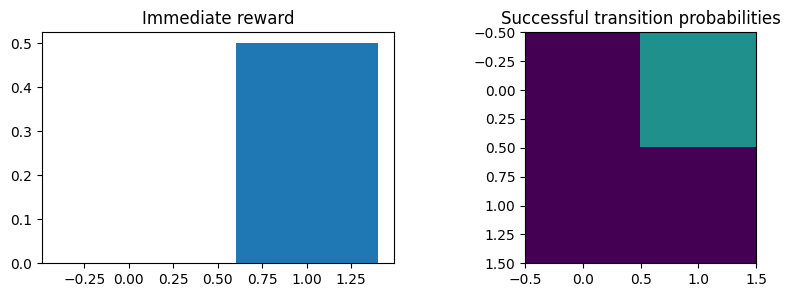

In [6]:
def estimate_xt_components(actions,n_states):
    totals=np.bincount(actions.start,minlength=n_states).astype(float);reward=np.zeros(n_states);transition=np.zeros((n_states,n_states))
    for a in actions.itertuples():
        if a.kind=='shot':reward[a.start]+=float(a.goal)
        elif a.success:transition[a.start,int(a.end)]+=1
    denominator=np.maximum(totals,1)
    return totals,reward/denominator,transition/denominator[:,None]
totals,reward,transition=estimate_xt_components(actions,2)
display(pd.DataFrame({'action_count':totals,'immediate_goal_reward':reward}));display(pd.DataFrame(transition))
fig,axs=plt.subplots(1,2,figsize=(10,3));axs[0].bar(range(2),reward);axs[0].set_title('Immediate reward');axs[1].imshow(transition,vmin=0,vmax=1);axs[1].set_title('Successful transition probabilities');plt.show()

## 6. Inspect value propagation

Follow the iteration from zero values through reward and continuation.

,state 0,state 1
iteration,,
0,0.00,0.0
1,0.00,0.5
2,0.25,0.5
3,0.25,0.5
4,0.25,0.5
5,0.25,0.5
6,0.25,0.5
7,0.25,0.5
8,0.25,0.5


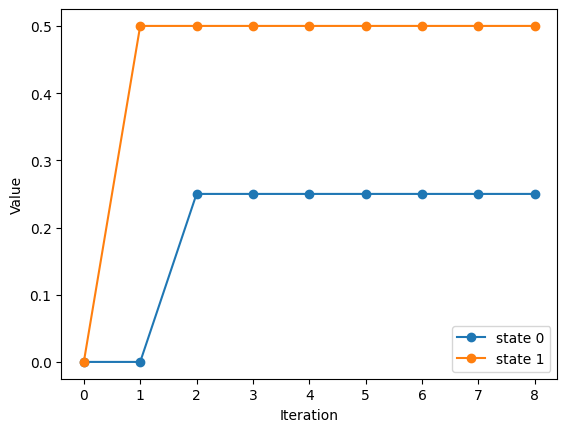

In [7]:
def xt_iterations(transition,reward,steps=8):
    value=np.zeros(len(reward));history=[value.copy()]
    for _ in range(steps):
        continuation=transition@value
        value=reward+continuation;history.append(value.copy())
    return np.array(history)
history=xt_iterations(transition,reward);display(pd.DataFrame(history,columns=['state 0','state 1']).rename_axis('iteration'))
plt.plot(history,'o-');plt.xlabel('Iteration');plt.ylabel('Value');plt.legend(['state 0','state 1']);plt.show()

## 7. Solve to convergence

Package the inspected components and update equation into a reusable fitter.

In [8]:
def fit_xt(actions,n_states,tolerance=1e-10,max_iter=10000):
    totals,reward,transition=estimate_xt_components(actions,n_states);value=np.zeros(n_states)
    for _ in range(max_iter):
        new=reward+transition@value
        if np.max(np.abs(new-value))<tolerance:return new,transition,reward
        value=new
    raise ValueError('No convergence; inspect termination and recurrent states')
values,transition,reward=fit_xt(actions,2);assert np.allclose(values,[.25,.5]);display(pd.Series(values,name='Fitted synthetic xT'))

0    0.25
1    0.50
Name: Fitted synthetic xT, dtype: float64

## 8. Final output: completed-action value gain

Use the values just fitted rather than introducing a separate arbitrary value table.

,start_state,end_state,start_value,end_value,gain
0,0,1,0.25,0.50,0.25
1,1,0,0.50,0.25,-0.25


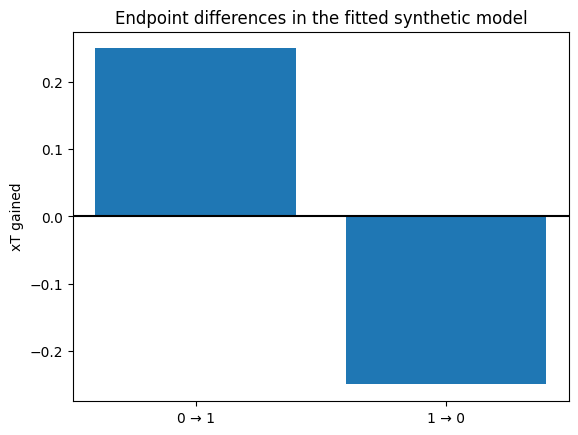

In [9]:
def endpoint_gain(values,start,end):return np.asarray(values)[end]-np.asarray(values)[start]
start=np.array([0,1]);end=np.array([1,0]);gains=endpoint_gain(values,start,end)
display(pd.DataFrame({'start_state':start,'end_state':end,'start_value':values[start],'end_value':values[end],'gain':gains}))
plt.bar(['0 → 1','1 → 0'],gains);plt.axhline(0,c='black');plt.ylabel('xT gained');plt.title('Endpoint differences in the fitted synthetic model');plt.show()

## Explore different examples

Run this after the method calculations above. After the first complete run, edit and run the selection cell near the top, then rerun this exploration cell to analyze another example. The worked intermediate steps stay visible above; this section applies the method again to your selection.

,possession_index,period,start_frame,end_frame,team_id,duration_s
0,0,1,10,39,NaN,3.0
1,1,1,40,306,1802.0,26.7
2,2,1,307,347,871.0,4.1
3,3,1,348,371,1802.0,2.4
4,4,1,372,573,871.0,20.2
5,5,1,574,586,1802.0,1.3
6,6,1,587,592,NaN,0.6
7,7,1,593,598,871.0,0.6
8,8,1,599,784,NaN,18.6
9,9,1,973,987,871.0,1.5


,event_id,event_type,frame_start,frame_end
0,8_0,player_possession,39,39
1,1_0,off_ball_run,43,67
2,8_1,player_possession,57,57
3,7_0,passing_option,57,57
4,8_2,player_possession,89,94
5,7_1,passing_option,89,94
6,7_2,passing_option,91,94
7,9_0,on_ball_engagement,134,143
8,9_1,on_ball_engagement,135,143
9,8_3,player_possession,143,143


,event_id,frame_end,x_end,y_end,player_targeted_x_reception,player_targeted_y_reception
0,8_0,39,0.32,-0.30,-9.61,-0.48
4,8_2,94,-35.63,20.93,-22.57,20.90
12,8_4,186,-2.18,-22.21,-11.25,-3.91
16,8_5,211,-12.28,-1.21,-6.72,17.42
20,8_6,241,-5.84,19.08,5.49,19.19
26,8_7,259,2.55,18.22,-4.98,15.22
36,8_9,281,-14.81,-23.68,-4.83,-25.27
38,8_10,342,19.03,-27.23,24.11,-10.34
52,8_11,367,28.25,-12.11,21.59,-16.05
58,8_12,385,22.76,-16.23,38.30,-28.82


Recomputed overlays on 20 real frames; first/last: (1, 34) (1, 91)


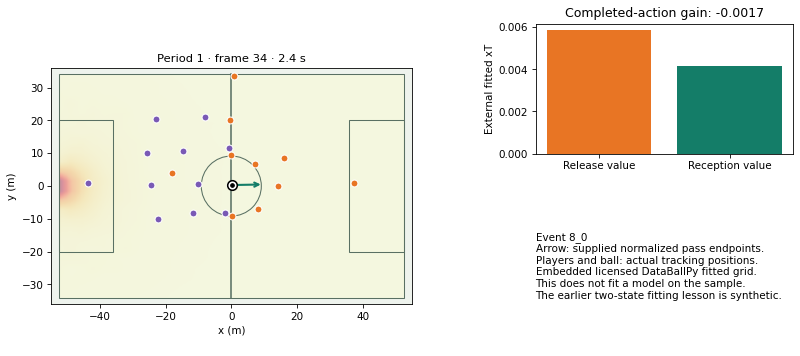

In [10]:
method_name = 'xt'
# All animation inputs and method calculations are local tracking data, not a video asset.
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon, Wedge
from IPython.display import HTML, display

example_meta={str(p['id']):p for p in metadata['players']}
example_home=int(metadata['home_team']['id']);example_away=int(metadata['away_team']['id'])
example_source=list(raw)
if method_name=='graph_epv':
    example_source=list({(int(r['period']),int(r['frame'])):r for r in [*raw,*goal_sequence] if r.get('period') is not None}.values())
source_frames={(int(r['period']),int(r['frame'])):r for r in example_source if r.get('period') is not None}
frames_by_key={key:r for key,r in source_frames.items() if key[0]==PERIOD and len(r.get('player_data',[]))==22 and all(p.get('x') is not None and p.get('y') is not None for p in r['player_data']) and r.get('ball_data',{}).get('x') is not None and r['ball_data'].get('y') is not None and r.get('timestamp') is not None}
assert frames_by_key,'No complete frames for PERIOD in the cached source.'

def tracking_time(record):
    return pd.to_timedelta(record['timestamp']).total_seconds()

def possession_team(record):
    group=record.get('possession',{}).get('group')
    return example_home if group=='home team' else example_away if group=='away team' else None

def attack_direction(team,period):
    home_left=metadata['home_team_side'][period-1]=='right_to_left'
    return -1 if (home_left if team==example_home else not home_left) else 1

def players_at_frame(key):
    r=frames_by_key[key];previous=source_frames.get((key[0],key[1]-1))
    prior={str(p['player_id']):p for p in previous.get('player_data',[])} if previous else {}
    dt=tracking_time(r)-tracking_time(previous) if previous and previous.get('timestamp') else np.nan
    rows=[]
    for p in r['player_data']:
        pid=str(p['player_id']);old=prior.get(pid,{})
        velocity=np.array([np.nan,np.nan])
        if .05<=dt<=.15 and old.get('x') is not None and old.get('y') is not None:
            velocity=(np.array([p['x'],p['y']])-np.array([old['x'],old['y']]))/dt
        rows.append(dict(player_id=pid,team_id=int(example_meta[pid]['team_id']),x=p['x'],y=p['y'],vx=velocity[0],vy=velocity[1],is_detected=p.get('is_detected')))
    return pd.DataFrame(rows)

def draw_tracking_frame(ax,key):
    r=frames_by_key[key];nodes=players_at_frame(key);pitch(ax)
    for team,color in [(example_home,'#e87524'),(example_away,'#7959b5')]:
        q=nodes[nodes.team_id.eq(team)];ax.scatter(q.x,q.y,c=color,edgecolors='white',s=44,zorder=5)
    ball=np.array([r['ball_data']['x'],r['ball_data']['y']])
    ax.scatter(*ball,s=85,c='white',edgecolors='black',lw=1.5,zorder=10)
    ax.scatter(*ball,s=12,c='black',zorder=11)
    ax.set_title(f'Period {key[0]} · frame {key[1]} · {tracking_time(r):.1f} s',fontsize=11)
    return nodes,ball,r

# Possessions here are uninterrupted supplied team-possession spans, not inferred player control.
example_catalog=[];previous=None;group=None
for key in sorted(frames_by_key):
    r=frames_by_key[key];current_possession_team=possession_team(r)
    continuous=previous is not None and key[1]==previous[1]+1 and 0<tracking_time(r)-tracking_time(frames_by_key[previous])<=.15
    if not continuous or current_possession_team!=group:
        example_catalog.append(dict(possession_index=len(example_catalog),period=key[0],start_frame=key[1],end_frame=key[1],team_id=current_possession_team))
    else:example_catalog[-1]['end_frame']=key[1]
    previous=key;group=current_possession_team
available_possessions=pd.DataFrame(example_catalog)
available_possessions['duration_s']=(available_possessions.end_frame-available_possessions.start_frame+1)/10
available_events=events[events.period.eq(PERIOD)&events.frame_start.isin([k[1] for k in frames_by_key])].copy() if 'events' in globals() else pd.DataFrame()
display(available_possessions.head(10))
if len(available_events):display(available_events[['event_id','event_type','frame_start','frame_end']].head(10))

clip_start_frame=None;clip_stop_frame=None;example_action=None
if method_name=='formation':
    available_windows=timeline[timeline.period.eq(PERIOD)].copy();display(available_windows.head(12))
    if FORMATION_WINDOW not in set(available_windows.window):raise ValueError('FORMATION_WINDOW must be a qualifying window in available_windows.')
    example_window_data=team_data[team_data.period_id.eq(PERIOD)&team_data.window.eq(FORMATION_WINDOW)&team_data.team_in_possession.eq(871)]
    example_med=example_window_data.groupby('player_id')[['cx','cy']].median()
    example_points=-example_med.to_numpy();example_fits=[]
    for name,t in templates.items():
        cost=((example_points[:,None]-t[None])**2).sum(2);rr,cc=linear_sum_assignment(cost)
        example_fits.append((name,float(np.sqrt(cost[rr,cc].mean())),cc))
    example_fits.sort(key=lambda a:a[1]);example_best=example_fits[0]
    candidates=[k[1] for k in frames_by_key if FORMATION_WINDOW*30<=tracking_time(frames_by_key[k])<(FORMATION_WINDOW+1)*30]
    assert candidates,'Selected formation window has no complete animation frames.'
    clip_start_frame=min(candidates);clip_stop_frame=max(candidates)
elif method_name=='events':
    display(passes.reset_index(names='pass_index').head(12))
    if len(passes):
        assert 0<=PASS_INDEX<len(passes),'PASS_INDEX is a row number in passes.'
        example_action=passes.iloc[PASS_INDEX];clip_start_frame=max(int(example_action.release)-8,0);clip_stop_frame=int(example_action.reception)+12
elif method_name=='xt':
    example_actions=events[events.event_type.eq('player_possession')&events.end_type.eq('pass')&events.pass_outcome.eq('successful')&events.period.eq(PERIOD)&events.frame_end.isin([k[1] for k in frames_by_key])].dropna(subset=['x_end','y_end','player_targeted_x_reception','player_targeted_y_reception']).copy()
    display(example_actions[['event_id','frame_end','x_end','y_end','player_targeted_x_reception','player_targeted_y_reception']].head(12))
    assert len(example_actions),'No completed actions with endpoint coverage.'
    example_action=example_actions.iloc[0] if EVENT_ID is None else example_actions[example_actions.event_id.eq(EVENT_ID)].iloc[0]
    clip_start_frame=int(example_action.frame_end)-5
elif method_name=='graph_epv' and SEQUENCE=='goal':
    clip_start_frame=int(goal_sequence[0]['frame']);clip_stop_frame=int(goal_sequence[-1]['frame'])
elif method_name=='graph_epv' and SEQUENCE=='non_goal':
    clip_start_frame=int(non_goal_sequence[0]['frame']);clip_stop_frame=int(non_goal_sequence[-1]['frame'])

if EVENT_ID is not None and method_name!='xt':
    chosen=available_events[available_events.event_id.eq(EVENT_ID)]
    assert len(chosen)==1,'Choose EVENT_ID from available_events.event_id, not a row number.'
    clip_start_frame=int(chosen.frame_start.iloc[0]);clip_stop_frame=int(chosen.frame_end.iloc[0])+10
if POSSESSION_INDEX is not None:
    chosen=available_possessions[available_possessions.possession_index.eq(POSSESSION_INDEX)]
    assert len(chosen)==1,'Choose POSSESSION_INDEX from available_possessions.'
    clip_start_frame=int(chosen.start_frame.iloc[0]);clip_stop_frame=int(chosen.end_frame.iloc[0])
if FRAME_ID is not None:
    clip_start_frame=int(FRAME_ID);clip_stop_frame=None
if clip_start_frame is None:clip_start_frame=int(frame_id)
if (PERIOD,clip_start_frame) not in frames_by_key:
    # An event can start on a missing frame. Move forward only within its own interval.
    possible=[k[1] for k in sorted(frames_by_key) if k[1]>=clip_start_frame and (clip_stop_frame is None or k[1]<=clip_stop_frame)]
    assert possible,'No covered frame for this selection.'
    clip_start_frame=possible[0]
clip_keys=[]
for f in range(clip_start_frame,clip_start_frame+max(2,int(DURATION_S*10))):
    key=(PERIOD,f)
    if key not in frames_by_key or (clip_stop_frame is not None and f>clip_stop_frame):break
    if clip_keys and not 0<tracking_time(frames_by_key[key])-tracking_time(frames_by_key[clip_keys[-1]])<=.15:break
    clip_keys.append(key)
assert len(clip_keys)>=2,'Selection ends at a coverage boundary; choose another covered start.'
assert FRAME_STRIDE>=1
clip_keys=clip_keys[::FRAME_STRIDE]
assert len(clip_keys)>=2,'Reduce FRAME_STRIDE or increase clip duration.'
selected_team=TEAM_ID if TEAM_ID is not None else possession_team(frames_by_key[clip_keys[0]]) or example_home
focus_player_id=str(PLAYER_ID) if PLAYER_ID is not None else str(next(p['id'] for p in metadata['players'] if int(p['team_id'])==selected_team))
if method_name=='physical' and PLAYER_ID is None:focus_player_id=str(summary.sort_values('sprint_m',ascending=False).player_id.iloc[0])
example_origin=tracking_time(frames_by_key[clip_keys[0]])
example_trace_keys=clip_keys

def example_xt_value(x,y):
    ix=np.clip(int((x+52.5)/105*XT_GRID.shape[0]),0,XT_GRID.shape[0]-1)
    iy=np.clip(int((y+34)/68*XT_GRID.shape[1]),0,XT_GRID.shape[1]-1)
    return float(XT_GRID[ix,iy])
example_action_team=int(example_action.team_id);example_action_sign=attack_direction(example_action_team,PERIOD)
example_xt_start=np.array([example_action.x_end,example_action.y_end]);example_xt_end=np.array([example_action.player_targeted_x_reception,example_action.player_targeted_y_reception]);example_xt_gain=example_xt_value(*example_xt_end)-example_xt_value(*example_xt_start)

def draw_method_overlay(key,ax,bx,cx):
    for a in [ax,bx,cx]:a.clear()
    nodes,ball,r=draw_tracking_frame(ax,key);t=tracking_time(r)-example_origin
    cx.axis('off')
    sign=example_action_sign;surface=XT_GRID.T if sign>0 else XT_GRID.T[::-1,::-1]
    ax.imshow(surface,origin='lower',extent=(-52.5,52.5,-34,34),cmap='YlOrRd',alpha=.4,zorder=0)
    ax.annotate('',xy=sign*example_xt_end,xytext=sign*example_xt_start,arrowprops={'arrowstyle':'->','color':'#147d68','lw':2})
    bx.bar(['Release value','Reception value'],[example_xt_value(*example_xt_start),example_xt_value(*example_xt_end)],color=['#e87524','#147d68']);bx.set(ylabel='External fitted xT',title=f'Completed-action gain: {example_xt_gain:+.4f}')
    cx.text(0,.9,f'Event {example_action.event_id}\nArrow: supplied normalized pass endpoints.\nPlayers and ball: actual tracking positions.\nEmbedded licensed DataBallPy fitted grid.\nThis does not fit a model on the sample.\nThe earlier two-state fitting lesson is synthetic.',va='top',fontsize=10)

def make_example_figure(key):
    fig=plt.figure(figsize=(11,5.7),dpi=75)
    gs=fig.add_gridspec(2,2,width_ratios=[1.4,1],hspace=.5)
    ax=fig.add_subplot(gs[:,0]);bx=fig.add_subplot(gs[0,1]);cx=fig.add_subplot(gs[1,1])
    draw_method_overlay(key,ax,bx,cx);fig.subplots_adjust(left=.07,right=.97,bottom=.14,top=.9,wspace=.4,hspace=.65);return fig,(ax,bx,cx)

# Check two distinct frames before rendering. Animation never interpolates tracking gaps.
for example_check_key in [clip_keys[0],clip_keys[-1]]:
    example_check_figure,_=make_example_figure(example_check_key);plt.close(example_check_figure)
print('Recomputed overlays on',len(clip_keys),'real frames; first/last:',clip_keys[0],clip_keys[-1])
example_static,_=make_example_figure(clip_keys[0]);plt.show()
example_fig,example_axes=make_example_figure(clip_keys[0])
def update_animation(i):
    draw_method_overlay(clip_keys[i],*example_axes)
animation=FuncAnimation(example_fig,update_animation,frames=len(clip_keys),interval=100*FRAME_STRIDE,repeat=False,blit=False)
plt.close(example_fig)
display(HTML(animation.to_jshtml(fps=10/FRAME_STRIDE,default_mode='once')))


## Interpretation and limitations

This synthetic corpus explains fitting mechanics. A real xT grid needs a complete action corpus, reviewed action conventions and attack normalization. Location-only xT omits defender context. [Karun Singh](https://karun.in/blog/expected-threat.html).